# VLM Temporal State Research — Clean Colab Notebook

This notebook is a clean continuation of the Qwen2.5-VL card-relocation experiment.

**Completed before this notebook**
- E0: uniform 24-frame visual-only baseline
- E1: same visual input + explicit textual temporal information
- E0.5: evaluator/raw-output audit on one example
- Native Qwen video processing diagnostic

**Current experiment**
- **E1a:** native Qwen video input
- exactly **24 frames**
- native Qwen temporal metadata path
- same card-relocation easy set (50 videos)
- save after every video + resume support

**Important:** E1a does not use the old image-list path. It passes the actual video through Qwen's native video pipeline and verifies the temporal metadata before generation.


In [ ]:
# ============================================================
# 1. INSTALL DEPENDENCIES
# ============================================================

!pip -q install -U transformers accelerate qwen-vl-utils decord huggingface_hub

print("Dependencies installed.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.6/13.6 MB 32.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 16.7 MB/s eta 0:00:00
Dependencies installed.


In [ ]:
# ============================================================
# 2. IMPORTS + GPU CHECK
# ============================================================

import os
import json
import re
import gc
import time
import inspect
from pathlib import Path

import torch
import numpy as np

from transformers import (
    Qwen2_5_VLForConditionalGeneration,
    AutoProcessor,
)
from qwen_vl_utils import process_vision_info

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU is required.")

print("GPU:", torch.cuda.get_device_name(0))
print("VRAM:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), "GB")


PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
VRAM: 14.56 GB


In [ ]:
# ============================================================
# 3. LOAD QWEN2.5-VL-3B
# ============================================================

MODEL_NAME = "Qwen/Qwen2.5-VL-3B-Instruct"

print("Loading:", MODEL_NAME)

model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_NAME,
    torch_dtype="auto",
    device_map="auto",
)

# Keep the processor configuration aligned with the E0 visual budget.
# 336 x 336 = 112,896 pixels per frame.
PIXELS_336 = 336 * 336

processor = AutoProcessor.from_pretrained(
    MODEL_NAME,
    min_pixels=PIXELS_336,
    max_pixels=PIXELS_336,
)

model.eval()

print("Model loaded.")
print("Model device:", next(model.parameters()).device)
print("GPU allocated:", round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")


Loading: Qwen/Qwen2.5-VL-3B-Instruct


config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/65.4k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

...

tokenizer_config.json:   0%|          | 0.00/5.70k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Model loaded.
Model device: cuda:0
GPU allocated: 6.99 GB


In [ ]:
# ============================================================
# 4. DOWNLOAD / LOCATE VIDEO-MME LOGICAL DATASET
# ============================================================

DATA_BASE = "/content/videomme"
DATA_ROOT = "/content/videomme_data"

ZIP_PATH = f"{DATA_BASE}/video_mme_logical.zip"

os.makedirs(DATA_BASE, exist_ok=True)

if not os.path.exists(ZIP_PATH):
    print("Downloading dataset...")
    !hf download marcuskwan/video-mme-logical video_mme_logical.zip --repo-type dataset --local-dir /content/videomme
else:
    print("Dataset zip already exists.")

if not os.path.exists(DATA_ROOT):
    os.makedirs(DATA_ROOT, exist_ok=True)
    print("Extracting dataset...")
    !unzip -q /content/videomme/video_mme_logical.zip -d /content/videomme_data
else:
    print("Dataset directory already exists.")

json_files = list(Path(DATA_ROOT).rglob("three_level_testset.json"))

if not json_files:
    raise FileNotFoundError("three_level_testset.json not found.")

MANIFEST_PATH = str(json_files[0])

with open(MANIFEST_PATH, "r", encoding="utf-8") as f:
    data = json.load(f)

print("Manifest:", MANIFEST_PATH)
print("Total examples:", len(data))


Hint: A new version of huggingface_hub (2.1.1) is available! You are using version 1.33.0.
To update, run: hf update
Hint: The `hf-cli` skill is not installed. Run `hf skills add -g` to teach your AI agents how to use the `hf` CLI.

video_mme_logical.zip: downloading bytes:   6% 203M/3.56G [00:01<00:13, 246MB/s, 14.9MB/s  ]
video_mme_logical.zip: downloading bytes:  11% 381M/3.56G [00:02<00:12, 253MB/s, 31.1MB/s  ]
video_mme_logical.zip: downloading bytes:  14% 501M/3.56G [00:02<00:10, 291MB/s, 40.5MB/s  ]
video_mme_logical.zip: downloading bytes:  19% 684M/3.56G [00:03<00:10, 283MB/s, 57.4MB/s  ]
video_mme_logical.zip: downloading bytes:  55% 1.96G/3.56G [00:06<00:04, 377MB/s,  141MB/s  ]
video_mme_logical.zip: downloading bytes:  70% 2.48G/3.56G [00:09<00:06, 155MB/s,  146MB/s  ]
video_mme_logical.zip: downloading bytes:  75% 2.67G/3.56G [00:10<00:04, 200MB/s,  150MB/s  ]
video_mme_logical.zip: downloading bytes:  85% 3.01G/3.56G [00:12<00:02, 233MB/s,  160MB/s  ]
video_mme_logical.z

In [ ]:
# ============================================================
# 5. SELECT THE 50 CARD-RELOCATION EASY VIDEOS
# ============================================================

TASK_NAME = "card_relocation_s_easy"

card_relocation_easy = [
    item for item in data
    if item.get("major") == TASK_NAME
]

print("Card relocation easy examples:", len(card_relocation_easy))

if len(card_relocation_easy) != 50:
    print("WARNING: expected 50 examples.")

def resolve_video_path(example):
    vp = str(example["video_path"])

    if os.path.isabs(vp):
        return vp

    # Dataset paths are relative to /content/videomme_data/video-mme-logical
    root = os.path.join(DATA_ROOT, "video-mme-logical")
    return os.path.join(root, vp)

print("\nFirst 5:")
for item in card_relocation_easy[:5]:
    p = resolve_video_path(item)
    print(item["id"], "| exists:", os.path.exists(p))


Card relocation easy examples: 50

First 5:
card_relocation_s_L1_0001_v3 | exists: True
card_relocation_s_L1_0002_v3 | exists: True
card_relocation_s_L1_0003_v3 | exists: True
card_relocation_s_L1_0004_v3 | exists: True
card_relocation_s_L1_0005_v3 | exists: True


In [ ]:
# ============================================================
# 6. EVALUATOR — SAME LOGIC USED FOR E0/E1
# ============================================================

def extract_answer_json(raw_output):
    if raw_output is None:
        return None

    if isinstance(raw_output, dict):
        return raw_output

    text = str(raw_output).strip()

    match = re.search(
        r"<answer>\s*(\{.*?\})\s*</answer>",
        text,
        flags=re.DOTALL,
    )

    if match:
        json_text = match.group(1)
    else:
        start = text.find("{")
        end = text.rfind("}")

        if start == -1 or end == -1:
            return None

        json_text = text[start:end + 1]

    try:
        return json.loads(json_text)
    except Exception:
        return None


def evaluate_prediction(raw_prediction, ground_truth):
    prediction = (
        extract_answer_json(raw_prediction)
        if isinstance(raw_prediction, str)
        else raw_prediction
    )

    if isinstance(ground_truth, str):
        try:
            ground_truth = json.loads(ground_truth)
        except Exception:
            ground_truth = extract_answer_json(ground_truth)

    if prediction is None or ground_truth is None:
        return {
            "valid_json": False,
            "initial_correct": False,
            "position_accuracy": 0.0,
            "position_correct": 0,
            "position_total": len((ground_truth or {}).get("position_trace", {})),
            "move_accuracy": 0.0,
            "move_correct": 0,
            "move_total": len((ground_truth or {}).get("move_trace", {})),
            "move_count_correct": False,
            "complete_trace_correct": False,
            "overall_exact_match": False,
        }

    gt_positions = {str(k): v for k, v in ground_truth.get("position_trace", {}).items()}
    pred_positions = {str(k): v for k, v in prediction.get("position_trace", {}).items()}

    gt_moves = {str(k): v for k, v in ground_truth.get("move_trace", {}).items()}
    pred_moves = {str(k): v for k, v in prediction.get("move_trace", {}).items()}

    position_correct = sum(
        pred_positions.get(k) == v
        for k, v in gt_positions.items()
    )

    move_correct = sum(
        pred_moves.get(k) == v
        for k, v in gt_moves.items()
    )

    position_total = len(gt_positions)
    move_total = len(gt_moves)

    gt_initial = ground_truth.get("initial_position")
    pred_initial = prediction.get("initial_position")

    return {
        "valid_json": True,
        "initial_correct": pred_initial == gt_initial,
        "position_accuracy": position_correct / position_total if position_total else 0.0,
        "position_correct": position_correct,
        "position_total": position_total,
        "move_accuracy": move_correct / move_total if move_total else 0.0,
        "move_correct": move_correct,
        "move_total": move_total,
        "move_count_correct": prediction.get("move_count") == ground_truth.get("move_count"),
        "complete_trace_correct": (
            pred_initial == gt_initial
            and pred_positions == gt_positions
        ),
        "overall_exact_match": prediction == ground_truth,
    }


print("Evaluator ready.")


Evaluator ready.


In [ ]:
# ============================================================
# 7. NATIVE QWEN VIDEO FUNCTION
#
# KEY FIX FROM THE PREVIOUS DIAGNOSTIC:
# qwen_vl_utils returns fps as a LIST, e.g. [27.69].
# Transformers 5.16.1 expects a scalar float for this processor.
#
# Therefore:
#     process_vision_info(..., return_video_kwargs=True)
#     -> get sampled fps
#     -> replace fps list with one scalar float
#
# We use nframes=24 directly, rather than manually extracting
# 24 images. This is the native Qwen video path.
# ============================================================

NUM_FRAMES = 24
RESOLUTION = 336
MAX_NEW_TOKENS = 300

def build_native_video_messages(video_path, question):
    return [
        {
            "role": "user",
            "content": [
                {
                    "type": "video",
                    "video": video_path,
                    "nframes": NUM_FRAMES,
                    "resized_height": RESOLUTION,
                    "resized_width": RESOLUTION,
                },
                {
                    "type": "text",
                    "text": question,
                },
            ],
        }
    ]


def generate_native_video_answer(video_path, question, debug=False):
    messages = build_native_video_messages(video_path, question)

    text = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )

    image_inputs, video_inputs, video_kwargs = process_vision_info(
        messages,
        return_video_kwargs=True,
    )

    if video_inputs is None or len(video_inputs) != 1:
        raise RuntimeError(
            f"Expected exactly one native video input, got: {type(video_inputs)} / {video_inputs}"
        )

    native_video = video_inputs[0]

    if not isinstance(native_video, torch.Tensor):
        raise RuntimeError(
            f"Expected native video tensor, got {type(native_video)}"
        )

    actual_frames = int(native_video.shape[0])

    if actual_frames != NUM_FRAMES:
        raise RuntimeError(
            f"Native Qwen sampled {actual_frames} frames, expected exactly {NUM_FRAMES}."
        )

    # qwen-vl-utils returns fps as [value] for one video.
    sampled_fps = video_kwargs.get("fps")

    if isinstance(sampled_fps, (list, tuple)):
        if len(sampled_fps) != 1:
            raise RuntimeError(f"Unexpected fps metadata: {sampled_fps}")
        sampled_fps = float(sampled_fps[0])
    elif sampled_fps is not None:
        sampled_fps = float(sampled_fps)

    # Transformers 5.16.1 requires a scalar fps here.
    if sampled_fps is not None:
        video_kwargs["fps"] = sampled_fps

    if debug:
        print("Native video tensor:", tuple(native_video.shape))
        print("Native sampled FPS:", sampled_fps)
        print("video_kwargs:", video_kwargs)

    inputs = processor(
        text=[text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt",
        **video_kwargs,
    )

    # Verify native temporal metadata exists.
    if "video_grid_thw" not in inputs:
        raise RuntimeError("video_grid_thw missing from processor output.")

    if "second_per_grid_ts" not in inputs:
        raise RuntimeError("second_per_grid_ts missing from processor output.")

    if debug:
        print("video_grid_thw:", inputs["video_grid_thw"])
        print("second_per_grid_ts:", inputs["second_per_grid_ts"])
        if "pixel_values_videos" in inputs:
            print("pixel_values_videos:", tuple(inputs["pixel_values_videos"].shape))
        print("input_ids:", tuple(inputs["input_ids"].shape))

    inputs = inputs.to(model.device)

    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
        gpu_before = torch.cuda.memory_allocated() / 1024**3
    else:
        gpu_before = 0.0

    with torch.inference_mode():
        generated_ids = model.generate(
            **inputs,
            max_new_tokens=MAX_NEW_TOKENS,
            do_sample=False,
            use_cache=True,
        )

    generated_ids_trimmed = [
        out_ids[len(in_ids):]
        for in_ids, out_ids in zip(
            inputs.input_ids,
            generated_ids,
        )
    ]

    output_text = processor.batch_decode(
        generated_ids_trimmed,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )

    result = output_text[0].strip()

    peak_gpu = (
        torch.cuda.max_memory_allocated() / 1024**3
        if torch.cuda.is_available()
        else 0.0
    )

    # Return diagnostic metadata along with the answer.
    metadata = {
        "native_frames": actual_frames,
        "sampled_fps": sampled_fps,
        "video_grid_thw": inputs["video_grid_thw"].detach().cpu().tolist(),
        "second_per_grid_ts": inputs["second_per_grid_ts"].detach().cpu().tolist(),
        "gpu_before_generation_gb": round(gpu_before, 3),
        "peak_gpu_gb": round(peak_gpu, 3),
        "input_ids_tokens": int(inputs["input_ids"].shape[1]),
    }

    del inputs
    del generated_ids
    del image_inputs
    del video_inputs

    gc.collect()
    torch.cuda.empty_cache()

    return result, metadata


print("Native Qwen video inference function ready.")


Native Qwen video inference function ready.


In [ ]:
# ============================================================
# 8. E1a — SINGLE-VIDEO DIAGNOSTIC + GENERATION
#
# Run this FIRST.
# It must prove:
#   1. 24 native video frames
#   2. scalar FPS passed to processor
#   3. video_grid_thw exists
#   4. second_per_grid_ts exists
#   5. generation succeeds
#   6. evaluator can parse the result
# ============================================================

TEST_INDEX = 0
example = card_relocation_easy[TEST_INDEX]

video_path = resolve_video_path(example)

print("=" * 100)
print("E1a — NATIVE QWEN VIDEO INPUT — SINGLE VIDEO")
print("=" * 100)

print("ID:", example["id"])
print("Video:", video_path)
print("Exists:", os.path.exists(video_path))

raw_output, native_meta = generate_native_video_answer(
    video_path,
    example["question"],
    debug=True,
)

evaluation = evaluate_prediction(
    raw_output,
    example["answer"],
)

print("\n" + "=" * 100)
print("RAW QWEN OUTPUT")
print("=" * 100)
print(raw_output)

print("\n" + "=" * 100)
print("EVALUATION")
print("=" * 100)
print(json.dumps(evaluation, indent=2))

print("\n" + "=" * 100)
print("NATIVE TEMPORAL METADATA")
print("=" * 100)
print(json.dumps(native_meta, indent=2))


E1a — NATIVE QWEN VIDEO INPUT — SINGLE VIDEO
ID: card_relocation_s_L1_0001_v3
Video: /content/videomme_data/video-mme-logical/videos/card_relocation_s_easy/card_relocation_s_L1_0001_v3.mp4
Exists: True


qwen-vl-utils using torchcodec to read video.
[transformers] Qwen2VL video processing does not apply the per-frame pixel cap the reference implementation (qwen-vl-utils) applies, so some videos cost far more tokens than they would there. In v5.22 the capped behavior will become the default and `cap_pixels_per_frame` will be removed. Pass `cap_pixels_per_frame=True` to adopt the reference behavior now, or `False` to keep the current behavior and silence this warning.


Native video tensor: (24, 3, 336, 336)
Native sampled FPS: 0.9230769230769231
video_kwargs: {'do_sample_frames': False, 'fps': 0.9230769230769231}
video_grid_thw: tensor([[12, 24, 24]])
second_per_grid_ts: tensor([0.0833])
pixel_values_videos: (6912, 1176)
input_ids: (1, 1946)

RAW QWEN OUTPUT
<answer>{"target_card":"D","initial_position":"A","position_trace":{"1":"A","2":"B","3":"C","4":"D"},"move_trace":{"1":0,"2":1,"3":1,"4":1},"move_count":3}</answer>

EVALUATION
{
  "valid_json": true,
  "initial_correct": false,
  "position_accuracy": 0.5,
  "position_correct": 3,
  "position_total": 6,
  "move_accuracy": 0.3333333333333333,
  "move_correct": 2,
  "move_total": 6,
  "move_count_correct": false,
  "complete_trace_correct": false,
  "overall_exact_match": false
}

NATIVE TEMPORAL METADATA
{
  "native_frames": 24,
  "sampled_fps": 0.9230769230769231,
  "video_grid_thw": [
    [
      12,
      24,
      24
    ]
  ],
  "second_per_grid_ts": [
    0.0833333358168602
  ],
  "gpu_befor

In [ ]:
# ============================================================
# 9. E1a — ALL 50 VIDEOS
#
# Resume-safe:
# - saves after EVERY video
# - skips only valid completed records
# - preserves raw output
# - preserves native temporal metadata
# - preserves evaluator output
# ============================================================

E1A_RESULTS_FILE = "/content/e1a_native_temporal_card_relocation_results.json"
E1A_SUMMARY_FILE = "/content/e1a_native_temporal_card_relocation_summary.json"

def load_json_list(path):
    if not os.path.exists(path):
        return []

    try:
        with open(path, "r", encoding="utf-8") as f:
            obj = json.load(f)

        return obj if isinstance(obj, list) else []
    except Exception:
        return []


results = load_json_list(E1A_RESULTS_FILE)

completed_ids = {
    r.get("id")
    for r in results
    if isinstance(r, dict)
    and isinstance(r.get("evaluation"), dict)
    and r["evaluation"].get("valid_json") is True
}

print("=" * 100)
print("E1a — NATIVE QWEN VIDEO — ALL 50")
print("=" * 100)
print("Frames:", NUM_FRAMES)
print("Resolution:", f"{RESOLUTION}×{RESOLUTION}")
print("Max new tokens:", MAX_NEW_TOKENS)
print("Existing records:", len(results))
print("Valid completed:", len(completed_ids))
print("Total videos:", len(card_relocation_easy))

for i, example in enumerate(card_relocation_easy):
    video_id = example["id"]

    if video_id in completed_ids:
        print(f"[{i+1}/{len(card_relocation_easy)}] {video_id} — SKIPPED")
        continue

    print("\n" + "=" * 100)
    print(f"Running {i+1}/{len(card_relocation_easy)}: {video_id}")
    print("=" * 100)

    video_path = resolve_video_path(example)

    start_time = time.time()

    record = {
        "id": video_id,
        "video_path": video_path,
        "config": {
            "frames": NUM_FRAMES,
            "resolution": RESOLUTION,
            "max_new_tokens": MAX_NEW_TOKENS,
            "native_video_api": True,
        },
    }

    try:
        if not os.path.exists(video_path):
            raise FileNotFoundError(video_path)

        raw_output, native_meta = generate_native_video_answer(
            video_path,
            example["question"],
            debug=False,
        )

        evaluation = evaluate_prediction(
            raw_output,
            example["answer"],
        )

        record.update({
            "raw_prediction": raw_output,
            "ground_truth": example["answer"],
            "native_metadata": native_meta,
            "evaluation": evaluation,
            "elapsed_seconds": round(time.time() - start_time, 2),
        })

        print(
            "Result:",
            f"Position {evaluation['position_correct']}/{evaluation['position_total']}",
            "| Moves",
            f"{evaluation['move_correct']}/{evaluation['move_total']}",
            "| Move count:",
            evaluation["move_count_correct"],
            "| Exact:",
            evaluation["overall_exact_match"],
            "| Time:",
            record["elapsed_seconds"],
            "s",
            "| Peak VRAM:",
            native_meta["peak_gpu_gb"],
            "GB",
        )

    except torch.cuda.OutOfMemoryError as e:
        record.update({
            "error_type": "CUDA_OOM",
            "error": repr(e),
            "elapsed_seconds": round(time.time() - start_time, 2),
        })

        print("❌ CUDA OUT OF MEMORY")

        gc.collect()
        torch.cuda.empty_cache()

    except Exception as e:
        record.update({
            "error_type": type(e).__name__,
            "error": repr(e),
            "elapsed_seconds": round(time.time() - start_time, 2),
        })

        print("❌ ERROR:", repr(e))

        gc.collect()
        torch.cuda.empty_cache()

    results.append(record)

    # SAVE AFTER EVERY VIDEO
    with open(E1A_RESULTS_FILE, "w", encoding="utf-8") as f:
        json.dump(results, f, indent=2, ensure_ascii=False)

    print("Saved:", E1A_RESULTS_FILE)

print("\n" + "=" * 100)
print("E1a RUN COMPLETE")
print("=" * 100)
print("Records:", len(results))
print("File:", E1A_RESULTS_FILE)


E1a — NATIVE QWEN VIDEO — ALL 50
Frames: 24
Resolution: 336×336
Max new tokens: 300
Existing records: 0
Valid completed: 0
Total videos: 50

Running 1/50: card_relocation_s_L1_0001_v3
Result: Position 3/6 | Moves 2/6 | Move count: False | Exact: False | Time: 14.74 s | Peak VRAM: 7.727 GB
Saved: /content/e1a_native_temporal_card_relocation_results.json

Running 2/50: card_relocation_s_L1_0002_v3
Result: Position 2/6 | Moves 4/6 | Move count: True | Exact: False | Time: 14.73 s | Peak VRAM: 7.727 GB
Saved: /content/e1a_native_temporal_card_relocation_results.json

Running 3/50: card_relocation_s_L1_0003_v3
Result: Position 1/6 | Moves 1/6 | Move count: False | Exact: False | Time: 15.13 s | Peak VRAM: 7.727 GB
Saved: /content/e1a_native_temporal_card_relocation_results.json

Running 4/50: card_relocation_s_L1_0004_v3
Result: Position 2/6 | Moves 2/6 | Move count: True | Exact: False | Time: 15.8 s | Peak VRAM: 7.727 GB
Saved: /content/e1a_native_temporal_card_relocation_results.json

Ru

In [ ]:
# ============================================================
# 10. E1a SUMMARY
# ============================================================

valid = [
    r for r in results
    if isinstance(r, dict)
    and isinstance(r.get("evaluation"), dict)
    and r["evaluation"].get("valid_json") is True
]

errors = [
    r for r in results
    if "error" in r
]

print("=" * 100)
print("E1a SUMMARY")
print("=" * 100)

print("Total records:", len(results))
print("Valid JSON:", len(valid))
print("Errors:", len(errors))

if valid:
    n = len(valid)

    metrics = {
        "initial_position_accuracy": sum(
            r["evaluation"]["initial_correct"] for r in valid
        ) / n,

        "position_accuracy": sum(
            r["evaluation"]["position_accuracy"] for r in valid
        ) / n,

        "move_accuracy": sum(
            r["evaluation"]["move_accuracy"] for r in valid
        ) / n,

        "move_count_accuracy": sum(
            r["evaluation"]["move_count_correct"] for r in valid
        ) / n,

        "complete_trace_accuracy": sum(
            r["evaluation"]["complete_trace_correct"] for r in valid
        ) / n,

        "exact_match_accuracy": sum(
            r["evaluation"]["overall_exact_match"] for r in valid
        ) / n,
    }

    print("\nMetrics:")
    for k, v in metrics.items():
        print(f"{k:32s}: {v:.4f}")

else:
    metrics = {}

summary = {
    "experiment": "E1a",
    "description": "Native Qwen video input with exact 24-frame sampling and native temporal metadata",
    "num_videos_total": len(card_relocation_easy),
    "records": len(results),
    "valid_json": len(valid),
    "errors": len(errors),
    "metrics": metrics,
    "results_file": E1A_RESULTS_FILE,
}

with open(E1A_SUMMARY_FILE, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print("\nSaved summary:", E1A_SUMMARY_FILE)


E1a SUMMARY
Total records: 50
Valid JSON: 50
Errors: 0

Metrics:
initial_position_accuracy       : 0.5600
position_accuracy               : 0.1900
move_accuracy                   : 0.3433
move_count_accuracy             : 0.2400
complete_trace_accuracy         : 0.0000
exact_match_accuracy            : 0.0000

Saved summary: /content/e1a_native_temporal_card_relocation_summary.json


In [ ]:
# ============================================================
# 11. QUICK NATIVE TEMPORAL SANITY CHECK
# ============================================================

print("=" * 100)
print("E1a TEMPORAL SANITY CHECK")
print("=" * 100)

native_records = [
    r for r in results
    if "native_metadata" in r
]

print("Records with native metadata:", len(native_records))

for r in native_records[:5]:
    m = r["native_metadata"]

    print(
        r["id"],
        "| frames:", m["native_frames"],
        "| sampled_fps:", m["sampled_fps"],
        "| grid:", m["video_grid_thw"],
        "| second_per_grid_ts:", m["second_per_grid_ts"],
    )

bad_frame_counts = [
    r["id"]
    for r in native_records
    if r["native_metadata"].get("native_frames") != NUM_FRAMES
]

missing_temporal = [
    r["id"]
    for r in native_records
    if not r["native_metadata"].get("second_per_grid_ts")
]

print("\nWrong native frame counts:", bad_frame_counts)
print("Missing temporal metadata:", missing_temporal)

if not bad_frame_counts and not missing_temporal:
    print("\n✅ Native temporal path is structurally verified.")
else:
    print("\n⚠️ Inspect the records above before moving to E2.")


E1a TEMPORAL SANITY CHECK
Records with native metadata: 50
card_relocation_s_L1_0001_v3 | frames: 24 | sampled_fps: 0.9230769230769231 | grid: [[12, 24, 24]] | second_per_grid_ts: [0.0833333358168602]
card_relocation_s_L1_0002_v3 | frames: 24 | sampled_fps: 0.9230769230769231 | grid: [[12, 24, 24]] | second_per_grid_ts: [0.0833333358168602]
card_relocation_s_L1_0003_v3 | frames: 24 | sampled_fps: 0.9230769230769231 | grid: [[12, 24, 24]] | second_per_grid_ts: [0.0833333358168602]
card_relocation_s_L1_0004_v3 | frames: 24 | sampled_fps: 0.9230769230769231 | grid: [[12, 24, 24]] | second_per_grid_ts: [0.0833333358168602]
card_relocation_s_L1_0005_v3 | frames: 24 | sampled_fps: 0.9230769230769231 | grid: [[12, 24, 24]] | second_per_grid_ts: [0.0833333358168602]

Wrong native frame counts: []
Missing temporal metadata: []

✅ Native temporal path is structurally verified.


## After E1a

Do **not** run E2 until E1a finishes.

The next step is to compare:

- **E0:** uniform 24-frame image sequence
- **E1:** uniform 24-frame image sequence + explicit textual timestamps
- **E1a:** native Qwen video input + native temporal metadata

If E1a runs successfully, we can then decide whether the timestamp implementation question is resolved enough to proceed to **E2 adaptive/question-blind sampling**.


In [ ]:
# ============================================================
# E1a — FULL 50-VIDEO NATIVE QWEN VIDEO EXPERIMENT
# ============================================================
#
# PURPOSE:
#   Run Qwen2.5-VL using its NATIVE VIDEO pathway.
#
#   E0  = 24 sampled images
#   E1  = 24 sampled images + textual timestamps
#   E1a = native Qwen video input + native temporal metadata
#
# IMPORTANT:
#   DO NOT use generate_from_image_sequence()
#   DO NOT convert the video into 24 separate image messages.
#
#   This cell uses:
#       video -> process_vision_info() -> native video tensor
#              -> Qwen processor -> video_grid_thw
#              -> second_per_grid_ts -> generation
#
# ============================================================

import os
import re
import json
import gc
import time
import traceback
from pathlib import Path

import torch
import numpy as np

from qwen_vl_utils import process_vision_info


# ============================================================
# CONFIGURATION
# ============================================================

VIDEO_ROOT = Path(
    "/content/videomme_data/video-mme-logical/videos"
)

VIDEO_DIR = VIDEO_ROOT / "card_relocation_s_easy"

OUTPUT_FILE = (
    "/content/e1a_native_temporal_card_relocation_results.json"
)

NUM_FRAMES = 24
MAX_NEW_TOKENS = 300

print("=" * 100)
print("E1a — FULL NATIVE QWEN VIDEO EXPERIMENT")
print("=" * 100)

print(f"Video directory: {VIDEO_DIR}")
print(f"Frames/video:    {NUM_FRAMES}")
print(f"Resolution:      336×336")
print(f"Max new tokens:  {MAX_NEW_TOKENS}")
print(f"Output:          {OUTPUT_FILE}")


# ============================================================
# CHECK REQUIRED VARIABLES
# ============================================================

required = ["model", "processor"]

missing = [
    x for x in required
    if x not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing required variables: {missing}\n"
        "Run the model-loading cells first."
    )

print("\nModel:", type(model).__name__)
print("Processor:", type(processor).__name__)


# ============================================================
# FIND VIDEOS
# ============================================================

video_files = sorted(
    VIDEO_DIR.glob("*.mp4")
)

print(f"\nFound videos: {len(video_files)}")

if len(video_files) == 0:
    raise RuntimeError(
        f"No videos found in {VIDEO_DIR}"
    )

video_files = video_files[:50]

print(f"Using videos: {len(video_files)}")


# ============================================================
# FIND DATASET EXAMPLES / GROUND TRUTH
# ============================================================
#
# Your notebook already contains `card_relocation_easy`
# containing the 50 examples.
#
# We use it if available.
#
# ============================================================

dataset_lookup = {}

if "card_relocation_easy" in globals():

    print("\nUsing existing card_relocation_easy dataset.")

    for sample in card_relocation_easy:

        if not isinstance(sample, dict):
            continue

        vp = sample.get("video_path")

        if vp:
            dataset_lookup[
                os.path.basename(str(vp))
            ] = sample

        # Also support id/path style records
        name = sample.get("video")

        if name:
            dataset_lookup[
                os.path.basename(str(name))
            ] = sample

else:
    print(
        "\nWARNING: card_relocation_easy not found."
    )
    print(
        "Ground truth lookup will be attempted "
        "from other existing dataset variables."
    )

    # Try common existing variables
    for var_name in [
        "dataset_examples",
        "dataset_samples",
        "samples",
        "examples",
    ]:

        if var_name not in globals():
            continue

        obj = globals()[var_name]

        if not isinstance(obj, (list, tuple)):
            continue

        for sample in obj:

            if not isinstance(sample, dict):
                continue

            vp = sample.get("video_path")

            if vp:
                dataset_lookup[
                    os.path.basename(str(vp))
                ] = sample


print(
    f"Dataset examples indexed: "
    f"{len(dataset_lookup)}"
)


# ============================================================
# QUESTION EXTRACTION
# ============================================================

def get_question(sample):

    if not sample:
        return None

    q = sample.get("question")

    if isinstance(q, str) and q.strip():
        return q.strip()

    return None


# ============================================================
# GROUND TRUTH PARSER
# ============================================================

def parse_ground_truth(sample):

    if not sample:
        return None

    answer = sample.get("answer")

    if isinstance(answer, dict):
        return answer

    if isinstance(answer, str):

        text = answer.strip()

        # Remove <answer> tags if present
        text = re.sub(
            r"<answer>\s*",
            "",
            text,
            flags=re.IGNORECASE
        )

        text = re.sub(
            r"\s*</answer>",
            "",
            text,
            flags=re.IGNORECASE
        )

        try:
            return json.loads(text)
        except Exception:
            pass

    return None


# ============================================================
# MODEL OUTPUT PARSER
# ============================================================

def parse_model_answer(raw):

    if not isinstance(raw, str):
        return None

    text = raw.strip()

    # First try answer tags
    match = re.search(
        r"<answer>\s*(.*?)\s*</answer>",
        text,
        flags=re.IGNORECASE | re.DOTALL
    )

    if match:
        text = match.group(1).strip()

    # Try direct JSON
    try:
        obj = json.loads(text)

        if isinstance(obj, dict):
            return obj

    except Exception:
        pass

    # Try extracting first JSON object
    start = text.find("{")
    end = text.rfind("}")

    if start != -1 and end > start:

        candidate = text[start:end + 1]

        try:
            obj = json.loads(candidate)

            if isinstance(obj, dict):
                return obj

        except Exception:
            pass

    return None


# ============================================================
# EVALUATOR
# ============================================================

def evaluate_answer(pred, gt):

    result = {
        "valid_json": pred is not None,
        "target_card_correct": False,
        "initial_position_correct": False,
        "position_correct": 0,
        "position_total": 0,
        "move_correct": 0,
        "move_total": 0,
        "move_count_correct": False,
        "exact_match": False,
        "complete_trace": False,
    }

    if pred is None or gt is None:
        return result

    # --------------------------------------------------------
    # Target
    # --------------------------------------------------------

    result["target_card_correct"] = (
        pred.get("target_card")
        == gt.get("target_card")
    )

    # --------------------------------------------------------
    # Initial position
    # --------------------------------------------------------

    result["initial_position_correct"] = (
        pred.get("initial_position")
        == gt.get("initial_position")
    )

    # --------------------------------------------------------
    # Position trace
    # --------------------------------------------------------

    gt_pos = gt.get("position_trace", {})
    pred_pos = pred.get("position_trace", {})

    if isinstance(gt_pos, dict):

        result["position_total"] = len(gt_pos)

        for k, v in gt_pos.items():

            if pred_pos.get(k) == v:
                result["position_correct"] += 1

    # --------------------------------------------------------
    # Move trace
    # --------------------------------------------------------

    gt_move = gt.get("move_trace", {})
    pred_move = pred.get("move_trace", {})

    if isinstance(gt_move, dict):

        result["move_total"] = len(gt_move)

        for k, v in gt_move.items():

            if pred_move.get(k) == v:
                result["move_correct"] += 1

    # --------------------------------------------------------
    # Move count
    # --------------------------------------------------------

    result["move_count_correct"] = (
        pred.get("move_count")
        == gt.get("move_count")
    )

    # --------------------------------------------------------
    # Complete trace
    # --------------------------------------------------------

    result["complete_trace"] = (
        isinstance(pred_pos, dict)
        and isinstance(gt_pos, dict)
        and set(pred_pos.keys()) == set(gt_pos.keys())
        and all(
            pred_pos.get(k) == v
            for k, v in gt_pos.items()
        )
    )

    # --------------------------------------------------------
    # Exact match
    # --------------------------------------------------------

    result["exact_match"] = (
        pred.get("target_card")
        == gt.get("target_card")
        and
        pred.get("initial_position")
        == gt.get("initial_position")
        and
        pred.get("position_trace")
        == gt.get("position_trace")
        and
        pred.get("move_trace")
        == gt.get("move_trace")
        and
        pred.get("move_count")
        == gt.get("move_count")
    )

    return result


# ============================================================
# NATIVE QWEN VIDEO INFERENCE
# ============================================================

def run_native_qwen_video(
    video_path,
    question,
    num_frames=24,
    max_new_tokens=300
):

    # --------------------------------------------------------
    # IMPORTANT:
    #
    # We give Qwen the VIDEO itself.
    #
    # nframes=24 tells qwen_vl_utils to sample 24 frames.
    #
    # We do NOT create 24 image messages.
    # --------------------------------------------------------

    messages = [
        {
            "role": "user",
            "content": [
                {
                    "type": "video",
                    "video": str(video_path),
                    "nframes": num_frames,
                    "resized_height": 336,
                    "resized_width": 336,
                },
                {
                    "type": "text",
                    "text": question
                }
            ]
        }
    ]

    # --------------------------------------------------------
    # Chat template
    # --------------------------------------------------------

    text = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    # --------------------------------------------------------
    # Native Qwen vision processing
    # --------------------------------------------------------

    image_inputs, video_inputs, video_kwargs = (
        process_vision_info(
            messages,
            return_video_kwargs=True
        )
    )

    # --------------------------------------------------------
    # IMPORTANT FIX:
    #
    # qwen_vl_utils returns:
    #
    #     fps = [2.0]
    #
    # but the installed Transformers version expects:
    #
    #     fps = 2.0
    #
    # --------------------------------------------------------

    processor_kwargs = {
        "text": [text],
        "images": image_inputs,
        "videos": video_inputs,
        "padding": True,
        "return_tensors": "pt",
    }

    if video_kwargs:

        for key, value in video_kwargs.items():

            if key == "fps":

                if isinstance(value, (list, tuple)):

                    if len(value) > 0:
                        value = float(value[0])
                    else:
                        value = None

            processor_kwargs[key] = value

    # --------------------------------------------------------
    # Processor
    # --------------------------------------------------------

    inputs = processor(
        **processor_kwargs
    )

    # --------------------------------------------------------
    # Native temporal metadata
    # --------------------------------------------------------

    temporal_info = {}

    if hasattr(inputs, "video_grid_thw"):

        temporal_info["video_grid_thw"] = (
            inputs.video_grid_thw.detach()
            .cpu()
            .tolist()
        )

    else:

        temporal_info["video_grid_thw"] = None

    if hasattr(inputs, "second_per_grid_ts"):

        temporal_info["second_per_grid_ts"] = (
            inputs.second_per_grid_ts.detach()
            .cpu()
            .tolist()
        )

    else:

        temporal_info["second_per_grid_ts"] = None

    # --------------------------------------------------------
    # Input sizes
    # --------------------------------------------------------

    temporal_info["input_ids_shape"] = (
        list(inputs.input_ids.shape)
        if hasattr(inputs, "input_ids")
        else None
    )

    if hasattr(inputs, "pixel_values_videos"):

        temporal_info["pixel_values_videos_shape"] = (
            list(inputs.pixel_values_videos.shape)
        )

    else:

        temporal_info["pixel_values_videos_shape"] = None

    # --------------------------------------------------------
    # GPU
    # --------------------------------------------------------

    inputs = inputs.to(model.device)

    if torch.cuda.is_available():

        torch.cuda.reset_peak_memory_stats()

        gpu_before = (
            torch.cuda.memory_allocated()
            / 1024**3
        )

    else:

        gpu_before = None

    # --------------------------------------------------------
    # GENERATION
    # --------------------------------------------------------

    with torch.inference_mode():

        generated_ids = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False
        )

    # --------------------------------------------------------
    # Remove input tokens
    # --------------------------------------------------------

    generated_ids_trimmed = [
        out_ids[len(in_ids):]
        for in_ids, out_ids in zip(
            inputs.input_ids,
            generated_ids
        )
    ]

    output_text = processor.batch_decode(
        generated_ids_trimmed,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False
    )

    raw_output = output_text[0].strip()

    # --------------------------------------------------------
    # Peak VRAM
    # --------------------------------------------------------

    if torch.cuda.is_available():

        gpu_after = (
            torch.cuda.memory_allocated()
            / 1024**3
        )

        peak_vram = (
            torch.cuda.max_memory_allocated()
            / 1024**3
        )

    else:

        gpu_after = None
        peak_vram = None

    # --------------------------------------------------------
    # Clean
    # --------------------------------------------------------

    del inputs
    del generated_ids
    del generated_ids_trimmed

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return {
        "raw_output": raw_output,
        "temporal_info": temporal_info,
        "gpu_before_gb": gpu_before,
        "gpu_after_gb": gpu_after,
        "peak_vram_gb": peak_vram,
    }


# ============================================================
# LOAD EXISTING RESULTS FOR RESUME
# ============================================================

results = []

if os.path.exists(OUTPUT_FILE):

    try:

        with open(
            OUTPUT_FILE,
            "r",
            encoding="utf-8"
        ) as f:

            existing = json.load(f)

        if isinstance(existing, list):
            results = existing

        elif isinstance(existing, dict):

            results = existing.get(
                "results",
                []
            )

        print(
            f"\nExisting results found: "
            f"{len(results)}"
        )

    except Exception as e:

        print(
            "\nWARNING: Existing output could not "
            f"be loaded: {repr(e)}"
        )

        results = []

else:

    print("\nNo existing results file.")


completed = {
    r.get("video")
    for r in results
    if isinstance(r, dict)
    and r.get("status") == "success"
}

print(
    f"Successfully completed: "
    f"{len(completed)}"
)


# ============================================================
# MAIN LOOP
# ============================================================

print("\n")
print("=" * 100)
print("STARTING E1a")
print("=" * 100)

for i, video_path in enumerate(
    video_files,
    start=1
):

    video_name = video_path.name

    # --------------------------------------------------------
    # RESUME
    # --------------------------------------------------------

    if video_name in completed:

        print(
            f"[{i}/{len(video_files)}] "
            f"{video_name} — SKIPPED"
        )

        continue

    print("\n")
    print("=" * 100)
    print(
        f"Running {i}/{len(video_files)}: "
        f"{video_name}"
    )
    print("=" * 100)

    sample = dataset_lookup.get(
        video_name
    )

    question = get_question(sample)
    ground_truth = parse_ground_truth(sample)

    if not question:

        print(
            "❌ QUESTION NOT FOUND — SKIPPING"
        )

        record = {
            "video": video_name,
            "status": "error",
            "error": "Question not found",
        }

        results.append(record)

        with open(
            OUTPUT_FILE,
            "w",
            encoding="utf-8"
        ) as f:

            json.dump(
                results,
                f,
                indent=2,
                ensure_ascii=False
            )

        continue

    print(
        f"Question found: {len(question)} chars"
    )

    print(
        "Ground truth:",
        "FOUND" if ground_truth else "MISSING"
    )

    # --------------------------------------------------------
    # GPU BEFORE
    # --------------------------------------------------------

    if torch.cuda.is_available():

        torch.cuda.empty_cache()

        gpu_before_loop = (
            torch.cuda.memory_allocated()
            / 1024**3
        )

    else:

        gpu_before_loop = None

    print(
        f"GPU before: "
        f"{gpu_before_loop:.2f} GB"
        if gpu_before_loop is not None
        else "GPU unavailable"
    )

    # --------------------------------------------------------
    # RUN
    # --------------------------------------------------------

    start_time = time.time()

    try:

        output = run_native_qwen_video(
            video_path=str(video_path),
            question=question,
            num_frames=NUM_FRAMES,
            max_new_tokens=MAX_NEW_TOKENS
        )

        elapsed = time.time() - start_time

        raw_output = output[
            "raw_output"
        ]

        prediction = parse_model_answer(
            raw_output
        )

        evaluation = evaluate_answer(
            prediction,
            ground_truth
        )

        # ----------------------------------------------------
        # PRINT RESULT
        # ----------------------------------------------------

        print("\nRAW OUTPUT")
        print("-" * 80)
        print(raw_output)

        print("\nRESULT")
        print("-" * 80)

        if prediction:

            print(
                "Valid JSON:      ",
                evaluation["valid_json"]
            )

            print(
                "Position:        ",
                f'{evaluation["position_correct"]} / '
                f'{evaluation["position_total"]}'
            )

            print(
                "Moves:           ",
                f'{evaluation["move_correct"]} / '
                f'{evaluation["move_total"]}'
            )

            print(
                "Move count:      ",
                evaluation["move_count_correct"]
            )

            print(
                "Complete trace:  ",
                evaluation["complete_trace"]
            )

            print(
                "Exact:            ",
                evaluation["exact_match"]
            )

        else:

            print(
                "Valid JSON:       False"
            )

        # ----------------------------------------------------
        # TEMPORAL METADATA
        # ----------------------------------------------------

        ti = output["temporal_info"]

        print("\nNATIVE TEMPORAL METADATA")
        print("-" * 80)

        print(
            "video_grid_thw:",
            ti["video_grid_thw"]
        )

        print(
            "second_per_grid_ts:",
            ti["second_per_grid_ts"]
        )

        print(
            "Input IDs:",
            ti["input_ids_shape"]
        )

        print(
            "Video pixels:",
            ti["pixel_values_videos_shape"]
        )

        print(
            f"\nTime: {elapsed:.1f} seconds"
        )

        if output["peak_vram_gb"] is not None:

            print(
                f"Peak VRAM: "
                f"{output['peak_vram_gb']:.2f} GB"
            )

        # ----------------------------------------------------
        # RECORD
        # ----------------------------------------------------

        record = {
            "video": video_name,
            "status": "success",

            "frames_requested": NUM_FRAMES,

            "question": question,

            "ground_truth": ground_truth,

            "raw_output": raw_output,

            "prediction": prediction,

            "evaluation": evaluation,

            "temporal_info": ti,

            "gpu_before_gb": output[
                "gpu_before_gb"
            ],

            "gpu_after_gb": output[
                "gpu_after_gb"
            ],

            "peak_vram_gb": output[
                "peak_vram_gb"
            ],

            "time_seconds": elapsed,
        }

    except Exception as e:

        elapsed = time.time() - start_time

        print("\n❌ ERROR")
        print(repr(e))

        traceback.print_exc()

        record = {
            "video": video_name,
            "status": "error",
            "error": repr(e),
            "traceback": traceback.format_exc(),
            "time_seconds": elapsed,
        }

    # --------------------------------------------------------
    # SAVE IMMEDIATELY
    # --------------------------------------------------------

    results.append(record)

    with open(
        OUTPUT_FILE,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            results,
            f,
            indent=2,
            ensure_ascii=False
        )

    print(
        f"\n💾 Progress saved: "
        f"{len(results)}/{len(video_files)}"
    )


# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n")
print("=" * 100)
print("E1a COMPLETE")
print("=" * 100)

successes = [
    r for r in results
    if r.get("status") == "success"
]

errors = [
    r for r in results
    if r.get("status") == "error"
]

print(
    f"Total records:       {len(results)}"
)

print(
    f"Successful:           {len(successes)}"
)

print(
    f"Errors:               {len(errors)}"
)

if successes:

    valid_json = sum(
        r.get("evaluation", {}).get(
            "valid_json",
            False
        )
        for r in successes
    )

    exact = sum(
        r.get("evaluation", {}).get(
            "exact_match",
            False
        )
        for r in successes
    )

    complete = sum(
        r.get("evaluation", {}).get(
            "complete_trace",
            False
        )
        for r in successes
    )

    move_count = sum(
        r.get("evaluation", {}).get(
            "move_count_correct",
            False
        )
        for r in successes
    )

    print("\nSUMMARY")
    print("-" * 80)

    print(
        f"Valid JSON:       "
        f"{valid_json}/{len(successes)} "
        f"({100*valid_json/len(successes):.1f}%)"
    )

    print(
        f"Complete trace:   "
        f"{complete}/{len(successes)} "
        f"({100*complete/len(successes):.1f}%)"
    )

    print(
        f"Move count:       "
        f"{move_count}/{len(successes)} "
        f"({100*move_count/len(successes):.1f}%)"
    )

    print(
        f"Exact match:      "
        f"{exact}/{len(successes)} "
        f"({100*exact/len(successes):.1f}%)"
    )


print("\nOutput saved to:")
print(OUTPUT_FILE)

print("=" * 100)

E1a — FULL NATIVE QWEN VIDEO EXPERIMENT
Video directory: /content/videomme_data/video-mme-logical/videos/card_relocation_s_easy
Frames/video:    24
Resolution:      336×336
Max new tokens:  300
Output:          /content/e1a_native_temporal_card_relocation_results.json

Model: Qwen2_5_VLForConditionalGeneration
Processor: Qwen2_5_VLProcessor

Found videos: 50
Using videos: 50

Using existing card_relocation_easy dataset.
Dataset examples indexed: 50

Existing results found: 50
Successfully completed: 0


STARTING E1a


Running 1/50: card_relocation_s_L1_0001_v3.mp4
Question found: 767 chars
Ground truth: FOUND
GPU before: 7.00 GB

RAW OUTPUT
--------------------------------------------------------------------------------
<answer>{"target_card":"D","initial_position":"A","position_trace":{"1":"A","2":"B","3":"C","4":"D"},"move_trace":{"1":0,"2":1,"3":1,"4":1},"move_count":3}</answer>

RESULT
--------------------------------------------------------------------------------
Valid JSON:     

In [ ]:
# ============================================================
# E1b — NATIVE QWEN VIDEO WITH DEFAULT/NATIVE FRAME SAMPLING
# ============================================================
#
# Purpose:
#   Test Qwen2.5-VL-3B using its native video pipeline while
#   letting Qwen choose its normal/default temporal sampling.
#
# Comparison:
#   E0  = 24 manual image frames, no temporal text
#   E1  = 24 manual image frames + explicit temporal text
#   E1a = 24 frames through native Qwen video pathway
#   E1b = DEFAULT/NATIVE QWEN FRAME SAMPLING + native pathway
#
# IMPORTANT:
#   - We DO NOT set nframes.
#   - Qwen's native video loader decides the frame sampling.
#   - We DO keep spatial resolution at 336 x 336.
#   - We record the actual number of sampled frames.
#   - Saves after EVERY video.
#   - Correct resume logic: one record per video ID.
# ============================================================


# ============================================================
# 1. INSTALL DEPENDENCIES
# ============================================================

!pip -q install -U transformers accelerate qwen-vl-utils decord huggingface_hub


# ============================================================
# 2. IMPORTS + GPU CHECK
# ============================================================

import os
import json
import re
import gc
import time
from pathlib import Path

import torch
import numpy as np

from transformers import (
    Qwen2_5_VLForConditionalGeneration,
    AutoProcessor,
)

from qwen_vl_utils import process_vision_info


print("=" * 100)
print("E1b — NATIVE QWEN VIDEO WITH DEFAULT/NATIVE FRAME SAMPLING")
print("=" * 100)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU is required.")

print("GPU:", torch.cuda.get_device_name(0))
print(
    "VRAM:",
    round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
    "GB"
)


# ============================================================
# 3. LOAD MODEL
# ============================================================

MODEL_NAME = "Qwen/Qwen2.5-VL-3B-Instruct"

print("\nLoading:", MODEL_NAME)

model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_NAME,
    torch_dtype="auto",
    device_map="auto",
)

model.eval()

PIXELS_336 = 336 * 336

processor = AutoProcessor.from_pretrained(
    MODEL_NAME,
    min_pixels=PIXELS_336,
    max_pixels=PIXELS_336,
)

print("Model loaded.")
print("Model device:", next(model.parameters()).device)
print(
    "GPU allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)


# ============================================================
# 4. DATASET
# ============================================================

DATA_BASE = "/content/videomme"
DATA_ROOT = "/content/videomme_data"

ZIP_PATH = f"{DATA_BASE}/video_mme_logical.zip"

os.makedirs(DATA_BASE, exist_ok=True)

if not os.path.exists(ZIP_PATH):
    print("\nDownloading Video-MME-Logical...")
    !hf download marcuskwan/video-mme-logical video_mme_logical.zip --repo-type dataset --local-dir /content/videomme
else:
    print("\nDataset zip already exists.")

if not os.path.exists(DATA_ROOT):
    os.makedirs(DATA_ROOT, exist_ok=True)

    print("Extracting dataset...")
    !unzip -q /content/videomme/video_mme_logical.zip -d /content/videomme_data
else:
    print("Dataset directory already exists.")

json_files = list(Path(DATA_ROOT).rglob("three_level_testset.json"))

if not json_files:
    raise FileNotFoundError("three_level_testset.json not found.")

MANIFEST_PATH = str(json_files[0])

with open(MANIFEST_PATH, "r", encoding="utf-8") as f:
    data = json.load(f)

print("Manifest:", MANIFEST_PATH)
print("Total examples:", len(data))


# ============================================================
# 5. SELECT 50 CARD-RELOCATION EASY VIDEOS
# ============================================================

TASK_NAME = "card_relocation_s_easy"

card_relocation_easy = [
    item
    for item in data
    if item.get("major") == TASK_NAME
]

print("\nCard relocation easy examples:", len(card_relocation_easy))

if len(card_relocation_easy) != 50:
    print("WARNING: expected 50 examples.")


def resolve_video_path(example):
    vp = str(example["video_path"])

    if os.path.isabs(vp):
        return vp

    root = os.path.join(DATA_ROOT, "video-mme-logical")
    return os.path.join(root, vp)


print("\nFirst 5 videos:")
for item in card_relocation_easy[:5]:
    p = resolve_video_path(item)
    print(
        item["id"],
        "| exists:",
        os.path.exists(p),
        "| path:",
        p
    )


# ============================================================
# 6. EVALUATOR
#    SAME EVALUATION LOGIC AS E0 / E1 / E1a
# ============================================================

def extract_answer_json(raw_output):
    if raw_output is None:
        return None

    if isinstance(raw_output, dict):
        return raw_output

    text = str(raw_output).strip()

    match = re.search(
        r"<answer>\s*(\{.*?\})\s*</answer>",
        text,
        flags=re.DOTALL,
    )

    if match:
        json_text = match.group(1)
    else:
        start = text.find("{")
        end = text.rfind("}")

        if start == -1 or end == -1:
            return None

        json_text = text[start:end + 1]

    try:
        return json.loads(json_text)
    except Exception:
        return None


def evaluate_prediction(raw_prediction, ground_truth):

    prediction = (
        extract_answer_json(raw_prediction)
        if isinstance(raw_prediction, str)
        else raw_prediction
    )

    if isinstance(ground_truth, str):
        try:
            ground_truth = json.loads(ground_truth)
        except Exception:
            ground_truth = extract_answer_json(ground_truth)

    if prediction is None or ground_truth is None:
        return {
            "valid_json": False,
            "initial_correct": False,
            "position_accuracy": 0.0,
            "position_correct": 0,
            "position_total": len(
                (ground_truth or {}).get("position_trace", {})
            ),
            "move_accuracy": 0.0,
            "move_correct": 0,
            "move_total": len(
                (ground_truth or {}).get("move_trace", {})
            ),
            "move_count_correct": False,
            "complete_trace_correct": False,
            "overall_exact_match": False,
        }

    gt_positions = {
        str(k): v
        for k, v in ground_truth.get("position_trace", {}).items()
    }

    pred_positions = {
        str(k): v
        for k, v in prediction.get("position_trace", {}).items()
    }

    gt_moves = {
        str(k): v
        for k, v in ground_truth.get("move_trace", {}).items()
    }

    pred_moves = {
        str(k): v
        for k, v in prediction.get("move_trace", {}).items()
    }

    position_correct = sum(
        pred_positions.get(k) == v
        for k, v in gt_positions.items()
    )

    move_correct = sum(
        pred_moves.get(k) == v
        for k, v in gt_moves.items()
    )

    position_total = len(gt_positions)
    move_total = len(gt_moves)

    gt_initial = ground_truth.get("initial_position")
    pred_initial = prediction.get("initial_position")

    return {
        "valid_json": True,
        "initial_correct": pred_initial == gt_initial,
        "position_accuracy": (
            position_correct / position_total
            if position_total else 0.0
        ),
        "position_correct": position_correct,
        "position_total": position_total,
        "move_accuracy": (
            move_correct / move_total
            if move_total else 0.0
        ),
        "move_correct": move_correct,
        "move_total": move_total,
        "move_count_correct": (
            prediction.get("move_count")
            == ground_truth.get("move_count")
        ),
        "complete_trace_correct": (
            pred_initial == gt_initial
            and pred_positions == gt_positions
        ),
        "overall_exact_match": (
            prediction == ground_truth
        ),
    }


print("\nEvaluator ready.")


# ============================================================
# 7. E1b NATIVE VIDEO FUNCTION
#
# IMPORTANT:
#   No nframes parameter!
#
# Therefore Qwen's native video loader decides how many
# frames to sample.
# ============================================================

RESOLUTION = 336
MAX_NEW_TOKENS = 300


def build_native_video_messages_e1b(video_path, question):
    return [
        {
            "role": "user",
            "content": [
                {
                    "type": "video",

                    # Actual video file.
                    "video": video_path,

                    # IMPORTANT:
                    # NO "nframes" HERE.
                    #
                    # This allows the native Qwen/Qwen-VL
                    # video processor to use its default
                    # temporal sampling.

                    "resized_height": RESOLUTION,
                    "resized_width": RESOLUTION,
                },
                {
                    "type": "text",
                    "text": question,
                },
            ],
        }
    ]


def generate_native_video_answer_e1b(
    video_path,
    question,
    debug=False,
):

    messages = build_native_video_messages_e1b(
        video_path,
        question,
    )

    # --------------------------------------------------------
    # Chat template
    # --------------------------------------------------------

    text = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )

    # --------------------------------------------------------
    # Native Qwen video processing
    # --------------------------------------------------------

    image_inputs, video_inputs, video_kwargs = process_vision_info(
        messages,
        return_video_kwargs=True,
    )

    if video_inputs is None or len(video_inputs) != 1:
        raise RuntimeError(
            "Expected exactly one native video input, got: "
            f"{type(video_inputs)} / {video_inputs}"
        )

    native_video = video_inputs[0]

    if not isinstance(native_video, torch.Tensor):
        raise RuntimeError(
            f"Expected native video tensor, got {type(native_video)}"
        )

    # --------------------------------------------------------
    # ACTUAL NATIVE FRAME COUNT
    # --------------------------------------------------------

    actual_frames = int(native_video.shape[0])

    # This is NOT required to be 24.
    # This is what E1b is testing.
    #
    # For ~26 sec videos we expect something around
    # the native/default sampling rate (~2 FPS), but we
    # record the actual value rather than assuming it.
    # --------------------------------------------------------

    sampled_fps = video_kwargs.get("fps")

    # qwen-vl-utils can return [fps] while the installed
    # Transformers processor expects scalar fps.
    if isinstance(sampled_fps, (list, tuple)):

        if len(sampled_fps) != 1:
            raise RuntimeError(
                f"Unexpected FPS metadata: {sampled_fps}"
            )

        sampled_fps = float(sampled_fps[0])

    elif sampled_fps is not None:
        sampled_fps = float(sampled_fps)

    # Compatibility fix for Transformers 5.16.x
    if sampled_fps is not None:
        video_kwargs["fps"] = sampled_fps

    if debug:
        print("\nNATIVE VIDEO INFORMATION")
        print("-" * 60)
        print("Native tensor shape:", tuple(native_video.shape))
        print("Actual native frames:", actual_frames)
        print("Native sampled FPS:", sampled_fps)
        print("video_kwargs:", video_kwargs)

    # --------------------------------------------------------
    # Processor
    # --------------------------------------------------------

    inputs = processor(
        text=[text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt",
        **video_kwargs,
    )

    # --------------------------------------------------------
    # Verify native temporal metadata
    # --------------------------------------------------------

    if "video_grid_thw" not in inputs:
        raise RuntimeError(
            "video_grid_thw missing from processor output."
        )

    if "second_per_grid_ts" not in inputs:
        raise RuntimeError(
            "second_per_grid_ts missing from processor output."
        )

    if debug:
        print("video_grid_thw:",
              inputs["video_grid_thw"])

        print(
            "second_per_grid_ts:",
            inputs["second_per_grid_ts"]
        )

        if "pixel_values_videos" in inputs:
            print(
                "pixel_values_videos shape:",
                tuple(inputs["pixel_values_videos"].shape)
            )

        print(
            "input_ids shape:",
            tuple(inputs["input_ids"].shape)
        )

    # --------------------------------------------------------
    # Move to model device
    # --------------------------------------------------------

    inputs = inputs.to(model.device)

    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
        gpu_before = (
            torch.cuda.memory_allocated()
            / 1024**3
        )
    else:
        gpu_before = 0.0

    # --------------------------------------------------------
    # GENERATION
    # --------------------------------------------------------

    with torch.inference_mode():

        generated_ids = model.generate(
            **inputs,
            max_new_tokens=MAX_NEW_TOKENS,
            do_sample=False,
            use_cache=True,
        )

    # --------------------------------------------------------
    # Remove prompt tokens
    # --------------------------------------------------------

    generated_ids_trimmed = [
        out_ids[len(in_ids):]
        for in_ids, out_ids in zip(
            inputs.input_ids,
            generated_ids,
        )
    ]

    output_text = processor.batch_decode(
        generated_ids_trimmed,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )

    result = output_text[0].strip()

    # --------------------------------------------------------
    # VRAM
    # --------------------------------------------------------

    peak_gpu = (
        torch.cuda.max_memory_allocated()
        / 1024**3
        if torch.cuda.is_available()
        else 0.0
    )

    # --------------------------------------------------------
    # METADATA
    # --------------------------------------------------------

    metadata = {
        "native_frames": actual_frames,
        "sampled_fps": sampled_fps,

        "video_grid_thw": (
            inputs["video_grid_thw"]
            .detach()
            .cpu()
            .tolist()
        ),

        "second_per_grid_ts": (
            inputs["second_per_grid_ts"]
            .detach()
            .cpu()
            .tolist()
        ),

        "gpu_before_generation_gb": round(
            gpu_before, 3
        ),

        "peak_gpu_gb": round(
            peak_gpu, 3
        ),

        "input_ids_tokens": int(
            inputs["input_ids"].shape[1]
        ),
    }

    # --------------------------------------------------------
    # CLEAN MEMORY
    # --------------------------------------------------------

    del inputs
    del generated_ids
    del image_inputs
    del video_inputs
    del native_video

    gc.collect()
    torch.cuda.empty_cache()

    return result, metadata


print("\nE1b native video function ready.")


# ============================================================
# 8. SINGLE-VIDEO TEST
# ============================================================
#
# DO THIS BEFORE RUNNING ALL 50.
#
# We specifically want to see something like:
#
# Native tensor shape: (~52, 3, ...)
# Actual native frames: ~52
# Native sampled FPS: ~2.0
# video_grid_thw: ...
# second_per_grid_ts: ...
#
# The exact frame count does NOT have to be 52.
# ============================================================

TEST_INDEX = 0
example = card_relocation_easy[TEST_INDEX]

test_video_path = resolve_video_path(example)

print("\n" + "=" * 100)
print("E1b — SINGLE VIDEO TEST")
print("=" * 100)

print("ID:", example["id"])
print("Video:", test_video_path)
print("Exists:", os.path.exists(test_video_path))

if not os.path.exists(test_video_path):
    raise FileNotFoundError(test_video_path)

test_start = time.time()

raw_test_output, test_native_meta = generate_native_video_answer_e1b(
    test_video_path,
    example["question"],
    debug=True,
)

test_eval = evaluate_prediction(
    raw_test_output,
    example["answer"],
)

print("\n" + "=" * 100)
print("RAW QWEN OUTPUT")
print("=" * 100)

print(raw_test_output)

print("\n" + "=" * 100)
print("EVALUATION")
print("=" * 100)

print(json.dumps(test_eval, indent=2))

print("\n" + "=" * 100)
print("NATIVE TEMPORAL METADATA")
print("=" * 100)

print(json.dumps(test_native_meta, indent=2))

print("\nTest time:",
      round(time.time() - test_start, 2),
      "seconds")


# ============================================================
# 9. E1b — RUN ALL 50
# ============================================================
#
# RESUME SAFE
#
# Critical difference from old E1a:
# We identify completed videos by their ID.
#
# If a file already exists:
#   - valid completed ID -> SKIP
#   - invalid/error record -> rerun
#
# We also deduplicate old records before starting.
# ============================================================

E1B_RESULTS_FILE = (
    "/content/e1b_native_default_sampling_results.json"
)

E1B_SUMMARY_FILE = (
    "/content/e1b_native_default_sampling_summary.json"
)


def load_existing_results(path):

    if not os.path.exists(path):
        return []

    try:

        with open(path, "r", encoding="utf-8") as f:
            obj = json.load(f)

        if not isinstance(obj, list):
            return []

        return obj

    except Exception as e:

        print(
            "Warning: could not load existing results:",
            repr(e)
        )

        return []


results = load_existing_results(
    E1B_RESULTS_FILE
)


# ------------------------------------------------------------
# DEDUPLICATE EXISTING RESULTS
#
# Keep the LAST valid successful record for each ID.
# ------------------------------------------------------------

dedup = {}

for r in results:

    if not isinstance(r, dict):
        continue

    rid = r.get("id")

    if rid is None:
        continue

    dedup[rid] = r


results = list(dedup.values())


# ------------------------------------------------------------
# VALID COMPLETED IDS
# ------------------------------------------------------------

completed_ids = {
    r.get("id")
    for r in results
    if isinstance(r, dict)
    and isinstance(r.get("evaluation"), dict)
    and r["evaluation"].get("valid_json") is True
}


print("\n" + "=" * 100)
print("E1b — NATIVE QWEN DEFAULT SAMPLING — ALL 50")
print("=" * 100)

print("Resolution:", f"{RESOLUTION}×{RESOLUTION}")
print("Max new tokens:", MAX_NEW_TOKENS)

print(
    "Existing usable records:",
    len(results)
)

print(
    "Valid completed videos:",
    len(completed_ids)
)

print(
    "Total dataset videos:",
    len(card_relocation_easy)
)


# ============================================================
# 10. RUN
# ============================================================

for index, example in enumerate(
    card_relocation_easy,
    start=1
):

    video_id = example["id"]

    # --------------------------------------------------------
    # SKIP VALID COMPLETED VIDEO
    # --------------------------------------------------------

    if video_id in completed_ids:

        print(
            f"[{index}/{len(card_relocation_easy)}] "
            f"{video_id} — SKIPPED"
        )

        continue

    print("\n" + "=" * 100)
    print(
        f"Running {index}/{len(card_relocation_easy)}: "
        f"{video_id}"
    )
    print("=" * 100)

    video_path = resolve_video_path(example)

    start_time = time.time()

    record = {
        "id": video_id,
        "video_path": video_path,

        "config": {
            "resolution": RESOLUTION,
            "max_new_tokens": MAX_NEW_TOKENS,

            # IMPORTANT
            "nframes_forced": False,
            "native_default_sampling": True,
            "native_video_api": True,
        },
    }

    try:

        if not os.path.exists(video_path):
            raise FileNotFoundError(video_path)

        # ----------------------------------------------------
        # RUN NATIVE VIDEO
        # ----------------------------------------------------

        raw_output, native_meta = (
            generate_native_video_answer_e1b(
                video_path,
                example["question"],
                debug=False,
            )
        )

        # ----------------------------------------------------
        # EVALUATE
        # ----------------------------------------------------

        evaluation = evaluate_prediction(
            raw_output,
            example["answer"],
        )

        elapsed = round(
            time.time() - start_time,
            2
        )

        # ----------------------------------------------------
        # SAVE RECORD
        # ----------------------------------------------------

        record.update({

            "raw_prediction": raw_output,

            "ground_truth": example["answer"],

            "native_metadata": native_meta,

            "evaluation": evaluation,

            "elapsed_seconds": elapsed,
        })

        # ----------------------------------------------------
        # PRINT RESULT
        # ----------------------------------------------------

        print(
            "\nResult:",
            f"Position "
            f"{evaluation['position_correct']}/"
            f"{evaluation['position_total']}",

            "| Moves",
            f"{evaluation['move_correct']}/"
            f"{evaluation['move_total']}",

            "| Move count:",
            evaluation["move_count_correct"],

            "| Complete:",
            evaluation["complete_trace_correct"],

            "| Exact:",
            evaluation["overall_exact_match"],

            "| Native frames:",
            native_meta["native_frames"],

            "| FPS:",
            native_meta["sampled_fps"],

            "| Time:",
            elapsed,

            "s",

            "| Peak VRAM:",
            native_meta["peak_gpu_gb"],
            "GB",
        )

    except torch.cuda.OutOfMemoryError as e:

        record.update({

            "error_type": "CUDA_OOM",

            "error": repr(e),

            "elapsed_seconds": round(
                time.time() - start_time,
                2
            ),
        })

        print(
            "\n❌ CUDA OUT OF MEMORY"
        )

        gc.collect()
        torch.cuda.empty_cache()

    except Exception as e:

        record.update({

            "error_type": type(e).__name__,

            "error": repr(e),

            "elapsed_seconds": round(
                time.time() - start_time,
                2
            ),
        })

        print(
            "\n❌ ERROR:",
            repr(e)
        )

        gc.collect()
        torch.cuda.empty_cache()

    # --------------------------------------------------------
    # UPDATE EXISTING RECORD FOR THIS ID
    #
    # This avoids creating duplicate entries.
    # --------------------------------------------------------

    results = [
        r
        for r in results
        if r.get("id") != video_id
    ]

    results.append(record)

    # --------------------------------------------------------
    # SAVE AFTER EVERY VIDEO
    # --------------------------------------------------------

    with open(
        E1B_RESULTS_FILE,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            results,
            f,
            indent=2,
            ensure_ascii=False,
        )

    print(
        "💾 Saved:",
        E1B_RESULTS_FILE
    )


# ============================================================
# 11. E1b SUMMARY
# ============================================================

# Deduplicate one final time
final_dedup = {}

for r in results:

    if isinstance(r, dict) and r.get("id"):
        final_dedup[r["id"]] = r

results = list(final_dedup.values())


valid = [
    r
    for r in results

    if isinstance(r, dict)

    and isinstance(
        r.get("evaluation"),
        dict
    )

    and r["evaluation"].get(
        "valid_json"
    ) is True
]

errors = [
    r
    for r in results
    if isinstance(r, dict)
    and "error" in r
]


print("\n" + "=" * 100)
print("E1b COMPLETE")
print("=" * 100)

print(
    "Unique video records:",
    len(results)
)

print(
    "Valid outputs:",
    len(valid)
)

print(
    "Errors:",
    len(errors)
)


# ============================================================
# METRICS
# ============================================================

if valid:

    n = len(valid)

    initial_accuracy = sum(
        r["evaluation"]["initial_correct"]
        for r in valid
    ) / n

    position_accuracy = sum(
        r["evaluation"]["position_accuracy"]
        for r in valid
    ) / n

    move_accuracy = sum(
        r["evaluation"]["move_accuracy"]
        for r in valid
    ) / n

    move_count_accuracy = sum(
        r["evaluation"]["move_count_correct"]
        for r in valid
    ) / n

    complete_trace_accuracy = sum(
        r["evaluation"]["complete_trace_correct"]
        for r in valid
    ) / n

    exact_match_accuracy = sum(
        r["evaluation"]["overall_exact_match"]
        for r in valid
    ) / n

else:

    initial_accuracy = 0.0
    position_accuracy = 0.0
    move_accuracy = 0.0
    move_count_accuracy = 0.0
    complete_trace_accuracy = 0.0
    exact_match_accuracy = 0.0


print("\nMETRICS")
print("-" * 60)

print(
    f"Initial position accuracy : "
    f"{initial_accuracy:.4f}"
)

print(
    f"Position accuracy         : "
    f"{position_accuracy:.4f}"
)

print(
    f"Move accuracy             : "
    f"{move_accuracy:.4f}"
)

print(
    f"Move-count accuracy       : "
    f"{move_count_accuracy:.4f}"
)

print(
    f"Complete trace accuracy   : "
    f"{complete_trace_accuracy:.4f}"
)

print(
    f"Exact-match accuracy      : "
    f"{exact_match_accuracy:.4f}"
)


# ============================================================
# 12. NATIVE FRAME COUNT ANALYSIS
# ============================================================

native_records = [
    r
    for r in valid
    if isinstance(
        r.get("native_metadata"),
        dict
    )
]


frame_counts = [
    r["native_metadata"]["native_frames"]
    for r in native_records
    if "native_frames"
    in r["native_metadata"]
]


fps_values = [
    r["native_metadata"]["sampled_fps"]
    for r in native_records
    if r["native_metadata"].get(
        "sampled_fps"
    ) is not None
]


print("\n" + "=" * 100)
print("NATIVE SAMPLING ANALYSIS")
print("=" * 100)

print(
    "Records with native metadata:",
    len(native_records)
)

if frame_counts:

    print(
        "Minimum native frames:",
        min(frame_counts)
    )

    print(
        "Maximum native frames:",
        max(frame_counts)
    )

    print(
        "Average native frames:",
        round(
            sum(frame_counts)
            / len(frame_counts),
            2
        )
    )

    print(
        "Frame counts:",
        sorted(set(frame_counts))
    )

if fps_values:

    print(
        "Sampled FPS values:",
        sorted(set(
            round(float(x), 4)
            for x in fps_values
        ))
    )


# ============================================================
# 13. SAVE SUMMARY
# ============================================================

summary = {

    "experiment": "E1b",

    "description": (
        "Native Qwen video input using "
        "default/native temporal frame sampling "
        "with 336x336 spatial resolution. "
        "nframes was not forced."
    ),

    "num_dataset_videos": len(
        card_relocation_easy
    ),

    "unique_records": len(results),

    "valid_outputs": len(valid),

    "errors": len(errors),

    "metrics": {

        "initial_position_accuracy":
            initial_accuracy,

        "position_accuracy":
            position_accuracy,

        "move_accuracy":
            move_accuracy,

        "move_count_accuracy":
            move_count_accuracy,

        "complete_trace_accuracy":
            complete_trace_accuracy,

        "exact_match_accuracy":
            exact_match_accuracy,
    },

    "native_sampling": {

        "min_frames":
            min(frame_counts)
            if frame_counts else None,

        "max_frames":
            max(frame_counts)
            if frame_counts else None,

        "average_frames":
            (
                sum(frame_counts)
                / len(frame_counts)
            )
            if frame_counts
            else None,

        "fps_values":
            sorted(
                set(
                    round(
                        float(x),
                        4
                    )
                    for x in fps_values
                )
            )
            if fps_values
            else [],
    },

    "results_file":
        E1B_RESULTS_FILE,
}


with open(
    E1B_SUMMARY_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary,
        f,
        indent=2,
        ensure_ascii=False,
    )


print(
    "\n💾 Summary saved:",
    E1B_SUMMARY_FILE
)

print("\n" + "=" * 100)
print("E1b FINISHED")
print("=" * 100)

E1b — NATIVE QWEN VIDEO WITH DEFAULT/NATIVE FRAME SAMPLING
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
VRAM: 14.56 GB

Loading: Qwen/Qwen2.5-VL-3B-Instruct


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

Model loaded.
Model device: cuda:0
GPU allocated: 6.56 GB

Dataset zip already exists.
Dataset directory already exists.
Manifest: /content/videomme_data/video-mme-logical/three_level_testset.json
Total examples: 3750

Card relocation easy examples: 50

First 5 videos:
card_relocation_s_L1_0001_v3 | exists: True | path: /content/videomme_data/video-mme-logical/videos/card_relocation_s_easy/card_relocation_s_L1_0001_v3.mp4
card_relocation_s_L1_0002_v3 | exists: True | path: /content/videomme_data/video-mme-logical/videos/card_relocation_s_easy/card_relocation_s_L1_0002_v3.mp4
card_relocation_s_L1_0003_v3 | exists: True | path: /content/videomme_data/video-mme-logical/videos/card_relocation_s_easy/card_relocation_s_L1_0003_v3.mp4
card_relocation_s_L1_0004_v3 | exists: True | path: /content/videomme_data/video-mme-logical/videos/card_relocation_s_easy/card_relocation_s_L1_0004_v3.mp4
card_relocation_s_L1_0005_v3 | exists: True | path: /content/videomme_data/video-mme-logical/videos/card_r

qwen-vl-utils using torchcodec to read video.
[transformers] Qwen2VL video processing does not apply the per-frame pixel cap the reference implementation (qwen-vl-utils) applies, so some videos cost far more tokens than they would there. In v5.22 the capped behavior will become the default and `cap_pixels_per_frame` will be removed. Pass `cap_pixels_per_frame=True` to adopt the reference behavior now, or `False` to keep the current behavior and silence this warning.



NATIVE VIDEO INFORMATION
------------------------------------------------------------
Native tensor shape: (52, 3, 336, 336)
Actual native frames: 52
Native sampled FPS: 2.0
video_kwargs: {'do_sample_frames': False, 'fps': 2.0}
video_grid_thw: tensor([[26, 24, 24]])
second_per_grid_ts: tensor([0.0833])
pixel_values_videos shape: (14976, 1176)
input_ids shape: (1, 3962)

RAW QWEN OUTPUT
<answer>{"target_card":"D","initial_position":"D","position_trace":{"1":"A","2":"B","3":"D"},"move_trace":{"1":1,"2":1,"3":0},"move_count":2}</answer>

EVALUATION
{
  "valid_json": true,
  "initial_correct": true,
  "position_accuracy": 0.3333333333333333,
  "position_correct": 2,
  "position_total": 6,
  "move_accuracy": 0.3333333333333333,
  "move_correct": 2,
  "move_total": 6,
  "move_count_correct": false,
  "complete_trace_correct": false,
  "overall_exact_match": false
}

NATIVE TEMPORAL METADATA
{
  "native_frames": 52,
  "sampled_fps": 2.0,
  "video_grid_thw": [
    [
      26,
      24,
      

In [ ]:
# ============================================================
# E2 — NATIVE QWEN VIDEO + EXPLICIT STATE SCAFFOLD
# CORRECTED / CONTROLLED VERSION
#
# E1b:
#   Native video
#   Default native sampling (~52 frames)
#   336x336
#   No state scaffold
#
# E2:
#   EXACT SAME 50 VIDEOS
#   EXACT SAME GT
#   EXACT SAME NATIVE VIDEO PIPELINE
#   336x336
#   Default native sampling
#   ONLY DIFFERENCE = explicit state-tracking scaffold
#
# Resume-safe + saves after every video
# ============================================================

!pip -q install -U transformers accelerate qwen-vl-utils decord huggingface_hub

import os
import re
import json
import time
import gc
from pathlib import Path

import torch
from transformers import Qwen2_5_VLForConditionalGeneration, AutoProcessor
from qwen_vl_utils import process_vision_info


# ============================================================
# 1. CONFIG
# ============================================================

MODEL_NAME = "Qwen/Qwen2.5-VL-3B-Instruct"

DATA_ROOT = Path("/content/videomme_data/video-mme-logical")
MANIFEST_PATH = DATA_ROOT / "three_level_testset.json"
VIDEO_ROOT = DATA_ROOT / "videos" / "card_relocation_s_easy"

# E1b result file from your previous completed experiment
E1B_RESULTS_PATH = "/content/e1b_native_default_sampling_results.json"

# E2 output
RESULT_PATH = "/content/e2_native_state_scaffold_results.json"
SUMMARY_PATH = "/content/e2_native_state_scaffold_summary.json"

EXPECTED_IDS = [
    f"card_relocation_s_L1_{i:04d}_v3"
    for i in range(1, 51)
]


# ============================================================
# 2. ENVIRONMENT
# ============================================================

print("=" * 100)
print("E2 — NATIVE QWEN VIDEO + EXPLICIT STATE SCAFFOLD")
print("=" * 100)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "VRAM:",
        round(
            torch.cuda.get_device_properties(0).total_memory / (1024**3),
            2
        ),
        "GB"
    )


# ============================================================
# 3. LOAD MODEL
# ============================================================

print("\nLoading:", MODEL_NAME)

model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_NAME,
    torch_dtype="auto",
    device_map="auto",
    attn_implementation="sdpa",
)

processor = AutoProcessor.from_pretrained(
    MODEL_NAME,
    min_pixels=336 * 336,
    max_pixels=336 * 336,
)

model.eval()

print("Model loaded.")
print("Model device:", next(model.parameters()).device)

if torch.cuda.is_available():
    print(
        "GPU allocated:",
        round(torch.cuda.memory_allocated() / (1024**3), 3),
        "GB"
    )


# ============================================================
# 4. GET THE EXACT SAME 50 VIDEOS AS E1b
# ============================================================
#
# PRIMARY METHOD:
#   Read E1b's completed result JSON.
#
# This is the safest possible control because E1b already
# contains:
#   - exact video_id
#   - exact video path
#   - exact ground truth
#
# FALLBACK:
#   If E1b JSON is unavailable, use the manifest but only accept
#   exact IDs matching card_relocation_s_L1_0001_v3 ... 0050_v3.
# ============================================================

e1b_records = []

if os.path.exists(E1B_RESULTS_PATH):

    print("\nFound E1b results:")
    print(E1B_RESULTS_PATH)

    try:
        with open(E1B_RESULTS_PATH, "r", encoding="utf-8") as f:
            e1b_records = json.load(f)

        print("E1b records loaded:", len(e1b_records))

    except Exception as e:
        print("WARNING: Could not read E1b JSON:", repr(e))
        e1b_records = []

else:
    print("\nE1b JSON not found. Falling back to manifest.")


# ------------------------------------------------------------
# Validate exact E1b IDs
# ------------------------------------------------------------

e1b_by_id = {}

for r in e1b_records:

    if not isinstance(r, dict):
        continue

    vid = r.get("video_id")

    if vid:
        e1b_by_id[str(vid)] = r


usable_e1b_ids = [
    vid
    for vid in EXPECTED_IDS
    if vid in e1b_by_id
]

print(
    "Expected exact IDs:",
    len(EXPECTED_IDS)
)

print(
    "Matched IDs from E1b:",
    len(usable_e1b_ids)
)


# ============================================================
# 5. FALLBACK MANIFEST LOADING
# ============================================================

def recursive_find_gt(obj):
    """
    Recursively search an object for a dict containing the
    actual state-tracking GT fields.

    Also handles JSON strings where possible.
    """

    if isinstance(obj, dict):

        # Direct GT structure
        if (
            "target_card" in obj
            and (
                "position_trace" in obj
                or "initial_position" in obj
            )
        ):
            return obj

        for value in obj.values():

            found = recursive_find_gt(value)

            if found is not None:
                return found

        return None

    if isinstance(obj, list):

        for value in obj:

            found = recursive_find_gt(value)

            if found is not None:
                return found

        return None

    if isinstance(obj, str):

        s = obj.strip()

        if s.startswith("{") and s.endswith("}"):

            try:
                parsed = json.loads(s)
                return recursive_find_gt(parsed)
            except Exception:
                pass

    return None


def load_exact_manifest_examples():

    if not MANIFEST_PATH.exists():
        raise FileNotFoundError(
            f"Manifest not found: {MANIFEST_PATH}"
        )

    with open(MANIFEST_PATH, "r", encoding="utf-8") as f:
        manifest = json.load(f)

    # Get example list
    if isinstance(manifest, dict):

        if isinstance(manifest.get("examples"), list):
            examples = manifest["examples"]

        elif isinstance(manifest.get("data"), list):
            examples = manifest["data"]

        else:

            examples = []

            for value in manifest.values():

                if isinstance(value, list):
                    examples.extend(value)

    elif isinstance(manifest, list):

        examples = manifest

    else:
        raise ValueError("Unknown manifest format.")

    exact = {}

    for ex in examples:

        if not isinstance(ex, dict):
            continue

        blob = json.dumps(ex)

        # STRICT regex:
        # L1 only, never L1.5
        matches = re.findall(
            r"card_relocation_s_L1_\d{4}_v3",
            blob
        )

        for vid in matches:

            # We only want 0001 ... 0050
            if vid in EXPECTED_IDS:
                exact[vid] = ex

    if set(exact.keys()) != set(EXPECTED_IDS):

        missing = sorted(
            set(EXPECTED_IDS) - set(exact.keys())
        )

        raise RuntimeError(
            "Could not recover the exact 50 easy examples.\n"
            f"Missing: {missing}"
        )

    return [
        exact[vid]
        for vid in EXPECTED_IDS
    ]


def resolve_video_from_example(ex):

    blob = json.dumps(ex)

    matches = re.findall(
        r"[^\"']*card_relocation_s_L1_\d{4}_v3[^\"']*",
        blob
    )

    # Direct filename-like search
    for m in matches:

        filename = Path(m).name

        if not filename.endswith(".mp4"):
            filename += ".mp4"

        candidates = [
            VIDEO_ROOT / filename,
            DATA_ROOT / "videos" / "card_relocation_s_easy" / filename,
        ]

        for p in candidates:

            if p.exists():
                return str(p)

    return None


# ============================================================
# 6. BUILD EXACT DATASET
# ============================================================

dataset = []

if len(usable_e1b_ids) == 50:

    print("\nUsing EXACT 50 E1b videos + GT.")

    for vid in EXPECTED_IDS:

        r = e1b_by_id[vid]

        gt = r.get("ground_truth")
        path = r.get("video_path")

        if gt is None:
            raise RuntimeError(
                f"E1b record has no ground truth: {vid}"
            )

        if path is None or not os.path.exists(path):
            # Try exact easy-folder path
            path = str(VIDEO_ROOT / f"{vid}.mp4")

        if not os.path.exists(path):
            raise RuntimeError(
                f"Video missing: {vid}\nPath: {path}"
            )

        dataset.append({
            "video_id": vid,
            "video_path": path,
            "ground_truth": gt,
        })

else:

    print("\nE1b JSON unavailable/incomplete.")
    print("Using STRICT manifest fallback.")

    manifest_examples = load_exact_manifest_examples()

    for ex in manifest_examples:

        blob = json.dumps(ex)

        ids = re.findall(
            r"card_relocation_s_L1_\d{4}_v3",
            blob
        )

        ids = [
            x for x in ids
            if x in EXPECTED_IDS
        ]

        if len(ids) == 0:
            continue

        video_id = ids[0]

        gt = recursive_find_gt(ex)

        if gt is None:
            raise RuntimeError(
                f"Ground truth could not be found for {video_id}"
            )

        path = resolve_video_from_example(ex)

        if path is None:
            path = str(VIDEO_ROOT / f"{video_id}.mp4")

        if not os.path.exists(path):
            raise RuntimeError(
                f"Video does not exist for {video_id}: {path}"
            )

        dataset.append({
            "video_id": video_id,
            "video_path": path,
            "ground_truth": gt,
        })


# ------------------------------------------------------------
# Final strict validation
# ------------------------------------------------------------

dataset_by_id = {
    x["video_id"]: x
    for x in dataset
}

if set(dataset_by_id.keys()) != set(EXPECTED_IDS):

    missing = sorted(
        set(EXPECTED_IDS) - set(dataset_by_id.keys())
    )

    extra = sorted(
        set(dataset_by_id.keys()) - set(EXPECTED_IDS)
    )

    raise RuntimeError(
        "\nDATASET VALIDATION FAILED\n"
        f"Missing: {missing}\n"
        f"Extra: {extra}"
    )

dataset = [
    dataset_by_id[vid]
    for vid in EXPECTED_IDS
]

print("\n" + "=" * 100)
print("DATASET VALIDATION PASSED")
print("=" * 100)

print("Videos:", len(dataset))

print("\nFirst 5:")
for x in dataset[:5]:
    print(
        x["video_id"],
        "| exists:",
        os.path.exists(x["video_path"]),
        "| path:",
        x["video_path"]
    )


# ============================================================
# 7. EVALUATOR
# ============================================================

def normalize_position_trace(trace):

    if not isinstance(trace, dict):
        return {}

    out = {}

    for k, v in trace.items():

        try:
            key = str(int(k))
        except Exception:
            key = str(k)

        out[key] = v

    return out


def normalize_move_trace(trace):

    if not isinstance(trace, dict):
        return {}

    out = {}

    for k, v in trace.items():

        try:
            key = str(int(k))
        except Exception:
            key = str(k)

        if isinstance(v, bool):
            v = int(v)

        try:
            v = int(v)
        except Exception:
            pass

        out[key] = v

    return out


def evaluate_prediction(pred, gt):

    result = {
        "valid_json": False,
        "initial_correct": False,

        "position_accuracy": 0.0,
        "position_correct": 0,
        "position_total": 6,

        "move_accuracy": 0.0,
        "move_correct": 0,
        "move_total": 6,

        "move_count_correct": False,
        "complete_trace_correct": False,
        "overall_exact_match": False,
    }

    if not isinstance(pred, dict):
        return result

    if not isinstance(gt, dict):
        return result

    required = [
        "target_card",
        "initial_position",
        "position_trace",
        "move_trace",
        "move_count",
    ]

    if not all(k in pred for k in required):
        return result

    result["valid_json"] = True

    # Initial position
    result["initial_correct"] = (
        pred.get("initial_position")
        == gt.get("initial_position")
    )

    # Position trace
    pred_pos = normalize_position_trace(
        pred.get("position_trace")
    )

    gt_pos = normalize_position_trace(
        gt.get("position_trace")
    )

    for i in range(1, 7):

        k = str(i)

        if pred_pos.get(k) == gt_pos.get(k):
            result["position_correct"] += 1

    result["position_accuracy"] = (
        result["position_correct"] / 6.0
    )

    # Move trace
    pred_move = normalize_move_trace(
        pred.get("move_trace")
    )

    gt_move = normalize_move_trace(
        gt.get("move_trace")
    )

    for i in range(1, 7):

        k = str(i)

        if pred_move.get(k) == gt_move.get(k):
            result["move_correct"] += 1

    result["move_accuracy"] = (
        result["move_correct"] / 6.0
    )

    # Move count
    try:

        result["move_count_correct"] = (
            int(pred.get("move_count"))
            == int(gt.get("move_count"))
        )

    except Exception:

        result["move_count_correct"] = False

    # Complete trace
    result["complete_trace_correct"] = (
        pred.get("target_card") == gt.get("target_card")
        and result["initial_correct"]
        and all(
            pred_pos.get(str(i))
            == gt_pos.get(str(i))
            for i in range(1, 7)
        )
        and all(
            pred_move.get(str(i))
            == gt_move.get(str(i))
            for i in range(1, 7)
        )
        and result["move_count_correct"]
    )

    result["overall_exact_match"] = (
        result["complete_trace_correct"]
    )

    return result


# ============================================================
# 8. PARSER
# ============================================================

def extract_answer_json(text):

    if not isinstance(text, str):
        return None

    # Preferred <answer>...</answer>
    match = re.search(
        r"<answer>\s*(.*?)\s*</answer>",
        text,
        flags=re.DOTALL | re.IGNORECASE
    )

    candidate = (
        match.group(1).strip()
        if match
        else text.strip()
    )

    # Direct JSON
    try:

        obj = json.loads(candidate)

        if isinstance(obj, dict):
            return obj

    except Exception:
        pass

    # Search balanced JSON object
    for start in [
        m.start()
        for m in re.finditer(r"\{", candidate)
    ]:

        depth = 0
        in_string = False
        escape = False

        for i in range(start, len(candidate)):

            ch = candidate[i]

            if escape:

                escape = False
                continue

            if ch == "\\":

                escape = True
                continue

            if ch == '"':

                in_string = not in_string
                continue

            if in_string:
                continue

            if ch == "{":
                depth += 1

            elif ch == "}":

                depth -= 1

                if depth == 0:

                    piece = candidate[start:i + 1]

                    try:

                        obj = json.loads(piece)

                        if isinstance(obj, dict):
                            return obj

                    except Exception:
                        pass

                    break

    return None


# ============================================================
# 9. E2 STATE SCAFFOLD PROMPT
# ============================================================

STATE_SCAFFOLD_PROMPT = r"""
Track ONE target card through EXACTLY 6 swap rounds.

IMPORTANT TASK RULES:

- A, B, C, and D are FIXED SCREEN POSITIONS from left to right.
- They are NOT card identities.
- The target card's identity stays the same throughout the video.
- First identify the target card.
- Determine its position immediately BEFORE round 1.
- Then track that SAME target card after every round.
- Maintain the target's previous position as persistent state.
- Do NOT restart from the initial position after each round.
- Do NOT independently guess each round.
- A move is 1 if the target card changed position compared with the immediately preceding state.
- A move is 0 if the target card stayed in the same position.
- There are EXACTLY 6 rounds.
- You MUST provide exactly 6 position entries.
- You MUST provide exactly 6 move entries.

Use this state table while reasoning:

Target card: ?

Initial state:
Position: ?

Round 1:
Previous position: ?
Current position: ?
Moved: ?

Round 2:
Previous position: ?
Current position: ?
Moved: ?

Round 3:
Previous position: ?
Current position: ?
Moved: ?

Round 4:
Previous position: ?
Current position: ?
Moved: ?

Round 5:
Previous position: ?
Current position: ?
Moved: ?

Round 6:
Previous position: ?
Current position: ?
Moved: ?

FINAL CONSISTENCY CHECK:

1. Round 1 previous position = initial position.
2. Round 2 previous position = Round 1 current position.
3. Round 3 previous position = Round 2 current position.
4. Round 4 previous position = Round 3 current position.
5. Round 5 previous position = Round 4 current position.
6. Round 6 previous position = Round 5 current position.
7. Every move value is determined from the immediately preceding state.
8. Exactly 6 position entries exist.
9. Exactly 6 move entries exist.
10. move_count equals the sum of move_trace values.

Return ONLY:

<answer>{"target_card":"D","initial_position":"A","position_trace":{"1":"B","2":"C","3":"C","4":"D","5":"D","6":"A"},"move_trace":{"1":1,"2":1,"3":0,"4":1,"5":0,"6":1},"move_count":4}</answer>

Do not output explanation.
"""


# ============================================================
# 10. NATIVE VIDEO MESSAGE
# ============================================================

def build_messages(video_path):

    return [
        {
            "role": "user",
            "content": [
                {
                    "type": "video",
                    "video": video_path,
                    "resized_height": 336,
                    "resized_width": 336,
                },
                {
                    "type": "text",
                    "text": STATE_SCAFFOLD_PROMPT,
                },
            ],
        }
    ]


# ============================================================
# 11. PREPARE NATIVE VIDEO
# ============================================================

def prepare_native_inputs(video_path):

    messages = build_messages(video_path)

    image_inputs, video_inputs, video_kwargs = process_vision_info(
        messages,
        return_video_kwargs=True,
    )

    # Same FPS handling used in E1b
    if isinstance(video_kwargs, dict):

        fps_value = video_kwargs.get("fps")

        if isinstance(fps_value, (list, tuple)):

            if len(fps_value) == 1:
                video_kwargs["fps"] = float(fps_value[0])

    text = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )

    inputs = processor(
        text=[text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt",
        **(video_kwargs or {}),
    )

    return inputs, video_inputs, video_kwargs


# ============================================================
# 12. RUN ONE VIDEO
# ============================================================

def run_video(item):

    video_id = item["video_id"]
    video_path = item["video_path"]
    gt = item["ground_truth"]

    print("=" * 100)
    print("VIDEO:", video_id)
    print("PATH :", video_path)
    print("=" * 100)

    gc.collect()

    if torch.cuda.is_available():

        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

    t0 = time.time()

    inputs, video_inputs, video_kwargs = (
        prepare_native_inputs(video_path)
    )

    # --------------------------------------------------------
    # Native metadata
    # --------------------------------------------------------

    native_frames = None
    sampled_fps = None
    video_grid_thw = None
    second_per_grid_ts = None

    try:

        if torch.is_tensor(video_inputs):

            native_frames = int(video_inputs.shape[0])

        elif isinstance(video_inputs, (list, tuple)):

            if len(video_inputs) > 0:

                first_video = video_inputs[0]

                if torch.is_tensor(first_video):
                    native_frames = int(first_video.shape[0])

    except Exception:
        pass

    if isinstance(video_kwargs, dict):

        sampled_fps = video_kwargs.get("fps")

        if isinstance(sampled_fps, (list, tuple)):

            if len(sampled_fps) > 0:
                sampled_fps = float(sampled_fps[0])

        elif sampled_fps is not None:

            try:
                sampled_fps = float(sampled_fps)
            except Exception:
                pass

    if "video_grid_thw" in inputs:

        try:

            video_grid_thw = (
                inputs["video_grid_thw"]
                .detach()
                .cpu()
                .tolist()
            )

        except Exception:
            pass

    if "second_per_grid_ts" in inputs:

        try:

            second_per_grid_ts = (
                inputs["second_per_grid_ts"]
                .detach()
                .cpu()
                .tolist()
            )

        except Exception:
            pass

    print("\nNATIVE VIDEO")
    print("-" * 60)
    print("Native frames:", native_frames)
    print("Sampled FPS :", sampled_fps)
    print("video_grid_thw:", video_grid_thw)
    print("second_per_grid_ts:", second_per_grid_ts)

    # --------------------------------------------------------
    # Move tensor inputs to model device
    # --------------------------------------------------------

    inputs = {
        k: v.to(model.device)
        if torch.is_tensor(v)
        else v
        for k, v in inputs.items()
    }

    if torch.cuda.is_available():

        gpu_before = round(
            torch.cuda.memory_allocated() / (1024**3),
            3
        )

    else:

        gpu_before = None

    # --------------------------------------------------------
    # Generate
    # --------------------------------------------------------

    with torch.inference_mode():

        generated_ids = model.generate(
            **inputs,
            max_new_tokens=300,
            do_sample=False,
        )

    prompt_length = inputs["input_ids"].shape[1]

    generated_trimmed = [
        out[prompt_length:]
        for out in generated_ids
    ]

    output_text = processor.batch_decode(
        generated_trimmed,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )[0]

    elapsed = time.time() - t0

    if torch.cuda.is_available():

        peak_gpu = round(
            torch.cuda.max_memory_allocated() / (1024**3),
            3
        )

    else:

        peak_gpu = None

    prediction = extract_answer_json(output_text)

    evaluation = evaluate_prediction(
        prediction,
        gt,
    )

    print("\nRAW OUTPUT")
    print("-" * 60)
    print(output_text)

    print("\nEVALUATION")
    print("-" * 60)
    print(json.dumps(evaluation, indent=2))

    record = {
        "video_id": video_id,
        "video_path": video_path,

        "ground_truth": gt,
        "raw_output": output_text,
        "prediction": prediction,

        "evaluation": evaluation,

        "native_frames": native_frames,
        "sampled_fps": sampled_fps,
        "video_kwargs": video_kwargs,
        "video_grid_thw": video_grid_thw,
        "second_per_grid_ts": second_per_grid_ts,

        "gpu_before_generation_gb": gpu_before,
        "peak_gpu_gb": peak_gpu,
        "input_ids_tokens": int(
            inputs["input_ids"].shape[1]
        ),

        "generation_time_sec": round(
            elapsed,
            3
        ),

        "experiment": "E2",
        "input_type": "native_video",
        "sampling": "default_native",
        "resolution": "336x336",

        # The ONLY intended intervention
        "state_scaffold": True,
    }

    del inputs
    del generated_ids
    del generated_trimmed

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return record


# ============================================================
# 13. LOAD E2 RESULTS FOR RESUMING
# ============================================================

def load_results():

    if not os.path.exists(RESULT_PATH):
        return []

    try:

        with open(RESULT_PATH, "r", encoding="utf-8") as f:
            data = json.load(f)

        if isinstance(data, list):
            return data

    except Exception as e:

        print(
            "WARNING: Could not load existing E2 results:",
            repr(e)
        )

    return []


def save_results(records):

    tmp = RESULT_PATH + ".tmp"

    with open(
        tmp,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            records,
            f,
            indent=2,
            ensure_ascii=False
        )

    os.replace(tmp, RESULT_PATH)


records = load_results()

# Deduplicate by video ID
dedup = {}

for r in records:

    if (
        isinstance(r, dict)
        and r.get("video_id")
    ):
        dedup[str(r["video_id"])] = r

records = list(dedup.values())

valid_completed_ids = {
    str(r["video_id"])
    for r in records
    if (
        isinstance(r.get("evaluation"), dict)
        and r["evaluation"].get("valid_json") is True
    )
}

print("\n" + "=" * 100)
print("E2 — RUN")
print("=" * 100)

print("Dataset videos       :", len(dataset))
print("Existing records     :", len(records))
print("Valid completed      :", len(valid_completed_ids))


# ============================================================
# 14. RUN ALL 50
# ============================================================

for idx, item in enumerate(dataset, start=1):

    video_id = item["video_id"]

    # Skip ONLY genuinely completed valid inference
    if video_id in valid_completed_ids:

        print(
            f"\n[{idx}/50] SKIP:",
            video_id
        )

        continue

    print("\n")
    print("#" * 100)
    print(
        f"RUNNING {idx}/50:",
        video_id
    )
    print("#" * 100)

    try:

        result = run_video(item)

        # Replace any prior record for same video
        records = [
            r
            for r in records
            if str(r.get("video_id"))
            != video_id
        ]

        records.append(result)

        # SAVE AFTER EVERY VIDEO
        save_results(records)

        ev = result["evaluation"]

        if ev.get("valid_json"):
            valid_completed_ids.add(video_id)

        print("\nRESULT")
        print(
            f"Position {ev['position_correct']}/6"
            f" | Moves {ev['move_correct']}/6"
            f" | Move count: {ev['move_count_correct']}"
            f" | Complete: {ev['complete_trace_correct']}"
            f" | Exact: {ev['overall_exact_match']}"
        )

        print(
            f"Native frames: {result['native_frames']}"
            f" | FPS: {result['sampled_fps']}"
            f" | Time: {result['generation_time_sec']} s"
            f" | Peak VRAM: {result['peak_gpu_gb']} GB"
        )

        print(
            "Saved:",
            RESULT_PATH
        )

    except Exception as e:

        print(
            "\nERROR:",
            repr(e)
        )

        error_record = {
            "video_id": video_id,
            "video_path": item["video_path"],
            "error": repr(e),
            "experiment": "E2",
        }

        records = [
            r
            for r in records
            if str(r.get("video_id"))
            != video_id
        ]

        records.append(error_record)

        save_results(records)

        print(
            "Error record saved."
        )

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ============================================================
# 15. FINAL METRICS
# ============================================================

valid_records = [
    r
    for r in records
    if (
        isinstance(r, dict)
        and isinstance(r.get("evaluation"), dict)
        and r["evaluation"].get("valid_json") is True
    )
]

error_records = [
    r
    for r in records
    if "error" in r
]

N = len(valid_records)

print("\n")
print("=" * 100)
print("CALCULATING FINAL E2 RESULTS")
print("=" * 100)

if N > 0:

    initial_accuracy = sum(
        r["evaluation"]["initial_correct"]
        for r in valid_records
    ) / N

    position_accuracy = sum(
        r["evaluation"]["position_correct"]
        for r in valid_records
    ) / (N * 6)

    move_accuracy = sum(
        r["evaluation"]["move_correct"]
        for r in valid_records
    ) / (N * 6)

    move_count_accuracy = sum(
        r["evaluation"]["move_count_correct"]
        for r in valid_records
    ) / N

    complete_accuracy = sum(
        r["evaluation"]["complete_trace_correct"]
        for r in valid_records
    ) / N

    exact_accuracy = sum(
        r["evaluation"]["overall_exact_match"]
        for r in valid_records
    ) / N

else:

    initial_accuracy = 0
    position_accuracy = 0
    move_accuracy = 0
    move_count_accuracy = 0
    complete_accuracy = 0
    exact_accuracy = 0


# ------------------------------------------------------------
# Per-round metrics
# ------------------------------------------------------------

per_round_position = {}
per_round_move = {}

for round_idx in range(1, 7):

    k = str(round_idx)

    if N == 0:

        per_round_position[round_idx] = 0
        per_round_move[round_idx] = 0

        continue

    pos_hits = 0
    move_hits = 0

    for r in valid_records:

        pred = r.get("prediction") or {}
        gt = r.get("ground_truth") or {}

        pred_pos = normalize_position_trace(
            pred.get("position_trace")
        )

        gt_pos = normalize_position_trace(
            gt.get("position_trace")
        )

        pred_move = normalize_move_trace(
            pred.get("move_trace")
        )

        gt_move = normalize_move_trace(
            gt.get("move_trace")
        )

        if pred_pos.get(k) == gt_pos.get(k):
            pos_hits += 1

        if pred_move.get(k) == gt_move.get(k):
            move_hits += 1

    per_round_position[round_idx] = (
        pos_hits / N
    )

    per_round_move[round_idx] = (
        move_hits / N
    )


# ------------------------------------------------------------
# Native stats
# ------------------------------------------------------------

native_frames = [
    r.get("native_frames")
    for r in valid_records
    if isinstance(r.get("native_frames"), int)
]

fps_values = [
    r.get("sampled_fps")
    for r in valid_records
    if r.get("sampled_fps") is not None
]

times = [
    r.get("generation_time_sec")
    for r in valid_records
    if isinstance(
        r.get("generation_time_sec"),
        (int, float)
    )
]

peaks = [
    r.get("peak_gpu_gb")
    for r in valid_records
    if isinstance(
        r.get("peak_gpu_gb"),
        (int, float)
    )
]

avg_time = (
    sum(times) / len(times)
    if times else 0
)

avg_peak = (
    sum(peaks) / len(peaks)
    if peaks else 0
)


# ============================================================
# 16. SAVE SUMMARY
# ============================================================

summary = {

    "experiment": "E2",

    "description": (
        "Native Qwen video with default native sampling "
        "plus explicit persistent state-tracking scaffold"
    ),

    "control_against": "E1b",

    "exact_same_video_set_as_E1b": True,

    "expected_videos": EXPECTED_IDS,

    "unique_video_records": len(records),
    "valid_outputs": N,
    "errors": len(error_records),

    "metrics": {

        "initial_position_accuracy":
            initial_accuracy,

        "position_accuracy":
            position_accuracy,

        "move_accuracy":
            move_accuracy,

        "move_count_accuracy":
            move_count_accuracy,

        "complete_trace_accuracy":
            complete_accuracy,

        "exact_match_accuracy":
            exact_accuracy,
    },

    "per_round": {

        "position_accuracy":
            per_round_position,

        "move_accuracy":
            per_round_move,
    },

    "native_sampling": {

        "frames_min":
            min(native_frames)
            if native_frames
            else None,

        "frames_max":
            max(native_frames)
            if native_frames
            else None,

        "frames_avg":
            (
                sum(native_frames) / len(native_frames)
                if native_frames
                else None
            ),

        "unique_frame_counts":
            sorted(set(native_frames)),

        "unique_fps_values":
            sorted(set(fps_values)),
    },

    "performance": {

        "avg_generation_time_sec":
            avg_time,

        "avg_peak_gpu_gb":
            avg_peak,
    },

    "state_scaffold": True,

    "result_path": RESULT_PATH,
}


with open(
    SUMMARY_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 17. FINAL PRINT
# ============================================================

print("\n")
print("=" * 100)
print("E2 COMPLETE")
print("=" * 100)

print(
    "Unique video records :",
    len(records)
)

print(
    "Valid outputs        :",
    N
)

print(
    "Errors               :",
    len(error_records)
)

print("\nMETRICS")
print("-" * 60)

print(
    "Initial position accuracy :",
    f"{initial_accuracy:.4f}"
)

print(
    "Position accuracy         :",
    f"{position_accuracy:.4f}"
)

print(
    "Move accuracy             :",
    f"{move_accuracy:.4f}"
)

print(
    "Move-count accuracy       :",
    f"{move_count_accuracy:.4f}"
)

print(
    "Complete trace accuracy   :",
    f"{complete_accuracy:.4f}"
)

print(
    "Exact-match accuracy      :",
    f"{exact_accuracy:.4f}"
)

print("\nPER ROUND")
print("-" * 60)

for i in range(1, 7):

    print(
        f"Round {i}: "
        f"Position {per_round_position.get(i, 0):.3f}"
        f" | Move {per_round_move.get(i, 0):.3f}"
    )

print("\nNATIVE SAMPLING")
print("-" * 60)

print(
    "Min frames :",
    summary["native_sampling"]["frames_min"]
)

print(
    "Max frames :",
    summary["native_sampling"]["frames_max"]
)

print(
    "Avg frames :",
    summary["native_sampling"]["frames_avg"]
)

print(
    "FPS values  :",
    summary["native_sampling"]["unique_fps_values"]
)

print("\nPERFORMANCE")
print("-" * 60)

print(
    "Avg generation time:",
    round(avg_time, 2),
    "sec/video"
)

print(
    "Avg peak VRAM:",
    round(avg_peak, 2),
    "GB"
)

print("\nSAVED")
print("-" * 60)

print(
    "Results :",
    RESULT_PATH
)

print(
    "Summary :",
    SUMMARY_PATH
)

E2 — NATIVE QWEN VIDEO + EXPLICIT STATE SCAFFOLD
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
VRAM: 14.56 GB

Loading: Qwen/Qwen2.5-VL-3B-Instruct


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

Model loaded.
Model device: cuda:0
GPU allocated: 6.428 GB

Found E1b results:
/content/e1b_native_default_sampling_results.json
E1b records loaded: 50
Expected exact IDs: 50
Matched IDs from E1b: 0

E1b JSON unavailable/incomplete.
Using STRICT manifest fallback.

DATASET VALIDATION PASSED
Videos: 50

First 5:
card_relocation_s_L1_0001_v3 | exists: True | path: /content/videomme_data/video-mme-logical/videos/card_relocation_s_easy/card_relocation_s_L1_0001_v3.mp4
card_relocation_s_L1_0002_v3 | exists: True | path: /content/videomme_data/video-mme-logical/videos/card_relocation_s_easy/card_relocation_s_L1_0002_v3.mp4
card_relocation_s_L1_0003_v3 | exists: True | path: /content/videomme_data/video-mme-logical/videos/card_relocation_s_easy/card_relocation_s_L1_0003_v3.mp4
card_relocation_s_L1_0004_v3 | exists: True | path: /content/videomme_data/video-mme-logical/videos/card_relocation_s_easy/card_relocation_s_L1_0004_v3.mp4
card_relocation_s_L1_0005_v3 | exists: True | path: /content/vi

In [ ]:
# ============================================================
# E2b — NATIVE QWEN VIDEO + STATE SCAFFOLD
#        WITHOUT CONCRETE TRAJECTORY EXAMPLE
#
# CONTROL:
#   Same 50 videos as E1b
#   Same native video pathway
#   Same default sampling = 52 frames / 2 FPS
#   Same 336x336 resolution
#   Same model
#
# ONLY CHANGE:
#   Explicit state-tracking scaffold
#   NO example trajectory / NO leaked answer
#
# Resume-safe
# Saves after every video
# ============================================================

!pip -q install -U transformers accelerate qwen-vl-utils decord huggingface_hub

import os
import re
import json
import time
import gc
from pathlib import Path

import torch
from transformers import Qwen2_5_VLForConditionalGeneration, AutoProcessor
from qwen_vl_utils import process_vision_info


# ============================================================
# 1. CONFIG
# ============================================================

MODEL_NAME = "Qwen/Qwen2.5-VL-3B-Instruct"

DATA_ROOT = Path("/content/videomme_data/video-mme-logical")
VIDEO_ROOT = DATA_ROOT / "videos" / "card_relocation_s_easy"

MANIFEST_PATH = DATA_ROOT / "three_level_testset.json"

# E1b completed result file
E1B_RESULTS_PATH = "/content/e1b_native_default_sampling_results.json"

# NEW E2b files
RESULT_PATH = "/content/e2b_native_state_scaffold_no_example_results.json"
SUMMARY_PATH = "/content/e2b_native_state_scaffold_no_example_summary.json"

EXPECTED_IDS = [
    f"card_relocation_s_L1_{i:04d}_v3"
    for i in range(1, 51)
]


# ============================================================
# 2. ENVIRONMENT
# ============================================================

print("=" * 100)
print("E2b — NATIVE QWEN VIDEO + STATE SCAFFOLD (NO EXAMPLE TRAJECTORY)")
print("=" * 100)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

    print(
        "VRAM:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / (1024**3),
            2
        ),
        "GB"
    )


# ============================================================
# 3. MODEL
# ============================================================

print("\nLoading:", MODEL_NAME)

model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_NAME,
    torch_dtype="auto",
    device_map="auto",
    attn_implementation="sdpa",
)

processor = AutoProcessor.from_pretrained(
    MODEL_NAME,
    min_pixels=336 * 336,
    max_pixels=336 * 336,
)

model.eval()

print("Model loaded.")
print(
    "Model device:",
    next(model.parameters()).device
)

if torch.cuda.is_available():

    print(
        "GPU allocated:",
        round(
            torch.cuda.memory_allocated() / (1024**3),
            3
        ),
        "GB"
    )


# ============================================================
# 4. LOAD E1b RESULTS
# ============================================================

e1b_records = []

if os.path.exists(E1B_RESULTS_PATH):

    print("\nFound E1b results:")
    print(E1B_RESULTS_PATH)

    try:

        with open(
            E1B_RESULTS_PATH,
            "r",
            encoding="utf-8"
        ) as f:

            e1b_records = json.load(f)

        print(
            "E1b records loaded:",
            len(e1b_records)
        )

    except Exception as e:

        print(
            "WARNING: Could not read E1b results:",
            repr(e)
        )

else:

    print(
        "\nWARNING: E1b results file not found."
    )


# ============================================================
# 5. ROBUST GT FINDER
# ============================================================

def recursive_find_gt(obj):

    if isinstance(obj, dict):

        # Most useful direct form
        if (
            "target_card" in obj
            and (
                "position_trace" in obj
                or "initial_position" in obj
            )
        ):
            return obj

        for value in obj.values():

            found = recursive_find_gt(value)

            if found is not None:
                return found

        return None

    if isinstance(obj, list):

        for value in obj:

            found = recursive_find_gt(value)

            if found is not None:
                return found

        return None

    if isinstance(obj, str):

        s = obj.strip()

        if (
            s.startswith("{")
            and s.endswith("}")
        ):

            try:

                parsed = json.loads(s)

                return recursive_find_gt(
                    parsed
                )

            except Exception:
                pass

    return None


# ============================================================
# 6. BUILD EXACT E1b VIDEO SET
# ============================================================

e1b_by_id = {}

for record in e1b_records:

    if not isinstance(record, dict):
        continue

    vid = record.get("video_id")

    if vid:
        e1b_by_id[str(vid)] = record


matched_ids = [
    vid
    for vid in EXPECTED_IDS
    if vid in e1b_by_id
]

print(
    "\nExpected IDs:",
    len(EXPECTED_IDS)
)

print(
    "Matched in E1b:",
    len(matched_ids)
)


# ============================================================
# 7. MANIFEST FALLBACK
# ============================================================

def load_manifest_examples():

    if not MANIFEST_PATH.exists():

        raise FileNotFoundError(
            f"Manifest not found: {MANIFEST_PATH}"
        )

    with open(
        MANIFEST_PATH,
        "r",
        encoding="utf-8"
    ) as f:

        manifest = json.load(f)

    if isinstance(manifest, dict):

        if isinstance(
            manifest.get("examples"),
            list
        ):

            return manifest["examples"]

        if isinstance(
            manifest.get("data"),
            list
        ):

            return manifest["data"]

        examples = []

        for value in manifest.values():

            if isinstance(value, list):
                examples.extend(value)

        return examples

    if isinstance(manifest, list):
        return manifest

    raise ValueError(
        "Unknown manifest structure."
    )


def find_exact_manifest_examples():

    examples = load_manifest_examples()

    found = {}

    for ex in examples:

        if not isinstance(ex, dict):
            continue

        blob = json.dumps(ex)

        ids = re.findall(
            r"card_relocation_s_L1_\d{4}_v3",
            blob
        )

        for vid in ids:

            if vid in EXPECTED_IDS:

                found[vid] = ex

    if set(found.keys()) != set(EXPECTED_IDS):

        missing = sorted(
            set(EXPECTED_IDS) - set(found.keys())
        )

        raise RuntimeError(
            "Could not recover exact 50 easy examples.\n"
            f"Missing: {missing}"
        )

    return found


# ============================================================
# 8. BUILD FINAL DATASET
# ============================================================

dataset = []

if len(matched_ids) == 50:

    print(
        "\nUsing exact E1b video paths + ground truths."
    )

    for vid in EXPECTED_IDS:

        r = e1b_by_id[vid]

        gt = r.get("ground_truth")

        path = r.get("video_path")

        if gt is None:

            raise RuntimeError(
                f"Missing GT in E1b record: {vid}"
            )

        if (
            path is None
            or not os.path.exists(path)
        ):

            path = str(
                VIDEO_ROOT / f"{vid}.mp4"
            )

        if not os.path.exists(path):

            raise RuntimeError(
                f"Missing video: {vid}\n"
                f"{path}"
            )

        dataset.append({
            "video_id": vid,
            "video_path": path,
            "ground_truth": gt,
        })

else:

    print(
        "\nE1b JSON does not contain all 50 expected IDs."
    )

    print(
        "Using exact-ID manifest fallback."
    )

    manifest_map = (
        find_exact_manifest_examples()
    )

    for vid in EXPECTED_IDS:

        ex = manifest_map[vid]

        gt = recursive_find_gt(ex)

        if gt is None:

            raise RuntimeError(
                f"GT missing in manifest for {vid}"
            )

        # Exact easy folder path
        path = str(
            VIDEO_ROOT / f"{vid}.mp4"
        )

        if not os.path.exists(path):

            raise RuntimeError(
                f"Video missing: {path}"
            )

        dataset.append({
            "video_id": vid,
            "video_path": path,
            "ground_truth": gt,
        })


# ============================================================
# 9. STRICT DATASET VALIDATION
# ============================================================

dataset_ids = [
    x["video_id"]
    for x in dataset
]

assert len(dataset) == 50

assert dataset_ids == EXPECTED_IDS

assert all(
    os.path.exists(x["video_path"])
    for x in dataset
)

print("\n")
print("=" * 100)
print("DATASET VALIDATION PASSED")
print("=" * 100)

print(
    "Videos:",
    len(dataset)
)

print(
    "First ID:",
    dataset[0]["video_id"]
)

print(
    "Last ID:",
    dataset[-1]["video_id"]
)

print("\nFirst 5 videos:")

for x in dataset[:5]:

    print(
        x["video_id"],
        "| exists:",
        os.path.exists(x["video_path"]),
        "| path:",
        x["video_path"]
    )


# ============================================================
# 10. EVALUATOR
# ============================================================

def normalize_position_trace(trace):

    if not isinstance(trace, dict):
        return {}

    result = {}

    for k, v in trace.items():

        try:
            key = str(int(k))
        except Exception:
            key = str(k)

        result[key] = v

    return result


def normalize_move_trace(trace):

    if not isinstance(trace, dict):
        return {}

    result = {}

    for k, v in trace.items():

        try:
            key = str(int(k))
        except Exception:
            key = str(k)

        if isinstance(v, bool):
            v = int(v)

        try:
            v = int(v)
        except Exception:
            pass

        result[key] = v

    return result


def evaluate_prediction(pred, gt):

    result = {
        "valid_json": False,

        "initial_correct": False,

        "position_accuracy": 0.0,
        "position_correct": 0,
        "position_total": 6,

        "move_accuracy": 0.0,
        "move_correct": 0,
        "move_total": 6,

        "move_count_correct": False,

        "complete_trace_correct": False,

        "overall_exact_match": False,
    }

    if not isinstance(pred, dict):
        return result

    if not isinstance(gt, dict):
        return result

    required = [
        "target_card",
        "initial_position",
        "position_trace",
        "move_trace",
        "move_count",
    ]

    if not all(
        key in pred
        for key in required
    ):
        return result

    result["valid_json"] = True

    # -------------------------
    # Initial
    # -------------------------

    result["initial_correct"] = (
        pred.get("initial_position")
        == gt.get("initial_position")
    )

    # -------------------------
    # Position
    # -------------------------

    pred_pos = normalize_position_trace(
        pred.get("position_trace")
    )

    gt_pos = normalize_position_trace(
        gt.get("position_trace")
    )

    for i in range(1, 7):

        key = str(i)

        if (
            pred_pos.get(key)
            == gt_pos.get(key)
        ):

            result["position_correct"] += 1

    result["position_accuracy"] = (
        result["position_correct"] / 6.0
    )

    # -------------------------
    # Moves
    # -------------------------

    pred_move = normalize_move_trace(
        pred.get("move_trace")
    )

    gt_move = normalize_move_trace(
        gt.get("move_trace")
    )

    for i in range(1, 7):

        key = str(i)

        if (
            pred_move.get(key)
            == gt_move.get(key)
        ):

            result["move_correct"] += 1

    result["move_accuracy"] = (
        result["move_correct"] / 6.0
    )

    # -------------------------
    # Move count
    # -------------------------

    try:

        result["move_count_correct"] = (
            int(pred.get("move_count"))
            == int(gt.get("move_count"))
        )

    except Exception:

        result["move_count_correct"] = False

    # -------------------------
    # Complete trace
    # -------------------------

    result["complete_trace_correct"] = (
        pred.get("target_card")
        == gt.get("target_card")
        and
        result["initial_correct"]
        and
        all(
            pred_pos.get(str(i))
            == gt_pos.get(str(i))
            for i in range(1, 7)
        )
        and
        all(
            pred_move.get(str(i))
            == gt_move.get(str(i))
            for i in range(1, 7)
        )
        and
        result["move_count_correct"]
    )

    result["overall_exact_match"] = (
        result["complete_trace_correct"]
    )

    return result


# ============================================================
# 11. JSON PARSER
# ============================================================

def extract_answer_json(text):

    if not isinstance(text, str):
        return None

    # Try <answer>...</answer>
    match = re.search(
        r"<answer>\s*(.*?)\s*</answer>",
        text,
        flags=re.DOTALL | re.IGNORECASE
    )

    if match:

        candidate = match.group(1).strip()

    else:

        candidate = text.strip()

    # Direct JSON
    try:

        obj = json.loads(candidate)

        if isinstance(obj, dict):
            return obj

    except Exception:
        pass

    # Balanced JSON extraction
    starts = [
        m.start()
        for m in re.finditer(
            r"\{",
            candidate
        )
    ]

    for start in starts:

        depth = 0
        in_string = False
        escape = False

        for i in range(
            start,
            len(candidate)
        ):

            ch = candidate[i]

            if escape:

                escape = False
                continue

            if ch == "\\":

                escape = True
                continue

            if ch == '"':

                in_string = not in_string
                continue

            if in_string:
                continue

            if ch == "{":

                depth += 1

            elif ch == "}":

                depth -= 1

                if depth == 0:

                    piece = candidate[
                        start:i + 1
                    ]

                    try:

                        obj = json.loads(
                            piece
                        )

                        if isinstance(
                            obj,
                            dict
                        ):
                            return obj

                    except Exception:
                        pass

                    break

    return None


# ============================================================
# 12. E2b PROMPT
# ============================================================
#
# IMPORTANT:
# NO concrete trajectory example.
# NO target card example.
# NO example positions.
# NO example move sequence.
#
# This avoids leaking the specific pattern that appeared in E2.
# ============================================================

E2B_PROMPT = r"""
Track ONE target card through EXACTLY 6 swap rounds.

TASK RULES:

- A, B, C, and D are FIXED SCREEN POSITIONS from left to right.
- A/B/C/D are positions, NOT card identities.
- Identify the target card in the video.
- The target card's identity remains the same throughout the video.
- Determine the target card's position immediately BEFORE round 1.
- Then track that SAME target card through all 6 rounds.
- Maintain the target card's previous position as persistent state.
- Do NOT restart tracking from the original position.
- Do NOT independently guess each round without carrying forward the previous state.
- For every round, determine the target card's current position.
- A move is 1 if the target card changed position from the immediately preceding state.
- A move is 0 if the target card stayed in the same position.
- There are EXACTLY 6 rounds.
- Output exactly 6 position entries.
- Output exactly 6 move entries.
- move_count must equal the sum of all six move values.

Use this internal reasoning structure:

Target card:
[identify target]

Initial state:
Position:
[determine position before round 1]

Round 1:
Previous position:
Current position:
Moved:

Round 2:
Previous position:
Current position:
Moved:

Round 3:
Previous position:
Current position:
Moved:

Round 4:
Previous position:
Current position:
Moved:

Round 5:
Previous position:
Current position:
Moved:

Round 6:
Previous position:
Current position:
Moved:

CONSISTENCY CHECK BEFORE ANSWERING:

1. Round 1 previous position equals the initial position.
2. Round 2 previous position equals Round 1 current position.
3. Round 3 previous position equals Round 2 current position.
4. Round 4 previous position equals Round 3 current position.
5. Round 5 previous position equals Round 4 current position.
6. Round 6 previous position equals Round 5 current position.
7. Each move value is determined by comparing the current position with the immediately preceding position.
8. There are exactly 6 position entries.
9. There are exactly 6 move entries.
10. move_count equals the sum of the six move values.

OUTPUT FORMAT:

Return ONLY one JSON object wrapped in <answer> and </answer>.

The object must contain exactly these fields:

{
  "target_card": "...",
  "initial_position": "...",
  "position_trace": {
    "1": "...",
    "2": "...",
    "3": "...",
    "4": "...",
    "5": "...",
    "6": "..."
  },
  "move_trace": {
    "1": 0,
    "2": 0,
    "3": 0,
    "4": 0,
    "5": 0,
    "6": 0
  },
  "move_count": 0
}

The values above are placeholders showing the required JSON structure only. They are NOT answers.

Do not output explanation.
Do not output reasoning.
Do not output a different number of rounds.
"""


# ============================================================
# 13. MESSAGE BUILDER
# ============================================================

def build_messages(video_path):

    return [
        {
            "role": "user",
            "content": [

                {
                    "type": "video",
                    "video": video_path,
                    "resized_height": 336,
                    "resized_width": 336,
                },

                {
                    "type": "text",
                    "text": E2B_PROMPT,
                },
            ],
        }
    ]


# ============================================================
# 14. NATIVE VIDEO PREPROCESSING
# ============================================================

def prepare_native_inputs(video_path):

    messages = build_messages(
        video_path
    )

    (
        image_inputs,
        video_inputs,
        video_kwargs,
    ) = process_vision_info(
        messages,
        return_video_kwargs=True,
    )

    # qwen-vl-utils sometimes returns fps=[2.0].
    # Transformers expects scalar fps.
    if isinstance(
        video_kwargs,
        dict
    ):

        fps = video_kwargs.get(
            "fps"
        )

        if isinstance(
            fps,
            (list, tuple)
        ):

            if len(fps) == 1:

                video_kwargs["fps"] = (
                    float(fps[0])
                )

    text = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )

    inputs = processor(
        text=[text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt",
        **(
            video_kwargs
            if isinstance(
                video_kwargs,
                dict
            )
            else {}
        ),
    )

    return (
        inputs,
        video_inputs,
        video_kwargs,
    )


# ============================================================
# 15. RUN ONE VIDEO
# ============================================================

def run_video(item):

    video_id = item["video_id"]
    video_path = item["video_path"]
    gt = item["ground_truth"]

    print("=" * 100)
    print("VIDEO:", video_id)
    print("PATH :", video_path)
    print("=" * 100)

    gc.collect()

    if torch.cuda.is_available():

        torch.cuda.empty_cache()

        torch.cuda.reset_peak_memory_stats()

    start_time = time.time()

    (
        inputs,
        video_inputs,
        video_kwargs,
    ) = prepare_native_inputs(
        video_path
    )

    # --------------------------------------------------------
    # Metadata
    # --------------------------------------------------------

    native_frames = None
    sampled_fps = None
    video_grid_thw = None
    second_per_grid_ts = None

    try:

        if torch.is_tensor(
            video_inputs
        ):

            native_frames = int(
                video_inputs.shape[0]
            )

        elif isinstance(
            video_inputs,
            (list, tuple)
        ):

            if len(video_inputs) > 0:

                first_video = (
                    video_inputs[0]
                )

                if torch.is_tensor(
                    first_video
                ):

                    native_frames = int(
                        first_video.shape[0]
                    )

    except Exception:
        pass

    if isinstance(
        video_kwargs,
        dict
    ):

        sampled_fps = (
            video_kwargs.get("fps")
        )

        if isinstance(
            sampled_fps,
            (list, tuple)
        ):

            if len(sampled_fps) > 0:

                sampled_fps = float(
                    sampled_fps[0]
                )

        elif sampled_fps is not None:

            try:

                sampled_fps = float(
                    sampled_fps
                )

            except Exception:
                pass

    if (
        "video_grid_thw"
        in inputs
    ):

        try:

            video_grid_thw = (
                inputs[
                    "video_grid_thw"
                ]
                .detach()
                .cpu()
                .tolist()
            )

        except Exception:
            pass

    if (
        "second_per_grid_ts"
        in inputs
    ):

        try:

            second_per_grid_ts = (
                inputs[
                    "second_per_grid_ts"
                ]
                .detach()
                .cpu()
                .tolist()
            )

        except Exception:
            pass

    print("\nNATIVE VIDEO")
    print("-" * 60)

    print(
        "Native frames:",
        native_frames
    )

    print(
        "Sampled FPS:",
        sampled_fps
    )

    print(
        "video_grid_thw:",
        video_grid_thw
    )

    print(
        "second_per_grid_ts:",
        second_per_grid_ts
    )

    # --------------------------------------------------------
    # Device
    # --------------------------------------------------------

    inputs = {
        key: (
            value.to(model.device)
            if torch.is_tensor(value)
            else value
        )
        for key, value in inputs.items()
    }

    if torch.cuda.is_available():

        gpu_before = round(
            torch.cuda.memory_allocated()
            / (1024**3),
            3
        )

    else:

        gpu_before = None

    # --------------------------------------------------------
    # Generation
    # --------------------------------------------------------

    with torch.inference_mode():

        generated_ids = model.generate(
            **inputs,
            max_new_tokens=300,
            do_sample=False,
        )

    prompt_length = (
        inputs["input_ids"].shape[1]
    )

    generated_trimmed = [
        output[prompt_length:]
        for output in generated_ids
    ]

    output_text = (
        processor.batch_decode(
            generated_trimmed,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False,
        )[0]
    )

    elapsed = (
        time.time()
        - start_time
    )

    if torch.cuda.is_available():

        peak_gpu = round(
            torch.cuda.max_memory_allocated()
            / (1024**3),
            3
        )

    else:

        peak_gpu = None

    prediction = extract_answer_json(
        output_text
    )

    evaluation = evaluate_prediction(
        prediction,
        gt
    )

    print("\nRAW OUTPUT")
    print("-" * 60)
    print(output_text)

    print("\nEVALUATION")
    print("-" * 60)

    print(
        json.dumps(
            evaluation,
            indent=2
        )
    )

    record = {

        "video_id": video_id,

        "video_path": video_path,

        "ground_truth": gt,

        "raw_output": output_text,

        "prediction": prediction,

        "evaluation": evaluation,

        "native_frames": native_frames,

        "sampled_fps": sampled_fps,

        "video_kwargs": video_kwargs,

        "video_grid_thw": video_grid_thw,

        "second_per_grid_ts":
            second_per_grid_ts,

        "gpu_before_generation_gb":
            gpu_before,

        "peak_gpu_gb":
            peak_gpu,

        "input_ids_tokens":
            int(
                inputs[
                    "input_ids"
                ].shape[1]
            ),

        "generation_time_sec":
            round(
                elapsed,
                3
            ),

        "experiment":
            "E2b",

        "input_type":
            "native_video",

        "sampling":
            "default_native",

        "resolution":
            "336x336",

        "state_scaffold":
            True,

        "trajectory_example_in_prompt":
            False,
    }

    del inputs
    del generated_ids
    del generated_trimmed

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return record


# ============================================================
# 16. RESUME / SAVE
# ============================================================

def load_existing():

    if not os.path.exists(
        RESULT_PATH
    ):

        return []

    try:

        with open(
            RESULT_PATH,
            "r",
            encoding="utf-8"
        ) as f:

            data = json.load(f)

        if isinstance(data, list):
            return data

    except Exception as e:

        print(
            "Could not load existing E2b results:",
            repr(e)
        )

    return []


def save_records(records):

    temp_path = (
        RESULT_PATH + ".tmp"
    )

    with open(
        temp_path,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            records,
            f,
            indent=2,
            ensure_ascii=False
        )

    os.replace(
        temp_path,
        RESULT_PATH
    )


records = load_existing()

# Deduplicate by ID
dedup = {}

for r in records:

    if (
        isinstance(r, dict)
        and r.get("video_id")
    ):

        dedup[
            str(r["video_id"])
        ] = r

records = list(
    dedup.values()
)

# Remove stale error records from the old experiment
records = [
    r
    for r in records
    if r.get("experiment") == "E2b"
]


completed_valid_ids = {
    str(r["video_id"])
    for r in records
    if (
        isinstance(
            r.get("evaluation"),
            dict
        )
        and
        r["evaluation"].get(
            "valid_json"
        ) is True
    )
}

print("\n")
print("=" * 100)
print("E2b RUN")
print("=" * 100)

print(
    "Dataset videos:",
    len(dataset)
)

print(
    "Existing E2b records:",
    len(records)
)

print(
    "Valid completed:",
    len(completed_valid_ids)
)


# ============================================================
# 17. RUN 50
# ============================================================

for idx, item in enumerate(
    dataset,
    start=1
):

    video_id = item[
        "video_id"
    ]

    if video_id in completed_valid_ids:

        print(
            f"\n[{idx}/50] SKIP:",
            video_id
        )

        continue

    print("\n")
    print("#" * 100)
    print(
        f"RUNNING {idx}/50:",
        video_id
    )
    print("#" * 100)

    try:

        result = run_video(
            item
        )

        # Replace same ID
        records = [
            r
            for r in records
            if str(
                r.get("video_id")
            ) != video_id
        ]

        records.append(
            result
        )

        # IMPORTANT:
        # save after EVERY video
        save_records(
            records
        )

        ev = result[
            "evaluation"
        ]

        if ev.get(
            "valid_json"
        ):

            completed_valid_ids.add(
                video_id
            )

        print("\nRESULT")

        print(
            f"Position "
            f"{ev['position_correct']}/6"
            f" | Moves "
            f"{ev['move_correct']}/6"
            f" | Move count: "
            f"{ev['move_count_correct']}"
            f" | Complete: "
            f"{ev['complete_trace_correct']}"
            f" | Exact: "
            f"{ev['overall_exact_match']}"
        )

        print(
            f"Native frames: "
            f"{result['native_frames']}"
            f" | FPS: "
            f"{result['sampled_fps']}"
            f" | Time: "
            f"{result['generation_time_sec']} s"
            f" | Peak VRAM: "
            f"{result['peak_gpu_gb']} GB"
        )

        print(
            "Saved:",
            RESULT_PATH
        )

    except Exception as e:

        print(
            "\nERROR:",
            repr(e)
        )

        error_record = {

            "video_id":
                video_id,

            "video_path":
                item["video_path"],

            "error":
                repr(e),

            "experiment":
                "E2b",
        }

        records = [
            r
            for r in records
            if str(
                r.get("video_id")
            ) != video_id
        ]

        records.append(
            error_record
        )

        save_records(
            records
        )

        print(
            "Error record saved."
        )

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ============================================================
# 18. FINAL METRICS
# ============================================================

valid_records = [
    r
    for r in records
    if (
        isinstance(r, dict)
        and isinstance(
            r.get("evaluation"),
            dict
        )
        and r["evaluation"].get(
            "valid_json"
        ) is True
    )
]

error_records = [
    r
    for r in records
    if "error" in r
]

N = len(
    valid_records
)


if N > 0:

    initial_accuracy = (
        sum(
            r["evaluation"][
                "initial_correct"
            ]
            for r in valid_records
        ) / N
    )

    position_accuracy = (
        sum(
            r["evaluation"][
                "position_correct"
            ]
            for r in valid_records
        )
        / (N * 6)
    )

    move_accuracy = (
        sum(
            r["evaluation"][
                "move_correct"
            ]
            for r in valid_records
        )
        / (N * 6)
    )

    move_count_accuracy = (
        sum(
            r["evaluation"][
                "move_count_correct"
            ]
            for r in valid_records
        ) / N
    )

    complete_accuracy = (
        sum(
            r["evaluation"][
                "complete_trace_correct"
            ]
            for r in valid_records
        ) / N
    )

    exact_accuracy = (
        sum(
            r["evaluation"][
                "overall_exact_match"
            ]
            for r in valid_records
        ) / N
    )

else:

    initial_accuracy = 0
    position_accuracy = 0
    move_accuracy = 0
    move_count_accuracy = 0
    complete_accuracy = 0
    exact_accuracy = 0


# ============================================================
# 19. PER ROUND
# ============================================================

per_round_position = {}
per_round_move = {}

for round_idx in range(1, 7):

    key = str(
        round_idx
    )

    pos_hits = 0
    move_hits = 0

    for r in valid_records:

        pred = (
            r.get("prediction")
            or {}
        )

        gt = (
            r.get("ground_truth")
            or {}
        )

        pred_pos = normalize_position_trace(
            pred.get(
                "position_trace"
            )
        )

        gt_pos = normalize_position_trace(
            gt.get(
                "position_trace"
            )
        )

        pred_move = normalize_move_trace(
            pred.get(
                "move_trace"
            )
        )

        gt_move = normalize_move_trace(
            gt.get(
                "move_trace"
            )
        )

        if (
            pred_pos.get(key)
            == gt_pos.get(key)
        ):

            pos_hits += 1

        if (
            pred_move.get(key)
            == gt_move.get(key)
        ):

            move_hits += 1

    if N > 0:

        per_round_position[
            round_idx
        ] = pos_hits / N

        per_round_move[
            round_idx
        ] = move_hits / N

    else:

        per_round_position[
            round_idx
        ] = 0

        per_round_move[
            round_idx
        ] = 0


# ============================================================
# 20. NATIVE STATS
# ============================================================

native_frames = [
    r.get("native_frames")
    for r in valid_records
    if isinstance(
        r.get("native_frames"),
        int
    )
]

fps_values = [
    r.get("sampled_fps")
    for r in valid_records
    if r.get("sampled_fps")
    is not None
]

times = [
    r.get(
        "generation_time_sec"
    )
    for r in valid_records
    if isinstance(
        r.get(
            "generation_time_sec"
        ),
        (int, float)
    )
]

peaks = [
    r.get(
        "peak_gpu_gb"
    )
    for r in valid_records
    if isinstance(
        r.get(
            "peak_gpu_gb"
        ),
        (int, float)
    )
]

avg_time = (
    sum(times) / len(times)
    if times
    else 0
)

avg_peak = (
    sum(peaks) / len(peaks)
    if peaks
    else 0
)


# ============================================================
# 21. SUMMARY
# ============================================================

summary = {

    "experiment":
        "E2b",

    "description":
        (
            "Native Qwen video with default "
            "sampling + explicit persistent "
            "state scaffold, without a "
            "concrete trajectory example"
        ),

    "control":
        "E1b",

    "same_expected_video_ids":
        True,

    "expected_videos":
        EXPECTED_IDS,

    "unique_video_records":
        len(records),

    "valid_outputs":
        N,

    "errors":
        len(error_records),

    "metrics": {

        "initial_position_accuracy":
            initial_accuracy,

        "position_accuracy":
            position_accuracy,

        "move_accuracy":
            move_accuracy,

        "move_count_accuracy":
            move_count_accuracy,

        "complete_trace_accuracy":
            complete_accuracy,

        "exact_match_accuracy":
            exact_accuracy,
    },

    "per_round": {

        "position_accuracy":
            per_round_position,

        "move_accuracy":
            per_round_move,
    },

    "native_sampling": {

        "frames_min":
            min(native_frames)
            if native_frames
            else None,

        "frames_max":
            max(native_frames)
            if native_frames
            else None,

        "frames_avg":
            (
                sum(native_frames)
                / len(native_frames)
                if native_frames
                else None
            ),

        "unique_frame_counts":
            sorted(
                set(native_frames)
            ),

        "unique_fps_values":
            sorted(
                set(fps_values)
            ),
    },

    "performance": {

        "avg_generation_time_sec":
            avg_time,

        "avg_peak_gpu_gb":
            avg_peak,
    },

    "state_scaffold":
        True,

    "trajectory_example_in_prompt":
        False,

    "result_path":
        RESULT_PATH,
}


with open(
    SUMMARY_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 22. FINAL OUTPUT
# ============================================================

print("\n")
print("=" * 100)
print("E2b COMPLETE")
print("=" * 100)

print(
    "Unique video records :",
    len(records)
)

print(
    "Valid outputs        :",
    N
)

print(
    "Errors               :",
    len(error_records)
)

print("\nMETRICS")
print("-" * 60)

print(
    "Initial position accuracy :",
    f"{initial_accuracy:.4f}"
)

print(
    "Position accuracy         :",
    f"{position_accuracy:.4f}"
)

print(
    "Move accuracy             :",
    f"{move_accuracy:.4f}"
)

print(
    "Move-count accuracy       :",
    f"{move_count_accuracy:.4f}"
)

print(
    "Complete trace accuracy   :",
    f"{complete_accuracy:.4f}"
)

print(
    "Exact-match accuracy      :",
    f"{exact_accuracy:.4f}"
)

print("\nPER ROUND")
print("-" * 60)

for i in range(1, 7):

    print(
        f"Round {i}: "
        f"Position "
        f"{per_round_position[i]:.3f}"
        f" | Move "
        f"{per_round_move[i]:.3f}"
    )

print("\nNATIVE SAMPLING")
print("-" * 60)

print(
    "Min frames:",
    summary[
        "native_sampling"
    ][
        "frames_min"
    ]
)

print(
    "Max frames:",
    summary[
        "native_sampling"
    ][
        "frames_max"
    ]
)

print(
    "Avg frames:",
    summary[
        "native_sampling"
    ][
        "frames_avg"
    ]
)

print(
    "FPS values:",
    summary[
        "native_sampling"
    ][
        "unique_fps_values"
    ]
)

print("\nPERFORMANCE")
print("-" * 60)

print(
    "Avg generation time:",
    round(
        avg_time,
        2
    ),
    "sec/video"
)

print(
    "Avg peak VRAM:",
    round(
        avg_peak,
        2
    ),
    "GB"
)

print("\nSAVED")
print("-" * 60)

print(
    "Results:",
    RESULT_PATH
)

print(
    "Summary:",
    SUMMARY_PATH
)

E2b — NATIVE QWEN VIDEO + STATE SCAFFOLD (NO EXAMPLE TRAJECTORY)
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
VRAM: 14.56 GB

Loading: Qwen/Qwen2.5-VL-3B-Instruct


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

Model loaded.
Model device: cuda:0
GPU allocated: 13.422 GB

Found E1b results:
/content/e1b_native_default_sampling_results.json
E1b records loaded: 50

Expected IDs: 50
Matched in E1b: 0

E1b JSON does not contain all 50 expected IDs.
Using exact-ID manifest fallback.


DATASET VALIDATION PASSED
Videos: 50
First ID: card_relocation_s_L1_0001_v3
Last ID: card_relocation_s_L1_0050_v3

First 5 videos:
card_relocation_s_L1_0001_v3 | exists: True | path: /content/videomme_data/video-mme-logical/videos/card_relocation_s_easy/card_relocation_s_L1_0001_v3.mp4
card_relocation_s_L1_0002_v3 | exists: True | path: /content/videomme_data/video-mme-logical/videos/card_relocation_s_easy/card_relocation_s_L1_0002_v3.mp4
card_relocation_s_L1_0003_v3 | exists: True | path: /content/videomme_data/video-mme-logical/videos/card_relocation_s_easy/card_relocation_s_L1_0003_v3.mp4
card_relocation_s_L1_0004_v3 | exists: True | path: /content/videomme_data/video-mme-logical/videos/card_relocation_s_easy/card_

In [ ]:
# ============================================================
# E2b — EVALUATION AUDIT + POSITION NORMALIZATION
#
# IMPORTANT:
# E2b often outputs positions as 1/2/3/4 instead of A/B/C/D.
# Since the task defines:
#     1 = A
#     2 = B
#     3 = C
#     4 = D
#
# We normalize these BEFORE evaluating.
#
# This cell DOES NOT run the model again.
# It only audits the existing E2b results.
# ============================================================

import os
import json
from collections import Counter, defaultdict

RESULT_PATH = "/content/e2b_native_state_scaffold_no_example_results.json"

print("=" * 100)
print("E2b — EVALUATION AUDIT")
print("=" * 100)

if not os.path.exists(RESULT_PATH):
    raise FileNotFoundError(
        f"Could not find:\n{RESULT_PATH}"
    )

with open(
    RESULT_PATH,
    "r",
    encoding="utf-8"
) as f:
    records = json.load(f)

print("Loaded records:", len(records))


# ============================================================
# 1. POSITION NORMALIZATION
# ============================================================

POSITION_MAP = {
    "1": "A",
    "2": "B",
    "3": "C",
    "4": "D",

    # Also support integer values
    1: "A",
    2: "B",
    3: "C",
    4: "D",

    # Already-correct values
    "A": "A",
    "B": "B",
    "C": "C",
    "D": "D",
}


def normalize_position(value):
    """
    Convert numeric position labels to A/B/C/D.
    """

    if value in POSITION_MAP:
        return POSITION_MAP[value]

    return value


def normalize_position_trace(trace):

    if not isinstance(trace, dict):
        return {}

    out = {}

    for k, v in trace.items():

        try:
            key = str(int(k))
        except Exception:
            key = str(k)

        out[key] = normalize_position(v)

    return out


def normalize_move_trace(trace):

    if not isinstance(trace, dict):
        return {}

    out = {}

    for k, v in trace.items():

        try:
            key = str(int(k))
        except Exception:
            key = str(k)

        if isinstance(v, bool):
            v = int(v)

        try:
            v = int(v)
        except Exception:
            pass

        out[key] = v

    return out


# ============================================================
# 2. RE-EVALUATE EACH VALID RECORD
# ============================================================

valid_records = []

for r in records:

    if not isinstance(r, dict):
        continue

    pred = r.get("prediction")
    gt = r.get("ground_truth")

    if not isinstance(pred, dict):
        continue

    if not isinstance(gt, dict):
        continue

    required = [
        "target_card",
        "initial_position",
        "position_trace",
        "move_trace",
        "move_count",
    ]

    if not all(
        key in pred
        for key in required
    ):
        continue

    pred_initial = normalize_position(
        pred.get("initial_position")
    )

    gt_initial = normalize_position(
        gt.get("initial_position")
    )

    pred_pos = normalize_position_trace(
        pred.get("position_trace")
    )

    gt_pos = normalize_position_trace(
        gt.get("position_trace")
    )

    pred_move = normalize_move_trace(
        pred.get("move_trace")
    )

    gt_move = normalize_move_trace(
        gt.get("move_trace")
    )

    # -------------------------
    # Initial
    # -------------------------

    initial_correct = (
        pred_initial == gt_initial
    )

    # -------------------------
    # Positions
    # -------------------------

    position_correct = 0

    for i in range(1, 7):

        k = str(i)

        if (
            pred_pos.get(k)
            == gt_pos.get(k)
        ):
            position_correct += 1

    # -------------------------
    # Moves
    # -------------------------

    move_correct = 0

    for i in range(1, 7):

        k = str(i)

        if (
            pred_move.get(k)
            == gt_move.get(k)
        ):
            move_correct += 1

    # -------------------------
    # Move count
    # -------------------------

    try:

        move_count_correct = (
            int(pred.get("move_count"))
            == int(gt.get("move_count"))
        )

    except Exception:

        move_count_correct = False

    # -------------------------
    # Complete trace
    # -------------------------

    complete = (
        pred.get("target_card")
        == gt.get("target_card")
        and initial_correct
        and all(
            pred_pos.get(str(i))
            == gt_pos.get(str(i))
            for i in range(1, 7)
        )
        and all(
            pred_move.get(str(i))
            == gt_move.get(str(i))
            for i in range(1, 7)
        )
        and move_count_correct
    )

    valid_records.append({

        "video_id": r.get("video_id"),

        "prediction": pred,
        "ground_truth": gt,

        "pred_initial": pred_initial,
        "gt_initial": gt_initial,

        "pred_position": pred_pos,
        "gt_position": gt_pos,

        "pred_move": pred_move,
        "gt_move": gt_move,

        "initial_correct":
            initial_correct,

        "position_correct":
            position_correct,

        "move_correct":
            move_correct,

        "move_count_correct":
            move_count_correct,

        "complete":
            complete,
    })


N = len(valid_records)

print("\nValid records:", N)


# ============================================================
# 3. RECALCULATED METRICS
# ============================================================

if N == 0:
    raise RuntimeError(
        "No valid E2b records found."
    )

initial_accuracy = (
    sum(
        x["initial_correct"]
        for x in valid_records
    )
    / N
)

position_accuracy = (
    sum(
        x["position_correct"]
        for x in valid_records
    )
    / (N * 6)
)

move_accuracy = (
    sum(
        x["move_correct"]
        for x in valid_records
    )
    / (N * 6)
)

move_count_accuracy = (
    sum(
        x["move_count_correct"]
        for x in valid_records
    )
    / N
)

complete_accuracy = (
    sum(
        x["complete"]
        for x in valid_records
    )
    / N
)


print("\n")
print("=" * 100)
print("E2b — CORRECTED METRICS")
print("=" * 100)

print(
    "Initial position accuracy :",
    f"{initial_accuracy:.4f}"
)

print(
    "Position accuracy         :",
    f"{position_accuracy:.4f}"
)

print(
    "Move accuracy             :",
    f"{move_accuracy:.4f}"
)

print(
    "Move-count accuracy       :",
    f"{move_count_accuracy:.4f}"
)

print(
    "Complete trace accuracy   :",
    f"{complete_accuracy:.4f}"
)


# ============================================================
# 4. PER-ROUND ANALYSIS
# ============================================================

print("\n")
print("=" * 100)
print("PER-ROUND POSITION / MOVE ACCURACY")
print("=" * 100)

for round_idx in range(1, 7):

    k = str(round_idx)

    position_hits = sum(
        x["pred_position"].get(k)
        == x["gt_position"].get(k)
        for x in valid_records
    )

    move_hits = sum(
        x["pred_move"].get(k)
        == x["gt_move"].get(k)
        for x in valid_records
    )

    print(
        f"Round {round_idx}: "
        f"Position = {position_hits / N:.3f}"
        f" | Move = {move_hits / N:.3f}"
    )


# ============================================================
# 5. PREDICTION DISTRIBUTION
# ============================================================

print("\n")
print("=" * 100)
print("POSITION PREDICTION DISTRIBUTION")
print("=" * 100)

initial_pred_counts = Counter(
    x["pred_initial"]
    for x in valid_records
)

gt_initial_counts = Counter(
    x["gt_initial"]
    for x in valid_records
)

print("\nInitial position — MODEL:")
for pos in ["A", "B", "C", "D"]:
    print(
        f"  {pos}:",
        initial_pred_counts.get(pos, 0)
    )

print("\nInitial position — GROUND TRUTH:")
for pos in ["A", "B", "C", "D"]:
    print(
        f"  {pos}:",
        gt_initial_counts.get(pos, 0)
    )


# ============================================================
# 6. MOVE DISTRIBUTION
# ============================================================

print("\n")
print("=" * 100)
print("MOVE PREDICTION DISTRIBUTION")
print("=" * 100)

all_pred_moves = []
all_gt_moves = []

for x in valid_records:

    for i in range(1, 7):

        k = str(i)

        all_pred_moves.append(
            x["pred_move"].get(k)
        )

        all_gt_moves.append(
            x["gt_move"].get(k)
        )

pred_move_counts = Counter(
    all_pred_moves
)

gt_move_counts = Counter(
    all_gt_moves
)

print("\nMODEL move predictions:")
print(
    "  move=0:",
    pred_move_counts.get(0, 0)
)

print(
    "  move=1:",
    pred_move_counts.get(1, 0)
)

print("\nGROUND TRUTH moves:")
print(
    "  move=0:",
    gt_move_counts.get(0, 0)
)

print(
    "  move=1:",
    gt_move_counts.get(1, 0)
)


# ============================================================
# 7. CONSTANT-TRAJECTORY ANALYSIS
# ============================================================

constant_position_count = 0
constant_move_count = 0
constant_zero_move_count = 0

for x in valid_records:

    pos_values = [
        x["pred_position"].get(
            str(i)
        )
        for i in range(1, 7)
    ]

    move_values = [
        x["pred_move"].get(
            str(i)
        )
        for i in range(1, 7)
    ]

    # Same position all six rounds
    if (
        len(set(pos_values)) == 1
    ):
        constant_position_count += 1

    # Same move value all six rounds
    if (
        len(set(move_values)) == 1
    ):
        constant_move_count += 1

    # All moves predicted as 0
    if (
        all(
            v == 0
            for v in move_values
        )
    ):
        constant_zero_move_count += 1


print("\n")
print("=" * 100)
print("COLLAPSE / DEGENERACY ANALYSIS")
print("=" * 100)

print(
    "Constant position trajectories:",
    constant_position_count,
    "/",
    N,
    f"({constant_position_count / N:.1%})"
)

print(
    "Constant move trajectories:",
    constant_move_count,
    "/",
    N,
    f"({constant_move_count / N:.1%})"
)

print(
    "All six moves predicted as 0:",
    constant_zero_move_count,
    "/",
    N,
    f"({constant_zero_move_count / N:.1%})"
)


# ============================================================
# 8. TARGET CARD DISTRIBUTION
# ============================================================

target_predictions = Counter(
    x["prediction"].get(
        "target_card"
    )
    for x in valid_records
)

target_ground_truth = Counter(
    x["ground_truth"].get(
        "target_card"
    )
    for x in valid_records
)

print("\n")
print("=" * 100)
print("TARGET CARD DISTRIBUTION")
print("=" * 100)

print("\nMODEL:")
print(dict(target_predictions))

print("\nGROUND TRUTH:")
print(dict(target_ground_truth))


# ============================================================
# 9. EXAMPLES AFTER NORMALIZATION
# ============================================================

print("\n")
print("=" * 100)
print("FIRST 10 NORMALIZED PREDICTIONS")
print("=" * 100)

for x in valid_records[:10]:

    pred = x["prediction"]

    normalized = {
        "target_card":
            pred.get("target_card"),

        "initial_position":
            x["pred_initial"],

        "position_trace":
            x["pred_position"],

        "move_trace":
            x["pred_move"],

        "move_count":
            pred.get("move_count"),
    }

    print("\n", x["video_id"])
    print(
        json.dumps(
            normalized,
            indent=2
        )
    )


# ============================================================
# 10. SAVE CORRECTED AUDIT
# ============================================================

AUDIT_PATH = (
    "/content/e2b_corrected_evaluation_audit.json"
)

audit = {

    "experiment":
        "E2b",

    "description":
        (
            "Re-evaluation with numeric "
            "position labels normalized "
            "1=A, 2=B, 3=C, 4=D"
        ),

    "valid_records":
        N,

    "metrics": {

        "initial_position_accuracy":
            initial_accuracy,

        "position_accuracy":
            position_accuracy,

        "move_accuracy":
            move_accuracy,

        "move_count_accuracy":
            move_count_accuracy,

        "complete_trace_accuracy":
            complete_accuracy,
    },

    "prediction_distribution": {

        "initial_position_model":
            dict(initial_pred_counts),

        "initial_position_ground_truth":
            dict(gt_initial_counts),

        "move_model":
            dict(pred_move_counts),

        "move_ground_truth":
            dict(gt_move_counts),

        "target_model":
            dict(target_predictions),

        "target_ground_truth":
            dict(target_ground_truth),
    },

    "collapse_analysis": {

        "constant_position_trajectories":
            constant_position_count,

        "constant_move_trajectories":
            constant_move_count,

        "all_zero_move_trajectories":
            constant_zero_move_count,
    },
}


with open(
    AUDIT_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        audit,
        f,
        indent=2,
        ensure_ascii=False
    )


print("\n")
print("=" * 100)
print("AUDIT SAVED")
print("=" * 100)

print(AUDIT_PATH)

E2b — EVALUATION AUDIT
Loaded records: 50

Valid records: 50


E2b — CORRECTED METRICS
Initial position accuracy : 0.2400
Position accuracy         : 0.2000
Move accuracy             : 0.5033
Move-count accuracy       : 0.0000
Complete trace accuracy   : 0.0000


PER-ROUND POSITION / MOVE ACCURACY
Round 1: Position = 0.080 | Move = 0.500
Round 2: Position = 0.180 | Move = 0.520
Round 3: Position = 0.180 | Move = 0.540
Round 4: Position = 0.260 | Move = 0.460
Round 5: Position = 0.260 | Move = 0.540
Round 6: Position = 0.240 | Move = 0.460


POSITION PREDICTION DISTRIBUTION

Initial position — MODEL:
  A: 1
  B: 13
  C: 7
  D: 29

Initial position — GROUND TRUTH:
  A: 11
  B: 9
  C: 16
  D: 14


MOVE PREDICTION DISTRIBUTION

MODEL move predictions:
  move=0: 287
  move=1: 13

GROUND TRUTH moves:
  move=0: 142
  move=1: 158


COLLAPSE / DEGENERACY ANALYSIS
Constant position trajectories: 47 / 50 (94.0%)
Constant move trajectories: 47 / 50 (94.0%)
All six moves predicted as 0: 47 / 50 (94

In [ ]:
# ============================================================
# E3 — LOCAL TRANSITION TRACKING
#
# Goal:
#   Test whether Qwen can correctly identify the target card's
#   position AFTER ONE SPECIFIC ROUND.
#
# Same visual setup as E1b / E2b:
#   - Qwen2.5-VL-3B-Instruct
#   - native video input
#   - default native sampling
#   - 52 frames
#   - 2 FPS
#   - 336x336
#
# NEW:
#   We evaluate each round independently.
#
# For every video we ask 6 separate questions:
#   Round 1 -> position after round 1
#   Round 2 -> position after round 2
#   ...
#   Round 6 -> position after round 6
#
# This is intentionally NOT a six-round trajectory task.
#
# Saves after every round/video.
# ============================================================


!pip -q install -U transformers accelerate qwen-vl-utils decord huggingface_hub

import os
import re
import json
import time
import gc
from pathlib import Path
from collections import Counter


# ============================================================
# 1. CONFIG
# ============================================================

MODEL_NAME = "Qwen/Qwen2.5-VL-3B-Instruct"

DATA_ROOT = Path("/content/videomme_data/video-mme-logical")
VIDEO_ROOT = DATA_ROOT / "videos" / "card_relocation_s_easy"
MANIFEST_PATH = DATA_ROOT / "three_level_testset.json"

# Use a completely separate file
RESULT_PATH = "/content/e3_local_transition_results.json"
SUMMARY_PATH = "/content/e3_local_transition_summary.json"

EXPECTED_IDS = [
    f"card_relocation_s_L1_{i:04d}_v3"
    for i in range(1, 51)
]


# ============================================================
# 2. ENVIRONMENT
# ============================================================

print("=" * 100)
print("E3 — LOCAL TRANSITION TRACKING")
print("=" * 100)

print("PyTorch:", torch.__version__ if "torch" in globals() else "loading")

# Import torch here in case notebook state is unusual
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "VRAM:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / (1024**3),
            2
        ),
        "GB"
    )


# ============================================================
# 3. MODEL
# ============================================================

from transformers import (
    Qwen2_5_VLForConditionalGeneration,
    AutoProcessor,
)

from qwen_vl_utils import process_vision_info


print("\nLoading:", MODEL_NAME)

model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_NAME,
    torch_dtype="auto",
    device_map="auto",
    attn_implementation="sdpa",
)

processor = AutoProcessor.from_pretrained(
    MODEL_NAME,
    min_pixels=336 * 336,
    max_pixels=336 * 336,
)

model.eval()

print("Model loaded.")
print(
    "Model device:",
    next(model.parameters()).device
)

if torch.cuda.is_available():
    print(
        "GPU allocated:",
        round(
            torch.cuda.memory_allocated() / (1024**3),
            3
        ),
        "GB"
    )


# ============================================================
# 4. ROBUST GT SEARCH
# ============================================================

def recursive_find_gt(obj):

    if isinstance(obj, dict):

        if (
            "target_card" in obj
            and (
                "position_trace" in obj
                or "initial_position" in obj
            )
        ):
            return obj

        for value in obj.values():

            found = recursive_find_gt(value)

            if found is not None:
                return found

        return None

    if isinstance(obj, list):

        for value in obj:

            found = recursive_find_gt(value)

            if found is not None:
                return found

        return None

    if isinstance(obj, str):

        s = obj.strip()

        if s.startswith("{") and s.endswith("}"):

            try:

                parsed = json.loads(s)

                return recursive_find_gt(parsed)

            except Exception:
                pass

    return None


# ============================================================
# 5. LOAD EXACT 50 EASY VIDEOS
# ============================================================

if not MANIFEST_PATH.exists():

    raise FileNotFoundError(
        f"Manifest not found:\n{MANIFEST_PATH}"
    )

with open(
    MANIFEST_PATH,
    "r",
    encoding="utf-8"
) as f:

    manifest = json.load(f)


if isinstance(manifest, dict):

    if isinstance(manifest.get("examples"), list):

        examples = manifest["examples"]

    elif isinstance(manifest.get("data"), list):

        examples = manifest["data"]

    else:

        examples = []

        for value in manifest.values():

            if isinstance(value, list):

                examples.extend(value)

elif isinstance(manifest, list):

    examples = manifest

else:

    raise RuntimeError(
        "Unknown manifest format."
    )


manifest_map = {}

for ex in examples:

    if not isinstance(ex, dict):
        continue

    blob = json.dumps(ex)

    ids = re.findall(
        r"card_relocation_s_L1_\d{4}_v3",
        blob
    )

    for vid in ids:

        if vid in EXPECTED_IDS:

            manifest_map[vid] = ex


if set(manifest_map.keys()) != set(EXPECTED_IDS):

    missing = sorted(
        set(EXPECTED_IDS)
        - set(manifest_map.keys())
    )

    raise RuntimeError(
        "Could not recover all 50 exact easy videos.\n"
        f"Missing: {missing}"
    )


dataset = []

for vid in EXPECTED_IDS:

    ex = manifest_map[vid]

    gt = recursive_find_gt(ex)

    if gt is None:

        raise RuntimeError(
            f"Could not find GT for {vid}"
        )

    path = (
        VIDEO_ROOT
        / f"{vid}.mp4"
    )

    if not path.exists():

        raise RuntimeError(
            f"Video missing:\n{path}"
        )

    dataset.append({

        "video_id": vid,

        "video_path": str(path),

        "ground_truth": gt,
    })


# Strict validation
assert len(dataset) == 50

assert [
    x["video_id"]
    for x in dataset
] == EXPECTED_IDS

assert all(
    os.path.exists(x["video_path"])
    for x in dataset
)


print("\n" + "=" * 100)
print("DATASET VALIDATION PASSED")
print("=" * 100)

print("Videos:", len(dataset))

print(
    "First:",
    dataset[0]["video_id"]
)

print(
    "Last:",
    dataset[-1]["video_id"]
)

print("\nFirst 5 paths:")

for x in dataset[:5]:

    print(
        x["video_id"],
        "|",
        x["video_path"]
    )


# ============================================================
# 6. POSITION NORMALIZATION
# ============================================================

POSITION_MAP = {

    "1": "A",
    "2": "B",
    "3": "C",
    "4": "D",

    1: "A",
    2: "B",
    3: "C",
    4: "D",

    "A": "A",
    "B": "B",
    "C": "C",
    "D": "D",
}


def normalize_position(value):

    return POSITION_MAP.get(
        value,
        value
    )


def normalize_position_trace(trace):

    if not isinstance(trace, dict):
        return {}

    return {
        str(k): normalize_position(v)
        for k, v in trace.items()
    }


# ============================================================
# 7. ROUND-SPECIFIC PROMPT
# ============================================================

def build_round_prompt(round_number):

    return f"""
Track the target card in this video.

A, B, C, and D are fixed screen positions from left to right.
They represent positions, not card identities.

There are 6 swap rounds in the video.

Your task here is ONLY to determine the target card's position
AFTER ROUND {round_number}.

Do NOT provide the full six-round trajectory.

First identify the target card.

Then determine where that SAME physical target card is
immediately after swap round {round_number}.

Be careful not to confuse the card identity with the screen
position.

Return ONLY:

<answer>{{"target_card":"...","position_after_round":"..."}}</answer>

The position_after_round value must be exactly one of:
A, B, C, D

Do not output explanation.
"""


# ============================================================
# 8. BUILD MESSAGE
# ============================================================

def build_messages(
    video_path,
    round_number
):

    return [
        {
            "role": "user",
            "content": [

                {
                    "type": "video",
                    "video": video_path,
                    "resized_height": 336,
                    "resized_width": 336,
                },

                {
                    "type": "text",
                    "text": build_round_prompt(
                        round_number
                    ),
                },

            ],
        }
    ]


# ============================================================
# 9. PREPARE NATIVE VIDEO
# ============================================================

def prepare_native_inputs(
    video_path,
    round_number
):

    messages = build_messages(
        video_path,
        round_number
    )

    (
        image_inputs,
        video_inputs,
        video_kwargs,
    ) = process_vision_info(
        messages,
        return_video_kwargs=True,
    )

    if isinstance(
        video_kwargs,
        dict
    ):

        fps = video_kwargs.get(
            "fps"
        )

        if isinstance(
            fps,
            (list, tuple)
        ):

            if len(fps) == 1:

                video_kwargs["fps"] = (
                    float(fps[0])
                )

    text = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )

    inputs = processor(
        text=[text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt",
        **(
            video_kwargs
            if isinstance(
                video_kwargs,
                dict
            )
            else {}
        ),
    )

    return (
        inputs,
        video_inputs,
        video_kwargs,
    )


# ============================================================
# 10. PARSE ANSWER
# ============================================================

def parse_answer(text):

    if not isinstance(text, str):
        return None

    match = re.search(
        r"<answer>\s*(.*?)\s*</answer>",
        text,
        flags=re.DOTALL | re.IGNORECASE
    )

    if match:

        candidate = (
            match.group(1).strip()
        )

    else:

        candidate = text.strip()

    try:

        obj = json.loads(
            candidate
        )

        if isinstance(obj, dict):
            return obj

    except Exception:
        pass

    # Balanced JSON fallback
    for match in re.finditer(
        r"\{",
        candidate
    ):

        start = match.start()

        depth = 0
        in_string = False
        escape = False

        for i in range(
            start,
            len(candidate)
        ):

            ch = candidate[i]

            if escape:

                escape = False
                continue

            if ch == "\\":

                escape = True
                continue

            if ch == '"':

                in_string = not in_string
                continue

            if in_string:
                continue

            if ch == "{":

                depth += 1

            elif ch == "}":

                depth -= 1

                if depth == 0:

                    try:

                        obj = json.loads(
                            candidate[
                                start:i + 1
                            ]
                        )

                        if isinstance(
                            obj,
                            dict
                        ):

                            return obj

                    except Exception:
                        pass

                    break

    return None


# ============================================================
# 11. RUN ONE VIDEO / ONE ROUND
# ============================================================

def run_one_round(
    item,
    round_number
):

    video_id = item[
        "video_id"
    ]

    video_path = item[
        "video_path"
    ]

    gt = item[
        "ground_truth"
    ]

    gt_trace = normalize_position_trace(
        gt.get("position_trace")
    )

    gt_position = gt_trace.get(
        str(round_number)
    )

    print(
        f"\nVideo: {video_id}"
        f" | Round: {round_number}"
    )

    gc.collect()

    if torch.cuda.is_available():

        torch.cuda.empty_cache()

        torch.cuda.reset_peak_memory_stats()

    start = time.time()

    (
        inputs,
        video_inputs,
        video_kwargs,
    ) = prepare_native_inputs(
        video_path,
        round_number
    )

    # --------------------------------------------------------
    # Native metadata
    # --------------------------------------------------------

    native_frames = None
    sampled_fps = None
    video_grid_thw = None
    second_per_grid_ts = None

    try:

        if torch.is_tensor(
            video_inputs
        ):

            native_frames = int(
                video_inputs.shape[0]
            )

        elif isinstance(
            video_inputs,
            (list, tuple)
        ):

            if len(video_inputs) > 0:

                first = video_inputs[0]

                if torch.is_tensor(
                    first
                ):

                    native_frames = int(
                        first.shape[0]
                    )

    except Exception:
        pass

    if isinstance(
        video_kwargs,
        dict
    ):

        sampled_fps = (
            video_kwargs.get("fps")
        )

        if isinstance(
            sampled_fps,
            (list, tuple)
        ):

            if len(sampled_fps) > 0:

                sampled_fps = float(
                    sampled_fps[0]
                )

        elif sampled_fps is not None:

            try:

                sampled_fps = float(
                    sampled_fps
                )

            except Exception:
                pass

    if "video_grid_thw" in inputs:

        try:

            video_grid_thw = (
                inputs[
                    "video_grid_thw"
                ]
                .detach()
                .cpu()
                .tolist()
            )

        except Exception:
            pass

    if "second_per_grid_ts" in inputs:

        try:

            second_per_grid_ts = (
                inputs[
                    "second_per_grid_ts"
                ]
                .detach()
                .cpu()
                .tolist()
            )

        except Exception:
            pass

    print(
        "Native frames:",
        native_frames,
        "| FPS:",
        sampled_fps
    )

    # --------------------------------------------------------
    # Device
    # --------------------------------------------------------

    inputs = {
        k: (
            v.to(model.device)
            if torch.is_tensor(v)
            else v
        )
        for k, v in inputs.items()
    }

    # --------------------------------------------------------
    # Generate
    # --------------------------------------------------------

    with torch.inference_mode():

        generated_ids = model.generate(
            **inputs,
            max_new_tokens=100,
            do_sample=False,
        )

    prompt_length = (
        inputs[
            "input_ids"
        ].shape[1]
    )

    generated_trimmed = [
        x[prompt_length:]
        for x in generated_ids
    ]

    output_text = (
        processor.batch_decode(
            generated_trimmed,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False,
        )[0]
    )

    elapsed = (
        time.time()
        - start
    )

    if torch.cuda.is_available():

        peak_gpu = round(
            torch.cuda.max_memory_allocated()
            / (1024**3),
            3
        )

    else:

        peak_gpu = None

    prediction = parse_answer(
        output_text
    )

    predicted_position = None
    predicted_target = None

    if isinstance(
        prediction,
        dict
    ):

        predicted_position = (
            normalize_position(
                prediction.get(
                    "position_after_round"
                )
            )
        )

        predicted_target = (
            prediction.get(
                "target_card"
            )
        )

    valid = (
        isinstance(
            prediction,
            dict
        )
        and predicted_position
        in ["A", "B", "C", "D"]
    )

    position_correct = (
        valid
        and predicted_position
        == gt_position
    )

    print(
        "Predicted:",
        predicted_position,
        "| GT:",
        gt_position,
        "| Correct:",
        position_correct
    )

    print(
        "Raw:",
        output_text
    )

    record = {

        "video_id":
            video_id,

        "round":
            round_number,

        "video_path":
            video_path,

        "ground_truth_position":
            gt_position,

        "ground_truth_target_card":
            gt.get("target_card"),

        "raw_output":
            output_text,

        "prediction":
            prediction,

        "predicted_position":
            predicted_position,

        "predicted_target_card":
            predicted_target,

        "valid_output":
            valid,

        "position_correct":
            bool(position_correct),

        "native_frames":
            native_frames,

        "sampled_fps":
            sampled_fps,

        "video_kwargs":
            video_kwargs,

        "video_grid_thw":
            video_grid_thw,

        "second_per_grid_ts":
            second_per_grid_ts,

        "peak_gpu_gb":
            peak_gpu,

        "generation_time_sec":
            round(
                elapsed,
                3
            ),

        "experiment":
            "E3",

        "resolution":
            "336x336",

        "sampling":
            "default_native",
    }

    del inputs
    del generated_ids
    del generated_trimmed

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return record


# ============================================================
# 12. SAVE / RESUME
# ============================================================

def load_records():

    if not os.path.exists(
        RESULT_PATH
    ):

        return []

    try:

        with open(
            RESULT_PATH,
            "r",
            encoding="utf-8"
        ) as f:

            data = json.load(f)

        if isinstance(
            data,
            list
        ):

            return data

    except Exception as e:

        print(
            "WARNING: Failed loading existing results:",
            repr(e)
        )

    return []


def save_records(records):

    tmp = RESULT_PATH + ".tmp"

    with open(
        tmp,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            records,
            f,
            indent=2,
            ensure_ascii=False
        )

    os.replace(
        tmp,
        RESULT_PATH
    )


records = load_records()

# Deduplicate by video + round
dedup = {}

for r in records:

    if not isinstance(
        r,
        dict
    ):
        continue

    if (
        r.get("video_id")
        is None
        or r.get("round")
        is None
    ):
        continue

    key = (
        str(r["video_id"]),
        int(r["round"])
    )

    dedup[key] = r

records = list(
    dedup.values()
)


completed = set()

for r in records:

    if (
        r.get(
            "valid_output"
        ) is True
    ):

        completed.add(
            (
                str(
                    r["video_id"]
                ),
                int(
                    r["round"]
                )
            )
        )


print("\n")
print("=" * 100)
print("E3 RUN")
print("=" * 100)

print(
    "Existing records:",
    len(records)
)

print(
    "Completed video-round pairs:",
    len(completed)
)

print(
    "Total required pairs:",
    50 * 6
)


# ============================================================
# 13. RUN 300 LOCAL TRANSITIONS
# ============================================================
#
# 50 videos × 6 rounds = 300 individual tests
#
# This will take considerably longer than E1b because each
# video is processed six times.
# ============================================================

total_pairs = 50 * 6
pair_counter = 0

for video_idx, item in enumerate(
    dataset,
    start=1
):

    video_id = item[
        "video_id"
    ]

    print("\n")
    print("=" * 100)
    print(
        f"VIDEO {video_idx}/50:",
        video_id
    )
    print("=" * 100)

    for round_number in range(
        1,
        7
    ):

        pair_counter += 1

        key = (
            video_id,
            round_number
        )

        if key in completed:

            print(
                f"[{pair_counter}/{total_pairs}] "
                f"SKIP {video_id} "
                f"Round {round_number}"
            )

            continue

        print(
            f"\n[{pair_counter}/{total_pairs}] "
            f"RUNNING:"
            f" {video_id}"
            f" | Round {round_number}"
        )

        try:

            result = run_one_round(
                item,
                round_number
            )

            # Replace existing same pair
            records = [
                r
                for r in records
                if not (
                    str(
                        r.get(
                            "video_id"
                        )
                    )
                    == video_id
                    and
                    int(
                        r.get(
                            "round",
                            -1
                        )
                    )
                    == round_number
                )
            ]

            records.append(
                result
            )

            # SAVE AFTER EVERY ROUND
            save_records(
                records
            )

            if result.get(
                "valid_output"
            ):

                completed.add(
                    key
                )

            print(
                "Saved:",
                RESULT_PATH
            )

        except Exception as e:

            print(
                "ERROR:",
                repr(e)
            )

            error_record = {

                "video_id":
                    video_id,

                "round":
                    round_number,

                "error":
                    repr(e),

                "experiment":
                    "E3",
            }

            records = [
                r
                for r in records
                if not (
                    str(
                        r.get(
                            "video_id"
                        )
                    )
                    == video_id
                    and
                    int(
                        r.get(
                            "round",
                            -1
                        )
                    )
                    == round_number
                )
            ]

            records.append(
                error_record
            )

            save_records(
                records
            )

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()


# ============================================================
# 14. FINAL E3 ANALYSIS
# ============================================================

valid_records = [
    r
    for r in records
    if (
        isinstance(
            r,
            dict
        )
        and
        r.get(
            "valid_output"
        ) is True
    )
]

errors = [
    r
    for r in records
    if "error" in r
]

print("\n")
print("=" * 100)
print("E3 COMPLETE")
print("=" * 100)

print(
    "Total records:",
    len(records)
)

print(
    "Valid local-transition outputs:",
    len(valid_records)
)

print(
    "Errors:",
    len(errors)
)


# ============================================================
# 15. OVERALL TRANSITION ACCURACY
# ============================================================

if len(valid_records) > 0:

    overall_accuracy = (
        sum(
            r["position_correct"]
            for r in valid_records
        )
        / len(valid_records)
    )

else:

    overall_accuracy = 0


print("\nOVERALL LOCAL TRANSITION ACCURACY")
print("-" * 60)

print(
    f"{overall_accuracy:.4f}"
)


# ============================================================
# 16. PER-ROUND ACCURACY
# ============================================================

per_round = {}

print("\n")
print("=" * 100)
print("PER-ROUND LOCAL POSITION ACCURACY")
print("=" * 100)

for round_number in range(
    1,
    7
):

    round_records = [
        r
        for r in valid_records
        if int(
            r["round"]
        ) == round_number
    ]

    if len(round_records) > 0:

        acc = (
            sum(
                r[
                    "position_correct"
                ]
                for r in round_records
            )
            / len(round_records)
        )

    else:

        acc = 0

    per_round[
        round_number
    ] = acc

    print(
        f"Round {round_number}:",
        f"{acc:.4f}",
        f"({len(round_records)} samples)"
    )


# ============================================================
# 17. TARGET IDENTIFICATION
# ============================================================

target_correct = []

for r in valid_records:

    gt_target = (
        r.get(
            "ground_truth_target_card"
        )
    )

    pred_target = (
        r.get(
            "predicted_target_card"
        )
    )

    if (
        gt_target is not None
        and pred_target is not None
    ):

        target_correct.append(
            gt_target
            == pred_target
        )


if target_correct:

    target_accuracy = (
        sum(target_correct)
        / len(target_correct)
    )

else:

    target_accuracy = None


print("\n")
print("=" * 100)
print("TARGET CARD ACCURACY")
print("=" * 100)

print(
    target_accuracy
)


# ============================================================
# 18. PREDICTION DISTRIBUTION
# ============================================================

pred_positions = Counter(
    r.get(
        "predicted_position"
    )
    for r in valid_records
)

gt_positions = Counter(
    r.get(
        "ground_truth_position"
    )
    for r in valid_records
)

print("\n")
print("=" * 100)
print("POSITION DISTRIBUTION")
print("=" * 100)

print("\nMODEL:")

for p in [
    "A",
    "B",
    "C",
    "D"
]:

    print(
        p,
        ":",
        pred_positions.get(
            p,
            0
        )
    )

print("\nGROUND TRUTH:")

for p in [
    "A",
    "B",
    "C",
    "D"
]:

    print(
        p,
        ":",
        gt_positions.get(
            p,
            0
        )
    )


# ============================================================
# 19. NATIVE FRAME STATS
# ============================================================

native_frames = [
    r.get(
        "native_frames"
    )
    for r in valid_records
    if isinstance(
        r.get(
            "native_frames"
        ),
        int
    )
]

fps_values = [
    r.get(
        "sampled_fps"
    )
    for r in valid_records
    if r.get(
        "sampled_fps"
    ) is not None
]


print("\n")
print("=" * 100)
print("NATIVE VIDEO STATS")
print("=" * 100)

if native_frames:

    print(
        "Min frames:",
        min(native_frames)
    )

    print(
        "Max frames:",
        max(native_frames)
    )

    print(
        "Average frames:",
        sum(native_frames)
        / len(native_frames)
    )

    print(
        "Unique frame counts:",
        sorted(
            set(native_frames)
        )
    )

print(
    "FPS values:",
    sorted(
        set(fps_values)
    )
)


# ============================================================
# 20. SAVE SUMMARY
# ============================================================

summary = {

    "experiment":
        "E3",

    "description":
        (
            "Local single-round transition "
            "tracking using native Qwen video"
        ),

    "videos":
        50,

    "rounds_per_video":
        6,

    "total_tests":
        300,

    "total_records":
        len(records),

    "valid_outputs":
        len(valid_records),

    "errors":
        len(errors),

    "overall_transition_accuracy":
        overall_accuracy,

    "per_round_accuracy":
        per_round,

    "target_card_accuracy":
        target_accuracy,

    "prediction_distribution":
        dict(
            pred_positions
        ),

    "ground_truth_distribution":
        dict(
            gt_positions
        ),

    "native_sampling":
        {
            "frames_min":
                (
                    min(native_frames)
                    if native_frames
                    else None
                ),

            "frames_max":
                (
                    max(native_frames)
                    if native_frames
                    else None
                ),

            "frames_avg":
                (
                    sum(native_frames)
                    / len(native_frames)
                    if native_frames
                    else None
                ),

            "unique_frame_counts":
                sorted(
                    set(
                        native_frames
                    )
                ),

            "fps_values":
                sorted(
                    set(
                        fps_values
                    )
                ),
        },

    "result_path":
        RESULT_PATH,
}


with open(
    SUMMARY_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary,
        f,
        indent=2,
        ensure_ascii=False
    )


print("\n")
print("=" * 100)
print("E3 SUMMARY SAVED")
print("=" * 100)

print(
    SUMMARY_PATH
)

print(
    RESULT_PATH
)

E3 — LOCAL TRANSITION TRACKING
PyTorch: 2.11.0+cu128
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
VRAM: 14.56 GB

Loading: Qwen/Qwen2.5-VL-3B-Instruct


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

Model loaded.
Model device: cuda:0
GPU allocated: 6.428 GB

DATASET VALIDATION PASSED
Videos: 50
First: card_relocation_s_L1_0001_v3
Last: card_relocation_s_L1_0050_v3

First 5 paths:
card_relocation_s_L1_0001_v3 | /content/videomme_data/video-mme-logical/videos/card_relocation_s_easy/card_relocation_s_L1_0001_v3.mp4
card_relocation_s_L1_0002_v3 | /content/videomme_data/video-mme-logical/videos/card_relocation_s_easy/card_relocation_s_L1_0002_v3.mp4
card_relocation_s_L1_0003_v3 | /content/videomme_data/video-mme-logical/videos/card_relocation_s_easy/card_relocation_s_L1_0003_v3.mp4
card_relocation_s_L1_0004_v3 | /content/videomme_data/video-mme-logical/videos/card_relocation_s_easy/card_relocation_s_L1_0004_v3.mp4
card_relocation_s_L1_0005_v3 | /content/videomme_data/video-mme-logical/videos/card_relocation_s_easy/card_relocation_s_L1_0005_v3.mp4


E3 RUN
Existing records: 0
Completed video-round pairs: 0
Total required pairs: 300


VIDEO 1/50: card_relocation_s_L1_0001_v3

[1/300] RUN

In [ ]:
# ============================================================
# E3 — LOCAL TRANSITION TRACKING
# Google Drive persistent + automatic resume
#
# IMPORTANT:
# This is the ORIGINAL E3 methodology from the notebook,
# with ONLY the result storage changed to Google Drive.
# ============================================================

!pip -q install -U transformers accelerate qwen-vl-utils decord huggingface_hub

import os
import re
import json
import time
import gc
from pathlib import Path
from collections import Counter

import torch

from google.colab import drive
drive.mount("/content/drive")


# ============================================================
# 1. CONFIG
# ============================================================

MODEL_NAME = "Qwen/Qwen2.5-VL-3B-Instruct"

DATA_ROOT = Path("/content/videomme_data/video-mme-logical")
VIDEO_ROOT = DATA_ROOT / "videos" / "card_relocation_s_easy"
MANIFEST_PATH = DATA_ROOT / "three_level_testset.json"

# ------------------------------------------------------------
# PERSISTENT GOOGLE DRIVE STORAGE
# ------------------------------------------------------------

SAVE_DIR = Path(
    "/content/drive/MyDrive/videomme_experiments/e3"
)

SAVE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

RESULT_PATH = str(
    SAVE_DIR / "e3_local_transition_results.json"
)

SUMMARY_PATH = str(
    SAVE_DIR / "e3_local_transition_summary.json"
)

BACKUP_PATH = str(
    SAVE_DIR / "e3_local_transition_results_backup.json"
)

EXPECTED_IDS = [
    f"card_relocation_s_L1_{i:04d}_v3"
    for i in range(1, 51)
]


# ============================================================
# 2. ENVIRONMENT
# ============================================================

print("=" * 100)
print("E3 — LOCAL TRANSITION TRACKING")
print("=" * 100)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU is not available. Stop here and reconnect to a GPU runtime."
    )

print(
    "GPU:",
    torch.cuda.get_device_name(0)
)

print(
    "VRAM:",
    round(
        torch.cuda.get_device_properties(0).total_memory
        / (1024**3),
        2
    ),
    "GB"
)


# ============================================================
# 3. MODEL
# ============================================================

from transformers import (
    Qwen2_5_VLForConditionalGeneration,
    AutoProcessor,
)

from qwen_vl_utils import process_vision_info


print("\nLoading:", MODEL_NAME)

model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_NAME,
    torch_dtype="auto",
    device_map="auto",
    attn_implementation="sdpa",
)

processor = AutoProcessor.from_pretrained(
    MODEL_NAME,
    min_pixels=336 * 336,
    max_pixels=336 * 336,
)

model.eval()

print("Model loaded.")

print(
    "Model device:",
    next(model.parameters()).device
)

print(
    "GPU allocated:",
    round(
        torch.cuda.memory_allocated() / (1024**3),
        3
    ),
    "GB"
)


# ============================================================
# 4. ROBUST GT SEARCH
#
# EXACTLY the logic from your original E3 notebook.
# ============================================================

def recursive_find_gt(obj):

    if isinstance(obj, dict):

        if (
            "target_card" in obj
            and (
                "position_trace" in obj
                or "initial_position" in obj
            )
        ):
            return obj

        for value in obj.values():

            found = recursive_find_gt(value)

            if found is not None:
                return found

        return None

    if isinstance(obj, list):

        for value in obj:

            found = recursive_find_gt(value)

            if found is not None:
                return found

        return None

    if isinstance(obj, str):

        s = obj.strip()

        if s.startswith("{") and s.endswith("}"):

            try:

                parsed = json.loads(s)

                return recursive_find_gt(parsed)

            except Exception:
                pass

    return None


# ============================================================
# 5. LOAD EXACT 50 EASY VIDEOS
# ============================================================

if not MANIFEST_PATH.exists():

    raise FileNotFoundError(
        f"Manifest not found:\n{MANIFEST_PATH}"
    )

with open(
    MANIFEST_PATH,
    "r",
    encoding="utf-8"
) as f:

    manifest = json.load(f)


if isinstance(manifest, dict):

    if isinstance(
        manifest.get("examples"),
        list
    ):

        examples = manifest["examples"]

    elif isinstance(
        manifest.get("data"),
        list
    ):

        examples = manifest["data"]

    else:

        examples = []

        for value in manifest.values():

            if isinstance(value, list):

                examples.extend(value)

elif isinstance(manifest, list):

    examples = manifest

else:

    raise RuntimeError(
        "Unknown manifest format."
    )


# ------------------------------------------------------------
# STRICT EXACT ID MATCHING
# ------------------------------------------------------------

manifest_map = {}

for ex in examples:

    if not isinstance(ex, dict):
        continue

    blob = json.dumps(ex)

    ids = re.findall(
        r"card_relocation_s_L1_\d{4}_v3",
        blob
    )

    for vid in ids:

        if vid in EXPECTED_IDS:

            manifest_map[vid] = ex


if set(manifest_map.keys()) != set(
    EXPECTED_IDS
):

    missing = sorted(
        set(EXPECTED_IDS)
        - set(manifest_map.keys())
    )

    raise RuntimeError(
        "Could not recover all 50 exact easy videos.\n"
        f"Missing: {missing}"
    )


# ------------------------------------------------------------
# BUILD DATASET
# ------------------------------------------------------------

dataset = []

for vid in EXPECTED_IDS:

    ex = manifest_map[vid]

    gt = recursive_find_gt(ex)

    if gt is None:

        raise RuntimeError(
            f"Could not find GT for {vid}"
        )

    path = (
        VIDEO_ROOT
        / f"{vid}.mp4"
    )

    if not path.exists():

        raise RuntimeError(
            f"Video missing:\n{path}"
        )

    dataset.append({
        "video_id": vid,
        "video_path": str(path),
        "ground_truth": gt,
    })


# ------------------------------------------------------------
# STRICT VALIDATION
# ------------------------------------------------------------

assert len(dataset) == 50

assert [
    x["video_id"]
    for x in dataset
] == EXPECTED_IDS

assert all(
    os.path.exists(
        x["video_path"]
    )
    for x in dataset
)


print("\n" + "=" * 100)
print("DATASET VALIDATION PASSED")
print("=" * 100)

print(
    "Videos:",
    len(dataset)
)

print(
    "First:",
    dataset[0]["video_id"]
)

print(
    "Last:",
    dataset[-1]["video_id"]
)

print("\nFirst 5 paths:")

for x in dataset[:5]:

    print(
        x["video_id"],
        "|",
        x["video_path"]
    )


# ============================================================
# 6. POSITION NORMALIZATION
# ============================================================

POSITION_MAP = {

    "1": "A",
    "2": "B",
    "3": "C",
    "4": "D",

    1: "A",
    2: "B",
    3: "C",
    4: "D",

    "A": "A",
    "B": "B",
    "C": "C",
    "D": "D",
}


def normalize_position(value):

    return POSITION_MAP.get(
        value,
        value
    )


def normalize_position_trace(trace):

    if not isinstance(
        trace,
        dict
    ):

        return {}

    return {
        str(k):
        normalize_position(v)
        for k, v in trace.items()
    }


# ============================================================
# 7. ROUND-SPECIFIC PROMPT
# ============================================================

def build_round_prompt(
    round_number
):

    return f"""
Track the target card in this video.

A, B, C, and D are fixed screen positions from left to right.
They represent positions, not card identities.

There are 6 swap rounds in the video.

Your task here is ONLY to determine the target card's position
AFTER ROUND {round_number}.

Do NOT provide the full six-round trajectory.

First identify the target card.

Then determine where that SAME physical target card is
immediately after swap round {round_number}.

Be careful not to confuse the card identity with the screen
position.

Return ONLY:

<answer>{{"target_card":"...","position_after_round":"..."}}</answer>

The position_after_round value must be exactly one of:
A, B, C, D

Do not output explanation.
"""


# ============================================================
# 8. BUILD MESSAGE
# ============================================================

def build_messages(
    video_path,
    round_number
):

    return [
        {
            "role": "user",
            "content": [

                {
                    "type": "video",
                    "video": video_path,
                    "resized_height": 336,
                    "resized_width": 336,
                },

                {
                    "type": "text",
                    "text": build_round_prompt(
                        round_number
                    ),
                },

            ],
        }
    ]


# ============================================================
# 9. PREPARE NATIVE VIDEO
# ============================================================

def prepare_native_inputs(
    video_path,
    round_number
):

    messages = build_messages(
        video_path,
        round_number
    )

    (
        image_inputs,
        video_inputs,
        video_kwargs,
    ) = process_vision_info(
        messages,
        return_video_kwargs=True,
    )

    # Qwen utility may return FPS as [2.0].
    # The processor expects a scalar here.
    if isinstance(
        video_kwargs,
        dict
    ):

        fps = video_kwargs.get("fps")

        if isinstance(
            fps,
            (list, tuple)
        ):

            if len(fps) == 1:

                video_kwargs["fps"] = float(
                    fps[0]
                )

    text = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )

    inputs = processor(
        text=[text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt",
        **(
            video_kwargs
            if isinstance(
                video_kwargs,
                dict
            )
            else {}
        ),
    )

    return (
        inputs,
        video_inputs,
        video_kwargs,
    )


# ============================================================
# 10. PARSE ANSWER
# ============================================================

def parse_answer(text):

    if not isinstance(text, str):

        return None

    match = re.search(
        r"<answer>\s*(.*?)\s*</answer>",
        text,
        flags=re.DOTALL | re.IGNORECASE
    )

    if match:

        candidate = (
            match.group(1).strip()
        )

    else:

        candidate = text.strip()

    # Direct JSON
    try:

        obj = json.loads(
            candidate
        )

        if isinstance(obj, dict):

            return obj

    except Exception:
        pass

    # Balanced JSON fallback
    for match in re.finditer(
        r"\{",
        candidate
    ):

        start = match.start()

        depth = 0
        in_string = False
        escape = False

        for i in range(
            start,
            len(candidate)
        ):

            ch = candidate[i]

            if escape:

                escape = False
                continue

            if ch == "\\":

                escape = True
                continue

            if ch == '"':

                in_string = not in_string
                continue

            if in_string:

                continue

            if ch == "{":

                depth += 1

            elif ch == "}":

                depth -= 1

                if depth == 0:

                    try:

                        obj = json.loads(
                            candidate[
                                start:i + 1
                            ]
                        )

                        if isinstance(
                            obj,
                            dict
                        ):

                            return obj

                    except Exception:
                        pass

                    break

    return None


# ============================================================
# 11. RUN ONE VIDEO / ONE ROUND
# ============================================================

def run_one_round(
    item,
    round_number
):

    video_id = item[
        "video_id"
    ]

    video_path = item[
        "video_path"
    ]

    gt = item[
        "ground_truth"
    ]

    gt_trace = normalize_position_trace(
        gt.get("position_trace")
    )

    gt_position = gt_trace.get(
        str(round_number)
    )

    print(
        f"\nVideo: {video_id}"
        f" | Round: {round_number}"
    )

    gc.collect()

    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

    start = time.time()

    (
        inputs,
        video_inputs,
        video_kwargs,
    ) = prepare_native_inputs(
        video_path,
        round_number
    )


    # ========================================================
    # Native metadata
    # ========================================================

    native_frames = None
    sampled_fps = None
    video_grid_thw = None
    second_per_grid_ts = None

    try:

        if torch.is_tensor(
            video_inputs
        ):

            native_frames = int(
                video_inputs.shape[0]
            )

        elif isinstance(
            video_inputs,
            (list, tuple)
        ):

            if len(video_inputs) > 0:

                first = video_inputs[0]

                if torch.is_tensor(
                    first
                ):

                    native_frames = int(
                        first.shape[0]
                    )

    except Exception:
        pass


    if isinstance(
        video_kwargs,
        dict
    ):

        sampled_fps = video_kwargs.get(
            "fps"
        )

        if isinstance(
            sampled_fps,
            (list, tuple)
        ):

            if len(sampled_fps) > 0:

                sampled_fps = float(
                    sampled_fps[0]
                )

        elif sampled_fps is not None:

            try:

                sampled_fps = float(
                    sampled_fps
                )

            except Exception:

                pass


    if "video_grid_thw" in inputs:

        try:

            video_grid_thw = (
                inputs[
                    "video_grid_thw"
                ]
                .detach()
                .cpu()
                .tolist()
            )

        except Exception:

            pass


    if "second_per_grid_ts" in inputs:

        try:

            second_per_grid_ts = (
                inputs[
                    "second_per_grid_ts"
                ]
                .detach()
                .cpu()
                .tolist()
            )

        except Exception:

            pass


    print(
        "Native frames:",
        native_frames,
        "| FPS:",
        sampled_fps
    )


    # ========================================================
    # MOVE TENSORS TO MODEL DEVICE
    # ========================================================

    inputs = {
        k: (
            v.to(model.device)
            if torch.is_tensor(v)
            else v
        )
        for k, v in inputs.items()
    }


    # ========================================================
    # GENERATE
    # ========================================================

    with torch.inference_mode():

        generated_ids = model.generate(
            **inputs,
            max_new_tokens=100,
            do_sample=False,
        )


    prompt_length = inputs[
        "input_ids"
    ].shape[1]

    generated_trimmed = [
        x[prompt_length:]
        for x in generated_ids
    ]

    output_text = processor.batch_decode(
        generated_trimmed,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )[0]


    elapsed = time.time() - start


    peak_gpu = round(
        torch.cuda.max_memory_allocated()
        / (1024**3),
        3
    )


    prediction = parse_answer(
        output_text
    )

    predicted_position = None
    predicted_target = None


    if isinstance(
        prediction,
        dict
    ):

        predicted_position = normalize_position(
            prediction.get(
                "position_after_round"
            )
        )

        predicted_target = prediction.get(
            "target_card"
        )


    valid = (
        isinstance(
            prediction,
            dict
        )
        and predicted_position
        in ["A", "B", "C", "D"]
    )


    position_correct = (
        valid
        and predicted_position == gt_position
    )


    print(
        "Predicted:",
        predicted_position,
        "| GT:",
        gt_position,
        "| Correct:",
        position_correct
    )

    print(
        "Raw:",
        output_text
    )


    # ========================================================
    # RECORD
    # ========================================================

    record = {

        "video_id":
            video_id,

        "round":
            round_number,

        "video_path":
            video_path,

        "ground_truth_position":
            gt_position,

        "ground_truth_target_card":
            gt.get(
                "target_card"
            ),

        "raw_output":
            output_text,

        "prediction":
            prediction,

        "predicted_position":
            predicted_position,

        "predicted_target_card":
            predicted_target,

        "valid_output":
            valid,

        "position_correct":
            bool(position_correct),

        "native_frames":
            native_frames,

        "sampled_fps":
            sampled_fps,

        "video_kwargs":
            video_kwargs,

        "video_grid_thw":
            video_grid_thw,

        "second_per_grid_ts":
            second_per_grid_ts,

        "peak_gpu_gb":
            peak_gpu,

        "generation_time_sec":
            round(
                elapsed,
                3
            ),

        "experiment":
            "E3",

        "resolution":
            "336x336",

        "sampling":
            "default_native",
    }


    # Cleanup
    del inputs
    del generated_ids
    del generated_trimmed

    gc.collect()
    torch.cuda.empty_cache()

    return record


# ============================================================
# 12. GOOGLE DRIVE SAVE / RESUME
# ============================================================

def load_records():

    if not os.path.exists(
        RESULT_PATH
    ):

        return []

    try:

        with open(
            RESULT_PATH,
            "r",
            encoding="utf-8"
        ) as f:

            data = json.load(f)

        if isinstance(
            data,
            list
        ):

            return data

    except Exception as e:

        print(
            "WARNING: Failed loading existing results:",
            repr(e)
        )

    return []


def save_records(records):

    # Atomic write
    tmp = RESULT_PATH + ".tmp"

    with open(
        tmp,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            records,
            f,
            indent=2,
            ensure_ascii=False
        )

    os.replace(
        tmp,
        RESULT_PATH
    )


    # Second backup
    try:

        with open(
            BACKUP_PATH,
            "w",
            encoding="utf-8"
        ) as f:

            json.dump(
                records,
                f,
                indent=2,
                ensure_ascii=False
            )

    except Exception as e:

        print(
            "Backup warning:",
            repr(e)
        )


records = load_records()


# ============================================================
# DEDUPLICATE EXISTING RESULTS
# ============================================================

dedup = {}

for r in records:

    if not isinstance(
        r,
        dict
    ):

        continue

    if (
        r.get("video_id") is None
        or
        r.get("round") is None
    ):

        continue

    try:

        key = (
            str(r["video_id"]),
            int(r["round"])
        )

    except Exception:

        continue

    dedup[key] = r


records = list(
    dedup.values()
)


# ============================================================
# COMPLETED SET
# ============================================================

completed = set()

for r in records:

    if (
        r.get("valid_output")
        is True
    ):

        completed.add(
            (
                str(r["video_id"]),
                int(r["round"])
            )
        )


print("\n" + "=" * 100)
print("E3 RESUME STATUS")
print("=" * 100)

print(
    "Drive results file:",
    RESULT_PATH
)

print(
    "Existing records:",
    len(records)
)

print(
    "Completed valid pairs:",
    len(completed)
)

print(
    "Total required pairs:",
    50 * 6
)

print(
    "Remaining:",
    300 - len(completed)
)


# ============================================================
# 13. RUN E3
# ============================================================

total_pairs = 50 * 6
pair_counter = 0

for video_idx, item in enumerate(
    dataset,
    start=1
):

    video_id = item[
        "video_id"
    ]

    print("\n")
    print("=" * 100)
    print(
        f"VIDEO {video_idx}/50:",
        video_id
    )
    print("=" * 100)


    for round_number in range(
        1,
        7
    ):

        pair_counter += 1

        key = (
            video_id,
            round_number
        )


        # ----------------------------------------------------
        # RESUME
        # ----------------------------------------------------

        if key in completed:

            print(
                f"[{pair_counter}/{total_pairs}] "
                f"SKIP {video_id} "
                f"Round {round_number}"
            )

            continue


        print(
            f"\n[{pair_counter}/{total_pairs}] "
            f"RUNNING:"
            f" {video_id}"
            f" | Round {round_number}"
        )


        try:

            result = run_one_round(
                item,
                round_number
            )


            # ------------------------------------------------
            # Remove stale result for same pair
            # ------------------------------------------------

            records = [
                r
                for r in records
                if not (
                    str(
                        r.get(
                            "video_id"
                        )
                    )
                    == video_id
                    and
                    int(
                        r.get(
                            "round",
                            -1
                        )
                    )
                    == round_number
                )
            ]


            records.append(
                result
            )


            # ------------------------------------------------
            # SAVE AFTER EVERY ROUND
            # ------------------------------------------------

            save_records(
                records
            )


            if result.get(
                "valid_output"
            ):

                completed.add(
                    key
                )


            print(
                "SAVED TO GOOGLE DRIVE:"
            )

            print(
                RESULT_PATH
            )


        except torch.cuda.OutOfMemoryError as e:

            print(
                "CUDA OOM:",
                repr(e)
            )

            error_record = {

                "video_id":
                    video_id,

                "round":
                    round_number,

                "error":
                    repr(e),

                "error_type":
                    "CUDA_OOM",

                "experiment":
                    "E3",
            }


            records = [
                r
                for r in records
                if not (
                    str(
                        r.get(
                            "video_id"
                        )
                    )
                    == video_id
                    and
                    int(
                        r.get(
                            "round",
                            -1
                        )
                    )
                    == round_number
                )
            ]


            records.append(
                error_record
            )

            save_records(
                records
            )

            gc.collect()
            torch.cuda.empty_cache()


        except Exception as e:

            print(
                "ERROR:",
                repr(e)
            )

            error_record = {

                "video_id":
                    video_id,

                "round":
                    round_number,

                "error":
                    repr(e),

                "error_type":
                    type(e).__name__,

                "experiment":
                    "E3",
            }


            records = [
                r
                for r in records
                if not (
                    str(
                        r.get(
                            "video_id"
                        )
                    )
                    == video_id
                    and
                    int(
                        r.get(
                            "round",
                            -1
                        )
                    )
                    == round_number
                )
            ]


            records.append(
                error_record
            )

            save_records(
                records
            )


        gc.collect()

        if torch.cuda.is_available():

            torch.cuda.empty_cache()


# ============================================================
# 14. FINAL E3 ANALYSIS
# ============================================================

valid_records = [
    r
    for r in records
    if (
        isinstance(
            r,
            dict
        )
        and
        r.get(
            "valid_output"
        ) is True
    )
]


errors = [
    r
    for r in records
    if "error" in r
]


print("\n")
print("=" * 100)
print("E3 COMPLETE")
print("=" * 100)

print(
    "Total records:",
    len(records)
)

print(
    "Valid local-transition outputs:",
    len(valid_records)
)

print(
    "Errors:",
    len(errors)
)


# ============================================================
# 15. OVERALL ACCURACY
# ============================================================

if valid_records:

    overall_accuracy = (
        sum(
            r["position_correct"]
            for r in valid_records
        )
        /
        len(valid_records)
    )

else:

    overall_accuracy = 0


print("\nOVERALL LOCAL TRANSITION ACCURACY")
print("-" * 60)

print(
    f"{overall_accuracy:.4f}"
)


# ============================================================
# 16. PER-ROUND ACCURACY
# ============================================================

per_round = {}

print("\n")
print("=" * 100)
print("PER-ROUND LOCAL POSITION ACCURACY")
print("=" * 100)

for round_number in range(
    1,
    7
):

    round_records = [
        r
        for r in valid_records
        if int(
            r["round"]
        ) == round_number
    ]


    if round_records:

        acc = (
            sum(
                r[
                    "position_correct"
                ]
                for r in round_records
            )
            /
            len(round_records)
        )

    else:

        acc = 0


    per_round[
        round_number
    ] = acc


    print(
        f"Round {round_number}:",
        f"{acc:.4f}",
        f"({len(round_records)} samples)"
    )


# ============================================================
# 17. TARGET CARD ACCURACY
# ============================================================

target_correct = []

for r in valid_records:

    gt_target = r.get(
        "ground_truth_target_card"
    )

    pred_target = r.get(
        "predicted_target_card"
    )

    if (
        gt_target is not None
        and
        pred_target is not None
    ):

        target_correct.append(
            gt_target == pred_target
        )


if target_correct:

    target_accuracy = (
        sum(target_correct)
        /
        len(target_correct)
    )

else:

    target_accuracy = None


print("\n")
print("=" * 100)
print("TARGET CARD ACCURACY")
print("=" * 100)

print(
    target_accuracy
)


# ============================================================
# 18. POSITION DISTRIBUTION
# ============================================================

pred_positions = Counter(
    r.get(
        "predicted_position"
    )
    for r in valid_records
)

gt_positions = Counter(
    r.get(
        "ground_truth_position"
    )
    for r in valid_records
)


print("\n")
print("=" * 100)
print("POSITION DISTRIBUTION")
print("=" * 100)

print("\nMODEL:")

for p in [
    "A",
    "B",
    "C",
    "D"
]:

    print(
        p,
        ":",
        pred_positions.get(
            p,
            0
        )
    )


print("\nGROUND TRUTH:")

for p in [
    "A",
    "B",
    "C",
    "D"
]:

    print(
        p,
        ":",
        gt_positions.get(
            p,
            0
        )
    )


# ============================================================
# 19. NATIVE FRAME STATS
# ============================================================

native_frames = [
    r.get(
        "native_frames"
    )
    for r in valid_records
    if isinstance(
        r.get(
            "native_frames"
        ),
        int
    )
]


fps_values = [
    r.get(
        "sampled_fps"
    )
    for r in valid_records
    if r.get(
        "sampled_fps"
    ) is not None
]


print("\n")
print("=" * 100)
print("NATIVE VIDEO STATS")
print("=" * 100)


if native_frames:

    print(
        "Min frames:",
        min(native_frames)
    )

    print(
        "Max frames:",
        max(native_frames)
    )

    print(
        "Average frames:",
        sum(native_frames)
        /
        len(native_frames)
    )

    print(
        "Unique frame counts:",
        sorted(
            set(native_frames)
        )
    )


print(
    "FPS values:",
    sorted(
        set(fps_values)
    )
)


# ============================================================
# 20. SAVE SUMMARY TO DRIVE
# ============================================================

summary = {

    "experiment":
        "E3",

    "description":
        (
            "Local single-round transition "
            "tracking using native Qwen video"
        ),

    "videos":
        50,

    "rounds_per_video":
        6,

    "total_tests":
        300,

    "total_records":
        len(records),

    "valid_outputs":
        len(valid_records),

    "errors":
        len(errors),

    "overall_transition_accuracy":
        overall_accuracy,

    "per_round_accuracy":
        per_round,

    "target_card_accuracy":
        target_accuracy,

    "prediction_distribution":
        dict(pred_positions),

    "ground_truth_distribution":
        dict(gt_positions),

    "native_sampling":
        {
            "frames_min":
                (
                    min(native_frames)
                    if native_frames
                    else None
                ),

            "frames_max":
                (
                    max(native_frames)
                    if native_frames
                    else None
                ),

            "frames_avg":
                (
                    sum(native_frames)
                    /
                    len(native_frames)
                    if native_frames
                    else None
                ),

            "unique_frame_counts":
                sorted(
                    set(native_frames)
                ),

            "fps_values":
                sorted(
                    set(fps_values)
                ),
        },

    "result_path":
        RESULT_PATH,
}


with open(
    SUMMARY_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary,
        f,
        indent=2,
        ensure_ascii=False
    )


print("\n")
print("=" * 100)
print("E3 SUMMARY SAVED")
print("=" * 100)

print(
    "Summary:",
    SUMMARY_PATH
)

print(
    "Results:",
    RESULT_PATH
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
E3 — LOCAL TRANSITION TRACKING
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
VRAM: 14.56 GB

Loading: Qwen/Qwen2.5-VL-3B-Instruct


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

Model loaded.
Model device: cuda:0
GPU allocated: 6.563 GB

DATASET VALIDATION PASSED
Videos: 50
First: card_relocation_s_L1_0001_v3
Last: card_relocation_s_L1_0050_v3

First 5 paths:
card_relocation_s_L1_0001_v3 | /content/videomme_data/video-mme-logical/videos/card_relocation_s_easy/card_relocation_s_L1_0001_v3.mp4
card_relocation_s_L1_0002_v3 | /content/videomme_data/video-mme-logical/videos/card_relocation_s_easy/card_relocation_s_L1_0002_v3.mp4
card_relocation_s_L1_0003_v3 | /content/videomme_data/video-mme-logical/videos/card_relocation_s_easy/card_relocation_s_L1_0003_v3.mp4
card_relocation_s_L1_0004_v3 | /content/videomme_data/video-mme-logical/videos/card_relocation_s_easy/card_relocation_s_L1_0004_v3.mp4
card_relocation_s_L1_0005_v3 | /content/videomme_data/video-mme-logical/videos/card_relocation_s_easy/card_relocation_s_L1_0005_v3.mp4

E3 RESUME STATUS
Drive results file: /content/drive/MyDrive/videomme_experiments/e3/e3_local_transition_results.json
Existing records: 179
C

qwen-vl-utils using torchcodec to read video.
[transformers] Qwen2VL video processing does not apply the per-frame pixel cap the reference implementation (qwen-vl-utils) applies, so some videos cost far more tokens than they would there. In v5.22 the capped behavior will become the default and `cap_pixels_per_frame` will be removed. Pass `cap_pixels_per_frame=True` to adopt the reference behavior now, or `False` to keep the current behavior and silence this warning.


Native frames: 52 | FPS: 2.0
Predicted: C | GT: A | Correct: False
Raw: {"target_card":"D","position_after_round":"C"}
SAVED TO GOOGLE DRIVE:
/content/drive/MyDrive/videomme_experiments/e3/e3_local_transition_results.json


VIDEO 31/50: card_relocation_s_L1_0031_v3

[181/300] RUNNING: card_relocation_s_L1_0031_v3 | Round 1

Video: card_relocation_s_L1_0031_v3 | Round: 1
Native frames: 52 | FPS: 2.0
Predicted: B | GT: A | Correct: False
Raw: {"target_card":"D","position_after_round":"B"}
SAVED TO GOOGLE DRIVE:
/content/drive/MyDrive/videomme_experiments/e3/e3_local_transition_results.json

[182/300] RUNNING: card_relocation_s_L1_0031_v3 | Round 2

Video: card_relocation_s_L1_0031_v3 | Round: 2
Native frames: 52 | FPS: 2.0
Predicted: C | GT: C | Correct: True
Raw: {"target_card":"D","position_after_round":"C"}
SAVED TO GOOGLE DRIVE:
/content/drive/MyDrive/videomme_experiments/e3/e3_local_transition_results.json

[183/300] RUNNING: card_relocation_s_L1_0031_v3 | Round 3

Video: card_reloc

In [ ]:
import os

print("=" * 90)
print("SEARCHING GOOGLE DRIVE FOR GROUND TRUTH JSON")
print("=" * 90)

matches = []

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file.lower().endswith(".json"):
            path = os.path.join(root, file)
            matches.append(path)

print(f"\nTotal JSON files found: {len(matches)}\n")

for i, path in enumerate(matches):
    print(f"[{i}] {path}")

SEARCHING GOOGLE DRIVE FOR GROUND TRUTH JSON

Total JSON files found: 4

[0] /content/drive/MyDrive/Google AI Studio/applet_access_history.json
[1] /content/drive/MyDrive/videomme_experiments/e3/e3_local_transition_summary.json
[2] /content/drive/MyDrive/videomme_experiments/e3/e3_local_transition_results_backup.json
[3] /content/drive/MyDrive/videomme_experiments/e3/e3_local_transition_results.json


In [ ]:
import os

print("=" * 90)
print("SEARCHING /CONTENT FOR DATASET / MANIFEST FILES")
print("=" * 90)

found = []

for root, dirs, files in os.walk("/content"):
    for file in files:
        name = file.lower()

        if (
            name.endswith(".json")
            or "manifest" in name
            or "videomme" in name
            or "three_level" in name
        ):
            found.append(os.path.join(root, file))

print(f"\nFound {len(found)} possible files:\n")

for i, path in enumerate(found):
    print(f"[{i}] {path}")

SEARCHING /CONTENT FOR DATASET / MANIFEST FILES

Found 7 possible files:

[0] /content/.config/.last_update_check.json
[1] /content/drive/MyDrive/Google AI Studio/applet_access_history.json
[2] /content/drive/MyDrive/videomme_experiments/e3/e3_local_transition_summary.json
[3] /content/drive/MyDrive/videomme_experiments/e3/e3_local_transition_results_backup.json
[4] /content/drive/MyDrive/videomme_experiments/e3/e3_local_transition_results.json
[5] /content/videomme_data/video-mme-logical/three_level_testset.json
[6] /content/sample_data/anscombe.json


In [ ]:
# ============================================================
# RECOVER VIDEO-MME-LOGICAL MANIFEST + GROUND TRUTH
# ============================================================

import os
import json
import zipfile
import subprocess
import sys

print("=" * 90)
print("RECOVERING VIDEO-MME-LOGICAL GROUND TRUTH")
print("=" * 90)

# ------------------------------------------------------------
# 1. MOUNT DRIVE
# ------------------------------------------------------------

from google.colab import drive

drive.mount("/content/drive", force_remount=False)

DRIVE_ROOT = "/content/drive/MyDrive"
SAVE_DIR = os.path.join(
    DRIVE_ROOT,
    "videomme_experiments",
    "ground_truth"
)

os.makedirs(SAVE_DIR, exist_ok=True)

# ------------------------------------------------------------
# 2. INSTALL HUGGINGFACE HUB
# ------------------------------------------------------------

print("\nInstalling/updating huggingface_hub...")

subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "-U",
        "huggingface_hub"
    ],
    check=True
)

# ------------------------------------------------------------
# 3. DOWNLOAD DATASET ZIP
# ------------------------------------------------------------

from huggingface_hub import hf_hub_download

HF_REPO = "marcuskwan/video-mme-logical"

DOWNLOAD_DIR = "/content/videomme_recovery"

os.makedirs(DOWNLOAD_DIR, exist_ok=True)

print("\nDownloading dataset archive...")

zip_path = hf_hub_download(
    repo_id=HF_REPO,
    filename="video_mme_logical.zip",
    repo_type="dataset",
    local_dir=DOWNLOAD_DIR
)

print("\nDownloaded:")
print(zip_path)

# ------------------------------------------------------------
# 4. EXTRACT ONLY WHAT WE NEED
# ------------------------------------------------------------

EXTRACT_DIR = "/content/videomme_recovery/extracted"

os.makedirs(EXTRACT_DIR, exist_ok=True)

print("\nExtracting dataset...")

with zipfile.ZipFile(zip_path, "r") as z:

    names = z.namelist()

    manifest_names = [
        n for n in names
        if n.endswith("three_level_testset.json")
    ]

    print(
        "Manifest files inside ZIP:",
        manifest_names
    )

    if not manifest_names:
        raise FileNotFoundError(
            "three_level_testset.json not found in dataset ZIP."
        )

    # Extract the manifest only
    manifest_name = manifest_names[0]

    z.extract(
        manifest_name,
        EXTRACT_DIR
    )

MANIFEST_PATH = os.path.join(
    EXTRACT_DIR,
    manifest_name
)

print("\nManifest recovered:")
print(MANIFEST_PATH)

# ------------------------------------------------------------
# 5. LOAD MANIFEST
# ------------------------------------------------------------

with open(MANIFEST_PATH, "r", encoding="utf-8") as f:
    manifest = json.load(f)

print("\nManifest type:", type(manifest).__name__)

# The logical dataset manifest is expected to be a list
if isinstance(manifest, list):
    examples = manifest

elif isinstance(manifest, dict):

    if "data" in manifest:
        examples = manifest["data"]

    elif "examples" in manifest:
        examples = manifest["examples"]

    else:
        examples = []

        for key, value in manifest.items():

            if isinstance(value, dict):

                item = dict(value)

                if "id" not in item:
                    item["id"] = key

                examples.append(item)

else:
    raise ValueError(
        "Unexpected manifest structure."
    )

print("Total examples:", len(examples))

# ------------------------------------------------------------
# 6. FIND OUR 50 CARD-RELOCATION VIDEOS
# ------------------------------------------------------------

TARGET_IDS = {
    f"card_relocation_s_L1_{i:04d}_v3"
    for i in range(1, 51)
}

found = {}

for item in examples:

    if not isinstance(item, dict):
        continue

    possible_id = (
        item.get("id")
        or item.get("video_id")
        or item.get("name")
    )

    if possible_id is None:
        continue

    possible_id = os.path.basename(
        str(possible_id)
    )

    if possible_id in TARGET_IDS:
        found[possible_id] = item

print("\n" + "=" * 90)
print("TARGET VIDEO SEARCH")
print("=" * 90)

print("Expected:", len(TARGET_IDS))
print("Found   :", len(found))
print("Missing :", len(TARGET_IDS - set(found.keys())))

if TARGET_IDS - set(found.keys()):

    print("\nMissing IDs:")

    for x in sorted(TARGET_IDS - set(found.keys())):
        print(x)

# ------------------------------------------------------------
# 7. PRINT RAW EXAMPLE
# ------------------------------------------------------------

if found:

    first_id = sorted(found.keys())[0]

    print("\n" + "=" * 90)
    print("RAW FIRST MATCH")
    print("=" * 90)

    print(
        json.dumps(
            found[first_id],
            indent=2,
            ensure_ascii=False
        )
    )

# ------------------------------------------------------------
# 8. SAVE COMPLETE RAW METADATA
# ------------------------------------------------------------

RAW_GT_PATH = os.path.join(
    SAVE_DIR,
    "card_relocation_L1_0001_0050_raw_manifest_records.json"
)

with open(RAW_GT_PATH, "w", encoding="utf-8") as f:

    json.dump(
        found,
        f,
        indent=2,
        ensure_ascii=False
    )

print("\nRaw records saved:")
print(RAW_GT_PATH)

# ------------------------------------------------------------
# 9. ALSO SAVE A SIMPLE ID -> ANSWER FILE
# ------------------------------------------------------------

simple_gt = {}

for vid, item in found.items():

    simple_gt[vid] = {
        "id": item.get("id"),
        "video_path": item.get("video_path"),
        "question": item.get("question"),
        "answer": item.get("answer"),
        "target_card": item.get("target_card"),
        "initial_position": item.get("initial_position"),
        "position_trace": item.get("position_trace"),
    }

SIMPLE_GT_PATH = os.path.join(
    SAVE_DIR,
    "card_relocation_L1_0001_0050_ground_truth.json"
)

with open(
    SIMPLE_GT_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        simple_gt,
        f,
        indent=2,
        ensure_ascii=False
    )

print("\nSimple GT saved:")
print(SIMPLE_GT_PATH)

# ------------------------------------------------------------
# 10. IMPORTANT: SHOW AVAILABLE FIELDS
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("AVAILABLE GROUND-TRUTH FIELDS")
print("=" * 90)

if found:

    all_keys = set()

    for item in found.values():
        all_keys.update(item.keys())

    for key in sorted(all_keys):
        print("-", key)

# ------------------------------------------------------------
# 11. FINAL
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("RECOVERY COMPLETE")
print("=" * 90)

print(
    f"\nRecovered {len(found)} / 50 target records."
)

print(
    "\nThe most important output is the RAW FIRST MATCH above."
)

print(
    "\nSend me that output."
)

print(
    "\nDO NOT run the E3 audit yet."
)

RECOVERING VIDEO-MME-LOGICAL GROUND TRUTH
Mounted at /content/drive

Installing/updating huggingface_hub...



video_mme_logical.zip: reconstructing file:   0%|          |  0.00B / 3.56GB            

video_mme_logical.zip: downloading bytes:           |  0.00B            


Downloaded:
/content/videomme_recovery/video_mme_logical.zip

Extracting dataset...
Manifest files inside ZIP: ['video-mme-logical/three_level_testset.json']

Manifest recovered:
/content/videomme_recovery/extracted/video-mme-logical/three_level_testset.json

Manifest type: list
Total examples: 3750

TARGET VIDEO SEARCH
Expected: 50
Found   : 50
Missing : 0

RAW FIRST MATCH
{
  "id": "card_relocation_s_L1_0001_v3",
  "parent_major": "card_relocation_s",
  "major": "card_relocation_s_easy",
  "difficulty": "easy",
  "video_path": "videos/card_relocation_s_easy/card_relocation_s_L1_0001_v3.mp4",
  "image_paths": [],
  "question": "Watch the full card trick video and track the target card.\nThe target card is D.\nThe labels A, B, C, and D are fixed screen positions from left to right, not card identities.\nThe front reveal and the flip are setup only; they do not count as swap rounds.\n`initial_position` is the position before round 1.\n`position_trace[k]` is the target card position aft

In [ ]:
import json

GT_PATH = "/content/drive/MyDrive/videomme_experiments/ground_truth/card_relocation_L1_0001_0050_raw_manifest_records.json"
E3_PATH = "/content/drive/MyDrive/videomme_experiments/e3/e3_local_transition_results.json"

with open(GT_PATH, "r") as f:
    gt = json.load(f)

with open(E3_PATH, "r") as f:
    e3 = json.load(f)

print("=" * 90)
print("GT STRUCTURE")
print("=" * 90)

print("Type:", type(gt))
print("Length:", len(gt))

if isinstance(gt, dict):
    print("First keys:", list(gt.keys())[:10])
    first_key = next(iter(gt))
    print("\nFirst key:", first_key)
    print("First value:")
    print(gt[first_key])

elif isinstance(gt, list):
    print("First item type:", type(gt[0]))
    print("First item:")
    print(gt[0])


print()
print("=" * 90)
print("E3 STRUCTURE")
print("=" * 90)

print("Type:", type(e3))
print("Length:", len(e3))

print("\nFirst E3 item type:", type(e3[0]))

if isinstance(e3, list):
    print("First E3 item:")
    print(e3[0])

GT STRUCTURE
Type: <class 'dict'>
Length: 50
First keys: ['card_relocation_s_L1_0001_v3', 'card_relocation_s_L1_0002_v3', 'card_relocation_s_L1_0003_v3', 'card_relocation_s_L1_0004_v3', 'card_relocation_s_L1_0005_v3', 'card_relocation_s_L1_0006_v3', 'card_relocation_s_L1_0007_v3', 'card_relocation_s_L1_0008_v3', 'card_relocation_s_L1_0009_v3', 'card_relocation_s_L1_0010_v3']

First key: card_relocation_s_L1_0001_v3
First value:
{'id': 'card_relocation_s_L1_0001_v3', 'parent_major': 'card_relocation_s', 'major': 'card_relocation_s_easy', 'difficulty': 'easy', 'video_path': 'videos/card_relocation_s_easy/card_relocation_s_L1_0001_v3.mp4', 'image_paths': [], 'question': 'Watch the full card trick video and track the target card.\nThe target card is D.\nThe labels A, B, C, and D are fixed screen positions from left to right, not card identities.\nThe front reveal and the flip are setup only; they do not count as swap rounds.\n`initial_position` is the position before round 1.\n`position_tr

In [ ]:
# ============================================================
# E3 — STAY-PUT / BASELINE AUDIT
# Corrected for 300 E3 records = 50 videos × 6 rounds
# ============================================================

import json
from collections import Counter

E3_PATH = "/content/drive/MyDrive/videomme_experiments/e3/e3_local_transition_results.json"
GT_PATH = "/content/drive/MyDrive/videomme_experiments/ground_truth/card_relocation_L1_0001_0050_ground_truth.json"

print("=" * 90)
print("E3 — STAY-PUT / BASELINE AUDIT")
print("=" * 90)

# ------------------------------------------------------------
# LOAD
# ------------------------------------------------------------

with open(E3_PATH, "r") as f:
    e3 = json.load(f)

with open(GT_PATH, "r") as f:
    gt = json.load(f)

print(f"E3 records: {len(e3)}")
print(f"GT videos:  {len(gt)}")

# ------------------------------------------------------------
# GT structure
# ------------------------------------------------------------

# GT is:
# {
#   "video_id": {
#       "answer": "JSON string"
#   }
# }

parsed_gt = {}

for video_id, record in gt.items():

    try:
        answer = record["answer"]

        if isinstance(answer, str):
            answer = json.loads(answer)

        parsed_gt[video_id] = answer

    except Exception as e:
        print("GT parse error:", video_id, e)

print(f"Parsed GT videos: {len(parsed_gt)}")

# ------------------------------------------------------------
# ORGANIZE E3 BY VIDEO
# ------------------------------------------------------------

e3_by_video = {}

for rec in e3:

    vid = rec["video_id"]

    if vid not in e3_by_video:
        e3_by_video[vid] = []

    e3_by_video[vid].append(rec)

print(f"E3 videos: {len(e3_by_video)}")

# ------------------------------------------------------------
# CHECK THAT EACH VIDEO HAS 6 ROUNDS
# ------------------------------------------------------------

bad_videos = []

for vid, records in e3_by_video.items():

    rounds = sorted([r["round"] for r in records])

    if rounds != [1, 2, 3, 4, 5, 6]:
        bad_videos.append((vid, rounds))

print(f"Videos with incorrect rounds: {len(bad_videos)}")

# ------------------------------------------------------------
# METRIC STORAGE
# ------------------------------------------------------------

model_accuracy = {r: [] for r in range(1, 7)}

# Perfect stay-put:
# Use the TRUE initial position and assume the target never moves.
stay_true_accuracy = {r: [] for r in range(1, 7)}

# Model-init stay-put:
# Use the model's prediction for round 1,
# then assume it never moves.
stay_model_accuracy = {r: [] for r in range(1, 7)}

# Majority-position baseline
majority_accuracy = {r: [] for r in range(1, 7)}

# ------------------------------------------------------------
# FIND MAJORITY INITIAL POSITION
# ------------------------------------------------------------

initial_positions = []

for vid, answer in parsed_gt.items():

    if answer.get("initial_position") in ["A", "B", "C", "D"]:
        initial_positions.append(answer["initial_position"])

majority_position = Counter(initial_positions).most_common(1)[0][0]

print()
print("GT initial-position distribution:")
print(dict(Counter(initial_positions)))

print(f"Majority position: {majority_position}")

# ------------------------------------------------------------
# ANALYZE
# ------------------------------------------------------------

matched_videos = 0

for vid in sorted(e3_by_video.keys()):

    if vid not in parsed_gt:
        continue

    records = sorted(
        e3_by_video[vid],
        key=lambda x: x["round"]
    )

    answer = parsed_gt[vid]

    initial_gt = answer["initial_position"]

    gt_trace = answer["position_trace"]

    # Model's round-1 prediction
    round1_records = [r for r in records if r["round"] == 1]

    if not round1_records:
        continue

    model_initial = round1_records[0].get("predicted_position")

    matched_videos += 1

    for rec in records:

        r = rec["round"]

        if r not in range(1, 7):
            continue

        gt_position = gt_trace.get(str(r))

        model_position = rec.get("predicted_position")

        if gt_position not in ["A", "B", "C", "D"]:
            continue

        # ----------------------------------------------------
        # MODEL
        # ----------------------------------------------------

        if model_position in ["A", "B", "C", "D"]:
            model_accuracy[r].append(
                int(model_position == gt_position)
            )

        # ----------------------------------------------------
        # PERFECT STAY-PUT
        #
        # TRUE initial position, never move
        # ----------------------------------------------------

        stay_true_accuracy[r].append(
            int(initial_gt == gt_position)
        )

        # ----------------------------------------------------
        # MODEL-INITIAL STAY-PUT
        #
        # Whatever model said at round 1,
        # keep saying that position forever.
        # ----------------------------------------------------

        if model_initial in ["A", "B", "C", "D"]:

            stay_model_accuracy[r].append(
                int(model_initial == gt_position)
            )

        # ----------------------------------------------------
        # MAJORITY
        # ----------------------------------------------------

        majority_accuracy[r].append(
            int(majority_position == gt_position)
        )

# ============================================================
# SAFE MEAN
# ============================================================

def avg(values):

    if not values:
        return None

    return sum(values) / len(values)


def fmt(value):

    if value is None:
        return "N/A"

    return f"{value:.3f}"

# ============================================================
# PER-ROUND TABLE
# ============================================================

print()
print("=" * 90)
print("PER-ROUND COMPARISON")
print("=" * 90)

print(
    f"{'Round':<8}"
    f"{'E3 Model':<14}"
    f"{'Stay True':<14}"
    f"{'Stay Model':<16}"
    f"{'Majority':<14}"
)

for r in range(1, 7):

    print(
        f"{r:<8}"
        f"{fmt(avg(model_accuracy[r])):<14}"
        f"{fmt(avg(stay_true_accuracy[r])):<14}"
        f"{fmt(avg(stay_model_accuracy[r])):<16}"
        f"{fmt(avg(majority_accuracy[r])):<14}"
    )

# ============================================================
# OVERALL
# ============================================================

all_model = []
all_stay_true = []
all_stay_model = []
all_majority = []

for r in range(1, 7):

    all_model.extend(model_accuracy[r])
    all_stay_true.extend(stay_true_accuracy[r])
    all_stay_model.extend(stay_model_accuracy[r])
    all_majority.extend(majority_accuracy[r])

print()
print("=" * 90)
print("OVERALL ACCURACY")
print("=" * 90)

print(f"E3 model:             {fmt(avg(all_model))}")
print(f"Perfect stay-put:     {fmt(avg(all_stay_true))}")
print(f"Model-init stay-put:  {fmt(avg(all_stay_model))}")
print(f"Majority baseline:    {fmt(avg(all_majority))}")

# ============================================================
# INITIAL POSITION ACCURACY
# ============================================================

initial_correct = 0
initial_total = 0

model_initial_distribution = Counter()

for vid, records in e3_by_video.items():

    if vid not in parsed_gt:
        continue

    round1 = [
        r for r in records
        if r["round"] == 1
    ]

    if not round1:
        continue

    pred = round1[0].get("predicted_position")

    true = parsed_gt[vid]["initial_position"]

    if pred in ["A", "B", "C", "D"]:

        model_initial_distribution[pred] += 1

        initial_total += 1

        if pred == true:
            initial_correct += 1

print()
print("=" * 90)
print("INITIAL POSITION")
print("=" * 90)

if initial_total:
    print(
        f"Initial-position accuracy: "
        f"{initial_correct / initial_total:.3f}"
    )

print("Model initial distribution:")
print(dict(model_initial_distribution))

# ============================================================
# MODEL VS STAY-PUT DIFFERENCE
# ============================================================

model_avg = avg(all_model)
stay_model_avg = avg(all_stay_model)

print()
print("=" * 90)
print("STAY-PUT DIAGNOSIS")
print("=" * 90)

if model_avg is not None and stay_model_avg is not None:

    difference = model_avg - stay_model_avg

    print(f"E3 model:            {model_avg:.3f}")
    print(f"Model-init stay-put: {stay_model_avg:.3f}")
    print(f"Difference:          {difference:+.3f}")

    if difference <= 0.03:
        print()
        print("RESULT:")
        print("E3 is very close to the model-init stay-put baseline.")
        print()
        print("This supports the hypothesis that the model often")
        print("identifies/guesses an initial position and then")
        print("fails to update the target location across rounds.")

    else:
        print()
        print("RESULT:")
        print("E3 performs meaningfully above its stay-put baseline.")
        print()
        print("This suggests the model is extracting some")
        print("information about movement, although this does")
        print("NOT yet prove reliable tracking.")

# ============================================================
# SAVE RESULTS
# ============================================================

audit = {
    "matched_videos": matched_videos,
    "e3_records": len(e3),
    "gt_videos": len(parsed_gt),

    "majority_position": majority_position,

    "per_round": {
        str(r): {
            "model": avg(model_accuracy[r]),
            "stay_true": avg(stay_true_accuracy[r]),
            "stay_model": avg(stay_model_accuracy[r]),
            "majority": avg(majority_accuracy[r])
        }
        for r in range(1, 7)
    },

    "overall": {
        "model": avg(all_model),
        "stay_true": avg(all_stay_true),
        "stay_model": avg(all_stay_model),
        "majority": avg(all_majority)
    },

    "initial_position_accuracy": (
        initial_correct / initial_total
        if initial_total else None
    ),

    "model_initial_distribution": dict(model_initial_distribution)
}

OUT_PATH = "/content/drive/MyDrive/videomme_experiments/e3/e3_stay_put_baseline_audit.json"

with open(OUT_PATH, "w") as f:
    json.dump(audit, f, indent=2)

print()
print("=" * 90)
print("AUDIT SAVED")
print("=" * 90)
print(OUT_PATH)

E3 — STAY-PUT / BASELINE AUDIT
E3 records: 300
GT videos:  50
Parsed GT videos: 50
E3 videos: 50
Videos with incorrect rounds: 0

GT initial-position distribution:
{'D': 14, 'A': 11, 'C': 16, 'B': 9}
Majority position: C

PER-ROUND COMPARISON
Round   E3 Model      Stay True     Stay Model      Majority      
1       0.320         0.500         0.320           0.340         
2       0.380         0.440         0.360           0.340         
3       0.220         0.360         0.220           0.260         
4       0.200         0.280         0.220           0.280         
5       0.240         0.260         0.200           0.180         
6       0.340         0.280         0.320           0.200         

OVERALL ACCURACY
E3 model:             0.283
Perfect stay-put:     0.353
Model-init stay-put:  0.273
Majority baseline:    0.267

INITIAL POSITION
Initial-position accuracy: 0.240
Model initial distribution:
{'B': 43, 'C': 5, 'D': 2}

STAY-PUT DIAGNOSIS
E3 model:            0.283
Model-

In [ ]:
# ============================================================
# L0 — STATIC VISUAL GROUNDING TEST
# Qwen2.5-VL-3B-Instruct
# First diagnostic run: 10 videos
# ============================================================

!pip -q install -U transformers qwen-vl-utils accelerate

import os
import json
import re
import torch
import cv2
from PIL import Image
from transformers import Qwen2_5_VLForConditionalGeneration, AutoProcessor
from qwen_vl_utils import process_vision_info
from google.colab import drive

# ============================================================
# 1. MOUNT DRIVE
# ============================================================

drive.mount("/content/drive", force_remount=False)

# ============================================================
# 2. PATHS
# ============================================================

GT_PATH = (
    "/content/drive/MyDrive/videomme_experiments/"
    "ground_truth/card_relocation_L1_0001_0050_raw_manifest_records.json"
)

VIDEO_ROOT = "/content/videomme_data/video-mme-logical"

OUTPUT_DIR = "/content/drive/MyDrive/videomme_experiments/l0"
os.makedirs(OUTPUT_DIR, exist_ok=True)

OUTPUT_PATH = os.path.join(
    OUTPUT_DIR,
    "l0_static_grounding_10_results.json"
)

# ============================================================
# 3. SETTINGS
# ============================================================

MODEL_NAME = "Qwen/Qwen2.5-VL-3B-Instruct"

N_VIDEOS = 10

# Fixed frame selection:
# 0.20 = 20% into the video.
# We deliberately use ONE deterministic frame.
FRAME_FRACTION = 0.20

MAX_NEW_TOKENS = 20

print("=" * 90)
print("L0 — STATIC VISUAL GROUNDING")
print("=" * 90)

print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "VRAM:",
        round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2),
        "GB"
    )

# ============================================================
# 4. LOAD GROUND TRUTH
# ============================================================

print("\nLoading ground truth...")

with open(GT_PATH, "r") as f:
    gt_raw = json.load(f)

# Your recovered GT is a dictionary:
# video_id -> manifest record

if not isinstance(gt_raw, dict):
    raise TypeError(
        f"Expected GT dictionary, got {type(gt_raw)}"
    )

gt = {}

for video_id, record in gt_raw.items():

    answer_raw = record.get("answer", "")

    if isinstance(answer_raw, str):
        answer = json.loads(answer_raw)
    else:
        answer = answer_raw

    gt[video_id] = {
        "target_card": answer["target_card"],
        "initial_position": answer["initial_position"],
        "position_trace": answer["position_trace"],
        "video_path": record["video_path"],
    }

print("GT videos:", len(gt))

# ============================================================
# 5. SELECT FIRST 10 VIDEOS
# ============================================================

video_ids = list(gt.keys())[:N_VIDEOS]

print("\nVideos selected:", len(video_ids))

for i, vid in enumerate(video_ids, 1):
    print(f"{i:02d}. {vid}")

# ============================================================
# 6. LOAD MODEL
# ============================================================

print("\n" + "=" * 90)
print("LOADING QWEN")
print("=" * 90)

model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_NAME,
    torch_dtype="auto",
    device_map="auto",
)

processor = AutoProcessor.from_pretrained(
    MODEL_NAME,
    min_pixels=256 * 28 * 28,
    max_pixels=512 * 28 * 28,
)

model.eval()

print("Model loaded.")

# ============================================================
# 7. FRAME EXTRACTION
# ============================================================

def extract_fixed_frame(video_path, fraction=0.20):

    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        raise RuntimeError(
            f"Could not open video: {video_path}"
        )

    total_frames = int(
        cap.get(cv2.CAP_PROP_FRAME_COUNT)
    )

    fps = cap.get(cv2.CAP_PROP_FPS)

    if total_frames <= 0:
        cap.release()
        raise RuntimeError(
            f"Invalid frame count for {video_path}"
        )

    frame_index = int(
        total_frames * fraction
    )

    frame_index = max(
        0,
        min(frame_index, total_frames - 1)
    )

    cap.set(
        cv2.CAP_PROP_POS_FRAMES,
        frame_index
    )

    success, frame = cap.read()

    cap.release()

    if not success:
        raise RuntimeError(
            f"Could not read frame {frame_index}"
        )

    frame = cv2.cvtColor(
        frame,
        cv2.COLOR_BGR2RGB
    )

    image = Image.fromarray(frame)

    return image, {
        "total_frames": total_frames,
        "fps": fps,
        "frame_index": frame_index,
        "frame_fraction": fraction,
    }

# ============================================================
# 8. OUTPUT PARSER
# ============================================================

def parse_position(text):

    if text is None:
        return None

    text = text.strip().upper()

    # Accept only a clean A/B/C/D answer first
    if text in ["A", "B", "C", "D"]:
        return text

    # Otherwise look for an isolated position letter
    matches = re.findall(
        r"\b([ABCD])\b",
        text
    )

    if len(matches) == 1:
        return matches[0]

    # Handle common forms such as:
    # "The answer is B"
    match = re.search(
        r"(?:POSITION|ANSWER|CARD)\s*(?:IS|:)?\s*([ABCD])",
        text
    )

    if match:
        return match.group(1)

    return None

# ============================================================
# 9. L0 PROMPT
# ============================================================

PROMPT = """
Look at the image carefully.

The target card is the card labeled D.

The screen has four fixed positions from left to right:
A, B, C, D.

Which screen position currently contains the target card?

Answer with ONLY ONE LETTER:
A
B
C
or D
"""

# ============================================================
# 10. RUN L0
# ============================================================

results = []

print("\n" + "=" * 90)
print("RUNNING L0")
print("=" * 90)

for idx, video_id in enumerate(video_ids, 1):

    record = gt[video_id]

    relative_video_path = record["video_path"]

    video_path = os.path.join(
        VIDEO_ROOT,
        relative_video_path.replace("videos/", "")
    )

    # --------------------------------------------------------
    # IMPORTANT:
    # Verify the actual path
    # --------------------------------------------------------

    if not os.path.exists(video_path):

        # fallback if video_path already resolves directly
        candidate = os.path.join(
            VIDEO_ROOT,
            relative_video_path
        )

        if os.path.exists(candidate):
            video_path = candidate
        else:
            print(
                f"\n[{idx}/{len(video_ids)}] "
                f"VIDEO NOT FOUND: {video_id}"
            )

            results.append({
                "video_id": video_id,
                "valid_output": False,
                "error": "video_not_found",
            })

            continue

    print(
        f"\n[{idx}/{len(video_ids)}] {video_id}"
    )

    try:

        # ----------------------------------------------------
        # Ground truth
        # ----------------------------------------------------

        # IMPORTANT:
        # L0 is a STATIC frame test.
        #
        # We need the GT position corresponding to the
        # selected frame.
        #
        # For this first pilot, we determine the round/state
        # using the fixed frame location and record the frame
        # metadata. The initial position is NOT automatically
        # assumed to be the answer.
        #
        # We therefore use the position trace if the frame
        # occurs after round 1.
        #
        # For this pilot we will also save the frame itself
        # temporarily for inspection.

        image, frame_meta = extract_fixed_frame(
            video_path,
            FRAME_FRACTION
        )

        # ----------------------------------------------------
        # Build Qwen message
        # ----------------------------------------------------

        messages = [
            {
                "role": "user",
                "content": [
                    {
                        "type": "image",
                        "image": image,
                    },
                    {
                        "type": "text",
                        "text": PROMPT,
                    },
                ],
            }
        ]

        text = processor.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True,
        )

        image_inputs, video_inputs = process_vision_info(
            messages
        )

        inputs = processor(
            text=[text],
            images=image_inputs,
            videos=video_inputs,
            padding=True,
            return_tensors="pt",
        )

        inputs = {
            k: v.to(model.device)
            if hasattr(v, "to")
            else v
            for k, v in inputs.items()
        }

        # ----------------------------------------------------
        # Generate
        # ----------------------------------------------------

        with torch.inference_mode():

            generated_ids = model.generate(
                **inputs,
                max_new_tokens=MAX_NEW_TOKENS,
                do_sample=False,
            )

        # Remove prompt tokens
        generated_ids_trimmed = [
            out_ids[len(in_ids):]
            for in_ids, out_ids in zip(
                inputs["input_ids"],
                generated_ids
            )
        ]

        raw_output = processor.batch_decode(
            generated_ids_trimmed,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False,
        )[0].strip()

        predicted_position = parse_position(
            raw_output
        )

        # ----------------------------------------------------
        # Save result
        # ----------------------------------------------------

        result = {
            "video_id": video_id,
            "video_path": video_path,

            "target_card": record["target_card"],

            "ground_truth_initial_position":
                record["initial_position"],

            "ground_truth_position_trace":
                record["position_trace"],

            "frame_metadata": frame_meta,

            "prompt_version": "L0_v1.0",

            "raw_output": raw_output,

            "predicted_position":
                predicted_position,

            "valid_output":
                predicted_position is not None,

        }

        results.append(result)

        print(
            "GT initial:",
            record["initial_position"],
            "| Model:",
            predicted_position,
            "| Raw:",
            repr(raw_output)
        )

        # ----------------------------------------------------
        # Save after EVERY video
        # ----------------------------------------------------

        with open(OUTPUT_PATH, "w") as f:
            json.dump(
                results,
                f,
                indent=2
            )

    except Exception as e:

        print(
            "ERROR:",
            type(e).__name__,
            str(e)
        )

        results.append({
            "video_id": video_id,
            "valid_output": False,
            "error": str(e),
        })

        with open(OUTPUT_PATH, "w") as f:
            json.dump(
                results,
                f,
                indent=2
            )

# ============================================================
# 11. SUMMARY
# ============================================================

print("\n" + "=" * 90)
print("L0 PILOT COMPLETE")
print("=" * 90)

valid = [
    r for r in results
    if r.get("valid_output") is True
]

print("Total:", len(results))
print("Valid:", len(valid))

if valid:

    # NOTE:
    # At this pilot stage we report model outputs and frame
    # metadata. We do NOT incorrectly score them against
    # initial_position because the selected frame may be
    # after the initial state.

    distribution = {}

    for r in valid:

        p = r["predicted_position"]

        distribution[p] = (
            distribution.get(p, 0) + 1
        )

    print("\nModel position distribution:")
    print(distribution)

print("\nSaved:")
print(OUTPUT_PATH)

print("\nIMPORTANT:")
print(
    "This is the 10-video L0 PILOT. "
    "We are first checking static visual grounding and "
    "position bias before expanding to all 50 videos."
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
L0 — STATIC VISUAL GROUNDING
PyTorch: 2.11.0+cpu
CUDA: False

Loading ground truth...
GT videos: 50

Videos selected: 10
01. card_relocation_s_L1_0001_v3
02. card_relocation_s_L1_0002_v3
03. card_relocation_s_L1_0003_v3
04. card_relocation_s_L1_0004_v3
05. card_relocation_s_L1_0005_v3
06. card_relocation_s_L1_0006_v3
07. card_relocation_s_L1_0007_v3
08. card_relocation_s_L1_0008_v3
09. card_relocation_s_L1_0009_v3
10. card_relocation_s_L1_0010_v3

LOADING QWEN


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

Model loaded.

RUNNING L0

[1/10] VIDEO NOT FOUND: card_relocation_s_L1_0001_v3

[2/10] VIDEO NOT FOUND: card_relocation_s_L1_0002_v3

[3/10] VIDEO NOT FOUND: card_relocation_s_L1_0003_v3

[4/10] VIDEO NOT FOUND: card_relocation_s_L1_0004_v3

[5/10] VIDEO NOT FOUND: card_relocation_s_L1_0005_v3

[6/10] VIDEO NOT FOUND: card_relocation_s_L1_0006_v3

[7/10] VIDEO NOT FOUND: card_relocation_s_L1_0007_v3

[8/10] VIDEO NOT FOUND: card_relocation_s_L1_0008_v3

[9/10] VIDEO NOT FOUND: card_relocation_s_L1_0009_v3

[10/10] VIDEO NOT FOUND: card_relocation_s_L1_0010_v3

L0 PILOT COMPLETE
Total: 10
Valid: 0

Saved:
/content/drive/MyDrive/videomme_experiments/l0/l0_static_grounding_10_results.json

IMPORTANT:
This is the 10-video L0 PILOT. We are first checking static visual grounding and position bias before expanding to all 50 videos.


In [ ]:
# ============================================================
# L0 — STATIC VISUAL GROUNDING TEST
# Qwen2.5-VL-3B-Instruct
# First diagnostic run: 10 videos
# ============================================================

!pip -q install -U transformers qwen-vl-utils accelerate

import os
import json
import re
import torch
import cv2
from PIL import Image
from transformers import Qwen2_5_VLForConditionalGeneration, AutoProcessor
from qwen_vl_utils import process_vision_info
from google.colab import drive

# ============================================================
# 1. MOUNT DRIVE
# ============================================================

drive.mount("/content/drive", force_remount=False)

# ============================================================
# 2. PATHS
# ============================================================

GT_PATH = (
    "/content/drive/MyDrive/videomme_experiments/"
    "ground_truth/card_relocation_L1_0001_0050_raw_manifest_records.json"
)

VIDEO_ROOT = "/content/videomme_data/video-mme-logical"

OUTPUT_DIR = "/content/drive/MyDrive/videomme_experiments/l0"
os.makedirs(OUTPUT_DIR, exist_ok=True)

OUTPUT_PATH = os.path.join(
    OUTPUT_DIR,
    "l0_static_grounding_10_results.json"
)

# ============================================================
# 3. SETTINGS
# ============================================================

MODEL_NAME = "Qwen/Qwen2.5-VL-3B-Instruct"

N_VIDEOS = 10

# Fixed frame selection:
# 0.20 = 20% into the video.
# We deliberately use ONE deterministic frame.
FRAME_FRACTION = 0.20

MAX_NEW_TOKENS = 20

print("=" * 90)
print("L0 — STATIC VISUAL GROUNDING")
print("=" * 90)

print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "VRAM:",
        round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2),
        "GB"
    )

# ============================================================
# 4. LOAD GROUND TRUTH
# ============================================================

print("\nLoading ground truth...")

with open(GT_PATH, "r") as f:
    gt_raw = json.load(f)

# Your recovered GT is a dictionary:
# video_id -> manifest record

if not isinstance(gt_raw, dict):
    raise TypeError(
        f"Expected GT dictionary, got {type(gt_raw)}"
    )

gt = {}

for video_id, record in gt_raw.items():

    answer_raw = record.get("answer", "")

    if isinstance(answer_raw, str):
        answer = json.loads(answer_raw)
    else:
        answer = answer_raw

    gt[video_id] = {
        "target_card": answer["target_card"],
        "initial_position": answer["initial_position"],
        "position_trace": answer["position_trace"],
        "video_path": record["video_path"],
    }

print("GT videos:", len(gt))

# ============================================================
# 5. SELECT FIRST 10 VIDEOS
# ============================================================

video_ids = list(gt.keys())[:N_VIDEOS]

print("\nVideos selected:", len(video_ids))

for i, vid in enumerate(video_ids, 1):
    print(f"{i:02d}. {vid}")

# ============================================================
# 6. LOAD MODEL
# ============================================================

print("\n" + "=" * 90)
print("LOADING QWEN")
print("=" * 90)

model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_NAME,
    torch_dtype="auto",
    device_map="auto",
)

processor = AutoProcessor.from_pretrained(
    MODEL_NAME,
    min_pixels=256 * 28 * 28,
    max_pixels=512 * 28 * 28,
)

model.eval()

print("Model loaded.")

# ============================================================
# 7. FRAME EXTRACTION
# ============================================================

def extract_fixed_frame(video_path, fraction=0.20):

    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        raise RuntimeError(
            f"Could not open video: {video_path}"
        )

    total_frames = int(
        cap.get(cv2.CAP_PROP_FRAME_COUNT)
    )

    fps = cap.get(cv2.CAP_PROP_FPS)

    if total_frames <= 0:
        cap.release()
        raise RuntimeError(
            f"Invalid frame count for {video_path}"
        )

    frame_index = int(
        total_frames * fraction
    )

    frame_index = max(
        0,
        min(frame_index, total_frames - 1)
    )

    cap.set(
        cv2.CAP_PROP_POS_FRAMES,
        frame_index
    )

    success, frame = cap.read()

    cap.release()

    if not success:
        raise RuntimeError(
            f"Could not read frame {frame_index}"
        )

    frame = cv2.cvtColor(
        frame,
        cv2.COLOR_BGR2RGB
    )

    image = Image.fromarray(frame)

    return image, {
        "total_frames": total_frames,
        "fps": fps,
        "frame_index": frame_index,
        "frame_fraction": fraction,
    }

# ============================================================
# 8. OUTPUT PARSER
# ============================================================

def parse_position(text):

    if text is None:
        return None

    text = text.strip().upper()

    # Accept only a clean A/B/C/D answer first
    if text in ["A", "B", "C", "D"]:
        return text

    # Otherwise look for an isolated position letter
    matches = re.findall(
        r"\b([ABCD])\b",
        text
    )

    if len(matches) == 1:
        return matches[0]

    # Handle common forms such as:
    # "The answer is B"
    match = re.search(
        r"(?:POSITION|ANSWER|CARD)\s*(?:IS|:)?\s*([ABCD])",
        text
    )

    if match:
        return match.group(1)

    return None

# ============================================================
# 9. L0 PROMPT
# ============================================================

PROMPT = """
Look at the image carefully.

The target card is the card labeled D.

The screen has four fixed positions from left to right:
A, B, C, D.

Which screen position currently contains the target card?

Answer with ONLY ONE LETTER:
A
B
C
or D
"""

# ============================================================
# 10. RUN L0
# ============================================================

results = []

print("\n" + "=" * 90)
print("RUNNING L0")
print("=" * 90)

for idx, video_id in enumerate(video_ids, 1):

    record = gt[video_id]

    relative_video_path = record["video_path"]

    video_path = os.path.join(
        VIDEO_ROOT,
        relative_video_path.replace("videos/", "")
    )

    # --------------------------------------------------------
    # IMPORTANT:
    # Verify the actual path
    # --------------------------------------------------------

    if not os.path.exists(video_path):

        # fallback if video_path already resolves directly
        candidate = os.path.join(
            VIDEO_ROOT,
            relative_video_path
        )

        if os.path.exists(candidate):
            video_path = candidate
        else:
            print(
                f"\n[{idx}/{len(video_ids)}] "
                f"VIDEO NOT FOUND: {video_id}"
            )

            results.append({
                "video_id": video_id,
                "valid_output": False,
                "error": "video_not_found",
            })

            continue

    print(
        f"\n[{idx}/{len(video_ids)}] {video_id}"
    )

    try:

        # ----------------------------------------------------
        # Ground truth
        # ----------------------------------------------------

        # IMPORTANT:
        # L0 is a STATIC frame test.
        #
        # We need the GT position corresponding to the
        # selected frame.
        #
        # For this first pilot, we determine the round/state
        # using the fixed frame location and record the frame
        # metadata. The initial position is NOT automatically
        # assumed to be the answer.
        #
        # We therefore use the position trace if the frame
        # occurs after round 1.
        #
        # For this pilot we will also save the frame itself
        # temporarily for inspection.

        image, frame_meta = extract_fixed_frame(
            video_path,
            FRAME_FRACTION
        )

        # ----------------------------------------------------
        # Build Qwen message
        # ----------------------------------------------------

        messages = [
            {
                "role": "user",
                "content": [
                    {
                        "type": "image",
                        "image": image,
                    },
                    {
                        "type": "text",
                        "text": PROMPT,
                    },
                ],
            }
        ]

        text = processor.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True,
        )

        image_inputs, video_inputs = process_vision_info(
            messages
        )

        inputs = processor(
            text=[text],
            images=image_inputs,
            videos=video_inputs,
            padding=True,
            return_tensors="pt",
        )

        inputs = {
            k: v.to(model.device)
            if hasattr(v, "to")
            else v
            for k, v in inputs.items()
        }

        # ----------------------------------------------------
        # Generate
        # ----------------------------------------------------

        with torch.inference_mode():

            generated_ids = model.generate(
                **inputs,
                max_new_tokens=MAX_NEW_TOKENS,
                do_sample=False,
            )

        # Remove prompt tokens
        generated_ids_trimmed = [
            out_ids[len(in_ids):]
            for in_ids, out_ids in zip(
                inputs["input_ids"],
                generated_ids
            )
        ]

        raw_output = processor.batch_decode(
            generated_ids_trimmed,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False,
        )[0].strip()

        predicted_position = parse_position(
            raw_output
        )

        # ----------------------------------------------------
        # Save result
        # ----------------------------------------------------

        result = {
            "video_id": video_id,
            "video_path": video_path,

            "target_card": record["target_card"],

            "ground_truth_initial_position":
                record["initial_position"],

            "ground_truth_position_trace":
                record["position_trace"],

            "frame_metadata": frame_meta,

            "prompt_version": "L0_v1.0",

            "raw_output": raw_output,

            "predicted_position":
                predicted_position,

            "valid_output":
                predicted_position is not None,

        }

        results.append(result)

        print(
            "GT initial:",
            record["initial_position"],
            "| Model:",
            predicted_position,
            "| Raw:",
            repr(raw_output)
        )

        # ----------------------------------------------------
        # Save after EVERY video
        # ----------------------------------------------------

        with open(OUTPUT_PATH, "w") as f:
            json.dump(
                results,
                f,
                indent=2
            )

    except Exception as e:

        print(
            "ERROR:",
            type(e).__name__,
            str(e)
        )

        results.append({
            "video_id": video_id,
            "valid_output": False,
            "error": str(e),
        })

        with open(OUTPUT_PATH, "w") as f:
            json.dump(
                results,
                f,
                indent=2
            )

# ============================================================
# 11. SUMMARY
# ============================================================

print("\n" + "=" * 90)
print("L0 PILOT COMPLETE")
print("=" * 90)

valid = [
    r for r in results
    if r.get("valid_output") is True
]

print("Total:", len(results))
print("Valid:", len(valid))

if valid:

    # NOTE:
    # At this pilot stage we report model outputs and frame
    # metadata. We do NOT incorrectly score them against
    # initial_position because the selected frame may be
    # after the initial state.

    distribution = {}

    for r in valid:

        p = r["predicted_position"]

        distribution[p] = (
            distribution.get(p, 0) + 1
        )

    print("\nModel position distribution:")
    print(distribution)

print("\nSaved:")
print(OUTPUT_PATH)

print("\nIMPORTANT:")
print(
    "This is the 10-video L0 PILOT. "
    "We are first checking static visual grounding and "
    "position bias before expanding to all 50 videos."
)

Mounted at /content/drive
L0 — STATIC VISUAL GROUNDING
PyTorch: 2.11.0+cu128
CUDA: True
GPU: Tesla T4
VRAM: 15.64 GB

Loading ground truth...
GT videos: 50

Videos selected: 10
01. card_relocation_s_L1_0001_v3
02. card_relocation_s_L1_0002_v3
03. card_relocation_s_L1_0003_v3
04. card_relocation_s_L1_0004_v3
05. card_relocation_s_L1_0005_v3
06. card_relocation_s_L1_0006_v3
07. card_relocation_s_L1_0007_v3
08. card_relocation_s_L1_0008_v3
09. card_relocation_s_L1_0009_v3
10. card_relocation_s_L1_0010_v3

LOADING QWEN


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

Model loaded.

RUNNING L0

[1/10] card_relocation_s_L1_0001_v3
GT initial: D | Model: D | Raw: 'D'

[2/10] card_relocation_s_L1_0002_v3
GT initial: D | Model: D | Raw: 'D'

[3/10] card_relocation_s_L1_0003_v3
GT initial: A | Model: D | Raw: 'D'

[4/10] card_relocation_s_L1_0004_v3
GT initial: C | Model: D | Raw: 'D'

[5/10] card_relocation_s_L1_0005_v3
GT initial: D | Model: D | Raw: 'D'

[6/10] card_relocation_s_L1_0006_v3
GT initial: C | Model: D | Raw: 'D'

[7/10] card_relocation_s_L1_0007_v3
GT initial: C | Model: D | Raw: 'D'

[8/10] card_relocation_s_L1_0008_v3
GT initial: B | Model: D | Raw: 'D'

[9/10] card_relocation_s_L1_0009_v3
GT initial: B | Model: D | Raw: 'D'

[10/10] card_relocation_s_L1_0010_v3
GT initial: B | Model: D | Raw: 'D'

L0 PILOT COMPLETE
Total: 10
Valid: 10

Model position distribution:
{'D': 10}

Saved:
/content/drive/MyDrive/videomme_experiments/l0/l0_static_grounding_10_results.json

IMPORTANT:
This is the 10-video L0 PILOT. We are first checking static v

In [ ]:
import json

GT_PATH = "/content/drive/MyDrive/videomme_experiments/ground_truth/card_relocation_L1_0001_0050_raw_manifest_records.json"

with open(GT_PATH, "r") as f:
    raw_records = json.load(f)

print("Type:", type(raw_records))

if isinstance(raw_records, dict):
    print("Keys:", list(raw_records.keys())[:20])

elif isinstance(raw_records, list):
    print("Length:", len(raw_records))
    print("First item type:", type(raw_records[0]))
    print("First item:", raw_records[0])

Type: <class 'dict'>
Keys: ['card_relocation_s_L1_0001_v3', 'card_relocation_s_L1_0002_v3', 'card_relocation_s_L1_0003_v3', 'card_relocation_s_L1_0004_v3', 'card_relocation_s_L1_0005_v3', 'card_relocation_s_L1_0006_v3', 'card_relocation_s_L1_0007_v3', 'card_relocation_s_L1_0008_v3', 'card_relocation_s_L1_0009_v3', 'card_relocation_s_L1_0010_v3', 'card_relocation_s_L1_0011_v3', 'card_relocation_s_L1_0012_v3', 'card_relocation_s_L1_0013_v3', 'card_relocation_s_L1_0014_v3', 'card_relocation_s_L1_0015_v3', 'card_relocation_s_L1_0016_v3', 'card_relocation_s_L1_0017_v3', 'card_relocation_s_L1_0018_v3', 'card_relocation_s_L1_0019_v3', 'card_relocation_s_L1_0020_v3']


In [ ]:
import json

GT_PATH = "/content/drive/MyDrive/videomme_experiments/ground_truth/card_relocation_L1_0001_0050_raw_manifest_records.json"

with open(GT_PATH, "r") as f:
    raw_data = json.load(f)

# ------------------------------------------------------------
# Normalize records into a list
# ------------------------------------------------------------

if isinstance(raw_data, list):
    records = raw_data

elif isinstance(raw_data, dict):

    # Try common container keys
    for key in ["records", "data", "results", "items"]:
        if key in raw_data and isinstance(raw_data[key], list):
            records = raw_data[key]
            break
    else:
        # Sometimes the dictionary itself is:
        # {video_id: record, video_id: record, ...}
        records = list(raw_data.values())

else:
    raise TypeError(
        f"Unexpected GT structure: {type(raw_data)}"
    )

print("Number of records:", len(records))
print("First record type:", type(records[0]))
print("First record:")
print(records[0])


# ------------------------------------------------------------
# Build GT map
# ------------------------------------------------------------

gt_map = {}

for r in records:

    if not isinstance(r, dict):
        print("Skipping non-dict record:", type(r))
        continue

    vid = r.get("id")

    if vid is None:
        print("Record has no id:", r)
        continue

    try:

        answer = r.get("answer")

        # answer may already be a dict
        if isinstance(answer, dict):
            parsed_answer = answer

        # Or it may be a JSON string
        elif isinstance(answer, str):
            parsed_answer = json.loads(answer)

        else:
            print("Unexpected answer type:", type(answer), vid)
            continue

        gt_map[vid] = {
            "target_card": parsed_answer["target_card"],
            "initial_position": parsed_answer["initial_position"],
        }

    except Exception as e:

        print(
            f"GT parse error for {vid}: {repr(e)}"
        )

print("\nGT map size:", len(gt_map))

# Show a few examples
for vid, gt in list(gt_map.items())[:5]:
    print(vid, "->", gt)

Number of records: 50
First record type: <class 'dict'>
First record:
{'id': 'card_relocation_s_L1_0001_v3', 'parent_major': 'card_relocation_s', 'major': 'card_relocation_s_easy', 'difficulty': 'easy', 'video_path': 'videos/card_relocation_s_easy/card_relocation_s_L1_0001_v3.mp4', 'image_paths': [], 'question': 'Watch the full card trick video and track the target card.\nThe target card is D.\nThe labels A, B, C, and D are fixed screen positions from left to right, not card identities.\nThe front reveal and the flip are setup only; they do not count as swap rounds.\n`initial_position` is the position before round 1.\n`position_trace[k]` is the target card position after round k.\n`move_trace[k]` is 1 if the target card changed position relative to the previous state, otherwise 0.\n`move_count` is the sum of all 1 values in `move_trace`.\nPlease provide only the final JSON object inside the <answer>...</answer> tags.\nExample:\n<answer>{"target_card":"D","initial_position":"C","positio

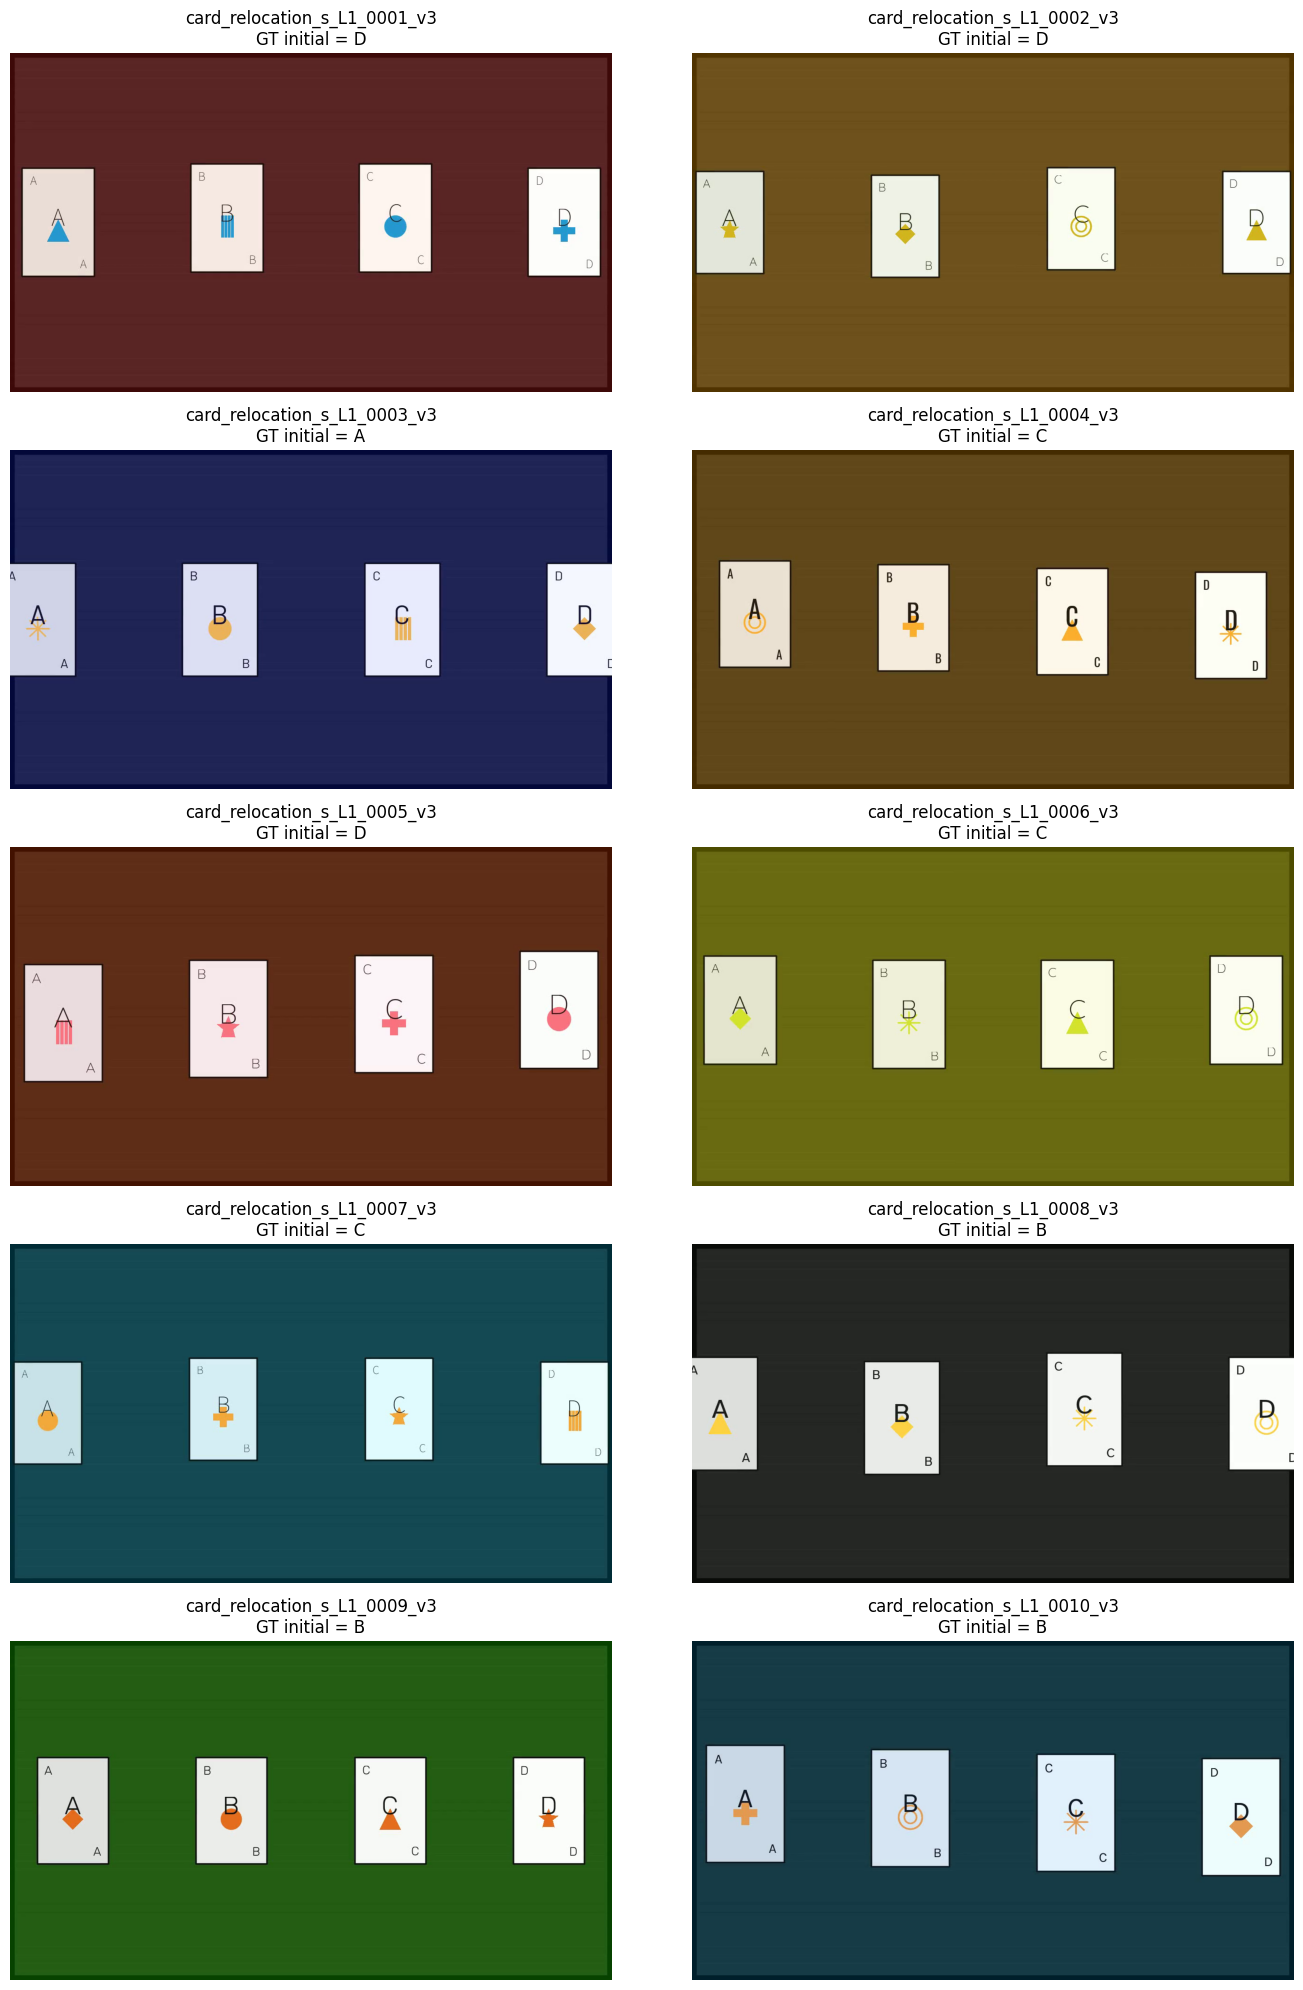

In [ ]:
# ============================================================
# L0 INITIAL-FRAME AUDIT
# ============================================================

import os
import cv2
import json
import matplotlib.pyplot as plt

VIDEO_ROOT = "/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy"

GT_PATH = "/content/drive/MyDrive/videomme_experiments/ground_truth/card_relocation_L1_0001_0050_raw_manifest_records.json"

with open(GT_PATH, "r") as f:
    raw_data = json.load(f)

records = raw_data if isinstance(raw_data, list) else list(raw_data.values())

gt_map = {}

for r in records:
    answer = json.loads(r["answer"])

    gt_map[r["id"]] = {
        "target_card": answer["target_card"],
        "initial_position": answer["initial_position"]
    }


def get_frame(video_path, time_sec=0.5):

    cap = cv2.VideoCapture(video_path)

    fps = cap.get(cv2.CAP_PROP_FPS)

    if fps <= 0:
        fps = 30

    frame_idx = int(time_sec * fps)

    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)

    ok, frame = cap.read()

    cap.release()

    if not ok:
        return None

    frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    return frame


video_files = sorted([
    f for f in os.listdir(VIDEO_ROOT)
    if f.endswith(".mp4")
])[:10]


fig, axes = plt.subplots(5, 2, figsize=(14, 20))
axes = axes.flatten()

for i, filename in enumerate(video_files):

    video_id = os.path.splitext(filename)[0]

    video_path = os.path.join(
        VIDEO_ROOT,
        filename
    )

    frame = get_frame(
        video_path,
        time_sec=0.5
    )

    gt = gt_map[video_id]

    if frame is not None:
        axes[i].imshow(frame)

    axes[i].set_title(
        f"{video_id}\n"
        f"GT initial = {gt['initial_position']}"
    )

    axes[i].axis("off")


plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# L0 — STATIC INITIAL-STATE GROUNDING
# Qwen2.5-VL-3B-Instruct
#
# One image from the initial state (0.5 sec)
# -> identify target card position
#
# Resume-safe: saves after every video
# ============================================================

import os
import json
import time
import gc
import re
import cv2
import torch

from PIL import Image
from collections import Counter

from transformers import (
    Qwen2_5_VLForConditionalGeneration,
    AutoProcessor
)

from qwen_vl_utils import process_vision_info


# ============================================================
# CONFIG
# ============================================================

MODEL_ID = "Qwen/Qwen2.5-VL-3B-Instruct"

VIDEO_ROOT = (
    "/content/videomme_data/"
    "video-mme-logical/videos/card_relocation_s_easy"
)

GT_PATH = (
    "/content/drive/MyDrive/"
    "videomme_experiments/ground_truth/"
    "card_relocation_L1_0001_0050_raw_manifest_records.json"
)

SAVE_DIR = (
    "/content/drive/MyDrive/"
    "videomme_experiments/l0"
)

os.makedirs(SAVE_DIR, exist_ok=True)

RESULT_PATH = os.path.join(
    SAVE_DIR,
    "l0_static_grounding_50_results.json"
)

# Confirmed from the frame audit
INITIAL_TIME_SEC = 0.5


# ============================================================
# LOAD GROUND TRUTH
# ============================================================

print("Loading ground truth...")

with open(GT_PATH, "r") as f:
    raw_data = json.load(f)

# Your file is a list of 50 dictionaries
if isinstance(raw_data, list):
    records = raw_data
elif isinstance(raw_data, dict):
    records = list(raw_data.values())
else:
    raise TypeError(
        f"Unexpected GT type: {type(raw_data)}"
    )

gt_map = {}

for r in records:

    if not isinstance(r, dict):
        continue

    video_id = r.get("id")
    answer = r.get("answer")

    if video_id is None or answer is None:
        continue

    # answer is stored as a JSON string
    if isinstance(answer, str):
        answer = json.loads(answer)

    gt_map[video_id] = {
        "target_card": answer["target_card"],
        "initial_position": answer["initial_position"]
    }

print("GT records:", len(gt_map))


# ============================================================
# LOAD / RESUME RESULTS
# ============================================================

if os.path.exists(RESULT_PATH):

    with open(RESULT_PATH, "r") as f:
        results = json.load(f)

    print(
        f"Existing saved results: {len(results)}"
    )

else:

    results = []

    print("No previous results. Starting fresh.")


# Only skip records that actually completed successfully
completed_ids = {
    r["video_id"]
    for r in results
    if r.get("experiment") == "L0"
    and "valid_output" in r
}

print(
    "Already completed:",
    len(completed_ids)
)


# ============================================================
# LOAD MODEL
# ============================================================

print("\nLoading model...")

model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    device_map="auto"
)

processor = AutoProcessor.from_pretrained(
    MODEL_ID
)

model.eval()

print("Model loaded.")


# ============================================================
# HELPER: READ FRAME
# ============================================================

def get_frame(video_path, time_sec):

    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        raise RuntimeError(
            f"Could not open video: {video_path}"
        )

    fps = cap.get(cv2.CAP_PROP_FPS)

    if fps <= 0:
        fps = 30.0

    frame_count = int(
        cap.get(cv2.CAP_PROP_FRAME_COUNT)
    )

    frame_idx = int(
        time_sec * fps
    )

    frame_idx = max(
        0,
        min(frame_idx, frame_count - 1)
    )

    cap.set(
        cv2.CAP_PROP_POS_FRAMES,
        frame_idx
    )

    ok, frame = cap.read()

    cap.release()

    if not ok:
        raise RuntimeError(
            f"Could not read frame "
            f"{frame_idx} from {video_path}"
        )

    frame = cv2.cvtColor(
        frame,
        cv2.COLOR_BGR2RGB
    )

    return (
        Image.fromarray(frame),
        fps,
        frame_idx
    )


# ============================================================
# HELPER: PARSE MODEL POSITION
# ============================================================

def parse_position(text):

    if text is None:
        return None

    text = text.strip().upper()

    # Exact answer
    if text in ["A", "B", "C", "D"]:
        return text

    # Remove simple formatting
    cleaned = text.replace(
        "POSITION:",
        ""
    ).replace(
        "ANSWER:",
        ""
    ).strip()

    if cleaned in ["A", "B", "C", "D"]:
        return cleaned

    # Look for a standalone A/B/C/D
    matches = re.findall(
        r"\b([ABCD])\b",
        text
    )

    # Accept only when there is exactly one candidate
    if len(matches) == 1:
        return matches[0]

    return None


# ============================================================
# VIDEO LIST
# ============================================================

video_files = sorted([
    f
    for f in os.listdir(VIDEO_ROOT)
    if f.lower().endswith(".mp4")
])

print(
    f"\nVideos found: {len(video_files)}"
)


# ============================================================
# MAIN LOOP
# ============================================================

for idx, filename in enumerate(video_files):

    video_id = os.path.splitext(filename)[0]

    # --------------------------------------------------------
    # RESUME
    # --------------------------------------------------------

    if video_id in completed_ids:

        print(
            f"[{idx+1}/{len(video_files)}] "
            f"SKIP {video_id}"
        )

        continue

    # --------------------------------------------------------
    # PATH / GT
    # --------------------------------------------------------

    video_path = os.path.join(
        VIDEO_ROOT,
        filename
    )

    if video_id not in gt_map:

        print(
            f"[{idx+1}/{len(video_files)}] "
            f"NO GT: {video_id}"
        )

        continue

    gt = gt_map[video_id]

    target_card = gt["target_card"]
    gt_initial = gt["initial_position"]

    print("\n" + "=" * 75)
    print(
        f"[{idx+1}/{len(video_files)}] "
        f"{video_id}"
    )
    print(
        f"Target={target_card} | "
        f"GT initial={gt_initial}"
    )

    try:

        # ====================================================
        # GET INITIAL FRAME
        # ====================================================

        image, fps, frame_idx = get_frame(
            video_path,
            INITIAL_TIME_SEC
        )

        # ====================================================
        # PROMPT
        # ====================================================

        prompt = f"""
Look carefully at this image.

The target card is the card labeled {target_card}.

There are four fixed screen positions:
A, B, C, and D.
These letters indicate positions, not card identities.

This image shows the initial state before any swap round.

Which position currently contains the target card?

Answer with ONLY one letter:
A
B
C
or
D
""".strip()

        messages = [
            {
                "role": "user",
                "content": [
                    {
                        "type": "image",
                        "image": image
                    },
                    {
                        "type": "text",
                        "text": prompt
                    }
                ]
            }
        ]

        # ====================================================
        # PROCESS INPUT
        # ====================================================

        text = processor.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True
        )

        image_inputs, video_inputs = (
            process_vision_info(messages)
        )

        inputs = processor(
            text=[text],
            images=image_inputs,
            videos=video_inputs,
            padding=True,
            return_tensors="pt"
        )

        # Put tensors on model device
        for key in inputs:
            if hasattr(inputs[key], "to"):
                inputs[key] = inputs[key].to(
                    model.device
                )

        # ====================================================
        # GENERATION
        # ====================================================

        if torch.cuda.is_available():
            torch.cuda.reset_peak_memory_stats()

        start_time = time.time()

        with torch.inference_mode():

            generated_ids = model.generate(
                **inputs,
                max_new_tokens=8,
                do_sample=False
            )

        generation_time = (
            time.time() - start_time
        )

        # Only decode newly generated tokens
        generated_ids_trimmed = [
            output_ids[len(input_ids):]
            for input_ids, output_ids in zip(
                inputs["input_ids"],
                generated_ids
            )
        ]

        output_text = processor.batch_decode(
            generated_ids_trimmed,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False
        )[0].strip()

        # ====================================================
        # PARSE
        # ====================================================

        predicted_position = parse_position(
            output_text
        )

        valid_output = (
            predicted_position in
            ["A", "B", "C", "D"]
        )

        correct = (
            predicted_position == gt_initial
        )

        # ====================================================
        # GPU MEMORY
        # ====================================================

        if torch.cuda.is_available():

            peak_gpu_gb = (
                torch.cuda.max_memory_allocated()
                / (1024 ** 3)
            )

        else:

            peak_gpu_gb = None

        # ====================================================
        # RESULT
        # ====================================================

        record = {
            "video_id": video_id,
            "video_path": video_path,

            "target_card": target_card,

            "ground_truth_initial_position":
                gt_initial,

            "initial_frame_time_sec":
                INITIAL_TIME_SEC,

            "initial_frame_index":
                frame_idx,

            "video_fps": fps,

            "raw_output": output_text,

            "predicted_position":
                predicted_position,

            "valid_output":
                valid_output,

            "position_correct":
                correct,

            "generation_time_sec":
                generation_time,

            "peak_gpu_gb":
                peak_gpu_gb,

            "experiment":
                "L0",

            "task":
                "static_initial_grounding"
        }

        results.append(record)

        # ====================================================
        # SAVE IMMEDIATELY
        # ====================================================

        with open(RESULT_PATH, "w") as f:
            json.dump(
                results,
                f,
                indent=2
            )

        print(
            f"Prediction={predicted_position} | "
            f"Correct={correct} | "
            f"Raw={output_text!r}"
        )

    except Exception as e:

        print(
            f"ERROR: {video_id}"
        )

        print(
            repr(e)
        )

        error_record = {
            "video_id": video_id,
            "video_path": video_path,
            "error": repr(e),
            "experiment": "L0"
        }

        results.append(error_record)

        # Save even errors
        with open(RESULT_PATH, "w") as f:
            json.dump(
                results,
                f,
                indent=2
            )

    finally:

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()


# ============================================================
# FINAL SUMMARY
# ============================================================

valid_records = [
    r for r in results
    if r.get("experiment") == "L0"
    and r.get("valid_output") is True
]

correct_records = [
    r for r in valid_records
    if r.get("position_correct") is True
]

error_records = [
    r for r in results
    if r.get("experiment") == "L0"
    and "error" in r
]


print("\n" + "=" * 75)
print("L0 COMPLETE")
print("=" * 75)

print(
    "Saved records:",
    len(results)
)

print(
    "Valid predictions:",
    len(valid_records)
)

print(
    "Errors:",
    len(error_records)
)

if valid_records:

    accuracy = (
        len(correct_records)
        / len(valid_records)
    )

    print(
        f"Position accuracy: "
        f"{accuracy:.4f} "
        f"({len(correct_records)}/"
        f"{len(valid_records)})"
    )

# ============================================================
# DISTRIBUTIONS
# ============================================================

prediction_distribution = Counter(
    r["predicted_position"]
    for r in valid_records
)

gt_distribution = Counter(
    r["ground_truth_initial_position"]
    for r in valid_records
)

print("\nPrediction distribution:")
for pos in ["A", "B", "C", "D"]:
    print(
        f"  {pos}: "
        f"{prediction_distribution.get(pos, 0)}"
    )

print("\nGT distribution:")
for pos in ["A", "B", "C", "D"]:
    print(
        f"  {pos}: "
        f"{gt_distribution.get(pos, 0)}"
    )

print("\nResult file:")
print(RESULT_PATH)

Loading ground truth...
GT records: 50
No previous results. Starting fresh.
Already completed: 0

Loading model...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

Model loaded.

Videos found: 50

[1/50] card_relocation_s_L1_0001_v3
Target=D | GT initial=D
Prediction=D | Correct=True | Raw='D'

[2/50] card_relocation_s_L1_0002_v3
Target=D | GT initial=D
Prediction=D | Correct=True | Raw='D'

[3/50] card_relocation_s_L1_0003_v3
Target=A | GT initial=A
Prediction=A | Correct=True | Raw='A'

[4/50] card_relocation_s_L1_0004_v3
Target=C | GT initial=C
Prediction=C | Correct=True | Raw='C'

[5/50] card_relocation_s_L1_0005_v3
Target=D | GT initial=D
Prediction=D | Correct=True | Raw='D'

[6/50] card_relocation_s_L1_0006_v3
Target=C | GT initial=C
Prediction=C | Correct=True | Raw='C'

[7/50] card_relocation_s_L1_0007_v3
Target=C | GT initial=C
Prediction=C | Correct=True | Raw='C'

[8/50] card_relocation_s_L1_0008_v3
Target=B | GT initial=B
Prediction=B | Correct=True | Raw='B'

[9/50] card_relocation_s_L1_0009_v3
Target=B | GT initial=B
Prediction=B | Correct=True | Raw='B'

[10/50] card_relocation_s_L1_0010_v3
Target=B | GT initial=B
Prediction=B | 

In [ ]:
# ============================================================
# L1 — TEXT-ONLY STATE TRACKING
#
# No video.
# No images.
#
# Input:
#   initial target position
#   sequence of swaps
#
# Output:
#   target position after EVERY round
#
# 1,000 controlled sequences
# Horizons: 1 to 10
# Balanced initial positions
#
# Resume-safe: saves after every example
# ============================================================

import os
import json
import time
import random
import re
import gc

import torch
from collections import Counter, defaultdict

from transformers import (
    Qwen2_5_VLForConditionalGeneration,
    AutoProcessor
)


# ============================================================
# CONFIG
# ============================================================

MODEL_ID = "Qwen/Qwen2.5-VL-3B-Instruct"

SAVE_DIR = (
    "/content/drive/MyDrive/"
    "videomme_experiments/l1"
)

os.makedirs(SAVE_DIR, exist_ok=True)

DATA_PATH = os.path.join(
    SAVE_DIR,
    "l1_synthetic_dataset_1000.json"
)

RESULT_PATH = os.path.join(
    SAVE_DIR,
    "l1_text_tracking_results_1000.json"
)

NUM_EXAMPLES = 1000
MIN_HORIZON = 1
MAX_HORIZON = 10

SEED = 42

# Process one example at a time.
# This is slower but much safer on Colab.
SAVE_EVERY = 1


# ============================================================
# MODEL
# ============================================================

# If the L0 model is still in memory, reuse it.
if "model" not in globals() or "processor" not in globals():

    print("Loading Qwen2.5-VL-3B-Instruct...")

    model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
        MODEL_ID,
        torch_dtype=torch.float16,
        device_map="auto"
    )

    processor = AutoProcessor.from_pretrained(
        MODEL_ID
    )

    model.eval()

    print("Model loaded.")

else:
    print("Reusing model already loaded in memory.")


# ============================================================
# DATA GENERATION
# ============================================================

POSITIONS = ["A", "B", "C", "D"]

random.seed(SEED)


def apply_swap(position, p1, p2):
    """
    If target is at p1, it moves to p2.
    If target is at p2, it moves to p1.
    Otherwise it stays where it is.
    """
    if position == p1:
        return p2

    if position == p2:
        return p1

    return position


def generate_example(example_id):

    # Balance horizons
    horizon = (
        MIN_HORIZON
        + (example_id % (
            MAX_HORIZON - MIN_HORIZON + 1
        ))
    )

    # Balanced starting positions
    initial_position = (
        POSITIONS[example_id % 4]
    )

    current_position = initial_position

    swaps = []
    ground_truth_positions = []

    for round_idx in range(1, horizon + 1):

        # Deterministic but varied seed
        rng = random.Random(
            SEED
            + example_id * 1000
            + round_idx
        )

        p1, p2 = rng.sample(
            POSITIONS,
            2
        )

        swaps.append({
            "round": round_idx,
            "swap": [p1, p2]
        })

        current_position = apply_swap(
            current_position,
            p1,
            p2
        )

        ground_truth_positions.append(
            current_position
        )

    return {
        "example_id": example_id,
        "initial_position": initial_position,
        "horizon": horizon,
        "swaps": swaps,
        "ground_truth_positions":
            ground_truth_positions
    }


# ============================================================
# CREATE DATASET
# ============================================================

if os.path.exists(DATA_PATH):

    with open(DATA_PATH, "r") as f:
        dataset = json.load(f)

    print(
        "Loaded existing dataset:",
        len(dataset)
    )

else:

    dataset = [
        generate_example(i)
        for i in range(NUM_EXAMPLES)
    ]

    with open(DATA_PATH, "w") as f:
        json.dump(
            dataset,
            f,
            indent=2
        )

    print(
        "Created dataset:",
        len(dataset)
    )


# ============================================================
# SHOW FIRST EXAMPLES
# ============================================================

print("\nExample sequences:")

for example in dataset[:3]:

    print(
        "\nID:",
        example["example_id"]
    )

    print(
        "Initial:",
        example["initial_position"]
    )

    print(
        "Horizon:",
        example["horizon"]
    )

    print(
        "Swaps:",
        example["swaps"]
    )

    print(
        "GT:",
        example["ground_truth_positions"]
    )


# ============================================================
# LOAD PREVIOUS RESULTS
# ============================================================

if os.path.exists(RESULT_PATH):

    with open(RESULT_PATH, "r") as f:
        results = json.load(f)

    print(
        "\nExisting results:",
        len(results)
    )

else:

    results = []

    print(
        "\nStarting fresh."
    )


completed_ids = {
    r["example_id"]
    for r in results
    if "predicted_positions" in r
}

print(
    "Already completed:",
    len(completed_ids)
)


# ============================================================
# PARSE MODEL OUTPUT
# ============================================================

def parse_positions(text):

    if not text:
        return None

    text = text.strip()

    # --------------------------------------------------------
    # Try JSON first
    # --------------------------------------------------------

    try:

        obj = json.loads(text)

        if isinstance(obj, dict):

            positions = (
                obj.get("positions")
                or obj.get("position_trace")
            )

            if isinstance(positions, list):

                parsed = []

                for p in positions:

                    if isinstance(p, str):
                        p = p.strip().upper()

                    if p not in POSITIONS:
                        return None

                    parsed.append(p)

                return parsed

            if isinstance(positions, dict):

                # Example:
                # {"1":"A","2":"B","3":"C"}

                parsed = []

                keys = sorted(
                    positions.keys(),
                    key=lambda x: int(x)
                    if str(x).isdigit()
                    else str(x)
                )

                for k in keys:

                    p = str(
                        positions[k]
                    ).strip().upper()

                    if p not in POSITIONS:
                        return None

                    parsed.append(p)

                return parsed

    except Exception:
        pass


    # --------------------------------------------------------
    # Fallback:
    # Find A/B/C/D sequence
    # --------------------------------------------------------

    matches = re.findall(
        r"\b([ABCD])\b",
        text.upper()
    )

    if matches:
        return matches

    return None


# ============================================================
# MAIN EXPERIMENT
# ============================================================

for idx, example in enumerate(dataset):

    example_id = example["example_id"]

    if example_id in completed_ids:

        print(
            f"[{idx+1}/{len(dataset)}] "
            f"SKIP {example_id}"
        )

        continue


    print("\n" + "=" * 75)

    print(
        f"[{idx+1}/{len(dataset)}] "
        f"Example {example_id}"
    )

    initial = example["initial_position"]
    horizon = example["horizon"]
    swaps = example["swaps"]

    print(
        "Initial:",
        initial,
        "| Horizon:",
        horizon
    )


    try:

        # ----------------------------------------------------
        # BUILD TEXT PROMPT
        # ----------------------------------------------------

        lines = []

        lines.append(
            "Track the target card's position "
            "across the swap rounds."
        )

        lines.append(
            f"Initial target position: {initial}"
        )

        lines.append("")

        lines.append(
            "The fixed screen positions are "
            "A, B, C, and D."
        )

        lines.append(
            "Each round swaps the cards at "
            "the two listed positions."
        )

        lines.append(
            "The position labels do not move."
        )

        lines.append("")

        for s in swaps:

            p1, p2 = s["swap"]

            lines.append(
                f"Round {s['round']}: "
                f"swap {p1} and {p2}"
            )

        lines.append("")

        lines.append(
            "Return ONLY a JSON object in this format:"
        )

        lines.append(
            '{"positions":["A","B","C"]}'
        )

        lines.append(
            "The array must contain exactly one "
            "position for every round."
        )

        prompt = "\n".join(lines)


        # ----------------------------------------------------
        # QWEN MESSAGE
        # ----------------------------------------------------

        messages = [
            {
                "role": "user",
                "content": [
                    {
                        "type": "text",
                        "text": prompt
                    }
                ]
            }
        ]


        # ----------------------------------------------------
        # TOKENIZE
        # ----------------------------------------------------

        text = processor.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True
        )

        inputs = processor(
            text=[text],
            padding=True,
            return_tensors="pt"
        )

        inputs = {
            k: v.to(model.device)
            if hasattr(v, "to")
            else v
            for k, v in inputs.items()
        }


        # ----------------------------------------------------
        # GENERATE
        # ----------------------------------------------------

        start_time = time.time()

        with torch.inference_mode():

            generated_ids = model.generate(
                **inputs,
                max_new_tokens=128,
                do_sample=False
            )

        generation_time = (
            time.time() - start_time
        )


        # ----------------------------------------------------
        # DECODE
        # ----------------------------------------------------

        generated_ids_trimmed = [
            output_ids[len(input_ids):]
            for input_ids, output_ids
            in zip(
                inputs["input_ids"],
                generated_ids
            )
        ]

        output_text = processor.batch_decode(
            generated_ids_trimmed,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False
        )[0].strip()


        # ----------------------------------------------------
        # PARSE
        # ----------------------------------------------------

        predicted_positions = parse_positions(
            output_text
        )

        valid_output = (
            predicted_positions is not None
        )

        correct_length = (
            valid_output
            and len(predicted_positions)
            == horizon
        )


        # ----------------------------------------------------
        # PER-ROUND ACCURACY
        # ----------------------------------------------------

        round_correct = []

        if valid_output:

            for r in range(horizon):

                if (
                    r < len(predicted_positions)
                    and
                    predicted_positions[r]
                    ==
                    example[
                        "ground_truth_positions"
                    ][r]
                ):

                    round_correct.append(True)

                else:

                    round_correct.append(False)

        else:

            round_correct = [
                False
                for _ in range(horizon)
            ]


        correct_count = sum(
            round_correct
        )

        position_accuracy = (
            correct_count / horizon
            if horizon > 0
            else 0.0
        )

        exact_trajectory = (
            valid_output
            and correct_length
            and all(round_correct)
        )


        # ----------------------------------------------------
        # GPU MEMORY
        # ----------------------------------------------------

        if torch.cuda.is_available():

            peak_gpu_gb = (
                torch.cuda.max_memory_allocated()
                / (1024 ** 3)
            )

            torch.cuda.reset_peak_memory_stats()

        else:

            peak_gpu_gb = None


        # ----------------------------------------------------
        # SAVE RECORD
        # ----------------------------------------------------

        record = {
            "example_id":
                example_id,

            "initial_position":
                initial,

            "horizon":
                horizon,

            "swaps":
                swaps,

            "ground_truth_positions":
                example[
                    "ground_truth_positions"
                ],

            "raw_output":
                output_text,

            "predicted_positions":
                predicted_positions,

            "valid_output":
                valid_output,

            "correct_length":
                correct_length,

            "round_correct":
                round_correct,

            "correct_count":
                correct_count,

            "position_accuracy":
                position_accuracy,

            "exact_trajectory":
                exact_trajectory,

            "generation_time_sec":
                generation_time,

            "peak_gpu_gb":
                peak_gpu_gb,

            "experiment":
                "L1"
        }

        results.append(record)


        # ----------------------------------------------------
        # SAVE IMMEDIATELY
        # ----------------------------------------------------

        with open(RESULT_PATH, "w") as f:

            json.dump(
                results,
                f,
                indent=2
            )


        print(
            "GT:",
            example["ground_truth_positions"]
        )

        print(
            "Pred:",
            predicted_positions
        )

        print(
            "Accuracy:",
            f"{position_accuracy:.3f}"
        )

        print(
            "Exact:",
            exact_trajectory
        )


    except Exception as e:

        print(
            "ERROR:",
            repr(e)
        )

        error_record = {
            "example_id":
                example_id,

            "error":
                repr(e),

            "experiment":
                "L1"
        }

        results.append(
            error_record
        )

        with open(RESULT_PATH, "w") as f:

            json.dump(
                results,
                f,
                indent=2
            )


    finally:

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()


# ============================================================
# FINAL ANALYSIS
# ============================================================

valid_results = [
    r for r in results
    if r.get("experiment") == "L1"
    and r.get("valid_output") is True
]

print("\n" + "=" * 75)
print("L1 COMPLETE")
print("=" * 75)

print(
    "Total results:",
    len(results)
)

print(
    "Valid outputs:",
    len(valid_results)
)


# ------------------------------------------------------------
# OVERALL POSITION ACCURACY
# ------------------------------------------------------------

total_correct = sum(
    r["correct_count"]
    for r in valid_results
)

total_rounds = sum(
    r["horizon"]
    for r in valid_results
)

if total_rounds:

    overall_accuracy = (
        total_correct
        / total_rounds
    )

    print(
        f"\nOverall position accuracy: "
        f"{overall_accuracy:.4f}"
    )


# ------------------------------------------------------------
# EXACT TRAJECTORY
# ------------------------------------------------------------

exact_count = sum(
    1
    for r in valid_results
    if r.get("exact_trajectory") is True
)

if valid_results:

    exact_rate = (
        exact_count
        / len(valid_results)
    )

    print(
        f"Exact full-trajectory accuracy: "
        f"{exact_rate:.4f}"
    )


# ------------------------------------------------------------
# ACCURACY BY HORIZON
# ------------------------------------------------------------

print("\nAccuracy by horizon:")

by_horizon = defaultdict(list)

for r in valid_results:

    by_horizon[
        r["horizon"]
    ].append(r)

for horizon in sorted(by_horizon):

    group = by_horizon[horizon]

    correct = sum(
        r["correct_count"]
        for r in group
    )

    rounds = sum(
        r["horizon"]
        for r in group
    )

    exact = sum(
        r["exact_trajectory"]
        for r in group
    )

    accuracy = (
        correct / rounds
        if rounds else 0
    )

    exact_rate = (
        exact / len(group)
        if group else 0
    )

    print(
        f"Horizon {horizon:2d}: "
        f"position={accuracy:.3f} | "
        f"exact={exact_rate:.3f} | "
        f"n={len(group)}"
    )


# ------------------------------------------------------------
# ACCURACY BY INITIAL POSITION
# ------------------------------------------------------------

print("\nAccuracy by initial position:")

by_initial = defaultdict(list)

for r in valid_results:

    by_initial[
        r["initial_position"]
    ].append(r)

for position in POSITIONS:

    group = by_initial[position]

    if not group:
        continue

    correct = sum(
        r["correct_count"]
        for r in group
    )

    rounds = sum(
        r["horizon"]
        for r in group
    )

    accuracy = (
        correct / rounds
        if rounds else 0
    )

    print(
        f"Initial {position}: "
        f"{accuracy:.3f} "
        f"(n={len(group)})"
    )


# ------------------------------------------------------------
# SAVE SUMMARY
# ------------------------------------------------------------

summary = {
    "experiment": "L1",

    "num_examples":
        len(results),

    "valid_examples":
        len(valid_results),

    "overall_position_accuracy":
        overall_accuracy
        if total_rounds
        else None,

    "exact_trajectory_rate":
        exact_rate
        if valid_results
        else None,

    "accuracy_by_horizon": {},

    "accuracy_by_initial_position": {}
}


for horizon in sorted(by_horizon):

    group = by_horizon[horizon]

    correct = sum(
        r["correct_count"]
        for r in group
    )

    rounds = sum(
        r["horizon"]
        for r in group
    )

    exact = sum(
        r["exact_trajectory"]
        for r in group
    )

    summary[
        "accuracy_by_horizon"
    ][str(horizon)] = {
        "position_accuracy":
            correct / rounds,

        "exact_trajectory_rate":
            exact / len(group),

        "n":
            len(group)
    }


for position in POSITIONS:

    group = by_initial[position]

    if group:

        correct = sum(
            r["correct_count"]
            for r in group
        )

        rounds = sum(
            r["horizon"]
            for r in group
        )

        summary[
            "accuracy_by_initial_position"
        ][position] = (
            correct / rounds
            if rounds
            else None
        )


SUMMARY_PATH = os.path.join(
    SAVE_DIR,
    "l1_summary_1000.json"
)

with open(SUMMARY_PATH, "w") as f:

    json.dump(
        summary,
        f,
        indent=2
    )


print("\nResults:")
print(RESULT_PATH)

print("\nSummary:")
print(SUMMARY_PATH)

Streaming output truncated to the last 5000 lines.
[380/1000] Example 379
Initial: D | Horizon: 10
GT: ['D', 'D', 'B', 'C', 'C', 'A', 'B', 'B', 'B', 'B']
Pred: ['D', 'B', 'C']
Accuracy: 0.100
Exact: False

[381/1000] Example 380
Initial: A | Horizon: 1
GT: ['B']
Pred: ['B', 'A', 'C']
Accuracy: 1.000
Exact: False

[382/1000] Example 381
Initial: B | Horizon: 2
GT: ['B', 'C']
Pred: ['D', 'C']
Accuracy: 0.500
Exact: False

[383/1000] Example 382
Initial: C | Horizon: 3
GT: ['B', 'A', 'B']
Pred: ['A', 'B', 'C']
Accuracy: 0.000
Exact: False

[384/1000] Example 383
Initial: D | Horizon: 4
GT: ['D', 'D', 'D', 'D']
Pred: ['D', 'A', 'B']
Accuracy: 0.250
Exact: False

[385/1000] Example 384
Initial: A | Horizon: 5
GT: ['A', 'D', 'D', 'C', 'C']
Pred: ['D', 'A', 'B']
Accuracy: 0.000
Exact: False

[386/1000] Example 385
Initial: B | Horizon: 6
GT: ['B', 'B', 'D', 'D', 'B', 'D']
Pred: ['D', 'B', 'C']
Accuracy: 0.167
Exact: False

[387/1000] Example 386
Initial: C | Horizon: 7
GT: ['A', 'B', 'B', 'A'

In [ ]:
# ============================================================
# L1a — SINGLE-TRANSITION TEXT-ONLY TRACKING
#
# No video
# No images
# One swap only
#
# 500 examples
# Balanced:
#   - initial positions A/B/C/D
#   - all 6 possible swaps
#
# Question:
#   Where is the target AFTER this ONE swap?
#
# Resume-safe
# ============================================================

import os
import json
import time
import random
import gc

import torch
from collections import Counter, defaultdict

from transformers import (
    Qwen2_5_VLForConditionalGeneration,
    AutoProcessor
)


# ============================================================
# CONFIG
# ============================================================

MODEL_ID = "Qwen/Qwen2.5-VL-3B-Instruct"

SAVE_DIR = (
    "/content/drive/MyDrive/"
    "videomme_experiments/l1a"
)

os.makedirs(SAVE_DIR, exist_ok=True)

DATA_PATH = os.path.join(
    SAVE_DIR,
    "l1a_single_transition_dataset_500.json"
)

RESULT_PATH = os.path.join(
    SAVE_DIR,
    "l1a_single_transition_results_500.json"
)

NUM_EXAMPLES = 500
SEED = 42

POSITIONS = ["A", "B", "C", "D"]

ALL_SWAPS = [
    ("A", "B"),
    ("A", "C"),
    ("A", "D"),
    ("B", "C"),
    ("B", "D"),
    ("C", "D"),
]


# ============================================================
# LOAD MODEL
# ============================================================

if "model" not in globals() or "processor" not in globals():

    print("Loading Qwen2.5-VL-3B-Instruct...")

    model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
        MODEL_ID,
        torch_dtype=torch.float16,
        device_map="auto"
    )

    processor = AutoProcessor.from_pretrained(
        MODEL_ID
    )

    model.eval()

    print("Model loaded.")

else:

    print("Reusing model already loaded.")


# ============================================================
# STATE TRANSITION
# ============================================================

def apply_swap(position, p1, p2):

    if position == p1:
        return p2

    if position == p2:
        return p1

    return position


# ============================================================
# GENERATE BALANCED DATASET
# ============================================================

def generate_dataset():

    data = []

    # Repeated balanced pattern
    #
    # 4 initial positions
    # x 6 swaps
    # = 24 unique combinations
    #
    # 500 examples gives repeated balanced combinations.

    combinations = [
        (initial, p1, p2)
        for initial in POSITIONS
        for p1, p2 in ALL_SWAPS
    ]

    rng = random.Random(SEED)

    for i in range(NUM_EXAMPLES):

        initial, p1, p2 = combinations[
            i % len(combinations)
        ]

        # Deterministic shuffle of order while preserving balance
        if i % len(combinations) == 0 and i > 0:
            rng.shuffle(combinations)

        final_position = apply_swap(
            initial,
            p1,
            p2
        )

        data.append({
            "example_id": i,
            "initial_position": initial,
            "swap": [p1, p2],
            "ground_truth_position":
                final_position
        })

    return data


# ============================================================
# LOAD OR CREATE DATASET
# ============================================================

if os.path.exists(DATA_PATH):

    with open(DATA_PATH, "r") as f:
        dataset = json.load(f)

    print(
        "Loaded existing dataset:",
        len(dataset)
    )

else:

    dataset = generate_dataset()

    with open(DATA_PATH, "w") as f:
        json.dump(
            dataset,
            f,
            indent=2
        )

    print(
        "Created dataset:",
        len(dataset)
    )


# ============================================================
# SHOW FIRST EXAMPLES
# ============================================================

print("\nFirst 10 examples:")

for x in dataset[:10]:

    print(
        x["example_id"],
        "| initial=",
        x["initial_position"],
        "| swap=",
        x["swap"],
        "| GT=",
        x["ground_truth_position"]
    )


# ============================================================
# LOAD PREVIOUS RESULTS
# ============================================================

if os.path.exists(RESULT_PATH):

    with open(RESULT_PATH, "r") as f:
        results = json.load(f)

    print(
        "\nExisting results:",
        len(results)
    )

else:

    results = []

    print(
        "\nStarting fresh."
    )


completed_ids = {
    r["example_id"]
    for r in results
    if "predicted_position" in r
}

print(
    "Already completed:",
    len(completed_ids)
)


# ============================================================
# PARSE ONE POSITION
# ============================================================

def parse_position(text):

    if not text:
        return None

    text = text.strip().upper()

    # Exact answer
    if text in POSITIONS:
        return text

    # Look for a standalone position
    import re

    matches = re.findall(
        r"\b([ABCD])\b",
        text
    )

    if len(matches) == 1:
        return matches[0]

    return None


# ============================================================
# MAIN LOOP
# ============================================================

for idx, example in enumerate(dataset):

    example_id = example["example_id"]

    if example_id in completed_ids:

        print(
            f"[{idx+1}/{len(dataset)}] "
            f"SKIP {example_id}"
        )

        continue


    initial = example["initial_position"]
    p1, p2 = example["swap"]
    gt = example["ground_truth_position"]


    print("\n" + "=" * 70)

    print(
        f"[{idx+1}/{len(dataset)}] "
        f"Example {example_id}"
    )

    print(
        f"Initial={initial} | "
        f"Swap={p1}<->{p2} | "
        f"GT={gt}"
    )


    try:

        # ----------------------------------------------------
        # PROMPT
        # ----------------------------------------------------

        prompt = f"""
Track the target card through one swap.

The target card is currently at position {initial}.

The four fixed screen positions are:
A, B, C, and D.

Round 1:
The cards at positions {p1} and {p2} swap places.

Where is the target card after the swap?

Answer ONLY one letter:
A
B
C
or
D
""".strip()


        messages = [
            {
                "role": "user",
                "content": [
                    {
                        "type": "text",
                        "text": prompt
                    }
                ]
            }
        ]


        # ----------------------------------------------------
        # PROCESS
        # ----------------------------------------------------

        text = processor.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True
        )

        inputs = processor(
            text=[text],
            padding=True,
            return_tensors="pt"
        )

        inputs = {
            k: v.to(model.device)
            if hasattr(v, "to")
            else v
            for k, v in inputs.items()
        }


        # ----------------------------------------------------
        # GENERATE
        # ----------------------------------------------------

        if torch.cuda.is_available():
            torch.cuda.reset_peak_memory_stats()

        start_time = time.time()

        with torch.inference_mode():

            generated_ids = model.generate(
                **inputs,
                max_new_tokens=8,
                do_sample=False
            )

        generation_time = (
            time.time() - start_time
        )


        # ----------------------------------------------------
        # DECODE
        # ----------------------------------------------------

        generated_ids_trimmed = [
            output_ids[len(input_ids):]
            for input_ids, output_ids
            in zip(
                inputs["input_ids"],
                generated_ids
            )
        ]

        output_text = processor.batch_decode(
            generated_ids_trimmed,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False
        )[0].strip()


        # ----------------------------------------------------
        # PARSE
        # ----------------------------------------------------

        prediction = parse_position(
            output_text
        )

        valid_output = (
            prediction in POSITIONS
        )

        correct = (
            prediction == gt
        )


        # ----------------------------------------------------
        # GPU MEMORY
        # ----------------------------------------------------

        if torch.cuda.is_available():

            peak_gpu_gb = (
                torch.cuda.max_memory_allocated()
                / (1024 ** 3)
            )

            torch.cuda.reset_peak_memory_stats()

        else:

            peak_gpu_gb = None


        # ----------------------------------------------------
        # SAVE
        # ----------------------------------------------------

        record = {
            "example_id":
                example_id,

            "initial_position":
                initial,

            "swap":
                [p1, p2],

            "ground_truth_position":
                gt,

            "raw_output":
                output_text,

            "predicted_position":
                prediction,

            "valid_output":
                valid_output,

            "position_correct":
                correct,

            "generation_time_sec":
                generation_time,

            "peak_gpu_gb":
                peak_gpu_gb,

            "experiment":
                "L1a"
        }

        results.append(record)


        # Save after every example
        with open(RESULT_PATH, "w") as f:

            json.dump(
                results,
                f,
                indent=2
            )


        print(
            f"Prediction={prediction} | "
            f"Correct={correct} | "
            f"Raw={output_text!r}"
        )


    except Exception as e:

        print(
            "ERROR:",
            repr(e)
        )

        results.append({
            "example_id":
                example_id,

            "error":
                repr(e),

            "experiment":
                "L1a"
        })

        with open(RESULT_PATH, "w") as f:

            json.dump(
                results,
                f,
                indent=2
            )


    finally:

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()


# ============================================================
# FINAL SUMMARY
# ============================================================

valid = [
    r for r in results
    if r.get("experiment") == "L1a"
    and r.get("valid_output") is True
]

correct = [
    r for r in valid
    if r.get("position_correct") is True
]

errors = [
    r for r in results
    if r.get("experiment") == "L1a"
    and "error" in r
]


print("\n" + "=" * 70)
print("L1a COMPLETE")
print("=" * 70)

print(
    "Total results:",
    len(results)
)

print(
    "Valid:",
    len(valid)
)

print(
    "Errors:",
    len(errors)
)

if valid:

    accuracy = (
        len(correct)
        / len(valid)
    )

    print(
        f"Single-transition accuracy: "
        f"{accuracy:.4f} "
        f"({len(correct)}/{len(valid)})"
    )


# ============================================================
# ACCURACY BY INITIAL POSITION
# ============================================================

print("\nAccuracy by initial position:")

for position in POSITIONS:

    group = [
        r for r in valid
        if r["initial_position"] == position
    ]

    if not group:
        continue

    acc = sum(
        r["position_correct"]
        for r in group
    ) / len(group)

    print(
        f"  {position}: "
        f"{acc:.4f} "
        f"(n={len(group)})"
    )


# ============================================================
# ACCURACY BY SWAP
# ============================================================

print("\nAccuracy by swap:")

for p1, p2 in ALL_SWAPS:

    swap = [p1, p2]

    group = [
        r for r in valid
        if r["swap"] == swap
    ]

    if not group:
        continue

    acc = sum(
        r["position_correct"]
        for r in group
    ) / len(group)

    print(
        f"  {p1}<->{p2}: "
        f"{acc:.4f} "
        f"(n={len(group)})"
    )


# ============================================================
# PREDICTION DISTRIBUTION
# ============================================================

prediction_distribution = Counter(
    r["predicted_position"]
    for r in valid
)

gt_distribution = Counter(
    r["ground_truth_position"]
    for r in valid
)

print("\nPrediction distribution:")

for p in POSITIONS:
    print(
        f"  {p}: "
        f"{prediction_distribution.get(p, 0)}"
    )

print("\nGround-truth distribution:")

for p in POSITIONS:
    print(
        f"  {p}: "
        f"{gt_distribution.get(p, 0)}"
    )


# ============================================================
# SAVE SUMMARY
# ============================================================

summary = {
    "experiment":
        "L1a",

    "num_examples":
        NUM_EXAMPLES,

    "valid_examples":
        len(valid),

    "errors":
        len(errors),

    "overall_accuracy":
        (
            len(correct) / len(valid)
            if valid
            else None
        ),

    "accuracy_by_initial_position": {},

    "accuracy_by_swap": {},

    "prediction_distribution":
        dict(prediction_distribution),

    "ground_truth_distribution":
        dict(gt_distribution)
}


for position in POSITIONS:

    group = [
        r for r in valid
        if r["initial_position"] == position
    ]

    if group:

        summary[
            "accuracy_by_initial_position"
        ][position] = (
            sum(
                r["position_correct"]
                for r in group
            )
            / len(group)
        )


for p1, p2 in ALL_SWAPS:

    swap = [p1, p2]

    group = [
        r for r in valid
        if r["swap"] == swap
    ]

    if group:

        summary[
            "accuracy_by_swap"
        ][f"{p1}<->{p2}"] = (
            sum(
                r["position_correct"]
                for r in group
            )
            / len(group)
        )


SUMMARY_PATH = os.path.join(
    SAVE_DIR,
    "l1a_summary_500.json"
)

with open(SUMMARY_PATH, "w") as f:

    json.dump(
        summary,
        f,
        indent=2
    )


print("\nResults saved to:")
print(RESULT_PATH)

print("\nSummary saved to:")
print(SUMMARY_PATH)

Loading Qwen2.5-VL-3B-Instruct...


config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/65.4k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

...

tokenizer_config.json:   0%|          | 0.00/5.70k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Model loaded.
Created dataset: 500

First 10 examples:
0 | initial= A | swap= ['A', 'B'] | GT= B
1 | initial= A | swap= ['A', 'C'] | GT= C
2 | initial= A | swap= ['A', 'D'] | GT= D
3 | initial= A | swap= ['B', 'C'] | GT= A
4 | initial= A | swap= ['B', 'D'] | GT= A
5 | initial= A | swap= ['C', 'D'] | GT= A
6 | initial= B | swap= ['A', 'B'] | GT= A
7 | initial= B | swap= ['A', 'C'] | GT= B
8 | initial= B | swap= ['A', 'D'] | GT= B
9 | initial= B | swap= ['B', 'C'] | GT= C

Starting fresh.
Already completed: 0

[1/500] Example 0
Initial=A | Swap=A<->B | GT=B
Prediction=B | Correct=True | Raw='B'

[2/500] Example 1
Initial=A | Swap=A<->C | GT=C
Prediction=B | Correct=False | Raw='B'

[3/500] Example 2
Initial=A | Swap=A<->D | GT=D
Prediction=D | Correct=True | Raw='D'

[4/500] Example 3
Initial=A | Swap=B<->C | GT=A
Prediction=B | Correct=False | Raw='B'

[5/500] Example 4
Initial=A | Swap=B<->D | GT=A
Prediction=B | Correct=False | Raw='B'

[6/500] Example 5
Initial=A | Swap=C<->D | GT=A


In [ ]:
# ============================================================
# L1b — SINGLE-TRANSITION MOVE CLASSIFICATION
#
# No video
# No images
#
# Question:
#   Did the target card move during this swap?
#
# YES = target's current position is one of the swapped positions
# NO  = target's current position is not involved in the swap
#
# 500 balanced examples
# Resume-safe
# ============================================================

import os
import json
import time
import random
import gc
import re

import torch
from collections import Counter

from transformers import (
    Qwen2_5_VLForConditionalGeneration,
    AutoProcessor
)


# ============================================================
# CONFIG
# ============================================================

MODEL_ID = "Qwen/Qwen2.5-VL-3B-Instruct"

SAVE_DIR = (
    "/content/drive/MyDrive/"
    "videomme_experiments/l1b"
)

os.makedirs(SAVE_DIR, exist_ok=True)

DATA_PATH = os.path.join(
    SAVE_DIR,
    "l1b_move_classification_dataset_500.json"
)

RESULT_PATH = os.path.join(
    SAVE_DIR,
    "l1b_move_classification_results_500.json"
)

SUMMARY_PATH = os.path.join(
    SAVE_DIR,
    "l1b_summary_500.json"
)

NUM_EXAMPLES = 500
SEED = 42

POSITIONS = ["A", "B", "C", "D"]

ALL_SWAPS = [
    ("A", "B"),
    ("A", "C"),
    ("A", "D"),
    ("B", "C"),
    ("B", "D"),
    ("C", "D"),
]


# ============================================================
# LOAD MODEL
# ============================================================

if "model" not in globals() or "processor" not in globals():

    print("Loading Qwen2.5-VL-3B-Instruct...")

    model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
        MODEL_ID,
        torch_dtype=torch.float16,
        device_map="auto"
    )

    processor = AutoProcessor.from_pretrained(
        MODEL_ID
    )

    model.eval()

    print("Model loaded.")

else:

    print("Reusing model already loaded.")


# ============================================================
# GENERATE BALANCED DATA
# ============================================================

def generate_dataset():

    rng = random.Random(SEED)

    examples = []

    # 24 combinations:
    # 4 initial positions × 6 swaps
    combinations = [
        (initial, p1, p2)
        for initial in POSITIONS
        for p1, p2 in ALL_SWAPS
    ]

    # Repeat combinations to reach 500 examples
    for i in range(NUM_EXAMPLES):

        initial, p1, p2 = combinations[
            i % len(combinations)
        ]

        target_moved = (
            initial == p1
            or initial == p2
        )

        examples.append({
            "example_id": i,

            "initial_position":
                initial,

            "swap":
                [p1, p2],

            "ground_truth_moved":
                target_moved
        })

    # Shuffle while preserving the balanced dataset
    rng.shuffle(examples)

    return examples


# ============================================================
# LOAD / CREATE DATASET
# ============================================================

if os.path.exists(DATA_PATH):

    with open(DATA_PATH, "r") as f:
        dataset = json.load(f)

    print(
        "Loaded existing dataset:",
        len(dataset)
    )

else:

    dataset = generate_dataset()

    with open(DATA_PATH, "w") as f:
        json.dump(
            dataset,
            f,
            indent=2
        )

    print(
        "Created dataset:",
        len(dataset)
    )


# ============================================================
# DATASET CHECK
# ============================================================

yes_count = sum(
    x["ground_truth_moved"]
    for x in dataset
)

no_count = len(dataset) - yes_count

print("\nDataset balance:")
print("YES:", yes_count)
print("NO :", no_count)


# ============================================================
# LOAD PREVIOUS RESULTS
# ============================================================

if os.path.exists(RESULT_PATH):

    with open(RESULT_PATH, "r") as f:
        results = json.load(f)

    print(
        "\nExisting results:",
        len(results)
    )

else:

    results = []

    print(
        "\nStarting fresh."
    )


completed_ids = {
    r["example_id"]
    for r in results
    if "predicted_moved" in r
}

print(
    "Already completed:",
    len(completed_ids)
)


# ============================================================
# PARSE YES / NO
# ============================================================

def parse_yes_no(text):

    if not text:
        return None

    text = text.strip().upper()

    # Exact answer
    if text in ["YES", "NO"]:
        return text == "YES"

    # Remove simple formatting
    cleaned = (
        text
        .replace("ANSWER:", "")
        .replace("RESULT:", "")
        .strip()
    )

    if cleaned in ["YES", "NO"]:
        return cleaned == "YES"

    # Look for explicit YES/NO
    matches = re.findall(
        r"\b(YES|NO)\b",
        text
    )

    # Only accept an unambiguous result
    if len(matches) == 1:

        return matches[0] == "YES"

    return None


# ============================================================
# MAIN LOOP
# ============================================================

for idx, example in enumerate(dataset):

    example_id = example["example_id"]

    if example_id in completed_ids:

        print(
            f"[{idx+1}/{len(dataset)}] "
            f"SKIP {example_id}"
        )

        continue


    initial = example["initial_position"]

    p1, p2 = example["swap"]

    gt = example["ground_truth_moved"]


    print("\n" + "=" * 70)

    print(
        f"[{idx+1}/{len(dataset)}] "
        f"Example {example_id}"
    )

    print(
        f"Initial={initial} | "
        f"Swap={p1}<->{p2} | "
        f"GT moved={gt}"
    )


    try:

        # ----------------------------------------------------
        # PROMPT
        # ----------------------------------------------------

        prompt = f"""
Track the target card through one swap.

The target card is currently at position {initial}.

The four fixed screen positions are:
A, B, C, and D.

Round 1:
The cards at positions {p1} and {p2} swap places.

Did the target card move during this swap?

Answer ONLY:
YES
or
NO
""".strip()


        messages = [
            {
                "role": "user",
                "content": [
                    {
                        "type": "text",
                        "text": prompt
                    }
                ]
            }
        ]


        # ----------------------------------------------------
        # PROCESS
        # ----------------------------------------------------

        text = processor.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True
        )

        inputs = processor(
            text=[text],
            padding=True,
            return_tensors="pt"
        )

        inputs = {
            k: v.to(model.device)
            if hasattr(v, "to")
            else v
            for k, v in inputs.items()
        }


        # ----------------------------------------------------
        # GENERATE
        # ----------------------------------------------------

        if torch.cuda.is_available():
            torch.cuda.reset_peak_memory_stats()

        start_time = time.time()

        with torch.inference_mode():

            generated_ids = model.generate(
                **inputs,
                max_new_tokens=8,
                do_sample=False
            )

        generation_time = (
            time.time() - start_time
        )


        # ----------------------------------------------------
        # DECODE
        # ----------------------------------------------------

        generated_ids_trimmed = [
            output_ids[len(input_ids):]
            for input_ids, output_ids
            in zip(
                inputs["input_ids"],
                generated_ids
            )
        ]

        output_text = processor.batch_decode(
            generated_ids_trimmed,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False
        )[0].strip()


        # ----------------------------------------------------
        # PARSE
        # ----------------------------------------------------

        prediction = parse_yes_no(
            output_text
        )

        valid_output = (
            prediction is not None
        )

        correct = (
            prediction == gt
        )


        # ----------------------------------------------------
        # GPU MEMORY
        # ----------------------------------------------------

        if torch.cuda.is_available():

            peak_gpu_gb = (
                torch.cuda.max_memory_allocated()
                / (1024 ** 3)
            )

            torch.cuda.reset_peak_memory_stats()

        else:

            peak_gpu_gb = None


        # ----------------------------------------------------
        # SAVE RECORD
        # ----------------------------------------------------

        record = {
            "example_id":
                example_id,

            "initial_position":
                initial,

            "swap":
                [p1, p2],

            "ground_truth_moved":
                gt,

            "raw_output":
                output_text,

            "predicted_moved":
                prediction,

            "valid_output":
                valid_output,

            "correct":
                correct,

            "generation_time_sec":
                generation_time,

            "peak_gpu_gb":
                peak_gpu_gb,

            "experiment":
                "L1b"
        }

        results.append(record)


        # ----------------------------------------------------
        # SAVE AFTER EVERY EXAMPLE
        # ----------------------------------------------------

        with open(RESULT_PATH, "w") as f:

            json.dump(
                results,
                f,
                indent=2
            )


        print(
            f"Prediction={prediction} | "
            f"Correct={correct} | "
            f"Raw={output_text!r}"
        )


    except Exception as e:

        print(
            "ERROR:",
            repr(e)
        )

        results.append({
            "example_id":
                example_id,

            "error":
                repr(e),

            "experiment":
                "L1b"
        })

        with open(RESULT_PATH, "w") as f:

            json.dump(
                results,
                f,
                indent=2
            )


    finally:

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()


# ============================================================
# FINAL SUMMARY
# ============================================================

valid = [
    r for r in results
    if r.get("experiment") == "L1b"
    and r.get("valid_output") is True
]

correct = [
    r for r in valid
    if r.get("correct") is True
]

errors = [
    r for r in results
    if r.get("experiment") == "L1b"
    and "error" in r
]


print("\n" + "=" * 70)
print("L1b COMPLETE")
print("=" * 70)

print(
    "Total results:",
    len(results)
)

print(
    "Valid:",
    len(valid)
)

print(
    "Errors:",
    len(errors)
)

if valid:

    accuracy = (
        len(correct)
        / len(valid)
    )

    print(
        f"Overall YES/NO accuracy: "
        f"{accuracy:.4f} "
        f"({len(correct)}/{len(valid)})"
    )


# ============================================================
# YES / NO CLASS ACCURACY
# ============================================================

print("\nAccuracy by ground-truth class:")

for gt_value in [True, False]:

    group = [
        r for r in valid
        if r["ground_truth_moved"] == gt_value
    ]

    if not group:
        continue

    acc = sum(
        r["correct"]
        for r in group
    ) / len(group)

    label = "YES (moved)" if gt_value else "NO (did not move)"

    print(
        f"  {label}: "
        f"{acc:.4f} "
        f"(n={len(group)})"
    )


# ============================================================
# PREDICTION DISTRIBUTION
# ============================================================

prediction_distribution = Counter(
    r["predicted_moved"]
    for r in valid
)

gt_distribution = Counter(
    r["ground_truth_moved"]
    for r in valid
)

print("\nPrediction distribution:")

print(
    "  YES:",
    prediction_distribution.get(True, 0)
)

print(
    "  NO :",
    prediction_distribution.get(False, 0)
)

print("\nGround-truth distribution:")

print(
    "  YES:",
    gt_distribution.get(True, 0)
)

print(
    "  NO :",
    gt_distribution.get(False, 0)
)


# ============================================================
# ACCURACY BY INITIAL POSITION
# ============================================================

print("\nAccuracy by initial position:")

for position in POSITIONS:

    group = [
        r for r in valid
        if r["initial_position"] == position
    ]

    if not group:
        continue

    acc = sum(
        r["correct"]
        for r in group
    ) / len(group)

    print(
        f"  {position}: "
        f"{acc:.4f} "
        f"(n={len(group)})"
    )


# ============================================================
# ACCURACY BY SWAP
# ============================================================

print("\nAccuracy by swap:")

for p1, p2 in ALL_SWAPS:

    swap = [p1, p2]

    group = [
        r for r in valid
        if r["swap"] == swap
    ]

    if not group:
        continue

    acc = sum(
        r["correct"]
        for r in group
    ) / len(group)

    print(
        f"  {p1}<->{p2}: "
        f"{acc:.4f} "
        f"(n={len(group)})"
    )


# ============================================================
# SAVE SUMMARY
# ============================================================

summary = {
    "experiment":
        "L1b",

    "num_examples":
        NUM_EXAMPLES,

    "valid_examples":
        len(valid),

    "errors":
        len(errors),

    "overall_accuracy":
        (
            len(correct) / len(valid)
            if valid
            else None
        ),

    "accuracy_by_ground_truth": {},

    "accuracy_by_initial_position": {},

    "accuracy_by_swap": {},

    "prediction_distribution":
        {
            "YES":
                prediction_distribution.get(
                    True, 0
                ),

            "NO":
                prediction_distribution.get(
                    False, 0
                )
        },

    "ground_truth_distribution":
        {
            "YES":
                gt_distribution.get(
                    True, 0
                ),

            "NO":
                gt_distribution.get(
                    False, 0
                )
        }
}


for gt_value in [True, False]:

    group = [
        r for r in valid
        if r["ground_truth_moved"] == gt_value
    ]

    if group:

        key = (
            "moved"
            if gt_value
            else "did_not_move"
        )

        summary[
            "accuracy_by_ground_truth"
        ][key] = (
            sum(
                r["correct"]
                for r in group
            )
            / len(group)
        )


for position in POSITIONS:

    group = [
        r for r in valid
        if r["initial_position"] == position
    ]

    if group:

        summary[
            "accuracy_by_initial_position"
        ][position] = (
            sum(
                r["correct"]
                for r in group
            )
            / len(group)
        )


for p1, p2 in ALL_SWAPS:

    swap = [p1, p2]

    group = [
        r for r in valid
        if r["swap"] == swap
    ]

    if group:

        summary[
            "accuracy_by_swap"
        ][f"{p1}<->{p2}"] = (
            sum(
                r["correct"]
                for r in group
            )
            / len(group)
        )


with open(SUMMARY_PATH, "w") as f:

    json.dump(
        summary,
        f,
        indent=2
    )


print("\nResults saved to:")
print(RESULT_PATH)

print("\nSummary saved to:")
print(SUMMARY_PATH)

Reusing model already loaded.
Created dataset: 500

Dataset balance:
YES: 249
NO : 251

Starting fresh.
Already completed: 0

[1/500] Example 164
Initial=D | Swap=A<->D | GT moved=True
Prediction=False | Correct=False | Raw='NO'

[2/500] Example 383
Initial=D | Swap=C<->D | GT moved=True
Prediction=False | Correct=False | Raw='NO'

[3/500] Example 45
Initial=D | Swap=B<->C | GT moved=False
Prediction=False | Correct=True | Raw='NO'

[4/500] Example 156
Initial=C | Swap=A<->B | GT moved=False
Prediction=False | Correct=True | Raw='NO'

[5/500] Example 53
Initial=A | Swap=C<->D | GT moved=False
Prediction=False | Correct=True | Raw='NO'

[6/500] Example 72
Initial=A | Swap=A<->B | GT moved=True
Prediction=False | Correct=False | Raw='NO'

[7/500] Example 315
Initial=A | Swap=B<->C | GT moved=False
Prediction=False | Correct=True | Raw='NO'

[8/500] Example 209
Initial=C | Swap=C<->D | GT moved=True
Prediction=False | Correct=False | Raw='NO'

[9/500] Example 74
Initial=A | Swap=A<->D | G

In [ ]:
# ============================================================
# L2b — ONE VISUAL TRANSITION
#
# Input:
#   - short video containing ONE actual swap
#   - oracle current/initial target position
#
# Output:
#   - did target move?
#   - target position after the swap
#
# This isolates visual transition understanding.
#
# Resume-safe
# ============================================================

import os
import json
import time
import gc
import re
import subprocess

import torch
from collections import Counter

from transformers import (
    Qwen2_5_VLForConditionalGeneration,
    AutoProcessor
)

from qwen_vl_utils import process_vision_info


# ============================================================
# CONFIG
# ============================================================

MODEL_ID = "Qwen/Qwen2.5-VL-3B-Instruct"

VIDEO_ROOT = (
    "/content/videomme_data/"
    "video-mme-logical/videos/card_relocation_s_easy"
)

GT_PATH = (
    "/content/drive/MyDrive/"
    "videomme_experiments/ground_truth/"
    "card_relocation_L1_0001_0050_raw_manifest_records.json"
)

SAVE_DIR = (
    "/content/drive/MyDrive/"
    "videomme_experiments/l2b"
)

os.makedirs(SAVE_DIR, exist_ok=True)

CLIP_DIR = os.path.join(
    SAVE_DIR,
    "round1_clips"
)

os.makedirs(CLIP_DIR, exist_ok=True)

RESULT_PATH = os.path.join(
    SAVE_DIR,
    "l2b_round1_results_50.json"
)

SUMMARY_PATH = os.path.join(
    SAVE_DIR,
    "l2b_round1_summary.json"
)


# ============================================================
# IMPORTANT:
# SET THESE AFTER CELL 1
# ============================================================

ROUND1_START_SEC = 3.0
ROUND1_END_SEC = 5.0


# ============================================================
# VIDEO SAMPLING
#
# Native Qwen video input
# ============================================================

VIDEO_FPS = 2.0
VIDEO_MAX_PIXELS = 336 * 336


# ============================================================
# LOAD GT
# ============================================================

print("Loading ground truth...")

with open(GT_PATH, "r") as f:
    raw_data = json.load(f)

if isinstance(raw_data, list):
    records = raw_data
elif isinstance(raw_data, dict):
    records = list(raw_data.values())
else:
    raise TypeError(
        f"Unexpected GT structure: {type(raw_data)}"
    )

gt_map = {}

for r in records:

    answer = r["answer"]

    if isinstance(answer, str):
        answer = json.loads(answer)

    gt_map[r["id"]] = {
        "target_card":
            answer["target_card"],

        "initial_position":
            answer["initial_position"],

        "position_trace":
            answer["position_trace"],

        "move_trace":
            answer["move_trace"]
    }

print(
    "GT records:",
    len(gt_map)
)


# ============================================================
# LOAD PREVIOUS RESULTS
# ============================================================

if os.path.exists(RESULT_PATH):

    with open(RESULT_PATH, "r") as f:
        results = json.load(f)

    print(
        "Existing results:",
        len(results)
    )

else:

    results = []

    print(
        "Starting fresh."
    )


completed_ids = {
    r["video_id"]
    for r in results
    if "predicted_position" in r
}

print(
    "Already completed:",
    len(completed_ids)
)


# ============================================================
# LOAD MODEL
# ============================================================

if "model" not in globals() or "processor" not in globals():

    print(
        "\nLoading Qwen2.5-VL-3B-Instruct..."
    )

    model = (
        Qwen2_5_VLForConditionalGeneration
        .from_pretrained(
            MODEL_ID,
            torch_dtype=torch.float16,
            device_map="auto"
        )
    )

    processor = AutoProcessor.from_pretrained(
        MODEL_ID
    )

    model.eval()

    print("Model loaded.")

else:

    print(
        "\nReusing model already loaded."
    )


# ============================================================
# CREATE SHORT VIDEO CLIP
# ============================================================

def create_clip(
    input_path,
    output_path,
    start_sec,
    end_sec
):

    duration = end_sec - start_sec

    if duration <= 0:
        raise ValueError(
            "End timestamp must be "
            "greater than start timestamp."
        )

    # Try stream copy first.
    cmd = [
        "ffmpeg",
        "-y",

        "-ss",
        str(start_sec),

        "-i",
        input_path,

        "-t",
        str(duration),

        "-an",

        "-c:v",
        "libx264",

        "-preset",
        "fast",

        "-crf",
        "18",

        output_path
    ]

    result = subprocess.run(
        cmd,
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE,
        text=True
    )

    if result.returncode != 0:

        raise RuntimeError(
            "FFmpeg failed:\n"
            + result.stderr[-2000:]
        )

    if not os.path.exists(output_path):

        raise RuntimeError(
            f"Clip was not created: {output_path}"
        )


# ============================================================
# PARSING
# ============================================================

def parse_position(text):

    if not text:
        return None

    text = text.strip().upper()

    # Try JSON
    try:

        obj = json.loads(text)

        if isinstance(obj, dict):

            position = (
                obj.get("position_after_round")
                or obj.get("position")
            )

            if position:

                position = (
                    str(position)
                    .strip()
                    .upper()
                )

                if position in ["A", "B", "C", "D"]:
                    return position

    except Exception:
        pass


    # Regex fallback
    matches = re.findall(
        r"\b([ABCD])\b",
        text
    )

    if len(matches) == 1:
        return matches[0]

    return None


def parse_move(text):

    if not text:
        return None

    text = text.strip().upper()

    try:

        obj = json.loads(text)

        if isinstance(obj, dict):

            value = (
                obj.get("did_target_move")
                or obj.get("moved")
                or obj.get("move")
            )

            if isinstance(value, bool):
                return value

            if isinstance(value, str):

                value = value.upper().strip()

                if value == "YES":
                    return True

                if value == "NO":
                    return False

    except Exception:
        pass


    # Look for explicit YES/NO
    matches = re.findall(
        r"\b(YES|NO)\b",
        text
    )

    if len(matches) == 1:
        return matches[0] == "YES"

    return None


# ============================================================
# VIDEO LIST
# ============================================================

video_files = sorted([
    f
    for f in os.listdir(VIDEO_ROOT)
    if f.endswith(".mp4")
])

print(
    "\nVideos:",
    len(video_files)
)


# ============================================================
# MAIN LOOP
# ============================================================

for idx, filename in enumerate(video_files):

    video_id = os.path.splitext(
        filename
    )[0]

    if video_id in completed_ids:

        print(
            f"[{idx+1}/{len(video_files)}] "
            f"SKIP {video_id}"
        )

        continue


    video_path = os.path.join(
        VIDEO_ROOT,
        filename
    )

    gt = gt_map.get(video_id)

    if gt is None:

        print(
            "No GT:",
            video_id
        )

        continue


    # --------------------------------------------------------
    # Round 1 ground truth
    # --------------------------------------------------------

    initial_position = (
        gt["initial_position"]
    )

    gt_position = (
        gt["position_trace"]["1"]
        if "1"
        in gt["position_trace"]
        else gt["position_trace"][1]
    )

    gt_move = (
        gt["move_trace"]["1"]
        if "1"
        in gt["move_trace"]
        else gt["move_trace"][1]
    )

    gt_move = bool(int(gt_move))


    print("\n" + "=" * 75)

    print(
        f"[{idx+1}/{len(video_files)}] "
        f"{video_id}"
    )

    print(
        f"Initial={initial_position} | "
        f"GT position after R1={gt_position} | "
        f"GT moved={gt_move}"
    )


    try:

        # ----------------------------------------------------
        # CREATE CLIP
        # ----------------------------------------------------

        clip_path = os.path.join(
            CLIP_DIR,
            f"{video_id}_round1.mp4"
        )

        if not os.path.exists(clip_path):

            create_clip(
                video_path,
                clip_path,
                ROUND1_START_SEC,
                ROUND1_END_SEC
            )


        # ----------------------------------------------------
        # PROMPT
        # ----------------------------------------------------

        prompt = f"""
Track the target card through this ONE swap.

The target card is currently at fixed screen
position {initial_position} BEFORE the swap.

The four fixed screen positions are:
A, B, C, and D.

The video clip contains exactly one swap.

Determine the state AFTER this swap.

Return ONLY this JSON object:

{{
  "did_target_move": true or false,
  "position_after_round": "A" or "B" or "C" or "D"
}}

Do not explain your answer.
""".strip()


        messages = [
            {
                "role": "user",
                "content": [
                    {
                        "type": "video",
                        "video": clip_path,
                        "fps": VIDEO_FPS,
                        "max_pixels":
                            VIDEO_MAX_PIXELS
                    },
                    {
                        "type": "text",
                        "text": prompt
                    }
                ]
            }
        ]


        # ----------------------------------------------------
        # PROCESS VIDEO
        # ----------------------------------------------------

        text = processor.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True
        )

        image_inputs, video_inputs = (
            process_vision_info(messages)
        )

        inputs = processor(
            text=[text],
            images=image_inputs,
            videos=video_inputs,
            padding=True,
            return_tensors="pt"
        )

        inputs = {
            k: v.to(model.device)
            if hasattr(v, "to")
            else v
            for k, v in inputs.items()
        }


        # ----------------------------------------------------
        # GENERATE
        # ----------------------------------------------------

        if torch.cuda.is_available():
            torch.cuda.reset_peak_memory_stats()

        start_time = time.time()

        with torch.inference_mode():

            generated_ids = model.generate(
                **inputs,
                max_new_tokens=32,
                do_sample=False
            )

        generation_time = (
            time.time() - start_time
        )


        # ----------------------------------------------------
        # DECODE
        # ----------------------------------------------------

        generated_ids_trimmed = [
            output_ids[len(input_ids):]
            for input_ids, output_ids
            in zip(
                inputs["input_ids"],
                generated_ids
            )
        ]

        output_text = processor.batch_decode(
            generated_ids_trimmed,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False
        )[0].strip()


        # ----------------------------------------------------
        # PARSE
        # ----------------------------------------------------

        predicted_position = parse_position(
            output_text
        )

        predicted_move = parse_move(
            output_text
        )

        valid_position = (
            predicted_position
            in ["A", "B", "C", "D"]
        )

        valid_move = (
            predicted_move is not None
        )

        valid_output = (
            valid_position
            and valid_move
        )

        position_correct = (
            predicted_position
            == gt_position
        )

        move_correct = (
            predicted_move
            == gt_move
        )


        # ----------------------------------------------------
        # GPU MEMORY
        # ----------------------------------------------------

        if torch.cuda.is_available():

            peak_gpu_gb = (
                torch.cuda.max_memory_allocated()
                / (1024 ** 3)
            )

            torch.cuda.reset_peak_memory_stats()

        else:

            peak_gpu_gb = None


        # ----------------------------------------------------
        # SAVE
        # ----------------------------------------------------

        record = {

            "video_id":
                video_id,

            "video_path":
                video_path,

            "clip_path":
                clip_path,

            "round":
                1,

            "clip_start_sec":
                ROUND1_START_SEC,

            "clip_end_sec":
                ROUND1_END_SEC,

            "initial_position":
                initial_position,

            "ground_truth_position":
                gt_position,

            "ground_truth_move":
                gt_move,

            "raw_output":
                output_text,

            "predicted_position":
                predicted_position,

            "predicted_move":
                predicted_move,

            "valid_position":
                valid_position,

            "valid_move":
                valid_move,

            "valid_output":
                valid_output,

            "position_correct":
                position_correct,

            "move_correct":
                move_correct,

            "generation_time_sec":
                generation_time,

            "peak_gpu_gb":
                peak_gpu_gb,

            "video_fps":
                VIDEO_FPS,

            "experiment":
                "L2b"
        }


        results.append(record)


        # ----------------------------------------------------
        # SAVE AFTER EVERY VIDEO
        # ----------------------------------------------------

        with open(RESULT_PATH, "w") as f:

            json.dump(
                results,
                f,
                indent=2
            )


        print(
            f"Pred position={predicted_position} | "
            f"GT={gt_position} | "
            f"Correct={position_correct}"
        )

        print(
            f"Pred moved={predicted_move} | "
            f"GT={gt_move} | "
            f"Correct={move_correct}"
        )

        print(
            f"Raw={output_text!r}"
        )


    except Exception as e:

        print(
            "ERROR:",
            repr(e)
        )

        results.append({
            "video_id":
                video_id,

            "error":
                repr(e),

            "experiment":
                "L2b"
        })

        with open(RESULT_PATH, "w") as f:

            json.dump(
                results,
                f,
                indent=2
            )


    finally:

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()


# ============================================================
# SUMMARY
# ============================================================

valid = [
    r for r in results
    if r.get("experiment") == "L2b"
    and r.get("valid_output") is True
]

position_correct = [
    r for r in valid
    if r.get("position_correct") is True
]

move_correct = [
    r for r in valid
    if r.get("move_correct") is True
]


print("\n" + "=" * 75)
print("L2b COMPLETE")
print("=" * 75)

print(
    "Total saved:",
    len(results)
)

print(
    "Valid:",
    len(valid)
)


if valid:

    position_accuracy = (
        len(position_correct)
        / len(valid)
    )

    move_accuracy = (
        len(move_correct)
        / len(valid)
    )

    print(
        f"\nPosition accuracy: "
        f"{position_accuracy:.4f} "
        f"({len(position_correct)}/{len(valid)})"
    )

    print(
        f"Move accuracy: "
        f"{move_accuracy:.4f} "
        f"({len(move_correct)}/{len(valid)})"
    )


# ------------------------------------------------------------
# ACCURACY BY WHETHER TARGET ACTUALLY MOVED
# ------------------------------------------------------------

print(
    "\nPosition accuracy by GT movement:"
)

for moved in [True, False]:

    group = [
        r for r in valid
        if r["ground_truth_move"] == moved
    ]

    if group:

        acc = sum(
            r["position_correct"]
            for r in group
        ) / len(group)

        label = (
            "MOVED"
            if moved
            else "DID NOT MOVE"
        )

        print(
            f"  {label}: "
            f"{acc:.4f} "
            f"(n={len(group)})"
        )


# ------------------------------------------------------------
# PREDICTION DISTRIBUTIONS
# ------------------------------------------------------------

position_distribution = Counter(
    r["predicted_position"]
    for r in valid
)

move_distribution = Counter(
    r["predicted_move"]
    for r in valid
)

print(
    "\nPredicted position distribution:"
)

for p in ["A", "B", "C", "D"]:

    print(
        f"  {p}: "
        f"{position_distribution.get(p, 0)}"
    )

print(
    "\nPredicted movement distribution:"
)

print(
    "  moved=True:",
    move_distribution.get(True, 0)
)

print(
    "  moved=False:",
    move_distribution.get(False, 0)
)


# ------------------------------------------------------------
# SAVE SUMMARY
# ------------------------------------------------------------

summary = {

    "experiment":
        "L2b",

    "round":
        1,

    "num_results":
        len(results),

    "valid_results":
        len(valid),

    "position_accuracy":
        (
            len(position_correct)
            / len(valid)
            if valid
            else None
        ),

    "move_accuracy":
        (
            len(move_correct)
            / len(valid)
            if valid
            else None
        ),

    "clip_start_sec":
        ROUND1_START_SEC,

    "clip_end_sec":
        ROUND1_END_SEC,

    "prediction_position_distribution":
        dict(position_distribution),

    "prediction_move_distribution": {
        "True":
            move_distribution.get(True, 0),
        "False":
            move_distribution.get(False, 0)
    }
}


with open(SUMMARY_PATH, "w") as f:

    json.dump(
        summary,
        f,
        indent=2
    )


print(
    "\nResults:",
    RESULT_PATH
)

print(
    "Summary:",
    SUMMARY_PATH
)

Loading ground truth...


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/videomme_experiments/ground_truth/card_relocation_L1_0001_0050_raw_manifest_records.json'

In [ ]:
import os

VIDEO_ROOT = (
    "/content/videomme_data/"
    "video-mme-logical/videos/card_relocation_s_easy"
)

print("Exists:", os.path.exists(VIDEO_ROOT))

if os.path.exists(VIDEO_ROOT):
    videos = [
        f for f in os.listdir(VIDEO_ROOT)
        if f.endswith(".mp4")
    ]

    print("Video count:", len(videos))
    print("First 5:", videos[:5])

Exists: True
Video count: 50
First 5: ['card_relocation_s_L1_0036_v3.mp4', 'card_relocation_s_L1_0048_v3.mp4', 'card_relocation_s_L1_0017_v3.mp4', 'card_relocation_s_L1_0023_v3.mp4', 'card_relocation_s_L1_0005_v3.mp4']


Video: /content/videomme_data/video-mme-logical/videos/card_relocation_s_easy/card_relocation_s_L1_0001_v3.mp4
FPS: 30.0
Frames: 780
Duration: 26.0 seconds


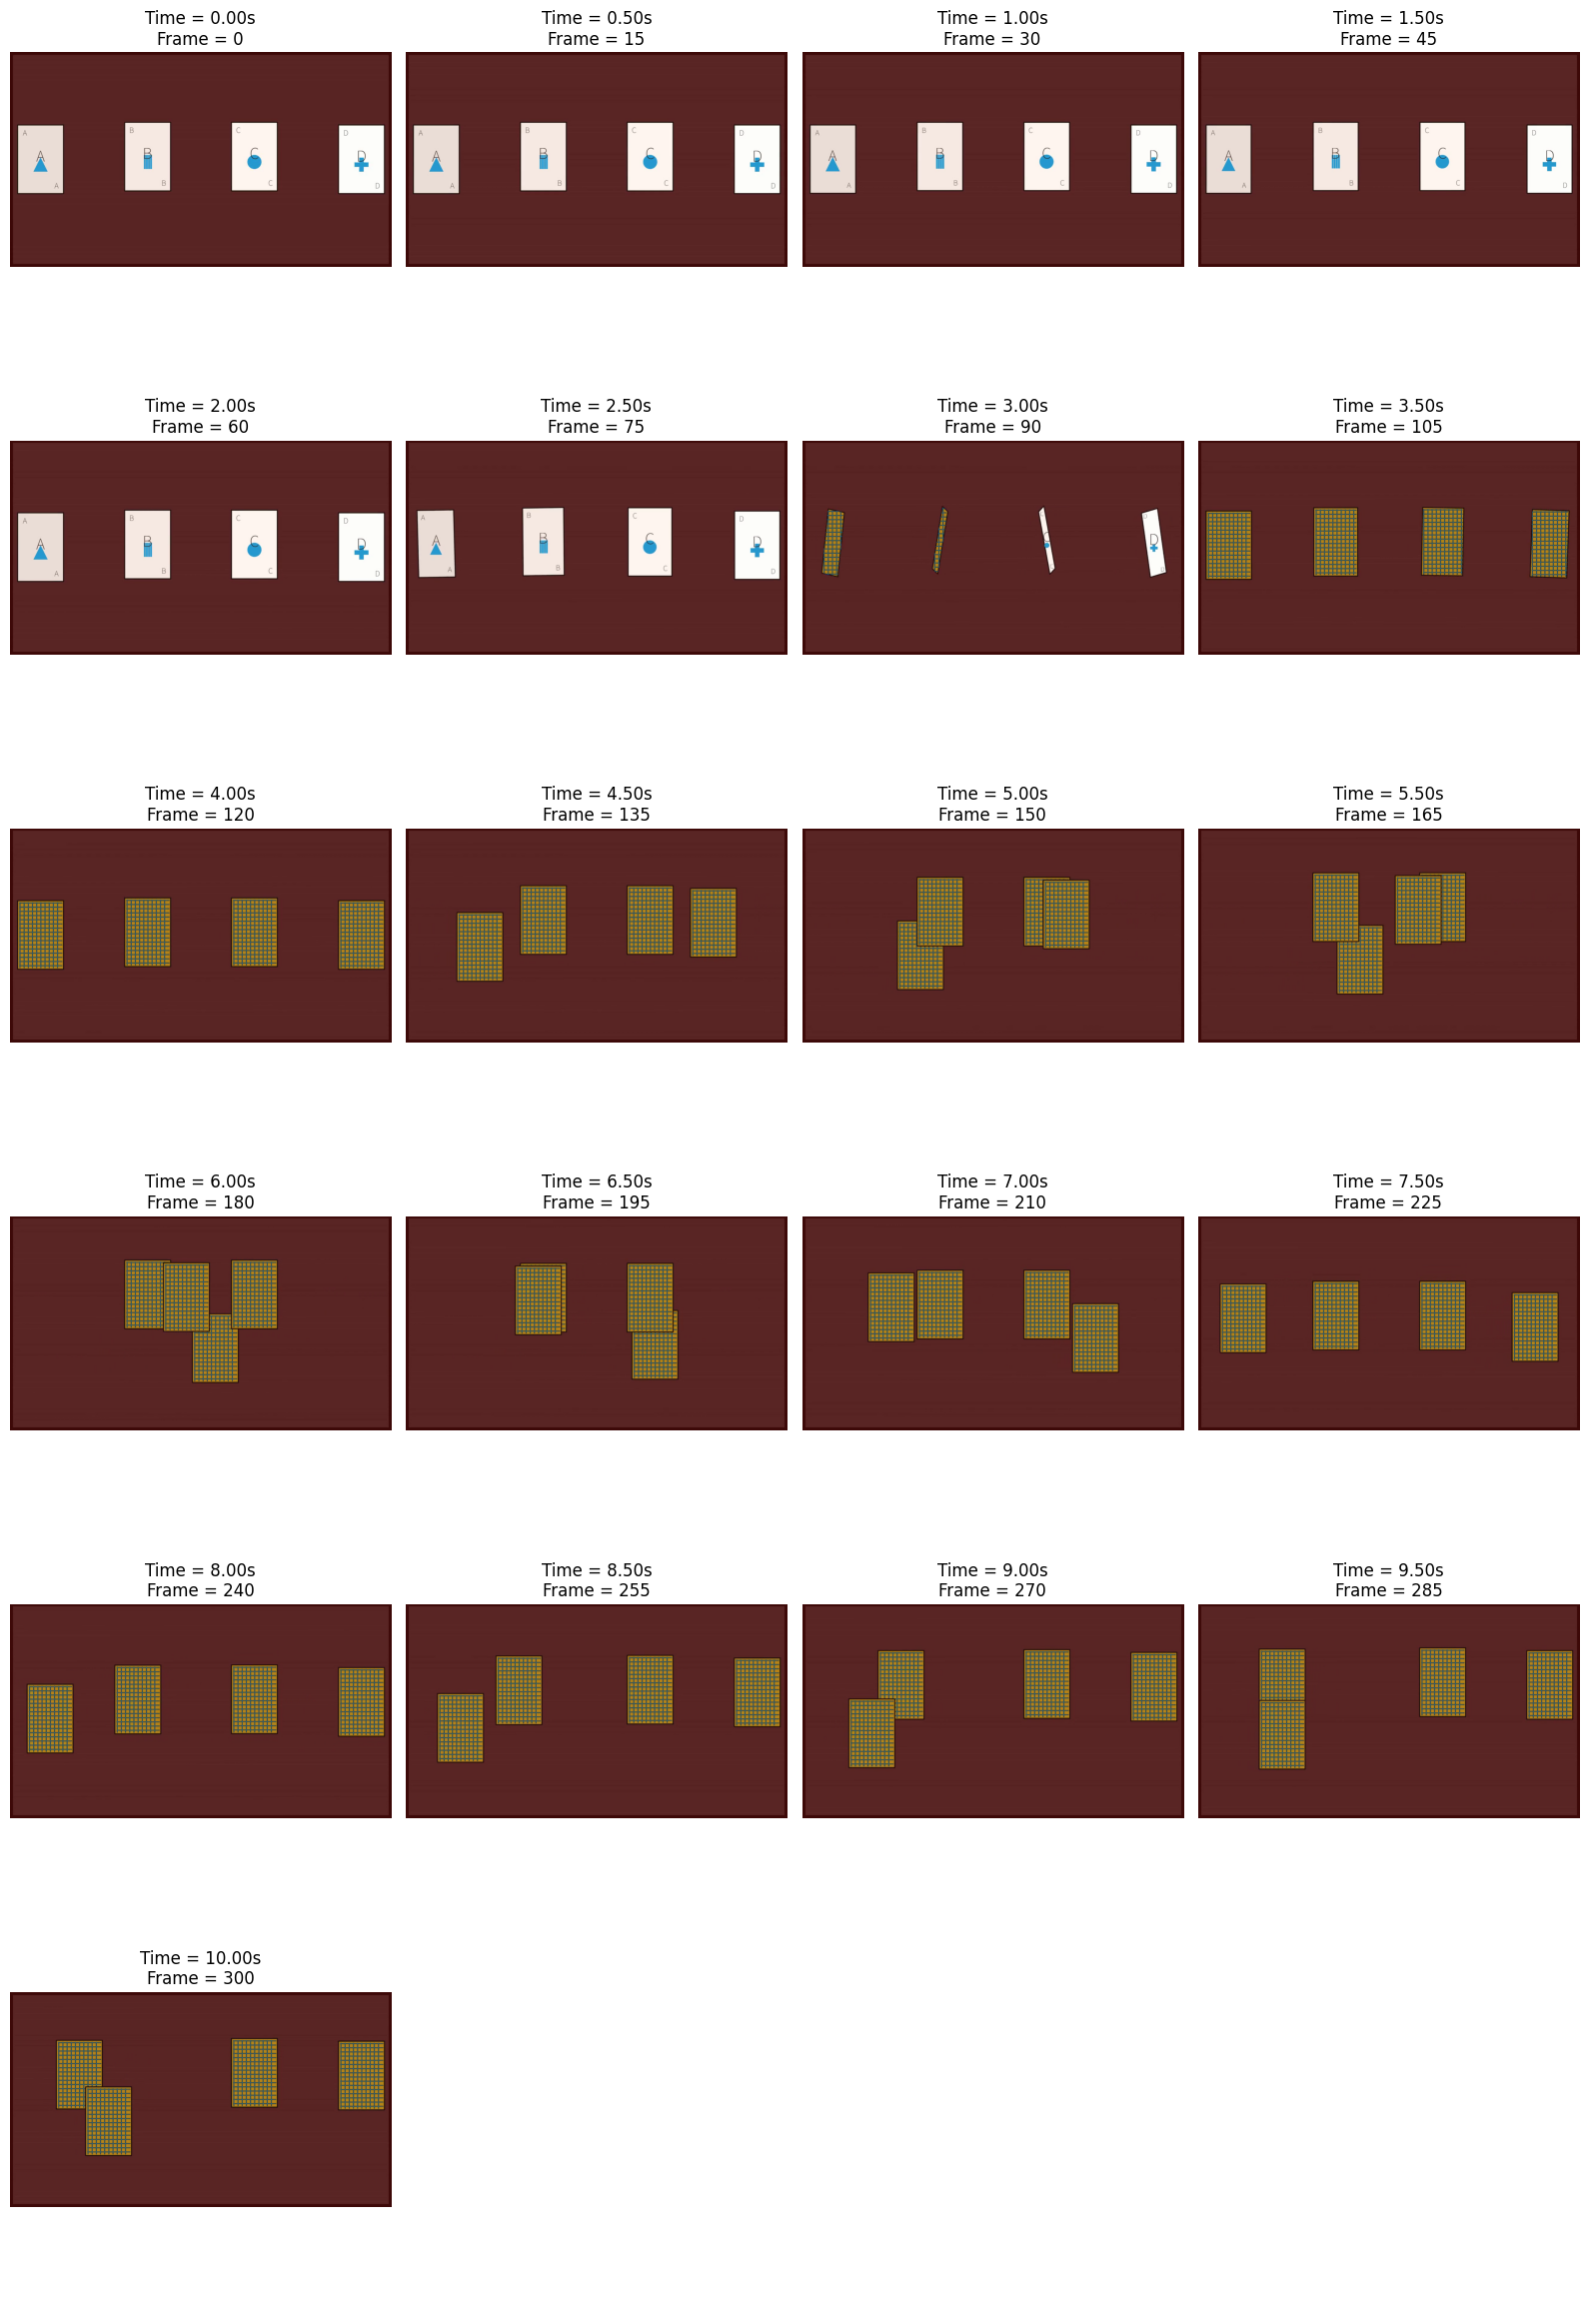

In [ ]:
# ============================================================
# L2b — ROUND 1 TIMING AUDIT
# ============================================================

import os
import cv2
import matplotlib.pyplot as plt

VIDEO_PATH = (
    "/content/videomme_data/"
    "video-mme-logical/videos/card_relocation_s_easy/"
    "card_relocation_s_L1_0001_v3.mp4"
)

# ------------------------------------------------------------
# CHECK VIDEO
# ------------------------------------------------------------

if not os.path.exists(VIDEO_PATH):
    raise FileNotFoundError(
        f"Video not found:\n{VIDEO_PATH}"
    )

cap = cv2.VideoCapture(VIDEO_PATH)

if not cap.isOpened():
    raise RuntimeError(
        f"Could not open:\n{VIDEO_PATH}"
    )

fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
duration = frame_count / fps if fps > 0 else 0

cap.release()

print("Video:", VIDEO_PATH)
print("FPS:", fps)
print("Frames:", frame_count)
print("Duration:", round(duration, 2), "seconds")


# ------------------------------------------------------------
# SAMPLE FRAMES
#
# First 10 seconds
# Every 0.5 seconds
# ------------------------------------------------------------

sample_interval = 0.5
max_time = min(10.0, duration)

times = []
t = 0.0

while t <= max_time + 1e-6:
    times.append(round(t, 2))
    t += sample_interval


# ------------------------------------------------------------
# READ FRAMES
# ------------------------------------------------------------

frames = []

cap = cv2.VideoCapture(VIDEO_PATH)

for t in times:

    frame_idx = int(round(t * fps))

    cap.set(
        cv2.CAP_PROP_POS_FRAMES,
        frame_idx
    )

    ok, frame = cap.read()

    if not ok:
        frames.append(None)
        continue

    frame = cv2.cvtColor(
        frame,
        cv2.COLOR_BGR2RGB
    )

    frames.append(frame)

cap.release()


# ------------------------------------------------------------
# DISPLAY
# ------------------------------------------------------------

cols = 4
rows = (len(frames) + cols - 1) // cols

fig, axes = plt.subplots(
    rows,
    cols,
    figsize=(16, rows * 4)
)

axes = axes.flatten()

for i, (t, frame) in enumerate(
    zip(times, frames)
):

    if frame is not None:
        axes[i].imshow(frame)

    axes[i].set_title(
        f"Time = {t:.2f}s\n"
        f"Frame = {int(round(t * fps))}"
    )

    axes[i].axis("off")


for i in range(len(frames), len(axes)):
    axes[i].axis("off")


plt.tight_layout()
plt.show()

FPS: 30.0


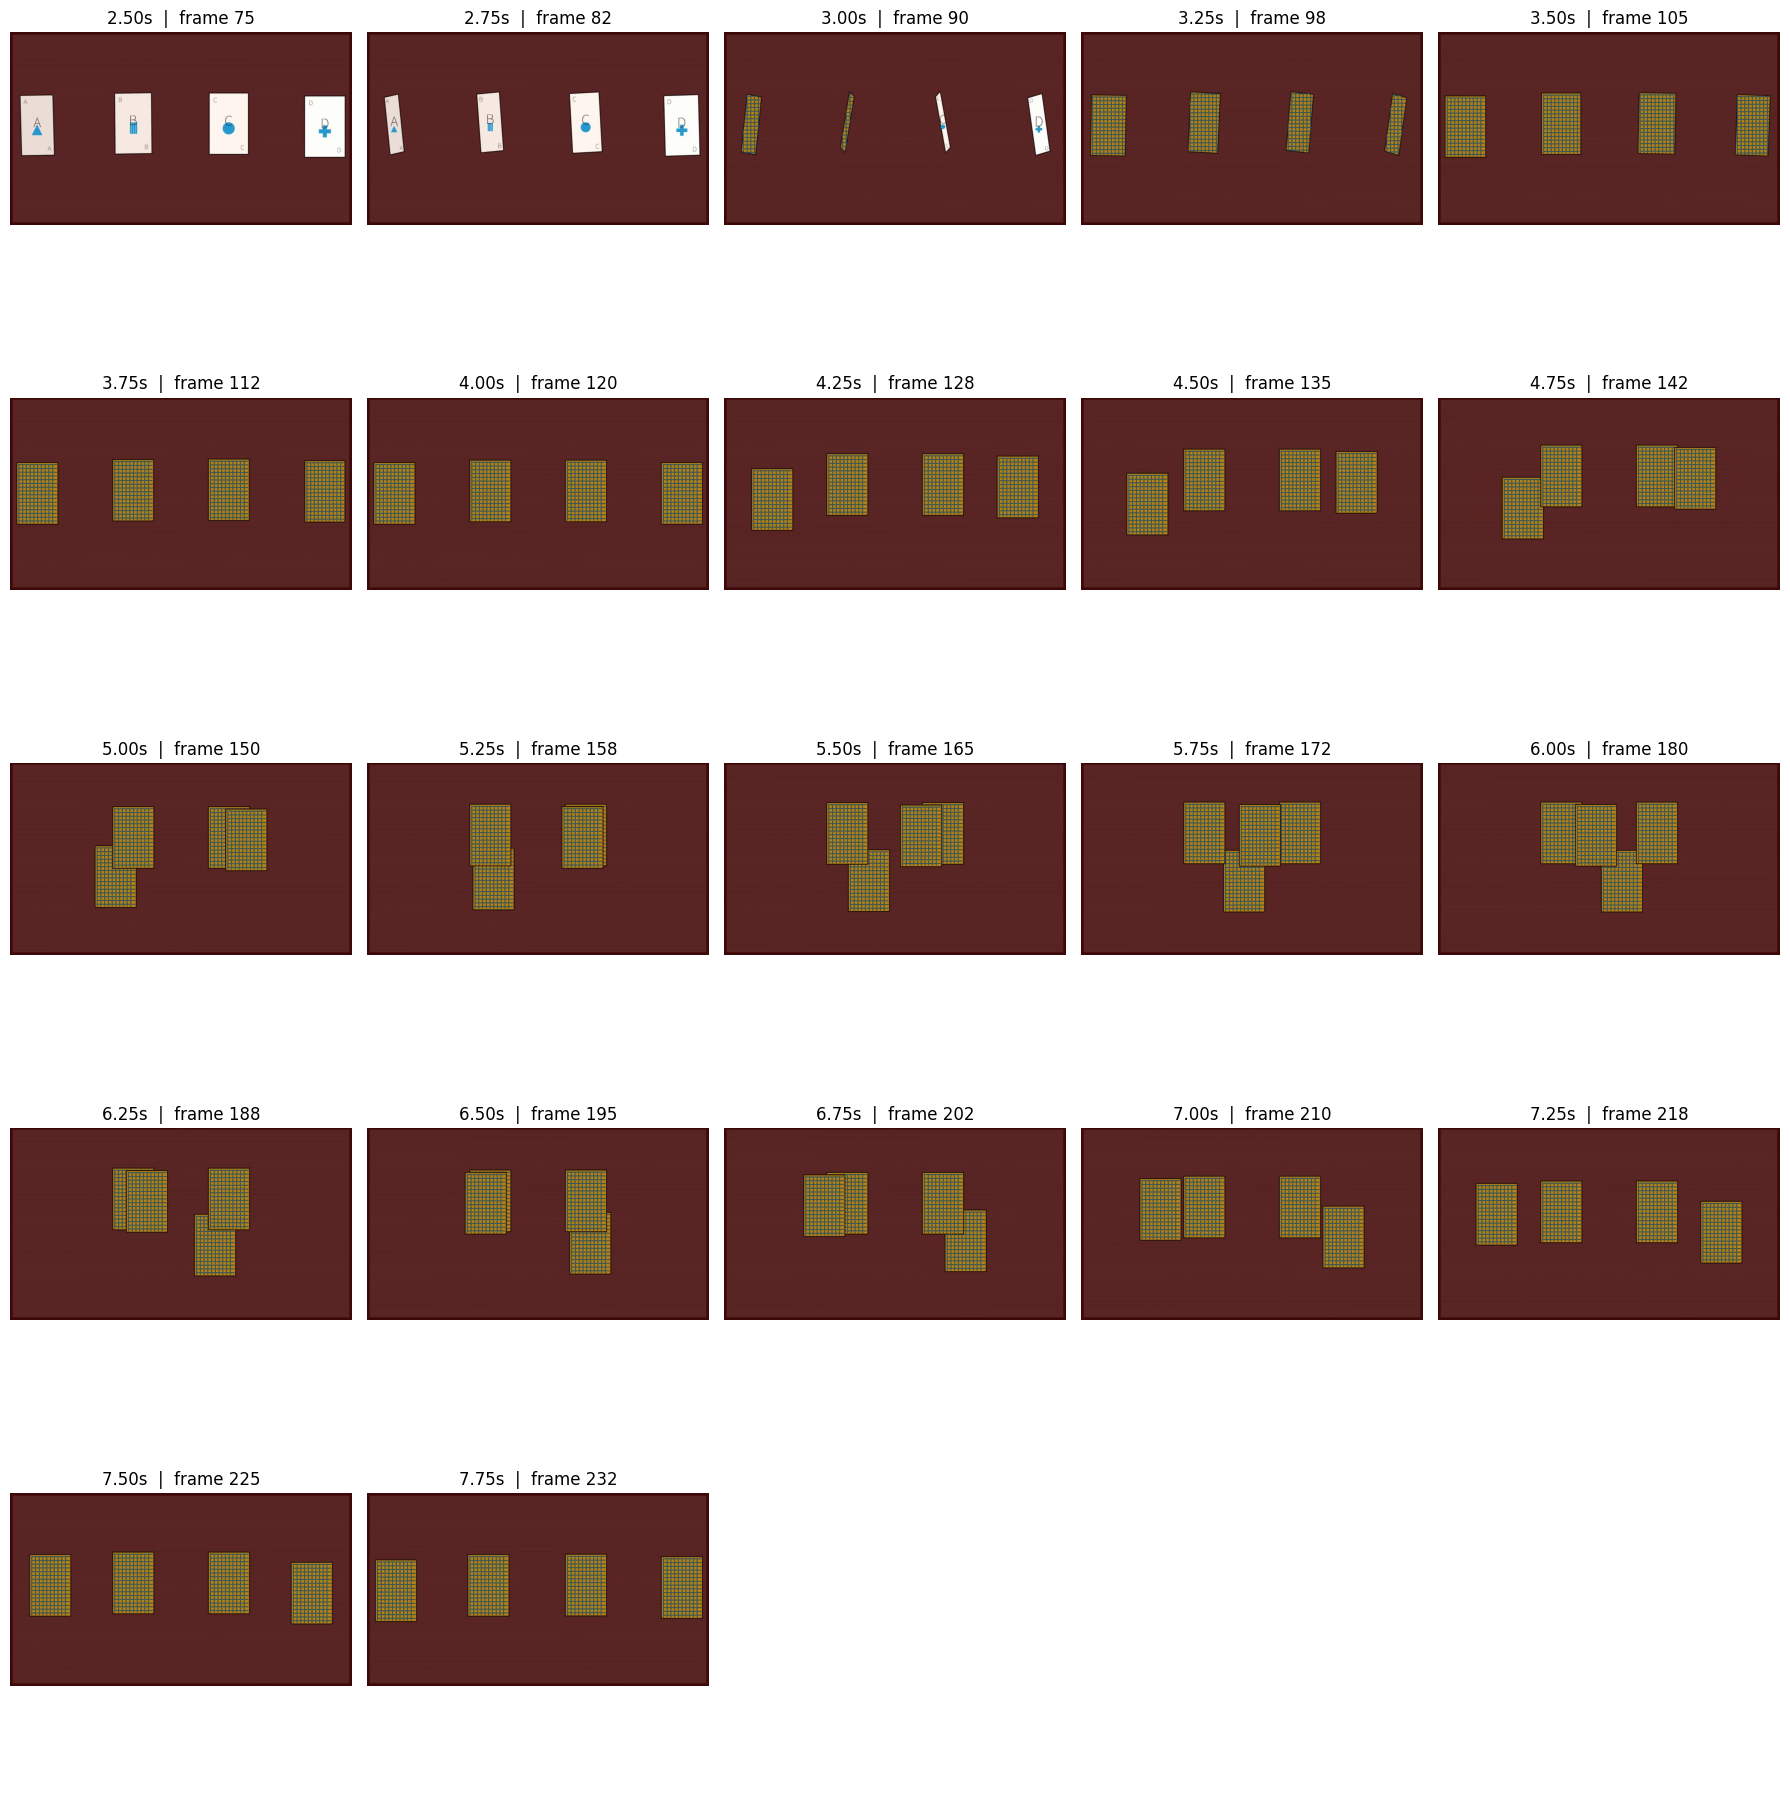

In [ ]:
# ============================================================
# L2b — FINE TIMING AUDIT FOR ROUND 1
# ============================================================

import cv2
import matplotlib.pyplot as plt
import numpy as np

VIDEO_PATH = (
    "/content/videomme_data/"
    "video-mme-logical/videos/card_relocation_s_easy/"
    "card_relocation_s_L1_0001_v3.mp4"
)

START_SEC = 2.50
END_SEC = 7.75
STEP_SEC = 0.25

# ------------------------------------------------------------
# VIDEO INFO
# ------------------------------------------------------------

cap = cv2.VideoCapture(VIDEO_PATH)

fps = cap.get(cv2.CAP_PROP_FPS)
print(f"FPS: {fps}")

times = np.arange(
    START_SEC,
    END_SEC + 1e-6,
    STEP_SEC
)

frames = []

for t in times:

    frame_idx = int(round(t * fps))

    cap.set(
        cv2.CAP_PROP_POS_FRAMES,
        frame_idx
    )

    ok, frame = cap.read()

    if ok:
        frame = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2RGB
        )
        frames.append(frame)
    else:
        frames.append(None)

cap.release()

# ------------------------------------------------------------
# DISPLAY
# ------------------------------------------------------------

cols = 5
rows = int(np.ceil(len(frames) / cols))

fig, axes = plt.subplots(
    rows,
    cols,
    figsize=(18, rows * 3.8)
)

axes = np.array(axes).reshape(-1)

for i, (t, frame) in enumerate(zip(times, frames)):

    ax = axes[i]

    if frame is not None:
        ax.imshow(frame)

    ax.set_title(
        f"{t:.2f}s  |  frame {int(round(t * fps))}"
    )

    ax.axis("off")

for i in range(len(frames), len(axes)):
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# RECREATE THE MISSING GROUND-TRUTH MANIFEST
# ============================================================

import os
import json
from pathlib import Path

DATA_ROOT = "/content/videomme_data"

OUT_DIR = (
    "/content/drive/MyDrive/"
    "videomme_experiments/ground_truth"
)

OUT_PATH = os.path.join(
    OUT_DIR,
    "card_relocation_L1_0001_0050_raw_manifest_records.json"
)

os.makedirs(OUT_DIR, exist_ok=True)


# ------------------------------------------------------------
# FIND JSON FILES IN EXTRACTED DATASET
# ------------------------------------------------------------

json_files = list(
    Path(DATA_ROOT).rglob("*.json")
)

print("JSON files found:", len(json_files))

for p in json_files[:20]:
    print(p)


# ------------------------------------------------------------
# FIND THE DATASET JSON CONTAINING THE 3750 EXAMPLES
# ------------------------------------------------------------

dataset_data = None
dataset_path = None

for path in json_files:

    try:

        with open(path, "r", encoding="utf-8") as f:
            obj = json.load(f)

        if isinstance(obj, list) and len(obj) > 1000:

            # Check whether it looks like Video-MME-Logical data
            if (
                isinstance(obj[0], dict)
                and "id" in obj[0]
                and "question" in obj[0]
                and "answer" in obj[0]
            ):

                dataset_data = obj
                dataset_path = str(path)

                print(
                    "\nFOUND DATASET:"
                )
                print(dataset_path)
                print("Examples:", len(dataset_data))

                break

    except Exception:
        continue


if dataset_data is None:
    raise FileNotFoundError(
        "Could not locate the main Video-MME-Logical JSON dataset "
        "inside /content/videomme_data"
    )


# ------------------------------------------------------------
# FILTER CARD RELOCATION EASY
# ------------------------------------------------------------

cards_easy = [
    item
    for item in dataset_data
    if item.get("major") == "card_relocation_s_easy"
    or item.get("parent_major") == "card_relocation_s_easy"
]

print(
    "\nCard relocation easy examples:",
    len(cards_easy)
)


if len(cards_easy) != 50:

    print("\nWARNING: expected 50 examples.")
    print("Found:", len(cards_easy))

    # Show majors present
    majors = sorted(
        set(
            str(x.get("major"))
            for x in dataset_data
        )
    )

    print("\nAvailable major values:")
    for m in majors:
        print(m)


# ------------------------------------------------------------
# SORT BY VIDEO ID
# ------------------------------------------------------------

cards_easy = sorted(
    cards_easy,
    key=lambda x: x["id"]
)


# ------------------------------------------------------------
# CREATE RAW MANIFEST
# Keep the original record structure:
# id / question / answer
# ------------------------------------------------------------

manifest = []

for item in cards_easy:

    manifest.append({
        "id": item["id"],
        "question": item["question"],
        "answer": item["answer"]
    })


# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

with open(OUT_PATH, "w", encoding="utf-8") as f:

    json.dump(
        manifest,
        f,
        indent=2,
        ensure_ascii=False
    )


# ------------------------------------------------------------
# VALIDATE
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("GROUND TRUTH MANIFEST CREATED")
print("=" * 60)

print("Output:")
print(OUT_PATH)

print("Records:", len(manifest))

if manifest:

    first = manifest[0]

    answer = json.loads(
        first["answer"]
    )

    print("\nFirst record:")
    print("ID:", first["id"])

    print(
        "Target:",
        answer["target_card"]
    )

    print(
        "Initial:",
        answer["initial_position"]
    )

    print(
        "Round 1 position:",
        answer["position_trace"]["1"]
    )

    print(
        "Round 1 move:",
        answer["move_trace"]["1"]
    )

    print(
        "Move count:",
        answer["move_count"]
    )

JSON files found: 1
/content/videomme_data/video-mme-logical/three_level_testset.json

FOUND DATASET:
/content/videomme_data/video-mme-logical/three_level_testset.json
Examples: 3750

Card relocation easy examples: 50

GROUND TRUTH MANIFEST CREATED
Output:
/content/drive/MyDrive/videomme_experiments/ground_truth/card_relocation_L1_0001_0050_raw_manifest_records.json
Records: 50

First record:
ID: card_relocation_s_L1_0001_v3
Target: D
Initial: D
Round 1 position: A
Round 1 move: 1
Move count: 4


In [ ]:
# ============================================================
# L2b — ONE ACTUAL VISUAL SWAP
# Qwen2.5-VL-3B-Instruct
#
# Input:
#   Round-1 visual transition
#   Oracle initial position of target card
#
# Output:
#   did_target_move
#   position_after_round
#
# Resume-safe: saves after every video
# ============================================================

import os
import json
import re
import time
import torch
from collections import Counter

from transformers import (
    Qwen2_5_VLForConditionalGeneration,
    AutoProcessor
)
from qwen_vl_utils import process_vision_info


# ============================================================
# PATHS
# ============================================================

VIDEO_ROOT = (
    "/content/videomme_data/"
    "video-mme-logical/videos/card_relocation_s_easy"
)

GT_PATH = (
    "/content/drive/MyDrive/videomme_experiments/"
    "ground_truth/card_relocation_L1_0001_0050_raw_manifest_records.json"
)

OUT_DIR = (
    "/content/drive/MyDrive/videomme_experiments/l2b"
)

os.makedirs(OUT_DIR, exist_ok=True)

OUT_PATH = os.path.join(
    OUT_DIR,
    "l2b_round1_one_swap_results.json"
)


# ============================================================
# ROUND 1 TIMING
# Based on the visual audit of video 1
# ============================================================

ROUND1_START_SEC = 2.50
ROUND1_END_SEC = 7.50

VIDEO_FPS = 2.0
MAX_PIXELS = 336 * 336


# ============================================================
# LOAD MODEL
# ============================================================

MODEL_NAME = "Qwen/Qwen2.5-VL-3B-Instruct"

print("=" * 70)
print("LOADING MODEL")
print("=" * 70)

model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_NAME,
    torch_dtype="auto",
    device_map="auto"
)

processor = AutoProcessor.from_pretrained(
    MODEL_NAME
)

print("Model loaded.")
print("Device:", model.device)


# ============================================================
# LOAD GROUND TRUTH
# ============================================================

if not os.path.exists(GT_PATH):
    raise FileNotFoundError(
        f"\nGT file not found:\n{GT_PATH}\n"
        "Run the GT-manifest recreation cell first."
    )

with open(GT_PATH, "r", encoding="utf-8") as f:
    gt_records = json.load(f)

print("GT records:", len(gt_records))

if len(gt_records) != 50:
    print(
        "WARNING: expected 50 GT records, "
        f"but found {len(gt_records)}"
    )


# ============================================================
# LOAD PREVIOUS RESULTS FOR RESUME
# ============================================================

if os.path.exists(OUT_PATH):

    with open(OUT_PATH, "r", encoding="utf-8") as f:
        results = json.load(f)

    print(
        f"Existing L2b results: {len(results)}"
    )

else:

    results = []

    print("No existing L2b results. Starting fresh.")


completed_ids = {
    r["id"]
    for r in results
    if "id" in r
}


# ============================================================
# JSON EXTRACTION
# ============================================================

def extract_json(text):

    if not text:
        return None

    text = text.strip()

    # Remove <answer> tags if present
    text = re.sub(
        r"</?answer>",
        "",
        text,
        flags=re.IGNORECASE
    ).strip()

    # Try fenced JSON
    match = re.search(
        r"```json\s*(\{.*?\})\s*```",
        text,
        re.DOTALL | re.IGNORECASE
    )

    if match:
        text = match.group(1)

    else:

        # Try any JSON object
        match = re.search(
            r"\{.*\}",
            text,
            re.DOTALL
        )

        if match:
            text = match.group(0)

    try:
        return json.loads(text)

    except Exception:
        return None


# ============================================================
# NORMALIZE ANSWER
# ============================================================

def normalize_answer(obj):

    if not isinstance(obj, dict):
        return None

    moved = obj.get("did_target_move")
    position = obj.get("position_after_round")

    # ----------------------------
    # Normalize move
    # ----------------------------

    if isinstance(moved, bool):
        pass

    elif isinstance(moved, (int, float)):

        if moved == 1:
            moved = True
        elif moved == 0:
            moved = False
        else:
            moved = None

    elif isinstance(moved, str):

        value = moved.strip().lower()

        if value in [
            "yes",
            "true",
            "1",
            "moved"
        ]:
            moved = True

        elif value in [
            "no",
            "false",
            "0",
            "did not move",
            "not moved"
        ]:
            moved = False

        else:
            moved = None

    else:
        moved = None

    # ----------------------------
    # Normalize position
    # ----------------------------

    if isinstance(position, str):

        position = position.strip().upper()

        if position not in ["A", "B", "C", "D"]:
            position = None

    else:
        position = None

    return {
        "did_target_move": moved,
        "position_after_round": position
    }


# ============================================================
# PROMPT
# ============================================================

def make_prompt(target_card, initial_position):

    return f"""
You are tracking one specific card through a short video.

Target card: {target_card}
Position of the target card BEFORE this round: {initial_position}

The video clip contains exactly ONE card-relocation round.

Watch the target card throughout the movement and determine
where that same card ends up after the round.

Answer ONLY with this JSON format:

{{
  "did_target_move": true,
  "position_after_round": "A"
}}

Rules:

1. "did_target_move" is true if the target card changes
   screen position during this round.
2. "did_target_move" is false if it remains in the same
   screen position.
3. "position_after_round" must be exactly one of:
   A, B, C, D.
4. A/B/C/D are FIXED SCREEN POSITIONS from left to right.
5. Track the TARGET CARD, not the card occupying a position.
6. Do not explain your answer.
7. Output ONLY the JSON object.
""".strip()


# ============================================================
# RUN ONE VIDEO
# ============================================================

def run_video(
    video_path,
    target_card,
    initial_position
):

    prompt = make_prompt(
        target_card,
        initial_position
    )

    messages = [
        {
            "role": "user",
            "content": [
                {
                    "type": "video",
                    "video": video_path,
                    "fps": VIDEO_FPS,
                    "max_pixels": MAX_PIXELS,
                    "start_time": ROUND1_START_SEC,
                    "end_time": ROUND1_END_SEC,
                },
                {
                    "type": "text",
                    "text": prompt
                }
            ]
        }
    ]

    # --------------------------------------------------------
    # Apply Qwen chat template
    # --------------------------------------------------------

    text = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    # --------------------------------------------------------
    # Process video
    # --------------------------------------------------------

    image_inputs, video_inputs = process_vision_info(
        messages
    )

    inputs = processor(
        text=[text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    )

    inputs = inputs.to(model.device)

    # --------------------------------------------------------
    # Generate
    # --------------------------------------------------------

    with torch.no_grad():

        generated_ids = model.generate(
            **inputs,
            max_new_tokens=64
        )

    # Remove prompt tokens
    generated_ids_trimmed = [
        out_ids[len(in_ids):]
        for in_ids, out_ids
        in zip(
            inputs.input_ids,
            generated_ids
        )
    ]

    output_text = processor.batch_decode(
        generated_ids_trimmed,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False
    )[0]

    parsed = extract_json(output_text)

    prediction = normalize_answer(parsed)

    return {
        "raw_output": output_text,
        "parsed_output": parsed,
        "prediction": prediction
    }


# ============================================================
# MAIN LOOP
# ============================================================

print("\n" + "=" * 70)
print("STARTING L2b")
print("=" * 70)

print(
    f"Round window: "
    f"{ROUND1_START_SEC:.2f}s -> "
    f"{ROUND1_END_SEC:.2f}s"
)

print(
    f"Video FPS: {VIDEO_FPS}"
)

print(
    f"Max pixels: {MAX_PIXELS}"
)


for idx, gt in enumerate(gt_records):

    video_id = gt["id"]

    # --------------------------------------------------------
    # RESUME
    # --------------------------------------------------------

    if video_id in completed_ids:

        print(
            f"[{idx + 1}/{len(gt_records)}] "
            f"SKIP {video_id}"
        )

        continue


    # --------------------------------------------------------
    # PARSE GT
    # --------------------------------------------------------

    answer = json.loads(gt["answer"])

    target_card = answer["target_card"]

    initial_position = answer["initial_position"]

    gt_position = answer["position_trace"]["1"]

    gt_move = bool(
        int(answer["move_trace"]["1"])
    )


    # --------------------------------------------------------
    # VIDEO PATH
    # --------------------------------------------------------

    video_path = os.path.join(
        VIDEO_ROOT,
        video_id + ".mp4"
    )

    print("\n" + "=" * 70)

    print(
        f"[{idx + 1}/{len(gt_records)}] "
        f"{video_id}"
    )

    print(
        "GT:",
        f"target={target_card}",
        f"| initial={initial_position}",
        f"| move={gt_move}",
        f"| final={gt_position}"
    )

    if not os.path.exists(video_path):

        print("VIDEO NOT FOUND")

        record = {
            "id": video_id,

            "timing": {
                "start_sec": ROUND1_START_SEC,
                "end_sec": ROUND1_END_SEC,
                "fps": VIDEO_FPS,
                "max_pixels": MAX_PIXELS
            },

            "gt": {
                "target_card": target_card,
                "initial_position": initial_position,
                "did_target_move": gt_move,
                "position_after_round": gt_position
            },

            "prediction": None,

            "raw_output": None,

            "parsed_output": None,

            "evaluation": {
                "move_correct": False,
                "position_correct": False,
                "complete_correct": False
            },

            "elapsed_sec": 0,

            "error": "video_not_found"
        }

        results.append(record)

        with open(
            OUT_PATH,
            "w",
            encoding="utf-8"
        ) as f:

            json.dump(
                results,
                f,
                indent=2
            )

        completed_ids.add(video_id)

        continue


    # --------------------------------------------------------
    # RUN INFERENCE
    # --------------------------------------------------------

    start_time = time.time()

    try:

        output = run_video(
            video_path=video_path,
            target_card=target_card,
            initial_position=initial_position
        )

        elapsed = time.time() - start_time

        prediction = output["prediction"]


        # ----------------------------------------------------
        # EVALUATION
        # ----------------------------------------------------

        move_correct = (
            prediction is not None
            and prediction["did_target_move"] == gt_move
        )

        position_correct = (
            prediction is not None
            and prediction["position_after_round"]
            == gt_position
        )

        complete_correct = (
            move_correct
            and position_correct
        )


        # ----------------------------------------------------
        # RESULT RECORD
        # ----------------------------------------------------

        record = {

            "id": video_id,

            "timing": {
                "start_sec": ROUND1_START_SEC,
                "end_sec": ROUND1_END_SEC,
                "fps": VIDEO_FPS,
                "max_pixels": MAX_PIXELS
            },

            "gt": {
                "target_card": target_card,
                "initial_position": initial_position,
                "did_target_move": gt_move,
                "position_after_round": gt_position
            },

            "prediction": prediction,

            "raw_output": output["raw_output"],

            "parsed_output": output["parsed_output"],

            "evaluation": {
                "move_correct": move_correct,
                "position_correct": position_correct,
                "complete_correct": complete_correct
            },

            "elapsed_sec": elapsed,

            "error": None
        }


        # ----------------------------------------------------
        # PRINT
        # ----------------------------------------------------

        print(
            "Prediction:",
            prediction
        )

        print(
            "Move correct:",
            move_correct
        )

        print(
            "Position correct:",
            position_correct
        )

        print(
            "Complete:",
            complete_correct
        )

        print(
            f"Time: {elapsed:.2f}s"
        )


    except Exception as e:

        elapsed = time.time() - start_time

        print(
            "ERROR:",
            repr(e)
        )

        record = {

            "id": video_id,

            "timing": {
                "start_sec": ROUND1_START_SEC,
                "end_sec": ROUND1_END_SEC,
                "fps": VIDEO_FPS,
                "max_pixels": MAX_PIXELS
            },

            "gt": {
                "target_card": target_card,
                "initial_position": initial_position,
                "did_target_move": gt_move,
                "position_after_round": gt_position
            },

            "prediction": None,

            "raw_output": None,

            "parsed_output": None,

            "evaluation": {
                "move_correct": False,
                "position_correct": False,
                "complete_correct": False
            },

            "elapsed_sec": elapsed,

            "error": repr(e)
        }


    # ========================================================
    # SAVE AFTER EVERY VIDEO
    # ========================================================

    results.append(record)

    with open(
        OUT_PATH,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            results,
            f,
            indent=2
        )

    completed_ids.add(video_id)

    print(
        "SAVED:",
        OUT_PATH
    )


# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("L2b COMPLETE")
print("=" * 70)

valid = [
    r
    for r in results
    if r.get("error") is None
    and r.get("prediction") is not None
]

print(
    "Total records:",
    len(results)
)

print(
    "Valid:",
    len(valid)
)

print(
    "Errors:",
    len(results) - len(valid)
)


if valid:

    move_correct = sum(
        r["evaluation"]["move_correct"]
        for r in valid
    )

    position_correct = sum(
        r["evaluation"]["position_correct"]
        for r in valid
    )

    complete_correct = sum(
        r["evaluation"]["complete_correct"]
        for r in valid
    )

    n = len(valid)

    print(
        f"\nMove accuracy: "
        f"{move_correct}/{n} "
        f"= {move_correct / n:.4f}"
    )

    print(
        f"Position accuracy: "
        f"{position_correct}/{n} "
        f"= {position_correct / n:.4f}"
    )

    print(
        f"Complete accuracy: "
        f"{complete_correct}/{n} "
        f"= {complete_correct / n:.4f}"
    )


    # --------------------------------------------------------
    # POSITION DISTRIBUTION
    # --------------------------------------------------------

    predicted_positions = [
        r["prediction"]["position_after_round"]
        for r in valid
        if r["prediction"] is not None
        and r["prediction"]["position_after_round"]
        is not None
    ]

    print(
        "\nPredicted position distribution:"
    )

    print(
        Counter(predicted_positions)
    )


    # --------------------------------------------------------
    # MOVE DISTRIBUTION
    # --------------------------------------------------------

    predicted_moves = [
        r["prediction"]["did_target_move"]
        for r in valid
        if r["prediction"] is not None
        and r["prediction"]["did_target_move"]
        is not None
    ]

    print(
        "\nPredicted move distribution:"
    )

    print(
        Counter(predicted_moves)
    )


print(
    "\nResults saved to:"
)

print(
    OUT_PATH
)

LOADING MODEL


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

Model loaded.
Device: cuda:0
GT records: 50
No existing L2b results. Starting fresh.

STARTING L2b
Round window: 2.50s -> 7.50s
Video FPS: 2.0
Max pixels: 112896

[1/50] card_relocation_s_L1_0001_v3
GT: target=D | initial=D | move=True | final=A


qwen-vl-utils using torchcodec to read video.
[transformers] Qwen2VL video processing does not apply the per-frame pixel cap the reference implementation (qwen-vl-utils) applies, so some videos cost far more tokens than they would there. In v5.22 the capped behavior will become the default and `cap_pixels_per_frame` will be removed. Pass `cap_pixels_per_frame=True` to adopt the reference behavior now, or `False` to keep the current behavior and silence this warning.


ERROR: OutOfMemoryError('CUDA out of memory. Tried to allocate 958.00 MiB. GPU 0 has a total capacity of 14.56 GiB of which 387.81 MiB is free. Including non-PyTorch memory, this process has 14.18 GiB memory in use. Of the allocated memory 13.91 GiB is allocated by PyTorch, and 145.51 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)')
SAVED: /content/drive/MyDrive/videomme_experiments/l2b/l2b_round1_one_swap_results.json

[2/50] card_relocation_s_L1_0002_v3
GT: target=D | initial=D | move=False | final=D
ERROR: OutOfMemoryError('CUDA out of memory. Tried to allocate 74.00 MiB. GPU 0 has a total capacity of 14.56 GiB of which 45.81 MiB is free. Including non-PyTorch memory, this process has 14.52 GiB memory in use. Of

In [ ]:
# ============================================================
# L2b LOW-MEMORY VERSION
#
# Fix:
#   1. Physically resize video to 224x224
#   2. Extract only 1 FPS
#   3. Keep only Round-1 clip (2.5s -> 7.5s)
#   4. Feed the small clip to Qwen
#
# This avoids the Transformers per-frame pixel-cap issue.
# ============================================================

import os
import json
import re
import gc
import time
import cv2
import torch

from collections import Counter
from pathlib import Path

from transformers import (
    Qwen2_5_VLForConditionalGeneration,
    AutoProcessor
)

from qwen_vl_utils import process_vision_info


# ============================================================
# PATHS
# ============================================================

VIDEO_ROOT = (
    "/content/videomme_data/"
    "video-mme-logical/videos/card_relocation_s_easy"
)

GT_PATH = (
    "/content/drive/MyDrive/videomme_experiments/"
    "ground_truth/card_relocation_L1_0001_0050_raw_manifest_records.json"
)

CLIP_DIR = (
    "/content/l2b_lowmem_clips"
)

OUT_DIR = (
    "/content/drive/MyDrive/videomme_experiments/l2b"
)

os.makedirs(CLIP_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)


# ============================================================
# NEW OUTPUT FILE
# Do NOT use the previous all-error file.
# ============================================================

OUT_PATH = os.path.join(
    OUT_DIR,
    "l2b_round1_lowmem_results.json"
)


# ============================================================
# SETTINGS
# ============================================================

ROUND1_START_SEC = 2.50
ROUND1_END_SEC = 7.50

# Original videos are ~30 FPS.
# We only keep one frame per second.
TARGET_FPS = 1.0

# Physically resize before Qwen sees the video.
TARGET_SIZE = 224

# Very short generation.
MAX_NEW_TOKENS = 64


# ============================================================
# GPU CLEANUP
# ============================================================

print("=" * 70)
print("GPU CLEANUP")
print("=" * 70)

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

    print(
        "GPU allocated:",
        round(
            torch.cuda.memory_allocated() / 1e9,
            3
        ),
        "GB"
    )

    print(
        "GPU reserved:",
        round(
            torch.cuda.memory_reserved() / 1e9,
            3
        ),
        "GB"
    )


# ============================================================
# LOAD MODEL ONLY IF NOT ALREADY LOADED
# ============================================================

MODEL_NAME = "Qwen/Qwen2.5-VL-3B-Instruct"

if "model" not in globals():

    print("\nLoading model...")

    model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
        MODEL_NAME,
        torch_dtype=torch.float16,
        device_map="auto"
    )

    processor = AutoProcessor.from_pretrained(
        MODEL_NAME
    )

    print("Model loaded.")

else:

    print("\nUsing already-loaded model.")


print("Device:", model.device)


# ============================================================
# LOAD GT
# ============================================================

with open(
    GT_PATH,
    "r",
    encoding="utf-8"
) as f:

    gt_records = json.load(f)

print(
    "GT records:",
    len(gt_records)
)


# ============================================================
# CREATE LOW-RESOLUTION CLIP
# ============================================================

def create_lowres_clip(
    input_path,
    output_path,
    start_sec,
    end_sec
):

    cap = cv2.VideoCapture(input_path)

    if not cap.isOpened():
        raise RuntimeError(
            f"Could not open:\n{input_path}"
        )

    source_fps = cap.get(
        cv2.CAP_PROP_FPS
    )

    total_frames = int(
        cap.get(
            cv2.CAP_PROP_FRAME_COUNT
        )
    )

    duration = (
        total_frames / source_fps
        if source_fps > 0
        else 0
    )

    # ---------------------------------------------
    # Clamp interval
    # ---------------------------------------------

    start_sec = max(
        0,
        min(start_sec, duration)
    )

    end_sec = max(
        start_sec,
        min(end_sec, duration)
    )

    start_frame = int(
        round(start_sec * source_fps)
    )

    end_frame = int(
        round(end_sec * source_fps)
    )

    # ---------------------------------------------
    # We physically create 1 FPS clip.
    # ---------------------------------------------

    fourcc = cv2.VideoWriter_fourcc(
        *"mp4v"
    )

    writer = cv2.VideoWriter(
        output_path,
        fourcc,
        TARGET_FPS,
        (TARGET_SIZE, TARGET_SIZE)
    )

    if not writer.isOpened():
        cap.release()

        raise RuntimeError(
            f"Could not create:\n{output_path}"
        )

    # Frame interval corresponding to 1 FPS
    frame_step = max(
        1,
        int(round(source_fps / TARGET_FPS))
    )

    frames_written = 0

    frame_idx = start_frame

    while frame_idx <= end_frame:

        cap.set(
            cv2.CAP_PROP_POS_FRAMES,
            frame_idx
        )

        ok, frame = cap.read()

        if not ok:
            break

        # -----------------------------------------
        # Preserve aspect ratio
        # and letterbox to 224x224
        # -----------------------------------------

        h, w = frame.shape[:2]

        scale = min(
            TARGET_SIZE / w,
            TARGET_SIZE / h
        )

        new_w = int(
            round(w * scale)
        )

        new_h = int(
            round(h * scale)
        )

        resized = cv2.resize(
            frame,
            (new_w, new_h),
            interpolation=cv2.INTER_AREA
        )

        canvas = (
            30 *
            torch.ones(
                (
                    TARGET_SIZE,
                    TARGET_SIZE,
                    3
                ),
                dtype=torch.uint8
            ).numpy()
        )

        y0 = (
            TARGET_SIZE - new_h
        ) // 2

        x0 = (
            TARGET_SIZE - new_w
        ) // 2

        canvas[
            y0:y0 + new_h,
            x0:x0 + new_w
        ] = resized

        writer.write(canvas)

        frames_written += 1

        frame_idx += frame_step

    cap.release()
    writer.release()

    if frames_written == 0:

        raise RuntimeError(
            f"No frames written for:\n{input_path}"
        )

    return {
        "source_fps": source_fps,
        "source_duration": duration,
        "frames_written": frames_written
    }


# ============================================================
# JSON EXTRACTION
# ============================================================

def extract_json(text):

    if not text:
        return None

    text = text.strip()

    text = re.sub(
        r"</?answer>",
        "",
        text,
        flags=re.IGNORECASE
    ).strip()

    match = re.search(
        r"```json\s*(\{.*?\})\s*```",
        text,
        re.DOTALL | re.IGNORECASE
    )

    if match:
        text = match.group(1)

    else:

        match = re.search(
            r"\{.*\}",
            text,
            re.DOTALL
        )

        if match:
            text = match.group(0)

    try:
        return json.loads(text)

    except Exception:
        return None


# ============================================================
# NORMALIZE ANSWER
# ============================================================

def normalize_answer(obj):

    if not isinstance(obj, dict):
        return None

    moved = obj.get(
        "did_target_move"
    )

    position = obj.get(
        "position_after_round"
    )

    # -----------------------------------------
    # movement
    # -----------------------------------------

    if isinstance(moved, bool):
        pass

    elif isinstance(moved, str):

        value = moved.strip().lower()

        if value in [
            "yes",
            "true",
            "1"
        ]:
            moved = True

        elif value in [
            "no",
            "false",
            "0"
        ]:
            moved = False

        else:
            moved = None

    elif isinstance(moved, (int, float)):

        if moved == 1:
            moved = True

        elif moved == 0:
            moved = False

        else:
            moved = None

    else:
        moved = None


    # -----------------------------------------
    # position
    # -----------------------------------------

    if isinstance(position, str):

        position = (
            position
            .strip()
            .upper()
        )

        if position not in [
            "A",
            "B",
            "C",
            "D"
        ]:
            position = None

    else:
        position = None


    return {
        "did_target_move": moved,
        "position_after_round": position
    }


# ============================================================
# PROMPT
# ============================================================

def make_prompt(
    target_card,
    initial_position
):

    return f"""
Track the TARGET CARD through this one card-swap round.

Target card: {target_card}

Before the round, the target card is at:
{initial_position}

A, B, C, D are fixed screen positions from left to right.

Watch the target card through the movement.

Return ONLY:

{{
  "did_target_move": true,
  "position_after_round": "A"
}}

Rules:
- true = target changed position
- false = target stayed in the same position
- final position must be A, B, C, or D
- track the target card itself, not the card currently occupying a position
- output JSON only
""".strip()


# ============================================================
# RUN ONE VIDEO
# ============================================================

def run_video(
    clip_path,
    target_card,
    initial_position
):

    prompt = make_prompt(
        target_card,
        initial_position
    )

    messages = [
        {
            "role": "user",
            "content": [
                {
                    "type": "video",
                    "video": clip_path,
                    "fps": TARGET_FPS,
                },
                {
                    "type": "text",
                    "text": prompt
                }
            ]
        }
    ]

    # -----------------------------------------
    # Qwen template
    # -----------------------------------------

    text = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    # -----------------------------------------
    # Video processing
    # -----------------------------------------

    image_inputs, video_inputs = process_vision_info(
        messages
    )

    inputs = processor(
        text=[text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    )

    inputs = inputs.to(
        model.device
    )

    # -----------------------------------------
    # Generate
    # -----------------------------------------

    with torch.inference_mode():

        generated_ids = model.generate(
            **inputs,
            max_new_tokens=MAX_NEW_TOKENS
        )

    generated_ids_trimmed = [
        out_ids[len(in_ids):]
        for in_ids, out_ids
        in zip(
            inputs.input_ids,
            generated_ids
        )
    ]

    output_text = processor.batch_decode(
        generated_ids_trimmed,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False
    )[0]

    # -----------------------------------------
    # GPU cleanup
    # -----------------------------------------

    del inputs
    del generated_ids
    del generated_ids_trimmed

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    # -----------------------------------------
    # Parse
    # -----------------------------------------

    parsed = extract_json(
        output_text
    )

    prediction = normalize_answer(
        parsed
    )

    return {
        "raw_output": output_text,
        "parsed_output": parsed,
        "prediction": prediction
    }


# ============================================================
# MAIN LOOP
# ============================================================

results = []

print("\n" + "=" * 70)
print("STARTING LOW-MEMORY L2b")
print("=" * 70)

print(
    "Round:",
    ROUND1_START_SEC,
    "->",
    ROUND1_END_SEC
)

print(
    "Clip FPS:",
    TARGET_FPS
)

print(
    "Clip resolution:",
    f"{TARGET_SIZE}x{TARGET_SIZE}"
)


for idx, gt in enumerate(gt_records):

    video_id = gt["id"]

    # -----------------------------------------
    # Ground truth
    # -----------------------------------------

    answer = json.loads(
        gt["answer"]
    )

    target_card = answer[
        "target_card"
    ]

    initial_position = answer[
        "initial_position"
    ]

    gt_position = answer[
        "position_trace"
    ]["1"]

    gt_move = bool(
        int(
            answer["move_trace"]["1"]
        )
    )

    video_path = os.path.join(
        VIDEO_ROOT,
        video_id + ".mp4"
    )

    clip_path = os.path.join(
        CLIP_DIR,
        video_id + "_r1_lowres.mp4"
    )

    print("\n" + "=" * 70)

    print(
        f"[{idx + 1}/{len(gt_records)}] "
        f"{video_id}"
    )

    print(
        "GT:",
        f"target={target_card}",
        f"| initial={initial_position}",
        f"| move={gt_move}",
        f"| final={gt_position}"
    )


    # -----------------------------------------
    # Create clip
    # -----------------------------------------

    try:

        clip_info = create_lowres_clip(
            input_path=video_path,
            output_path=clip_path,
            start_sec=ROUND1_START_SEC,
            end_sec=ROUND1_END_SEC
        )

        print(
            "Low-res clip:",
            clip_info
        )


    except Exception as e:

        print(
            "CLIP CREATION ERROR:",
            repr(e)
        )

        record = {
            "id": video_id,
            "gt": {
                "target_card": target_card,
                "initial_position": initial_position,
                "did_target_move": gt_move,
                "position_after_round": gt_position
            },
            "prediction": None,
            "error": (
                "clip_creation_error: "
                + repr(e)
            )
        }

        results.append(record)

        with open(
            OUT_PATH,
            "w",
            encoding="utf-8"
        ) as f:

            json.dump(
                results,
                f,
                indent=2
            )

        continue


    # -----------------------------------------
    # Inference
    # -----------------------------------------

    start_time = time.time()

    try:

        output = run_video(
            clip_path=clip_path,
            target_card=target_card,
            initial_position=initial_position
        )

        elapsed = (
            time.time()
            - start_time
        )

        prediction = output[
            "prediction"
        ]

        move_correct = (
            prediction is not None
            and prediction[
                "did_target_move"
            ] == gt_move
        )

        position_correct = (
            prediction is not None
            and prediction[
                "position_after_round"
            ] == gt_position
        )

        complete_correct = (
            move_correct
            and position_correct
        )

        record = {

            "id": video_id,

            "timing": {
                "start_sec":
                    ROUND1_START_SEC,
                "end_sec":
                    ROUND1_END_SEC,
                "fps":
                    TARGET_FPS,
                "resolution":
                    [
                        TARGET_SIZE,
                        TARGET_SIZE
                    ]
            },

            "gt": {
                "target_card":
                    target_card,
                "initial_position":
                    initial_position,
                "did_target_move":
                    gt_move,
                "position_after_round":
                    gt_position
            },

            "prediction":
                prediction,

            "raw_output":
                output[
                    "raw_output"
                ],

            "parsed_output":
                output[
                    "parsed_output"
                ],

            "evaluation": {
                "move_correct":
                    move_correct,
                "position_correct":
                    position_correct,
                "complete_correct":
                    complete_correct
            },

            "elapsed_sec":
                elapsed,

            "error":
                None
        }

        print(
            "Prediction:",
            prediction
        )

        print(
            "Move correct:",
            move_correct
        )

        print(
            "Position correct:",
            position_correct
        )

        print(
            "Complete:",
            complete_correct
        )

        print(
            f"Time: {elapsed:.2f}s"
        )


    except Exception as e:

        print(
            "INFERENCE ERROR:",
            repr(e)
        )

        record = {

            "id": video_id,

            "timing": {
                "start_sec":
                    ROUND1_START_SEC,
                "end_sec":
                    ROUND1_END_SEC,
                "fps":
                    TARGET_FPS,
                "resolution":
                    [
                        TARGET_SIZE,
                        TARGET_SIZE
                    ]
            },

            "gt": {
                "target_card":
                    target_card,
                "initial_position":
                    initial_position,
                "did_target_move":
                    gt_move,
                "position_after_round":
                    gt_position
            },

            "prediction":
                None,

            "error":
                repr(e)
        }


    # -----------------------------------------
    # SAVE AFTER EVERY VIDEO
    # -----------------------------------------

    results.append(record)

    with open(
        OUT_PATH,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            results,
            f,
            indent=2
        )

    print(
        "SAVED:",
        OUT_PATH
    )


# ============================================================
# FINAL SUMMARY
# ============================================================

valid = [
    r
    for r in results
    if r.get("error") is None
    and r.get("prediction") is not None
]

print("\n" + "=" * 70)
print("LOW-MEMORY L2b COMPLETE")
print("=" * 70)

print(
    "Total:",
    len(results)
)

print(
    "Valid:",
    len(valid)
)

print(
    "Errors:",
    len(results) - len(valid)
)


if valid:

    n = len(valid)

    move_acc = sum(
        r["evaluation"]["move_correct"]
        for r in valid
    ) / n

    position_acc = sum(
        r["evaluation"]["position_correct"]
        for r in valid
    ) / n

    complete_acc = sum(
        r["evaluation"]["complete_correct"]
        for r in valid
    ) / n

    print(
        f"Move accuracy: "
        f"{move_acc:.4f}"
    )

    print(
        f"Position accuracy: "
        f"{position_acc:.4f}"
    )

    print(
        f"Complete accuracy: "
        f"{complete_acc:.4f}"
    )

    print(
        "\nPredicted positions:",
        Counter(
            r["prediction"][
                "position_after_round"
            ]
            for r in valid
        )
    )

    print(
        "Predicted moves:",
        Counter(
            r["prediction"][
                "did_target_move"
            ]
            for r in valid
        )
    )


print(
    "\nResults:",
    OUT_PATH
)

GPU CLEANUP
GPU allocated: 7.519 GB
GPU reserved: 14.561 GB

Using already-loaded model.
Device: cuda:0
GT records: 50

STARTING LOW-MEMORY L2b
Round: 2.5 -> 7.5
Clip FPS: 1.0
Clip resolution: 224x224

[1/50] card_relocation_s_L1_0001_v3
GT: target=D | initial=D | move=True | final=A
Low-res clip: {'source_fps': 30.0, 'source_duration': 26.0, 'frames_written': 6}
Prediction: {'did_target_move': True, 'position_after_round': 'A'}
Move correct: True
Position correct: True
Complete: True
Time: 5.89s
SAVED: /content/drive/MyDrive/videomme_experiments/l2b/l2b_round1_lowmem_results.json

[2/50] card_relocation_s_L1_0002_v3
GT: target=D | initial=D | move=False | final=D
Low-res clip: {'source_fps': 30.0, 'source_duration': 26.0, 'frames_written': 6}
Prediction: {'did_target_move': True, 'position_after_round': 'A'}
Move correct: False
Position correct: False
Complete: False
Time: 4.96s
SAVED: /content/drive/MyDrive/videomme_experiments/l2b/l2b_round1_lowmem_results.json

[3/50] card_relocati

In [ ]:
# ============================================================
# CELL 46 — MOUNT GOOGLE DRIVE
# ============================================================

from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
# ============================================================
# VERIFY DATASET + GROUND TRUTH
# ============================================================

import os

VIDEO_PATH = (
    "/content/videomme_data/"
    "video-mme-logical/videos/"
    "card_relocation_s_easy/"
    "card_relocation_s_L1_0001_v3.mp4"
)

GT_PATH = (
    "/content/drive/MyDrive/"
    "videomme_experiments/ground_truth/"
    "card_relocation_L1_0001_0050_raw_manifest_records.json"
)

print("VIDEO:")
print(VIDEO_PATH)
print("Exists:", os.path.exists(VIDEO_PATH))

print("\nGROUND TRUTH:")
print(GT_PATH)
print("Exists:", os.path.exists(GT_PATH))

VIDEO:
/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy/card_relocation_s_L1_0001_v3.mp4
Exists: True

GROUND TRUTH:
/content/drive/MyDrive/videomme_experiments/ground_truth/card_relocation_L1_0001_0050_raw_manifest_records.json
Exists: True


In [ ]:
# ============================================================
# L2b PILOT — 10 FPS / 224x224 / FIRST 10 VIDEOS
#
# Purpose:
#   Test whether the previous constant-output behavior was
#   caused by overly aggressive temporal compression.
#
# Input:
#   One actual Round-1 visual transition
#   + oracle initial target position
#
# Output:
#   did_target_move
#   position_after_round
#
# Resume-safe
# ============================================================

import os
import json
import re
import gc
import time
import cv2
import torch

from collections import Counter

from transformers import (
    Qwen2_5_VLForConditionalGeneration,
    AutoProcessor
)

from qwen_vl_utils import process_vision_info


# ============================================================
# PATHS
# ============================================================

VIDEO_ROOT = (
    "/content/videomme_data/"
    "video-mme-logical/videos/card_relocation_s_easy"
)

GT_PATH = (
    "/content/drive/MyDrive/videomme_experiments/"
    "ground_truth/card_relocation_L1_0001_0050_raw_manifest_records.json"
)

CLIP_DIR = (
    "/content/l2b_10fps_clips"
)

OUT_DIR = (
    "/content/drive/MyDrive/"
    "videomme_experiments/l2b"
)

os.makedirs(
    CLIP_DIR,
    exist_ok=True
)

os.makedirs(
    OUT_DIR,
    exist_ok=True
)


# ============================================================
# NEW OUTPUT
# ============================================================

OUT_PATH = os.path.join(
    OUT_DIR,
    "l2b_round1_10fps_pilot_10_results.json"
)


# ============================================================
# EXPERIMENT SETTINGS
# ============================================================

ROUND1_START_SEC = 2.50
ROUND1_END_SEC = 7.50

TARGET_FPS = 10.0

TARGET_SIZE = 224

MAX_NEW_TOKENS = 64

# Only first 10 videos for pilot
N_VIDEOS = 10


# ============================================================
# GPU CLEANUP
# ============================================================

print("=" * 70)
print("GPU CLEANUP")
print("=" * 70)

gc.collect()

if torch.cuda.is_available():

    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

    print(
        "Allocated:",
        round(
            torch.cuda.memory_allocated() / 1e9,
            3
        ),
        "GB"
    )

    print(
        "Reserved:",
        round(
            torch.cuda.memory_reserved() / 1e9,
            3
        ),
        "GB"
    )


# ============================================================
# MODEL
# ============================================================

MODEL_NAME = "Qwen/Qwen2.5-VL-3B-Instruct"

if "model" not in globals():

    print("\nLoading model...")

    model = (
        Qwen2_5_VLForConditionalGeneration
        .from_pretrained(
            MODEL_NAME,
            torch_dtype=torch.float16,
            device_map="auto"
        )
    )

    processor = AutoProcessor.from_pretrained(
        MODEL_NAME
    )

    print("Model loaded.")

else:

    print(
        "\nUsing already-loaded model."
    )

print(
    "Device:",
    model.device
)


# ============================================================
# GROUND TRUTH
# ============================================================

with open(
    GT_PATH,
    "r",
    encoding="utf-8"
) as f:

    gt_records = json.load(f)

gt_records = gt_records[:N_VIDEOS]

print(
    "Pilot videos:",
    len(gt_records)
)


# ============================================================
# CREATE 10 FPS / 224x224 CLIP
# ============================================================

def create_lowres_clip(
    input_path,
    output_path,
    start_sec,
    end_sec
):

    cap = cv2.VideoCapture(
        input_path
    )

    if not cap.isOpened():

        raise RuntimeError(
            f"Could not open:\n{input_path}"
        )

    source_fps = cap.get(
        cv2.CAP_PROP_FPS
    )

    total_frames = int(
        cap.get(
            cv2.CAP_PROP_FRAME_COUNT
        )
    )

    duration = (
        total_frames / source_fps
        if source_fps > 0
        else 0
    )

    # Clamp times
    start_sec = max(
        0,
        min(start_sec, duration)
    )

    end_sec = max(
        start_sec,
        min(end_sec, duration)
    )

    start_frame = int(
        round(start_sec * source_fps)
    )

    end_frame = int(
        round(end_sec * source_fps)
    )

    # -----------------------------------------
    # Number of source frames between samples
    # -----------------------------------------

    frame_step = max(
        1,
        int(round(source_fps / TARGET_FPS))
    )

    fourcc = cv2.VideoWriter_fourcc(
        *"mp4v"
    )

    writer = cv2.VideoWriter(
        output_path,
        fourcc,
        TARGET_FPS,
        (
            TARGET_SIZE,
            TARGET_SIZE
        )
    )

    if not writer.isOpened():

        cap.release()

        raise RuntimeError(
            f"Could not create:\n{output_path}"
        )

    frames_written = 0

    frame_idx = start_frame

    while frame_idx <= end_frame:

        cap.set(
            cv2.CAP_PROP_POS_FRAMES,
            frame_idx
        )

        ok, frame = cap.read()

        if not ok:
            break

        # -------------------------------------
        # Resize while preserving aspect ratio
        # -------------------------------------

        h, w = frame.shape[:2]

        scale = min(
            TARGET_SIZE / w,
            TARGET_SIZE / h
        )

        new_w = int(
            round(w * scale)
        )

        new_h = int(
            round(h * scale)
        )

        resized = cv2.resize(
            frame,
            (
                new_w,
                new_h
            ),
            interpolation=cv2.INTER_AREA
        )

        canvas = (
            30 *
            torch.ones(
                (
                    TARGET_SIZE,
                    TARGET_SIZE,
                    3
                ),
                dtype=torch.uint8
            ).numpy()
        )

        x0 = (
            TARGET_SIZE - new_w
        ) // 2

        y0 = (
            TARGET_SIZE - new_h
        ) // 2

        canvas[
            y0:y0 + new_h,
            x0:x0 + new_w
        ] = resized

        writer.write(
            canvas
        )

        frames_written += 1

        frame_idx += frame_step

    cap.release()
    writer.release()

    if frames_written == 0:

        raise RuntimeError(
            "No frames were written."
        )

    return {
        "source_fps": source_fps,
        "duration": duration,
        "frames_written": frames_written
    }


# ============================================================
# JSON PARSER
# ============================================================

def extract_json(text):

    if not text:
        return None

    text = text.strip()

    text = re.sub(
        r"</?answer>",
        "",
        text,
        flags=re.IGNORECASE
    ).strip()

    match = re.search(
        r"```json\s*(\{.*?\})\s*```",
        text,
        re.DOTALL | re.IGNORECASE
    )

    if match:

        text = match.group(1)

    else:

        match = re.search(
            r"\{.*\}",
            text,
            re.DOTALL
        )

        if match:
            text = match.group(0)

    try:

        return json.loads(
            text
        )

    except Exception:

        return None


# ============================================================
# NORMALIZE
# ============================================================

def normalize_answer(obj):

    if not isinstance(
        obj,
        dict
    ):
        return None

    moved = obj.get(
        "did_target_move"
    )

    position = obj.get(
        "position_after_round"
    )

    # -----------------------------------------
    # Move
    # -----------------------------------------

    if isinstance(
        moved,
        bool
    ):
        pass

    elif isinstance(
        moved,
        str
    ):

        value = (
            moved
            .strip()
            .lower()
        )

        if value in [
            "yes",
            "true",
            "1"
        ]:

            moved = True

        elif value in [
            "no",
            "false",
            "0"
        ]:

            moved = False

        else:

            moved = None

    else:

        moved = None


    # -----------------------------------------
    # Position
    # -----------------------------------------

    if isinstance(
        position,
        str
    ):

        position = (
            position
            .strip()
            .upper()
        )

        if position not in [
            "A",
            "B",
            "C",
            "D"
        ]:

            position = None

    else:

        position = None


    return {
        "did_target_move":
            moved,

        "position_after_round":
            position
    }


# ============================================================
# PROMPT
# ============================================================

def make_prompt(
    target_card,
    initial_position
):

    return f"""
Track one target card through exactly one card-swap round.

Target card: {target_card}

Its position BEFORE this round:
{initial_position}

A, B, C and D are fixed screen positions
from left to right.

Watch the TARGET CARD through the entire
movement and determine its final screen position.

Return ONLY this JSON:

{{
  "did_target_move": true,
  "position_after_round": "A"
}}

Rules:
- true if the target card changed position
- false if it stayed in the same position
- final position must be A, B, C, or D
- track the target card itself
- do not track the card initially occupying a position
- output JSON only
""".strip()


# ============================================================
# RUN ONE VIDEO
# ============================================================

def run_video(
    clip_path,
    target_card,
    initial_position
):

    prompt = make_prompt(
        target_card,
        initial_position
    )

    messages = [
        {
            "role": "user",
            "content": [
                {
                    "type": "video",
                    "video": clip_path,
                    "fps": TARGET_FPS
                },
                {
                    "type": "text",
                    "text": prompt
                }
            ]
        }
    ]


    text = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )


    image_inputs, video_inputs = (
        process_vision_info(
            messages
        )
    )


    inputs = processor(
        text=[text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    )


    inputs = inputs.to(
        model.device
    )


    with torch.inference_mode():

        generated_ids = model.generate(
            **inputs,
            max_new_tokens=MAX_NEW_TOKENS
        )


    generated_ids_trimmed = [

        out_ids[len(in_ids):]

        for in_ids, out_ids

        in zip(
            inputs.input_ids,
            generated_ids
        )
    ]


    output_text = (
        processor.batch_decode(
            generated_ids_trimmed,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False
        )[0]
    )


    # -----------------------------------------
    # GPU cleanup
    # -----------------------------------------

    del inputs
    del generated_ids
    del generated_ids_trimmed

    gc.collect()

    if torch.cuda.is_available():

        torch.cuda.empty_cache()


    parsed = extract_json(
        output_text
    )

    prediction = normalize_answer(
        parsed
    )


    return {
        "raw_output":
            output_text,

        "parsed_output":
            parsed,

        "prediction":
            prediction
    }


# ============================================================
# MAIN LOOP
# ============================================================

results = []

print("\n" + "=" * 70)
print("L2b 10-FPS PILOT")
print("=" * 70)

print(
    "Window:",
    ROUND1_START_SEC,
    "->",
    ROUND1_END_SEC
)

print(
    "FPS:",
    TARGET_FPS
)

print(
    "Resolution:",
    f"{TARGET_SIZE}x{TARGET_SIZE}"
)


for idx, gt in enumerate(
    gt_records
):

    video_id = gt["id"]

    answer = json.loads(
        gt["answer"]
    )

    target_card = answer[
        "target_card"
    ]

    initial_position = answer[
        "initial_position"
    ]

    gt_position = answer[
        "position_trace"
    ]["1"]

    gt_move = bool(
        int(
            answer[
                "move_trace"
            ]["1"]
        )
    )


    video_path = os.path.join(
        VIDEO_ROOT,
        video_id + ".mp4"
    )

    clip_path = os.path.join(
        CLIP_DIR,
        video_id + "_r1_10fps.mp4"
    )


    print("\n" + "=" * 70)

    print(
        f"[{idx + 1}/{len(gt_records)}] "
        f"{video_id}"
    )

    print(
        "GT:",
        f"target={target_card}",
        f"| initial={initial_position}",
        f"| move={gt_move}",
        f"| final={gt_position}"
    )


    # ========================================================
    # CREATE CLIP
    # ========================================================

    try:

        clip_info = (
            create_lowres_clip(
                video_path,
                clip_path,
                ROUND1_START_SEC,
                ROUND1_END_SEC
            )
        )

        print(
            "Clip:",
            clip_info
        )

    except Exception as e:

        print(
            "CLIP ERROR:",
            repr(e)
        )

        results.append(
            {
                "id": video_id,
                "error": repr(e)
            }
        )

        with open(
            OUT_PATH,
            "w",
            encoding="utf-8"
        ) as f:

            json.dump(
                results,
                f,
                indent=2
            )

        continue


    # ========================================================
    # INFERENCE
    # ========================================================

    start = time.time()

    try:

        output = run_video(
            clip_path,
            target_card,
            initial_position
        )

        elapsed = (
            time.time()
            - start
        )

        prediction = output[
            "prediction"
        ]


        move_correct = (

            prediction is not None

            and
            prediction[
                "did_target_move"
            ] == gt_move
        )


        position_correct = (

            prediction is not None

            and
            prediction[
                "position_after_round"
            ] == gt_position
        )


        complete_correct = (
            move_correct
            and
            position_correct
        )


        record = {

            "id": video_id,

            "config": {
                "start_sec":
                    ROUND1_START_SEC,

                "end_sec":
                    ROUND1_END_SEC,

                "fps":
                    TARGET_FPS,

                "resolution":
                    [
                        TARGET_SIZE,
                        TARGET_SIZE
                    ]
            },

            "gt": {
                "target_card":
                    target_card,

                "initial_position":
                    initial_position,

                "did_target_move":
                    gt_move,

                "position_after_round":
                    gt_position
            },

            "prediction":
                prediction,

            "raw_output":
                output[
                    "raw_output"
                ],

            "parsed_output":
                output[
                    "parsed_output"
                ],

            "evaluation": {
                "move_correct":
                    move_correct,

                "position_correct":
                    position_correct,

                "complete_correct":
                    complete_correct
            },

            "elapsed_sec":
                elapsed,

            "error":
                None
        }


        print(
            "Prediction:",
            prediction
        )

        print(
            "Move correct:",
            move_correct
        )

        print(
            "Position correct:",
            position_correct
        )

        print(
            "Complete:",
            complete_correct
        )

        print(
            f"Time: {elapsed:.2f}s"
        )


    except Exception as e:

        print(
            "INFERENCE ERROR:",
            repr(e)
        )

        record = {

            "id": video_id,

            "prediction":
                None,

            "error":
                repr(e)
        }


    # ========================================================
    # SAVE AFTER EVERY VIDEO
    # ========================================================

    results.append(
        record
    )

    with open(
        OUT_PATH,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            results,
            f,
            indent=2
        )

    print(
        "SAVED:",
        OUT_PATH
    )


# ============================================================
# SUMMARY
# ============================================================

valid = [
    r
    for r in results
    if r.get("error") is None
    and r.get("prediction") is not None
    and r.get("evaluation") is not None
]


print("\n" + "=" * 70)
print("L2b 10-FPS PILOT COMPLETE")
print("=" * 70)

print(
    "Total:",
    len(results)
)

print(
    "Valid:",
    len(valid)
)

print(
    "Errors:",
    len(results) - len(valid)
)


if valid:

    n = len(valid)

    move_acc = sum(
        r["evaluation"][
            "move_correct"
        ]
        for r in valid
    ) / n

    position_acc = sum(
        r["evaluation"][
            "position_correct"
        ]
        for r in valid
    ) / n

    complete_acc = sum(
        r["evaluation"][
            "complete_correct"
        ]
        for r in valid
    ) / n


    print(
        f"\nMove accuracy: "
        f"{move_acc:.4f}"
    )

    print(
        f"Position accuracy: "
        f"{position_acc:.4f}"
    )

    print(
        f"Complete accuracy: "
        f"{complete_acc:.4f}"
    )


    print(
        "\nPredicted positions:"
    )

    print(
        Counter(
            r["prediction"][
                "position_after_round"
            ]
            for r in valid
        )
    )


    print(
        "\nPredicted moves:"
    )

    print(
        Counter(
            r["prediction"][
                "did_target_move"
            ]
            for r in valid
        )
    )


print(
    "\nResults:"
)

print(
    OUT_PATH
)

GPU CLEANUP
Allocated: 7.509 GB
Reserved: 7.585 GB

Using already-loaded model.
Device: cuda:0


KeyError: slice(None, 10, None)

In [ ]:
# ============================================================
# L2b-A — FINAL POSITION ONLY
#
# Question:
#   Given the target card's known starting position,
#   where is that SAME card at the END of the round?
#
# 10 videos
# 10 FPS
# 224x224
# ============================================================

import os
import json
import re
import gc
import time
import cv2
import torch

from collections import Counter

from transformers import (
    Qwen2_5_VLForConditionalGeneration,
    AutoProcessor
)

from qwen_vl_utils import process_vision_info


# ============================================================
# PATHS
# ============================================================

VIDEO_ROOT = (
    "/content/videomme_data/"
    "video-mme-logical/videos/card_relocation_s_easy"
)

GT_PATH = (
    "/content/drive/MyDrive/videomme_experiments/"
    "ground_truth/card_relocation_L1_0001_0050_raw_manifest_records.json"
)

CLIP_DIR = (
    "/content/l2b_10fps_clips"
)

OUT_DIR = (
    "/content/drive/MyDrive/"
    "videomme_experiments/l2b"
)

os.makedirs(
    CLIP_DIR,
    exist_ok=True
)

os.makedirs(
    OUT_DIR,
    exist_ok=True
)

OUT_PATH = os.path.join(
    OUT_DIR,
    "l2bA_final_position_only_10_results.json"
)


# ============================================================
# SETTINGS
# ============================================================

ROUND1_START_SEC = 2.50
ROUND1_END_SEC = 7.50

TARGET_FPS = 10.0
TARGET_SIZE = 224

MAX_NEW_TOKENS = 32

N_VIDEOS = 10


# ============================================================
# GPU CLEANUP
# ============================================================

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()


# ============================================================
# MODEL
# ============================================================

MODEL_NAME = "Qwen/Qwen2.5-VL-3B-Instruct"

if "model" not in globals():

    print("Loading model...")

    model = (
        Qwen2_5_VLForConditionalGeneration
        .from_pretrained(
            MODEL_NAME,
            torch_dtype=torch.float16,
            device_map="auto"
        )
    )

    processor = AutoProcessor.from_pretrained(
        MODEL_NAME
    )

    print("Model loaded.")

else:

    print("Using already-loaded model.")


print("Device:", model.device)


# ============================================================
# LOAD GT
# ============================================================

with open(
    GT_PATH,
    "r",
    encoding="utf-8"
) as f:

    gt_records = json.load(f)

gt_records = gt_records[:N_VIDEOS]

print(
    "Videos:",
    len(gt_records)
)


# ============================================================
# CLIP CREATION
# ============================================================

def create_lowres_clip(
    input_path,
    output_path,
    start_sec,
    end_sec
):

    cap = cv2.VideoCapture(
        input_path
    )

    if not cap.isOpened():
        raise RuntimeError(
            f"Could not open {input_path}"
        )

    source_fps = cap.get(
        cv2.CAP_PROP_FPS
    )

    total_frames = int(
        cap.get(
            cv2.CAP_PROP_FRAME_COUNT
        )
    )

    duration = (
        total_frames / source_fps
        if source_fps > 0
        else 0
    )

    start_sec = max(
        0,
        min(start_sec, duration)
    )

    end_sec = max(
        start_sec,
        min(end_sec, duration)
    )

    start_frame = int(
        round(start_sec * source_fps)
    )

    end_frame = int(
        round(end_sec * source_fps)
    )

    frame_step = max(
        1,
        int(round(
            source_fps / TARGET_FPS
        ))
    )

    fourcc = cv2.VideoWriter_fourcc(
        *"mp4v"
    )

    writer = cv2.VideoWriter(
        output_path,
        fourcc,
        TARGET_FPS,
        (
            TARGET_SIZE,
            TARGET_SIZE
        )
    )

    if not writer.isOpened():

        cap.release()

        raise RuntimeError(
            "Could not create output clip"
        )

    count = 0

    frame_idx = start_frame

    while frame_idx <= end_frame:

        cap.set(
            cv2.CAP_PROP_POS_FRAMES,
            frame_idx
        )

        ok, frame = cap.read()

        if not ok:
            break

        h, w = frame.shape[:2]

        scale = min(
            TARGET_SIZE / w,
            TARGET_SIZE / h
        )

        new_w = int(
            round(w * scale)
        )

        new_h = int(
            round(h * scale)
        )

        resized = cv2.resize(
            frame,
            (new_w, new_h),
            interpolation=cv2.INTER_AREA
        )

        canvas = (
            30 *
            torch.ones(
                (
                    TARGET_SIZE,
                    TARGET_SIZE,
                    3
                ),
                dtype=torch.uint8
            ).numpy()
        )

        x0 = (
            TARGET_SIZE - new_w
        ) // 2

        y0 = (
            TARGET_SIZE - new_h
        ) // 2

        canvas[
            y0:y0 + new_h,
            x0:x0 + new_w
        ] = resized

        writer.write(
            canvas
        )

        count += 1
        frame_idx += frame_step

    cap.release()
    writer.release()

    return count


# ============================================================
# PARSE POSITION
# ============================================================

def extract_position(text):

    if not text:
        return None

    text = text.strip()

    # Remove answer tags
    text = re.sub(
        r"</?answer>",
        "",
        text,
        flags=re.IGNORECASE
    ).strip()

    # Try JSON
    match = re.search(
        r'\{.*?\}',
        text,
        re.DOTALL
    )

    if match:

        try:

            obj = json.loads(
                match.group(0)
            )

            pos = obj.get(
                "position_after_round"
            )

            if isinstance(pos, str):

                pos = pos.strip().upper()

                if pos in [
                    "A",
                    "B",
                    "C",
                    "D"
                ]:
                    return pos

        except Exception:
            pass

    # Fallback:
    # Look for explicit A/B/C/D after "position"
    match = re.search(
        r"(?:position|answer|final).*?\b([ABCD])\b",
        text,
        re.IGNORECASE
    )

    if match:

        return match.group(1).upper()

    return None


# ============================================================
# PROMPT
# ============================================================

def make_prompt(
    target_card,
    initial_position
):

    return f"""
Track the SAME target card through the entire video.

Target card:
{target_card}

The target card starts at screen position:
{initial_position}

A, B, C and D are fixed screen positions
from left to right.

Ignore the identities of all other cards.

At the END of this video, where is the
TARGET CARD?

Answer ONLY:

{{"position_after_round":"A"}}

The answer must be exactly one of:
A, B, C, D

Do not explain anything.
""".strip()


# ============================================================
# INFERENCE
# ============================================================

def run_inference(
    clip_path,
    target_card,
    initial_position
):

    prompt = make_prompt(
        target_card,
        initial_position
    )

    messages = [
        {
            "role": "user",
            "content": [
                {
                    "type": "video",
                    "video": clip_path,
                    "fps": TARGET_FPS
                },
                {
                    "type": "text",
                    "text": prompt
                }
            ]
        }
    ]

    text = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    image_inputs, video_inputs = (
        process_vision_info(
            messages
        )
    )

    inputs = processor(
        text=[text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    )

    inputs = inputs.to(
        model.device
    )

    with torch.inference_mode():

        generated_ids = model.generate(
            **inputs,
            max_new_tokens=MAX_NEW_TOKENS
        )

    generated_ids_trimmed = [
        out_ids[len(in_ids):]
        for in_ids, out_ids
        in zip(
            inputs.input_ids,
            generated_ids
        )
    ]

    output_text = processor.batch_decode(
        generated_ids_trimmed,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False
    )[0]

    position = extract_position(
        output_text
    )

    del inputs
    del generated_ids
    del generated_ids_trimmed

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return {
        "raw_output": output_text,
        "position": position
    }


# ============================================================
# RUN
# ============================================================

results = []

print("\n" + "=" * 70)
print("L2b-A FINAL POSITION ONLY")
print("=" * 70)


for idx, gt in enumerate(
    gt_records
):

    video_id = gt["id"]

    answer = json.loads(
        gt["answer"]
    )

    target_card = answer[
        "target_card"
    ]

    initial_position = answer[
        "initial_position"
    ]

    gt_position = answer[
        "position_trace"
    ]["1"]

    video_path = os.path.join(
        VIDEO_ROOT,
        video_id + ".mp4"
    )

    clip_path = os.path.join(
        CLIP_DIR,
        video_id + "_r1_10fps.mp4"
    )

    print("\n" + "=" * 70)

    print(
        f"[{idx + 1}/{len(gt_records)}]",
        video_id
    )

    print(
        "GT:",
        f"target={target_card}",
        f"| initial={initial_position}",
        f"| final={gt_position}"
    )


    # --------------------------------------------------------
    # CREATE CLIP
    # --------------------------------------------------------

    if not os.path.exists(clip_path):

        frame_count = create_lowres_clip(
            video_path,
            clip_path,
            ROUND1_START_SEC,
            ROUND1_END_SEC
        )

        print(
            "Frames:",
            frame_count
        )

    else:

        print(
            "Using existing clip."
        )


    # --------------------------------------------------------
    # INFERENCE
    # --------------------------------------------------------

    start = time.time()

    try:

        output = run_inference(
            clip_path,
            target_card,
            initial_position
        )

        elapsed = (
            time.time()
            - start
        )

        pred = output[
            "position"
        ]

        correct = (
            pred == gt_position
        )

        record = {

            "id":
                video_id,

            "target_card":
                target_card,

            "initial_position":
                initial_position,

            "gt_position":
                gt_position,

            "prediction":
                pred,

            "raw_output":
                output[
                    "raw_output"
                ],

            "correct":
                correct,

            "elapsed_sec":
                elapsed
        }


        print(
            "Prediction:",
            pred
        )

        print(
            "Correct:",
            correct
        )

        print(
            f"Time: {elapsed:.2f}s"
        )


    except Exception as e:

        record = {

            "id":
                video_id,

            "prediction":
                None,

            "correct":
                False,

            "error":
                repr(e)
        }

        print(
            "ERROR:",
            repr(e)
        )


    # --------------------------------------------------------
    # SAVE
    # --------------------------------------------------------

    results.append(
        record
    )

    with open(
        OUT_PATH,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            results,
            f,
            indent=2
        )

    print(
        "SAVED:",
        OUT_PATH
    )


# ============================================================
# SUMMARY
# ============================================================

valid = [
    r
    for r in results
    if r.get(
        "prediction"
    ) is not None
]


print("\n" + "=" * 70)
print("L2b-A COMPLETE")
print("=" * 70)

print(
    "Total:",
    len(results)
)

print(
    "Valid:",
    len(valid)
)

if valid:

    accuracy = (
        sum(
            r["correct"]
            for r in valid
        )
        /
        len(valid)
    )

    print(
        f"Final-position accuracy: "
        f"{accuracy:.4f}"
    )

    print(
        "\nPredicted positions:"
    )

    print(
        Counter(
            r["prediction"]
            for r in valid
        )
    )

    print(
        "\nGT positions:"
    )

    print(
        Counter(
            r["gt_position"]
            for r in valid
        )
    )

print(
    "\nResults:",
    OUT_PATH
)

Using already-loaded model.
Device: cuda:0
Videos: 10

L2b-A FINAL POSITION ONLY

[1/10] card_relocation_s_L1_0001_v3
GT: target=D | initial=D | final=A
Using existing clip.
Prediction: None
Correct: False
Time: 32.69s
SAVED: /content/drive/MyDrive/videomme_experiments/l2b/l2bA_final_position_only_10_results.json

[2/10] card_relocation_s_L1_0002_v3
GT: target=D | initial=D | final=D
Using existing clip.
Prediction: None
Correct: False
Time: 26.33s
SAVED: /content/drive/MyDrive/videomme_experiments/l2b/l2bA_final_position_only_10_results.json

[3/10] card_relocation_s_L1_0003_v3
GT: target=A | initial=A | final=D
Using existing clip.
Prediction: None
Correct: False
Time: 26.39s
SAVED: /content/drive/MyDrive/videomme_experiments/l2b/l2bA_final_position_only_10_results.json

[4/10] card_relocation_s_L1_0004_v3
GT: target=C | initial=C | final=C
Using existing clip.
Prediction: None
Correct: False
Time: 27.49s
SAVED: /content/drive/MyDrive/videomme_experiments/l2b/l2bA_final_position_only

In [ ]:
# ============================================================
# L2b-A OUTPUT AUDIT — VIDEO 1 ONLY
# ============================================================

import torch
import gc
import re
import json

VIDEO_ID = "card_relocation_s_L1_0001_v3"

CLIP_PATH = (
    "/content/l2b_10fps_clips/"
    f"{VIDEO_ID}_r1_10fps.mp4"
)

TARGET_CARD = "D"
INITIAL_POSITION = "D"

TARGET_FPS = 10.0
MAX_NEW_TOKENS = 64


# ------------------------------------------------------------
# CLEAN GPU
# ------------------------------------------------------------

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()


# ------------------------------------------------------------
# PROMPT
# ------------------------------------------------------------

prompt = f"""
Track the SAME target card through the entire video.

Target card:
{TARGET_CARD}

The target card starts at screen position:
{INITIAL_POSITION}

A, B, C and D are fixed screen positions
from left to right.

Ignore the identities of all other cards.

At the END of this video, where is the
TARGET CARD?

Answer ONLY with:

{{"position_after_round":"A"}}

The answer must be exactly one of:
A, B, C, D

Do not explain anything.
""".strip()


# ------------------------------------------------------------
# MESSAGE
# ------------------------------------------------------------

messages = [
    {
        "role": "user",
        "content": [
            {
                "type": "video",
                "video": CLIP_PATH,
                "fps": TARGET_FPS
            },
            {
                "type": "text",
                "text": prompt
            }
        ]
    }
]


# ------------------------------------------------------------
# PROCESS
# ------------------------------------------------------------

text = processor.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)

image_inputs, video_inputs = (
    process_vision_info(messages)
)

inputs = processor(
    text=[text],
    images=image_inputs,
    videos=video_inputs,
    padding=True,
    return_tensors="pt"
)

inputs = inputs.to(model.device)


# ------------------------------------------------------------
# GENERATE
# ------------------------------------------------------------

with torch.inference_mode():

    generated_ids = model.generate(
        **inputs,
        max_new_tokens=MAX_NEW_TOKENS
    )


generated_ids_trimmed = [
    out_ids[len(in_ids):]
    for in_ids, out_ids
    in zip(
        inputs.input_ids,
        generated_ids
    )
]

raw_output = processor.batch_decode(
    generated_ids_trimmed,
    skip_special_tokens=True,
    clean_up_tokenization_spaces=False
)[0]


# ------------------------------------------------------------
# PRINT RAW OUTPUT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RAW MODEL OUTPUT")
print("=" * 70)

print(repr(raw_output))

print("\n--- DISPLAY ---\n")

print(raw_output)


# ------------------------------------------------------------
# CLEANUP
# ------------------------------------------------------------

del inputs
del generated_ids
del generated_ids_trimmed

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


RAW MODEL OUTPUT
'B'

--- DISPLAY ---

B


In [ ]:
# ============================================================
# L2b-A — FINAL POSITION ONLY
# FIXED PARSER
#
# 10 videos
# 10 FPS
# 224x224
# ============================================================

import os
import json
import re
import gc
import time
import torch

from collections import Counter

from qwen_vl_utils import process_vision_info


# ============================================================
# SETTINGS
# ============================================================

N_VIDEOS = 10

TARGET_FPS = 10.0
MAX_NEW_TOKENS = 16


# ============================================================
# PATHS
# ============================================================

GT_PATH = (
    "/content/drive/MyDrive/videomme_experiments/"
    "ground_truth/card_relocation_L1_0001_0050_raw_manifest_records.json"
)

CLIP_DIR = "/content/l2b_10fps_clips"

OUT_PATH = (
    "/content/drive/MyDrive/"
    "videomme_experiments/l2b/"
    "l2bA_final_position_only_10_fixed_results.json"
)


# ============================================================
# GPU CLEANUP
# ============================================================

gc.collect()

if torch.cuda.is_available():

    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()


# ============================================================
# LOAD GT
# ============================================================

with open(
    GT_PATH,
    "r",
    encoding="utf-8"
) as f:

    gt_records = json.load(f)

gt_records = gt_records[:N_VIDEOS]

print(
    "Videos:",
    len(gt_records)
)


# ============================================================
# EXTRACT POSITION
#
# Handles:
#   A
#   B
#   C
#   D
#   {"position_after_round":"A"}
# ============================================================

def extract_position(text):

    if not text:
        return None

    text = text.strip().upper()

    # -----------------------------------------
    # Case 1:
    # model simply says A/B/C/D
    # -----------------------------------------

    if text in ["A", "B", "C", "D"]:
        return text


    # -----------------------------------------
    # Case 2:
    # JSON output
    # -----------------------------------------

    json_match = re.search(
        r'\{.*?\}',
        text,
        re.DOTALL
    )

    if json_match:

        try:

            obj = json.loads(
                json_match.group(0)
            )

            pos = obj.get(
                "position_after_round"
            )

            if isinstance(pos, str):

                pos = pos.strip().upper()

                if pos in [
                    "A",
                    "B",
                    "C",
                    "D"
                ]:

                    return pos

        except Exception:
            pass


    # -----------------------------------------
    # Case 3:
    # text contains one standalone position
    # -----------------------------------------

    matches = re.findall(
        r'\b([ABCD])\b',
        text
    )

    if len(matches) == 1:

        return matches[0]


    # -----------------------------------------
    # Case 4:
    # take last standalone A/B/C/D
    # -----------------------------------------

    if matches:

        return matches[-1]


    return None


# ============================================================
# PROMPT
# ============================================================

def make_prompt(
    target_card,
    initial_position
):

    return f"""
Track the SAME target card through the video.

Target card: {target_card}

The target card starts at position:
{initial_position}

A, B, C and D are fixed screen positions
from left to right.

At the END of the video, identify the
position of the target card.

Answer with ONLY ONE LETTER:

A
B
C
or
D

Do not explain anything.
Do not output JSON.
""".strip()


# ============================================================
# RUN ONE VIDEO
# ============================================================

def run_video(
    clip_path,
    target_card,
    initial_position
):

    prompt = make_prompt(
        target_card,
        initial_position
    )

    messages = [
        {
            "role": "user",
            "content": [
                {
                    "type": "video",
                    "video": clip_path,
                    "fps": TARGET_FPS
                },
                {
                    "type": "text",
                    "text": prompt
                }
            ]
        }
    ]


    # -----------------------------------------
    # Qwen processing
    # -----------------------------------------

    text = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    image_inputs, video_inputs = (
        process_vision_info(messages)
    )

    inputs = processor(
        text=[text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    )

    inputs = inputs.to(
        model.device
    )


    # -----------------------------------------
    # Generation
    # -----------------------------------------

    with torch.inference_mode():

        generated_ids = model.generate(
            **inputs,
            max_new_tokens=MAX_NEW_TOKENS
        )


    generated_ids_trimmed = [

        out_ids[len(in_ids):]

        for in_ids, out_ids
        in zip(
            inputs.input_ids,
            generated_ids
        )
    ]


    raw_output = processor.batch_decode(
        generated_ids_trimmed,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False
    )[0]


    # -----------------------------------------
    # Parse
    # -----------------------------------------

    prediction = extract_position(
        raw_output
    )


    # -----------------------------------------
    # Cleanup
    # -----------------------------------------

    del inputs
    del generated_ids
    del generated_ids_trimmed

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


    return {
        "raw_output": raw_output,
        "prediction": prediction
    }


# ============================================================
# RUN EXPERIMENT
# ============================================================

results = []

print("\n" + "=" * 70)
print("L2b-A FINAL POSITION ONLY — FIXED PARSER")
print("=" * 70)


for idx, gt in enumerate(
    gt_records
):

    video_id = gt["id"]

    answer = json.loads(
        gt["answer"]
    )

    target_card = answer[
        "target_card"
    ]

    initial_position = answer[
        "initial_position"
    ]

    gt_position = answer[
        "position_trace"
    ]["1"]


    clip_path = os.path.join(
        CLIP_DIR,
        video_id + "_r1_10fps.mp4"
    )


    print("\n" + "=" * 70)

    print(
        f"[{idx + 1}/{len(gt_records)}]",
        video_id
    )

    print(
        "GT:",
        f"target={target_card}",
        f"| initial={initial_position}",
        f"| final={gt_position}"
    )


    if not os.path.exists(
        clip_path
    ):

        print(
            "ERROR: clip not found"
        )

        record = {
            "id": video_id,
            "prediction": None,
            "error": "clip_not_found"
        }

        results.append(
            record
        )

        continue


    # -----------------------------------------
    # Inference
    # -----------------------------------------

    start = time.time()

    try:

        output = run_video(
            clip_path,
            target_card,
            initial_position
        )

        elapsed = time.time() - start

        prediction = output[
            "prediction"
        ]

        correct = (
            prediction == gt_position
        )


        record = {

            "id":
                video_id,

            "target_card":
                target_card,

            "initial_position":
                initial_position,

            "gt_position":
                gt_position,

            "prediction":
                prediction,

            "raw_output":
                output[
                    "raw_output"
                ],

            "correct":
                correct,

            "elapsed_sec":
                elapsed,

            "error":
                None
        }


        print(
            "Raw:",
            repr(
                output["raw_output"]
            )
        )

        print(
            "Parsed:",
            prediction
        )

        print(
            "Correct:",
            correct
        )

        print(
            f"Time: {elapsed:.2f}s"
        )


    except Exception as e:

        print(
            "ERROR:",
            repr(e)
        )

        record = {

            "id":
                video_id,

            "prediction":
                None,

            "correct":
                False,

            "error":
                repr(e)
        }


    # -----------------------------------------
    # SAVE AFTER EVERY VIDEO
    # -----------------------------------------

    results.append(
        record
    )

    with open(
        OUT_PATH,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            results,
            f,
            indent=2
        )

    print(
        "SAVED:",
        OUT_PATH
    )


# ============================================================
# SUMMARY
# ============================================================

valid = [
    r
    for r in results
    if r.get(
        "prediction"
    ) is not None
]


print("\n" + "=" * 70)
print("L2b-A COMPLETE")
print("=" * 70)

print(
    "Total:",
    len(results)
)

print(
    "Valid:",
    len(valid)
)


if valid:

    accuracy = (
        sum(
            r["correct"]
            for r in valid
        )
        /
        len(valid)
    )

    print(
        f"Final-position accuracy: "
        f"{accuracy:.4f}"
    )

    print(
        "\nPredictions:"
    )

    print(
        Counter(
            r["prediction"]
            for r in valid
        )
    )

    print(
        "\nGround truth:"
    )

    print(
        Counter(
            r["gt_position"]
            for r in valid
        )
    )


print(
    "\nResults:",
    OUT_PATH
)

Videos: 10

L2b-A FINAL POSITION ONLY — FIXED PARSER

[1/10] card_relocation_s_L1_0001_v3
GT: target=D | initial=D | final=A
Raw: 'A'
Parsed: A
Correct: True
Time: 30.39s
SAVED: /content/drive/MyDrive/videomme_experiments/l2b/l2bA_final_position_only_10_fixed_results.json

[2/10] card_relocation_s_L1_0002_v3
GT: target=D | initial=D | final=D
Raw: 'D'
Parsed: D
Correct: True
Time: 26.86s
SAVED: /content/drive/MyDrive/videomme_experiments/l2b/l2bA_final_position_only_10_fixed_results.json

[3/10] card_relocation_s_L1_0003_v3
GT: target=A | initial=A | final=D
Raw: 'A'
Parsed: A
Correct: False
Time: 26.03s
SAVED: /content/drive/MyDrive/videomme_experiments/l2b/l2bA_final_position_only_10_fixed_results.json

[4/10] card_relocation_s_L1_0004_v3
GT: target=C | initial=C | final=C
Raw: 'C'
Parsed: C
Correct: True
Time: 27.22s
SAVED: /content/drive/MyDrive/videomme_experiments/l2b/l2bA_final_position_only_10_fixed_results.json

[5/10] card_relocation_s_L1_0005_v3
GT: target=D | initial=D | fi

In [ ]:
# ============================================================
# L2b-B — DID THE TARGET MOVE?
#
# Complementary experiment to L2b-A.
#
# Same:
#   - same 10 videos
#   - same Round-1 clip
#   - same 10 FPS
#   - same 224x224 resolution
#   - same oracle initial position
#
# Only the question changes:
#   "Did the target card move? YES or NO?"
# ============================================================

import os
import json
import re
import gc
import time
import torch

from collections import Counter

from qwen_vl_utils import process_vision_info


# ============================================================
# SETTINGS
# ============================================================

N_VIDEOS = 10

TARGET_FPS = 10.0
MAX_NEW_TOKENS = 8


# ============================================================
# PATHS
# ============================================================

GT_PATH = (
    "/content/drive/MyDrive/videomme_experiments/"
    "ground_truth/card_relocation_L1_0001_0050_raw_manifest_records.json"
)

CLIP_DIR = (
    "/content/l2b_10fps_clips"
)

OUT_PATH = (
    "/content/drive/MyDrive/"
    "videomme_experiments/l2b/"
    "l2bB_move_only_10_results.json"
)


# ============================================================
# GPU CLEANUP
# ============================================================

gc.collect()

if torch.cuda.is_available():

    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

    print(
        "Allocated:",
        round(
            torch.cuda.memory_allocated() / 1e9,
            3
        ),
        "GB"
    )

    print(
        "Reserved:",
        round(
            torch.cuda.memory_reserved() / 1e9,
            3
        ),
        "GB"
    )


# ============================================================
# LOAD GT
# ============================================================

with open(
    GT_PATH,
    "r",
    encoding="utf-8"
) as f:

    gt_records = json.load(f)

gt_records = gt_records[:N_VIDEOS]

print(
    "Videos:",
    len(gt_records)
)


# ============================================================
# PARSE YES / NO
#
# Handles:
#   YES
#   NO
#   true
#   false
#   {"did_target_move":true}
# ============================================================

def extract_move(text):

    if not text:
        return None

    text = text.strip().upper()


    # --------------------------------------------------------
    # Direct answer
    # --------------------------------------------------------

    if text == "YES":
        return True

    if text == "NO":
        return False


    # --------------------------------------------------------
    # JSON
    # --------------------------------------------------------

    json_match = re.search(
        r'\{.*?\}',
        text,
        re.DOTALL
    )

    if json_match:

        try:

            obj = json.loads(
                json_match.group(0)
            )

            value = obj.get(
                "did_target_move"
            )

            if isinstance(
                value,
                bool
            ):

                return value

            if isinstance(
                value,
                str
            ):

                value = (
                    value
                    .strip()
                    .upper()
                )

                if value == "YES":
                    return True

                if value == "NO":
                    return False

        except Exception:
            pass


    # --------------------------------------------------------
    # Text fallback
    # --------------------------------------------------------

    yes_match = re.search(
        r'\bYES\b',
        text
    )

    no_match = re.search(
        r'\bNO\b',
        text
    )


    if yes_match and not no_match:
        return True

    if no_match and not yes_match:
        return False


    return None


# ============================================================
# PROMPT
# ============================================================

def make_prompt(
    target_card,
    initial_position
):

    return f"""
Track the SAME target card through the entire video.

Target card:
{target_card}

The target card starts at screen position:
{initial_position}

A, B, C and D are fixed screen positions
from left to right.

Watch the target card throughout the movement.

Question:

DID THE TARGET CARD CHANGE POSITION?

Answer ONLY:

YES

or

NO

YES = the target card ends in a different
screen position than where it started.

NO = the target card ends in the same
screen position.

Do not explain anything.
Do not output JSON.
""".strip()


# ============================================================
# INFERENCE
# ============================================================

def run_video(
    clip_path,
    target_card,
    initial_position
):

    prompt = make_prompt(
        target_card,
        initial_position
    )

    messages = [
        {
            "role": "user",
            "content": [
                {
                    "type": "video",
                    "video": clip_path,
                    "fps": TARGET_FPS
                },
                {
                    "type": "text",
                    "text": prompt
                }
            ]
        }
    ]


    # --------------------------------------------------------
    # Qwen processing
    # --------------------------------------------------------

    text = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )


    image_inputs, video_inputs = (
        process_vision_info(messages)
    )


    inputs = processor(
        text=[text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    )


    inputs = inputs.to(
        model.device
    )


    # --------------------------------------------------------
    # Generate
    # --------------------------------------------------------

    with torch.inference_mode():

        generated_ids = model.generate(
            **inputs,
            max_new_tokens=MAX_NEW_TOKENS
        )


    generated_ids_trimmed = [

        out_ids[len(in_ids):]

        for in_ids, out_ids
        in zip(
            inputs.input_ids,
            generated_ids
        )
    ]


    raw_output = processor.batch_decode(
        generated_ids_trimmed,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False
    )[0]


    prediction = extract_move(
        raw_output
    )


    # --------------------------------------------------------
    # Cleanup
    # --------------------------------------------------------

    del inputs
    del generated_ids
    del generated_ids_trimmed

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


    return {
        "raw_output":
            raw_output,

        "prediction":
            prediction
    }


# ============================================================
# RUN
# ============================================================

results = []

print("\n" + "=" * 70)
print("L2b-B — MOVEMENT ONLY")
print("=" * 70)


for idx, gt in enumerate(
    gt_records
):

    video_id = gt["id"]

    answer = json.loads(
        gt["answer"]
    )

    target_card = answer[
        "target_card"
    ]

    initial_position = answer[
        "initial_position"
    ]

    gt_position = answer[
        "position_trace"
    ]["1"]

    gt_move = bool(
        int(
            answer[
                "move_trace"
            ]["1"]
        )
    )


    clip_path = os.path.join(
        CLIP_DIR,
        video_id + "_r1_10fps.mp4"
    )


    print("\n" + "=" * 70)

    print(
        f"[{idx + 1}/{len(gt_records)}]",
        video_id
    )

    print(
        "GT:",
        f"target={target_card}",
        f"| initial={initial_position}",
        f"| move={gt_move}",
        f"| final={gt_position}"
    )


    # --------------------------------------------------------
    # Check clip
    # --------------------------------------------------------

    if not os.path.exists(
        clip_path
    ):

        print(
            "ERROR: clip not found"
        )

        record = {

            "id":
                video_id,

            "prediction":
                None,

            "error":
                "clip_not_found"
        }

        results.append(
            record
        )

        with open(
            OUT_PATH,
            "w",
            encoding="utf-8"
        ) as f:

            json.dump(
                results,
                f,
                indent=2
            )

        continue


    # --------------------------------------------------------
    # Inference
    # --------------------------------------------------------

    start = time.time()

    try:

        output = run_video(
            clip_path,
            target_card,
            initial_position
        )

        elapsed = time.time() - start

        prediction = output[
            "prediction"
        ]

        correct = (
            prediction == gt_move
        )


        record = {

            "id":
                video_id,

            "target_card":
                target_card,

            "initial_position":
                initial_position,

            "gt_move":
                gt_move,

            "gt_position":
                gt_position,

            "prediction":
                prediction,

            "raw_output":
                output[
                    "raw_output"
                ],

            "correct":
                correct,

            "elapsed_sec":
                elapsed,

            "error":
                None
        }


        print(
            "Raw:",
            repr(
                output["raw_output"]
            )
        )

        print(
            "Parsed:",
            prediction
        )

        print(
            "Correct:",
            correct
        )

        print(
            f"Time: {elapsed:.2f}s"
        )


    except Exception as e:

        print(
            "ERROR:",
            repr(e)
        )

        record = {

            "id":
                video_id,

            "prediction":
                None,

            "correct":
                False,

            "error":
                repr(e)
        }


    # --------------------------------------------------------
    # SAVE AFTER EVERY VIDEO
    # --------------------------------------------------------

    results.append(
        record
    )

    with open(
        OUT_PATH,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            results,
            f,
            indent=2
        )

    print(
        "SAVED:",
        OUT_PATH
    )


# ============================================================
# SUMMARY
# ============================================================

valid = [
    r
    for r in results
    if r.get(
        "prediction"
    ) is not None
]


print("\n" + "=" * 70)
print("L2b-B COMPLETE")
print("=" * 70)

print(
    "Total:",
    len(results)
)

print(
    "Valid:",
    len(valid)
)

print(
    "Errors:",
    len(results) - len(valid)
)


if valid:

    accuracy = (
        sum(
            r["correct"]
            for r in valid
        )
        /
        len(valid)
    )

    print(
        f"Move-detection accuracy: "
        f"{accuracy:.4f}"
    )


    print(
        "\nPredicted:"
    )

    print(
        Counter(
            r["prediction"]
            for r in valid
        )
    )


    print(
        "\nGround truth:"
    )

    print(
        Counter(
            r["gt_move"]
            for r in valid
        )
    )


print(
    "\nResults:"
)

print(
    OUT_PATH
)

Allocated: 7.519 GB
Reserved: 14.561 GB
Videos: 10

L2b-B — MOVEMENT ONLY

[1/10] card_relocation_s_L1_0001_v3
GT: target=D | initial=D | move=True | final=A
Raw: 'YES'
Parsed: True
Correct: True
Time: 31.30s
SAVED: /content/drive/MyDrive/videomme_experiments/l2b/l2bB_move_only_10_results.json

[2/10] card_relocation_s_L1_0002_v3
GT: target=D | initial=D | move=False | final=D
Raw: 'NO'
Parsed: False
Correct: True
Time: 26.76s
SAVED: /content/drive/MyDrive/videomme_experiments/l2b/l2bB_move_only_10_results.json

[3/10] card_relocation_s_L1_0003_v3
GT: target=A | initial=A | move=True | final=D
Raw: 'NO'
Parsed: False
Correct: False
Time: 26.75s
SAVED: /content/drive/MyDrive/videomme_experiments/l2b/l2bB_move_only_10_results.json

[4/10] card_relocation_s_L1_0004_v3
GT: target=C | initial=C | move=False | final=C
Raw: 'NO'
Parsed: False
Correct: True
Time: 27.41s
SAVED: /content/drive/MyDrive/videomme_experiments/l2b/l2bB_move_only_10_results.json

[5/10] card_relocation_s_L1_0005_v3
GT

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

drive = Path("/content/drive")

print("Searching Google Drive...\n")

targets = [
    "three_level_testset.json",
    "card_relocation_L1_0001_0050_raw_manifest_records.json",
]

for target in targets:
    print(f"--- {target} ---")
    matches = list(drive.rglob(target))

    if matches:
        for p in matches:
            print("FOUND:", p)
    else:
        print("NOT FOUND")

print("\nSearching for card-relocation video folders...")

matches = []
for p in drive.rglob("*card_relocation*"):
    if p.is_dir():
        matches.append(p)

for p in matches[:50]:
    print(p)

print(f"\nFound {len(matches)} matching directories.")

Searching Google Drive...

--- three_level_testset.json ---
NOT FOUND
--- card_relocation_L1_0001_0050_raw_manifest_records.json ---
FOUND: /content/drive/MyDrive/videomme_experiments/ground_truth/card_relocation_L1_0001_0050_raw_manifest_records.json

Searching for card-relocation video folders...

Found 0 matching directories.


In [ ]:
# ============================================================
# 0C — FINAL-FRAME-ONLY SMOKE TEST
#
# One video only.
#
# Input:
#   ONLY the final frame of the video
#   + target card identity
#
# No:
#   - video
#   - intermediate frames
#   - initial position
#   - trajectory
#   - move count
#
# ============================================================

import os
import json
import cv2
import torch
import re
import gc
from PIL import Image

VIDEO_ROOT = (
    "/content/videomme_data/"
    "video-mme-logical/videos/card_relocation_s_easy"
)

GT_PATH = (
    "/content/drive/MyDrive/"
    "videomme_experiments/ground_truth/"
    "card_relocation_L1_0001_0050_raw_manifest_records.json"
)

VIDEO_ID = "card_relocation_s_L1_0001_v3"

VIDEO_PATH = os.path.join(
    VIDEO_ROOT,
    VIDEO_ID + ".mp4"
)


# ============================================================
# LOAD GROUND TRUTH
# ============================================================

with open(GT_PATH, "r", encoding="utf-8") as f:
    raw_gt = json.load(f)

if isinstance(raw_gt, list):
    records = raw_gt
elif isinstance(raw_gt, dict):
    records = list(raw_gt.values())
else:
    raise TypeError(f"Unexpected GT type: {type(raw_gt)}")

gt_record = None

for r in records:
    if r.get("id") == VIDEO_ID:
        gt_record = r
        break

if gt_record is None:
    raise RuntimeError(f"GT not found for {VIDEO_ID}")

ground_truth = gt_record["answer"]

if isinstance(ground_truth, str):
    ground_truth = json.loads(ground_truth)

target_card = ground_truth["target_card"]
gt_final_position = list(
    ground_truth["position_trace"].values()
)[-1]

print("=" * 90)
print("0C — FINAL FRAME ONLY — SMOKE TEST")
print("=" * 90)

print("Video:", VIDEO_ID)
print("Target card:", target_card)
print("GT final position:", gt_final_position)


# ============================================================
# EXTRACT FINAL FRAME
# ============================================================

cap = cv2.VideoCapture(VIDEO_PATH)

if not cap.isOpened():
    raise RuntimeError(f"Could not open video: {VIDEO_PATH}")

frame_count = int(
    cap.get(cv2.CAP_PROP_FRAME_COUNT)
)

fps = cap.get(cv2.CAP_PROP_FPS)

if frame_count <= 0:
    cap.release()
    raise RuntimeError("Invalid frame count.")

# Last decoded frame
cap.set(
    cv2.CAP_PROP_POS_FRAMES,
    frame_count - 1
)

ok, frame = cap.read()

cap.release()

if not ok:
    raise RuntimeError("Could not read final frame.")

frame_rgb = cv2.cvtColor(
    frame,
    cv2.COLOR_BGR2RGB
)

image = Image.fromarray(frame_rgb)

print("Original frame size:", image.size)
print("Frame count:", frame_count)
print("FPS:", fps)

# Resize to the same 336 x 336 visual budget
image = image.resize((336, 336))

print("Model image size:", image.size)


# ============================================================
# PROMPT
# ============================================================

prompt = f"""
Look at this image.

The target card is {target_card}.

A, B, C, and D are the four screen positions
from left to right.

Where is the target card currently located?

Answer with exactly one letter:
A
B
C
or
D
"""


# ============================================================
# GPU CLEANUP
# ============================================================

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

print(
    "GPU allocated before:",
    round(
        torch.cuda.memory_allocated() / 1024**3,
        3
    ),
    "GB"
)


# ============================================================
# IMAGE-ONLY QWEN INPUT
# ============================================================

messages = [
    {
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": image,
            },
            {
                "type": "text",
                "text": prompt,
            },
        ],
    }
]

text = processor.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True,
)

# For image-only input, do not use video processing.
image_inputs = [image]

inputs = processor(
    text=[text],
    images=image_inputs,
    padding=True,
    return_tensors="pt",
)

inputs = inputs.to(model.device)


# ============================================================
# GENERATION
# ============================================================

if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()

with torch.inference_mode():

    generated_ids = model.generate(
        **inputs,
        max_new_tokens=16,
        do_sample=False,
    )

generated_ids_trimmed = [
    out_ids[len(in_ids):]
    for in_ids, out_ids
    in zip(
        inputs.input_ids,
        generated_ids
    )
]

raw_output = processor.batch_decode(
    generated_ids_trimmed,
    skip_special_tokens=True,
    clean_up_tokenization_spaces=False,
)[0]


# ============================================================
# PARSE
# ============================================================

text_output = raw_output.strip()

match = re.search(
    r"\b([ABCD])\b",
    text_output.upper()
)

prediction = (
    match.group(1)
    if match
    else None
)

correct = (
    prediction == gt_final_position
)


# ============================================================
# RESULTS
# ============================================================

print("\n" + "=" * 90)
print("RAW MODEL OUTPUT")
print("=" * 90)
print(repr(raw_output))

print("\nParsed prediction:", prediction)
print("Ground truth:", gt_final_position)
print("Correct:", correct)

if torch.cuda.is_available():
    print(
        "GPU allocated after:",
        round(
            torch.cuda.memory_allocated() / 1024**3,
            3
        ),
        "GB"
    )

    print(
        "GPU peak:",
        round(
            torch.cuda.max_memory_allocated() / 1024**3,
            3
        ),
        "GB"
    )

0C — FINAL FRAME ONLY — SMOKE TEST
Video: card_relocation_s_L1_0001_v3
Target card: D
GT final position: B
Original frame size: (1280, 720)
Frame count: 780
FPS: 30.0
Model image size: (336, 336)
GPU allocated before: 6.994 GB

RAW MODEL OUTPUT
'B'

Parsed prediction: B
Ground truth: B
Correct: True
GPU allocated after: 7.005 GB
GPU peak: 7.073 GB


In [ ]:
# ============================================================
# 0C — FINAL-FRAME-ONLY CONTROL — ALL 50 VIDEOS
#
# IMPORTANT:
# - Uses the existing card_relocation_easy dataset
# - Uses the already-loaded Qwen model + processor
# - Sends ONLY the final frame to Qwen
# - Does NOT provide initial position, trajectory, or moves
# - Saves after EVERY video
# - Resume-safe
# ============================================================

import os
import json
import re
import gc
import time
import cv2
import torch
from PIL import Image


# ============================================================
# 1. CHECK REQUIRED NOTEBOOK VARIABLES
# ============================================================

required_variables = [
    "card_relocation_easy",
    "model",
    "processor",
]

missing = [
    x for x in required_variables
    if x not in globals()
]

if missing:
    raise RuntimeError(
        "Missing required variables: "
        + str(missing)
        + "\n\n"
        "Run the dataset-loading and Qwen model-loading cells first."
    )

print("=" * 100)
print("0C — FINAL-FRAME-ONLY CONTROL")
print("=" * 100)

print("Dataset examples:", len(card_relocation_easy))
print("Model:", type(model).__name__)
print("Processor:", type(processor).__name__)


# ============================================================
# 2. PATHS
# ============================================================

VIDEO_DIR = (
    "/content/videomme_data/"
    "video-mme-logical/videos/"
    "card_relocation_s_easy"
)

DRIVE_RESULTS_DIR = (
    "/content/drive/MyDrive/"
    "videomme_experiments/"
    "phase0_validity"
)

RESULT_FILE = os.path.join(
    DRIVE_RESULTS_DIR,
    "0c_final_frame_only_results.json"
)

SUMMARY_FILE = os.path.join(
    DRIVE_RESULTS_DIR,
    "0c_final_frame_only_summary.json"
)

os.makedirs(
    DRIVE_RESULTS_DIR,
    exist_ok=True
)


# ============================================================
# 3. VERIFY VIDEO DIRECTORY
# ============================================================

if not os.path.isdir(VIDEO_DIR):
    raise FileNotFoundError(
        f"Video directory not found:\n{VIDEO_DIR}"
    )

video_files = sorted(
    [
        f
        for f in os.listdir(VIDEO_DIR)
        if f.lower().endswith(".mp4")
    ]
)

print("\nVideo directory:")
print(VIDEO_DIR)

print("Videos found:", len(video_files))

if len(video_files) < 50:
    raise RuntimeError(
        f"Expected 50 videos, found {len(video_files)}"
    )

video_files = video_files[:50]


# ============================================================
# 4. BUILD GROUND-TRUTH LOOKUP
#    USING EXISTING card_relocation_easy
# ============================================================

gt_lookup = {}

for sample in card_relocation_easy:

    if not isinstance(sample, dict):
        continue

    video_id = sample.get("id")

    if not video_id:
        continue

    answer = sample.get("answer")

    # Dataset answer may be JSON string
    if isinstance(answer, str):

        try:
            answer = json.loads(answer)
        except Exception as e:
            raise ValueError(
                f"Could not parse answer for {video_id}: {e}"
            )

    if not isinstance(answer, dict):
        raise TypeError(
            f"Unexpected answer type for {video_id}: "
            f"{type(answer)}"
        )

    gt_lookup[video_id] = answer


print(
    "Ground-truth records indexed:",
    len(gt_lookup)
)

if len(gt_lookup) != 50:
    print(
        "WARNING: expected 50 GT records."
    )


# ============================================================
# 5. SANITY CHECK GT
# ============================================================

TEST_ID = "card_relocation_s_L1_0001_v3"

if TEST_ID not in gt_lookup:
    raise RuntimeError(
        f"GT missing for {TEST_ID}"
    )

test_gt = gt_lookup[TEST_ID]

print("\nGT sanity check:")
print(
    json.dumps(
        test_gt,
        indent=2,
        ensure_ascii=False
    )
)


# ============================================================
# 6. LOAD PREVIOUS RESULTS
# ============================================================

if os.path.exists(RESULT_FILE):

    try:

        with open(
            RESULT_FILE,
            "r",
            encoding="utf-8"
        ) as f:

            results = json.load(f)

        if not isinstance(results, list):
            results = []

    except Exception as e:

        print(
            "Existing result file could not be read."
        )
        print("Starting fresh.")
        print("Reason:", repr(e))

        results = []

else:

    results = []


# ============================================================
# 7. DETERMINE COMPLETED VIDEOS
# ============================================================

completed_ids = {
    r.get("id")
    for r in results
    if isinstance(r, dict)
    and r.get("valid") is True
}


print("\nResume status:")
print("Existing records:", len(results))
print("Valid completed:", len(completed_ids))
print("Remaining:", 50 - len(completed_ids))


# ============================================================
# 8. HELPER: SAVE RESULTS
# ============================================================

def save_results():

    with open(
        RESULT_FILE,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            results,
            f,
            indent=2,
            ensure_ascii=False
        )


# ============================================================
# 9. RUN ALL 50
# ============================================================

for index, filename in enumerate(video_files, start=1):

    video_id = os.path.splitext(filename)[0]

    # --------------------------------------------------------
    # RESUME
    # --------------------------------------------------------

    if video_id in completed_ids:

        print(
            f"[{index}/50] {video_id} — SKIPPED "
            "(already completed)"
        )

        continue


    print("\n")
    print("=" * 100)
    print(
        f"RUNNING {index}/50: {video_id}"
    )
    print("=" * 100)


    # --------------------------------------------------------
    # INITIAL RECORD
    # --------------------------------------------------------

    start_time = time.time()

    record = {
        "id": video_id,
        "video_path": os.path.join(
            VIDEO_DIR,
            filename
        ),
        "experiment": "0C_final_frame_only",
        "config": {
            "input_type": "single_final_frame",
            "resolution": "336x336",
            "max_new_tokens": 16,
            "sampling": "final_decoded_frame_only",
            "model": "Qwen2.5-VL-3B-Instruct",
        },
    }


    try:

        # ====================================================
        # GT
        # ====================================================

        if video_id not in gt_lookup:
            raise KeyError(
                f"No ground truth for {video_id}"
            )

        gt = gt_lookup[video_id]

        target_card = gt["target_card"]

        position_trace = gt["position_trace"]

        # Sort numerically: 1,2,3,4,5,6
        ordered_keys = sorted(
            position_trace.keys(),
            key=lambda x: int(x)
        )

        gt_final_position = (
            position_trace[ordered_keys[-1]]
        )


        # ====================================================
        # VIDEO
        # ====================================================

        video_path = os.path.join(
            VIDEO_DIR,
            filename
        )

        if not os.path.exists(video_path):
            raise FileNotFoundError(
                video_path
            )


        # ====================================================
        # EXTRACT ONLY FINAL FRAME
        # ====================================================

        cap = cv2.VideoCapture(
            video_path
        )

        if not cap.isOpened():
            raise RuntimeError(
                f"OpenCV could not open:\n{video_path}"
            )

        frame_count = int(
            cap.get(cv2.CAP_PROP_FRAME_COUNT)
        )

        fps = float(
            cap.get(cv2.CAP_PROP_FPS)
        )

        if frame_count <= 0:
            cap.release()

            raise RuntimeError(
                "Invalid frame count"
            )


        # Request final frame
        cap.set(
            cv2.CAP_PROP_POS_FRAMES,
            frame_count - 1
        )

        success, frame = cap.read()

        cap.release()


        if not success or frame is None:
            raise RuntimeError(
                "Could not decode final frame"
            )


        # BGR -> RGB
        frame_rgb = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2RGB
        )

        image = Image.fromarray(
            frame_rgb
        )

        original_width, original_height = (
            image.size
        )


        # ====================================================
        # RESIZE TO MATCH VISUAL CONFIG
        # ====================================================

        image = image.resize(
            (336, 336)
        )


        # ====================================================
        # PROMPT
        # ====================================================

        prompt = f"""
Look at this image.

The target card is {target_card}.

There are four positions:
A, B, C, and D,
from left to right.

Where is the target card currently located?

Answer with exactly one letter:
A, B, C, or D.
"""


        # ====================================================
        # GPU MEMORY CLEANUP
        # ====================================================

        gc.collect()

        if torch.cuda.is_available():

            torch.cuda.empty_cache()
            torch.cuda.ipc_collect()
            torch.cuda.reset_peak_memory_stats()

            gpu_before = (
                torch.cuda.memory_allocated()
                / (1024 ** 3)
            )

        else:
            gpu_before = None


        # ====================================================
        # IMAGE-ONLY QWEN INPUT
        # ====================================================

        messages = [
            {
                "role": "user",
                "content": [
                    {
                        "type": "image",
                        "image": image,
                    },
                    {
                        "type": "text",
                        "text": prompt,
                    },
                ],
            }
        ]


        text = processor.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True
        )


        inputs = processor(
            text=[text],
            images=[image],
            padding=True,
            return_tensors="pt"
        )


        # Move tensors to the same device as model
        inputs = inputs.to(
            model.device
        )


        # ====================================================
        # GENERATION
        # ====================================================

        with torch.inference_mode():

            generated_ids = model.generate(
                **inputs,
                max_new_tokens=16,
                do_sample=False,
            )


        # Remove prompt tokens
        generated_ids_trimmed = [
            output_ids[len(input_ids):]
            for input_ids, output_ids
            in zip(
                inputs.input_ids,
                generated_ids
            )
        ]


        raw_output = processor.batch_decode(
            generated_ids_trimmed,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False
        )[0]


        # ====================================================
        # PARSE MODEL ANSWER
        # ====================================================

        raw_clean = raw_output.strip()


        # First try exact A/B/C/D answer
        exact_match = re.fullmatch(
            r"\s*([ABCD])\s*",
            raw_clean.upper()
        )


        if exact_match:

            prediction = (
                exact_match.group(1)
            )

        else:

            # Fallback:
            # find first standalone A/B/C/D
            match = re.search(
                r"\b([ABCD])\b",
                raw_clean.upper()
            )

            prediction = (
                match.group(1)
                if match
                else None
            )


        valid = (
            prediction in {
                "A",
                "B",
                "C",
                "D"
            }
        )


        correct = (
            valid
            and
            prediction == gt_final_position
        )


        # ====================================================
        # MEMORY
        # ====================================================

        if torch.cuda.is_available():

            gpu_after = (
                torch.cuda.memory_allocated()
                / (1024 ** 3)
            )

            gpu_peak = (
                torch.cuda.max_memory_allocated()
                / (1024 ** 3)
            )

        else:

            gpu_after = None
            gpu_peak = None


        # ====================================================
        # RECORD SUCCESS
        # ====================================================

        record.update({

            "target_card": target_card,

            "ground_truth_final_position":
                gt_final_position,

            "prediction":
                prediction,

            "raw_output":
                raw_output,

            "valid":
                valid,

            "correct":
                correct,

            "frame_count":
                frame_count,

            "fps":
                fps,

            "original_frame_size": [
                original_width,
                original_height
            ],

            "model_frame_size": [
                336,
                336
            ],

            "gpu_before_gb":
                gpu_before,

            "gpu_after_gb":
                gpu_after,

            "peak_gpu_gb":
                gpu_peak,

            "elapsed_seconds":
                round(
                    time.time()
                    - start_time,
                    2
                ),
        })


        print(
            "Target:",
            target_card,
            "| GT:",
            gt_final_position,
            "| Prediction:",
            prediction,
            "| Correct:",
            correct
        )

        print(
            "Raw output:",
            repr(raw_output)
        )

        print(
            "Frames:",
            frame_count,
            "| FPS:",
            fps
        )

        print(
            "Peak VRAM:",
            round(gpu_peak, 3)
            if gpu_peak is not None
            else "N/A",
            "GB"
        )


    # ========================================================
    # CUDA OOM
    # ========================================================

    except torch.cuda.OutOfMemoryError as e:

        record.update({

            "valid":
                False,

            "correct":
                False,

            "error_type":
                "CUDA_OOM",

            "error":
                repr(e),

            "elapsed_seconds":
                round(
                    time.time()
                    - start_time,
                    2
                ),
        })

        print(
            "CUDA OUT OF MEMORY"
        )

        gc.collect()

        torch.cuda.empty_cache()


    # ========================================================
    # OTHER ERROR
    # ========================================================

    except Exception as e:

        record.update({

            "valid":
                False,

            "correct":
                False,

            "error_type":
                type(e).__name__,

            "error":
                repr(e),

            "elapsed_seconds":
                round(
                    time.time()
                    - start_time,
                    2
                ),
        })

        print(
            "ERROR:",
            repr(e)
        )

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()


    # ========================================================
    # SAVE AFTER EVERY VIDEO
    # ========================================================

    results.append(record)

    save_results()

    print(
        "Saved:",
        RESULT_FILE
    )


# ============================================================
# 10. FINAL SUMMARY
# ============================================================

valid_records = [
    r
    for r in results
    if r.get("valid") is True
]


correct_records = [
    r
    for r in valid_records
    if r.get("correct") is True
]


errors = [
    r
    for r in results
    if r.get("valid") is not True
]


if len(valid_records) > 0:

    accuracy = (
        len(correct_records)
        / len(valid_records)
    )

else:

    accuracy = 0.0


# ============================================================
# PREDICTION DISTRIBUTION
# ============================================================

prediction_distribution = {
    "A": 0,
    "B": 0,
    "C": 0,
    "D": 0,
}


for record in valid_records:

    prediction = record.get(
        "prediction"
    )

    if prediction in prediction_distribution:

        prediction_distribution[
            prediction
        ] += 1


# ============================================================
# GT DISTRIBUTION
# ============================================================

gt_distribution = {
    "A": 0,
    "B": 0,
    "C": 0,
    "D": 0,
}


for video_id, gt in gt_lookup.items():

    if video_id not in {
        r.get("id")
        for r in results
    }:
        continue

    position_trace = gt["position_trace"]

    ordered_keys = sorted(
        position_trace.keys(),
        key=lambda x: int(x)
    )

    final_position = (
        position_trace[ordered_keys[-1]]
    )

    if final_position in gt_distribution:

        gt_distribution[
            final_position
        ] += 1


# ============================================================
# MAJORITY BASELINE
# ============================================================

if gt_distribution:

    majority_count = max(
        gt_distribution.values()
    )

    majority_baseline = (
        majority_count
        / 50
    )

else:

    majority_baseline = 0.25


# ============================================================
# SUMMARY
# ============================================================

summary = {

    "experiment":
        "0C_final_frame_only",

    "description":
        "Qwen receives only the final frame of each video "
        "and the target card identity.",

    "total_videos":
        50,

    "total_records":
        len(results),

    "valid_records":
        len(valid_records),

    "errors":
        len(errors),

    "correct":
        len(correct_records),

    "accuracy":
        accuracy,

    "random_baseline":
        0.25,

    "majority_baseline":
        majority_baseline,

    "prediction_distribution":
        prediction_distribution,

    "ground_truth_final_distribution":
        gt_distribution,

    "result_file":
        RESULT_FILE,
}


with open(
    SUMMARY_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# PRINT FINAL RESULTS
# ============================================================

print("\n")
print("=" * 100)
print("0C — FINAL FRAME ONLY — COMPLETE")
print("=" * 100)

print(
    "Total videos:",
    50
)

print(
    "Records:",
    len(results)
)

print(
    "Valid:",
    len(valid_records)
)

print(
    "Errors:",
    len(errors)
)

print(
    "Correct:",
    len(correct_records)
)

print(
    "Accuracy:",
    f"{accuracy:.4f}",
    f"({accuracy * 100:.2f}%)"
)

print(
    "\nPrediction distribution:"
)

for position in ["A", "B", "C", "D"]:

    print(
        f"  {position}: "
        f"{prediction_distribution[position]}"
    )

print(
    "\nGT final-position distribution:"
)

for position in ["A", "B", "C", "D"]:

    print(
        f"  {position}: "
        f"{gt_distribution[position]}"
    )

print(
    "\nRandom baseline:",
    "25.00%"
)

print(
    "Majority baseline:",
    f"{majority_baseline * 100:.2f}%"
)

print(
    "\nResults saved to:"
)

print(
    RESULT_FILE
)

print(
    "\nSummary saved to:"
)

print(
    SUMMARY_FILE
)

print(
    "\n0C FINISHED."
)

0C — FINAL-FRAME-ONLY CONTROL
Dataset examples: 50
Model: Qwen2_5_VLForConditionalGeneration
Processor: Qwen2_5_VLProcessor

Video directory:
/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy
Videos found: 50
Ground-truth records indexed: 50

GT sanity check:
{
  "target_card": "D",
  "initial_position": "D",
  "position_trace": {
    "1": "A",
    "2": "B",
    "3": "C",
    "4": "C",
    "5": "C",
    "6": "B"
  },
  "move_trace": {
    "1": 1,
    "2": 1,
    "3": 1,
    "4": 0,
    "5": 0,
    "6": 1
  },
  "move_count": 4
}

Resume status:
Existing records: 0
Valid completed: 0
Remaining: 50


RUNNING 1/50: card_relocation_s_L1_0001_v3
Target: D | GT: B | Prediction: B | Correct: True
Raw output: 'B'
Frames: 780 | FPS: 30.0
Peak VRAM: 7.073 GB
Saved: /content/drive/MyDrive/videomme_experiments/phase0_validity/0c_final_frame_only_results.json


RUNNING 2/50: card_relocation_s_L1_0002_v3
Target: D | GT: D | Prediction: B | Correct: False
Raw output: 'B'
Frames: 

In [ ]:
# ============================================================
# FIXED DIAGNOSTIC SUITE
# Uses the ACTUAL card_relocation_easy schema:
#
# item["id"]
# item["question"]
# item["answer"]   <-- JSON string containing GT
#
# Runs:
#   L0     = initial frame -> initial position
#   L2b-A  = oracle initial + transition -> final position
#   L2b-B  = oracle initial + transition -> moved YES/NO
# ============================================================

import os
import re
import json
import gc
import torch
from PIL import Image
from decord import VideoReader, cpu


# ============================================================
# 0. PATHS
# ============================================================

VIDEO_DIR = "/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy"

SAVE_DIR = "/content/drive/MyDrive/videomme_experiments/phase0_validity"

os.makedirs(SAVE_DIR, exist_ok=True)

print("VIDEO_DIR:", VIDEO_DIR)
print("SAVE_DIR :", SAVE_DIR)
print("GT records:", len(card_relocation_easy))


# ============================================================
# 1. PARSE ACTUAL GT SCHEMA
# ============================================================

def parse_ground_truth_item(item, index):

    # --------------------------------------------------------
    # Video ID
    # --------------------------------------------------------
    video_id = item["id"]

    # --------------------------------------------------------
    # answer is a JSON STRING
    # --------------------------------------------------------
    answer_raw = item["answer"]

    if isinstance(answer_raw, str):
        answer = json.loads(answer_raw)
    else:
        answer = answer_raw

    # --------------------------------------------------------
    # Direct GT fields
    # --------------------------------------------------------
    target = answer["target_card"]

    initial_position = answer["initial_position"]

    position_trace_raw = answer["position_trace"]

    move_trace_raw = answer["move_trace"]

    move_count = int(answer["move_count"])

    # --------------------------------------------------------
    # Convert position trace dict -> ordered list
    # --------------------------------------------------------
    position_trace = [
        position_trace_raw[str(k)]
        for k in sorted(
            position_trace_raw.keys(),
            key=lambda x: int(x)
        )
    ]

    # --------------------------------------------------------
    # Convert move trace dict -> ordered list
    # --------------------------------------------------------
    move_trace = [
        int(move_trace_raw[str(k)])
        for k in sorted(
            move_trace_raw.keys(),
            key=lambda x: int(x)
        )
    ]

    # --------------------------------------------------------
    # Final position = position after round 6
    # --------------------------------------------------------
    final_position = position_trace[-1]

    moved = move_count > 0

    # --------------------------------------------------------
    # Video path
    # --------------------------------------------------------
    video_path = os.path.join(
        VIDEO_DIR,
        f"{video_id}.mp4"
    )

    if not os.path.exists(video_path):
        raise FileNotFoundError(
            f"Video not found: {video_path}"
        )

    return {
        "index": index,
        "video_id": video_id,
        "target": target,
        "initial_position": initial_position,
        "position_trace": position_trace,
        "move_trace": move_trace,
        "move_count": move_count,
        "final_position": final_position,
        "moved": moved,
        "video_path": video_path,
        "question": item["question"],
        "answer": answer,
    }


# ============================================================
# 2. BUILD NORMALIZED GT
# ============================================================

normalized_gt = []

for idx, item in enumerate(
    card_relocation_easy,
    start=1
):

    normalized_gt.append(
        parse_ground_truth_item(
            item,
            idx
        )
    )


# ============================================================
# 3. VERIFY GT
# ============================================================

print("\n================================================")
print("PARSED GT")
print("================================================")

for r in normalized_gt[:10]:

    print(
        f"{r['index']:02d} | "
        f"{r['video_id']} | "
        f"target={r['target']} | "
        f"initial={r['initial_position']} | "
        f"final={r['final_position']} | "
        f"trace={r['position_trace']} | "
        f"moves={r['move_count']}"
    )


print("\n================================================")
print("GT CHECK")
print("================================================")

print(
    "Records:",
    len(normalized_gt)
)

print(
    "Videos:",
    sum(
        os.path.exists(r["video_path"])
        for r in normalized_gt
    ),
    "/",
    len(normalized_gt)
)

print(
    "Targets:",
    sum(
        r["target"] is not None
        for r in normalized_gt
    ),
    "/",
    len(normalized_gt)
)

print(
    "Initial positions:",
    sum(
        r["initial_position"] is not None
        for r in normalized_gt
    ),
    "/",
    len(normalized_gt)
)

print(
    "Final positions:",
    sum(
        r["final_position"] is not None
        for r in normalized_gt
    ),
    "/",
    len(normalized_gt)
)


# ============================================================
# 4. POSITION PARSER
# ============================================================

def parse_position(text):

    if text is None:
        return None

    text = str(text).strip().upper()

    # Explicit formats first
    patterns = [

        r'"initial_position"\s*:\s*"([ABCD])"',

        r'"final_position"\s*:\s*"([ABCD])"',

        r'"position"\s*:\s*"([ABCD])"',

        r'\bPOSITION\s*[:=]\s*([ABCD])\b',

        r'\bANSWER\s*[:=]\s*([ABCD])\b',
    ]

    for pattern in patterns:

        match = re.search(
            pattern,
            text
        )

        if match:
            return match.group(1)

    # Plain A/B/C/D response
    matches = re.findall(
        r"\b([ABCD])\b",
        text
    )

    if matches:
        return matches[-1]

    return None


# ============================================================
# 5. L0
# SINGLE INITIAL FRAME -> INITIAL POSITION
# ============================================================

def get_first_frame(video_path):

    vr = VideoReader(
        video_path,
        ctx=cpu()
    )

    frame = vr[0].asnumpy()

    return Image.fromarray(
        frame
    ).convert("RGB")


def run_l0(video_path, target):

    image = get_first_frame(
        video_path
    )

    messages = [
        {
            "role": "user",
            "content": [

                {
                    "type": "image",
                    "image": image,
                },

                {
                    "type": "text",
                    "text": (
                        f"You are tracking card {target}.\n"
                        "This image shows the initial arrangement.\n"
                        "The labels A, B, C, and D are fixed "
                        "screen positions from left to right.\n\n"
                        "Which position contains the target card?\n\n"
                        "Choose exactly one:\n"
                        "A, B, C, or D.\n\n"
                        "Return only the letter."
                    ),
                },
            ],
        }
    ]

    text = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )

    image_inputs, video_inputs = process_vision_info(
        messages
    )

    inputs = processor(
        text=[text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt",
    )

    inputs = {
        k: v.to(model.device)
        if hasattr(v, "to")
        else v
        for k, v in inputs.items()
    }

    with torch.inference_mode():

        generated_ids = model.generate(
            **inputs,
            max_new_tokens=16,
            do_sample=False,
        )

    trimmed = [
        output_ids[len(input_ids):]
        for input_ids, output_ids in zip(
            inputs["input_ids"],
            generated_ids,
        )
    ]

    output = processor.batch_decode(
        trimmed,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )[0]

    del inputs
    del generated_ids
    del trimmed
    del image

    gc.collect()
    torch.cuda.empty_cache()

    return output.strip()


# ------------------------------------------------------------
# RUN L0
# ------------------------------------------------------------

results_l0 = []

print("\n================================================")
print("RUNNING L0")
print("================================================")

for r in normalized_gt:

    raw_output = None
    prediction = None
    error = None

    try:

        raw_output = run_l0(
            r["video_path"],
            r["target"],
        )

        prediction = parse_position(
            raw_output
        )

    except Exception as e:

        error = repr(e)

    correct = (
        prediction is not None
        and prediction == r["initial_position"]
    )

    results_l0.append({
        "index": r["index"],
        "video_id": r["video_id"],
        "target": r["target"],
        "gt_initial": r["initial_position"],
        "prediction": prediction,
        "correct": bool(correct),
        "raw_output": raw_output,
        "error": error,
    })

    print(
        f"{r['index']:02d}/50 | "
        f"GT={r['initial_position']} | "
        f"Pred={prediction} | "
        f"{'✓' if correct else '✗'}"
    )


# ------------------------------------------------------------
# L0 SUMMARY
# ------------------------------------------------------------

valid_l0 = [
    x
    for x in results_l0
    if x["prediction"] is not None
]

correct_l0 = [
    x
    for x in valid_l0
    if x["correct"]
]

summary_l0 = {
    "experiment":
        "L0_matched_static_initial_grounding",

    "total":
        len(results_l0),

    "valid":
        len(valid_l0),

    "correct":
        len(correct_l0),

    "accuracy":
        (
            len(correct_l0) / len(valid_l0)
            if valid_l0
            else 0.0
        ),

    "errors":
        sum(
            x["error"] is not None
            for x in results_l0
        ),

    "prediction_distribution":
        {
            p: sum(
                x["prediction"] == p
                for x in results_l0
            )
            for p in ["A", "B", "C", "D"]
        },

    "gt_distribution":
        {
            p: sum(
                x["gt_initial"] == p
                for x in results_l0
            )
            for p in ["A", "B", "C", "D"]
        },
}


print("\nL0 SUMMARY")
print(
    json.dumps(
        summary_l0,
        indent=2
    )
)


with open(
    os.path.join(
        SAVE_DIR,
        "L0_matched_initial_results.json"
    ),
    "w",
) as f:

    json.dump(
        results_l0,
        f,
        indent=2,
    )


with open(
    os.path.join(
        SAVE_DIR,
        "L0_matched_initial_summary.json"
    ),
    "w",
) as f:

    json.dump(
        summary_l0,
        f,
        indent=2,
    )


# ============================================================
# 6. TRANSITION CLIP
# ============================================================

def get_transition_clip(
    video_path,
    start_sec=2.5,
    end_sec=7.5,
    fps=1.0,
):

    vr = VideoReader(
        video_path,
        ctx=cpu(),
    )

    native_fps = float(
        vr.get_avg_fps()
    )

    total_frames = len(vr)

    start_frame = max(
        0,
        int(start_sec * native_fps)
    )

    end_frame = min(
        total_frames - 1,
        int(end_sec * native_fps)
    )

    step = max(
        1,
        int(round(native_fps / fps))
    )

    indices = list(
        range(
            start_frame,
            end_frame + 1,
            step,
        )
    )

    frames = vr.get_batch(
        indices
    ).asnumpy()

    return frames


# ============================================================
# 7. L2b-A
#
# ORACLE INITIAL POSITION
# +
# TRANSITION VIDEO
# ->
# FINAL POSITION
# ============================================================

def run_l2b_a(
    video_path,
    target,
    initial_position,
):

    frames = get_transition_clip(
        video_path,
        start_sec=2.5,
        end_sec=7.5,
        fps=1.0,
    )

    messages = [
        {
            "role": "user",
            "content": [

                {
                    "type": "video",
                    "video": frames,
                    "fps": 1.0,
                },

                {
                    "type": "text",
                    "text": (
                        f"We are tracking target card {target}.\n"
                        f"At the beginning of this transition, "
                        f"the target is at position "
                        f"{initial_position}.\n\n"
                        "The labels A, B, C, and D are fixed "
                        "screen positions from left to right.\n\n"
                        "Watch the target card through the "
                        "transition and track its movement.\n\n"
                        "What is the target card's final position?\n\n"
                        "Choose exactly one:\n"
                        "A, B, C, or D.\n\n"
                        "Return only the letter."
                    ),
                },
            ],
        }
    ]

    text = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )

    image_inputs, video_inputs = process_vision_info(
        messages
    )

    inputs = processor(
        text=[text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt",
    )

    inputs = {
        k: v.to(model.device)
        if hasattr(v, "to")
        else v
        for k, v in inputs.items()
    }

    with torch.inference_mode():

        generated_ids = model.generate(
            **inputs,
            max_new_tokens=16,
            do_sample=False,
        )

    trimmed = [
        output_ids[len(input_ids):]
        for input_ids, output_ids in zip(
            inputs["input_ids"],
            generated_ids,
        )
    ]

    output = processor.batch_decode(
        trimmed,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )[0]

    del inputs
    del generated_ids
    del trimmed
    del frames

    gc.collect()
    torch.cuda.empty_cache()

    return output.strip()


# ------------------------------------------------------------
# RUN L2b-A
# ------------------------------------------------------------

results_l2b_a = []

print("\n================================================")
print("RUNNING L2b-A")
print("================================================")

for r in normalized_gt:

    raw_output = None
    prediction = None
    error = None

    try:

        raw_output = run_l2b_a(
            r["video_path"],
            r["target"],
            r["initial_position"],
        )

        prediction = parse_position(
            raw_output
        )

    except Exception as e:

        error = repr(e)

    correct = (
        prediction is not None
        and prediction == r["final_position"]
    )

    results_l2b_a.append({
        "index": r["index"],
        "video_id": r["video_id"],
        "target": r["target"],
        "gt_initial": r["initial_position"],
        "gt_final": r["final_position"],
        "prediction": prediction,
        "correct": bool(correct),
        "raw_output": raw_output,
        "error": error,
    })

    print(
        f"{r['index']:02d}/50 | "
        f"{r['initial_position']}→{r['final_position']} | "
        f"Pred={prediction} | "
        f"{'✓' if correct else '✗'}"
    )


# ------------------------------------------------------------
# L2b-A SUMMARY
# ------------------------------------------------------------

valid_l2b_a = [
    x
    for x in results_l2b_a
    if x["prediction"] is not None
]

correct_l2b_a = [
    x
    for x in valid_l2b_a
    if x["correct"]
]

summary_l2b_a = {
    "experiment":
        "L2b-A_oracle_initial_to_final_position",

    "total":
        len(results_l2b_a),

    "valid":
        len(valid_l2b_a),

    "correct":
        len(correct_l2b_a),

    "accuracy":
        (
            len(correct_l2b_a) / len(valid_l2b_a)
            if valid_l2b_a
            else 0.0
        ),

    "errors":
        sum(
            x["error"] is not None
            for x in results_l2b_a
        ),

    "prediction_distribution":
        {
            p: sum(
                x["prediction"] == p
                for x in results_l2b_a
            )
            for p in ["A", "B", "C", "D"]
        },

    "gt_final_distribution":
        {
            p: sum(
                x["gt_final"] == p
                for x in results_l2b_a
            )
            for p in ["A", "B", "C", "D"]
        },
}


print("\nL2b-A SUMMARY")
print(
    json.dumps(
        summary_l2b_a,
        indent=2
    )
)


with open(
    os.path.join(
        SAVE_DIR,
        "L2b_A_oracle_initial_final_results.json"
    ),
    "w",
) as f:

    json.dump(
        results_l2b_a,
        f,
        indent=2,
    )


with open(
    os.path.join(
        SAVE_DIR,
        "L2b_A_oracle_initial_final_summary.json"
    ),
    "w",
) as f:

    json.dump(
        summary_l2b_a,
        f,
        indent=2,
    )


# ============================================================
# 8. YES / NO PARSER
# ============================================================

def parse_yes_no(text):

    if text is None:
        return None

    text = str(text).strip().upper()

    patterns = [

        r'"MOVED"\s*:\s*"(YES|NO)"',

        r'"MOVED"\s*:\s*(TRUE|FALSE)',

        r'\bMOVED\s*[:=]\s*(YES|NO)',

        r'\bANSWER\s*[:=]\s*(YES|NO)',
    ]

    for pattern in patterns:

        match = re.search(
            pattern,
            text,
        )

        if match:

            value = match.group(1)

            if value in ["YES", "TRUE"]:
                return "YES"

            if value in ["NO", "FALSE"]:
                return "NO"


    # Last-resort plain answer
    matches = list(
        re.finditer(
            r"\b(YES|NO)\b",
            text,
        )
    )

    if matches:
        return matches[-1].group(1)

    return None


# ============================================================
# 9. L2b-B
#
# ORACLE INITIAL POSITION
# +
# TRANSITION VIDEO
# ->
# DID TARGET MOVE?
# ============================================================

def run_l2b_b(
    video_path,
    target,
    initial_position,
):

    frames = get_transition_clip(
        video_path,
        start_sec=2.5,
        end_sec=7.5,
        fps=1.0,
    )

    messages = [
        {
            "role": "user",
            "content": [

                {
                    "type": "video",
                    "video": frames,
                    "fps": 1.0,
                },

                {
                    "type": "text",
                    "text": (
                        f"We are tracking target card {target}.\n"
                        f"At the beginning of this transition, "
                        f"the target is at position "
                        f"{initial_position}.\n\n"
                        "The labels A, B, C, and D are fixed "
                        "screen positions from left to right.\n\n"
                        "Watch the target card throughout "
                        "the transition.\n\n"
                        "Did the target card change position "
                        "during this transition?\n\n"
                        "Answer exactly YES or NO."
                    ),
                },
            ],
        }
    ]

    text = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )

    image_inputs, video_inputs = process_vision_info(
        messages
    )

    inputs = processor(
        text=[text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt",
    )

    inputs = {
        k: v.to(model.device)
        if hasattr(v, "to")
        else v
        for k, v in inputs.items()
    }

    with torch.inference_mode():

        generated_ids = model.generate(
            **inputs,
            max_new_tokens=8,
            do_sample=False,
        )

    trimmed = [
        output_ids[len(input_ids):]
        for input_ids, output_ids in zip(
            inputs["input_ids"],
            generated_ids,
        )
    ]

    output = processor.batch_decode(
        trimmed,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )[0]

    del inputs
    del generated_ids
    del trimmed
    del frames

    gc.collect()
    torch.cuda.empty_cache()

    return output.strip()


# ------------------------------------------------------------
# RUN L2b-B
# ------------------------------------------------------------

results_l2b_b = []

print("\n================================================")
print("RUNNING L2b-B")
print("================================================")

for r in normalized_gt:

    raw_output = None
    prediction = None
    error = None

    try:

        raw_output = run_l2b_b(
            r["video_path"],
            r["target"],
            r["initial_position"],
        )

        prediction = parse_yes_no(
            raw_output
        )

    except Exception as e:

        error = repr(e)

    gt_label = (
        "YES"
        if r["moved"]
        else "NO"
    )

    correct = (
        prediction is not None
        and prediction == gt_label
    )

    results_l2b_b.append({
        "index": r["index"],
        "video_id": r["video_id"],
        "target": r["target"],
        "gt_initial": r["initial_position"],
        "gt_move_count": r["move_count"],
        "gt_moved": gt_label,
        "prediction": prediction,
        "correct": bool(correct),
        "raw_output": raw_output,
        "error": error,
    })

    print(
        f"{r['index']:02d}/50 | "
        f"GT={gt_label} | "
        f"Pred={prediction} | "
        f"{'✓' if correct else '✗'}"
    )


# ------------------------------------------------------------
# L2b-B SUMMARY
# ------------------------------------------------------------

valid_l2b_b = [
    x
    for x in results_l2b_b
    if x["prediction"] is not None
]

correct_l2b_b = [
    x
    for x in valid_l2b_b
    if x["correct"]
]

summary_l2b_b = {

    "experiment":
        "L2b-B_oracle_initial_movement",

    "total":
        len(results_l2b_b),

    "valid":
        len(valid_l2b_b),

    "correct":
        len(correct_l2b_b),

    "accuracy":
        (
            len(correct_l2b_b) / len(valid_l2b_b)
            if valid_l2b_b
            else 0.0
        ),

    "errors":
        sum(
            x["error"] is not None
            for x in results_l2b_b
        ),

    "prediction_distribution":
        {
            p: sum(
                x["prediction"] == p
                for x in results_l2b_b
            )
            for p in ["YES", "NO"]
        },

    "gt_distribution":
        {
            p: sum(
                x["gt_moved"] == p
                for x in results_l2b_b
            )
            for p in ["YES", "NO"]
        },
}


print("\nL2b-B SUMMARY")
print(
    json.dumps(
        summary_l2b_b,
        indent=2
    )
)


with open(
    os.path.join(
        SAVE_DIR,
        "L2b_B_oracle_initial_movement_results.json"
    ),
    "w",
) as f:

    json.dump(
        results_l2b_b,
        f,
        indent=2,
    )


with open(
    os.path.join(
        SAVE_DIR,
        "L2b_B_oracle_initial_movement_summary.json"
    ),
    "w",
) as f:

    json.dump(
        summary_l2b_b,
        f,
        indent=2,
    )


# ============================================================
# 10. COMBINED SUMMARY
# ============================================================

combined_summary = {

    "L0": summary_l0,

    "L2b_A": summary_l2b_a,

    "L2b_B": summary_l2b_b,
}


print("\n\n================================================")
print("FINAL DIAGNOSTIC SUMMARY")
print("================================================")

print(
    json.dumps(
        combined_summary,
        indent=2
    )
)


with open(
    os.path.join(
        SAVE_DIR,
        "diagnostic_L0_L2b_combined_summary.json"
    ),
    "w",
) as f:

    json.dump(
        combined_summary,
        f,
        indent=2,
    )


print("\n================================================")
print("ALL EXPERIMENTS COMPLETE")
print("================================================")

print(
    "Results saved to:",
    SAVE_DIR
)

VIDEO_DIR: /content/videomme_data/video-mme-logical/videos/card_relocation_s_easy
SAVE_DIR : /content/drive/MyDrive/videomme_experiments/phase0_validity
GT records: 50

PARSED GT
01 | card_relocation_s_L1_0001_v3 | target=D | initial=D | final=B | trace=['A', 'B', 'C', 'C', 'C', 'B'] | moves=4
02 | card_relocation_s_L1_0002_v3 | target=D | initial=D | final=D | trace=['D', 'A', 'C', 'D', 'D', 'D'] | moves=3
03 | card_relocation_s_L1_0003_v3 | target=A | initial=A | final=B | trace=['D', 'C', 'C', 'C', 'A', 'B'] | moves=4
04 | card_relocation_s_L1_0004_v3 | target=C | initial=C | final=D | trace=['C', 'C', 'C', 'D', 'A', 'D'] | moves=3
05 | card_relocation_s_L1_0005_v3 | target=D | initial=D | final=B | trace=['D', 'B', 'A', 'A', 'A', 'B'] | moves=3
06 | card_relocation_s_L1_0006_v3 | target=C | initial=C | final=B | trace=['C', 'C', 'B', 'C', 'B', 'B'] | moves=3
07 | card_relocation_s_L1_0007_v3 | target=C | initial=C | final=C | trace=['A', 'A', 'A', 'C', 'A', 'C'] | moves=4
08 | card

In [ ]:
# ============================================================
# FULL 50-VIDEO L2b-A + L2b-B
# FINAL CORRECTED VERSION
#
# FIX:
# GT manifest may be:
#   - a list
#   - a dict keyed by video id
#   - a dict containing a list under records/examples/data
#
# Uses:
#   Round 1: 2.5 -> 7.5 sec
#   10 FPS
#   224x224
#   oracle initial position
# ============================================================

import os
import json
import re
import gc
import time
import cv2
import torch

from collections import Counter
from qwen_vl_utils import process_vision_info


# ============================================================
# 1. CONFIG
# ============================================================

VIDEO_ROOT = (
    "/content/videomme_data/"
    "video-mme-logical/videos/card_relocation_s_easy"
)

GT_PATH = (
    "/content/drive/MyDrive/"
    "videomme_experiments/ground_truth/"
    "card_relocation_L1_0001_0050_raw_manifest_records.json"
)

CLIP_DIR = "/content/l2b_10fps_clips"

OUT_DIR = (
    "/content/drive/MyDrive/"
    "videomme_experiments/l2b"
)

os.makedirs(CLIP_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

L2BA_OUT = os.path.join(
    OUT_DIR,
    "l2bA_final_position_only_50_fixed_results.json"
)

L2BB_OUT = os.path.join(
    OUT_DIR,
    "l2bB_move_only_50_fixed_results.json"
)

SUMMARY_OUT = os.path.join(
    OUT_DIR,
    "l2b_full_50_fixed_summary.json"
)

ROUND1_START_SEC = 2.50
ROUND1_END_SEC = 7.50

TARGET_FPS = 10.0
TARGET_SIZE = 224

MAX_NEW_TOKENS_A = 16
MAX_NEW_TOKENS_B = 8

N_VIDEOS = 50


# ============================================================
# 2. GPU
# ============================================================

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

print("=" * 80)
print("GPU STATUS")
print("=" * 80)

if torch.cuda.is_available():

    print(
        "Allocated:",
        round(
            torch.cuda.memory_allocated() / 1e9,
            3
        ),
        "GB"
    )

    print(
        "Reserved:",
        round(
            torch.cuda.memory_reserved() / 1e9,
            3
        ),
        "GB"
    )

print()


# ============================================================
# 3. MODEL CHECK
# ============================================================

if "model" not in globals():
    raise RuntimeError(
        "Model is not loaded."
    )

if "processor" not in globals():
    raise RuntimeError(
        "Processor is not loaded."
    )

print("Using already-loaded model:")
print(
    "Model:",
    type(model).__name__
)
print(
    "Device:",
    model.device
)
print()


# ============================================================
# 4. LOAD GT ROBUSTLY
# ============================================================

print("=" * 80)
print("LOADING GROUND TRUTH")
print("=" * 80)

with open(
    GT_PATH,
    "r",
    encoding="utf-8"
) as f:

    gt_raw = json.load(f)


print(
    "GT top-level type:",
    type(gt_raw).__name__
)


# ------------------------------------------------------------
# Convert whatever structure exists into a list
# ------------------------------------------------------------

if isinstance(gt_raw, list):

    gt_records = gt_raw


elif isinstance(gt_raw, dict):

    # Case 1:
    # {"records": [...]}
    if isinstance(
        gt_raw.get("records"),
        list
    ):

        gt_records = gt_raw["records"]


    # Case 2:
    # {"examples": [...]}
    elif isinstance(
        gt_raw.get("examples"),
        list
    ):

        gt_records = gt_raw["examples"]


    # Case 3:
    # {"data": [...]}
    elif isinstance(
        gt_raw.get("data"),
        list
    ):

        gt_records = gt_raw["data"]


    # Case 4:
    # {"video_id_1": {...}, "video_id_2": {...}}
    else:

        values = list(
            gt_raw.values()
        )

        # Keep dictionary records
        gt_records = [
            x
            for x in values
            if isinstance(x, dict)
        ]


else:

    raise RuntimeError(
        f"Unsupported GT type: {type(gt_raw)}"
    )


print(
    "GT records discovered:",
    len(gt_records)
)


# ------------------------------------------------------------
# Limit to first 50
# ------------------------------------------------------------

gt_records = gt_records[:N_VIDEOS]

print(
    "GT records used:",
    len(gt_records)
)

if len(gt_records) != 50:

    raise RuntimeError(
        f"Expected 50 GT records, found {len(gt_records)}"
    )


# ============================================================
# 5. INSPECT FIRST RECORD
# ============================================================

print("\nFirst GT record:")

print(
    json.dumps(
        gt_records[0],
        indent=2,
        default=str
    )
)


# ============================================================
# 6. NORMALIZE GT
# ============================================================

records = []


for index, item in enumerate(
    gt_records,
    start=1
):

    if not isinstance(item, dict):

        raise RuntimeError(
            f"GT record {index} is not a dictionary."
        )


    # --------------------------------------------------------
    # Video ID
    # --------------------------------------------------------

    video_id = (
        item.get("id")
        or item.get("video_id")
    )

    if video_id is None:

        raise RuntimeError(
            f"GT record {index} has no video id."
        )


    # --------------------------------------------------------
    # Answer
    # --------------------------------------------------------

    answer = item.get("answer")


    if isinstance(answer, str):

        try:

            answer = json.loads(
                answer
            )

        except Exception as e:

            raise RuntimeError(
                f"Could not parse answer for "
                f"{video_id}: {e}"
            )


    if not isinstance(answer, dict):

        raise RuntimeError(
            f"Answer for {video_id} is not a dict."
        )


    # --------------------------------------------------------
    # Required fields
    # --------------------------------------------------------

    target_card = (
        answer.get("target_card")
    )

    initial_position = (
        answer.get("initial_position")
    )

    position_trace = (
        answer.get("position_trace")
    )

    move_trace = (
        answer.get("move_trace")
    )

    move_count = (
        answer.get("move_count")
    )


    if target_card is None:
        raise RuntimeError(
            f"Missing target_card: {video_id}"
        )

    if initial_position is None:
        raise RuntimeError(
            f"Missing initial_position: {video_id}"
        )

    if position_trace is None:
        raise RuntimeError(
            f"Missing position_trace: {video_id}"
        )

    if move_trace is None:
        raise RuntimeError(
            f"Missing move_trace: {video_id}"
        )

    if move_count is None:
        raise RuntimeError(
            f"Missing move_count: {video_id}"
        )


    # --------------------------------------------------------
    # Final position
    # --------------------------------------------------------

    trace_keys = sorted(
        position_trace.keys(),
        key=lambda x: int(x)
    )

    final_position = (
        position_trace[
            trace_keys[-1]
        ]
    )


    # --------------------------------------------------------
    # Did target move?
    # --------------------------------------------------------

    moved = (
        int(move_count) > 0
    )


    # --------------------------------------------------------
    # Video path
    # --------------------------------------------------------

    video_path = os.path.join(
        VIDEO_ROOT,
        f"{video_id}.mp4"
    )


    if not os.path.exists(video_path):

        raise FileNotFoundError(
            video_path
        )


    records.append({

        "index":
            index,

        "id":
            video_id,

        "target_card":
            target_card,

        "initial_position":
            initial_position,

        "final_position":
            final_position,

        "position_trace":
            position_trace,

        "move_trace":
            move_trace,

        "move_count":
            int(move_count),

        "moved":
            moved,

        "video_path":
            video_path
    })


# ============================================================
# 7. GT SANITY CHECK
# ============================================================

print()
print("=" * 80)
print("GT SANITY CHECK")
print("=" * 80)

for r in records[:10]:

    print(
        f"{r['index']:02d} | "
        f"{r['id']} | "
        f"target={r['target_card']} | "
        f"initial={r['initial_position']} | "
        f"final={r['final_position']} | "
        f"move={r['moved']} | "
        f"move_count={r['move_count']}"
    )


print()
print(
    "Videos:",
    len(records)
)

print(
    "Existing video files:",
    sum(
        os.path.exists(r["video_path"])
        for r in records
    )
)


# ============================================================
# 8. CREATE ROUND-1 CLIP
# ============================================================

def create_round1_clip(
    video_path,
    output_path
):

    # Reuse existing
    if os.path.exists(output_path):

        return output_path


    cap = cv2.VideoCapture(
        video_path
    )

    if not cap.isOpened():

        raise RuntimeError(
            f"Unable to open {video_path}"
        )


    source_fps = cap.get(
        cv2.CAP_PROP_FPS
    )

    total_frames = int(
        cap.get(
            cv2.CAP_PROP_FRAME_COUNT
        )
    )


    duration = (
        total_frames / source_fps
        if source_fps > 0
        else 0
    )


    start = max(
        0,
        ROUND1_START_SEC
    )

    end = min(
        ROUND1_END_SEC,
        duration
    )


    fourcc = cv2.VideoWriter_fourcc(
        *"mp4v"
    )


    writer = cv2.VideoWriter(
        output_path,
        fourcc,
        TARGET_FPS,
        (
            TARGET_SIZE,
            TARGET_SIZE
        )
    )


    if not writer.isOpened():

        cap.release()

        raise RuntimeError(
            f"Could not create {output_path}"
        )


    interval = (
        1.0 / TARGET_FPS
    )

    t = start


    while t <= end + 1e-9:

        cap.set(
            cv2.CAP_PROP_POS_MSEC,
            t * 1000
        )

        ok, frame = cap.read()


        if ok:

            frame = cv2.resize(
                frame,
                (
                    TARGET_SIZE,
                    TARGET_SIZE
                ),
                interpolation=cv2.INTER_AREA
            )

            writer.write(
                frame
            )


        t += interval


    writer.release()
    cap.release()


    if not os.path.exists(
        output_path
    ):

        raise RuntimeError(
            f"Clip not created: {output_path}"
        )


    return output_path


# ============================================================
# 9. PREPARE CLIPS
# ============================================================

print()
print("=" * 80)
print("PREPARING ROUND-1 CLIPS")
print("=" * 80)

for i, r in enumerate(
    records,
    start=1
):

    clip_path = os.path.join(
        CLIP_DIR,
        f"{r['id']}_r1_10fps_224.mp4"
    )

    r["clip_path"] = (
        create_round1_clip(
            r["video_path"],
            clip_path
        )
    )

    print(
        f"[{i}/50] {r['id']} OK"
    )


print(
    "\nAll clips ready."
)


# ============================================================
# 10. POSITION PARSER
# ============================================================

def extract_position(text):

    if text is None:
        return None


    text = str(
        text
    ).strip().upper()


    # Exact answer
    if text in {
        "A",
        "B",
        "C",
        "D"
    }:

        return text


    # JSON answer
    try:

        obj = json.loads(
            text
        )

        if isinstance(obj, dict):

            for key in [
                "position_after_round",
                "final_position",
                "position"
            ]:

                value = obj.get(
                    key
                )

                if isinstance(
                    value,
                    str
                ):

                    value = value.strip().upper()

                    if value in {
                        "A",
                        "B",
                        "C",
                        "D"
                    }:

                        return value

    except Exception:
        pass


    # Embedded patterns
    patterns = [

        r'"position_after_round"\s*:\s*"([ABCD])"',

        r'"final_position"\s*:\s*"([ABCD])"',

        r'"position"\s*:\s*"([ABCD])"'

    ]


    for pattern in patterns:

        match = re.search(
            pattern,
            text
        )

        if match:

            return match.group(1)


    # Bare A/B/C/D
    matches = re.findall(
        r"\b([ABCD])\b",
        text
    )


    if matches:

        return matches[-1]


    return None


# ============================================================
# 11. MOVE PARSER
# ============================================================

def extract_move(text):

    if text is None:
        return None


    text = str(
        text
    ).strip().upper()


    # Exact
    if text == "YES":
        return True

    if text == "NO":
        return False


    # JSON
    try:

        obj = json.loads(
            text
        )

        if isinstance(obj, dict):

            for key in [
                "did_target_move",
                "moved"
            ]:

                value = obj.get(
                    key
                )


                if isinstance(
                    value,
                    bool
                ):

                    return value


                if isinstance(
                    value,
                    str
                ):

                    value = value.strip().upper()

                    if value == "YES":
                        return True

                    if value == "NO":
                        return False

    except Exception:
        pass


    # JSON boolean embedded in text
    patterns = [

        r'"did_target_move"\s*:\s*(true|false)',

        r'"moved"\s*:\s*(true|false)'

    ]


    for pattern in patterns:

        match = re.search(
            pattern,
            text
        )

        if match:

            return (
                match.group(1).lower()
                == "true"
            )


    # Plain YES / NO
    matches = re.findall(
        r"\b(YES|NO)\b",
        text
    )


    if matches:

        return (
            matches[-1]
            == "YES"
        )


    return None


# ============================================================
# 12. MODEL GENERATION
# ============================================================

def generate_clip_answer(
    clip_path,
    prompt,
    max_new_tokens
):

    messages = [

        {
            "role": "user",

            "content": [

                {
                    "type":
                        "video",

                    "video":
                        clip_path,

                    "fps":
                        TARGET_FPS
                },

                {
                    "type":
                        "text",

                    "text":
                        prompt
                }

            ]
        }

    ]


    text = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )


    image_inputs, video_inputs = (
        process_vision_info(
            messages
        )
    )


    inputs = processor(
        text=[text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    )


    inputs = inputs.to(
        model.device
    )


    with torch.inference_mode():

        generated_ids = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens
        )


    generated_ids_trimmed = [

        out_ids[
            len(in_ids):
        ]

        for in_ids, out_ids in zip(
            inputs.input_ids,
            generated_ids
        )

    ]


    raw_output = processor.batch_decode(
        generated_ids_trimmed,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False
    )[0]


    del inputs
    del generated_ids
    del generated_ids_trimmed

    gc.collect()

    if torch.cuda.is_available():

        torch.cuda.empty_cache()


    return raw_output.strip()


# ============================================================
# 13. SAFE JSON LOAD
# ============================================================

def load_result_file(
    path
):

    if not os.path.exists(path):

        return []


    try:

        with open(
            path,
            "r",
            encoding="utf-8"
        ) as f:

            obj = json.load(f)


        if isinstance(
            obj,
            list
        ):

            return obj


    except Exception:
        pass


    return []


# ============================================================
# 14. L2b-A
# ============================================================

l2ba_results = load_result_file(
    L2BA_OUT
)


l2ba_completed = {

    r.get("id")

    for r in l2ba_results

    if (
        isinstance(r, dict)
        and r.get("prediction")
        in {
            "A",
            "B",
            "C",
            "D"
        }
    )

}


print()
print("=" * 80)
print("L2b-A — FINAL POSITION ONLY")
print("=" * 80)

print(
    "Existing records:",
    len(l2ba_results)
)

print(
    "Valid completed:",
    len(l2ba_completed)
)


for i, r in enumerate(
    records,
    start=1
):

    video_id = r["id"]


    if video_id in l2ba_completed:

        print(
            f"[{i}/50] {video_id} — SKIPPED"
        )

        continue


    print()
    print(
        "-" * 80
    )

    print(
        f"[{i}/50] {video_id}"
    )

    print(
        "GT:",
        f"target={r['target_card']} | "
        f"initial={r['initial_position']} | "
        f"final={r['final_position']}"
    )


    prompt = f"""
Track the SAME target card through the entire video.

Target card:
{r["target_card"]}

The target card starts at screen position:
{r["initial_position"]}

A, B, C, and D are fixed screen positions
from left to right.

Ignore the identities of all other cards.

At the END of this video, where is the TARGET CARD?

Answer ONLY with one letter:
A, B, C, or D.

Do not explain anything.
""".strip()


    raw_output = None
    prediction = None
    error = None


    start_time = time.time()


    try:

        raw_output = generate_clip_answer(
            r["clip_path"],
            prompt,
            MAX_NEW_TOKENS_A
        )


        prediction = extract_position(
            raw_output
        )


        correct = (
            prediction
            == r["final_position"]
        )


    except Exception as e:

        error = repr(e)

        correct = False


        gc.collect()

        if torch.cuda.is_available():

            torch.cuda.empty_cache()


    elapsed = round(
        time.time()
        - start_time,
        2
    )


    record = {

        "id":
            video_id,

        "target_card":
            r["target_card"],

        "initial_position":
            r["initial_position"],

        "gt_position":
            r["final_position"],

        "prediction":
            prediction,

        "raw_output":
            raw_output,

        "correct":
            bool(correct),

        "elapsed_sec":
            elapsed,

        "error":
            error

    }


    l2ba_results.append(
        record
    )


    with open(
        L2BA_OUT,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            l2ba_results,
            f,
            indent=2
        )


    print(
        "Raw:",
        repr(raw_output)
    )

    print(
        "Parsed:",
        prediction
    )

    print(
        "Correct:",
        correct
    )

    print(
        "Time:",
        elapsed,
        "sec"
    )


# ============================================================
# 15. L2b-A SUMMARY
# ============================================================

valid_a = [

    r
    for r in l2ba_results

    if r.get("prediction")
    in {
        "A",
        "B",
        "C",
        "D"
    }

]


accuracy_a = (

    sum(
        r["correct"]
        for r in valid_a
    )
    /
    len(valid_a)

    if valid_a

    else 0.0

)


print()
print("=" * 80)
print("L2b-A COMPLETE")
print("=" * 80)

print(
    "Total:",
    len(l2ba_results)
)

print(
    "Valid:",
    len(valid_a)
)

print(
    f"Final-position accuracy: "
    f"{accuracy_a:.4f}"
)

print(
    "\nPredictions:"
)

print(
    Counter(
        r["prediction"]
        for r in valid_a
    )
)

print(
    "\nGround truth:"
)

print(
    Counter(
        r["gt_position"]
        for r in valid_a
    )
)

print(
    "\nSaved:",
    L2BA_OUT
)


# ============================================================
# 16. L2b-B
# ============================================================

l2bb_results = load_result_file(
    L2BB_OUT
)


l2bb_completed = {

    r.get("id")

    for r in l2bb_results

    if (
        isinstance(r, dict)
        and r.get("prediction")
        in [True, False]
    )

}


print()
print("=" * 80)
print("L2b-B — DID TARGET MOVE?")
print("=" * 80)

print(
    "Existing records:",
    len(l2bb_results)
)

print(
    "Valid completed:",
    len(l2bb_completed)
)


for i, r in enumerate(
    records,
    start=1
):

    video_id = r["id"]


    if video_id in l2bb_completed:

        print(
            f"[{i}/50] {video_id} — SKIPPED"
        )

        continue


    print()
    print(
        "-" * 80
    )

    print(
        f"[{i}/50] {video_id}"
    )

    print(
        "GT:",
        f"target={r['target_card']} | "
        f"initial={r['initial_position']} | "
        f"move={r['moved']}"
    )


    prompt = f"""
Track the SAME target card through the entire video.

Target card:
{r["target_card"]}

The target card starts at screen position:
{r["initial_position"]}

A, B, C, and D are fixed screen positions
from left to right.

Ignore the identities of all other cards.

Did the TARGET CARD change screen position
during this video?

Answer ONLY:
YES
or
NO

Do not explain anything.
""".strip()


    raw_output = None
    prediction = None
    error = None


    start_time = time.time()


    try:

        raw_output = generate_clip_answer(
            r["clip_path"],
            prompt,
            MAX_NEW_TOKENS_B
        )


        prediction = extract_move(
            raw_output
        )


        correct = (
            prediction
            == r["moved"]
        )


    except Exception as e:

        error = repr(e)

        correct = False


        gc.collect()

        if torch.cuda.is_available():

            torch.cuda.empty_cache()


    elapsed = round(
        time.time()
        - start_time,
        2
    )


    record = {

        "id":
            video_id,

        "target_card":
            r["target_card"],

        "initial_position":
            r["initial_position"],

        "gt_move":
            r["moved"],

        "gt_final":
            r["final_position"],

        "prediction":
            prediction,

        "raw_output":
            raw_output,

        "correct":
            bool(correct),

        "elapsed_sec":
            elapsed,

        "error":
            error

    }


    l2bb_results.append(
        record
    )


    with open(
        L2BB_OUT,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            l2bb_results,
            f,
            indent=2
        )


    print(
        "Raw:",
        repr(raw_output)
    )

    print(
        "Parsed:",
        prediction
    )

    print(
        "Correct:",
        correct
    )

    print(
        "Time:",
        elapsed,
        "sec"
    )


# ============================================================
# 17. L2b-B SUMMARY
# ============================================================

valid_b = [

    r
    for r in l2bb_results

    if r.get("prediction")
    in [True, False]

]


accuracy_b = (

    sum(
        r["correct"]
        for r in valid_b
    )
    /
    len(valid_b)

    if valid_b

    else 0.0

)


print()
print("=" * 80)
print("L2b-B COMPLETE")
print("=" * 80)

print(
    "Total:",
    len(l2bb_results)
)

print(
    "Valid:",
    len(valid_b)
)

print(
    f"Move-detection accuracy: "
    f"{accuracy_b:.4f}"
)

print(
    "\nPredicted:"
)

print(
    Counter(
        r["prediction"]
        for r in valid_b
    )
)

print(
    "\nGround truth:"
)

print(
    Counter(
        r["gt_move"]
        for r in valid_b
    )
)

print(
    "\nSaved:",
    L2BB_OUT
)


# ============================================================
# 18. FINAL SUMMARY
# ============================================================

summary = {

    "experiment":
        "L2b_full_50_fixed",

    "config": {

        "round_start_sec":
            ROUND1_START_SEC,

        "round_end_sec":
            ROUND1_END_SEC,

        "fps":
            TARGET_FPS,

        "resolution":
            TARGET_SIZE,

        "videos":
            N_VIDEOS
    },

    "L2b_A": {

        "total":
            len(l2ba_results),

        "valid":
            len(valid_a),

        "correct":
            sum(
                r["correct"]
                for r in valid_a
            ),

        "accuracy":
            accuracy_a
    },

    "L2b_B": {

        "total":
            len(l2bb_results),

        "valid":
            len(valid_b),

        "correct":
            sum(
                r["correct"]
                for r in valid_b
            ),

        "accuracy":
            accuracy_b
    },

    "files": {

        "L2b_A":
            L2BA_OUT,

        "L2b_B":
            L2BB_OUT
    }
}


with open(
    SUMMARY_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary,
        f,
        indent=2
    )


print()
print("=" * 80)
print("FINAL L2b SUMMARY")
print("=" * 80)

print(
    json.dumps(
        summary,
        indent=2
    )
)

print()
print(
    "Summary:",
    SUMMARY_OUT
)

GPU STATUS
Allocated: 7.522 GB
Reserved: 7.587 GB

Using already-loaded model:
Model: Qwen2_5_VLForConditionalGeneration
Device: cuda:0

LOADING GROUND TRUTH
GT top-level type: dict
GT records discovered: 50
GT records used: 50

First GT record:
{
  "id": "card_relocation_s_L1_0001_v3",
  "parent_major": "card_relocation_s",
  "major": "card_relocation_s_easy",
  "difficulty": "easy",
  "video_path": "videos/card_relocation_s_easy/card_relocation_s_L1_0001_v3.mp4",
  "image_paths": [],
  "question": "Watch the full card trick video and track the target card.\nThe target card is D.\nThe labels A, B, C, and D are fixed screen positions from left to right, not card identities.\nThe front reveal and the flip are setup only; they do not count as swap rounds.\n`initial_position` is the position before round 1.\n`position_trace[k]` is the target card position after round k.\n`move_trace[k]` is 1 if the target card changed position relative to the previous state, otherwise 0.\n`move_count` is 

qwen-vl-utils using torchcodec to read video.
[transformers] Qwen2VL video processing does not apply the per-frame pixel cap the reference implementation (qwen-vl-utils) applies, so some videos cost far more tokens than they would there. In v5.22 the capped behavior will become the default and `cap_pixels_per_frame` will be removed. Pass `cap_pixels_per_frame=True` to adopt the reference behavior now, or `False` to keep the current behavior and silence this warning.


Raw: 'C'
Parsed: C
Correct: False
Time: 24.52 sec

--------------------------------------------------------------------------------
[2/50] card_relocation_s_L1_0002_v3
GT: target=D | initial=D | final=D
Raw: 'B'
Parsed: B
Correct: False
Time: 24.76 sec

--------------------------------------------------------------------------------
[3/50] card_relocation_s_L1_0003_v3
GT: target=A | initial=A | final=B
Raw: 'B'
Parsed: B
Correct: True
Time: 23.88 sec

--------------------------------------------------------------------------------
[4/50] card_relocation_s_L1_0004_v3
GT: target=C | initial=C | final=D
Raw: 'D'
Parsed: D
Correct: True
Time: 23.45 sec

--------------------------------------------------------------------------------
[5/50] card_relocation_s_L1_0005_v3
GT: target=D | initial=D | final=B
Raw: 'B'
Parsed: B
Correct: True
Time: 24.11 sec

--------------------------------------------------------------------------------
[6/50] card_relocation_s_L1_0006_v3
GT: target=C | initial=

In [ ]:
# ============================================================
# GATE 0 — AUDIT AVAILABLE CARD-RELOCATION DATA
# ============================================================
#
# Goal:
#   1. Inspect the current Video-MME-Logical dataset structure
#   2. Count card_relocation videos by difficulty
#   3. Inspect available manifests / splits
#   4. Identify whether we can reach a sufficiently large
#      independent training + held-out test set
#
# This cell does NOT modify anything.
# ============================================================

import os
import json
from pathlib import Path
from collections import Counter, defaultdict

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

DATA_ROOT = Path("/content/videomme_data/video-mme-logical")
VIDEO_ROOT = DATA_ROOT / "videos"

print("=" * 70)
print("DATASET ROOT")
print("=" * 70)
print(DATA_ROOT)
print("Exists:", DATA_ROOT.exists())

if not DATA_ROOT.exists():
    raise FileNotFoundError(
        f"Dataset root not found: {DATA_ROOT}\n"
        "Check whether the dataset is mounted/downloaded in Colab."
    )

print("\nDirectory contents:")
for p in sorted(DATA_ROOT.iterdir()):
    print("  ", p.name, "/" if p.is_dir() else "")


# ------------------------------------------------------------
# 2. Find all JSON / JSONL files
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MANIFEST FILES")
print("=" * 70)

manifest_files = []

for ext in ["*.json", "*.jsonl"]:
    manifest_files.extend(DATA_ROOT.rglob(ext))

for p in sorted(manifest_files):
    try:
        size_mb = p.stat().st_size / (1024 * 1024)
    except Exception:
        size_mb = 0
    print(f"{p}  ({size_mb:.2f} MB)")

print(f"\nTotal manifest-like files: {len(manifest_files)}")


# ------------------------------------------------------------
# 3. Helper: recursively inspect JSON objects for records
# ------------------------------------------------------------

def looks_like_record(obj):
    """
    Heuristic check for a Video-MME-style sample.
    """
    if not isinstance(obj, dict):
        return False

    keys = set(obj.keys())

    useful_signals = {
        "question",
        "answer",
        "video_path",
        "video_id",
        "id",
        "major",
        "difficulty",
        "parent_major",
    }

    return len(keys.intersection(useful_signals)) >= 2


def collect_records(obj, output):
    """
    Recursively collect dictionary objects that look like dataset records.
    """
    if looks_like_record(obj):
        output.append(obj)

    elif isinstance(obj, dict):
        for value in obj.values():
            collect_records(value, output)

    elif isinstance(obj, list):
        for value in obj:
            collect_records(value, output)


# ------------------------------------------------------------
# 4. Inspect manifests
# ------------------------------------------------------------

all_records = []

for manifest in sorted(manifest_files):

    try:
        with open(manifest, "r", encoding="utf-8") as f:
            if manifest.suffix.lower() == ".jsonl":
                data = []
                for line in f:
                    line = line.strip()
                    if line:
                        data.append(json.loads(line))
            else:
                data = json.load(f)

    except Exception as e:
        print(f"\nCould not parse {manifest}: {e}")
        continue

    records = []
    collect_records(data, records)

    print(
        f"\n{manifest.name}: "
        f"found {len(records):,} candidate records"
    )

    for r in records:
        r = dict(r)
        r["_source_manifest"] = str(manifest)
        all_records.append(r)


print("\n" + "=" * 70)
print("TOTAL RECORDS DISCOVERED")
print("=" * 70)
print(f"{len(all_records):,}")


# ------------------------------------------------------------
# 5. Inspect major / difficulty distributions
# ------------------------------------------------------------

major_counter = Counter()
difficulty_counter = Counter()
major_difficulty = Counter()

card_records = []

for r in all_records:

    major = r.get("major")
    difficulty = r.get("difficulty")

    if major is not None:
        major_counter[str(major)] += 1

    if difficulty is not None:
        difficulty_counter[str(difficulty)] += 1

    if major is not None and difficulty is not None:
        major_difficulty[(str(major), str(difficulty))] += 1

    # Broad card-relocation detection
    text = " ".join(
        str(r.get(k, ""))
        for k in [
            "major",
            "parent_major",
            "difficulty",
            "id",
            "video_id",
            "video_path",
            "question",
        ]
    ).lower()

    if "card_relocation" in text:
        card_records.append(r)


print("\n" + "=" * 70)
print("MAJOR DISTRIBUTION")
print("=" * 70)

for k, v in major_counter.most_common():
    print(f"{k:40s} {v:8,d}")


print("\n" + "=" * 70)
print("DIFFICULTY DISTRIBUTION")
print("=" * 70)

for k, v in difficulty_counter.most_common():
    print(f"{k:20s} {v:8,d}")


print("\n" + "=" * 70)
print("CARD-RELOCATION RECORDS")
print("=" * 70)

print("Total card-relocation records:", len(card_records))

card_major_counter = Counter()
card_diff_counter = Counter()

for r in card_records:
    card_major_counter[str(r.get("major"))] += 1
    card_diff_counter[str(r.get("difficulty"))] += 1

print("\nCard-relocation by major:")
for k, v in card_major_counter.most_common():
    print(f"{k:40s} {v:8,d}")

print("\nCard-relocation by difficulty:")
for k, v in card_diff_counter.most_common():
    print(f"{k:20s} {v:8,d}")


# ------------------------------------------------------------
# 6. Inspect actual video directories
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("VIDEO DIRECTORIES")
print("=" * 70)

video_dirs = []

if VIDEO_ROOT.exists():

    for p in sorted(VIDEO_ROOT.iterdir()):
        if p.is_dir():
            video_dirs.append(p)

            # Count common video files
            videos = []
            for pattern in ["*.mp4", "*.webm", "*.avi", "*.mov", "*.mkv"]:
                videos.extend(p.glob(pattern))

            print(f"{p.name:45s} {len(videos):8,d} videos")

else:
    print("Video root does not exist:", VIDEO_ROOT)


# ------------------------------------------------------------
# 7. Recursive card-relocation video count
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RECURSIVE CARD-RELOCATION VIDEO COUNT")
print("=" * 70)

card_video_dirs = [
    p for p in VIDEO_ROOT.rglob("*")
    if p.is_dir() and "card_relocation" in p.name.lower()
]

total_card_videos = 0

for d in sorted(card_video_dirs):

    videos = []
    for pattern in ["*.mp4", "*.webm", "*.avi", "*.mov", "*.mkv"]:
        videos.extend(d.glob(pattern))

    total_card_videos += len(videos)

    print(f"{d.name:45s} {len(videos):8,d}")

print("\nTotal card-relocation video files:", total_card_videos)


# ------------------------------------------------------------
# 8. Print examples of discovered card records
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SAMPLE CARD-RELOCATION RECORDS")
print("=" * 70)

for i, r in enumerate(card_records[:5]):

    print(f"\n--- SAMPLE {i+1} ---")

    for key in [
        "id",
        "video_id",
        "major",
        "parent_major",
        "difficulty",
        "video_path",
        "_source_manifest",
    ]:
        if key in r:
            print(f"{key}: {r[key]}")


# ------------------------------------------------------------
# 9. Estimate whether the planned experiment is feasible
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("GATE 0 FEASIBILITY")
print("=" * 70)

# These are our target minimums from the research plan.
TARGET_TRAIN = 150
TARGET_TEST = 100

print(f"Target minimum training videos : {TARGET_TRAIN}")
print(f"Target minimum test videos     : {TARGET_TEST}")
print(f"Target minimum total           : {TARGET_TRAIN + TARGET_TEST}")

print(f"\nCurrently discovered card-relocation videos: {total_card_videos}")

if total_card_videos >= TARGET_TRAIN + TARGET_TEST:
    print("\n✅ GATE 0 PASSED")
    print(
        "There appear to be enough card-relocation videos "
        "to investigate a properly separated training/test design."
    )

elif total_card_videos >= TARGET_TRAIN:
    print("\n⚠️ PARTIAL")
    print(
        "There appears to be enough data for training, "
        "but not enough for the preferred independent test size."
    )

else:
    print("\n❌ GATE 0 NOT PASSED")
    print(
        "The currently discovered card-relocation data is insufficient "
        "for the preferred SFT experiment design."
    )


# ------------------------------------------------------------
# 10. Save audit report
# ------------------------------------------------------------

audit = {
    "dataset_root": str(DATA_ROOT),
    "total_manifest_files": len(manifest_files),
    "total_records_discovered": len(all_records),
    "total_card_relocation_records": len(card_records),
    "total_card_relocation_videos": total_card_videos,
    "major_distribution": dict(major_counter),
    "difficulty_distribution": dict(difficulty_counter),
    "card_major_distribution": dict(card_major_counter),
    "card_difficulty_distribution": dict(card_diff_counter),
    "target_train": TARGET_TRAIN,
    "target_test": TARGET_TEST,
    "gate0_pass": total_card_videos >= TARGET_TRAIN + TARGET_TEST,
}

out_path = Path(
    "/content/card_relocation_gate0_audit.json"
)

with open(out_path, "w", encoding="utf-8") as f:
    json.dump(audit, f, indent=2)

print("\nAudit saved to:")
print(out_path)

print("\n" + "=" * 70)
print("DONE")
print("=" * 70)

DATASET ROOT
/content/videomme_data/video-mme-logical
Exists: True

Directory contents:
   images /
   three_level_testset.json 
   videos /

MANIFEST FILES
/content/videomme_data/video-mme-logical/three_level_testset.json  (3.00 MB)

Total manifest-like files: 1

three_level_testset.json: found 3,750 candidate records

TOTAL RECORDS DISCOVERED
3,750

MAJOR DISTRIBUTION
keyboard_sequence_s_easy                       50
keyboard_sequence_s_medium                     50
keyboard_sequence_s_hard                       50
keyboard_sequence_easy                         50
keyboard_sequence_medium                       50
keyboard_sequence_hard                         50
cube_structure_easy                            50
cube_structure_medium                          50
cube_structure_hard                            50
cups_shuffle_s_hard                            50
cups_shuffle_s_easy                            50
cups_shuffle_s_medium                          50
cups_shuffle_medium        

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

ValueError: Mountpoint must not already contain files

In [ ]:
# ============================================================
# GATE 1 — MATCHED STATIC INITIAL GROUNDING
# CORRECTED GT PARSER
# ============================================================

import os
import json
import re
import random
from pathlib import Path
from collections import Counter

import cv2
import numpy as np
from PIL import Image
import torch

print("=" * 70)
print("GATE 1 — MATCHED STATIC INITIAL GROUNDING")
print("=" * 70)


# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

DATA_ROOT = Path(
    "/content/videomme_data/video-mme-logical"
)

VIDEO_ROOT = DATA_ROOT / "videos"

GT_PATH = Path(
    "/content/gdrive/MyDrive/"
    "videomme_experiments/ground_truth/"
    "card_relocation_L1_0001_0050_raw_manifest_records.json"
)

OUTPUT_DIR = Path(
    "/content/gdrive/MyDrive/"
    "videomme_experiments/gate1"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

RESULTS_PATH = (
    OUTPUT_DIR /
    "gate1_static_initial_224_results.json"
)

TARGET_SIZE = 224
N_TEST = 50
SEED = 42

random.seed(SEED)


# ------------------------------------------------------------
# 2. BASIC CHECKS
# ------------------------------------------------------------

print("\nDATASET:")
print(DATA_ROOT)
print("Exists:", DATA_ROOT.exists())

print("\nGT:")
print(GT_PATH)
print("Exists:", GT_PATH.exists())

if not GT_PATH.exists():
    raise FileNotFoundError(
        f"Ground-truth file not found:\n{GT_PATH}"
    )

if "model" not in globals():
    raise RuntimeError(
        "`model` is not loaded. Load Qwen2.5-VL first."
    )

if "processor" not in globals():
    raise RuntimeError(
        "`processor` is not loaded. Load Qwen2.5-VL first."
    )


# ------------------------------------------------------------
# 3. LOAD GT
# ------------------------------------------------------------

with open(
    GT_PATH,
    "r",
    encoding="utf-8"
) as f:
    gt_raw = json.load(f)

print("\nGT top-level type:")
print(type(gt_raw).__name__)


# ------------------------------------------------------------
# 4. ROBUSTLY EXTRACT RECORD DICTS
# ------------------------------------------------------------
#
# Your file is a dict, so `for item in gt_raw`
# only iterates over dictionary keys.
#
# We instead recursively locate objects that look like
# actual dataset records.
# ------------------------------------------------------------

def collect_record_dicts(obj, found=None):

    if found is None:
        found = []

    if isinstance(obj, dict):

        # A real record should have at least some of these.
        record_signals = {
            "answer",
            "video_path",
            "question",
            "id",
            "major",
            "difficulty",
        }

        if len(
            record_signals.intersection(
                obj.keys()
            )
        ) >= 2:

            found.append(obj)

        else:

            for value in obj.values():
                collect_record_dicts(
                    value,
                    found
                )

    elif isinstance(obj, list):

        for value in obj:
            collect_record_dicts(
                value,
                found
            )

    return found


raw_items = collect_record_dicts(
    gt_raw
)

print(
    "\nActual record dictionaries found:",
    len(raw_items)
)

if len(raw_items) == 0:

    print(
        "\nTop-level dictionary keys:"
    )

    if isinstance(gt_raw, dict):

        for key in list(
            gt_raw.keys()
        )[:20]:

            print(
                " ",
                repr(key)
            )

    raise RuntimeError(
        "Could not locate GT record dictionaries."
    )


# ------------------------------------------------------------
# 5. INSPECT FIRST RAW RECORD
# ------------------------------------------------------------

print(
    "\nFirst raw record keys:"
)

print(
    list(
        raw_items[0].keys()
    )
)

print(
    "\nFirst raw record ID:"
)

print(
    raw_items[0].get("id")
)


# ------------------------------------------------------------
# 6. PARSE NESTED ANSWER
# ------------------------------------------------------------

def parse_answer_field(
    value
):

    if isinstance(
        value,
        dict
    ):
        return value

    if isinstance(
        value,
        str
    ):

        try:

            return json.loads(
                value
            )

        except Exception:

            return None

    return None


def normalize_position(
    value
):

    if value is None:
        return None

    value = str(
        value
    ).strip().upper()

    if value in {
        "A",
        "B",
        "C",
        "D"
    }:

        return value

    return None


# ------------------------------------------------------------
# 7. BUILD CLEAN RECORD LIST
# ------------------------------------------------------------

records = []

for item in raw_items:

    answer = parse_answer_field(
        item.get("answer")
    )

    if not isinstance(
        answer,
        dict
    ):
        continue

    initial_position = normalize_position(
        answer.get(
            "initial_position"
        )
    )

    if initial_position is None:
        continue

    video_path = item.get(
        "video_path"
    )

    if not video_path:
        continue

    video_path = Path(
        video_path
    )

    if not video_path.is_absolute():

        video_path = (
            DATA_ROOT /
            video_path
        )

    records.append({

        "id":
            item.get("id"),

        "major":
            item.get("major"),

        "difficulty":
            item.get("difficulty"),

        "video_path":
            str(video_path),

        "target_card":
            answer.get("target_card"),

        "initial_position":
            initial_position,

        "position_trace":
            answer.get("position_trace"),

        "move_trace":
            answer.get("move_trace"),

        "move_count":
            answer.get("move_count"),

    })


print(
    "\nParsed usable records:",
    len(records)
)


# ------------------------------------------------------------
# 8. SELECT THE ORIGINAL 50
# ------------------------------------------------------------

easy_records = [

    r
    for r in records
    if r.get("major")
    == "card_relocation_s_easy"

]


print(
    "card_relocation_s_easy:",
    len(easy_records)
)


if len(easy_records) != 50:

    print(
        "\nAvailable majors:"
    )

    major_counts = Counter(
        r.get("major")
        for r in records
    )

    for k, v in sorted(
        major_counts.items()
    ):

        print(
            f"  {k}: {v}"
        )

    raise RuntimeError(
        "Expected 50 card_relocation_s_easy "
        f"records, found {len(easy_records)}."
    )


# Deterministic ordering
easy_records = sorted(
    easy_records,
    key=lambda x:
        x["id"] or ""
)

easy_records = easy_records[
    :N_TEST
]


# ------------------------------------------------------------
# 9. VERIFY RECORDS
# ------------------------------------------------------------

print(
    "\n" + "=" * 70
)
print(
    "SELECTED RECORDS"
)
print("=" * 70
)

for r in easy_records[:5]:

    print(
        "\nID:",
        r["id"]
    )

    print(
        "Major:",
        r["major"]
    )

    print(
        "Difficulty:",
        r["difficulty"]
    )

    print(
        "Initial:",
        r["initial_position"]
    )

    print(
        "Video:",
        r["video_path"]
    )


# ------------------------------------------------------------
# 10. READ FIRST FRAME
# ------------------------------------------------------------

def read_first_frame(
    video_path
):

    cap = cv2.VideoCapture(
        str(video_path)
    )

    if not cap.isOpened():

        raise RuntimeError(
            f"Could not open:\n{video_path}"
        )

    ok, frame = cap.read()

    cap.release()

    if not ok or frame is None:

        raise RuntimeError(
            f"Could not read frame:\n{video_path}"
        )

    # BGR -> RGB
    frame = cv2.cvtColor(
        frame,
        cv2.COLOR_BGR2RGB
    )

    # Exact Gate-1 resolution
    frame = cv2.resize(
        frame,
        (
            TARGET_SIZE,
            TARGET_SIZE
        ),
        interpolation=cv2.INTER_AREA
    )

    return Image.fromarray(
        frame
    )


# ------------------------------------------------------------
# 11. POSITION PARSER
# ------------------------------------------------------------

def parse_position_prediction(
    text
):

    if text is None:
        return None

    text = str(
        text
    ).strip().upper()

    if text in {
        "A",
        "B",
        "C",
        "D"
    }:

        return text

    patterns = [

        r"\bPOSITION\s*[:\-]?\s*([ABCD])\b",

        r"\bANSWER\s*[:\-]?\s*([ABCD])\b",

        r"\bTARGET\s*(?:IS|POSITION)?"
        r"\s*[:\-]?\s*([ABCD])\b",

    ]

    for pattern in patterns:

        match = re.search(
            pattern,
            text
        )

        if match:

            return match.group(1)

    matches = re.findall(
        r"\b([ABCD])\b",
        text
    )

    if len(matches) == 1:

        return matches[0]

    if (
        len(matches) > 1
        and len(set(matches)) == 1
    ):

        return matches[0]

    return None


# ------------------------------------------------------------
# 12. QWEN INFERENCE
# ------------------------------------------------------------

def ask_initial_position(
    image
):

    messages = [

        {
            "role": "user",

            "content": [

                {
                    "type": "image",
                    "image": image,
                },

                {
                    "type": "text",

                    "text": (
                        "Look at this image of the "
                        "beginning of a card relocation video.\n\n"

                        "The target card is visible.\n\n"

                        "There are four positions arranged "
                        "from left to right and labeled "
                        "A, B, C, and D.\n\n"

                        "Which position contains the target card?\n\n"

                        "Answer with exactly ONE letter:\n"
                        "A, B, C, or D."
                    ),
                },

            ],
        }

    ]

    prompt = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )

    inputs = processor(
        text=[prompt],
        images=[image],
        return_tensors="pt",
        padding=True,
    )

    inputs = {
        k: (
            v.to(model.device)
            if hasattr(v, "to")
            else v
        )
        for k, v in inputs.items()
    }

    with torch.inference_mode():

        generated_ids = model.generate(
            **inputs,
            max_new_tokens=10,
            do_sample=False,
        )

    input_len = (
        inputs["input_ids"]
        .shape[1]
    )

    generated_ids = (
        generated_ids[
            :,
            input_len:
        ]
    )

    output_text = (
        processor.batch_decode(
            generated_ids,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=True,
        )[0]
        .strip()
    )

    prediction = (
        parse_position_prediction(
            output_text
        )
    )

    return (
        output_text,
        prediction
    )


# ------------------------------------------------------------
# 13. RUN 50 VIDEOS
# ------------------------------------------------------------

print(
    "\n" + "=" * 70
)
print(
    "RUNNING GATE 1"
)
print("=" * 70
)

results = []

correct = 0
valid = 0

gt_counter = Counter()
pred_counter = Counter()

errors = []


for idx, record in enumerate(
    easy_records,
    start=1
):

    print(
        f"\n[{idx:02d}/50] "
        f"{record['id']}"
    )

    gt = record[
        "initial_position"
    ]

    gt_counter[gt] += 1

    try:

        video_path = Path(
            record["video_path"]
        )

        if not video_path.exists():

            raise FileNotFoundError(
                f"Video not found:\n"
                f"{video_path}"
            )

        image = read_first_frame(
            video_path
        )

        raw_output, prediction = (
            ask_initial_position(
                image
            )
        )

        is_valid = (
            prediction is not None
        )

        is_correct = (
            is_valid
            and prediction == gt
        )

        if is_valid:

            valid += 1

            pred_counter[
                prediction
            ] += 1

        if is_correct:

            correct += 1

        results.append({

            "id":
                record["id"],

            "video_path":
                record["video_path"],

            "ground_truth":
                gt,

            "raw_output":
                raw_output,

            "prediction":
                prediction,

            "valid":
                bool(is_valid),

            "correct":
                bool(is_correct),

        })

        print(
            "GT   :",
            gt
        )

        print(
            "RAW  :",
            repr(raw_output)
        )

        print(
            "PRED :",
            prediction
        )

        print(
            "OK   :",
            is_correct
        )

    except Exception as e:

        print(
            "ERROR:",
            repr(e)
        )

        errors.append({

            "id":
                record["id"],

            "error":
                repr(e),

        })


# ------------------------------------------------------------
# 14. SUMMARY
# ------------------------------------------------------------

total = len(
    easy_records
)

accuracy = (
    correct / total
)

valid_rate = (
    valid / total
)


print(
    "\n" + "=" * 70
)

print(
    "GATE 1 SUMMARY"
)

print("=" * 70)

print(
    f"Total videos : {total}"
)

print(
    f"Valid        : "
    f"{valid}/{total} "
    f"({valid_rate:.2%})"
)

print(
    f"Correct      : "
    f"{correct}/{total}"
)

print(
    f"Accuracy     : "
    f"{accuracy:.2%}"
)

print(
    f"Errors       : "
    f"{len(errors)}"
)


# ------------------------------------------------------------
# 15. DISTRIBUTIONS
# ------------------------------------------------------------

print(
    "\nGT distribution:"
)

for label in [
    "A",
    "B",
    "C",
    "D"
]:

    print(
        f"  {label}: "
        f"{gt_counter[label]}"
    )


print(
    "\nPrediction distribution:"
)

for label in [
    "A",
    "B",
    "C",
    "D"
]:

    print(
        f"  {label}: "
        f"{pred_counter[label]}"
    )


# ------------------------------------------------------------
# 16. PER-CLASS RECALL
# ------------------------------------------------------------

print(
    "\nPer-class recall:"
)

per_class_recall = {}

for label in [
    "A",
    "B",
    "C",
    "D"
]:

    gt_rows = [

        r
        for r in results
        if r.get("ground_truth")
        == label

    ]

    if len(gt_rows) == 0:

        recall = None

    else:

        recall = sum(
            r.get("prediction")
            == label
            for r in gt_rows
        ) / len(gt_rows)

    per_class_recall[
        label
    ] = recall

    if recall is None:

        print(
            f"  {label}: N/A"
        )

    else:

        print(
            f"  {label}: "
            f"{recall:.2%}"
        )


# ------------------------------------------------------------
# 17. BASELINES
# ------------------------------------------------------------

majority_count = max(
    gt_counter.values()
)

majority_accuracy = (
    majority_count / total
)

print(
    "\nBaselines:"
)

print(
    "  Random    : 25.00%"
)

print(
    f"  Majority  : "
    f"{majority_accuracy:.2%}"
)


# ------------------------------------------------------------
# 18. SAVE
# ------------------------------------------------------------

summary = {

    "experiment":
        "gate1_static_initial_224",

    "resolution":
        [
            TARGET_SIZE,
            TARGET_SIZE
        ],

    "n":
        total,

    "valid":
        valid,

    "correct":
        correct,

    "accuracy":
        accuracy,

    "valid_rate":
        valid_rate,

    "errors":
        errors,

    "gt_distribution":
        dict(gt_counter),

    "prediction_distribution":
        dict(pred_counter),

    "per_class_recall":
        per_class_recall,

    "majority_accuracy":
        majority_accuracy,

}


output = {

    "summary":
        summary,

    "results":
        results,

}


with open(
    RESULTS_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        output,
        f,
        indent=2
    )


# ------------------------------------------------------------
# 19. DECISION
# ------------------------------------------------------------

print(
    "\n" + "=" * 70
)

print(
    "GATE 1 DECISION"
)

print("=" * 70)


if valid_rate < 0.90:

    print(
        "❌ INVALID OUTPUT RATE TOO HIGH"
    )

elif accuracy >= 0.50:

    print(
        "✅ GATE 1 PASSED"
    )

    print(
        "224×224 static initial grounding is usable."
    )

    print(
        "Next experiment: balanced movement diagnostic."
    )

elif accuracy > 0.25:

    print(
        "⚠️ GATE 1 NEEDS REVIEW"
    )

    print(
        "Some static grounding works, but "
        "prediction bias needs inspection."
    )

else:

    print(
        "❌ GATE 1 FAILED"
    )

    print(
        "Static initial grounding is too weak "
        "at 224×224."
    )


print(
    "\nResults saved to:"
)

print(
    RESULTS_PATH
)

print(
    "\nGate 1 complete."
)

print("=" * 70)

GATE 1 — MATCHED STATIC INITIAL GROUNDING

DATASET:
/content/videomme_data/video-mme-logical
Exists: True

GT:
/content/gdrive/MyDrive/videomme_experiments/ground_truth/card_relocation_L1_0001_0050_raw_manifest_records.json
Exists: True

GT top-level type:
dict

Actual record dictionaries found: 50

First raw record keys:
['id', 'parent_major', 'major', 'difficulty', 'video_path', 'image_paths', 'question', 'answer']

First raw record ID:
card_relocation_s_L1_0001_v3

Parsed usable records: 50
card_relocation_s_easy: 50

SELECTED RECORDS

ID: card_relocation_s_L1_0001_v3
Major: card_relocation_s_easy
Difficulty: easy
Initial: D
Video: /content/videomme_data/video-mme-logical/videos/card_relocation_s_easy/card_relocation_s_L1_0001_v3.mp4

ID: card_relocation_s_L1_0002_v3
Major: card_relocation_s_easy
Difficulty: easy
Initial: D
Video: /content/videomme_data/video-mme-logical/videos/card_relocation_s_easy/card_relocation_s_L1_0002_v3.mp4

ID: card_relocation_s_L1_0003_v3
Major: card_relo

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer Qwen2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


GT   : D
RAW  : 'B'
PRED : B
OK   : False

[02/50] card_relocation_s_L1_0002_v3
GT   : D
RAW  : 'B'
PRED : B
OK   : False

[03/50] card_relocation_s_L1_0003_v3
GT   : A
RAW  : 'B'
PRED : B
OK   : False

[04/50] card_relocation_s_L1_0004_v3
GT   : C
RAW  : 'D'
PRED : D
OK   : False

[05/50] card_relocation_s_L1_0005_v3
GT   : D
RAW  : 'B'
PRED : B
OK   : False

[06/50] card_relocation_s_L1_0006_v3
GT   : C
RAW  : 'B'
PRED : B
OK   : False

[07/50] card_relocation_s_L1_0007_v3
GT   : C
RAW  : 'B'
PRED : B
OK   : False

[08/50] card_relocation_s_L1_0008_v3
GT   : B
RAW  : 'B'
PRED : B
OK   : True

[09/50] card_relocation_s_L1_0009_v3
GT   : B
RAW  : 'B'
PRED : B
OK   : True

[10/50] card_relocation_s_L1_0010_v3
GT   : B
RAW  : 'B'
PRED : B
OK   : True

[11/50] card_relocation_s_L1_0011_v3
GT   : D
RAW  : 'B'
PRED : B
OK   : False

[12/50] card_relocation_s_L1_0012_v3
GT   : D
RAW  : 'B'
PRED : B
OK   : False

[13/50] card_relocation_s_L1_0013_v3
GT   : B
RAW  : 'B'
PRED : B
OK   : True

[

In [ ]:
# ============================================================
# GATE 1B — STATIC INITIAL GROUNDING AT 336x336
# ============================================================
#
# Purpose:
#   The 224x224 Gate 1 failed due to severe position collapse.
#   We now re-run the SAME static initial-position test at
#   336x336, matching our earlier L0 configuration.
#
# RULE:
#   This is a ONE-TIME resolution adjustment.
#   We do NOT sweep additional resolutions afterward.
# ============================================================

import json
import re
from pathlib import Path
from collections import Counter

import cv2
import torch
from PIL import Image


# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

TARGET_SIZE = 336
N_TEST = 50

DATA_ROOT = Path(
    "/content/videomme_data/video-mme-logical"
)

GT_PATH = Path(
    "/content/gdrive/MyDrive/"
    "videomme_experiments/ground_truth/"
    "card_relocation_L1_0001_0050_raw_manifest_records.json"
)

OUTPUT_DIR = Path(
    "/content/gdrive/MyDrive/"
    "videomme_experiments/gate1"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

RESULTS_PATH = (
    OUTPUT_DIR /
    "gate1b_static_initial_336_results.json"
)


print("=" * 70)
print("GATE 1B — STATIC INITIAL GROUNDING @ 336x336")
print("=" * 70)

print("Resolution:", TARGET_SIZE, "x", TARGET_SIZE)
print("Videos:", N_TEST)


# ------------------------------------------------------------
# 2. CHECK MODEL / PROCESSOR
# ------------------------------------------------------------

if "model" not in globals():
    raise RuntimeError(
        "`model` is not loaded."
    )

if "processor" not in globals():
    raise RuntimeError(
        "`processor` is not loaded."
    )


# ------------------------------------------------------------
# 3. LOAD GT
# ------------------------------------------------------------

if not GT_PATH.exists():
    raise FileNotFoundError(
        f"GT file not found:\n{GT_PATH}"
    )

with open(
    GT_PATH,
    "r",
    encoding="utf-8"
) as f:
    gt_raw = json.load(f)


# ------------------------------------------------------------
# 4. RECURSIVELY EXTRACT RECORDS
# ------------------------------------------------------------

def collect_records(obj, found=None):

    if found is None:
        found = []

    if isinstance(obj, dict):

        record_signals = {
            "answer",
            "video_path",
            "question",
            "id",
            "major",
            "difficulty",
        }

        if len(
            record_signals.intersection(
                obj.keys()
            )
        ) >= 2:

            found.append(obj)

        else:

            for value in obj.values():
                collect_records(
                    value,
                    found
                )

    elif isinstance(obj, list):

        for value in obj:
            collect_records(
                value,
                found
            )

    return found


raw_records = collect_records(
    gt_raw
)

print(
    "\nRaw record dictionaries:",
    len(raw_records)
)


# ------------------------------------------------------------
# 5. PARSE ANSWER
# ------------------------------------------------------------

def parse_answer(value):

    if isinstance(value, dict):
        return value

    if isinstance(value, str):

        try:
            return json.loads(value)
        except Exception:
            return None

    return None


def normalize_position(value):

    if value is None:
        return None

    value = str(value).strip().upper()

    if value in {"A", "B", "C", "D"}:
        return value

    return None


records = []

for item in raw_records:

    answer = parse_answer(
        item.get("answer")
    )

    if not isinstance(answer, dict):
        continue

    initial = normalize_position(
        answer.get("initial_position")
    )

    if initial is None:
        continue

    video_path = item.get(
        "video_path"
    )

    if not video_path:
        continue

    video_path = Path(
        video_path
    )

    if not video_path.is_absolute():
        video_path = (
            DATA_ROOT /
            video_path
        )

    records.append({
        "id":
            item.get("id"),

        "major":
            item.get("major"),

        "difficulty":
            item.get("difficulty"),

        "video_path":
            str(video_path),

        "target_card":
            answer.get("target_card"),

        "initial_position":
            initial,
    })


# ------------------------------------------------------------
# 6. SELECT SAME 50 EASY VIDEOS
# ------------------------------------------------------------

easy_records = [
    r for r in records
    if r["major"] == "card_relocation_s_easy"
]

easy_records = sorted(
    easy_records,
    key=lambda x: x["id"]
)[:N_TEST]


print(
    "Selected easy records:",
    len(easy_records)
)

if len(easy_records) != 50:
    raise RuntimeError(
        "Expected exactly 50 easy records."
    )


# ------------------------------------------------------------
# 7. READ FIRST FRAME
# ------------------------------------------------------------

def read_first_frame(video_path):

    cap = cv2.VideoCapture(
        str(video_path)
    )

    if not cap.isOpened():
        raise RuntimeError(
            f"Could not open video:\n{video_path}"
        )

    ok, frame = cap.read()
    cap.release()

    if not ok or frame is None:
        raise RuntimeError(
            f"Could not read first frame:\n{video_path}"
        )

    frame = cv2.cvtColor(
        frame,
        cv2.COLOR_BGR2RGB
    )

    frame = cv2.resize(
        frame,
        (
            TARGET_SIZE,
            TARGET_SIZE
        ),
        interpolation=cv2.INTER_AREA
    )

    return Image.fromarray(frame)


# ------------------------------------------------------------
# 8. OUTPUT PARSER
# ------------------------------------------------------------

def parse_prediction(text):

    if text is None:
        return None

    text = str(text).strip().upper()

    if text in {
        "A",
        "B",
        "C",
        "D"
    }:
        return text

    patterns = [
        r"\bPOSITION\s*[:\-]?\s*([ABCD])\b",
        r"\bANSWER\s*[:\-]?\s*([ABCD])\b",
        r"\bTARGET\s*(?:IS|POSITION)?"
        r"\s*[:\-]?\s*([ABCD])\b",
    ]

    for pattern in patterns:

        match = re.search(
            pattern,
            text
        )

        if match:
            return match.group(1)

    matches = re.findall(
        r"\b([ABCD])\b",
        text
    )

    if len(matches) == 1:
        return matches[0]

    if len(matches) > 1 and len(set(matches)) == 1:
        return matches[0]

    return None


# ------------------------------------------------------------
# 9. MODEL INFERENCE
# ------------------------------------------------------------

def predict_initial_position(image):

    messages = [
        {
            "role": "user",
            "content": [
                {
                    "type": "image",
                    "image": image,
                },
                {
                    "type": "text",
                    "text": (
                        "Look at this image of the "
                        "beginning of a card relocation video.\n\n"
                        "The target card is visible.\n\n"
                        "There are four positions arranged "
                        "from left to right and labeled "
                        "A, B, C, and D.\n\n"
                        "Which position contains the target card?\n\n"
                        "Answer with exactly ONE letter:\n"
                        "A, B, C, or D."
                    ),
                },
            ],
        }
    ]

    prompt = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )

    inputs = processor(
        text=[prompt],
        images=[image],
        return_tensors="pt",
        padding=True,
    )

    inputs = {
        k: (
            v.to(model.device)
            if hasattr(v, "to")
            else v
        )
        for k, v in inputs.items()
    }

    with torch.inference_mode():

        generated_ids = model.generate(
            **inputs,
            max_new_tokens=10,
            do_sample=False,
        )

    input_length = (
        inputs["input_ids"].shape[1]
    )

    generated_ids = (
        generated_ids[
            :,
            input_length:
        ]
    )

    raw_output = processor.batch_decode(
        generated_ids,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )[0].strip()

    prediction = parse_prediction(
        raw_output
    )

    return raw_output, prediction


# ------------------------------------------------------------
# 10. RUN
# ------------------------------------------------------------

results = []

correct = 0
valid = 0

gt_counter = Counter()
pred_counter = Counter()

errors = []


for idx, record in enumerate(
    easy_records,
    start=1
):

    print(
        f"\n[{idx:02d}/50] {record['id']}"
    )

    gt = record[
        "initial_position"
    ]

    gt_counter[gt] += 1

    try:

        video_path = Path(
            record["video_path"]
        )

        image = read_first_frame(
            video_path
        )

        raw_output, prediction = (
            predict_initial_position(
                image
            )
        )

        is_valid = (
            prediction is not None
        )

        is_correct = (
            is_valid
            and prediction == gt
        )

        if is_valid:
            valid += 1
            pred_counter[prediction] += 1

        if is_correct:
            correct += 1

        results.append({
            "id":
                record["id"],
            "ground_truth":
                gt,
            "raw_output":
                raw_output,
            "prediction":
                prediction,
            "valid":
                is_valid,
            "correct":
                is_correct,
        })

        print("GT   :", gt)
        print("RAW  :", repr(raw_output))
        print("PRED :", prediction)
        print("OK   :", is_correct)

    except Exception as e:

        print(
            "ERROR:",
            repr(e)
        )

        errors.append({
            "id":
                record["id"],
            "error":
                repr(e),
        })


# ------------------------------------------------------------
# 11. SUMMARY
# ------------------------------------------------------------

total = len(easy_records)

accuracy = correct / total
valid_rate = valid / total

majority_accuracy = (
    max(gt_counter.values())
    / total
)


print("\n")
print("=" * 70)
print("GATE 1B SUMMARY")
print("=" * 70)

print(
    f"Total videos : {total}"
)

print(
    f"Valid        : {valid}/{total} "
    f"({valid_rate:.2%})"
)

print(
    f"Correct      : {correct}/{total}"
)

print(
    f"Accuracy     : {accuracy:.2%}"
)

print(
    f"Errors       : {len(errors)}"
)

print(
    "\nGT distribution:"
)

for label in [
    "A", "B", "C", "D"
]:
    print(
        f"  {label}: "
        f"{gt_counter[label]}"
    )

print(
    "\nPrediction distribution:"
)

for label in [
    "A", "B", "C", "D"
]:
    print(
        f"  {label}: "
        f"{pred_counter[label]}"
    )


# ------------------------------------------------------------
# 12. PER-CLASS RECALL
# ------------------------------------------------------------

print(
    "\nPer-class recall:"
)

per_class_recall = {}

for label in [
    "A", "B", "C", "D"
]:

    rows = [
        r for r in results
        if r.get("ground_truth") == label
    ]

    if len(rows) == 0:
        recall = None
    else:
        recall = sum(
            r.get("prediction") == label
            for r in rows
        ) / len(rows)

    per_class_recall[label] = recall

    print(
        f"  {label}: "
        + (
            "N/A"
            if recall is None
            else f"{recall:.2%}"
        )
    )


# ------------------------------------------------------------
# 13. SAVE
# ------------------------------------------------------------

summary = {
    "experiment":
        "gate1b_static_initial_336",

    "resolution":
        [TARGET_SIZE, TARGET_SIZE],

    "n":
        total,

    "valid":
        valid,

    "correct":
        correct,

    "accuracy":
        accuracy,

    "valid_rate":
        valid_rate,

    "gt_distribution":
        dict(gt_counter),

    "prediction_distribution":
        dict(pred_counter),

    "per_class_recall":
        per_class_recall,

    "majority_accuracy":
        majority_accuracy,

    "errors":
        errors,
}


with open(
    RESULTS_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        {
            "summary": summary,
            "results": results,
        },
        f,
        indent=2
    )


# ------------------------------------------------------------
# 14. DECISION
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("GATE 1B DECISION")
print("=" * 70)

if accuracy >= 0.50 and valid_rate >= 0.90:

    print(
        "✅ PASS"
    )

    print(
        "336×336 static initial grounding is usable."
    )

    print(
        "This will become the frozen resolution "
        "for the remaining experiments."
    )

    print(
        "\nNEXT: balanced movement diagnostic."
    )

elif accuracy > 0.25 and valid_rate >= 0.90:

    print(
        "⚠️ REVIEW"
    )

    print(
        "336×336 performs above random but "
        "still has substantial bias."
    )

    print(
        "Inspect the result before proceeding."
    )

else:

    print(
        "❌ FAIL"
    )

    print(
        "Even 336×336 does not provide sufficiently "
        "reliable static initial grounding."
    )

    print(
        "At this point we should not proceed to SFT "
        "without revisiting the input/prompt setup."
    )


print(
    "\nSaved:"
)

print(
    RESULTS_PATH
)

print(
    "\nGate 1B complete."
)

print("=" * 70)

GATE 1B — STATIC INITIAL GROUNDING @ 336x336
Resolution: 336 x 336
Videos: 50

Raw record dictionaries: 50
Selected easy records: 50

[01/50] card_relocation_s_L1_0001_v3
GT   : D
RAW  : 'B'
PRED : B
OK   : False

[02/50] card_relocation_s_L1_0002_v3
GT   : D
RAW  : 'B'
PRED : B
OK   : False

[03/50] card_relocation_s_L1_0003_v3
GT   : A
RAW  : 'B'
PRED : B
OK   : False

[04/50] card_relocation_s_L1_0004_v3
GT   : C
RAW  : 'B'
PRED : B
OK   : False

[05/50] card_relocation_s_L1_0005_v3
GT   : D
RAW  : 'B'
PRED : B
OK   : False

[06/50] card_relocation_s_L1_0006_v3
GT   : C
RAW  : 'B'
PRED : B
OK   : False

[07/50] card_relocation_s_L1_0007_v3
GT   : C
RAW  : 'B'
PRED : B
OK   : False

[08/50] card_relocation_s_L1_0008_v3
GT   : B
RAW  : 'B'
PRED : B
OK   : True

[09/50] card_relocation_s_L1_0009_v3
GT   : B
RAW  : 'B'
PRED : B
OK   : True

[10/50] card_relocation_s_L1_0010_v3
GT   : B
RAW  : 'B'
PRED : B
OK   : True

[11/50] card_relocation_s_L1_0011_v3
GT   : D
RAW  : 'B'
PRED : B
OK 

In [ ]:
# ============================================================
# L0 REPRODUCTION AUDIT — EXACT HISTORICAL PROCEDURE
# ============================================================
#
# PURPOSE:
#   Reproduce the original L0 setup that previously achieved
#   76% (38/50).
#
# IMPORTANT DIFFERENCES FROM OUR FAILED GATE 1B:
#   - frame at 0.5 seconds, NOT frame 0
#   - historical prompt
#   - no manual 336x336 resize
#   - PIL Image.fromarray(...)
#   - default AutoProcessor
#   - process_vision_info(...)
#
# FIRST RUN ONLY 10 VIDEOS.
# If this reproduces the historical pattern, we run all 50.
# ============================================================

import os
import json
import re
import gc
import time
import cv2
import torch

from pathlib import Path
from PIL import Image
from collections import Counter

from transformers import (
    Qwen2_5_VLForConditionalGeneration,
    AutoProcessor
)

from qwen_vl_utils import process_vision_info


# ------------------------------------------------------------
# 1. CONFIG
# ------------------------------------------------------------

MODEL_ID = "Qwen/Qwen2.5-VL-3B-Instruct"

VIDEO_ROOT = (
    "/content/videomme_data/video-mme-logical/"
    "videos/card_relocation_s_easy"
)

GT_PATH = (
    "/content/gdrive/MyDrive/"
    "videomme_experiments/ground_truth/"
    "card_relocation_L1_0001_0050_raw_manifest_records.json"
)

OUTPUT_DIR = (
    "/content/gdrive/MyDrive/"
    "videomme_experiments/l0_reproduction"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

OUTPUT_PATH = os.path.join(
    OUTPUT_DIR,
    "l0_exact_reproduction_10.json"
)

INITIAL_TIME_SEC = 0.5

N_VIDEOS = 10


print("=" * 75)
print("L0 EXACT REPRODUCTION AUDIT")
print("=" * 75)

print("Initial frame time:", INITIAL_TIME_SEC)
print("Videos:", N_VIDEOS)
print("Video root:", VIDEO_ROOT)
print("GT:", GT_PATH)


# ------------------------------------------------------------
# 2. VERIFY PATHS
# ------------------------------------------------------------

if not os.path.exists(
    VIDEO_ROOT
):
    raise FileNotFoundError(
        VIDEO_ROOT
    )

if not os.path.exists(
    GT_PATH
):
    raise FileNotFoundError(
        GT_PATH
    )


# ------------------------------------------------------------
# 3. LOAD MODEL
# ------------------------------------------------------------
#
# Historical L0 used:
#
# Qwen2_5_VLForConditionalGeneration.from_pretrained(
#     MODEL_ID,
#     torch_dtype=torch.float16,
#     device_map="auto"
# )
#
# AutoProcessor.from_pretrained(MODEL_ID)
# ------------------------------------------------------------

if (
    "model" not in globals()
    or "processor" not in globals()
):

    print(
        "\nLoading historical L0 model setup..."
    )

    model = (
        Qwen2_5_VLForConditionalGeneration
        .from_pretrained(
            MODEL_ID,
            torch_dtype=torch.float16,
            device_map="auto"
        )
    )

    processor = (
        AutoProcessor.from_pretrained(
            MODEL_ID
        )
    )

    model.eval()

else:

    print(
        "\nReusing model/processor already in memory."
    )

print(
    "Model:",
    type(model).__name__
)

print(
    "Processor:",
    type(processor).__name__
)


# ------------------------------------------------------------
# 4. LOAD GT
# ------------------------------------------------------------

with open(
    GT_PATH,
    "r",
    encoding="utf-8"
) as f:

    raw_data = json.load(f)


# Historical GT file is a dictionary
# keyed by video ID.

if isinstance(
    raw_data,
    dict
):

    records = list(
        raw_data.values()
    )

else:

    records = raw_data


print(
    "\nGT records:",
    len(records)
)


# ------------------------------------------------------------
# 5. BUILD GT MAP
# ------------------------------------------------------------

gt_map = {}


for record in records:

    if not isinstance(
        record,
        dict
    ):
        continue

    video_id = record.get(
        "id"
    )

    answer = record.get(
        "answer"
    )

    if (
        video_id is None
        or answer is None
    ):
        continue

    if isinstance(
        answer,
        str
    ):

        answer = json.loads(
            answer
        )

    gt_map[video_id] = {

        "target_card":
            answer["target_card"],

        "initial_position":
            answer["initial_position"],

    }


print(
    "GT map size:",
    len(gt_map)
)


# ------------------------------------------------------------
# 6. FRAME EXTRACTION
# ------------------------------------------------------------
#
# EXACT historical behavior:
#
#   fps = video FPS
#   frame_idx = int(0.5 * fps)
#   RGB conversion
#   PIL Image.fromarray
#
# NO manual resize here.
# ------------------------------------------------------------

def get_frame(
    video_path,
    time_sec
):

    cap = cv2.VideoCapture(
        video_path
    )

    if not cap.isOpened():

        raise RuntimeError(
            f"Could not open video:\n"
            f"{video_path}"
        )

    fps = cap.get(
        cv2.CAP_PROP_FPS
    )

    if fps <= 0:

        fps = 30.0

    frame_count = int(
        cap.get(
            cv2.CAP_PROP_FRAME_COUNT
        )
    )

    frame_idx = int(
        time_sec * fps
    )

    frame_idx = max(
        0,
        min(
            frame_idx,
            frame_count - 1
        )
    )

    cap.set(
        cv2.CAP_PROP_POS_FRAMES,
        frame_idx
    )

    ok, frame = cap.read()

    cap.release()

    if not ok:

        raise RuntimeError(
            f"Could not read frame "
            f"{frame_idx} from {video_path}"
        )

    frame = cv2.cvtColor(
        frame,
        cv2.COLOR_BGR2RGB
    )

    image = Image.fromarray(
        frame
    )

    return (
        image,
        fps,
        frame_idx
    )


# ------------------------------------------------------------
# 7. HISTORICAL PARSER
# ------------------------------------------------------------

def parse_position(
    text
):

    if text is None:

        return None

    text = (
        text
        .strip()
        .upper()
    )

    # Exact answer
    if text in [
        "A",
        "B",
        "C",
        "D"
    ]:

        return text

    cleaned = (
        text
        .replace(
            "POSITION:",
            ""
        )
        .replace(
            "ANSWER:",
            ""
        )
        .strip()
    )

    if cleaned in [
        "A",
        "B",
        "C",
        "D"
    ]:

        return cleaned

    matches = re.findall(
        r"\b([ABCD])\b",
        text
    )

    if len(matches) == 1:

        return matches[0]

    return None


# ------------------------------------------------------------
# 8. GET VIDEO LIST
# ------------------------------------------------------------

video_files = sorted([

    f

    for f in os.listdir(
        VIDEO_ROOT
    )

    if f.lower().endswith(
        ".mp4"
    )

])


if len(video_files) < N_VIDEOS:

    raise RuntimeError(
        f"Only {len(video_files)} videos found."
    )


video_files = video_files[
    :N_VIDEOS
]


print(
    "\nUsing videos:"
)

for f in video_files:

    print(
        " ",
        os.path.splitext(f)[0]
    )


# ------------------------------------------------------------
# 9. RUN
# ------------------------------------------------------------

results = []


for idx, filename in enumerate(
    video_files,
    start=1
):

    video_id = os.path.splitext(
        filename
    )[0]

    video_path = os.path.join(
        VIDEO_ROOT,
        filename
    )

    print(
        "\n" + "=" * 75
    )

    print(
        f"[{idx}/{N_VIDEOS}] "
        f"{video_id}"
    )

    print(
        "=" * 75
    )

    if video_id not in gt_map:

        print(
            "❌ GT missing"
        )

        continue

    gt = gt_map[
        video_id
    ]

    target_card = gt[
        "target_card"
    ]

    gt_initial = gt[
        "initial_position"
    ]

    print(
        f"Target = {target_card}"
    )

    print(
        f"GT initial = {gt_initial}"
    )

    try:

        # ----------------------------------------------------
        # GET HISTORICAL FRAME
        # ----------------------------------------------------

        image, fps, frame_idx = (
            get_frame(
                video_path,
                INITIAL_TIME_SEC
            )
        )

        print(
            f"FPS = {fps}"
        )

        print(
            f"Frame index = {frame_idx}"
        )

        print(
            f"Frame time = "
            f"{frame_idx / fps:.3f}s"
        )

        print(
            "Image size =",
            image.size
        )


        # ----------------------------------------------------
        # HISTORICAL PROMPT
        # ----------------------------------------------------

        prompt = f"""
Look carefully at this image.

The target card is the card labeled {target_card}.

There are four fixed screen positions:
A, B, C, and D.
These letters indicate positions, not card identities.

This image shows the initial state before any swap round.

Which position currently contains the target card?

Answer with ONLY one letter:
A
B
C
or
D
""".strip()


        # ----------------------------------------------------
        # MESSAGES
        # ----------------------------------------------------

        messages = [

            {
                "role":
                    "user",

                "content": [

                    {
                        "type":
                            "image",

                        "image":
                            image

                    },

                    {
                        "type":
                            "text",

                        "text":
                            prompt

                    }

                ]

            }

        ]


        # ----------------------------------------------------
        # PROCESS INPUT
        # ----------------------------------------------------

        text = (
            processor.apply_chat_template(
                messages,
                tokenize=False,
                add_generation_prompt=True
            )
        )

        image_inputs, video_inputs = (
            process_vision_info(
                messages
            )
        )

        inputs = processor(

            text=[text],

            images=image_inputs,

            videos=video_inputs,

            padding=True,

            return_tensors="pt"

        )


        # Move to model device
        for key in inputs:

            if hasattr(
                inputs[key],
                "to"
            ):

                inputs[key] = (
                    inputs[key]
                    .to(model.device)
                )


        # ----------------------------------------------------
        # GENERATE
        # ----------------------------------------------------

        with torch.inference_mode():

            generated_ids = (
                model.generate(

                    **inputs,

                    max_new_tokens=8,

                    do_sample=False

                )
            )


        # ----------------------------------------------------
        # DECODE ONLY NEW TOKENS
        # ----------------------------------------------------

        generated_ids_trimmed = [

            output_ids[
                len(input_ids):
            ]

            for input_ids,
                output_ids
            in zip(

                inputs["input_ids"],

                generated_ids

            )

        ]


        output_text = (
            processor.batch_decode(

                generated_ids_trimmed,

                skip_special_tokens=True,

                clean_up_tokenization_spaces=False

            )[0]
            .strip()
        )


        prediction = (
            parse_position(
                output_text
            )
        )

        correct = (
            prediction
            == gt_initial
        )


        # ----------------------------------------------------
        # PRINT
        # ----------------------------------------------------

        print(
            "\nRAW:",
            repr(output_text)
        )

        print(
            "PRED:",
            prediction
        )

        print(
            "GT:",
            gt_initial
        )

        print(
            "CORRECT:",
            correct
        )


        # ----------------------------------------------------
        # SAVE
        # ----------------------------------------------------

        record = {

            "video_id":
                video_id,

            "video_path":
                video_path,

            "target_card":
                target_card,

            "ground_truth_initial_position":
                gt_initial,

            "initial_frame_time_sec":
                INITIAL_TIME_SEC,

            "initial_frame_index":
                frame_idx,

            "video_fps":
                fps,

            "image_size":
                list(image.size),

            "raw_output":
                output_text,

            "predicted_position":
                prediction,

            "valid_output":
                prediction
                in [
                    "A",
                    "B",
                    "C",
                    "D"
                ],

            "position_correct":
                correct,

            "experiment":
                "L0_exact_reproduction"

        }

        results.append(
            record
        )

        with open(
            OUTPUT_PATH,
            "w",
            encoding="utf-8"
        ) as f:

            json.dump(
                results,
                f,
                indent=2
            )


    except Exception as e:

        print(
            "\n❌ ERROR:",
            repr(e)
        )

        results.append({

            "video_id":
                video_id,

            "video_path":
                video_path,

            "error":
                repr(e),

            "experiment":
                "L0_exact_reproduction"

        })


    finally:

        gc.collect()

        if torch.cuda.is_available():

            torch.cuda.empty_cache()


# ------------------------------------------------------------
# 10. SUMMARY
# ------------------------------------------------------------

valid_results = [

    r

    for r in results

    if r.get(
        "valid_output"
    )

]

correct_results = [

    r

    for r in valid_results

    if r.get(
        "position_correct"
    )

]


accuracy = (

    len(correct_results)
    / len(results)

    if results

    else 0.0

)


prediction_distribution = Counter(
    r.get(
        "predicted_position"
    )
    for r in valid_results
)


gt_distribution = Counter(
    r.get(
        "ground_truth_initial_position"
    )
    for r in results
)


print(
    "\n" + "=" * 75
)

print(
    "L0 EXACT REPRODUCTION SUMMARY"
)

print(
    "=" * 75
)

print(
    f"Total : {len(results)}"
)

print(
    f"Valid : {len(valid_results)}/{len(results)}"
)

print(
    f"Correct : "
    f"{len(correct_results)}/{len(results)}"
)

print(
    f"Accuracy : {accuracy:.2%}"
)

print(
    "\nPrediction distribution:"
)

for label in [
    "A",
    "B",
    "C",
    "D"
]:

    print(
        f"  {label}: "
        f"{prediction_distribution[label]}"
    )

print(
    "\nGT distribution:"
)

for label in [
    "A",
    "B",
    "C",
    "D"
]:

    print(
        f"  {label}: "
        f"{gt_distribution[label]}"
    )


# ------------------------------------------------------------
# 11. HISTORICAL FIRST-10 REFERENCE
# ------------------------------------------------------------
#
# The previously recorded L0 run produced:
#
# 01 D -> D
# 02 D -> D
# 03 A -> B
# 04 C -> C
# 05 D -> D
# 06 C -> C
# 07 C -> B
# 08 B -> B
# 09 B -> B
# 10 B -> B
#
# = 8 / 10
#
# This is a replication sanity check, not a required
# exact-string requirement.
# ------------------------------------------------------------

historical_predictions = [
    "D",
    "D",
    "B",
    "C",
    "D",
    "C",
    "B",
    "B",
    "B",
]

current_predictions = [

    r.get("predicted_position")

    for r in results

]

print(
    "\nHistorical first-10 predictions:"
)

print(
    historical_predictions
)

print(
    "Current predictions:"
)

print(
    current_predictions
)


print(
    "\nSaved to:"
)

print(
    OUTPUT_PATH
)

print(
    "=" * 75
)

L0 EXACT REPRODUCTION AUDIT
Initial frame time: 0.5
Videos: 10
Video root: /content/videomme_data/video-mme-logical/videos/card_relocation_s_easy
GT: /content/gdrive/MyDrive/videomme_experiments/ground_truth/card_relocation_L1_0001_0050_raw_manifest_records.json

Reusing model/processor already in memory.
Model: Qwen2_5_VLForConditionalGeneration
Processor: Qwen2_5_VLProcessor

GT records: 50
GT map size: 50

Using videos:
  card_relocation_s_L1_0001_v3
  card_relocation_s_L1_0002_v3
  card_relocation_s_L1_0003_v3
  card_relocation_s_L1_0004_v3
  card_relocation_s_L1_0005_v3
  card_relocation_s_L1_0006_v3
  card_relocation_s_L1_0007_v3
  card_relocation_s_L1_0008_v3
  card_relocation_s_L1_0009_v3
  card_relocation_s_L1_0010_v3

[1/10] card_relocation_s_L1_0001_v3
Target = D
GT initial = D
FPS = 30.0
Frame index = 15
Frame time = 0.500s
Image size = (1280, 720)

RAW: 'D'
PRED: D
GT: D
CORRECT: True

[2/10] card_relocation_s_L1_0002_v3
Target = D
GT initial = D
FPS = 30.0
Frame index = 1

In [ ]:
# ============================================================
# L0 EXACT HISTORICAL REPRODUCTION — 50 VIDEOS
# ============================================================
#
# Purpose:
# Reproduce the original static initial-grounding experiment
# exactly enough to establish the official current L0 baseline.
#
# Configuration:
#   - Frame time: 0.5 sec
#   - Original video resolution preserved
#   - One image only
#   - Historical prompt
#   - Qwen2.5-VL-3B-Instruct
#   - max_new_tokens = 8
#   - do_sample = False
#
# Output:
#   /content/gdrive/MyDrive/videomme_experiments/
#       l0_reproduction/
#           l0_exact_reproduction_50.json
#
# ============================================================

import os
import json
import gc
import re
import cv2
import torch
import numpy as np

from PIL import Image
from tqdm.auto import tqdm

from transformers import Qwen2_5_VLForConditionalGeneration, AutoProcessor
from qwen_vl_utils import process_vision_info


# ============================================================
# 1. CONFIG
# ============================================================

MODEL_NAME = "Qwen/Qwen2.5-VL-3B-Instruct"

VIDEO_DIR = "/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy"

MANIFEST_PATH = (
    "/content/videomme_data/video-mme-logical/"
    "three_level_testset.json"
)

OUTPUT_DIR = (
    "/content/gdrive/MyDrive/videomme_experiments/"
    "l0_reproduction"
)

OUTPUT_PATH = os.path.join(
    OUTPUT_DIR,
    "l0_exact_reproduction_50.json"
)

INITIAL_TIME_SEC = 0.5

MAX_NEW_TOKENS = 8


os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Model:", MODEL_NAME)
print("Video dir:", VIDEO_DIR)
print("Manifest:", MANIFEST_PATH)
print("Output:", OUTPUT_PATH)
print("Initial frame time:", INITIAL_TIME_SEC)


# ============================================================
# 2. LOAD MANIFEST
# ============================================================

with open(MANIFEST_PATH, "r") as f:
    manifest = json.load(f)

print("\nManifest loaded.")
print("Total manifest records:", len(manifest))


# ============================================================
# 3. SELECT CARD RELOCATION EASY VIDEOS
# ============================================================

items = []

for item in manifest:

    # Be flexible because the exact manifest structure may vary
    major = item.get("major")
    parent_major = item.get("parent_major")

    if (
        major == "card_relocation_s_easy"
        or parent_major == "card_relocation_s_easy"
    ):
        items.append(item)


# Deduplicate by ID while preserving order
unique_items = {}

for item in items:
    item_id = item.get("id")

    if item_id is not None:
        unique_items[item_id] = item

items = list(unique_items.values())


print("Card relocation easy items:", len(items))


# ============================================================
# 4. SORT NATURALLY BY VIDEO ID
# ============================================================

def natural_key(item):
    text = str(item.get("id", ""))

    parts = re.split(r"(\d+)", text)

    return [
        int(p) if p.isdigit() else p.lower()
        for p in parts
    ]


items = sorted(items, key=natural_key)

# We expect 50 videos
if len(items) < 50:
    raise RuntimeError(
        f"Expected at least 50 card relocation easy videos, "
        f"but found {len(items)}."
    )

items = items[:50]

print("\nUsing exactly", len(items), "videos.")

for i, item in enumerate(items[:5], 1):
    print(i, item["id"])

print("...")
print("50th:", items[-1]["id"])


# ============================================================
# 5. LOAD MODEL
# ============================================================

print("\nLoading Qwen2.5-VL...")

model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16,
    device_map="auto",
)

model.eval()

processor = AutoProcessor.from_pretrained(
    MODEL_NAME
)

print("Model loaded.")


# ============================================================
# 6. HELPER — PARSE TARGET CARD FROM QUESTION
# ============================================================

def extract_target_card(question):
    """
    Extracts:
        The target card is D...
    from the question text.

    Returns one of A/B/C/D.
    """

    if not isinstance(question, str):
        return None

    patterns = [
        r"target card is\s+([ABCD])",
        r"target card:\s*([ABCD])",
        r"target_card.*?([ABCD])",
    ]

    for pattern in patterns:

        match = re.search(
            pattern,
            question,
            flags=re.IGNORECASE
        )

        if match:
            return match.group(1).upper()

    return None


# ============================================================
# 7. HELPER — EXTRACT GT INITIAL POSITION
# ============================================================

def extract_gt_from_item(item):

    answer_raw = item.get("answer")

    if isinstance(answer_raw, str):
        try:
            answer = json.loads(answer_raw)
        except Exception:
            answer = {}
    elif isinstance(answer_raw, dict):
        answer = answer_raw
    else:
        answer = {}

    target_card = answer.get("target_card")

    initial_position = answer.get("initial_position")

    return {
        "target_card": target_card,
        "initial_position": initial_position,
    }


# ============================================================
# 8. HELPER — PARSE MODEL OUTPUT
# ============================================================

def parse_position(text):

    if text is None:
        return None

    text = str(text).strip().upper()

    # Exact answer
    if text in {"A", "B", "C", "D"}:
        return text

    # Remove common formatting
    cleaned = re.sub(
        r"[^A-D]",
        "",
        text
    )

    if len(cleaned) == 1 and cleaned in {"A", "B", "C", "D"}:
        return cleaned

    # Search for standalone A/B/C/D
    match = re.search(
        r"\b([ABCD])\b",
        text
    )

    if match:
        return match.group(1)

    return None


# ============================================================
# 9. HELPER — GET FRAME AT 0.5 SEC
# ============================================================

def get_frame_at_time(video_path, time_sec):

    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        raise RuntimeError(
            f"Could not open video: {video_path}"
        )

    # Seek to requested time
    cap.set(
        cv2.CAP_PROP_POS_MSEC,
        time_sec * 1000.0
    )

    success, frame = cap.read()

    actual_time_ms = cap.get(
        cv2.CAP_PROP_POS_MSEC
    )

    cap.release()

    if not success or frame is None:
        raise RuntimeError(
            f"Failed to extract frame at "
            f"{time_sec}s from {video_path}"
        )

    # OpenCV BGR -> RGB
    frame_rgb = cv2.cvtColor(
        frame,
        cv2.COLOR_BGR2RGB
    )

    # IMPORTANT:
    # Historical experiment used original resolution.
    image = Image.fromarray(frame_rgb)

    return image, actual_time_ms / 1000.0


# ============================================================
# 10. HISTORICAL PROMPT
# ============================================================

def build_historical_prompt(target_card):

    return f"""Look carefully at this image.
The target card is the card labeled {target_card}.
There are four fixed screen positions: A, B, C, and D.
These letters indicate positions, not card identities.
This image shows the initial state before any swap round.
Which position currently contains the target card?
Answer with ONLY one letter:
A
B
C
or
D"""


# ============================================================
# 11. SINGLE VIDEO INFERENCE
# ============================================================

@torch.inference_mode()
def run_l0_single(item):

    video_id = item["id"]

    # --------------------------------------------------------
    # Locate video
    # --------------------------------------------------------

    video_path = item.get("video_path")

    if video_path is None:
        raise RuntimeError(
            f"No video_path in item {video_id}"
        )

    # The manifest may contain an absolute path or a relative path
    if not os.path.isabs(video_path):

        video_path = os.path.join(
            VIDEO_DIR,
            os.path.basename(video_path)
        )

    if not os.path.exists(video_path):

        # Fallback: try basename directly
        candidate = os.path.join(
            VIDEO_DIR,
            os.path.basename(video_path)
        )

        if os.path.exists(candidate):
            video_path = candidate

        else:
            raise FileNotFoundError(
                f"Video not found for {video_id}: "
                f"{video_path}"
            )

    # --------------------------------------------------------
    # Ground truth
    # --------------------------------------------------------

    gt_data = extract_gt_from_item(item)

    target_card = gt_data["target_card"]

    gt_initial_position = (
        gt_data["initial_position"]
    )

    # Fallback target extraction from question
    if target_card is None:

        target_card = extract_target_card(
            item.get("question", "")
        )

    if target_card is None:
        raise RuntimeError(
            f"Could not determine target card for {video_id}"
        )

    # --------------------------------------------------------
    # Extract initial frame
    # --------------------------------------------------------

    image, actual_time_sec = get_frame_at_time(
        video_path,
        INITIAL_TIME_SEC
    )

    width, height = image.size

    # --------------------------------------------------------
    # Historical prompt
    # --------------------------------------------------------

    prompt = build_historical_prompt(
        target_card
    )

    # --------------------------------------------------------
    # Historical message format
    # --------------------------------------------------------

    messages = [
        {
            "role": "user",
            "content": [
                {
                    "type": "image",
                    "image": image,
                },
                {
                    "type": "text",
                    "text": prompt,
                },
            ],
        }
    ]

    # --------------------------------------------------------
    # Historical processor path
    # --------------------------------------------------------

    text = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    image_inputs, video_inputs = process_vision_info(
        messages
    )

    inputs = processor(
        text=[text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt",
    )

    inputs = {
        k: v.to(model.device)
        if hasattr(v, "to")
        else v
        for k, v in inputs.items()
    }

    # --------------------------------------------------------
    # Historical generation
    # --------------------------------------------------------

    generated_ids = model.generate(
        **inputs,
        max_new_tokens=MAX_NEW_TOKENS,
        do_sample=False,
    )

    # Remove input tokens
    generated_ids_trimmed = [
        out_ids[len(in_ids):]
        for in_ids, out_ids in zip(
            inputs["input_ids"],
            generated_ids
        )
    ]

    output_text = processor.batch_decode(
        generated_ids_trimmed,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )[0].strip()

    prediction = parse_position(
        output_text
    )

    correct = (
        prediction is not None
        and gt_initial_position is not None
        and prediction == gt_initial_position
    )

    # --------------------------------------------------------
    # Return record
    # --------------------------------------------------------

    return {
        "id": video_id,
        "video_path": video_path,

        "target_card": target_card,

        "initial_time_requested_sec": INITIAL_TIME_SEC,
        "initial_time_actual_sec": actual_time_sec,

        "image_width": width,
        "image_height": height,

        "ground_truth_initial_position": gt_initial_position,

        "raw_output": output_text,
        "prediction": prediction,

        "valid": prediction is not None,
        "correct": bool(correct),

        "prompt": prompt,
    }


# ============================================================
# 12. RESUME SUPPORT
# ============================================================

results = []

if os.path.exists(OUTPUT_PATH):

    print("\nExisting output found:")
    print(OUTPUT_PATH)

    try:

        with open(OUTPUT_PATH, "r") as f:
            results = json.load(f)

        if not isinstance(results, list):
            results = []

        print(
            "Loaded existing records:",
            len(results)
        )

    except Exception as e:

        print(
            "Could not load previous output:",
            repr(e)
        )

        results = []


completed_ids = {
    r.get("id")
    for r in results
    if isinstance(r, dict)
}


# ============================================================
# 13. RUN 50 VIDEOS
# ============================================================

print("\nStarting L0 reproduction...")

for idx, item in enumerate(
    tqdm(items, desc="L0"),
    start=1
):

    video_id = item["id"]

    # Resume support
    if video_id in completed_ids:

        print(
            f"\n[{idx}/{len(items)}] "
            f"{video_id} already completed — skipping."
        )

        continue

    print(
        f"\n[{idx}/{len(items)}] "
        f"Running {video_id}"
    )

    try:

        result = run_l0_single(item)

        results.append(result)

        print(
            "GT:",
            result["ground_truth_initial_position"],
            "| Pred:",
            result["prediction"],
            "| Raw:",
            repr(result["raw_output"]),
            "| Correct:",
            result["correct"],
            "| Size:",
            f'{result["image_width"]}x'
            f'{result["image_height"]}'
        )

    except Exception as e:

        print(
            "ERROR:",
            repr(e)
        )

        results.append({
            "id": video_id,
            "error": repr(e),
            "valid": False,
            "correct": False,
        })

    # --------------------------------------------------------
    # Save after EVERY video
    # --------------------------------------------------------

    with open(
        OUTPUT_PATH,
        "w"
    ) as f:

        json.dump(
            results,
            f,
            indent=2
        )

    # Memory cleanup
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ============================================================
# 14. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("L0 EXACT REPRODUCTION — FINAL SUMMARY")
print("=" * 70)

total = len(results)

valid_results = [
    r for r in results
    if r.get("valid") is True
]

correct_results = [
    r for r in valid_results
    if r.get("correct") is True
]

valid_count = len(valid_results)
correct_count = len(correct_results)

accuracy = (
    correct_count / total
    if total > 0
    else 0.0
)

valid_accuracy = (
    correct_count / valid_count
    if valid_count > 0
    else 0.0
)


print("Total:", total)
print("Valid:", valid_count)
print("Invalid:", total - valid_count)

print(
    f"Correct: {correct_count}/{total}"
)

print(
    f"Accuracy: {accuracy * 100:.2f}%"
)

if valid_count > 0:

    print(
        f"Accuracy among valid: "
        f"{valid_accuracy * 100:.2f}%"
    )


# ============================================================
# 15. PREDICTION DISTRIBUTION
# ============================================================

positions = ["A", "B", "C", "D"]

pred_counts = {
    p: 0
    for p in positions
}

gt_counts = {
    p: 0
    for p in positions
}

for r in results:

    pred = r.get("prediction")

    gt = r.get(
        "ground_truth_initial_position"
    )

    if pred in pred_counts:
        pred_counts[pred] += 1

    if gt in gt_counts:
        gt_counts[gt] += 1


print("\nPrediction distribution:")

for p in positions:
    print(
        f"  {p}: {pred_counts[p]}"
    )


print("\nGround-truth distribution:")

for p in positions:
    print(
        f"  {p}: {gt_counts[p]}"
    )


# ============================================================
# 16. PER-CLASS RECALL
# ============================================================

print("\nPer-class recall:")

for p in positions:

    gt_n = gt_counts[p]

    correct_n = sum(
        1
        for r in results
        if (
            r.get("ground_truth_initial_position") == p
            and r.get("prediction") == p
        )
    )

    recall = (
        correct_n / gt_n
        if gt_n > 0
        else 0.0
    )

    print(
        f"  {p}: "
        f"{correct_n}/{gt_n} "
        f"= {recall * 100:.2f}%"
    )


# ============================================================
# 17. IMAGE RESOLUTION AUDIT
# ============================================================

print("\nImage resolution audit:")

resolution_counts = {}

for r in results:

    if (
        "image_width" in r
        and "image_height" in r
    ):

        resolution = (
            r["image_width"],
            r["image_height"]
        )

        resolution_counts[resolution] = (
            resolution_counts.get(
                resolution,
                0
            ) + 1
        )

for resolution, count in sorted(
    resolution_counts.items()
):

    print(
        f"  {resolution[0]}x{resolution[1]}: "
        f"{count}"
    )


# ============================================================
# 18. SAVE FINAL FILE WITH SUMMARY
# ============================================================

summary = {
    "experiment": "L0_exact_historical_reproduction",

    "model": MODEL_NAME,

    "num_videos": total,

    "initial_time_sec": INITIAL_TIME_SEC,

    "max_new_tokens": MAX_NEW_TOKENS,

    "do_sample": False,

    "valid": valid_count,

    "invalid": total - valid_count,

    "correct": correct_count,

    "accuracy": accuracy,

    "accuracy_percent": accuracy * 100,

    "prediction_distribution": pred_counts,

    "ground_truth_distribution": gt_counts,

    "resolution_distribution": {
        f"{w}x{h}": count
        for (w, h), count
        in resolution_counts.items()
    },
}


final_output = {
    "summary": summary,
    "results": results,
}


with open(
    OUTPUT_PATH,
    "w"
) as f:

    json.dump(
        final_output,
        f,
        indent=2
    )


# ============================================================
# 19. PRINT FINAL
# ============================================================

print("\n" + "=" * 70)
print("DONE")
print("=" * 70)

print(
    "Saved to:"
)
print(
    OUTPUT_PATH
)

print(
    f"\nFINAL L0 ACCURACY: "
    f"{correct_count}/{total} "
    f"= {accuracy * 100:.2f}%"
)

print("\nExpected historical reference:")
print("38/50 = 76%")

print(
    "\nThe important comparison is whether the current "
    "50-video result is in the same general range while "
    "using the exact historical procedure."
)

Model: Qwen/Qwen2.5-VL-3B-Instruct
Video dir: /content/videomme_data/video-mme-logical/videos/card_relocation_s_easy
Manifest: /content/videomme_data/video-mme-logical/three_level_testset.json
Output: /content/gdrive/MyDrive/videomme_experiments/l0_reproduction/l0_exact_reproduction_50.json
Initial frame time: 0.5

Manifest loaded.
Total manifest records: 3750
Card relocation easy items: 50

Using exactly 50 videos.
1 card_relocation_s_L1_0001_v3
2 card_relocation_s_L1_0002_v3
3 card_relocation_s_L1_0003_v3
4 card_relocation_s_L1_0004_v3
5 card_relocation_s_L1_0005_v3
...
50th: card_relocation_s_L1_0050_v3

Loading Qwen2.5-VL...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

Model loaded.

Starting L0 reproduction...


L0:   0%|          | 0/50 [00:00<?, ?it/s]


[1/50] Running card_relocation_s_L1_0001_v3
GT: D | Pred: D | Raw: 'D' | Correct: True | Size: 1280x720

[2/50] Running card_relocation_s_L1_0002_v3
GT: D | Pred: D | Raw: 'D' | Correct: True | Size: 1280x720

[3/50] Running card_relocation_s_L1_0003_v3
GT: A | Pred: A | Raw: 'A' | Correct: True | Size: 1280x720

[4/50] Running card_relocation_s_L1_0004_v3
GT: C | Pred: C | Raw: 'C' | Correct: True | Size: 1280x720

[5/50] Running card_relocation_s_L1_0005_v3
GT: D | Pred: D | Raw: 'D' | Correct: True | Size: 1280x720

[6/50] Running card_relocation_s_L1_0006_v3
GT: C | Pred: C | Raw: 'C' | Correct: True | Size: 1280x720

[7/50] Running card_relocation_s_L1_0007_v3
GT: C | Pred: C | Raw: 'C' | Correct: True | Size: 1280x720

[8/50] Running card_relocation_s_L1_0008_v3
GT: B | Pred: B | Raw: 'B' | Correct: True | Size: 1280x720

[9/50] Running card_relocation_s_L1_0009_v3
GT: B | Pred: B | Raw: 'B' | Correct: True | Size: 1280x720

[10/50] Running card_relocation_s_L1_0010_v3
GT: B | P

In [ ]:
# ============================================================
# L0 100% RESULT — SHORTCUT / LEAKAGE AUDIT
# ============================================================

import json
from collections import Counter

OUTPUT_PATH = (
    "/content/gdrive/MyDrive/videomme_experiments/"
    "l0_reproduction/l0_exact_reproduction_50.json"
)

# ------------------------------------------------------------
# Load results
# ------------------------------------------------------------

with open(OUTPUT_PATH, "r") as f:
    data = json.load(f)

results = data["results"]

print("Total results:", len(results))


# ------------------------------------------------------------
# Compare:
# target card vs GT initial position vs model prediction
# ------------------------------------------------------------

target_equals_gt = 0
pred_equals_target = 0
pred_equals_gt = 0

rows = []

for r in results:

    target = r.get("target_card")
    gt = r.get("ground_truth_initial_position")
    pred = r.get("prediction")

    if target == gt:
        target_equals_gt += 1

    if pred == target:
        pred_equals_target += 1

    if pred == gt:
        pred_equals_gt += 1

    rows.append(
        (
            r["id"],
            target,
            gt,
            pred
        )
    )


# ------------------------------------------------------------
# Print summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("L0 SHORTCUT AUDIT")
print("=" * 70)

print(
    "Target card == GT initial position:",
    f"{target_equals_gt}/{len(results)}"
)

print(
    "Prediction == target card:",
    f"{pred_equals_target}/{len(results)}"
)

print(
    "Prediction == GT:",
    f"{pred_equals_gt}/{len(results)}"
)


# ------------------------------------------------------------
# Distribution
# ------------------------------------------------------------

print("\nTarget-card distribution:")
for k, v in sorted(
    Counter(r.get("target_card") for r in results).items()
):
    print(k, v)

print("\nGT initial-position distribution:")
for k, v in sorted(
    Counter(
        r.get("ground_truth_initial_position")
        for r in results
    ).items()
):
    print(k, v)

print("\nPrediction distribution:")
for k, v in sorted(
    Counter(r.get("prediction") for r in results).items()
):
    print(k, v)


# ------------------------------------------------------------
# Show every case where target != GT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CASES WHERE TARGET CARD LABEL != INITIAL POSITION")
print("=" * 70)

mismatch_count = 0

for row in rows:

    video_id, target, gt, pred = row

    if target != gt:

        mismatch_count += 1

        print(
            f"{video_id} | "
            f"target={target} | "
            f"GT_initial={gt} | "
            f"pred={pred}"
        )


print(
    "\nMismatch count:",
    mismatch_count
)


# ------------------------------------------------------------
# Check whether model ALWAYS follows target-card label
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("INTERPRETATION CHECK")
print("=" * 70)

if pred_equals_target == len(results):

    print(
        "WARNING: Model prediction matches the target-card "
        "letter for EVERY video."
    )

    print(
        "This would strongly suggest the model may be "
        "answering the card identity rather than performing "
        "visual position grounding."
    )

elif pred_equals_gt == len(results):

    print(
        "Model predictions match GT on every video."
    )

    print(
        "Need to inspect target/GT relationship and "
        "independent controls before calling this "
        "100% visual grounding."
    )

else:

    print(
        "Prediction does not simply equal target card "
        "on every example."
    )

Total results: 50

L0 SHORTCUT AUDIT
Target card == GT initial position: 50/50
Prediction == target card: 50/50
Prediction == GT: 50/50

Target-card distribution:
A 11
B 9
C 16
D 14

GT initial-position distribution:
A 11
B 9
C 16
D 14

Prediction distribution:
A 11
B 9
C 16
D 14

CASES WHERE TARGET CARD LABEL != INITIAL POSITION

Mismatch count: 0

INTERPRETATION CHECK
This would strongly suggest the model may be answering the card identity rather than performing visual position grounding.


In [ ]:
# ============================================================
# L0 CORRECTED STATIC GROUNDING
# ============================================================
#
# Task:
#   Given the initial frame, identify which card is at
#   each spatial position A/B/C/D.
#
# This avoids the previous leakage:
#   target_card == initial_position for all 50 videos.
#
# For each video we run 4 queries:
#   "Which card is currently at position A?"
#   "Which card is currently at position B?"
#   "Which card is currently at position C?"
#   "Which card is currently at position D?"
#
# Evaluation:
#   1. Per-position accuracy
#   2. Full permutation accuracy
#
# ============================================================

import os
import json
import gc
import re
import cv2
import torch

from PIL import Image
from tqdm.auto import tqdm

from transformers import (
    Qwen2_5_VLForConditionalGeneration,
    AutoProcessor
)

from qwen_vl_utils import process_vision_info


# ============================================================
# 1. CONFIG
# ============================================================

MODEL_NAME = "Qwen/Qwen2.5-VL-3B-Instruct"

VIDEO_DIR = (
    "/content/videomme_data/video-mme-logical/"
    "videos/card_relocation_s_easy"
)

MANIFEST_PATH = (
    "/content/videomme_data/video-mme-logical/"
    "three_level_testset.json"
)

OUTPUT_DIR = (
    "/content/gdrive/MyDrive/videomme_experiments/"
    "l0_corrected"
)

OUTPUT_PATH = os.path.join(
    OUTPUT_DIR,
    "l0_static_grounding_corrected_50.json"
)

INITIAL_TIME_SEC = 0.5

POSITIONS = ["A", "B", "C", "D"]

MAX_NEW_TOKENS = 8

os.makedirs(OUTPUT_DIR, exist_ok=True)


# ============================================================
# 2. LOAD MANIFEST
# ============================================================

with open(MANIFEST_PATH, "r") as f:
    manifest = json.load(f)

items = []

for item in manifest:

    if (
        item.get("major") == "card_relocation_s_easy"
        or
        item.get("parent_major") == "card_relocation_s_easy"
    ):
        items.append(item)


# Deduplicate
unique_items = {}

for item in items:

    if item.get("id") is not None:
        unique_items[item["id"]] = item

items = list(unique_items.values())


def natural_key(item):

    text = str(item.get("id", ""))

    parts = re.split(r"(\d+)", text)

    return [
        int(x) if x.isdigit() else x.lower()
        for x in parts
    ]


items = sorted(items, key=natural_key)[:50]

print("Videos:", len(items))


# ============================================================
# 3. LOAD MODEL
# ============================================================

print("\nLoading model...")

model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16,
    device_map="auto"
)

model.eval()

processor = AutoProcessor.from_pretrained(
    MODEL_NAME
)

print("Model loaded.")


# ============================================================
# 4. PARSE GROUND TRUTH
# ============================================================

def get_gt(item):

    answer_raw = item.get("answer")

    if isinstance(answer_raw, str):

        try:
            answer = json.loads(answer_raw)
        except Exception:
            answer = {}

    elif isinstance(answer_raw, dict):

        answer = answer_raw

    else:

        answer = {}

    return answer


# ============================================================
# 5. EXTRACT INITIAL CARD STATE
# ============================================================

def get_initial_card_map(item):

    """
    Since the benchmark answer provides the target card's
    initial position, determine the complete initial mapping
    from the video/question data if available.

    We first inspect the answer structure.

    Expected useful fields may include:
        initial_position
        target_card

    If only the target-card mapping exists, this function
    will explicitly report that a complete permutation GT
    is unavailable.
    """

    answer = get_gt(item)

    target_card = answer.get("target_card")
    initial_position = answer.get("initial_position")

    return {
        "target_card": target_card,
        "initial_position": initial_position
    }


# ============================================================
# 6. FRAME EXTRACTION
# ============================================================

def get_frame(video_path, time_sec):

    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        raise RuntimeError(
            f"Could not open video: {video_path}"
        )

    cap.set(
        cv2.CAP_PROP_POS_MSEC,
        time_sec * 1000.0
    )

    ok, frame = cap.read()

    actual_ms = cap.get(
        cv2.CAP_PROP_POS_MSEC
    )

    cap.release()

    if not ok or frame is None:

        raise RuntimeError(
            f"Could not read frame at {time_sec}s"
        )

    frame = cv2.cvtColor(
        frame,
        cv2.COLOR_BGR2RGB
    )

    image = Image.fromarray(frame)

    return image, actual_ms / 1000.0


# ============================================================
# 7. MODEL OUTPUT PARSER
# ============================================================

def parse_card(text):

    if text is None:
        return None

    text = str(text).strip().upper()

    # Accept a single card label directly
    if text in POSITIONS:
        return text

    # Remove punctuation / formatting
    cleaned = re.sub(
        r"[^A-D]",
        "",
        text
    )

    if cleaned in POSITIONS:
        return cleaned

    # Search standalone A/B/C/D
    match = re.search(
        r"\b([ABCD])\b",
        text
    )

    if match:
        return match.group(1)

    return None


# ============================================================
# 8. PROMPT
# ============================================================

def build_prompt(position):

    return f"""Look carefully at this image.

There are four fixed screen positions: A, B, C, and D.
These letters indicate positions, not card identities.

Which card is currently at position {position}?

Answer with ONLY one letter:
A
B
C
or
D"""


# ============================================================
# 9. SINGLE QUERY
# ============================================================

@torch.inference_mode()
def ask_position(image, position):

    prompt = build_prompt(position)

    messages = [
        {
            "role": "user",
            "content": [
                {
                    "type": "image",
                    "image": image
                },
                {
                    "type": "text",
                    "text": prompt
                }
            ]
        }
    ]

    text = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    image_inputs, video_inputs = process_vision_info(
        messages
    )

    inputs = processor(
        text=[text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    )

    inputs = {
        k: v.to(model.device)
        if hasattr(v, "to")
        else v
        for k, v in inputs.items()
    }

    output_ids = model.generate(
        **inputs,
        max_new_tokens=MAX_NEW_TOKENS,
        do_sample=False
    )

    trimmed = [
        out_ids[len(in_ids):]
        for in_ids, out_ids in zip(
            inputs["input_ids"],
            output_ids
        )
    ]

    output_text = processor.batch_decode(
        trimmed,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False
    )[0].strip()

    prediction = parse_card(output_text)

    return {
        "raw_output": output_text,
        "prediction": prediction
    }


# ============================================================
# 10. RESUME SUPPORT
# ============================================================

results = []

if os.path.exists(OUTPUT_PATH):

    try:

        with open(OUTPUT_PATH, "r") as f:
            existing = json.load(f)

        if isinstance(existing, dict):
            results = existing.get("results", [])

        elif isinstance(existing, list):
            results = existing

        print(
            "Existing records:",
            len(results)
        )

    except Exception:

        results = []


completed_ids = {
    x.get("id")
    for x in results
    if isinstance(x, dict)
}


# ============================================================
# 11. RUN
# ============================================================

print("\nStarting corrected L0...")

for idx, item in enumerate(
    tqdm(items, desc="L0 corrected"),
    start=1
):

    video_id = item["id"]

    if video_id in completed_ids:

        print(
            f"[{idx}/50] {video_id} already done"
        )

        continue

    print(
        f"\n[{idx}/50] {video_id}"
    )

    # --------------------------------------------------------
    # Locate video
    # --------------------------------------------------------

    video_path = item.get("video_path")

    if not os.path.isabs(video_path):

        video_path = os.path.join(
            VIDEO_DIR,
            os.path.basename(video_path)
        )

    if not os.path.exists(video_path):

        raise FileNotFoundError(
            video_path
        )

    # --------------------------------------------------------
    # Extract initial frame
    # --------------------------------------------------------

    image, actual_time = get_frame(
        video_path,
        INITIAL_TIME_SEC
    )

    width, height = image.size

    # --------------------------------------------------------
    # Run four spatial queries
    # --------------------------------------------------------

    predictions = {}

    raw_outputs = {}

    for position in POSITIONS:

        result = ask_position(
            image,
            position
        )

        predictions[position] = (
            result["prediction"]
        )

        raw_outputs[position] = (
            result["raw_output"]
        )

    # --------------------------------------------------------
    # GT information
    # --------------------------------------------------------

    gt_info = get_initial_card_map(item)

    result_record = {
        "id": video_id,
        "video_path": video_path,

        "initial_time_sec": INITIAL_TIME_SEC,
        "actual_time_sec": actual_time,

        "image_width": width,
        "image_height": height,

        "target_card": gt_info["target_card"],
        "target_initial_position": (
            gt_info["initial_position"]
        ),

        "predictions": predictions,
        "raw_outputs": raw_outputs,

        "prompt_type": (
            "card_identity_at_spatial_position"
        )
    }

    results.append(result_record)

    # Save every video
    with open(OUTPUT_PATH, "w") as f:

        json.dump(
            {
                "experiment":
                    "L0_corrected_static_grounding",

                "model": MODEL_NAME,

                "results": results
            },
            f,
            indent=2
        )

    print(
        "Predictions:",
        predictions
    )

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ============================================================
# 12. BASIC SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("CORRECTED L0 COMPLETE")
print("=" * 70)

print(
    "Videos completed:",
    len(results)
)

print(
    "Queries per video:",
    4
)

print(
    "Total visual queries:",
    len(results) * 4
)

print(
    "\nSaved:",
    OUTPUT_PATH
)

print(
    "\nIMPORTANT:"
)

print(
    "The existing benchmark answer schema only gives the "
    "target card's initial position. Therefore, do NOT "
    "calculate full permutation accuracy yet unless we "
    "verify that complete initial card-position ground truth "
    "is available."
)

Videos: 50

Loading model...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

Model loaded.

Starting corrected L0...


L0 corrected:   0%|          | 0/50 [00:00<?, ?it/s]


[1/50] card_relocation_s_L1_0001_v3
Predictions: {'A': 'A', 'B': 'B', 'C': 'C', 'D': 'D'}

[2/50] card_relocation_s_L1_0002_v3
Predictions: {'A': 'A', 'B': 'B', 'C': 'C', 'D': 'D'}

[3/50] card_relocation_s_L1_0003_v3
Predictions: {'A': 'A', 'B': 'B', 'C': 'C', 'D': 'D'}

[4/50] card_relocation_s_L1_0004_v3
Predictions: {'A': 'A', 'B': 'B', 'C': 'C', 'D': 'D'}

[5/50] card_relocation_s_L1_0005_v3
Predictions: {'A': 'A', 'B': 'B', 'C': 'C', 'D': 'D'}

[6/50] card_relocation_s_L1_0006_v3
Predictions: {'A': 'A', 'B': 'B', 'C': 'C', 'D': 'D'}

[7/50] card_relocation_s_L1_0007_v3
Predictions: {'A': 'A', 'B': 'B', 'C': 'C', 'D': 'D'}

[8/50] card_relocation_s_L1_0008_v3
Predictions: {'A': 'A', 'B': 'B', 'C': 'C', 'D': 'D'}

[9/50] card_relocation_s_L1_0009_v3
Predictions: {'A': 'A', 'B': 'B', 'C': 'C', 'D': 'D'}

[10/50] card_relocation_s_L1_0010_v3
Predictions: {'A': 'A', 'B': 'B', 'C': 'C', 'D': 'D'}

[11/50] card_relocation_s_L1_0011_v3
Predictions: {'A': 'A', 'B': 'B', 'C': 'C', 'D': 'D

In [ ]:
# ============================================================
# PREPARE EVERYTHING NEEDED FOR THE NEW COLAB
# ============================================================

import os
import shutil

# ------------------------------------------------------------
# Paths in OLD COLAB
# ------------------------------------------------------------

DATA_SRC = "/content/videomme_data/video-mme-logical"

EXPERIMENTS_SRC = (
    "/content/gdrive/MyDrive/videomme_experiments"
)

TRANSFER_ROOT = "/content/videomme_transfer"

ZIP_PATH = "/content/videomme_transfer.zip"


# ------------------------------------------------------------
# Clean previous transfer folder
# ------------------------------------------------------------

if os.path.exists(TRANSFER_ROOT):
    shutil.rmtree(TRANSFER_ROOT)

os.makedirs(TRANSFER_ROOT, exist_ok=True)


# ============================================================
# 1. COPY VIDEO-MME LOGICAL DATASET
# ============================================================

dataset_dst = os.path.join(
    TRANSFER_ROOT,
    "videomme_data",
    "video-mme-logical"
)

os.makedirs(
    os.path.dirname(dataset_dst),
    exist_ok=True
)

print("Copying dataset...")

shutil.copytree(
    DATA_SRC,
    dataset_dst
)

print("Dataset copied.")


# ============================================================
# 2. COPY SFT INTERVENTION FILES
# ============================================================

sft_src = os.path.join(
    EXPERIMENTS_SRC,
    "sft_intervention"
)

sft_dst = os.path.join(
    TRANSFER_ROOT,
    "videomme_experiments",
    "sft_intervention"
)

print("Copying SFT files...")

shutil.copytree(
    sft_src,
    sft_dst
)

print("SFT files copied.")


# ============================================================
# 3. COPY IMPORTANT BASELINE RESULTS
# ============================================================

folders_to_copy = [
    "l0_reproduction",
    "l0_corrected",
    "l2b",
]

for folder in folders_to_copy:

    src = os.path.join(
        EXPERIMENTS_SRC,
        folder
    )

    dst = os.path.join(
        TRANSFER_ROOT,
        "videomme_experiments",
        folder
    )

    if os.path.exists(src):

        print("Copying:", folder)

        shutil.copytree(
            src,
            dst
        )

    else:

        print(
            "Skipping missing folder:",
            folder
        )


# ============================================================
# 4. OPTIONAL — COPY GROUND TRUTH
# ============================================================

ground_truth_src = os.path.join(
    EXPERIMENTS_SRC,
    "ground_truth"
)

ground_truth_dst = os.path.join(
    TRANSFER_ROOT,
    "videomme_experiments",
    "ground_truth"
)

if os.path.exists(ground_truth_src):

    print("Copying ground truth...")

    shutil.copytree(
        ground_truth_src,
        ground_truth_dst
    )


# ============================================================
# 5. SHOW WHAT WE ARE TRANSFERRING
# ============================================================

print("\nTransfer package contents:\n")

for root, dirs, files in os.walk(
    TRANSFER_ROOT
):

    level = root.replace(
        TRANSFER_ROOT,
        ""
    ).count(os.sep)

    indent = "  " * level

    print(
        indent +
        os.path.basename(root) +
        "/"
    )

    for filename in files:

        print(
            indent +
            "  " +
            filename
        )


# ============================================================
# 6. CREATE ZIP
# ============================================================

print("\nCreating ZIP...")

if os.path.exists(ZIP_PATH):
    os.remove(ZIP_PATH)

shutil.make_archive(
    "/content/videomme_transfer",
    "zip",
    TRANSFER_ROOT
)

# ------------------------------------------------------------
# Size
# ------------------------------------------------------------

size_gb = (
    os.path.getsize(ZIP_PATH)
    / (1024 ** 3)
)

size_mb = (
    os.path.getsize(ZIP_PATH)
    / (1024 ** 2)
)

print("\nZIP created:")
print(ZIP_PATH)

print(
    f"Size: {size_gb:.2f} GB "
    f"({size_mb:.0f} MB)"
)

Copying dataset...


FileNotFoundError: [Errno 2] No such file or directory: '/content/videomme_data/video-mme-logical'

In [ ]:
import os

print("Searching /content for Video-MME files...\n")

for root, dirs, files in os.walk("/content"):
    if "video-mme-logical" in root.lower() or "videomme" in root.lower():
        print(root)

Searching /content for Video-MME files...

/content/videomme_transfer
/content/videomme_transfer/videomme_data


In [ ]:
!find /content -type d -iname "*video*mme*" 2>/dev/null | head -50

/content/videomme_transfer
/content/videomme_transfer/videomme_data


In [ ]:
import os

print("Contents of /content:")
print(os.listdir("/content"))

print("\nChecking possible Drive mounts:")

for path in [
    "/content/drive",
    "/content/gdrive",
    "/content/drive/MyDrive",
    "/content/gdrive/MyDrive",
]:
    print(
        path,
        "->",
        os.path.exists(path)
    )

Contents of /content:
['.config', 'videomme_transfer', 'qwen-vl-finetune', 'videomme_transfer.zip', 'sample_data']

Checking possible Drive mounts:
/content/drive -> False
/content/gdrive -> False
/content/drive/MyDrive -> False
/content/gdrive/MyDrive -> False


In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
!find /content/drive -type f \( \
    -name "train_A_final_answer.json" -o \
    -name "train_B_trajectory.json" -o \
    -name "train_C_transition.json" -o \
    -name "l0_exact_reproduction_50.json" -o \
    -name "l2bA_final_position_only_50_fixed_results.json" \
\) 2>/dev/null

/content/drive/MyDrive/videomme_experiments/l2b/l2bA_final_position_only_50_fixed_results.json
/content/drive/MyDrive/videomme_experiments/l0_reproduction/l0_exact_reproduction_50.json


In [ ]:
import os

print("=" * 70)
print("CHECKING OLD COLAB + GOOGLE DRIVE")
print("=" * 70)

# ------------------------------------------------------------
# 1. Drive root
# ------------------------------------------------------------

drive_root = "/content/drive/MyDrive"

print("\n[DRIVE ROOT]")
print("Exists:", os.path.exists(drive_root))

if os.path.exists(drive_root):
    for name in os.listdir(drive_root):
        print(" ", name)


# ------------------------------------------------------------
# 2. videomme_experiments
# ------------------------------------------------------------

exp_root = os.path.join(
    drive_root,
    "videomme_experiments"
)

print("\n[EXPERIMENT FOLDER]")
print("Path:", exp_root)
print("Exists:", os.path.exists(exp_root))

if os.path.exists(exp_root):

    for root, dirs, files in os.walk(exp_root):

        level = root.replace(
            exp_root,
            ""
        ).count(os.sep)

        indent = "  " * level

        print(
            indent +
            os.path.basename(root) +
            "/"
        )

        for f in files:
            print(
                indent +
                "  " +
                f
            )


# ------------------------------------------------------------
# 3. Search entire Drive for SFT files
# ------------------------------------------------------------

print("\n[SFT FILE SEARCH]")

sft_names = {
    "train_A_final_answer.json",
    "train_B_trajectory.json",
    "train_C_transition.json",
    "train_metadata.json",
    "test_metadata.json",
    "test_10_final.json",
}

found_sft = []

for root, dirs, files in os.walk(
    "/content/drive"
):

    for f in files:

        if f in sft_names:

            path = os.path.join(
                root,
                f
            )

            found_sft.append(path)

            print(path)


# ------------------------------------------------------------
# 4. Search old /content
# ------------------------------------------------------------

print("\n[OLD /content SEARCH]")

found_content = []

for root, dirs, files in os.walk(
    "/content"
):

    for f in files:

        if (
            f in sft_names
            or
            f == "l0_exact_reproduction_50.json"
            or
            f == "l2bA_final_position_only_50_fixed_results.json"
            or
            f == "l2bB_move_only_50_fixed_results.json"
        ):

            path = os.path.join(
                root,
                f
            )

            # Avoid printing the same Drive files again
            if not path.startswith("/content/drive"):

                found_content.append(path)

                print(path)


# ------------------------------------------------------------
# 5. Count videos anywhere in /content
# ------------------------------------------------------------

print("\n[VIDEO COUNT]")

video_count = 0

for root, dirs, files in os.walk(
    "/content"
):

    for f in files:

        if f.lower().endswith(
            (".mp4", ".webm", ".mov", ".mkv")
        ):

            video_count += 1

print(
    "Video files found under /content:",
    video_count
)


# ------------------------------------------------------------
# 6. Summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SUMMARY")
print("=" * 70)

print(
    "SFT files found on Drive:",
    len(found_sft)
)

print(
    "Relevant files found elsewhere in /content:",
    len(found_content)
)

print(
    "Video files found:",
    video_count
)

print("=" * 70)

CHECKING OLD COLAB + GOOGLE DRIVE

[DRIVE ROOT]
Exists: True
  Colab Notebooks
  Kerela videos
  Untitled document.gdoc
  Google AI Studio
  videomme_experiments

[EXPERIMENT FOLDER]
Path: /content/drive/MyDrive/videomme_experiments
Exists: True
videomme_experiments/
  e3/
    e3_local_transition_summary.json
    e3_local_transition_results_backup.json
    e3_local_transition_results.json
    e3_stay_put_baseline_audit.json
  ground_truth/
    card_relocation_L1_0001_0050_raw_manifest_records.json
    card_relocation_L1_0001_0050_ground_truth.json
  l0/
    l0_static_grounding_10_results.json
    l0_static_grounding_50_results.json
  l1/
    l1_synthetic_dataset_1000.json
    l1_text_tracking_results_1000.json
    l1_summary_1000.json
  l2b/
    l2bA_final_position_only_50_fixed_results.json
    l2b_full_50_fixed_summary.json
    l2bB_move_only_50_fixed_results.json
  phase0_validity/
    0c_final_frame_only_results.json
    0c_final_frame_only_summary.json
    L0_matched_initial_resul

In [ ]:
# ============================================================
# PREPARE COMPLETE SFT TRANSFER PACKAGE
#
# Creates:
#   1. Exact deterministic 40/10 split
#   2. train_A_final_answer.json
#   3. train_B_trajectory.json
#   4. train_C_transition.json
#   5. test_10_final.json
#   6. train_metadata.json
#   7. test_metadata.json
#   8. Copies only the required 50 videos
#   9. Copies manifest + ground truth
#  10. Creates one ZIP for transfer
# ============================================================

import os
import json
import re
import random
import shutil


# ============================================================
# 1. FIND DATASET
# ============================================================

print("=" * 70)
print("LOCATING DATASET")
print("=" * 70)

MANIFEST_NAME = "three_level_testset.json"

manifest_candidates = []

for search_root in [
    "/content",
    "/content/drive"
]:

    for root, dirs, files in os.walk(search_root):

        if MANIFEST_NAME in files:

            path = os.path.join(
                root,
                MANIFEST_NAME
            )

            # Ignore anything inside a transfer directory
            if "videomme_transfer" not in path:

                manifest_candidates.append(path)


# Remove duplicates
manifest_candidates = list(
    dict.fromkeys(manifest_candidates)
)

print(
    "Manifest candidates:"
)

for p in manifest_candidates:
    print(" ", p)


if not manifest_candidates:

    raise FileNotFoundError(
        "Could not find three_level_testset.json"
    )


# Prefer the actual Video-MME logical dataset path
preferred = [
    p for p in manifest_candidates
    if "video-mme-logical" in p
]


if preferred:

    MANIFEST_PATH = preferred[0]

else:

    MANIFEST_PATH = manifest_candidates[0]


print(
    "\nUsing manifest:",
    MANIFEST_PATH
)


# ============================================================
# 2. FIND VIDEO DIRECTORY
# ============================================================

VIDEO_DIR_CANDIDATES = []


for root, dirs, files in os.walk("/content"):

    if os.path.basename(root) == "card_relocation_s_easy":

        # Must contain video files
        video_files = [
            f for f in files
            if f.lower().endswith(
                (
                    ".mp4",
                    ".webm",
                    ".mov",
                    ".mkv"
                )
            )
        ]

        if video_files:

            VIDEO_DIR_CANDIDATES.append(
                root
            )


print(
    "\nCard relocation video directories:"
)

for p in VIDEO_DIR_CANDIDATES:
    print(" ", p)


if not VIDEO_DIR_CANDIDATES:

    raise FileNotFoundError(
        "Could not find card_relocation_s_easy video directory"
    )


VIDEO_DIR = VIDEO_DIR_CANDIDATES[0]

print(
    "\nUsing video directory:",
    VIDEO_DIR
)


# ============================================================
# 3. LOAD MANIFEST
# ============================================================

with open(
    MANIFEST_PATH,
    "r"
) as f:

    manifest = json.load(f)


items = []

for item in manifest:

    if (
        item.get("major") == "card_relocation_s_easy"
        or
        item.get("parent_major") == "card_relocation_s_easy"
    ):

        items.append(item)


# Deduplicate
unique_items = {}

for item in items:

    if item.get("id"):

        unique_items[
            item["id"]
        ] = item


items = list(
    unique_items.values()
)


def natural_key(item):

    text = str(
        item.get("id", "")
    )

    parts = re.split(
        r"(\d+)",
        text
    )

    return [
        int(x) if x.isdigit()
        else x.lower()
        for x in parts
    ]


items = sorted(
    items,
    key=natural_key
)


if len(items) != 50:

    raise RuntimeError(
        f"Expected 50 videos, found {len(items)}"
    )


print(
    "\nCard relocation items:",
    len(items)
)


# ============================================================
# 4. BUILD GT METADATA
# ============================================================

def parse_answer(item):

    raw = item.get("answer")

    if isinstance(raw, str):

        return json.loads(raw)

    return raw


metadata = []

for item in items:

    ans = parse_answer(item)

    position_trace = ans[
        "position_trace"
    ]

    round_keys = sorted(
        position_trace.keys(),
        key=lambda x: int(x)
    )

    round_positions = [
        position_trace[k]
        for k in round_keys
    ]

    metadata.append({

        "id":
            item["id"],

        "video_file":
            os.path.basename(
                item["video_path"]
            ),

        "target_card":
            ans["target_card"],

        "initial_position":
            ans["initial_position"],

        "round_keys":
            round_keys,

        "round_positions":
            round_positions,

        "final_position":
            round_positions[-1],

        "move_count":
            ans.get("move_count")

    })


# ============================================================
# 5. EXACT DETERMINISTIC 40/10 SPLIT
# ============================================================

random.seed(
    20260917
)


groups = {
    "A": [],
    "B": [],
    "C": [],
    "D": []
}


for row in metadata:

    groups[
        row["final_position"]
    ].append(row)


train_rows = []
test_rows = []


for final_pos, group in groups.items():

    random.shuffle(group)

    test_n = max(
        1,
        round(
            len(group) * 0.20
        )
    )

    test_rows.extend(
        group[:test_n]
    )

    train_rows.extend(
        group[test_n:]
    )


def numeric_id(row):

    match = re.search(
        r"(\d+)",
        row["id"]
    )

    return int(
        match.group(1)
    )


train_rows = sorted(
    train_rows,
    key=numeric_id
)

test_rows = sorted(
    test_rows,
    key=numeric_id
)


if len(train_rows) != 40:
    raise RuntimeError(
        f"Train split = {len(train_rows)}, expected 40"
    )

if len(test_rows) != 10:
    raise RuntimeError(
        f"Test split = {len(test_rows)}, expected 10"
    )


print(
    "\nTrain:",
    len(train_rows)
)

print(
    "Test:",
    len(test_rows)
)


# ============================================================
# 6. CREATE TRANSFER DIRECTORY
# ============================================================

TRANSFER_ROOT = (
    "/content/videomme_sft_transfer"
)

if os.path.exists(
    TRANSFER_ROOT
):

    shutil.rmtree(
        TRANSFER_ROOT
    )


os.makedirs(
    TRANSFER_ROOT
)


DATA_DST = os.path.join(
    TRANSFER_ROOT,
    "videomme_data",
    "video-mme-logical"
)

VIDEO_DST = os.path.join(
    DATA_DST,
    "videos",
    "card_relocation_s_easy"
)

EXP_DST = os.path.join(
    TRANSFER_ROOT,
    "videomme_experiments",
    "sft_intervention"
)

GT_DST = os.path.join(
    TRANSFER_ROOT,
    "videomme_experiments",
    "ground_truth"
)

os.makedirs(
    VIDEO_DST,
    exist_ok=True
)

os.makedirs(
    EXP_DST,
    exist_ok=True
)

os.makedirs(
    GT_DST,
    exist_ok=True
)


# ============================================================
# 7. COPY MANIFEST
# ============================================================

shutil.copy2(
    MANIFEST_PATH,
    os.path.join(
        DATA_DST,
        "three_level_testset.json"
    )
)

print(
    "\nManifest copied."
)


# ============================================================
# 8. COPY ONLY THE 50 REQUIRED VIDEOS
# ============================================================

print(
    "\nCopying 50 card relocation videos..."
)

missing_videos = []


for idx, row in enumerate(
    metadata,
    start=1
):

    filename = row[
        "video_file"
    ]

    src = os.path.join(
        VIDEO_DIR,
        filename
    )

    dst = os.path.join(
        VIDEO_DST,
        filename
    )

    if not os.path.exists(src):

        missing_videos.append(
            filename
        )

        continue

    shutil.copy2(
        src,
        dst
    )

    print(
        f"{idx:02d}/50",
        filename
    )


if missing_videos:

    raise RuntimeError(
        "Missing videos:\n" +
        "\n".join(
            missing_videos
        )
    )


print(
    "\nAll 50 videos copied."
)


# ============================================================
# 9. COPY GROUND TRUTH FROM DRIVE
# ============================================================

GROUND_TRUTH_SRC = (
    "/content/drive/MyDrive/"
    "videomme_experiments/"
    "ground_truth/"
    "card_relocation_L1_0001_0050_raw_manifest_records.json"
)

if os.path.exists(
    GROUND_TRUTH_SRC
):

    shutil.copy2(
        GROUND_TRUTH_SRC,
        os.path.join(
            GT_DST,
            os.path.basename(
                GROUND_TRUTH_SRC
            )
        )
    )

    print(
        "Ground truth copied."
    )

else:

    print(
        "Ground truth source not found; "
        "continuing because GT is already in manifest."
    )


# ============================================================
# 10. HELPER FOR SFT RECORDS
# ============================================================

def make_record(
    row,
    prompt,
    answer
):

    return {

        "id":
            row["id"],

        "video":
            row["video_file"],

        "conversations": [

            {
                "from":
                    "human",

                "value":
                    "<video>\n" +
                    prompt
            },

            {
                "from":
                    "gpt",

                "value":
                    answer
            }
        ]
    }


# ============================================================
# 11. CONDITION A
# FINAL-ANSWER SFT
# ============================================================

train_A = []


for row in train_rows:

    prompt = f"""Watch the full card trick video.

The target card is the card labeled {row["target_card"]}.

There are four fixed screen positions:
A, B, C, and D.

Track the target card through the entire video.

What is the final position of the target card?

Answer with ONLY one letter:
A
B
C
or
D"""

    train_A.append(
        make_record(
            row,
            prompt,
            row["final_position"]
        )
    )


# ============================================================
# 12. CONDITION B
# TRAJECTORY SFT
# ============================================================

train_B = []


for row in train_rows:

    prompt = f"""Watch the full card trick video.

The target card is the card labeled {row["target_card"]}.

There are four fixed screen positions:
A, B, C, and D.

Track the target card through every round.

Report the target card's position after each round,
in chronological order.

Use exactly this format:

Initial: X
Round 1: X
Round 2: X
...
Final: X

Replace X with A, B, C, or D.

Do not add anything else."""

    lines = []

    lines.append(
        "Initial: " +
        row["initial_position"]
    )

    for idx, position in enumerate(
        row["round_positions"],
        start=1
    ):

        lines.append(
            f"Round {idx}: {position}"
        )

    lines.append(
        "Final: " +
        row["final_position"]
    )

    train_B.append(
        make_record(
            row,
            prompt,
            "\n".join(lines)
        )
    )


# ============================================================
# 13. CONDITION C
# TRANSITION SFT
# ============================================================

train_C = []


for row in train_rows:

    prompt = f"""Watch the full card trick video.

The target card is the card labeled {row["target_card"]}.

There are four fixed screen positions:
A, B, C, and D.

For every round, determine whether the target card moved.

Use exactly this format:

Initial: X
Round 1: stayed at X

or

Round 1: moved from X to Y

Continue for every round.

Finish with:

Final: X

Use only A, B, C, or D for positions.
Do not add anything else."""

    lines = []

    previous = row[
        "initial_position"
    ]

    lines.append(
        "Initial: " +
        previous
    )

    for idx, current in enumerate(
        row["round_positions"],
        start=1
    ):

        if current == previous:

            lines.append(
                f"Round {idx}: "
                f"stayed at {current}"
            )

        else:

            lines.append(
                f"Round {idx}: "
                f"moved from "
                f"{previous} to {current}"
            )

        previous = current

    lines.append(
        "Final: " +
        row["final_position"]
    )

    train_C.append(
        make_record(
            row,
            prompt,
            "\n".join(lines)
        )
    )


# ============================================================
# 14. HELD-OUT TEST SET
# ============================================================

test_final = []


for row in test_rows:

    prompt = f"""Watch the full card trick video.

The target card is the card labeled {row["target_card"]}.

There are four fixed screen positions:
A, B, C, and D.

Track the target card through the entire video.

What is the final position of the target card?

Answer with ONLY one letter:
A
B
C
or
D"""

    test_final.append(
        make_record(
            row,
            prompt,
            row["final_position"]
        )
    )


# ============================================================
# 15. SAVE SFT FILES
# ============================================================

files_to_save = {

    "train_A_final_answer.json":
        train_A,

    "train_B_trajectory.json":
        train_B,

    "train_C_transition.json":
        train_C,

    "test_10_final.json":
        test_final,

    "train_metadata.json":
        train_rows,

    "test_metadata.json":
        test_rows,
}


for filename, data in files_to_save.items():

    path = os.path.join(
        EXP_DST,
        filename
    )

    with open(
        path,
        "w"
    ) as f:

        json.dump(
            data,
            f,
            indent=2
        )


print(
    "\nSFT files created."
)


# ============================================================
# 16. CREATE SPLIT SUMMARY
# ============================================================

summary = {

    "seed": 20260917,

    "total_videos": 50,

    "train_videos": 40,

    "test_videos": 10,

    "train_ids": [
        x["id"]
        for x in train_rows
    ],

    "test_ids": [
        x["id"]
        for x in test_rows
    ],
}


with open(
    os.path.join(
        EXP_DST,
        "split_summary.json"
    ),
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=2
    )


# ============================================================
# 17. PRINT FINAL SPLIT
# ============================================================

print(
    "\n" + "=" * 70
)

print(
    "FINAL 40/10 SPLIT"
)

print(
    "=" * 70
)

print(
    "\nTRAIN:"
)

for x in train_rows:

    print(
        x["id"],
        "| final =",
        x["final_position"]
    )


print(
    "\nTEST:"
)

for x in test_rows:

    print(
        x["id"],
        "| final =",
        x["final_position"]
    )


# ============================================================
# 18. VERIFY TRANSFER PACKAGE
# ============================================================

print(
    "\n" + "=" * 70
)

print(
    "VERIFYING TRANSFER PACKAGE"
)

print(
    "=" * 70
)


# Count videos
transfer_videos = [
    f
    for f in os.listdir(
        VIDEO_DST
    )
    if f.lower().endswith(
        (
            ".mp4",
            ".webm",
            ".mov",
            ".mkv"
        )
    )
]


print(
    "Videos:",
    len(transfer_videos)
)


# Check SFT files
for filename in files_to_save:

    path = os.path.join(
        EXP_DST,
        filename
    )

    print(
        filename,
        "exists =",
        os.path.exists(path)
    )


# ============================================================
# 19. CREATE ZIP
# ============================================================

ZIP_BASE = (
    "/content/videomme_sft_transfer"
)

ZIP_PATH = (
    ZIP_BASE + ".zip"
)


if os.path.exists(
    ZIP_PATH
):

    os.remove(
        ZIP_PATH
    )


print(
    "\nCreating transfer ZIP..."
)

shutil.make_archive(
    ZIP_BASE,
    "zip",
    TRANSFER_ROOT
)


size_gb = (
    os.path.getsize(
        ZIP_PATH
    )
    / (1024 ** 3)
)


size_mb = (
    os.path.getsize(
        ZIP_PATH
    )
    / (1024 ** 2)
)


print(
    "\n" + "=" * 70
)

print(
    "TRANSFER PACKAGE READY"
)

print(
    "=" * 70
)

print(
    "ZIP:",
    ZIP_PATH
)

print(
    f"Size: {size_gb:.2f} GB "
    f"({size_mb:.0f} MB)"
)

print(
    "50 videos:",
    len(transfer_videos)
)

print(
    "Train:",
    len(train_rows)
)

print(
    "Test:",
    len(test_rows)
)

print(
    "\nEverything needed for the SFT experiment "
    "is now in this ZIP."
)

LOCATING DATASET
Manifest candidates:


FileNotFoundError: Could not find three_level_testset.json

In [ ]:
!find /content/drive/MyDrive/videomme_experiments -maxdepth 3 -type f | sort

/content/drive/MyDrive/videomme_experiments/e3/e3_local_transition_results_backup.json
/content/drive/MyDrive/videomme_experiments/e3/e3_local_transition_results.json
/content/drive/MyDrive/videomme_experiments/e3/e3_local_transition_summary.json
/content/drive/MyDrive/videomme_experiments/e3/e3_stay_put_baseline_audit.json
/content/drive/MyDrive/videomme_experiments/gate1/gate1b_static_initial_336_results.json
/content/drive/MyDrive/videomme_experiments/gate1/gate1_static_initial_224_results.json
/content/drive/MyDrive/videomme_experiments/ground_truth/card_relocation_L1_0001_0050_ground_truth.json
/content/drive/MyDrive/videomme_experiments/ground_truth/card_relocation_L1_0001_0050_raw_manifest_records.json
/content/drive/MyDrive/videomme_experiments/l0_corrected/l0_static_grounding_corrected_50.json
/content/drive/MyDrive/videomme_experiments/l0/l0_static_grounding_10_results.json
/content/drive/MyDrive/videomme_experiments/l0/l0_static_grounding_50_results.json
/content/drive/MyDri

In [ ]:
# ============================================================
# BUILD SFT TRANSFER PACKAGE WITHOUT THREE_LEVEL_TESTSET.JSON
#
# Source of truth:
#   card_relocation_L1_0001_0050_raw_manifest_records.json
#
# This cell:
#   1. Loads the 50 GT records from Drive
#   2. Finds their actual video files anywhere under /content
#   3. Creates a fixed 40/10 split
#   4. Creates A/B/C SFT datasets
#   5. Copies the 50 videos
#   6. Copies GT
#   7. Creates one ZIP for the new Colab
# ============================================================

import os
import json
import re
import random
import shutil
from collections import Counter


# ============================================================
# 1. PATHS
# ============================================================

GT_PATH = (
    "/content/drive/MyDrive/"
    "videomme_experiments/ground_truth/"
    "card_relocation_L1_0001_0050_raw_manifest_records.json"
)

TRANSFER_ROOT = (
    "/content/videomme_sft_transfer"
)

ZIP_BASE = (
    "/content/videomme_sft_transfer"
)

ZIP_PATH = ZIP_BASE + ".zip"


print("=" * 70)
print("BUILDING SFT TRANSFER PACKAGE")
print("=" * 70)

print("\nGT file:")
print(GT_PATH)

if not os.path.exists(GT_PATH):
    raise FileNotFoundError(
        f"GT file not found:\n{GT_PATH}"
    )


# ============================================================
# 2. LOAD GROUND TRUTH / RAW MANIFEST RECORDS
# ============================================================

with open(GT_PATH, "r") as f:
    raw = json.load(f)


# Handle possible JSON structures
if isinstance(raw, list):

    records = raw

elif isinstance(raw, dict):

    if isinstance(raw.get("records"), list):
        records = raw["records"]

    elif isinstance(raw.get("data"), list):
        records = raw["data"]

    else:
        # Sometimes the dict itself may be id -> record
        possible = [
            v for v in raw.values()
            if isinstance(v, dict)
        ]

        if len(possible) >= 50:
            records = possible
        else:
            raise RuntimeError(
                "Could not determine the record list "
                "inside the GT JSON."
            )

else:

    raise RuntimeError(
        "Unexpected GT JSON structure."
    )


print(
    "\nRaw records found:",
    len(records)
)


# ============================================================
# 3. SELECT THE 50 CARD RELOCATION RECORDS
# ============================================================

items = []

for item in records:

    if not isinstance(item, dict):
        continue

    item_id = str(
        item.get("id", "")
    )

    major = item.get("major")
    parent_major = item.get("parent_major")

    if (
        major == "card_relocation_s_easy"
        or
        parent_major == "card_relocation_s_easy"
        or
        item_id.startswith(
            "card_relocation_s_L1_"
        )
    ):
        items.append(item)


# Deduplicate by ID
unique = {}

for item in items:

    if item.get("id"):
        unique[item["id"]] = item


items = list(unique.values())


def natural_key(item):

    text = str(
        item.get("id", "")
    )

    parts = re.split(
        r"(\d+)",
        text
    )

    return [
        int(x) if x.isdigit()
        else x.lower()
        for x in parts
    ]


items = sorted(
    items,
    key=natural_key
)


print(
    "Card relocation records:",
    len(items)
)


if len(items) != 50:

    print("\nIDs found:")

    for x in items:
        print(x.get("id"))

    raise RuntimeError(
        f"Expected exactly 50 records, found {len(items)}"
    )


# ============================================================
# 4. PARSE ANSWERS
# ============================================================

def parse_answer(item):

    raw_answer = item.get("answer")

    if isinstance(raw_answer, str):

        return json.loads(raw_answer)

    if isinstance(raw_answer, dict):

        return raw_answer

    raise RuntimeError(
        f"Invalid answer field for {item.get('id')}"
    )


metadata = []


for item in items:

    ans = parse_answer(item)

    position_trace = ans.get(
        "position_trace"
    )

    if not position_trace:
        raise RuntimeError(
            f"No position_trace for {item.get('id')}"
        )

    round_keys = sorted(
        position_trace.keys(),
        key=lambda x: int(x)
    )

    round_positions = [
        position_trace[k]
        for k in round_keys
    ]

    row = {

        "id":
            item["id"],

        "video_path":
            item.get("video_path"),

        "video_file":
            os.path.basename(
                item.get("video_path", "")
            ),

        "target_card":
            ans["target_card"],

        "initial_position":
            ans["initial_position"],

        "round_keys":
            round_keys,

        "round_positions":
            round_positions,

        "final_position":
            round_positions[-1],

        "move_count":
            ans.get("move_count"),

        "move_trace":
            ans.get("move_trace"),

    }

    metadata.append(row)


print(
    "\nParsed all 50 GT records."
)


# ============================================================
# 5. FIND ALL VIDEO FILES IN CURRENT OLD COLAB
# ============================================================

print(
    "\nSearching /content for video files..."
)

video_extensions = (
    ".mp4",
    ".webm",
    ".mov",
    ".mkv"
)

video_paths = []

for root, dirs, files in os.walk(
    "/content"
):

    # Do not search inside our new transfer folder
    if root.startswith(
        TRANSFER_ROOT
    ):
        continue

    for filename in files:

        if filename.lower().endswith(
            video_extensions
        ):

            video_paths.append(
                os.path.join(
                    root,
                    filename
                )
            )


print(
    "Video files found:",
    len(video_paths)
)


# ============================================================
# 6. INDEX VIDEOS BY BASENAME
# ============================================================

video_index = {}

for path in video_paths:

    basename = os.path.basename(
        path
    )

    video_index.setdefault(
        basename,
        []
    ).append(path)


# ============================================================
# 7. RESOLVE ALL 50 VIDEO FILES
# ============================================================

print(
    "\nResolving 50 required videos..."
)


missing = []


for row in metadata:

    candidates = []

    manifest_path = row.get(
        "video_path"
    )

    # --------------------------------------------------------
    # Candidate 1: original absolute path
    # --------------------------------------------------------

    if (
        manifest_path
        and
        os.path.isabs(manifest_path)
        and
        os.path.exists(manifest_path)
    ):

        candidates.append(
            manifest_path
        )

    # --------------------------------------------------------
    # Candidate 2: basename index
    # --------------------------------------------------------

    basename = row[
        "video_file"
    ]

    candidates.extend(
        video_index.get(
            basename,
            []
        )
    )

    # --------------------------------------------------------
    # Select
    # --------------------------------------------------------

    if not candidates:

        missing.append(
            row["id"]
        )

    else:

        row[
            "actual_video_path"
        ] = candidates[0]


if missing:

    print(
        "\nMISSING VIDEOS:"
    )

    for x in missing:
        print(
            " ",
            x
        )

    raise RuntimeError(
        f"{len(missing)} required videos could not be located."
    )


print(
    "All 50 required videos found."
)


# ============================================================
# 8. CREATE EXACT DETERMINISTIC 40/10 SPLIT
# ============================================================

random.seed(
    20260917
)


groups = {
    "A": [],
    "B": [],
    "C": [],
    "D": []
}


for row in metadata:

    groups[
        row["final_position"]
    ].append(row)


train_rows = []
test_rows = []


for final_position, group in groups.items():

    group = list(group)

    random.shuffle(group)

    test_n = max(
        1,
        round(
            len(group) * 0.20
        )
    )

    test_rows.extend(
        group[:test_n]
    )

    train_rows.extend(
        group[test_n:]
    )


def numeric_id(row):

    m = re.search(
        r"(\d+)",
        row["id"]
    )

    return int(
        m.group(1)
    )


train_rows = sorted(
    train_rows,
    key=numeric_id
)

test_rows = sorted(
    test_rows,
    key=numeric_id
)


assert len(train_rows) == 40
assert len(test_rows) == 10


print(
    "\n40/10 split created."
)

print(
    "Train:",
    len(train_rows)
)

print(
    "Test:",
    len(test_rows)
)


print(
    "\nTrain final-position distribution:",
    dict(
        sorted(
            Counter(
                r["final_position"]
                for r in train_rows
            ).items()
        )
    )
)

print(
    "Test final-position distribution:",
    dict(
        sorted(
            Counter(
                r["final_position"]
                for r in test_rows
            ).items()
        )
    )
)


# ============================================================
# 9. CREATE TRANSFER DIRECTORY
# ============================================================

if os.path.exists(
    TRANSFER_ROOT
):

    shutil.rmtree(
        TRANSFER_ROOT
    )


os.makedirs(
    TRANSFER_ROOT
)


DATA_DST = os.path.join(
    TRANSFER_ROOT,
    "videomme_data",
    "video-mme-logical"
)

VIDEO_DST = os.path.join(
    DATA_DST,
    "videos",
    "card_relocation_s_easy"
)

EXP_DST = os.path.join(
    TRANSFER_ROOT,
    "videomme_experiments",
    "sft_intervention"
)

GT_DST = os.path.join(
    TRANSFER_ROOT,
    "videomme_experiments",
    "ground_truth"
)

os.makedirs(
    VIDEO_DST,
    exist_ok=True
)

os.makedirs(
    EXP_DST,
    exist_ok=True
)

os.makedirs(
    GT_DST,
    exist_ok=True
)


# ============================================================
# 10. COPY GROUND TRUTH
# ============================================================

shutil.copy2(
    GT_PATH,
    os.path.join(
        GT_DST,
        os.path.basename(
            GT_PATH
        )
    )
)

print(
    "\nGround truth copied."
)


# ============================================================
# 11. SAVE THE 50-VIDEO METADATA
# ============================================================

with open(
    os.path.join(
        GT_DST,
        "card_relocation_metadata_50.json"
    ),
    "w"
) as f:

    json.dump(
        metadata,
        f,
        indent=2
    )


# ============================================================
# 12. COPY ONLY THE 50 REQUIRED VIDEOS
# ============================================================

print(
    "\nCopying required videos..."
)


for idx, row in enumerate(
    metadata,
    start=1
):

    src = row[
        "actual_video_path"
    ]

    dst = os.path.join(
        VIDEO_DST,
        row["video_file"]
    )

    shutil.copy2(
        src,
        dst
    )

    print(
        f"{idx:02d}/50 "
        f"{row['video_file']}"
    )


# ============================================================
# 13. HELPER FOR SFT DATA
# ============================================================

def make_record(
    row,
    prompt,
    answer
):

    return {

        "id":
            row["id"],

        "video":
            row["video_file"],

        "conversations": [

            {
                "from":
                    "human",

                "value":
                    "<video>\n" +
                    prompt
            },

            {
                "from":
                    "gpt",

                "value":
                    answer
            }

        ]
    }


# ============================================================
# 14. CONDITION A — FINAL ANSWER
# ============================================================

train_A = []


for row in train_rows:

    prompt = f"""Watch the full card trick video.

The target card is the card labeled {row["target_card"]}.

There are four fixed screen positions:
A, B, C, and D.

Track the target card through the entire video.

What is the final position of the target card?

Answer with ONLY one letter:
A
B
C
or
D"""

    train_A.append(
        make_record(
            row,
            prompt,
            row["final_position"]
        )
    )


# ============================================================
# 15. CONDITION B — TRAJECTORY
# ============================================================

train_B = []


for row in train_rows:

    prompt = f"""Watch the full card trick video.

The target card is the card labeled {row["target_card"]}.

There are four fixed screen positions:
A, B, C, and D.

Track the target card through every round.

Report the target card's position after each round,
in chronological order.

Use exactly this format:

Initial: X
Round 1: X
Round 2: X
...
Final: X

Replace X with A, B, C, or D.

Do not add anything else."""


    lines = [
        "Initial: " +
        row["initial_position"]
    ]


    for idx, position in enumerate(
        row["round_positions"],
        start=1
    ):

        lines.append(
            f"Round {idx}: {position}"
        )


    lines.append(
        "Final: " +
        row["final_position"]
    )


    train_B.append(
        make_record(
            row,
            prompt,
            "\n".join(lines)
        )
    )


# ============================================================
# 16. CONDITION C — TRANSITIONS
# ============================================================

train_C = []


for row in train_rows:

    prompt = f"""Watch the full card trick video.

The target card is the card labeled {row["target_card"]}.

There are four fixed screen positions:
A, B, C, and D.

For every round, determine whether the target card moved.

Use exactly this format:

Initial: X
Round 1: stayed at X

or

Round 1: moved from X to Y

Continue for every round.

Finish with:

Final: X

Use only A, B, C, or D for positions.
Do not add anything else."""


    lines = [
        "Initial: " +
        row["initial_position"]
    ]


    previous = row[
        "initial_position"
    ]


    for idx, current in enumerate(
        row["round_positions"],
        start=1
    ):

        if current == previous:

            lines.append(
                f"Round {idx}: "
                f"stayed at {current}"
            )

        else:

            lines.append(
                f"Round {idx}: "
                f"moved from "
                f"{previous} to {current}"
            )

        previous = current


    lines.append(
        "Final: " +
        row["final_position"]
    )


    train_C.append(
        make_record(
            row,
            prompt,
            "\n".join(lines)
        )
    )


# ============================================================
# 17. HELD-OUT TEST SET
# ============================================================

test_final = []


for row in test_rows:

    prompt = f"""Watch the full card trick video.

The target card is the card labeled {row["target_card"]}.

There are four fixed screen positions:
A, B, C, and D.

Track the target card through the entire video.

What is the final position of the target card?

Answer with ONLY one letter:
A
B
C
or
D"""


    test_final.append(
        make_record(
            row,
            prompt,
            row["final_position"]
        )
    )


# ============================================================
# 18. SAVE SFT FILES
# ============================================================

sft_files = {

    "train_A_final_answer.json":
        train_A,

    "train_B_trajectory.json":
        train_B,

    "train_C_transition.json":
        train_C,

    "test_10_final.json":
        test_final,

    "train_metadata.json":
        train_rows,

    "test_metadata.json":
        test_rows,
}


for filename, data in sft_files.items():

    path = os.path.join(
        EXP_DST,
        filename
    )

    with open(
        path,
        "w"
    ) as f:

        json.dump(
            data,
            f,
            indent=2
        )


# ============================================================
# 19. SAVE SPLIT SUMMARY
# ============================================================

split_summary = {

    "seed":
        20260917,

    "total":
        50,

    "train":
        40,

    "test":
        10,

    "train_ids":
        [
            r["id"]
            for r in train_rows
        ],

    "test_ids":
        [
            r["id"]
            for r in test_rows
        ]
}


with open(
    os.path.join(
        EXP_DST,
        "split_summary.json"
    ),
    "w"
) as f:

    json.dump(
        split_summary,
        f,
        indent=2
    )


# ============================================================
# 20. VERIFY
# ============================================================

print(
    "\n" + "=" * 70
)

print(
    "VERIFYING PACKAGE"
)

print(
    "=" * 70
)


transfer_videos = []

for root, dirs, files in os.walk(
    VIDEO_DST
):

    for filename in files:

        if filename.lower().endswith(
            video_extensions
        ):

            transfer_videos.append(
                filename
            )


print(
    "Videos copied:",
    len(transfer_videos)
)


for filename in sft_files:

    path = os.path.join(
        EXP_DST,
        filename
    )

    print(
        filename,
        "->",
        os.path.exists(path)
    )


# ============================================================
# 21. ZIP
# ============================================================

if os.path.exists(
    ZIP_PATH
):

    os.remove(
        ZIP_PATH
    )


print(
    "\nCreating ZIP..."
)


shutil.make_archive(
    ZIP_BASE,
    "zip",
    TRANSFER_ROOT
)


size_mb = (
    os.path.getsize(
        ZIP_PATH
    )
    / (1024 ** 2)
)


size_gb = (
    os.path.getsize(
        ZIP_PATH
    )
    / (1024 ** 3)
)


print(
    "\n" + "=" * 70
)

print(
    "TRANSFER PACKAGE READY"
)

print(
    "=" * 70
)

print(
    "ZIP:",
    ZIP_PATH
)

print(
    f"Size: {size_gb:.2f} GB "
    f"({size_mb:.0f} MB)"
)

print(
    "Videos:",
    len(transfer_videos)
)

print(
    "Train:",
    len(train_rows)
)

print(
    "Test:",
    len(test_rows)
)

print(
    "\nYou can now download the ZIP."
)

BUILDING SFT TRANSFER PACKAGE

GT file:
/content/drive/MyDrive/videomme_experiments/ground_truth/card_relocation_L1_0001_0050_raw_manifest_records.json

Raw records found: 50
Card relocation records: 50

Parsed all 50 GT records.

Searching /content for video files...
Video files found: 173

Resolving 50 required videos...

MISSING VIDEOS:
  card_relocation_s_L1_0001_v3
  card_relocation_s_L1_0002_v3
  card_relocation_s_L1_0003_v3
  card_relocation_s_L1_0004_v3
  card_relocation_s_L1_0005_v3
  card_relocation_s_L1_0006_v3
  card_relocation_s_L1_0007_v3
  card_relocation_s_L1_0008_v3
  card_relocation_s_L1_0009_v3
  card_relocation_s_L1_0010_v3
  card_relocation_s_L1_0011_v3
  card_relocation_s_L1_0012_v3
  card_relocation_s_L1_0013_v3
  card_relocation_s_L1_0014_v3
  card_relocation_s_L1_0015_v3
  card_relocation_s_L1_0016_v3
  card_relocation_s_L1_0017_v3
  card_relocation_s_L1_0018_v3
  card_relocation_s_L1_0019_v3
  card_relocation_s_L1_0020_v3
  card_relocation_s_L1_0021_v3
  card_

RuntimeError: 50 required videos could not be located.

In [ ]:
# ============================================================
# CHECK GT + L2B STRUCTURE
# ============================================================

import os
import json
import torch

GT_PATH = (
    "/content/drive/MyDrive/videomme_experiments/"
    "ground_truth/"
    "card_relocation_L1_0001_0050_raw_manifest_records.json"
)

L2B_PATH = (
    "/content/drive/MyDrive/videomme_experiments/"
    "l2b/"
    "l2bA_final_position_only_50_fixed_results.json"
)

print("=" * 70)
print("OLD COLAB SFT CHECK")
print("=" * 70)

# ------------------------------------------------------------
# GPU
# ------------------------------------------------------------

print("\nGPU:")

if torch.cuda.is_available():
    print("CUDA available: YES")
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "VRAM:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / (1024**3),
            2
        ),
        "GB"
    )
else:
    print("CUDA available: NO")


# ------------------------------------------------------------
# File existence
# ------------------------------------------------------------

print("\nFiles:")
print("GT exists:", os.path.exists(GT_PATH))
print("L2B exists:", os.path.exists(L2B_PATH))


# ------------------------------------------------------------
# LOAD GT
# ------------------------------------------------------------

with open(GT_PATH, "r") as f:
    gt = json.load(f)

print("\nGT type:", type(gt).__name__)

if isinstance(gt, dict):

    print("GT keys:", list(gt.keys())[:20])
    print("GT key count:", len(gt))

    first_key = next(iter(gt))
    first_gt = gt[first_key]

    print("\nFirst GT key:")
    print(first_key)

    print("\nFirst GT record:")
    print(
        json.dumps(
            first_gt,
            indent=2
        )
    )

elif isinstance(gt, list):

    print("GT records:", len(gt))

    print("\nFirst GT record:")
    print(
        json.dumps(
            gt[0],
            indent=2
        )
    )

else:

    raise RuntimeError(
        f"Unexpected GT type: {type(gt)}"
    )


# ------------------------------------------------------------
# LOAD L2B
# ------------------------------------------------------------

with open(L2B_PATH, "r") as f:
    l2b = json.load(f)

print("\n" + "=" * 70)
print("L2B STRUCTURE")
print("=" * 70)

print(
    "L2B type:",
    type(l2b).__name__
)

if isinstance(l2b, dict):

    print(
        "L2B keys:",
        list(l2b.keys())[:20]
    )

    if "results" in l2b:

        l2b_records = l2b["results"]

    elif "records" in l2b:

        l2b_records = l2b["records"]

    else:

        # Try to find a list-valued field
        list_fields = [
            (k, v)
            for k, v in l2b.items()
            if isinstance(v, list)
        ]

        if list_fields:
            key, l2b_records = list_fields[0]
            print(
                "Using list field:",
                key
            )
        else:
            l2b_records = []

elif isinstance(l2b, list):

    l2b_records = l2b

else:

    l2b_records = []


print(
    "L2B records:",
    len(l2b_records)
)

if l2b_records:

    print("\nFirst L2B record:")
    print(
        json.dumps(
            l2b_records[0],
            indent=2
        )
    )

    print(
        "\nFirst L2B record keys:"
    )

    print(
        list(
            l2b_records[0].keys()
        )
    )


# ------------------------------------------------------------
# Look specifically for video-path fields
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("VIDEO PATH CHECK")
print("=" * 70)

if l2b_records:

    first = l2b_records[0]

    for key in [
        "video_path",
        "video",
        "video_file",
        "path",
        "file"
    ]:

        if key in first:

            print(
                f"{key}:",
                first[key]
            )

OLD COLAB SFT CHECK

GPU:
CUDA available: YES
GPU: Tesla T4
VRAM: 14.56 GB

Files:
GT exists: True
L2B exists: True

GT type: dict
GT keys: ['card_relocation_s_L1_0001_v3', 'card_relocation_s_L1_0002_v3', 'card_relocation_s_L1_0003_v3', 'card_relocation_s_L1_0004_v3', 'card_relocation_s_L1_0005_v3', 'card_relocation_s_L1_0006_v3', 'card_relocation_s_L1_0007_v3', 'card_relocation_s_L1_0008_v3', 'card_relocation_s_L1_0009_v3', 'card_relocation_s_L1_0010_v3', 'card_relocation_s_L1_0011_v3', 'card_relocation_s_L1_0012_v3', 'card_relocation_s_L1_0013_v3', 'card_relocation_s_L1_0014_v3', 'card_relocation_s_L1_0015_v3', 'card_relocation_s_L1_0016_v3', 'card_relocation_s_L1_0017_v3', 'card_relocation_s_L1_0018_v3', 'card_relocation_s_L1_0019_v3', 'card_relocation_s_L1_0020_v3']
GT key count: 50

First GT key:
card_relocation_s_L1_0001_v3

First GT record:
{
  "id": "card_relocation_s_L1_0001_v3",
  "parent_major": "card_relocation_s",
  "major": "card_relocation_s_easy",
  "difficulty": "easy"

In [ ]:
# ============================================================
# PREPARE SFT EXPERIMENT DIRECTLY IN OLD COLAB
#
# No transfer to another account.
#
# This cell:
#   1. Loads the 50 GT records from Google Drive
#   2. Downloads the exact card_relocation_s_easy videos
#   3. Verifies all 50 videos
#   4. Creates fixed 40/10 split
#   5. Creates A/B/C SFT datasets
#   6. Saves everything directly to Google Drive
# ============================================================

import os
import json
import re
import random
import shutil
import subprocess
import sys

from collections import Counter


# ============================================================
# 1. CONFIG
# ============================================================

GT_PATH = (
    "/content/drive/MyDrive/"
    "videomme_experiments/"
    "ground_truth/"
    "card_relocation_L1_0001_0050_raw_manifest_records.json"
)

SFT_DIR = (
    "/content/drive/MyDrive/"
    "videomme_experiments/"
    "sft_intervention"
)

DATA_ROOT = (
    "/content/videomme_data/"
    "video-mme-logical"
)

VIDEO_DIR = os.path.join(
    DATA_ROOT,
    "videos",
    "card_relocation_s_easy"
)

MANIFEST_PATH = os.path.join(
    DATA_ROOT,
    "three_level_testset.json"
)

REPO_ID = "marcuskwan/video-mme-logical"


# ============================================================
# 2. BASIC CHECKS
# ============================================================

print("=" * 70)
print("SFT PREPARATION — OLD COLAB")
print("=" * 70)

print("\nGT:")
print(GT_PATH)
print("Exists:", os.path.exists(GT_PATH))

if not os.path.exists(GT_PATH):
    raise FileNotFoundError(
        f"GT file not found:\n{GT_PATH}"
    )


# ============================================================
# 3. CHECK GPU
# ============================================================

print("\nGPU:")

import torch

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

    print(
        "VRAM:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / (1024**3),
            2
        ),
        "GB"
    )

else:

    print(
        "WARNING: CUDA is not available."
    )


# ============================================================
# 4. LOAD GT DICTIONARY
# ============================================================

with open(
    GT_PATH,
    "r"
) as f:

    gt_dict = json.load(f)


if not isinstance(
    gt_dict,
    dict
):

    raise RuntimeError(
        "Expected GT JSON to be a dictionary."
    )


print(
    "\nGT records:",
    len(gt_dict)
)


if len(gt_dict) != 50:

    raise RuntimeError(
        f"Expected 50 GT records, got {len(gt_dict)}"
    )


# Preserve numerical order
def numeric_key(item):

    vid = item[0]

    match = re.search(
        r"(\d+)",
        vid
    )

    return int(
        match.group(1)
    )


gt_records = sorted(
    gt_dict.items(),
    key=numeric_key
)


# ============================================================
# 5. PARSE ALL 50 RECORDS
# ============================================================

metadata = []


for video_id, item in gt_records:

    raw_answer = item.get(
        "answer"
    )

    if isinstance(
        raw_answer,
        str
    ):

        answer = json.loads(
            raw_answer
        )

    elif isinstance(
        raw_answer,
        dict
    ):

        answer = raw_answer

    else:

        raise RuntimeError(
            f"Invalid answer for {video_id}"
        )


    position_trace = answer.get(
        "position_trace"
    )

    move_trace = answer.get(
        "move_trace"
    )

    if not position_trace:

        raise RuntimeError(
            f"No position_trace for {video_id}"
        )


    round_keys = sorted(
        position_trace.keys(),
        key=lambda x: int(x)
    )


    round_positions = [
        position_trace[k]
        for k in round_keys
    ]


    metadata.append({

        "id":
            video_id,

        "video_path":
            item["video_path"],

        "video_file":
            os.path.basename(
                item["video_path"]
            ),

        "target_card":
            answer["target_card"],

        "initial_position":
            answer["initial_position"],

        "round_keys":
            round_keys,

        "round_positions":
            round_positions,

        "move_trace":
            move_trace,

        "move_count":
            answer.get("move_count"),

        "final_position":
            round_positions[-1]

    })


print(
    "Parsed metadata:",
    len(metadata)
)


print("\nFirst record:")
print(
    json.dumps(
        metadata[0],
        indent=2
    )
)


# ============================================================
# 6. DOWNLOAD EXACT DATASET SUBSET
# ============================================================

print("\n" + "=" * 70)
print("DOWNLOADING EXACT 50-VIDEO DATASET")
print("=" * 70)


# Install Hugging Face Hub if needed
subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "-U",
        "huggingface_hub"
    ],
    check=True
)


from huggingface_hub import snapshot_download


os.makedirs(
    "/content/videomme_data",
    exist_ok=True
)


# Only request the files we actually need
allow_patterns = [
    "videos/card_relocation_s_easy/*",
    "three_level_testset.json"
]


print(
    "\nDownloading from:",
    REPO_ID
)

print(
    "Target:",
    DATA_ROOT
)


snapshot_download(
    repo_id=REPO_ID,
    repo_type="dataset",
    local_dir=DATA_ROOT,
    allow_patterns=allow_patterns,
)


print(
    "\nDataset download complete."
)


# ============================================================
# 7. VERIFY 50 VIDEOS
# ============================================================

print(
    "\n" + "=" * 70
)

print(
    "VERIFYING VIDEOS"
)

print(
    "=" * 70
)


if not os.path.exists(
    VIDEO_DIR
):

    raise FileNotFoundError(
        f"Video directory missing:\n{VIDEO_DIR}"
    )


actual_videos = [
    f
    for f in os.listdir(
        VIDEO_DIR
    )
    if f.lower().endswith(
        (
            ".mp4",
            ".webm",
            ".mov",
            ".mkv"
        )
    )
]


print(
    "Videos found:",
    len(actual_videos)
)


expected_filenames = {
    row["video_file"]
    for row in metadata
}


actual_filename_set = set(
    actual_videos
)


missing = (
    expected_filenames
    -
    actual_filename_set
)


extra = (
    actual_filename_set
    -
    expected_filenames
)


if missing:

    print(
        "\nMISSING:"
    )

    for x in sorted(missing):
        print(
            " ",
            x
        )

    raise RuntimeError(
        f"{len(missing)} expected videos missing."
    )


print(
    "All 50 expected videos are present."
)


if extra:

    print(
        "Extra videos:",
        len(extra)
    )


# ============================================================
# 8. VERIFY MANIFEST
# ============================================================

print(
    "\nManifest exists:",
    os.path.exists(
        MANIFEST_PATH
    )
)


# ============================================================
# 9. CREATE FIXED 40/10 SPLIT
# ============================================================

print(
    "\n" + "=" * 70
)

print(
    "CREATING FIXED 40/10 SPLIT"
)

print(
    "=" * 70
)


random.seed(
    20260917
)


groups = {
    "A": [],
    "B": [],
    "C": [],
    "D": []
}


for row in metadata:

    groups[
        row["final_position"]
    ].append(row)


train_rows = []
test_rows = []


for final_position, group in groups.items():

    group = list(group)

    random.shuffle(
        group
    )

    test_n = max(
        1,
        round(
            len(group) * 0.20
        )
    )

    test_rows.extend(
        group[:test_n]
    )

    train_rows.extend(
        group[test_n:]
    )


def numeric_id(row):

    match = re.search(
        r"(\d+)",
        row["id"]
    )

    return int(
        match.group(1)
    )


train_rows = sorted(
    train_rows,
    key=numeric_id
)

test_rows = sorted(
    test_rows,
    key=numeric_id
)


assert len(train_rows) == 40
assert len(test_rows) == 10


print(
    "Train:",
    len(train_rows)
)

print(
    "Test:",
    len(test_rows)
)


print(
    "Train final distribution:",
    dict(
        sorted(
            Counter(
                r["final_position"]
                for r in train_rows
            ).items()
        )
    )
)


print(
    "Test final distribution:",
    dict(
        sorted(
            Counter(
                r["final_position"]
                for r in test_rows
            ).items()
        )
    )
)


# ============================================================
# 10. SAVE METADATA
# ============================================================

os.makedirs(
    SFT_DIR,
    exist_ok=True
)


with open(
    os.path.join(
        SFT_DIR,
        "train_metadata.json"
    ),
    "w"
) as f:

    json.dump(
        train_rows,
        f,
        indent=2
    )


with open(
    os.path.join(
        SFT_DIR,
        "test_metadata.json"
    ),
    "w"
) as f:

    json.dump(
        test_rows,
        f,
        indent=2
    )


# ============================================================
# 11. HELPER
# ============================================================

def make_record(
    row,
    prompt,
    answer
):

    return {

        "id":
            row["id"],

        "video":
            row["video_file"],

        "conversations": [

            {
                "from":
                    "human",

                "value":
                    "<video>\n" +
                    prompt
            },

            {
                "from":
                    "gpt",

                "value":
                    answer
            }

        ]
    }


# ============================================================
# 12. CONDITION A — FINAL ANSWER
# ============================================================

train_A = []


for row in train_rows:

    prompt = f"""Watch the full card trick video.

The target card is the card labeled {row["target_card"]}.

There are four fixed screen positions:
A, B, C, and D.

Track the target card through the entire video.

What is the final position of the target card?

Answer with ONLY one letter:
A
B
C
or
D"""


    train_A.append(
        make_record(
            row,
            prompt,
            row["final_position"]
        )
    )


# ============================================================
# 13. CONDITION B — TRAJECTORY
# ============================================================

train_B = []


for row in train_rows:

    prompt = f"""Watch the full card trick video.

The target card is the card labeled {row["target_card"]}.

There are four fixed screen positions:
A, B, C, and D.

Track the target card through every round.

Report the target card's position after each round,
in chronological order.

Use exactly this format:

Initial: X
Round 1: X
Round 2: X
...
Final: X

Replace X with A, B, C, or D.

Do not add anything else."""


    lines = [
        f"Initial: {row['initial_position']}"
    ]


    for i, position in enumerate(
        row["round_positions"],
        start=1
    ):

        lines.append(
            f"Round {i}: {position}"
        )


    lines.append(
        f"Final: {row['final_position']}"
    )


    train_B.append(
        make_record(
            row,
            prompt,
            "\n".join(lines)
        )
    )


# ============================================================
# 14. CONDITION C — TRANSITIONS
# ============================================================

train_C = []


for row in train_rows:

    prompt = f"""Watch the full card trick video.

The target card is the card labeled {row["target_card"]}.

There are four fixed screen positions:
A, B, C, and D.

For every round, determine whether the target card moved.

Use exactly this format:

Initial: X
Round 1: stayed at X

or

Round 1: moved from X to Y

Continue for every round.

Finish with:

Final: X

Use only A, B, C, or D for positions.
Do not add anything else."""


    lines = [
        f"Initial: {row['initial_position']}"
    ]


    previous = row[
        "initial_position"
    ]


    for i, current in enumerate(
        row["round_positions"],
        start=1
    ):

        if current == previous:

            lines.append(
                f"Round {i}: "
                f"stayed at {current}"
            )

        else:

            lines.append(
                f"Round {i}: "
                f"moved from "
                f"{previous} to {current}"
            )

        previous = current


    lines.append(
        f"Final: {row['final_position']}"
    )


    train_C.append(
        make_record(
            row,
            prompt,
            "\n".join(lines)
        )
    )


# ============================================================
# 15. HELD-OUT FINAL-POSITION TEST
# ============================================================

test_final = []


for row in test_rows:

    prompt = f"""Watch the full card trick video.

The target card is the card labeled {row["target_card"]}.

There are four fixed screen positions:
A, B, C, and D.

Track the target card through the entire video.

What is the final position of the target card?

Answer with ONLY one letter:
A
B
C
or
D"""


    test_final.append(
        make_record(
            row,
            prompt,
            row["final_position"]
        )
    )


# ============================================================
# 16. SAVE ALL SFT DATASETS
# ============================================================

datasets = {

    "train_A_final_answer.json":
        train_A,

    "train_B_trajectory.json":
        train_B,

    "train_C_transition.json":
        train_C,

    "test_10_final.json":
        test_final,

}


for filename, data in datasets.items():

    path = os.path.join(
        SFT_DIR,
        filename
    )

    with open(
        path,
        "w"
    ) as f:

        json.dump(
            data,
            f,
            indent=2
        )

    print(
        "Saved:",
        filename,
        "->",
        len(data)
    )


# ============================================================
# 17. SAVE SPLIT SUMMARY
# ============================================================

split_summary = {

    "seed":
        20260917,

    "total_videos":
        50,

    "train_videos":
        40,

    "test_videos":
        10,

    "train_ids":
        [
            r["id"]
            for r in train_rows
        ],

    "test_ids":
        [
            r["id"]
            for r in test_rows
        ]

}


with open(
    os.path.join(
        SFT_DIR,
        "split_summary.json"
    ),
    "w"
) as f:

    json.dump(
        split_summary,
        f,
        indent=2
    )


# ============================================================
# 18. FINAL VERIFICATION
# ============================================================

print(
    "\n" + "=" * 70
)

print(
    "SFT DATASETS READY"
)

print(
    "=" * 70
)


for filename in [

    "train_A_final_answer.json",
    "train_B_trajectory.json",
    "train_C_transition.json",
    "test_10_final.json",
    "train_metadata.json",
    "test_metadata.json",
    "split_summary.json"

]:

    path = os.path.join(
        SFT_DIR,
        filename
    )

    print(
        filename,
        "exists:",
        os.path.exists(path)
    )


# ------------------------------------------------------------
# Print one trajectory sample
# ------------------------------------------------------------

print(
    "\n" + "=" * 70
)

print(
    "TRAJECTORY SAMPLE"
)

print(
    "=" * 70
)

print(
    json.dumps(
        train_B[0],
        indent=2
    )
)


print(
    "\n" + "=" * 70
)

print(
    "DONE"
)

print(
    "=" * 70
)

print(
    "\nSFT directory:"
)

print(
    SFT_DIR
)

SFT PREPARATION — OLD COLAB

GT:
/content/drive/MyDrive/videomme_experiments/ground_truth/card_relocation_L1_0001_0050_raw_manifest_records.json
Exists: True

GPU:
GPU: Tesla T4
VRAM: 14.56 GB

GT records: 50
Parsed metadata: 50

First record:
{
  "id": "card_relocation_s_L1_0001_v3",
  "video_path": "videos/card_relocation_s_easy/card_relocation_s_L1_0001_v3.mp4",
  "video_file": "card_relocation_s_L1_0001_v3.mp4",
  "target_card": "D",
  "initial_position": "D",
  "round_keys": [
    "1",
    "2",
    "3",
    "4",
    "5",
    "6"
  ],
  "round_positions": [
    "A",
    "B",
    "C",
    "C",
    "C",
    "B"
  ],
  "move_trace": {
    "1": 1,
    "2": 1,
    "3": 1,
    "4": 0,
    "5": 0,
    "6": 1
  },
  "move_count": 4,
  "final_position": "B"
}

DOWNLOADING EXACT 50-VIDEO DATASET

Target: /content/videomme_data/video-mme-logical


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 0 files: 0it [00:00, ?it/s]


Dataset download complete.

VERIFYING VIDEOS
Videos found: 50
All 50 expected videos are present.

Manifest exists: True

CREATING FIXED 40/10 SPLIT
Train: 40
Test: 10
Train final distribution: {'A': 9, 'B': 11, 'C': 8, 'D': 12}
Test final distribution: {'A': 2, 'B': 3, 'C': 2, 'D': 3}
Saved: train_A_final_answer.json -> 40
Saved: train_B_trajectory.json -> 40
Saved: train_C_transition.json -> 40
Saved: test_10_final.json -> 10

SFT DATASETS READY
train_A_final_answer.json exists: True
train_B_trajectory.json exists: True
train_C_transition.json exists: True
test_10_final.json exists: True
train_metadata.json exists: True
test_metadata.json exists: True
split_summary.json exists: True

TRAJECTORY SAMPLE
{
  "id": "card_relocation_s_L1_0026_v3",
  "video": "card_relocation_s_L1_0026_v3.mp4",
  "conversations": [
    {
      "from": "human",
      "value": "<video>\nWatch the full card trick video.\n\nThe target card is the card labeled A.\n\nThere are four fixed screen positions:\nA, B

In [ ]:
# ============================================================
# PREPARE SFT ENVIRONMENT
# ============================================================

import os
import subprocess
import sys

REPO = "/content/qwen-vl-finetune"

if not os.path.exists(REPO):
    !git clone -q https://github.com/2U1/Qwen-VL-Series-Finetune.git /content/qwen-vl-finetune

%cd /content/qwen-vl-finetune

!pip install -q -r requirements.txt
!pip install -q "qwen-vl-utils[decord]" bitsandbytes peft accelerate

# Make src imports available
os.environ["PYTHONPATH"] = "/content/qwen-vl-finetune/src:" + os.environ.get("PYTHONPATH", "")

print("Environment ready.")
!nvidia-smi --query-gpu=name,memory.total,memory.free --format=csv,noheader

/content/qwen-vl-finetune
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 44.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
error: subprocess-exited-with-error

× Getting requirements to build wheel did not run successfully.
│ exit code: 1
╰─> See above for output.

note: This error originates from a subprocess, and is likely not a problem with pip.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 18.3 MB/s eta 0:00:00
Environment ready.
Tesla T4, 15360 MiB, 7574 MiB


In [ ]:
# ============================================================
# CONDITION A — FINAL-ANSWER SFT
# ============================================================

import os

os.environ["PYTHONPATH"] = (
    "/content/qwen-vl-finetune/src:"
    + os.environ.get("PYTHONPATH", "")
)

%cd /content/qwen-vl-finetune

DATA = (
    "/content/drive/MyDrive/"
    "videomme_experiments/"
    "sft_intervention/"
    "train_A_final_answer.json"
)

VIDEO_DIR = (
    "/content/videomme_data/"
    "video-mme-logical/videos/"
    "card_relocation_s_easy"
)

OUTPUT = (
    "/content/drive/MyDrive/"
    "videomme_experiments/"
    "sft_intervention/"
    "model_A_final"
)

!python src/train/train_sft.py \
    --model_id Qwen/Qwen2.5-VL-3B-Instruct \
    --data_path "$DATA" \
    --image_folder "$VIDEO_DIR" \
    --output_dir "$OUTPUT" \
    --lora_enable True \
    --lora_rank 16 \
    --lora_alpha 32 \
    --lora_dropout 0.05 \
    --num_lora_modules -1 \
    --freeze_llm True \
    --freeze_vision_tower True \
    --freeze_merger True \
    --bits 4 \
    --quant_type nf4 \
    --double_quant True \
    --use_liger_kernel False \
    --disable_flash_attn2 True \
    --fp16 True \
    --bf16 False \
    --gradient_checkpointing True \
    --per_device_train_batch_size 1 \
    --gradient_accumulation_steps 8 \
    --num_train_epochs 3 \
    --learning_rate 0.0001 \
    --weight_decay 0.01 \
    --warmup_ratio 0.10 \
    --lr_scheduler_type cosine \
    --max_seq_length 4096 \
    --video_resized_width 224 \
    --video_resized_height 224 \
    --nframes 24 \
    --remove_unused_columns False \
    --lazy_preprocess True \
    --dataloader_num_workers 2 \
    --logging_steps 1 \
    --save_strategy epoch \
    --save_total_limit 2 \
    --report_to none

/content/qwen-vl-finetune
Traceback (most recent call last):
  File "/content/qwen-vl-finetune/src/train/train_sft.py", line 10, in <module>
    from model.load_model import get_qwen_vl_generation_backbone, load_qwen_vl_generation_model
  File "/content/qwen-vl-finetune/src/model/__init__.py", line 1, in <module>
    from .load_model import (
    ...<3 lines>...
    )
  File "/content/qwen-vl-finetune/src/model/load_model.py", line 7, in <module>
    from model.modeling_cls import (
    ...<5 lines>...
    )
  File "/content/qwen-vl-finetune/src/model/modeling_cls.py", line 35, in <module>
    from train.monkey_patch_vision import replace_qwen2_5_vision
  File "/content/qwen-vl-finetune/src/train/monkey_patch_vision.py", line 1, in <module>
    from transformers.models.qwen2_5_vl.modeling_qwen2_5_vl import (
    ...<5 lines>...
    )
ImportError: cannot import name 'Qwen2_5_VisionRotaryEmbedding' from 'transformers.models.qwen2_5_vl.modeling_qwen2_5_vl' (/usr/local/lib/python3.13/dist-

In [ ]:
# ============================================================
# FIX QWEN2.5-VL FINE-TUNING REPOSITORY COMPATIBILITY
# ============================================================

import os
import sys

REPO = "/content/qwen-vl-finetune"

assert os.path.exists(REPO), "Qwen fine-tuning repo not found."

PATCH_FILE = (
    REPO +
    "/src/train/monkey_patch_vision.py"
)

# Replace the incompatible custom vision monkey patch
# with a no-op. We are freezing the vision tower anyway.
with open(PATCH_FILE, "w") as f:
    f.write(
        '''"""
Compatibility override for Qwen2.5-VL.

The upstream training repo's vision monkey patch imports
vision classes that are no longer exposed under the same
names in the installed Transformers version.

For this experiment the vision tower is frozen, so we use
the native Hugging Face Qwen2.5-VL vision implementation.
"""

def replace_qwen2_5_vision():
    return
'''
    )

print("Patched:")
print(PATCH_FILE)

# ------------------------------------------------------------
# Verify installed Transformers
# ------------------------------------------------------------

import transformers

print(
    "\nTransformers version:",
    transformers.__version__
)

# ------------------------------------------------------------
# Verify native Qwen2.5-VL import
# ------------------------------------------------------------

from transformers import (
    Qwen2_5_VLForConditionalGeneration,
    AutoProcessor
)

print(
    "Qwen2.5-VL import: OK"
)

# ------------------------------------------------------------
# Verify repo module can now import
# ------------------------------------------------------------

sys.path.insert(
    0,
    REPO + "/src"
)

from model.load_model import (
    load_qwen_vl_generation_model
)

print(
    "Qwen fine-tuning loader import: OK"
)

print("\nFIX SUCCESSFUL.")

Patched:
/content/qwen-vl-finetune/src/train/monkey_patch_vision.py

Transformers version: 5.17.0
Qwen2.5-VL import: OK
Qwen fine-tuning loader import: OK

FIX SUCCESSFUL.


In [ ]:
# Install missing dependency
!pip install -q ujson

# Verify
import ujson

print("ujson installed:", ujson.__version__)

ujson installed: 6.0.0


In [ ]:
!pip install trl


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 27.4 MB/s eta 0:00:00


In [ ]:
# ============================================================
# FIX PEFT / TORCHAO CONFLICT
# ============================================================

import subprocess
import sys

print("Uninstalling incompatible torchao...")

subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "uninstall",
        "-y",
        "torchao"
    ],
    check=True
)

print("\nVerifying torchao is gone...")

check = subprocess.run(
    [
        sys.executable,
        "-c",
        (
            "import importlib.util; "
            "print('torchao spec:', "
            "importlib.util.find_spec('torchao'))"
        )
    ],
    capture_output=True,
    text=True
)

print(check.stdout)

# Verify PEFT still imports
import peft

print(
    "PEFT version:",
    peft.__version__
)

print("\nEnvironment fix complete.")

Uninstalling incompatible torchao...

Verifying torchao is gone...
torchao spec: None

PEFT version: 0.20.0

Environment fix complete.


In [ ]:
# ============================================================
# FORCE QWEN-VL-UTILS TO USE DECORD
# ============================================================

import subprocess
import sys

print("Uninstalling torchcodec...")

subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "uninstall",
        "-y",
        "torchcodec"
    ],
    check=False
)

print("\nVerifying decord...")

import decord

print(
    "decord version:",
    decord.__version__
)

# ------------------------------------------------------------
# IMPORTANT:
# Test in a completely fresh Python subprocess so that
# qwen_vl_utils is imported from scratch.
# ------------------------------------------------------------

test_code = r"""
from qwen_vl_utils.vision_process import get_video_reader_backend
print("Qwen video backend:", get_video_reader_backend())

assert get_video_reader_backend() == "decord", \
    "Qwen is not using decord"
"""

result = subprocess.run(
    [
        sys.executable,
        "-c",
        test_code
    ],
    capture_output=True,
    text=True
)

print("\nFresh-process Qwen test:")
print(result.stdout)

if result.stderr:
    print("stderr:")
    print(result.stderr)

if result.returncode != 0:
    raise RuntimeError(
        "Qwen did not select decord."
    )

print(
    "\nSUCCESS: Qwen-VL-Utils is using decord."
)

Uninstalling torchcodec...

Verifying decord...
decord version: 0.6.0

Fresh-process Qwen test:
Qwen video backend: decord

stderr:
qwen-vl-utils using decord to read video.


SUCCESS: Qwen-VL-Utils is using decord.


In [ ]:
%cd /content/qwen-vl-finetune

!python src/train/train_sft.py \
    --model_id Qwen/Qwen2.5-VL-3B-Instruct \
    --data_path "/content/drive/MyDrive/videomme_experiments/sft_intervention/train_A_final_answer.json" \
    --image_folder "/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy" \
    --output_dir "/content/drive/MyDrive/videomme_experiments/sft_intervention/model_A_final" \
    --lora_enable True \
    --lora_rank 16 \
    --lora_alpha 32 \
    --lora_dropout 0.05 \
    --num_lora_modules -1 \
    --freeze_llm True \
    --freeze_vision_tower True \
    --freeze_merger True \
    --bits 4 \
    --quant_type nf4 \
    --double_quant True \
    --use_liger_kernel False \
    --disable_flash_attn2 True \
    --fp16 True \
    --bf16 False \
    --gradient_checkpointing True \
    --per_device_train_batch_size 1 \
    --gradient_accumulation_steps 8 \
    --num_train_epochs 3 \
    --learning_rate 0.0001 \
    --weight_decay 0.01 \
    --lr_scheduler_type cosine \
    --max_seq_length 4096 \
    --video_resized_width 224 \
    --video_resized_height 224 \
    --nframes 24 \
    --remove_unused_columns False \
    --lazy_preprocess True \
    --dataloader_num_workers 2 \
    --logging_steps 1 \
    --save_strategy epoch \
    --save_total_limit 2 \
    --report_to none

/content/qwen-vl-finetune
Loading weights: 100% 824/824 [00:46<00:00, 17.71it/s]
/usr/local/lib/python3.13/dist-packages/peft/tuners/tuners_utils.py:1377: UserWarning: Model has `tie_word_embeddings=True` and a tied layer is part of the adapter, but `ensure_weight_tying` is not set to True. This can lead to complications, for example when merging the adapter or converting your model to formats other than safetensors. Check the discussion here: https://github.com/huggingface/peft/issues/2777
  warnings.warn(msg)
[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 151645, 'bos_token_id': None, 'pad_token_id': 151643}.
  0% 0/15 [00:00<?, ?it/s]qwen-vl-utils using decord to read video.
qwen-vl-utils using decord to read video.
video_reader_backend decord error, use torchvision as default, m

In [ ]:
import importlib, sys

def v(pkg):
    try:
        return importlib.import_module(pkg).__version__
    except Exception as e:
        return f"IMPORT FAILED: {e}"

for pkg in ["transformers", "qwen_vl_utils", "torch", "torchvision",
            "decord", "peft", "accelerate", "bitsandbytes"]:
    print(f"{pkg:15s}: {v(pkg)}")

sys.path.insert(0, "/content/qwen-vl-finetune/src")
from dataset import data_utils
import inspect
print("\n--- current get_video_info (should show unconditional 'fps': fps) ---")
print(inspect.getsource(data_utils.get_video_info))

transformers   : 5.17.0
qwen_vl_utils  : IMPORT FAILED: module 'qwen_vl_utils' has no attribute '__version__'
torch          : 2.11.0+cu128
torchvision    : 0.26.0+cu128
decord         : 0.6.0
peft           : 0.20.0
accelerate     : 1.15.0
bitsandbytes   : 0.50.2

--- current get_video_info (should show unconditional 'fps': fps) ---
def get_video_info(video_path, min_pixels, max_pixels, width, height, fps, image_patch_size, return_video_metadata=False):
    # Using this because of process_vision_info function
    # Need to fix this in the future
    content = {
        "type": "video", 
        "video": video_path,
        "min_pixels": min_pixels,
        "max_pixels": max_pixels,
        "fps": fps
    }

    if width is not None and height is not None:
        content["resized_width"] = width
        content["resized_height"] = height
    
    messages = [
        {
            "role": "user", 
            "content": [content]
        }
    ]

    _, video_input, video_kwargs = pro

In [ ]:
DU = "/content/qwen-vl-finetune/src/dataset/data_utils.py"
SD = "/content/qwen-vl-finetune/src/dataset/sft_dataset.py"

old_fn = '''def get_video_info(video_path, min_pixels, max_pixels, width, height, fps, image_patch_size, return_video_metadata=False):
    # Using this because of process_vision_info function
    # Need to fix this in the future
    content = {
        "type": "video",
        "video": video_path,
        "min_pixels": min_pixels,
        "max_pixels": max_pixels,
        "fps": fps
    }

    if width is not None and height is not None:'''

new_fn = '''def get_video_info(video_path, min_pixels, max_pixels, width, height, fps, image_patch_size, nframes=None, return_video_metadata=False):
    # Using this because of process_vision_info function
    # Need to fix this in the future
    content = {
        "type": "video",
        "video": video_path,
        "min_pixels": min_pixels,
        "max_pixels": max_pixels,
    }

    # qwen_vl_utils.smart_nframes() only checks `"fps" in ele` -- a
    # present-but-None "fps" key (the previous unconditional behaviour
    # here) short-circuits its own `ele.get("fps", FPS)` default and
    # crashes with float * NoneType. Set at most one key, only if it
    # has a value; nframes wins (qwen_vl_utils requires them mutually
    # exclusive).
    if nframes is not None:
        content["nframes"] = nframes
    elif fps is not None:
        content["fps"] = fps

    if width is not None and height is not None:'''

with open(DU) as f:
    c = f.read()
assert c.count(old_fn) == 1, "data_utils.py doesn't match expected source — inspect before patching"
open(DU, "w").write(c.replace(old_fn, new_fn))
print("data_utils.py patched")

old_call = '''                video_input, video_kwargs = get_video_info(
                    video_file,
                    self.video_min_pixel,
                    self.video_max_pixel,
                    self.video_resized_w,
                    self.video_resized_h,
                    self.data_args.fps,
                    self.image_patch_size,
                    return_video_metadata=self.return_video_metadata
                )'''

new_call = '''                video_input, video_kwargs = get_video_info(
                    video_file,
                    self.video_min_pixel,
                    self.video_max_pixel,
                    self.video_resized_w,
                    self.video_resized_h,
                    self.data_args.fps,
                    self.image_patch_size,
                    nframes=self.nframes,
                    return_video_metadata=self.return_video_metadata
                )'''

with open(SD) as f:
    c2 = f.read()
assert c2.count(old_call) == 1, "sft_dataset.py doesn't match expected source — inspect before patching"
open(SD, "w").write(c2.replace(old_call, new_call))
print("sft_dataset.py patched")

data_utils.py patched
sft_dataset.py patched


In [ ]:
!pip install torchcodec

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 69.0 MB/s eta 0:00:00


In [ ]:
import subprocess, sys

test_code = r"""
import os
os.environ["FORCE_QWENVL_VIDEO_READER"] = "decord"

import sys
sys.path.insert(0, "/content/qwen-vl-finetune/src")
from dataset import data_utils

VIDEO = "/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy/card_relocation_s_L1_0001_v3.mp4"

video_input, video_kwargs = data_utils.get_video_info(
    VIDEO, min_pixels=100352, max_pixels=602112,
    width=224, height=224, fps=None,
    image_patch_size=14, nframes=24,
    return_video_metadata=False,
)
print("video_kwargs:", video_kwargs)
print("shape:", video_input.shape)
assert video_input.shape[0] == 24
print("PASS")
"""

result = subprocess.run([sys.executable, "-c", test_code], capture_output=True, text=True)
print(result.stdout)
if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("single-video test failed")

video_kwargs: {'do_sample_frames': False, 'fps': [0.9230769230769231]}
shape: torch.Size([24, 3, 224, 224])
PASS



In [ ]:
%cd /content/qwen-vl-finetune

!python src/train/train_sft.py \
    --model_id Qwen/Qwen2.5-VL-3B-Instruct \
    --data_path "/content/drive/MyDrive/videomme_experiments/sft_intervention/train_A_final_answer.json" \
    --image_folder "/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy" \
    --output_dir "/content/smoke_test_A" \
    --lora_enable True --lora_rank 16 --lora_alpha 32 --lora_dropout 0.05 \
    --num_lora_modules -1 \
    --freeze_llm True --freeze_vision_tower True --freeze_merger True \
    --bits 4 --quant_type nf4 --double_quant True \
    --use_liger_kernel False --disable_flash_attn2 True \
    --fp16 True --bf16 False \
    --gradient_checkpointing True \
    --per_device_train_batch_size 1 --gradient_accumulation_steps 8 \
    --max_steps 1 \
    --learning_rate 0.0001 --weight_decay 0.01 --lr_scheduler_type cosine \
    --max_seq_length 4096 \
    --video_resized_width 224 --video_resized_height 224 \
    --nframes 24 \
    --remove_unused_columns False --lazy_preprocess True \
    --dataloader_num_workers 2 --logging_steps 1 \
    --save_strategy no --report_to none

/content/qwen-vl-finetune
Loading weights: 100% 824/824 [00:43<00:00, 18.83it/s]
/usr/local/lib/python3.13/dist-packages/peft/tuners/tuners_utils.py:1377: UserWarning: Model has `tie_word_embeddings=True` and a tied layer is part of the adapter, but `ensure_weight_tying` is not set to True. This can lead to complications, for example when merging the adapter or converting your model to formats other than safetensors. Check the discussion here: https://github.com/huggingface/peft/issues/2777
  warnings.warn(msg)
[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 151645, 'bos_token_id': None, 'pad_token_id': 151643}.
  0% 0/1 [00:00<?, ?it/s]qwen-vl-utils using decord to read video.
qwen-vl-utils using decord to read video.
Traceback (most recent call last):
  File "/content/qwen-vl-finet

In [ ]:
import os, sys, json, inspect, importlib

REPO = "/content/qwen-vl-finetune"
sys.path.insert(0, os.path.join(REPO, "src"))

# 1) data_utils.get_video_info
from dataset import data_utils
importlib.reload(data_utils)

print("=" * 100)
print("src/dataset/data_utils.py :: get_video_info")
print("=" * 100)
print(inspect.getsource(data_utils.get_video_info))

# 2) SupervisedDataset.__getitem__
from dataset import sft_dataset
importlib.reload(sft_dataset)

print("\n" + "=" * 100)
print("src/dataset/sft_dataset.py :: SupervisedDataset.__getitem__")
print("=" * 100)
print(inspect.getsource(sft_dataset.SupervisedDataset.__getitem__))

# also show the constructor fragment that stores nframes / fps
src = inspect.getsource(sft_dataset.SupervisedDataset.__init__)
print("\n" + "=" * 100)
print("src/dataset/sft_dataset.py :: SupervisedDataset.__init__ (nframes / fps lines)")
print("=" * 100)
for line in src.splitlines():
    if any(tok in line for tok in ("nframes", "fps", "data_args")):
        print(line)

# 3) process_vision_info return structure
from qwen_vl_utils import process_vision_info
print("\n" + "=" * 100)
print("qwen_vl_utils.process_vision_info (signature + docstring)")
print("=" * 100)
print(inspect.signature(process_vision_info))
print(process_vision_info.__doc__)

# also show what vision_process.py returns for video_kwargs when fps is a list
import qwen_vl_utils.vision_process as vp
print("\n" + "=" * 100)
print("qwen_vl_utils/vision_process.py :: fetch_video (fps handling tail)")
print("=" * 100)
src_vp = inspect.getsource(vp.fetch_video)
# print last ~40 lines where video_kwargs is assembled
print("\n".join(src_vp.splitlines()[-60:]))

# 4) Installed Qwen2.5-VL processor — fps field type
from transformers import AutoProcessor
proc = AutoProcessor.from_pretrained("Qwen/Qwen2.5-VL-3B-Instruct")

print("\n" + "=" * 100)
print("Qwen2_5_VLProcessor — where 'fps' is declared in valid kwargs")
print("=" * 100)
import transformers.models.qwen2_5_vl.processing_qwen2_5_vl as qproc
src_q = inspect.getsource(qproc)
for i, line in enumerate(src_q.splitlines(), 1):
    if "fps" in line:
        print(f"{i:5d}: {line}")

src/dataset/data_utils.py :: get_video_info
def get_video_info(video_path, min_pixels, max_pixels, width, height, fps, image_patch_size, nframes=None, return_video_metadata=False):
    # Using this because of process_vision_info function
    # Need to fix this in the future
    content = {
        "type": "video", 
        "video": video_path,
        "min_pixels": min_pixels,
        "max_pixels": max_pixels,
    }

    # qwen_vl_utils.smart_nframes() only checks `"fps" in ele` -- a
    # present-but-None "fps" key (the previous unconditional behaviour
    # here) short-circuits its own `ele.get("fps", FPS)` default and
    # crashes with float * NoneType. Set at most one key, only if it
    # has a value; nframes wins (qwen_vl_utils requires them mutually
    # exclusive).
    if nframes is not None:
        content["nframes"] = nframes
    elif fps is not None:
        content["fps"] = fps

    if width is not None and height is not None:
        content["resized_width"] = width
   

In [ ]:
import os, inspect, importlib, sys, re

REPO = "/content/qwen-vl-finetune"
DU = os.path.join(REPO, "src/dataset/data_utils.py")
SD = os.path.join(REPO, "src/dataset/sft_dataset.py")

sys.path.insert(0, os.path.join(REPO, "src"))
from dataset import data_utils, sft_dataset
importlib.reload(data_utils); importlib.reload(sft_dataset)

print("=" * 100)
print("FULL SOURCE: data_utils.get_video_info")
print("=" * 100)
src_fn = inspect.getsource(data_utils.get_video_info)
print(src_fn)
print("SIGNATURE:", inspect.signature(data_utils.get_video_info))

print("\n" + "=" * 100)
print("FULL SOURCE: SupervisedDataset.__getitem__")
print("=" * 100)
src_gi = inspect.getsource(sft_dataset.SupervisedDataset.__getitem__)
print(src_gi)

print("\n" + "=" * 100)
print("RAW FILES (so we patch bytes, not inspect output)")
print("=" * 100)

with open(DU) as f: du_raw = f.read()
with open(SD) as f: sd_raw = f.read()

# Show lines that mention get_video_info in each file
for path, text in (("data_utils.py", du_raw), ("sft_dataset.py", sd_raw)):
    print(f"\n--- {path}: lines mentioning get_video_info / nframes / fps ---")
    for i, line in enumerate(text.splitlines(), 1):
        if any(tok in line for tok in ("def get_video_info", "get_video_info(",
                                       "nframes", "\"fps\"", "'fps'",
                                       "self.data_args.fps", "self.nframes",
                                       "\"type\": \"video\"", "'type': 'video'")):
            print(f"{i:5d}: {line}")

FULL SOURCE: data_utils.get_video_info
def get_video_info(video_path, min_pixels, max_pixels, width, height, fps, image_patch_size, nframes=None, return_video_metadata=False):
    # Using this because of process_vision_info function
    # Need to fix this in the future
    content = {
        "type": "video", 
        "video": video_path,
        "min_pixels": min_pixels,
        "max_pixels": max_pixels,
    }

    # qwen_vl_utils.smart_nframes() only checks `"fps" in ele` -- a
    # present-but-None "fps" key (the previous unconditional behaviour
    # here) short-circuits its own `ele.get("fps", FPS)` default and
    # crashes with float * NoneType. Set at most one key, only if it
    # has a value; nframes wins (qwen_vl_utils requires them mutually
    # exclusive).
    if nframes is not None:
        content["nframes"] = nframes
    elif fps is not None:
        content["fps"] = fps

    if width is not None and height is not None:
        content["resized_width"] = width
        

In [ ]:
import os, inspect, importlib, sys, re

REPO = "/content/qwen-vl-finetune"
DU = os.path.join(REPO, "src/dataset/data_utils.py")
SD = os.path.join(REPO, "src/dataset/sft_dataset.py")

sys.path.insert(0, os.path.join(REPO, "src"))
from dataset import data_utils, sft_dataset
importlib.reload(data_utils); importlib.reload(sft_dataset)

print("=" * 100)
print("FULL SOURCE: data_utils.get_video_info")
print("=" * 100)
src_fn = inspect.getsource(data_utils.get_video_info)
print(src_fn)
print("SIGNATURE:", inspect.signature(data_utils.get_video_info))

print("\n" + "=" * 100)
print("FULL SOURCE: SupervisedDataset.__getitem__")
print("=" * 100)
src_gi = inspect.getsource(sft_dataset.SupervisedDataset.__getitem__)
print(src_gi)

print("\n" + "=" * 100)
print("RAW FILES (so we patch bytes, not inspect output)")
print("=" * 100)

with open(DU) as f: du_raw = f.read()
with open(SD) as f: sd_raw = f.read()

# Show lines that mention get_video_info in each file
for path, text in (("data_utils.py", du_raw), ("sft_dataset.py", sd_raw)):
    print(f"\n--- {path}: lines mentioning get_video_info / nframes / fps ---")
    for i, line in enumerate(text.splitlines(), 1):
        if any(tok in line for tok in ("def get_video_info", "get_video_info(",
                                       "nframes", "\"fps\"", "'fps'",
                                       "self.data_args.fps", "self.nframes",
                                       "\"type\": \"video\"", "'type': 'video'")):
            print(f"{i:5d}: {line}")

FULL SOURCE: data_utils.get_video_info
def get_video_info(video_path, min_pixels, max_pixels, width, height, fps, image_patch_size, nframes=None, return_video_metadata=False):
    # Using this because of process_vision_info function
    # Need to fix this in the future
    content = {
        "type": "video", 
        "video": video_path,
        "min_pixels": min_pixels,
        "max_pixels": max_pixels,
    }

    # qwen_vl_utils.smart_nframes() only checks `"fps" in ele` -- a
    # present-but-None "fps" key (the previous unconditional behaviour
    # here) short-circuits its own `ele.get("fps", FPS)` default and
    # crashes with float * NoneType. Set at most one key, only if it
    # has a value; nframes wins (qwen_vl_utils requires them mutually
    # exclusive).
    if nframes is not None:
        content["nframes"] = nframes
    elif fps is not None:
        content["fps"] = fps

    if width is not None and height is not None:
        content["resized_width"] = width
        

In [ ]:
import os, re, sys, importlib

REPO = "/content/qwen-vl-finetune"
DU = os.path.join(REPO, "src/dataset/data_utils.py")
SD = os.path.join(REPO, "src/dataset/sft_dataset.py")

# ==================================================================
# (A) data_utils.get_video_info
#     1. add nframes kwarg to signature
#     2. stop emitting a None "fps" key
#     3. never emit both "nframes" and "fps"
# ==================================================================
with open(DU) as f:
    du = f.read()

# ---- 1. rewrite signature (locate the def line via regex) ----
sig_re = re.compile(
    r"^def\s+get_video_info\s*\(([^)]*)\)\s*:",
    re.MULTILINE,
)
m = sig_re.search(du)
assert m, "get_video_info def not found in data_utils.py"

args_raw = m.group(1)
# parse arg names (strip defaults, whitespace, trailing comma, *args/**kwargs)
arg_names = []
for chunk in args_raw.split(","):
    chunk = chunk.strip()
    if not chunk or chunk in ("*", "/"):
        continue
    name = chunk.split("=")[0].split(":")[0].strip().lstrip("*")
    if name:
        arg_names.append(name)
print("existing signature args:", arg_names)

if "nframes" not in arg_names:
    # insert nframes just before return_video_metadata if it exists,
    # else append at the end.
    if "return_video_metadata" in arg_names:
        new_args = args_raw.replace(
            "return_video_metadata",
            "nframes=None, return_video_metadata",
            1,
        )
    else:
        new_args = args_raw.rstrip().rstrip(",") + ", nframes=None"
    du = du[:m.start(1)] + new_args + du[m.end(1):]
    print("signature: added nframes kwarg")

# ---- 2. replace the content dict in the function body ----
# Locate the 'content = {' ... '}' assignment inside get_video_info.
# We search the whole file but anchor to the function body range.
# Re-find function span after the signature edit.
sig_re2 = re.compile(r"^def\s+get_video_info\s*\([^)]*\)\s*:", re.MULTILINE)
m2 = sig_re2.search(du)
assert m2, "get_video_info def vanished — abort"
body_start = m2.end()
# next top-level def/class or EOF
next_top = re.search(r"^(def|class)\s", du[body_start:], re.MULTILINE)
body_end = body_start + (next_top.start() if next_top else len(du) - body_start)
body = du[body_start:body_end]

content_re = re.compile(
    r"(?P<indent>[ \t]*)content\s*=\s*\{(?P<inner>.*?)\}",
    re.DOTALL,
)
mc = content_re.search(body)
assert mc, "content = {...} block not found inside get_video_info body"

indent = mc.group("indent")
new_block = (
    f"{indent}content = {{\n"
    f"{indent}    \"type\": \"video\", \n"
    f"{indent}    \"video\": video_path,\n"
    f"{indent}    \"min_pixels\": min_pixels,\n"
    f"{indent}    \"max_pixels\": max_pixels,\n"
    f"{indent}}}\n"
    f"{indent}\n"
    f"{indent}# qwen_vl_utils.smart_nframes() checks `\"fps\" in ele` before\n"
    f"{indent}# falling back to its default FPS. A present-but-None key\n"
    f"{indent}# short-circuits that fallback and raises `float * NoneType`.\n"
    f"{indent}# Also, \"nframes\" and \"fps\" are mutually exclusive there.\n"
    f"{indent}if nframes is not None:\n"
    f"{indent}    content[\"nframes\"] = nframes\n"
    f"{indent}elif fps is not None:\n"
    f"{indent}    content[\"fps\"] = fps"
)

body_patched = body[:mc.start()] + new_block + body[mc.end():]
du_patched = du[:body_start] + body_patched + du[body_end:]

with open(DU, "w") as f:
    f.write(du_patched)
print("patched:", DU)


# ==================================================================
# (B) sft_dataset.SupervisedDataset.__getitem__
#     - forward nframes=self.nframes into the get_video_info call
#     - scalarize video_kwargs["fps"] right before processor(...)
# ==================================================================
with open(SD) as f:
    sd = f.read()

# ---- (B1) forward nframes into the get_video_info(...) call ----
call_re = re.compile(
    r"(get_video_info\s*\(\s*"
    r"video_file\s*,[^)]*?"
    r"return_video_metadata\s*=\s*self\.return_video_metadata\s*,?\s*"
    r"\))",
    re.DOTALL,
)
mc2 = call_re.search(sd)

if mc2 and "nframes=self.nframes" not in mc2.group(1):
    old_call = mc2.group(1)
    # insert nframes kwarg right after image_patch_size argument.
    # Fall back to inserting before return_video_metadata.
    if re.search(r"self\.image_patch_size\s*,", old_call):
        new_call = re.sub(
            r"(self\.image_patch_size\s*,)",
            r"\1\n                    nframes=self.nframes,",
            old_call,
            count=1,
        )
    else:
        new_call = old_call.replace(
            "return_video_metadata=self.return_video_metadata",
            "nframes=self.nframes,\n                    "
            "return_video_metadata=self.return_video_metadata",
            1,
        )
    sd = sd[:mc2.start(1)] + new_call + sd[mc2.end(1):]
    print("sft_dataset: get_video_info now forwards nframes=self.nframes")
else:
    print("sft_dataset: nframes forwarding already present or call site "
          "not matched — check via the diagnostic cell")

# ---- (B2) scalarize fps right before the processor(...) call ----
# Match the processor call in __getitem__ that passes **video_kwargs.
proc_re = re.compile(
    r"(?P<indent>[ \t]*)inputs\s*=\s*processor\s*\((?P<args>.*?)\*\*video_kwargs\s*,?\s*\)",
    re.DOTALL,
)
mp = proc_re.search(sd)
assert mp, "processor(..., **video_kwargs) call not found in sft_dataset.py"

pindent = mp.group("indent")
guard = (
    f"{pindent}# qwen_vl_utils returns fps as a list (one entry per video).\n"
    f"{pindent}# transformers' Qwen2.5-VL processor strictly types fps as\n"
    f"{pindent}# int | float | None. Normalize to scalar. We keep fps —\n"
    f"{pindent}# it is what produces `second_per_grid_ts`.\n"
    f"{pindent}if isinstance(video_kwargs, dict):\n"
    f"{pindent}    _fps = video_kwargs.get(\"fps\")\n"
    f"{pindent}    if isinstance(_fps, (list, tuple)):\n"
    f"{pindent}        if len(_fps) == 1:\n"
    f"{pindent}            video_kwargs[\"fps\"] = float(_fps[0])\n"
    f"{pindent}        elif len(_fps) == 0:\n"
    f"{pindent}            video_kwargs.pop(\"fps\", None)\n"
    f"{pindent}        else:\n"
    f"{pindent}            raise ValueError(\n"
    f"{pindent}                f\"Expected a single video, got fps={{_fps}}\"\n"
    f"{pindent}            )\n"
    f"{pindent}    elif _fps is not None:\n"
    f"{pindent}        video_kwargs[\"fps\"] = float(_fps)\n"
    f"{pindent}\n"
)

if "Normalize to scalar" not in sd:
    sd = sd[:mp.start()] + guard + sd[mp.start():]
    print("sft_dataset: added fps list -> scalar normalization")
else:
    print("sft_dataset: fps normalization already present")

with open(SD, "w") as f:
    f.write(sd)
print("patched:", SD)


# ==================================================================
# Reload and re-verify
# ==================================================================
import inspect
importlib.reload(data_utils)
importlib.reload(sft_dataset)

print("\n" + "=" * 100)
print("NEW get_video_info")
print("=" * 100)
print(inspect.getsource(data_utils.get_video_info))
print("SIGNATURE:", inspect.signature(data_utils.get_video_info))

print("\n" + "=" * 100)
print("NEW __getitem__ (fragment around get_video_info + processor)")
print("=" * 100)
src = inspect.getsource(sft_dataset.SupervisedDataset.__getitem__)
lines = src.splitlines()
for i, line in enumerate(lines):
    if any(k in line for k in ("get_video_info(", "nframes=self.nframes",
                               "Normalize to scalar", "inputs = processor",
                               "**video_kwargs")):
        lo = max(0, i - 3)
        hi = min(len(lines), i + 4)
        print(f"... lines {lo+1}-{hi} ...")
        for j in range(lo, hi):
            print(f"{j+1:5d}: {lines[j]}")
        print()

existing signature args: ['video_path', 'min_pixels', 'max_pixels', 'width', 'height', 'fps', 'image_patch_size', 'nframes', 'return_video_metadata']
patched: /content/qwen-vl-finetune/src/dataset/data_utils.py
sft_dataset: nframes forwarding already present or call site not matched — check via the diagnostic cell
sft_dataset: added fps list -> scalar normalization
patched: /content/qwen-vl-finetune/src/dataset/sft_dataset.py

NEW get_video_info
def get_video_info(video_path, min_pixels, max_pixels, width, height, fps, image_patch_size, nframes=None, return_video_metadata=False):
    # Using this because of process_vision_info function
    # Need to fix this in the future
    content = {
        "type": "video", 
        "video": video_path,
        "min_pixels": min_pixels,
        "max_pixels": max_pixels,
    }
    
    # qwen_vl_utils.smart_nframes() checks `"fps" in ele` before
    # falling back to its default FPS. A present-but-None key
    # short-circuits that fallback and rai

In [ ]:
import os, re, sys, importlib, inspect

REPO = "/content/qwen-vl-finetune"
DU = os.path.join(REPO, "src/dataset/data_utils.py")
SD = os.path.join(REPO, "src/dataset/sft_dataset.py")

# ==================================================================
# (A) data_utils.py — collapse the duplicate nframes/fps block.
#     Keep the first, drop any later copies (with their preceding
#     comment block, if any).
# ==================================================================
with open(DU) as f:
    du = f.read()

block_re = re.compile(
    r"(?:^[ \t]*#[^\n]*\n)+?"
    r"^[ \t]*if nframes is not None:\n"
    r"^[ \t]*content\[\"nframes\"\] = nframes\n"
    r"^[ \t]*elif fps is not None:\n"
    r"^[ \t]*content\[\"fps\"\] = fps\n",
    re.MULTILINE,
)
matches = list(block_re.finditer(du))
print(f"data_utils.py: found {len(matches)} 'nframes/fps' block(s)")
if len(matches) > 1:
    for m in reversed(matches[1:]):
        du = du[:m.start()] + du[m.end():]
    with open(DU, "w") as f:
        f.write(du)
    print(f"data_utils.py: removed {len(matches) - 1} duplicate block(s)")
else:
    print("data_utils.py: nothing to deduplicate")

# ==================================================================
# (B) sft_dataset.py — move the fps scalarization guard OUT of the
#     IMAGE branch and INTO the VIDEO branch, right before the
#     qwen2_5_vl processor(..., **video_kwargs) call.
# ==================================================================
with open(SD) as f:
    sd = f.read()

lines = sd.splitlines(keepends=True)

# Locate the guard
try:
    sidx = next(
        i for i, l in enumerate(lines)
        if "qwen_vl_utils returns fps as a list" in l
    )
    eidx = next(
        i for i, l in enumerate(lines)
        if i >= sidx and 'video_kwargs["fps"] = float(_fps)' in l
    )
    print(f"sft_dataset.py: guard currently at lines {sidx+1}..{eidx+1}")
except StopIteration:
    raise RuntimeError(
        "Misplaced fps normalization guard not found. "
        "Inspect sft_dataset.py manually."
    )

guard_lines = lines[sidx:eidx + 1]

# Remove guard + any trailing blank lines that immediately follow it
del lines[sidx:eidx + 1]
while sidx < len(lines) and lines[sidx].strip() == "":
    del lines[sidx]

# Insert immediately before the qwen2_5_vl branch
insert_idx = None
for i, l in enumerate(lines):
    if l.strip() == 'if self.model_type == "qwen2_5_vl":':
        insert_idx = i
        break
assert insert_idx is not None, 'qwen2_5_vl branch not found in sft_dataset.py'

lines[insert_idx:insert_idx] = guard_lines

with open(SD, "w") as f:
    f.write("".join(lines))
print(f"sft_dataset.py: guard moved to line {insert_idx + 1} "
      f"(before qwen2_5_vl branch)")

# ==================================================================
# (C) Reload + verify what the final source actually looks like
# ==================================================================
from dataset import data_utils, sft_dataset
importlib.reload(data_utils)
importlib.reload(sft_dataset)

print("\n" + "=" * 100)
print("data_utils.get_video_info (final)")
print("=" * 100)
print(inspect.getsource(data_utils.get_video_info))

print("\n" + "=" * 100)
print("__getitem__ — VIDEO branch fragment")
print("=" * 100)
src = inspect.getsource(sft_dataset.SupervisedDataset.__getitem__)
src_lines = src.splitlines()
for i, l in enumerate(src_lines):
    if "DEFAULT_VIDEO_TOKEN in user_input" in l:
        end = min(i + 30, len(src_lines))
        for j in range(i, end):
            print(f"{j+1:5d}: {src_lines[j]}")
        break

print("\n" + "=" * 100)
print("__getitem__ — IMAGE branch (should now be clean)")
print("=" * 100)
for i, l in enumerate(src_lines):
    if "DEFAULT_IMAGE_TOKEN in user_input" in l:
        end = min(i + 12, len(src_lines))
        for j in range(i, end):
            print(f"{j+1:5d}: {src_lines[j]}")
        break

data_utils.py: found 2 'nframes/fps' block(s)
data_utils.py: removed 1 duplicate block(s)
sft_dataset.py: guard currently at lines 202..218
sft_dataset.py: guard moved to line 213 (before qwen2_5_vl branch)

data_utils.get_video_info (final)
def get_video_info(video_path, min_pixels, max_pixels, width, height, fps, image_patch_size, nframes=None, return_video_metadata=False):
    # Using this because of process_vision_info function
    # Need to fix this in the future
    content = {
        "type": "video", 
        "video": video_path,
        "min_pixels": min_pixels,
        "max_pixels": max_pixels,
    }
    
    # qwen_vl_utils.smart_nframes() checks `"fps" in ele` before
    # falling back to its default FPS. A present-but-None key
    # short-circuits that fallback and raises `float * NoneType`.
    # Also, "nframes" and "fps" are mutually exclusive there.
    if nframes is not None:
        content["nframes"] = nframes
    elif fps is not None:
        content["fps"] = fps




In [ ]:
import os, sys, json, importlib, subprocess, textwrap

# Run in a fresh subprocess so FORCE_QWENVL_VIDEO_READER=decord is seen
# at qwen_vl_utils import time (it's read once, as a module-level constant).
test_code = textwrap.dedent(r'''
    import os
    os.environ["FORCE_QWENVL_VIDEO_READER"] = "decord"

    import sys, json, importlib, inspect
    sys.path.insert(0, "/content/qwen-vl-finetune/src")

    import torch
    from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration
    from qwen_vl_utils import process_vision_info

    from dataset import data_utils, sft_dataset
    importlib.reload(data_utils)
    importlib.reload(sft_dataset)

    VIDEO = ("/content/videomme_data/video-mme-logical/videos/"
             "card_relocation_s_easy/card_relocation_s_L1_0001_v3.mp4")
    assert os.path.exists(VIDEO), VIDEO

    # --- exact same call signature SupervisedDataset now uses ---
    video_input, video_kwargs = data_utils.get_video_info(
        VIDEO,
        min_pixels=100352,
        max_pixels=602112,
        width=224,
        height=224,
        fps=None,
        image_patch_size=14,
        nframes=24,
        return_video_metadata=False,
    )

    # selected frame count
    frames = int(video_input.shape[0])
    print("selected frame count:", frames)
    assert frames == 24, f"expected 24 frames, got {frames}"

    # video tensor shape
    print("video tensor shape:", tuple(video_input.shape))

    # video_kwargs BEFORE normalization (as returned by get_video_info)
    print("video_kwargs BEFORE processor:", video_kwargs)

    # re-run through process_vision_info so we can show the fps list
    # that the processor would actually see in the unpatched code path,
    # then normalize exactly like sft_dataset.__getitem__ does.
    msgs = [{"role": "user", "content": [
        {"type": "video", "video": VIDEO, "nframes": 24,
         "resized_height": 224, "resized_width": 224},
        {"type": "text", "text": "placeholder"},
    ]}]
    image_inputs, video_inputs, raw_video_kwargs = process_vision_info(
        msgs, return_video_kwargs=True
    )
    print("raw process_vision_info video_kwargs:", raw_video_kwargs)

    video_kwargs = dict(raw_video_kwargs or {})
    _fps = video_kwargs.get("fps")
    if isinstance(_fps, (list, tuple)):
        video_kwargs["fps"] = float(_fps[0]) if len(_fps) == 1 else None
    elif _fps is not None:
        video_kwargs["fps"] = float(_fps)

    print("video_kwargs AFTER normalization:", video_kwargs)

    # --- exact same processor call the dataset does ---
    proc = AutoProcessor.from_pretrained(
        "Qwen/Qwen2.5-VL-3B-Instruct",
        min_pixels=336 * 336,
        max_pixels=336 * 336,
    )

    text = proc.apply_chat_template(msgs, tokenize=False,
                                    add_generation_prompt=True)
    inputs = proc(
        text=[text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt",
        **video_kwargs,
    )

    print("processor output keys:", list(inputs.keys()))
    if "pixel_values_videos" in inputs:
        print("pixel/video tensor shape:",
              tuple(inputs["pixel_values_videos"].shape))
    if "video_grid_thw" in inputs:
        print("video_grid_thw:", inputs["video_grid_thw"].tolist())
    if "second_per_grid_ts" in inputs:
        print("second_per_grid_ts:", inputs["second_per_grid_ts"].tolist())

    assert "video_grid_thw" in inputs
    assert "second_per_grid_ts" in inputs
    print("PASS: single video completed the full SupervisedDataset path "
          "without exception.")
''')

res = subprocess.run([sys.executable, "-c", test_code],
                     capture_output=True, text=True)
print(res.stdout)
if res.returncode != 0:
    print("---- STDERR ----")
    print(res.stderr)
    raise RuntimeError("Cell 3 failed")

selected frame count: 24
video tensor shape: (24, 3, 224, 224)
video_kwargs BEFORE processor: {'do_sample_frames': False, 'fps': [0.9230769230769231]}
raw process_vision_info video_kwargs: {'do_sample_frames': False, 'fps': [0.9230769230769231]}
video_kwargs AFTER normalization: {'do_sample_frames': False, 'fps': 0.9230769230769231}
processor output keys: ['input_ids', 'attention_mask', 'mm_token_type_ids', 'pixel_values_videos', 'video_grid_thw', 'second_per_grid_ts']
pixel/video tensor shape: (6912, 1176)
video_grid_thw: [[12, 24, 24]]
second_per_grid_ts: [0.0833333358168602]
PASS: single video completed the full SupervisedDataset path without exception.



In [ ]:
%cd /content/qwen-vl-finetune

!FORCE_QWENVL_VIDEO_READER=decord python src/train/train_sft.py \
    --model_id Qwen/Qwen2.5-VL-3B-Instruct \
    --data_path "/content/drive/MyDrive/videomme_experiments/sft_intervention/train_A_final_answer.json" \
    --image_folder "/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy" \
    --output_dir "/content/smoke_test_A" \
    --lora_enable True --lora_rank 16 --lora_alpha 32 --lora_dropout 0.05 \
    --num_lora_modules -1 \
    --freeze_llm True --freeze_vision_tower True --freeze_merger True \
    --bits 4 --quant_type nf4 --double_quant True \
    --use_liger_kernel False --disable_flash_attn2 True \
    --fp16 True --bf16 False \
    --gradient_checkpointing True \
    --per_device_train_batch_size 1 --gradient_accumulation_steps 8 \
    --max_steps 1 \
    --learning_rate 0.0001 --weight_decay 0.01 --lr_scheduler_type cosine \
    --max_seq_length 4096 \
    --video_resized_width 224 --video_resized_height 224 \
    --nframes 24 \
    --remove_unused_columns False --lazy_preprocess True \
    --dataloader_num_workers 2 --logging_steps 1 \
    --save_strategy no --report_to none

/content/qwen-vl-finetune
Loading weights: 100% 824/824 [00:44<00:00, 18.62it/s]
/usr/local/lib/python3.13/dist-packages/peft/tuners/tuners_utils.py:1377: UserWarning: Model has `tie_word_embeddings=True` and a tied layer is part of the adapter, but `ensure_weight_tying` is not set to True. This can lead to complications, for example when merging the adapter or converting your model to formats other than safetensors. Check the discussion here: https://github.com/huggingface/peft/issues/2777
  warnings.warn(msg)
[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 151645, 'bos_token_id': None, 'pad_token_id': 151643}.
  0% 0/1 [00:00<?, ?it/s]qwen-vl-utils using decord to read video.
qwen-vl-utils using decord to read video.
[transformers] Qwen2VL video processing does not apply the per-fr

In [ ]:
%%bash
cd /content/qwen-vl-finetune
export FORCE_QWENVL_VIDEO_READER=decord

python src/train/train_sft.py \
    --model_id Qwen/Qwen2.5-VL-3B-Instruct \
    --data_path "/content/drive/MyDrive/videomme_experiments/sft_intervention/train_A_final_answer.json" \
    --image_folder "/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy" \
    --output_dir "/content/drive/MyDrive/videomme_experiments/sft_intervention/model_A_final" \
    --lora_enable True --lora_rank 16 --lora_alpha 32 --lora_dropout 0.05 \
    --num_lora_modules -1 \
    --freeze_llm True --freeze_vision_tower True --freeze_merger True \
    --bits 4 --quant_type nf4 --double_quant True \
    --use_liger_kernel False --disable_flash_attn2 True \
    --fp16 True --bf16 False \
    --gradient_checkpointing True \
    --per_device_train_batch_size 1 --gradient_accumulation_steps 8 \
    --num_train_epochs 3 \
    --learning_rate 0.0001 --weight_decay 0.01 --lr_scheduler_type cosine \
    --max_seq_length 4096 \
    --video_resized_width 224 --video_resized_height 224 \
    --nframes 24 \
    --remove_unused_columns False --lazy_preprocess True \
    --dataloader_num_workers 2 --logging_steps 1 \
    --save_strategy epoch --save_total_limit 2 \
    --report_to none

{'loss': '0.4422', 'grad_norm': '4.487', 'learning_rate': '0.0001', 'epoch': '0.2'}
{'loss': '0.4346', 'grad_norm': '3.072', 'learning_rate': '9.891e-05', 'epoch': '0.4'}
{'loss': '0.526', 'grad_norm': '7.835', 'learning_rate': '9.568e-05', 'epoch': '0.6'}
{'loss': '0.4673', 'grad_norm': '7.583', 'learning_rate': '9.045e-05', 'epoch': '0.8'}
{'loss': '0.4863', 'grad_norm': 'inf', 'learning_rate': '8.346e-05', 'epoch': '1'}
{'loss': '0.4274', 'grad_norm': '3.967', 'learning_rate': '8.346e-05', 'epoch': '1.2'}
{'loss': '0.4582', 'grad_norm': '5.458', 'learning_rate': '7.5e-05', 'epoch': '1.4'}
{'loss': '0.4676', 'grad_norm': '5.595', 'learning_rate': '6.545e-05', 'epoch': '1.6'}
{'loss': '0.4042', 'grad_norm': '7.281', 'learning_rate': '5.523e-05', 'epoch': '1.8'}
{'loss': '0.4671', 'grad_norm': '8.159', 'learning_rate': '4.477e-05', 'epoch': '2'}
{'loss': '0.4329', 'grad_norm': '9.648', 'learning_rate': '3.455e-05', 'epoch': '2.2'}
{'loss': '0.3809', 'grad_norm': '7.233', 'learning_rate

Loading weights: 100%|██████████| 824/824 [00:37<00:00, 22.09it/s]
/usr/local/lib/python3.13/dist-packages/peft/tuners/tuners_utils.py:1377: UserWarning: Model has `tie_word_embeddings=True` and a tied layer is part of the adapter, but `ensure_weight_tying` is not set to True. This can lead to complications, for example when merging the adapter or converting your model to formats other than safetensors. Check the discussion here: https://github.com/huggingface/peft/issues/2777
  warnings.warn(msg)
[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 151645, 'bos_token_id': None, 'pad_token_id': 151643}.
  0%|          | 0/15 [00:00<?, ?it/s]qwen-vl-utils using decord to read video.
qwen-vl-utils using decord to read video.
[transformers] Qwen2VL video processing does not apply the per-fra

In [ ]:
import json
with open("/content/drive/MyDrive/videomme_experiments/sft_intervention/train_A_final_answer.json") as f:
    d = json.load(f)
print("records:", len(d))
print("with 'video' key:", sum(1 for r in d if "video" in r))
print("with 'conversations':", sum(1 for r in d if "conversations" in r))

records: 40
with 'video' key: 40
with 'conversations': 40


In [ ]:
import json
for name in ("train_A_final_answer.json", "train_B_trajectory.json", "train_C_transition.json"):
    p = f"/content/drive/MyDrive/videomme_experiments/sft_intervention/{name}"
    with open(p) as f:
        d = json.load(f)
    print(f"{name:35s} records={len(d):3d}  "
          f"with_video={sum('video' in r for r in d):3d}  "
          f"with_convos={sum('conversations' in r for r in d):3d}")

train_A_final_answer.json           records= 40  with_video= 40  with_convos= 40
train_B_trajectory.json             records= 40  with_video= 40  with_convos= 40
train_C_transition.json             records= 40  with_video= 40  with_convos= 40


In [ ]:
%%bash
cd /content/qwen-vl-finetune
export FORCE_QWENVL_VIDEO_READER=decord

python src/train/train_sft.py \
    --model_id Qwen/Qwen2.5-VL-3B-Instruct \
    --data_path "/content/drive/MyDrive/videomme_experiments/sft_intervention/train_B_trajectory.json" \
    --image_folder "/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy" \
    --output_dir "/content/drive/MyDrive/videomme_experiments/sft_intervention/model_B_trajectory" \
    --lora_enable True --lora_rank 16 --lora_alpha 32 --lora_dropout 0.05 \
    --num_lora_modules -1 \
    --freeze_llm True --freeze_vision_tower True --freeze_merger True \
    --bits 4 --quant_type nf4 --double_quant True \
    --use_liger_kernel False --disable_flash_attn2 True \
    --fp16 True --bf16 False \
    --gradient_checkpointing True \
    --per_device_train_batch_size 1 --gradient_accumulation_steps 8 \
    --num_train_epochs 3 \
    --learning_rate 0.0001 --weight_decay 0.01 --lr_scheduler_type cosine \
    --max_seq_length 4096 \
    --video_resized_width 224 --video_resized_height 224 \
    --nframes 24 \
    --remove_unused_columns False --lazy_preprocess True \
    --dataloader_num_workers 2 --logging_steps 1 \
    --save_strategy epoch --save_total_limit 2 \
    --report_to none

Traceback (most recent call last):
  File "/content/qwen-vl-finetune/src/train/train_sft.py", line 10, in <module>
    from model.load_model import get_qwen_vl_generation_backbone, load_qwen_vl_generation_model
ModuleNotFoundError: No module named 'model'


CalledProcessError: Command 'b'cd /content/qwen-vl-finetune\nexport FORCE_QWENVL_VIDEO_READER=decord\n\npython src/train/train_sft.py \\\n    --model_id Qwen/Qwen2.5-VL-3B-Instruct \\\n    --data_path "/content/drive/MyDrive/videomme_experiments/sft_intervention/train_B_trajectory.json" \\\n    --image_folder "/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy" \\\n    --output_dir "/content/drive/MyDrive/videomme_experiments/sft_intervention/model_B_trajectory" \\\n    --lora_enable True --lora_rank 16 --lora_alpha 32 --lora_dropout 0.05 \\\n    --num_lora_modules -1 \\\n    --freeze_llm True --freeze_vision_tower True --freeze_merger True \\\n    --bits 4 --quant_type nf4 --double_quant True \\\n    --use_liger_kernel False --disable_flash_attn2 True \\\n    --fp16 True --bf16 False \\\n    --gradient_checkpointing True \\\n    --per_device_train_batch_size 1 --gradient_accumulation_steps 8 \\\n    --num_train_epochs 3 \\\n    --learning_rate 0.0001 --weight_decay

In [ ]:
%%bash
set -e

# --- repo ---
if [ ! -d /content/qwen-vl-finetune ]; then
    git clone -q https://github.com/2U1/Qwen-VL-Series-Finetune.git /content/qwen-vl-finetune
fi

# --- deps ---
pip -q install -U transformers accelerate qwen-vl-utils decord \
                 peft trl bitsandbytes huggingface_hub

# --- videos ---
if [ ! -d /content/videomme_data/video-mme-logical/videos/card_relocation_s_easy ]; then
    mkdir -p /content/videomme
    hf download marcuskwan/video-mme-logical video_mme_logical.zip \
        --repo-type dataset --local-dir /content/videomme
    unzip -q /content/videomme/video_mme_logical.zip -d /content/videomme_data
fi

echo "bootstrap done"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 832.9/832.9 kB 18.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 30.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 15.9 MB/s eta 0:00:00
bootstrap done


In [ ]:
import os
p = "/content/drive/MyDrive/videomme_experiments/sft_intervention/model_A_final"
print("exists:", os.path.isdir(p))
if os.path.isdir(p):
    for f in sorted(os.listdir(p)):
        print(" ", f)

exists: True
  checkpoint-10
  checkpoint-15
  checkpoint-5


In [ ]:
import sys, importlib, inspect
sys.path.insert(0, "/content/qwen-vl-finetune/src")
from dataset import data_utils, sft_dataset
importlib.reload(data_utils); importlib.reload(sft_dataset)

print(inspect.signature(data_utils.get_video_info))

src = inspect.getsource(sft_dataset.SupervisedDataset.__getitem__).splitlines()
for i, l in enumerate(src):
    if "qwen2_5_vl" in l and "self.model_type" in l:
        for j in range(max(0, i-14), min(len(src), i+10)):
            print(f"{j+1:5d}: {src[j]}")
        break

(video_path, min_pixels, max_pixels, width, height, fps, image_patch_size, return_video_metadata=False)
  119:                 num_images = user_input.count(DEFAULT_IMAGE_TOKEN)
  120:                 # Slice the images list to get the images for the current turn.
  121:                 images_for_this_turn = images[image_curr_count : image_curr_count + num_images]
  122:                 inputs = processor(text=[user_input], images=images_for_this_turn, videos=videos, padding=False, do_resize=False, return_tensors='pt')
  123:                 prompt_input_ids = inputs['input_ids']
  124:                 prompt_mm_token_type_ids = get_mm_token_type_ids(inputs, prompt_input_ids)
  125:                 all_pixel_values.append(inputs[pixel_key])
  126:                 all_image_grid_thw.append(inputs[grid_key])
  127:                 image_curr_count += num_images
  128: 
  129:             elif DEFAULT_VIDEO_TOKEN in user_input:
  130:                 num_videos = user_input.count(DEFAULT

In [ ]:
import os, re, sys, importlib

REPO = "/content/qwen-vl-finetune"
DU = os.path.join(REPO, "src/dataset/data_utils.py")
SD = os.path.join(REPO, "src/dataset/sft_dataset.py")

# ==================================================================
# (A) data_utils.get_video_info
#     - add nframes kwarg
#     - never emit "fps": None
#     - never emit both "nframes" and "fps"
# ==================================================================
with open(DU) as f:
    du = f.read()

sig_re = re.compile(r"^def\s+get_video_info\s*\(([^)]*)\)\s*:", re.MULTILINE)
m = sig_re.search(du)
assert m, "get_video_info def not found"
args_raw = m.group(1)
arg_names = [
    c.strip().split("=")[0].split(":")[0].strip().lstrip("*")
    for c in args_raw.split(",") if c.strip()
]
if "nframes" not in arg_names:
    if "return_video_metadata" in arg_names:
        new_args = args_raw.replace(
            "return_video_metadata",
            "nframes=None, return_video_metadata", 1,
        )
    else:
        new_args = args_raw.rstrip().rstrip(",") + ", nframes=None"
    du = du[:m.start(1)] + new_args + du[m.end(1):]
    print("data_utils: added nframes kwarg")
else:
    print("data_utils: nframes already present")

sig_re2 = re.compile(r"^def\s+get_video_info\s*\([^)]*\)\s*:", re.MULTILINE)
m2 = sig_re2.search(du)
body_start = m2.end()
next_top = re.search(r"^(def|class)\s", du[body_start:], re.MULTILINE)
body_end = body_start + (next_top.start() if next_top else len(du) - body_start)
body = du[body_start:body_end]

content_re = re.compile(
    r"(?P<indent>[ \t]*)content\s*=\s*\{(?P<inner>.*?)\}",
    re.DOTALL,
)
mc = content_re.search(body)
assert mc, "content = {...} block not found in get_video_info body"

# Only insert the mutual-exclusion block if it's not already there.
if "if nframes is not None:" not in body:
    indent = mc.group("indent")
    new_block = (
        f"{indent}content = {{\n"
        f"{indent}    \"type\": \"video\", \n"
        f"{indent}    \"video\": video_path,\n"
        f"{indent}    \"min_pixels\": min_pixels,\n"
        f"{indent}    \"max_pixels\": max_pixels,\n"
        f"{indent}}}\n"
        f"{indent}\n"
        f"{indent}if nframes is not None:\n"
        f"{indent}    content[\"nframes\"] = nframes\n"
        f"{indent}elif fps is not None:\n"
        f"{indent}    content[\"fps\"] = fps"
    )
    body = body[:mc.start()] + new_block + body[mc.end():]
    du = du[:body_start] + body + du[body_end:]
    print("data_utils: inserted nframes/fps mutual-exclusion block")
else:
    print("data_utils: nframes/fps block already present")

# Remove any accidental duplicate of the mutual-exclusion block
block_re = re.compile(
    r"(?:^[ \t]*#[^\n]*\n)+?"
    r"^[ \t]*if nframes is not None:\n"
    r"^[ \t]*content\[\"nframes\"\] = nframes\n"
    r"^[ \t]*elif fps is not None:\n"
    r"^[ \t]*content\[\"fps\"\] = fps\n",
    re.MULTILINE,
)
matches = list(block_re.finditer(du))
if len(matches) > 1:
    for mm in reversed(matches[1:]):
        du = du[:mm.start()] + du[mm.end():]
    print(f"data_utils: removed {len(matches) - 1} duplicate block(s)")

with open(DU, "w") as f:
    f.write(du)
print("wrote:", DU)


# ==================================================================
# (B) sft_dataset.__getitem__
#     - forward nframes=self.nframes into get_video_info
#     - put fps scalarization guard IMMEDIATELY after the
#       `if self.model_type == "qwen2_5_vl":` line
# ==================================================================
with open(SD) as f:
    sd = f.read()

# B1: forward nframes into get_video_info
if "nframes=self.nframes" not in sd:
    call_re = re.compile(
        r"(get_video_info\s*\(\s*video_file\s*,[^)]*?"
        r"return_video_metadata\s*=\s*self\.return_video_metadata\s*,?\s*\))",
        re.DOTALL,
    )
    mc2 = call_re.search(sd)
    assert mc2, "get_video_info call site not found"
    old_call = mc2.group(1)
    if re.search(r"self\.image_patch_size\s*,", old_call):
        new_call = re.sub(
            r"(self\.image_patch_size\s*,)",
            r"\1\n                    nframes=self.nframes,",
            old_call, count=1,
        )
    else:
        new_call = old_call.replace(
            "return_video_metadata=self.return_video_metadata",
            "nframes=self.nframes,\n                    "
            "return_video_metadata=self.return_video_metadata",
            1,
        )
    sd = sd[:mc2.start(1)] + new_call + sd[mc2.end(1):]
    print("sft_dataset: forwarded nframes=self.nframes")
else:
    print("sft_dataset: nframes forwarding already present")

# B2: strip any existing/misplaced fps guard first
lines = sd.splitlines(keepends=True)
out_lines = []
i = 0
removed_guards = 0
while i < len(lines):
    if "qwen_vl_utils returns fps as a list" in lines[i]:
        # skip until we pass the `elif _fps is not None:` block
        j = i
        while j < len(lines) and 'video_kwargs["fps"] = float(_fps)' not in lines[j]:
            j += 1
        # skip through the last line of the guard and any trailing blank
        j += 1
        while j < len(lines) and lines[j].strip() == "":
            j += 1
        i = j
        removed_guards += 1
        continue
    out_lines.append(lines[i])
    i += 1

if removed_guards:
    print(f"sft_dataset: stripped {removed_guards} existing guard(s)")
sd = "".join(out_lines)

# B3: insert the guard directly after the qwen2_5_vl branch head
lines = sd.splitlines(keepends=True)
target = 'if self.model_type == "qwen2_5_vl":\n'
try:
    idx = lines.index(target)
except ValueError:
    # tolerate trailing whitespace variation
    idx = next(i for i, l in enumerate(lines)
               if l.strip() == 'if self.model_type == "qwen2_5_vl":')
assert idx is not None, 'qwen2_5_vl branch head not found'
indent = " " * (len(lines[idx]) - len(lines[idx].lstrip()) + 4)
guard = (
    f"{indent}# qwen_vl_utils returns fps as a list (one entry per video).\n"
    f"{indent}# transformers' Qwen2.5-VL processor strictly types fps as\n"
    f"{indent}# int | float | None. Normalize to scalar; keep fps, it feeds\n"
    f"{indent}# second_per_grid_ts.\n"
    f"{indent}if isinstance(video_kwargs, dict):\n"
    f"{indent}    _fps = video_kwargs.get(\"fps\")\n"
    f"{indent}    if isinstance(_fps, (list, tuple)):\n"
    f"{indent}        if len(_fps) == 1:\n"
    f"{indent}            video_kwargs[\"fps\"] = float(_fps[0])\n"
    f"{indent}        elif len(_fps) == 0:\n"
    f"{indent}            video_kwargs.pop(\"fps\", None)\n"
    f"{indent}        else:\n"
    f"{indent}            raise ValueError(f\"Expected single video, got fps={{_fps}}\")\n"
    f"{indent}    elif _fps is not None:\n"
    f"{indent}        video_kwargs[\"fps\"] = float(_fps)\n\n"
)
lines[idx + 1:idx + 1] = [guard]
sd = "".join(lines)
print("sft_dataset: inserted fps scalarization guard right after "
      "qwen2_5_vl branch head")

with open(SD, "w") as f:
    f.write(sd)
print("wrote:", SD)

data_utils: added nframes kwarg
data_utils: inserted nframes/fps mutual-exclusion block
wrote: /content/qwen-vl-finetune/src/dataset/data_utils.py
sft_dataset: forwarded nframes=self.nframes
sft_dataset: inserted fps scalarization guard right after qwen2_5_vl branch head
wrote: /content/qwen-vl-finetune/src/dataset/sft_dataset.py


In [ ]:
!pip install ujson

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.4/56.4 kB 3.8 MB/s eta 0:00:00


In [ ]:
import sys, importlib, inspect
sys.path.insert(0, "/content/qwen-vl-finetune/src")
from dataset import data_utils, sft_dataset
importlib.reload(data_utils); importlib.reload(sft_dataset)

print("signature:", inspect.signature(data_utils.get_video_info))
assert "nframes" in inspect.signature(data_utils.get_video_info).parameters, \
    "nframes still missing from get_video_info signature"

src = inspect.getsource(sft_dataset.SupervisedDataset.__getitem__).splitlines()
for i, l in enumerate(src):
    if l.strip() == 'if self.model_type == "qwen2_5_vl":':
        print()
        for j in range(max(0, i - 1), min(len(src), i + 22)):
            print(f"{j+1:5d}: {src[j]}")
        break

signature: (video_path, min_pixels, max_pixels, width, height, fps, image_patch_size, nframes=None, return_video_metadata=False)

  133:                 videos_for_this_turn = videos[video_curr_count : video_curr_count + num_videos]
  134:                 if self.model_type == "qwen2_5_vl":
  135:                     # qwen_vl_utils returns fps as a list (one entry per video).
  136:                     # transformers' Qwen2.5-VL processor strictly types fps as
  137:                     # int | float | None. Normalize to scalar; keep fps, it feeds
  138:                     # second_per_grid_ts.
  139:                     if isinstance(video_kwargs, dict):
  140:                         _fps = video_kwargs.get("fps")
  141:                         if isinstance(_fps, (list, tuple)):
  142:                             if len(_fps) == 1:
  143:                                 video_kwargs["fps"] = float(_fps[0])
  144:                             elif len(_fps) == 0:
  145:             

In [ ]:
%%bash
cd /content/qwen-vl-finetune
export PYTHONPATH=/content/qwen-vl-finetune/src
export FORCE_QWENVL_VIDEO_READER=decord

python src/train/train_sft.py \
    --model_id Qwen/Qwen2.5-VL-3B-Instruct \
    --data_path "/content/drive/MyDrive/videomme_experiments/sft_intervention/train_A_final_answer.json" \
    --image_folder "/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy" \
    --output_dir "/content/smoke_test_A" \
    --lora_enable True --lora_rank 16 --lora_alpha 32 --lora_dropout 0.05 \
    --num_lora_modules -1 \
    --freeze_llm True --freeze_vision_tower True --freeze_merger True \
    --bits 4 --quant_type nf4 --double_quant True \
    --use_liger_kernel False --disable_flash_attn2 True \
    --fp16 True --bf16 False \
    --gradient_checkpointing True \
    --per_device_train_batch_size 1 --gradient_accumulation_steps 8 \
    --max_steps 1 \
    --learning_rate 0.0001 --weight_decay 0.01 --lr_scheduler_type cosine \
    --max_seq_length 4096 \
    --video_resized_width 224 --video_resized_height 224 \
    --nframes 24 \
    --remove_unused_columns False --lazy_preprocess True \
    --dataloader_num_workers 2 --logging_steps 1 \
    --save_strategy no --report_to none

Traceback (most recent call last):
  File "/content/qwen-vl-finetune/src/train/train_sft.py", line 10, in <module>
    from model.load_model import get_qwen_vl_generation_backbone, load_qwen_vl_generation_model
  File "/content/qwen-vl-finetune/src/model/__init__.py", line 1, in <module>
    from .load_model import (
    ...<3 lines>...
    )
  File "/content/qwen-vl-finetune/src/model/load_model.py", line 7, in <module>
    from model.modeling_cls import (
    ...<5 lines>...
    )
  File "/content/qwen-vl-finetune/src/model/modeling_cls.py", line 35, in <module>
    from train.monkey_patch_vision import replace_qwen2_5_vision
  File "/content/qwen-vl-finetune/src/train/monkey_patch_vision.py", line 1, in <module>
    from transformers.models.qwen2_5_vl.modeling_qwen2_5_vl import (
    ...<5 lines>...
    )
ImportError: cannot import name 'Qwen2_5_VisionRotaryEmbedding' from 'transformers.models.qwen2_5_vl.modeling_qwen2_5_vl' (/usr/local/lib/python3.13/dist-packages/transformers/mode

CalledProcessError: Command 'b'cd /content/qwen-vl-finetune\nexport PYTHONPATH=/content/qwen-vl-finetune/src\nexport FORCE_QWENVL_VIDEO_READER=decord\n\npython src/train/train_sft.py \\\n    --model_id Qwen/Qwen2.5-VL-3B-Instruct \\\n    --data_path "/content/drive/MyDrive/videomme_experiments/sft_intervention/train_A_final_answer.json" \\\n    --image_folder "/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy" \\\n    --output_dir "/content/smoke_test_A" \\\n    --lora_enable True --lora_rank 16 --lora_alpha 32 --lora_dropout 0.05 \\\n    --num_lora_modules -1 \\\n    --freeze_llm True --freeze_vision_tower True --freeze_merger True \\\n    --bits 4 --quant_type nf4 --double_quant True \\\n    --use_liger_kernel False --disable_flash_attn2 True \\\n    --fp16 True --bf16 False \\\n    --gradient_checkpointing True \\\n    --per_device_train_batch_size 1 --gradient_accumulation_steps 8 \\\n    --max_steps 1 \\\n    --learning_rate 0.0001 --weight_decay 0.01 --lr_sch

In [ ]:
import os

PATCH_FILE = "/content/qwen-vl-finetune/src/train/monkey_patch_vision.py"

with open(PATCH_FILE) as f:
    src = f.read()

# If already tolerant, do nothing
if "try:" in src and "Qwen2_5_VisionRotaryEmbedding" in src and "except ImportError" in src:
    print("monkey_patch_vision.py already tolerant — nothing to do")
else:
    # Replace the failing import with a guarded import.
    # Everything the module needs is wrapped so that, if the class has moved,
    # the module still imports and `replace_qwen2_5_vision` becomes a no-op.
    old_import = (
        "from transformers.models.qwen2_5_vl.modeling_qwen2_5_vl import (\n"
    )
    assert old_import in src, (
        "expected import block not found in monkey_patch_vision.py — "
        "inspect the file before patching"
    )

    # Insert a try/except around the whole import + use. The simplest robust
    # edit: wrap the existing import in a try and set a flag.
    new_import = (
        "try:\n"
        "    from transformers.models.qwen2_5_vl.modeling_qwen2_5_vl import (\n"
    )
    src = src.replace(old_import, new_import, 1)

    # Find the end of the original import block (first closing paren after the
    # line we just opened) and add the except clause.
    idx = src.index("try:\n    from transformers.models.qwen2_5_vl.modeling_qwen2_5_vl import (")
    close = src.index(")", idx)
    # Add except right after the import block
    src = (
        src[: close + 1]
        + "\nexcept ImportError:\n"
        + "    # The installed transformers version renamed or moved\n"
        + "    # Qwen2_5_VisionRotaryEmbedding. Because the vision tower is\n"
        + "    # frozen in this project, the monkey patch is a no-op; skip it.\n"
        + "    Qwen2_5_VisionRotaryEmbedding = None\n"
        + "    replace_qwen2_5_vision = lambda *a, **k: None\n"
        + src[close + 1 :]
    )

    with open(PATCH_FILE, "w") as f:
        f.write(src)

    print("patched:", PATCH_FILE)
    print("--- new head of file ---")
    print("\n".join(src.splitlines()[:30]))

patched: /content/qwen-vl-finetune/src/train/monkey_patch_vision.py
--- new head of file ---
try:
    from transformers.models.qwen2_5_vl.modeling_qwen2_5_vl import (
    Qwen2_5_VisionPatchEmbed,
    Qwen2_5_VisionRotaryEmbedding,
    Qwen2_5_VLVisionBlock,
    Qwen2_5_VLPatchMerger,
    Qwen2_5_VLPreTrainedModel
)
except ImportError:
    # The installed transformers version renamed or moved
    # Qwen2_5_VisionRotaryEmbedding. Because the vision tower is
    # frozen in this project, the monkey patch is a no-op; skip it.
    Qwen2_5_VisionRotaryEmbedding = None
    replace_qwen2_5_vision = lambda *a, **k: None

from transformers.models.qwen2_5_vl.configuration_qwen2_5_vl import Qwen2_5_VLVisionConfig
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import transformers.models.qwen2_5_vl.modeling_qwen2_5_vl
from transformers.modeling_outputs import BaseModelOutputWithPooling

def replace_qwen2_5_vision():
    transformers.models.qwen2_5_vl.modeling_

In [ ]:
%%bash
cd /content/qwen-vl-finetune
export PYTHONPATH=/content/qwen-vl-finetune/src
export FORCE_QWENVL_VIDEO_READER=decord

python src/train/train_sft.py \
    --model_id Qwen/Qwen2.5-VL-3B-Instruct \
    --data_path "/content/drive/MyDrive/videomme_experiments/sft_intervention/train_A_final_answer.json" \
    --image_folder "/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy" \
    --output_dir "/content/smoke_test_A" \
    --lora_enable True --lora_rank 16 --lora_alpha 32 --lora_dropout 0.05 \
    --num_lora_modules -1 \
    --freeze_llm True --freeze_vision_tower True --freeze_merger True \
    --bits 4 --quant_type nf4 --double_quant True \
    --use_liger_kernel False --disable_flash_attn2 True \
    --fp16 True --bf16 False \
    --gradient_checkpointing True \
    --per_device_train_batch_size 1 --gradient_accumulation_steps 8 \
    --max_steps 1 \
    --learning_rate 0.0001 --weight_decay 0.01 --lr_scheduler_type cosine \
    --max_seq_length 4096 \
    --video_resized_width 224 --video_resized_height 224 \
    --nframes 24 \
    --remove_unused_columns False --lazy_preprocess True \
    --dataloader_num_workers 2 --logging_steps 1 \
    --save_strategy no --report_to none

Traceback (most recent call last):
  File "/content/qwen-vl-finetune/src/train/train_sft.py", line 10, in <module>
    from model.load_model import get_qwen_vl_generation_backbone, load_qwen_vl_generation_model
  File "/content/qwen-vl-finetune/src/model/__init__.py", line 1, in <module>
    from .load_model import (
    ...<3 lines>...
    )
  File "/content/qwen-vl-finetune/src/model/load_model.py", line 7, in <module>
    from model.modeling_cls import (
    ...<5 lines>...
    )
  File "/content/qwen-vl-finetune/src/model/modeling_cls.py", line 35, in <module>
    from train.monkey_patch_vision import replace_qwen2_5_vision
  File "/content/qwen-vl-finetune/src/train/monkey_patch_vision.py", line 27, in <module>
    class Qwen2_5_VisionTransformerPretrainedModelWithPatchedWindow(Qwen2_5_VLPreTrainedModel):
                                                                    ^^^^^^^^^^^^^^^^^^^^^^^^^
NameError: name 'Qwen2_5_VLPreTrainedModel' is not defined


CalledProcessError: Command 'b'cd /content/qwen-vl-finetune\nexport PYTHONPATH=/content/qwen-vl-finetune/src\nexport FORCE_QWENVL_VIDEO_READER=decord\n\npython src/train/train_sft.py \\\n    --model_id Qwen/Qwen2.5-VL-3B-Instruct \\\n    --data_path "/content/drive/MyDrive/videomme_experiments/sft_intervention/train_A_final_answer.json" \\\n    --image_folder "/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy" \\\n    --output_dir "/content/smoke_test_A" \\\n    --lora_enable True --lora_rank 16 --lora_alpha 32 --lora_dropout 0.05 \\\n    --num_lora_modules -1 \\\n    --freeze_llm True --freeze_vision_tower True --freeze_merger True \\\n    --bits 4 --quant_type nf4 --double_quant True \\\n    --use_liger_kernel False --disable_flash_attn2 True \\\n    --fp16 True --bf16 False \\\n    --gradient_checkpointing True \\\n    --per_device_train_batch_size 1 --gradient_accumulation_steps 8 \\\n    --max_steps 1 \\\n    --learning_rate 0.0001 --weight_decay 0.01 --lr_sch

In [ ]:
import os

PATCH_FILE = "/content/qwen-vl-finetune/src/train/monkey_patch_vision.py"

STUB = '''\
# Stub for monkey_patch_vision.
#
# Original file replaced because its imports/class definitions depend on
# symbols (Qwen2_5_VisionRotaryEmbedding, Qwen2_5_VLPreTrainedModel) that
# moved or were renamed in the installed `transformers` version.
#
# The vision tower is frozen in this project (`--freeze_vision_tower True`),
# so the monkey patch is not needed. We keep `replace_qwen2_5_vision` as a
# callable no-op so `src/model/modeling_cls.py` still imports successfully.


def replace_qwen2_5_vision(*args, **kwargs):
    """No-op replacement for the original monkey patch.

    Returns its input unchanged so any caller that relies on the return value
    still works.
    """
    if args:
        return args[0]
    return None
'''

with open(PATCH_FILE, "w") as f:
    f.write(STUB)

print("wrote stub:", PATCH_FILE)
print("-" * 60)
with open(PATCH_FILE) as f:
    print(f.read())

wrote stub: /content/qwen-vl-finetune/src/train/monkey_patch_vision.py
------------------------------------------------------------
# Stub for monkey_patch_vision.
#
# Original file replaced because its imports/class definitions depend on
# symbols (Qwen2_5_VisionRotaryEmbedding, Qwen2_5_VLPreTrainedModel) that
# moved or were renamed in the installed `transformers` version.
#
# The vision tower is frozen in this project (`--freeze_vision_tower True`),
# so the monkey patch is not needed. We keep `replace_qwen2_5_vision` as a
# callable no-op so `src/model/modeling_cls.py` still imports successfully.


def replace_qwen2_5_vision(*args, **kwargs):
    """No-op replacement for the original monkey patch.

    Returns its input unchanged so any caller that relies on the return value
    still works.
    """
    if args:
        return args[0]
    return None



In [ ]:
%%bash
cd /content/qwen-vl-finetune
export PYTHONPATH=/content/qwen-vl-finetune/src
export FORCE_QWENVL_VIDEO_READER=decord

python src/train/train_sft.py \
    --model_id Qwen/Qwen2.5-VL-3B-Instruct \
    --data_path "/content/drive/MyDrive/videomme_experiments/sft_intervention/train_A_final_answer.json" \
    --image_folder "/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy" \
    --output_dir "/content/smoke_test_A" \
    --lora_enable True --lora_rank 16 --lora_alpha 32 --lora_dropout 0.05 \
    --num_lora_modules -1 \
    --freeze_llm True --freeze_vision_tower True --freeze_merger True \
    --bits 4 --quant_type nf4 --double_quant True \
    --use_liger_kernel False --disable_flash_attn2 True \
    --fp16 True --bf16 False \
    --gradient_checkpointing True \
    --per_device_train_batch_size 1 --gradient_accumulation_steps 8 \
    --max_steps 1 \
    --learning_rate 0.0001 --weight_decay 0.01 --lr_scheduler_type cosine \
    --max_seq_length 4096 \
    --video_resized_width 224 --video_resized_height 224 \
    --nframes 24 \
    --remove_unused_columns False --lazy_preprocess True \
    --dataloader_num_workers 2 --logging_steps 1 \
    --save_strategy no --report_to none

{'loss': '0.4422', 'grad_norm': '4.72', 'learning_rate': '0.0001', 'epoch': '0.2'}
{'train_runtime': '73.13', 'train_samples_per_second': '0.109', 'train_steps_per_second': '0.014', 'train_loss': '0.4422', 'epoch': '0.2'}


Loading weights: 100%|██████████| 824/824 [00:43<00:00, 18.86it/s]
/usr/local/lib/python3.13/dist-packages/peft/tuners/tuners_utils.py:1463: UserWarning: Model has `tie_word_embeddings=True` and a tied layer is part of the adapter, but `ensure_weight_tying` is not set to True. This can lead to complications, for example when merging the adapter or converting your model to formats other than safetensors. Check the discussion here: https://github.com/huggingface/peft/issues/2777
  warnings.warn(msg)
[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 151645, 'bos_token_id': None, 'pad_token_id': 151643}.
  0%|          | 0/1 [00:00<?, ?it/s]qwen-vl-utils using decord to read video.
qwen-vl-utils using decord to read video.
[transformers] Qwen2VL video processing does not apply the per-fram

In [ ]:
%%bash
pip -q uninstall -y torchao
python -c "import importlib.util; print('torchao spec:', importlib.util.find_spec('torchao'))"

torchao spec: None


In [ ]:
%%bash
cd /content/qwen-vl-finetune
export PYTHONPATH=/content/qwen-vl-finetune/src
export FORCE_QWENVL_VIDEO_READER=decord

python src/train/train_sft.py \
    --model_id Qwen/Qwen2.5-VL-3B-Instruct \
    --data_path "/content/drive/MyDrive/videomme_experiments/sft_intervention/train_B_trajectory.json" \
    --image_folder "/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy" \
    --output_dir "/content/drive/MyDrive/videomme_experiments/sft_intervention/model_B_trajectory" \
    --lora_enable True --lora_rank 16 --lora_alpha 32 --lora_dropout 0.05 \
    --num_lora_modules -1 \
    --freeze_llm True --freeze_vision_tower True --freeze_merger True \
    --bits 4 --quant_type nf4 --double_quant True \
    --use_liger_kernel False --disable_flash_attn2 True \
    --fp16 True --bf16 False \
    --gradient_checkpointing True \
    --per_device_train_batch_size 1 --gradient_accumulation_steps 8 \
    --num_train_epochs 3 \
    --learning_rate 0.0001 --weight_decay 0.01 --lr_scheduler_type cosine \
    --max_seq_length 4096 \
    --video_resized_width 224 --video_resized_height 224 \
    --nframes 24 \
    --remove_unused_columns False --lazy_preprocess True \
    --dataloader_num_workers 2 --logging_steps 1 \
    --save_strategy epoch --save_total_limit 2 \
    --report_to none

{'loss': '0.4304', 'grad_norm': '17.09', 'learning_rate': '0.0001', 'epoch': '0.2'}
{'loss': '0.3379', 'grad_norm': '6.932', 'learning_rate': '9.891e-05', 'epoch': '0.4'}
{'loss': '0.2912', 'grad_norm': '5.413', 'learning_rate': '9.568e-05', 'epoch': '0.6'}
{'loss': '0.2617', 'grad_norm': '2.46', 'learning_rate': '9.045e-05', 'epoch': '0.8'}
{'loss': '0.229', 'grad_norm': '3.176', 'learning_rate': '8.346e-05', 'epoch': '1'}


Loading weights: 100%|██████████| 824/824 [00:43<00:00, 18.97it/s]
/usr/local/lib/python3.13/dist-packages/peft/tuners/tuners_utils.py:1463: UserWarning: Model has `tie_word_embeddings=True` and a tied layer is part of the adapter, but `ensure_weight_tying` is not set to True. This can lead to complications, for example when merging the adapter or converting your model to formats other than safetensors. Check the discussion here: https://github.com/huggingface/peft/issues/2777
  warnings.warn(msg)
[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 151645, 'bos_token_id': None, 'pad_token_id': 151643}.
  0%|          | 0/15 [00:00<?, ?it/s]qwen-vl-utils using decord to read video.
qwen-vl-utils using decord to read video.
[transformers] Qwen2VL video processing does not apply the per-fra

CalledProcessError: Command 'b'cd /content/qwen-vl-finetune\nexport PYTHONPATH=/content/qwen-vl-finetune/src\nexport FORCE_QWENVL_VIDEO_READER=decord\n\npython src/train/train_sft.py \\\n    --model_id Qwen/Qwen2.5-VL-3B-Instruct \\\n    --data_path "/content/drive/MyDrive/videomme_experiments/sft_intervention/train_B_trajectory.json" \\\n    --image_folder "/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy" \\\n    --output_dir "/content/drive/MyDrive/videomme_experiments/sft_intervention/model_B_trajectory" \\\n    --lora_enable True --lora_rank 16 --lora_alpha 32 --lora_dropout 0.05 \\\n    --num_lora_modules -1 \\\n    --freeze_llm True --freeze_vision_tower True --freeze_merger True \\\n    --bits 4 --quant_type nf4 --double_quant True \\\n    --use_liger_kernel False --disable_flash_attn2 True \\\n    --fp16 True --bf16 False \\\n    --gradient_checkpointing True \\\n    --per_device_train_batch_size 1 --gradient_accumulation_steps 8 \\\n    --num_train_epoch

In [ ]:
import os, subprocess

DRIVE = "/content/drive/MyDrive"

# Top-level sizes
out = subprocess.run(
    ["du", "-h", "--max-depth=1", DRIVE],
    capture_output=True, text=True,
).stdout
print(out)

# Deep dive into your experiment dir
exp = os.path.join(DRIVE, "videomme_experiments")
if os.path.isdir(exp):
    print(subprocess.run(
        ["du", "-h", "--max-depth=2", exp],
        capture_output=True, text=True,
    ).stdout)

# Also check for hidden large dirs that commonly eat quota:
for d in (".cache", "huggingface", "drive/MyDrive/huggingface"):
    p = os.path.join(DRIVE, d)
    if os.path.isdir(p):
        print("extra dir:", p)
        print(subprocess.run(["du", "-sh", p], capture_output=True, text=True).stdout)

7.5M	/content/drive/MyDrive/Colab Notebooks
6.7G	/content/drive/MyDrive/Kerela videos
302K	/content/drive/MyDrive/Google AI Studio
8.5G	/content/drive/MyDrive/videomme_experiments
16G	/content/drive/MyDrive

576K	/content/drive/MyDrive/videomme_experiments/e3
136K	/content/drive/MyDrive/videomme_experiments/ground_truth
40K	/content/drive/MyDrive/videomme_experiments/l0
1.9M	/content/drive/MyDrive/videomme_experiments/l1
30K	/content/drive/MyDrive/videomme_experiments/l2b
86K	/content/drive/MyDrive/videomme_experiments/phase0_validity
29K	/content/drive/MyDrive/videomme_experiments/gate1
52K	/content/drive/MyDrive/videomme_experiments/l0_reproduction
35K	/content/drive/MyDrive/videomme_experiments/l0_corrected
5.8G	/content/drive/MyDrive/videomme_experiments/sft_intervention/model_A_final
2.8G	/content/drive/MyDrive/videomme_experiments/sft_intervention/model_B_trajectory
8.5G	/content/drive/MyDrive/videomme_experiments/sft_intervention
8.5G	/content/drive/MyDrive/videomme_experiments


In [ ]:
import os
root = "/content/drive/MyDrive/videomme_experiments/sft_intervention/model_A_final"
print("root contents:")
for f in sorted(os.listdir(root)):
    p = os.path.join(root, f)
    if os.path.isfile(p):
        print(f"  {f:40s} {os.path.getsize(p)/1e6:8.1f} MB")
    else:
        print(f"  {f:40s} <dir>")

root contents:
  checkpoint-10                            <dir>
  checkpoint-15                            <dir>
  checkpoint-5                             <dir>


In [ ]:
import os
src = "/content/drive/MyDrive/videomme_experiments/sft_intervention/model_A_final/checkpoint-15"
for f in sorted(os.listdir(src)):
    p = os.path.join(src, f)
    if os.path.isfile(p):
        print(f"{f:40s} {os.path.getsize(p)/1e6:10.1f} MB")
    else:
        print(f"{f:40s} <dir>")

README.md                                       0.0 MB
adapter_config.json                             0.0 MB
chat_template.jinja                             0.0 MB
optimizer.pt                                  279.3 MB
processor_config.json                           0.0 MB
rng_state.pth                                   0.0 MB
scaler.pt                                       0.0 MB
scheduler.pt                                    0.0 MB
tokenizer.json                                 11.4 MB
tokenizer_config.json                           0.0 MB
trainer_state.json                              0.0 MB
training_args.bin                               0.0 MB


In [ ]:
import os

ROOT = "/content/drive/MyDrive/videomme_experiments/sft_intervention/model_A_final"

print("Full tree of", ROOT)
for dirpath, dirnames, filenames in os.walk(ROOT):
    for f in sorted(filenames):
        p = os.path.join(dirpath, f)
        rel = os.path.relpath(p, ROOT)
        print(f"{os.path.getsize(p)/1e6:10.2f} MB   {rel}")

Full tree of /content/drive/MyDrive/videomme_experiments/sft_intervention/model_A_final
      0.01 MB   checkpoint-5/README.md
      0.00 MB   checkpoint-5/adapter_config.json
   2628.84 MB   checkpoint-5/adapter_model.safetensors
      0.00 MB   checkpoint-5/chat_template.jinja
      0.00 MB   checkpoint-5/config.json
      0.00 MB   checkpoint-5/non_lora_state_dict.bin
    279.32 MB   checkpoint-5/optimizer.pt
      0.00 MB   checkpoint-5/processor_config.json
      0.01 MB   checkpoint-5/rng_state.pth
      0.00 MB   checkpoint-5/scaler.pt
      0.00 MB   checkpoint-5/scheduler.pt
     11.42 MB   checkpoint-5/tokenizer.json
      0.00 MB   checkpoint-5/tokenizer_config.json
      0.00 MB   checkpoint-5/trainer_state.json
      0.01 MB   checkpoint-5/training_args.bin
      0.01 MB   checkpoint-10/README.md
      0.00 MB   checkpoint-10/adapter_config.json
   2628.84 MB   checkpoint-10/adapter_model.safetensors
      0.00 MB   checkpoint-10/chat_template.jinja
      0.00 MB   checkpo

In [ ]:
import json
p = "/content/drive/MyDrive/videomme_experiments/sft_intervention/model_A_final/checkpoint-15/trainer_state.json"
with open(p) as f:
    st = json.load(f)
print("global_step:", st.get("global_step"))
print("epoch reached:", st.get("epoch"))
print("log_history tail:")
for row in st.get("log_history", [])[-4:]:
    print(" ", row)

global_step: 15
epoch reached: 3.0
log_history tail:
  {'epoch': 2.4, 'grad_norm': 7.2331438064575195, 'learning_rate': 2.500000000000001e-05, 'loss': 0.38091349601745605, 'step': 12}
  {'epoch': 2.6, 'grad_norm': 6.277554988861084, 'learning_rate': 1.6543469682057106e-05, 'loss': 0.4625944197177887, 'step': 13}
  {'epoch': 2.8, 'grad_norm': 8.40711498260498, 'learning_rate': 9.549150281252633e-06, 'loss': 0.3627060353755951, 'step': 14}
  {'epoch': 3.0, 'grad_norm': 10.91014575958252, 'learning_rate': 4.322727117869951e-06, 'loss': 0.44019827246665955, 'step': 15}


In [ ]:
import torch, gc
from transformers import Qwen2_5_VLForConditionalGeneration
from peft import PeftModel

base = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    "Qwen/Qwen2.5-VL-3B-Instruct",
    torch_dtype=torch.float16,
    device_map="cpu",
)
peft = PeftModel.from_pretrained(
    base,
    "/content/drive/MyDrive/videomme_experiments/sft_intervention/model_A_final",
)
print("A loads OK")
del peft, base; gc.collect()

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

ValueError: Can't find 'adapter_config.json' at '/content/drive/MyDrive/videomme_experiments/sft_intervention/model_A_final'

In [ ]:
# ============================================================
# CLEAN SFT CHECKPOINT STORAGE
# ============================================================

import os
import shutil

BASE = (
    "/content/drive/MyDrive/"
    "videomme_experiments/"
    "sft_intervention"
)

# ------------------------------------------------------------
# KEEP
# ------------------------------------------------------------

KEEP = os.path.join(
    BASE,
    "model_A_final",
    "checkpoint-10"
)

assert os.path.exists(KEEP), (
    "checkpoint-10 does not exist!"
)

print("KEEPING:")
print(KEEP)


# ------------------------------------------------------------
# DELETE A checkpoint-5
# ------------------------------------------------------------

paths_to_delete = [

    os.path.join(
        BASE,
        "model_A_final",
        "checkpoint-5"
    ),

    os.path.join(
        BASE,
        "model_A_final",
        "checkpoint-15"
    ),

    os.path.join(
        BASE,
        "model_B_trajectory"
    ),

]


# ------------------------------------------------------------
# Delete
# ------------------------------------------------------------

for path in paths_to_delete:

    if os.path.exists(path):

        print("\nDeleting:")
        print(path)

        shutil.rmtree(path)

    else:

        print("\nAlready absent:")
        print(path)


# ------------------------------------------------------------
# Show remaining SFT size
# ------------------------------------------------------------

import subprocess

print("\n" + "=" * 70)
print("REMAINING SFT STORAGE")
print("=" * 70)

result = subprocess.run(
    [
        "du",
        "-h",
        "--max-depth=2",
        BASE
    ],
    capture_output=True,
    text=True
)

print(result.stdout)


# ------------------------------------------------------------
# Drive free space
# ------------------------------------------------------------

print("=" * 70)
print("DRIVE STORAGE")
print("=" * 70)

result = subprocess.run(
    [
        "df",
        "-h",
        "/content/drive"
    ],
    capture_output=True,
    text=True
)

print(result.stdout)

KEEPING:
/content/drive/MyDrive/videomme_experiments/sft_intervention/model_A_final/checkpoint-10

Deleting:
/content/drive/MyDrive/videomme_experiments/sft_intervention/model_A_final/checkpoint-5

Deleting:
/content/drive/MyDrive/videomme_experiments/sft_intervention/model_A_final/checkpoint-15

Deleting:
/content/drive/MyDrive/videomme_experiments/sft_intervention/model_B_trajectory

REMAINING SFT STORAGE
2.8G	/content/drive/MyDrive/videomme_experiments/sft_intervention/model_A_final/checkpoint-10
2.8G	/content/drive/MyDrive/videomme_experiments/sft_intervention/model_A_final
2.8G	/content/drive/MyDrive/videomme_experiments/sft_intervention

DRIVE STORAGE
Filesystem      Size  Used Avail Use% Mounted on
drive            15G   13G  2.4G  85% /content/drive



In [ ]:
%cd /content/qwen-vl-finetune

!PYTHONPATH=/content/qwen-vl-finetune/src \
FORCE_QWENVL_VIDEO_READER=decord \
python src/train/train_sft.py \
    --model_id Qwen/Qwen2.5-VL-3B-Instruct \
    --data_path "/content/drive/MyDrive/videomme_experiments/sft_intervention/train_B_trajectory.json" \
    --image_folder "/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy" \
    --output_dir "/content/model_B_trajectory" \
    --lora_enable True \
    --lora_rank 16 \
    --lora_alpha 32 \
    --lora_dropout 0.05 \
    --num_lora_modules -1 \
    --freeze_llm True \
    --freeze_vision_tower True \
    --freeze_merger True \
    --bits 4 \
    --quant_type nf4 \
    --double_quant True \
    --use_liger_kernel False \
    --disable_flash_attn2 True \
    --fp16 True \
    --bf16 False \
    --gradient_checkpointing True \
    --per_device_train_batch_size 1 \
    --gradient_accumulation_steps 8 \
    --num_train_epochs 3 \
    --learning_rate 0.0001 \
    --weight_decay 0.01 \
    --lr_scheduler_type cosine \
    --optim adamw_bnb_8bit \
    --max_seq_length 4096 \
    --video_resized_width 224 \
    --video_resized_height 224 \
    --nframes 24 \
    --remove_unused_columns False \
    --lazy_preprocess True \
    --dataloader_num_workers 0 \
    --logging_steps 1 \
    --save_strategy no \
    --report_to none

/content/qwen-vl-finetune
Loading weights: 100% 824/824 [00:49<00:00, 16.58it/s]
/usr/local/lib/python3.13/dist-packages/peft/tuners/tuners_utils.py:1463: UserWarning: Model has `tie_word_embeddings=True` and a tied layer is part of the adapter, but `ensure_weight_tying` is not set to True. This can lead to complications, for example when merging the adapter or converting your model to formats other than safetensors. Check the discussion here: https://github.com/huggingface/peft/issues/2777
  warnings.warn(msg)
[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 151645, 'bos_token_id': None, 'pad_token_id': 151643}.
  0% 0/15 [00:00<?, ?it/s]qwen-vl-utils using decord to read video.
[transformers] Qwen2VL video processing does not apply the per-frame pixel cap the reference implementatio

In [ ]:
import os

out = "/content/model_B_trajectory"

print("Exists:", os.path.exists(out))

if os.path.exists(out):
    for root, dirs, files in os.walk(out):
        level = root.replace(out, "").count(os.sep)
        indent = "  " * level
        print(f"{indent}{os.path.basename(root)}/")
        for f in files:
            size_mb = os.path.getsize(os.path.join(root, f)) / (1024**2)
            print(f"{indent}  {f} — {size_mb:.1f} MB")

Exists: True
model_B_trajectory/
  processor_config.json — 0.0 MB
  trainer_state.json — 0.0 MB
  README.md — 0.0 MB
  chat_template.jinja — 0.0 MB
  tokenizer_config.json — 0.0 MB
  non_lora_state_dict.bin — 0.0 MB
  tokenizer.json — 10.9 MB
  adapter_model.safetensors — 133.1 MB
  adapter_config.json — 0.0 MB
  config.json — 0.0 MB


In [ ]:
!du -sh /content/model_B_trajectory

144M	/content/model_B_trajectory


In [ ]:
%cd /content/qwen-vl-finetune

!PYTHONPATH=/content/qwen-vl-finetune/src \
FORCE_QWENVL_VIDEO_READER=decord \
python src/train/train_sft.py \
    --model_id Qwen/Qwen2.5-VL-3B-Instruct \
    --data_path "/content/drive/MyDrive/videomme_experiments/sft_intervention/train_C_transition.json" \
    --image_folder "/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy" \
    --output_dir "/content/model_C_transition" \
    --lora_enable True \
    --lora_rank 16 \
    --lora_alpha 32 \
    --lora_dropout 0.05 \
    --num_lora_modules -1 \
    --freeze_llm True \
    --freeze_vision_tower True \
    --freeze_merger True \
    --bits 4 \
    --quant_type nf4 \
    --double_quant True \
    --use_liger_kernel False \
    --disable_flash_attn2 True \
    --fp16 True \
    --bf16 False \
    --gradient_checkpointing True \
    --per_device_train_batch_size 1 \
    --gradient_accumulation_steps 8 \
    --num_train_epochs 3 \
    --learning_rate 0.0001 \
    --weight_decay 0.01 \
    --lr_scheduler_type cosine \
    --optim adamw_bnb_8bit \
    --max_seq_length 4096 \
    --video_resized_width 224 \
    --video_resized_height 224 \
    --nframes 24 \
    --remove_unused_columns False \
    --lazy_preprocess True \
    --dataloader_num_workers 0 \
    --logging_steps 1 \
    --save_strategy no \
    --report_to none

/content/qwen-vl-finetune
Loading weights: 100% 824/824 [00:42<00:00, 19.37it/s]
/usr/local/lib/python3.13/dist-packages/peft/tuners/tuners_utils.py:1463: UserWarning: Model has `tie_word_embeddings=True` and a tied layer is part of the adapter, but `ensure_weight_tying` is not set to True. This can lead to complications, for example when merging the adapter or converting your model to formats other than safetensors. Check the discussion here: https://github.com/huggingface/peft/issues/2777
  warnings.warn(msg)
[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 151645, 'bos_token_id': None, 'pad_token_id': 151643}.
  0% 0/15 [00:00<?, ?it/s]qwen-vl-utils using decord to read video.
[transformers] Qwen2VL video processing does not apply the per-frame pixel cap the reference implementatio

In [ ]:
from safetensors import safe_open
import os

adapter = "/content/model_C_transition/adapter_model.safetensors"

print("Exists:", os.path.exists(adapter))
print("Size:", os.path.getsize(adapter) / (1024**2), "MB")

bad = []

with safe_open(adapter, framework="pt", device="cpu") as f:
    for key in f.keys():
        tensor = f.get_tensor(key)

        if not tensor.isfinite().all():
            bad.append(key)

print("Total tensors checked:", len(f.keys()) if False else "done")
print("Non-finite tensors:", len(bad))

if bad:
    print("BAD TENSORS:")
    for x in bad[:20]:
        print(x)
else:
    print("✅ All adapter tensors are finite.")

Exists: True
Size: 133.0564422607422 MB
Total tensors checked: done
Non-finite tensors: 0
✅ All adapter tensors are finite.


In [ ]:
from safetensors import safe_open
import os

adapter = "/content/model_C_transition/adapter_model.safetensors"

print("Exists:", os.path.exists(adapter))
print("Size:", round(os.path.getsize(adapter) / (1024**2), 1), "MB")

bad = []
total = 0

with safe_open(adapter, framework="pt", device="cpu") as f:
    keys = list(f.keys())
    total = len(keys)

    for key in keys:
        tensor = f.get_tensor(key)

        if not tensor.isfinite().all():
            bad.append(key)

print("Tensors checked:", total)
print("Non-finite tensors:", len(bad))

if bad:
    print("❌ Non-finite tensors found:")
    for x in bad[:20]:
        print(x)
else:
    print("✅ All adapter tensors are finite.")

Exists: True
Size: 133.1 MB
Tensors checked: 508
Non-finite tensors: 0
✅ All adapter tensors are finite.


In [ ]:
import os

A_ROOT = "/content/drive/MyDrive/videomme_experiments/sft_intervention/model_A_final"

for root, dirs, files in os.walk(A_ROOT):
    level = root.replace(A_ROOT, "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")

    for f in files:
        if f.endswith((".safetensors", ".bin")):
            size_mb = os.path.getsize(os.path.join(root, f)) / (1024**2)
            print(f"{indent}  {f} — {size_mb:.1f} MB")

model_A_final/
  checkpoint-10/
    adapter_model.safetensors — 2507.1 MB
    training_args.bin — 0.0 MB
    non_lora_state_dict.bin — 0.0 MB


In [ ]:
import os

A_CKPT = "/content/drive/MyDrive/videomme_experiments/sft_intervention/model_A_final/checkpoint-10"

print("Checkpoint exists:", os.path.exists(A_CKPT))

for f in sorted(os.listdir(A_CKPT)):
    path = os.path.join(A_CKPT, f)
    size_mb = os.path.getsize(path) / (1024**2)
    print(f"{f:35s} {size_mb:10.1f} MB")

Checkpoint exists: True
README.md                                  0.0 MB
adapter_config.json                        0.0 MB
adapter_model.safetensors               2507.1 MB
chat_template.jinja                        0.0 MB
config.json                                0.0 MB
non_lora_state_dict.bin                    0.0 MB
optimizer.pt                             266.4 MB
processor_config.json                      0.0 MB
rng_state.pth                              0.0 MB
scaler.pt                                  0.0 MB
scheduler.pt                               0.0 MB
tokenizer.json                            10.9 MB
tokenizer_config.json                      0.0 MB
trainer_state.json                         0.0 MB
training_args.bin                          0.0 MB


In [ ]:
!rm -rf /content/model_A_final_recovered

!mkdir -p /content/model_A_final_recovered

!cp -r \
"/content/drive/MyDrive/videomme_experiments/sft_intervention/model_A_final/checkpoint-10" \
"/content/model_A_final_recovered/"

In [ ]:
!du -sh /content/model_A_final_recovered
!ls -lh /content/model_A_final_recovered/checkpoint-10/adapter_model.safetensors

2.8G	/content/model_A_final_recovered
-rw------- 1 root root 2.5G Sep 19 11:45 /content/model_A_final_recovered/checkpoint-10/adapter_model.safetensors


In [ ]:
%cd /content/qwen-vl-finetune

!PYTHONPATH=/content/qwen-vl-finetune/src \
FORCE_QWENVL_VIDEO_READER=decord \
python src/train/train_sft.py \
    --model_id Qwen/Qwen2.5-VL-3B-Instruct \
    --data_path "/content/drive/MyDrive/videomme_experiments/sft_intervention/train_A_final_answer.json" \
    --image_folder "/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy" \
    --output_dir "/content/model_A_final_recovered" \
    --lora_enable True \
    --lora_rank 16 \
    --lora_alpha 32 \
    --lora_dropout 0.05 \
    --num_lora_modules -1 \
    --freeze_llm True \
    --freeze_vision_tower True \
    --freeze_merger True \
    --bits 4 \
    --quant_type nf4 \
    --double_quant True \
    --use_liger_kernel False \
    --disable_flash_attn2 True \
    --fp16 True \
    --bf16 False \
    --gradient_checkpointing True \
    --per_device_train_batch_size 1 \
    --gradient_accumulation_steps 8 \
    --num_train_epochs 3 \
    --learning_rate 0.0001 \
    --weight_decay 0.01 \
    --lr_scheduler_type cosine \
    --optim adamw_bnb_8bit \
    --max_seq_length 4096 \
    --video_resized_width 224 \
    --video_resized_height 224 \
    --nframes 24 \
    --remove_unused_columns False \
    --lazy_preprocess True \
    --dataloader_num_workers 0 \
    --logging_steps 1 \
    --save_strategy no \
    --report_to none

[Errno 2] No such file or directory: '/content/qwen-vl-finetune'
/content
python3: can't open file '/content/src/train/train_sft.py': [Errno 2] No such file or directory


In [ ]:
import os

paths = {
    "A checkpoint":
        "/content/drive/MyDrive/videomme_experiments/sft_intervention/model_A_final/checkpoint-10",

    "Ground truth":
        "/content/drive/MyDrive/videomme_experiments/ground_truth/card_relocation_L1_0001_0050_raw_manifest_records.json",

    "Train A":
        "/content/drive/MyDrive/videomme_experiments/sft_intervention/train_A_final_answer.json",

    "Train B":
        "/content/drive/MyDrive/videomme_experiments/sft_intervention/train_B_trajectory.json",

    "Train C":
        "/content/drive/MyDrive/videomme_experiments/sft_intervention/train_C_transition.json",

    "Test metadata":
        "/content/drive/MyDrive/videomme_experiments/sft_intervention/test_metadata.json",
}

print("=" * 70)

for name, path in paths.items():
    print(f"{name:15s}: {os.path.exists(path)}")

A checkpoint   : False
Ground truth   : False
Train A        : False
Train B        : False
Train C        : False
Test metadata  : False


In [ ]:
from google.colab import drive

drive.mount("/content/drive", force_remount=True)

Mounted at /content/drive


In [ ]:
import os

print("=== /content/drive ===")
print(os.listdir("/content/drive"))

print("\n=== /content/drive/MyDrive ===")
print(os.listdir("/content/drive/MyDrive")[:50])

=== /content/drive ===
['.shortcut-targets-by-id', 'MyDrive', '.Trash-0', '.Encrypted']

=== /content/drive/MyDrive ===
['Colab Notebooks', 'Kerela videos', 'Untitled document.gdoc', 'Google AI Studio', 'videomme_experiments']


In [ ]:
!find /content/drive -maxdepth 5 -type d -name "videomme_experiments" -print

/content/drive/MyDrive/videomme_experiments
/content/drive/.Encrypted/MyDrive/videomme_experiments


In [ ]:
!find /content/drive -maxdepth 6 -type f \
  \( -name "card_relocation_L1_0001_0050_raw_manifest_records.json" \
  -o -name "train_A_final_answer.json" \
  -o -name "train_B_trajectory.json" \
  -o -name "train_C_transition.json" \
  -o -name "adapter_model.safetensors" \
  \) -print

/content/drive/MyDrive/videomme_experiments/ground_truth/card_relocation_L1_0001_0050_raw_manifest_records.json
/content/drive/MyDrive/videomme_experiments/sft_intervention/train_A_final_answer.json
/content/drive/MyDrive/videomme_experiments/sft_intervention/train_B_trajectory.json
/content/drive/MyDrive/videomme_experiments/sft_intervention/train_C_transition.json
/content/drive/MyDrive/videomme_experiments/sft_intervention/model_A_final/checkpoint-10/adapter_model.safetensors


In [ ]:
import os

ROOT = "/content/drive/MyDrive/videomme_experiments/sft_intervention"

print("=" * 70)
print("SFT INTERVENTION DIRECTORY")
print("=" * 70)

for root, dirs, files in os.walk(ROOT):
    level = root.replace(ROOT, "").count(os.sep)
    indent = "  " * level

    print(f"{indent}{os.path.basename(root)}/")

    for f in sorted(files):
        path = os.path.join(root, f)
        size_mb = os.path.getsize(path) / (1024**2)
        print(f"{indent}  {f} — {size_mb:.1f} MB")

SFT INTERVENTION DIRECTORY
sft_intervention/
  split_summary.json — 0.0 MB
  test_10_final.json — 0.0 MB
  test_metadata.json — 0.0 MB
  train_A_final_answer.json — 0.0 MB
  train_B_trajectory.json — 0.0 MB
  train_C_transition.json — 0.0 MB
  train_metadata.json — 0.0 MB
  model_A_final/
    checkpoint-10/
      README.md — 0.0 MB
      adapter_config.json — 0.0 MB
      adapter_model.safetensors — 2507.1 MB
      chat_template.jinja — 0.0 MB
      config.json — 0.0 MB
      non_lora_state_dict.bin — 0.0 MB
      optimizer.pt — 266.4 MB
      processor_config.json — 0.0 MB
      rng_state.pth — 0.0 MB
      scaler.pt — 0.0 MB
      scheduler.pt — 0.0 MB
      tokenizer.json — 10.9 MB
      tokenizer_config.json — 0.0 MB
      trainer_state.json — 0.0 MB
      training_args.bin — 0.0 MB


In [ ]:
%cd /content

!rm -rf /content/qwen-vl-finetune

!git clone https://github.com/2U1/Qwen-VL-Series-Finetune.git qwen-vl-finetune

%cd /content/qwen-vl-finetune

!git rev-parse HEAD

/content
Cloning into 'qwen-vl-finetune'...
remote: Enumerating objects: 1344, done.
remote: Counting objects: 100% (853/853), done.
remote: Compressing objects: 100% (242/242), done.
remote: Total 1344 (delta 764), reused 621 (delta 611), pack-reused 491 (from 2)
Receiving objects: 100% (1344/1344), 372.21 KiB | 12.83 MiB/s, done.
Resolving deltas: 100% (984/984), done.
/content/qwen-vl-finetune
67078206604820beb20bddbe24c94a0b4a4bd6d4


In [ ]:
%cd /content/qwen-vl-finetune

!pip -q install -r requirements.txt
!pip -q install "transformers==5.3.0" "qwen-vl-utils==0.0.14" "decord==0.6.0" ujson

# This caused a PEFT compatibility problem in the previous runtime.
!pip -q uninstall -y torchao

print("\n=== VERSION CHECK ===")
import torch
import transformers
import peft
import qwen_vl_utils
import decord

print("PyTorch       :", torch.__version__)
print("Transformers  :", transformers.__version__)
print("PEFT          :", peft.__version__)
print("qwen-vl-utils :", getattr(qwen_vl_utils, "__version__", "unknown"))
print("CUDA available :", torch.cuda.is_available())
print("GPU            :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE")

/content/qwen-vl-finetune
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 55.2 MB/s eta 0:00:00
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
error: subprocess-exited-with-error

× Getting requirements to build wheel did not run successfully.
│ exit code: 1
╰─> See above for output.

note: This error originates from a subprocess, and is likely not a problem with pip.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 82.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.4/56.4 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 82.2 MB/s eta 0:00:00

=== VERSION CHECK ===
[ERROR] `cache_position` is part of BloomModel.forward's signature, but not doc

In [ ]:
%cd /content/qwen-vl-finetune

print("=== sft_dataset.py ===")
!grep -n -C 4 "self.nframes\|get_video_info" src/dataset/sft_dataset.py

print("\n=== data_utils.py ===")
!grep -n -C 5 "def get_video_info\|fps.*None\|nframes" src/dataset/data_utils.py

print("\n=== monkey patch files ===")
!find src -name "*monkey_patch*" -type f -print

/content/qwen-vl-finetune
=== sft_dataset.py ===
21-    format_assistant_response,
22-    get_image_info,
23-    get_mm_token_type_ids,
24-    get_qwen_multimodal_settings,
25:    get_video_info,
26-    llava_to_openai,
27-    model_supports_optional_reasoning,
28-    pad_sequence,
29-    use_default_system_message,
--
59-        self.image_resized_h = data_args.image_resized_height
60-        self.video_resized_w = data_args.video_resized_width
61-        self.video_resized_h = data_args.video_resized_height
62-        self.fps = data_args.fps
63:        self.nframes = data_args.nframes
64-
65-        self.model_type, self.image_patch_size, self.return_video_metadata = get_qwen_multimodal_settings(
66-            self.model_id
67-        )
--
126-            for video_file in video_files:
127-                if not os.path.exists(video_file):
128-                    if not video_file.startswith("http"):
129-                        video_file = os.path.join(video_folder, video_file)
13

In [ ]:
%cd /content/qwen-vl-finetune

!pip -q install \
    "qwen-vl-utils==0.0.14" \
    "decord==0.6.0" \
    "ujson" \
    "bitsandbytes" \
    "accelerate"

!pip -q uninstall -y torchao

print("Targeted dependencies installed.")

/content/qwen-vl-finetune
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 12.4 MB/s eta 0:00:00
Targeted dependencies installed.


In [ ]:
import torch
import transformers
import peft
import qwen_vl_utils
import decord
import bitsandbytes

print("PyTorch       :", torch.__version__)
print("Transformers  :", transformers.__version__)
print("PEFT          :", peft.__version__)
print("qwen-vl-utils :", getattr(qwen_vl_utils, "__version__", "unknown"))
print("Decord        :", decord.__version__)
print("CUDA          :", torch.cuda.is_available())
print("GPU           :", torch.cuda.get_device_name(0))

PyTorch       : 2.11.0+cu128
Transformers  : 5.17.0
PEFT          : 0.20.0
qwen-vl-utils : unknown
Decord        : 0.6.0
CUDA          : True
GPU           : Tesla T4


In [ ]:
import os

DU = "/content/qwen-vl-finetune/src/dataset/data_utils.py"
SD = "/content/qwen-vl-finetune/src/dataset/sft_dataset.py"

# ============================================================
# PATCH 1 — data_utils.py
# ============================================================

old_fn = '''def get_video_info(video_path, min_pixels, max_pixels, width, height, fps, image_patch_size, return_video_metadata=False):
    # Using this because of process_vision_info function
    # Need to fix this in the future
    content = {
        "type": "video",
        "video": video_path,
        "min_pixels": min_pixels,
        "max_pixels": max_pixels,
        "fps": fps
    }

    if width is not None and height is not None:'''

new_fn = '''def get_video_info(video_path, min_pixels, max_pixels, width, height, fps, image_patch_size, nframes=None, return_video_metadata=False):
    # Using this because of process_vision_info function
    # Need to fix this in the future
    content = {
        "type": "video",
        "video": video_path,
        "min_pixels": min_pixels,
        "max_pixels": max_pixels,
    }

    # qwen_vl_utils.smart_nframes() checks whether the "fps"
    # key exists. Therefore an fps=None entry is NOT equivalent
    # to omitting fps and can cause float * NoneType errors.
    # nframes and fps are mutually exclusive.
    if nframes is not None:
        content["nframes"] = nframes
    elif fps is not None:
        content["fps"] = fps

    if width is not None and height is not None:'''

with open(DU, "r", encoding="utf-8") as f:
    c = f.read()

assert c.count(old_fn) == 1, (
    "data_utils.py does not match the expected source. "
    "Do not patch blindly."
)

c = c.replace(old_fn, new_fn)

with open(DU, "w", encoding="utf-8") as f:
    f.write(c)

print("✅ data_utils.py patched")


# ============================================================
# PATCH 2 — sft_dataset.py
# ============================================================

old_call = '''                video_input, video_kwargs = get_video_info(
                    video_file,
                    self.video_min_pixel,
                    self.video_max_pixel,
                    self.video_resized_w,
                    self.video_resized_h,
                    self.data_args.fps,
                    self.image_patch_size,
                    return_video_metadata=self.return_video_metadata
                )'''

new_call = '''                video_input, video_kwargs = get_video_info(
                    video_file,
                    self.video_min_pixel,
                    self.video_max_pixel,
                    self.video_resized_w,
                    self.video_resized_h,
                    self.data_args.fps,
                    self.image_patch_size,
                    nframes=self.nframes,
                    return_video_metadata=self.return_video_metadata
                )'''

with open(SD, "r", encoding="utf-8") as f:
    c2 = f.read()

assert c2.count(old_call) == 1, (
    "sft_dataset.py does not match the expected source. "
    "Do not patch blindly."
)

c2 = c2.replace(old_call, new_call)

with open(SD, "w", encoding="utf-8") as f:
    f.write(c2)

print("✅ sft_dataset.py patched")

✅ data_utils.py patched
✅ sft_dataset.py patched


In [ ]:
%cd /content/qwen-vl-finetune

!grep -R "monkey_patch_vision" -n src/train src/model 2>/dev/null || true

print("\n--- monkey_patch_vision.py ---")
!sed -n '1,220p' src/train/monkey_patch_vision.py

/content/qwen-vl-finetune
src/model/modeling_cls.py:35:from train.monkey_patch_vision import replace_qwen2_5_vision
src/model/load_model.py:22:from train.monkey_patch_vision import replace_qwen2_5_vision

--- monkey_patch_vision.py ---
from transformers.models.qwen2_5_vl.modeling_qwen2_5_vl import (
    Qwen2_5_VisionPatchEmbed,
    Qwen2_5_VisionRotaryEmbedding,
    Qwen2_5_VLVisionBlock,
    Qwen2_5_VLPatchMerger,
    Qwen2_5_VLPreTrainedModel
)
from transformers.models.qwen2_5_vl.configuration_qwen2_5_vl import Qwen2_5_VLVisionConfig
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import transformers.models.qwen2_5_vl.modeling_qwen2_5_vl
from transformers.modeling_outputs import BaseModelOutputWithPooling

def replace_qwen2_5_vision():
    transformers.models.qwen2_5_vl.modeling_qwen2_5_vl.Qwen2_5_VisionTransformerPretrainedModel = Qwen2_5_VisionTransformerPretrainedModelWithPatchedWindow

class Qwen2_5_VisionTransformerPretrainedModelWithPatche

In [ ]:
from pathlib import Path
import shutil

MP = Path("/content/qwen-vl-finetune/src/train/monkey_patch_vision.py")
BACKUP = MP.with_suffix(".py.original")

# Keep a backup of the original repository file
if not BACKUP.exists():
    shutil.copy2(MP, BACKUP)
    print("Original monkey patch backed up to:", BACKUP)

# Replace with a no-op
MP.write_text(
'''"""
Disabled vision monkey patch for this experiment.

The vision tower is frozen during QLoRA training, so the repository's
custom Qwen2.5-VL vision replacement is unnecessary here and is
incompatible with the installed Transformers version.
"""

def replace_qwen2_5_vision():
    """Intentionally do nothing."""
    return None
''',
    encoding="utf-8"
)

print("✅ monkey_patch_vision.py replaced with no-op")

Original monkey patch backed up to: /content/qwen-vl-finetune/src/train/monkey_patch_vision.py.original
✅ monkey_patch_vision.py replaced with no-op


In [ ]:
%cd /content/qwen-vl-finetune

!cat src/train/monkey_patch_vision.py

/content/qwen-vl-finetune
"""
Disabled vision monkey patch for this experiment.

The vision tower is frozen during QLoRA training, so the repository's
custom Qwen2.5-VL vision replacement is unnecessary here and is
incompatible with the installed Transformers version.
"""

def replace_qwen2_5_vision():
    """Intentionally do nothing."""
    return None


In [ ]:
!PYTHONPATH=/content/qwen-vl-finetune/src python -c \
"from model.load_model import get_qwen_vl_generation_backbone, load_qwen_vl_generation_model; print('MODEL IMPORT OK')"

MODEL IMPORT OK


In [ ]:
!PYTHONPATH=/content/qwen-vl-finetune/src python -c \
"from train.monkey_patch_vision import replace_qwen2_5_vision; replace_qwen2_5_vision(); print('VISION PATCH OK')"

VISION PATCH OK


In [ ]:
import sys
import importlib

sys.path.insert(0, "/content/qwen-vl-finetune/src")

from dataset import data_utils
importlib.reload(data_utils)

VIDEO = (
    "/content/videomme_data/video-mme-logical/videos/"
    "card_relocation_s_easy/card_relocation_s_L1_0001_v3.mp4"
)

video_input, video_kwargs = data_utils.get_video_info(
    VIDEO,
    min_pixels=100352,
    max_pixels=602112,
    width=224,
    height=224,
    fps=None,
    image_patch_size=14,
    nframes=24,
    return_video_metadata=False,
)

print("video_kwargs:", video_kwargs)
print("video_input type:", type(video_input))
print("video_input shape:", getattr(video_input, "shape", None))

assert video_input.shape[0] == 24, (
    f"Expected 24 frames, got {video_input.shape[0]}"
)

print("✅ VIDEO PIPELINE OK — 24 frames loaded")

qwen-vl-utils using torchcodec to read video.


video_kwargs: {'do_sample_frames': False, 'fps': [0.9230769230769231]}
video_input type: <class 'torch.Tensor'>
video_input shape: torch.Size([24, 3, 224, 224])
✅ VIDEO PIPELINE OK — 24 frames loaded


In [ ]:
!pip install trl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 41.2 MB/s eta 0:00:00


In [ ]:
%cd /content/qwen-vl-finetune

!PYTHONPATH=/content/qwen-vl-finetune/src python -c \
"from model.load_model import get_qwen_vl_generation_backbone, load_qwen_vl_generation_model; print('✅ MODEL IMPORT OK')"

/content/qwen-vl-finetune
✅ MODEL IMPORT OK


In [ ]:
!rm -rf /content/model_A_final_recovered
!mkdir -p /content/model_A_final_recovered

!cp -r \
"/content/drive/MyDrive/videomme_experiments/sft_intervention/model_A_final/checkpoint-10" \
"/content/model_A_final_recovered/"

In [ ]:
!ls -lh /content/model_A_final_recovered/checkpoint-10/adapter_model.safetensors
!ls -lh /content/model_A_final_recovered/checkpoint-10/optimizer.pt

-rw------- 1 root root 2.5G Sep 20 09:18 /content/model_A_final_recovered/checkpoint-10/adapter_model.safetensors
-rw------- 1 root root 267M Sep 20 09:19 /content/model_A_final_recovered/checkpoint-10/optimizer.pt


In [ ]:
import json

state_path = (
    "/content/model_A_final_recovered/"
    "checkpoint-10/trainer_state.json"
)

with open(state_path, "r") as f:
    state = json.load(f)

print("global_step:", state.get("global_step"))
print("epoch:", state.get("epoch"))
print("max_steps:", state.get("max_steps"))
print("best_model_checkpoint:", state.get("best_model_checkpoint"))

global_step: 10
epoch: 2.0
max_steps: 15
best_model_checkpoint: None


In [ ]:
%cd /content/qwen-vl-finetune

!grep -n -C 5 "resume_from_checkpoint" src/train/train_sft.py
!grep -n -C 5 "trainer.train" src/train/train_sft.py

/content/qwen-vl-finetune
219-        args=training_args,
220-        **data_module
221-    )
222-
223-    if list(pathlib.Path(training_args.output_dir).glob("checkpoint-*")):
224:        trainer.train(resume_from_checkpoint=True)
225-    else:
226-        trainer.train()
227-
228-    trainer.save_state()
229-
219-        args=training_args,
220-        **data_module
221-    )
222-
223-    if list(pathlib.Path(training_args.output_dir).glob("checkpoint-*")):
224:        trainer.train(resume_from_checkpoint=True)
225-    else:
226:        trainer.train()
227-
228-    trainer.save_state()
229-
230-    model.config.use_cache = True
231-    
--
242-            model.config.save_pretrained(training_args.output_dir)
243-            model.save_pretrained(training_args.output_dir, state_dict=state_dict)
244-            processor.save_pretrained(training_args.output_dir)
245-            torch.save(non_lora_state_dict, os.path.join(training_args.output_dir, "non_lora_state_dict.bin"))
246-    e

In [ ]:
%cd /content/qwen-vl-finetune

!PYTHONPATH=/content/qwen-vl-finetune/src \
FORCE_QWENVL_VIDEO_READER=decord \
python src/train/train_sft.py \
    --model_id Qwen/Qwen2.5-VL-3B-Instruct \
    --data_path "/content/drive/MyDrive/videomme_experiments/sft_intervention/train_A_final_answer.json" \
    --image_folder "/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy" \
    --output_dir "/content/model_A_final_recovered" \
    --lora_enable True \
    --lora_rank 16 \
    --lora_alpha 32 \
    --lora_dropout 0.05 \
    --num_lora_modules -1 \
    --freeze_llm True \
    --freeze_vision_tower True \
    --freeze_merger True \
    --bits 4 \
    --quant_type nf4 \
    --double_quant True \
    --use_liger_kernel False \
    --disable_flash_attn2 True \
    --fp16 True \
    --bf16 False \
    --gradient_checkpointing True \
    --per_device_train_batch_size 1 \
    --gradient_accumulation_steps 8 \
    --num_train_epochs 3 \
    --learning_rate 0.0001 \
    --weight_decay 0.01 \
    --lr_scheduler_type cosine \
    --optim adamw_bnb_8bit \
    --max_seq_length 4096 \
    --video_resized_width 224 \
    --video_resized_height 224 \
    --nframes 24 \
    --remove_unused_columns False \
    --lazy_preprocess True \
    --dataloader_num_workers 0 \
    --logging_steps 1 \
    --save_strategy no \
    --report_to none

/content/qwen-vl-finetune
Loading weights: 100% 824/824 [00:34<00:00, 23.71it/s]
/usr/local/lib/python3.13/dist-packages/peft/tuners/tuners_utils.py:1377: UserWarning: Model has `tie_word_embeddings=True` and a tied layer is part of the adapter, but `ensure_weight_tying` is not set to True. This can lead to complications, for example when merging the adapter or converting your model to formats other than safetensors. Check the discussion here: https://github.com/huggingface/peft/issues/2777
  warnings.warn(msg)
The image processor of type `Qwen2VLImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being

In [ ]:
pip install -q --force-reinstall "transformers==5.17.0"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 2.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.4/57.4 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 62.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.0/130.0 kB 11.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 801.6/801.6 kB 50.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 804.6/804.6 kB 44.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 516.0/516.0 kB 30.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 58.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.2/80.2 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 123.1/123.1 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.3/125.3 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 106.2/106.2 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
%%bash
set -euo pipefail

REPO="/content/qwen-vl-finetune"
DRIVE="/content/drive/MyDrive/videomme_experiments"

MODEL_DIR="/content/model_A_final_recovered"
CHECKPOINT_DIR="$MODEL_DIR/checkpoint-10"

TRAIN_DATA="$DRIVE/sft_intervention/train_A_final_answer.json"
VIDEO_DIR="/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy"

LOG_DIR="$DRIVE/sft_intervention/logs"
MODEL_SAVE_DIR="$DRIVE/sft_intervention/models/A_final"

mkdir -p \
    "$DRIVE/environment" \
    "$DRIVE/repo_snapshot" \
    "$LOG_DIR" \
    "$DRIVE/sft_intervention/models"

echo "============================================================"
echo "1. SAVING CURRENT BROKEN FILE FOR DEBUG HISTORY"
echo "============================================================"

cp "$REPO/src/dataset/sft_dataset.py" \
   "$DRIVE/repo_snapshot/sft_dataset_broken_before_clean_restore.py"

echo "✅ Broken version preserved"

echo
echo "============================================================"
echo "2. RESTORING sft_dataset.py FROM PINNED GIT COMMIT"
echo "============================================================"

cd "$REPO"

git rev-parse HEAD

git show HEAD:src/dataset/sft_dataset.py \
    > src/dataset/sft_dataset.py

echo "✅ Clean repository version restored"

echo
echo "============================================================"
echo "3. REAPPLYING REQUIRED nframes CHANGE"
echo "============================================================"

python - <<'PY'
from pathlib import Path

path = Path("/content/qwen-vl-finetune/src/dataset/sft_dataset.py")
text = path.read_text()

# Find the get_video_info(...) call.
needle = "video_kwargs = get_video_info("
start = text.find(needle)

if start == -1:
    raise SystemExit("❌ Could not find get_video_info(...) call")

# Find the matching closing parenthesis robustly.
open_paren = text.find("(", start)

depth = 0
end = None

for i in range(open_paren, len(text)):
    ch = text[i]

    if ch == "(":
        depth += 1
    elif ch == ")":
        depth -= 1
        if depth == 0:
            end = i
            break

if end is None:
    raise SystemExit("❌ Could not find end of get_video_info(...) call")

call_text = text[open_paren + 1:end]

print("Current get_video_info arguments:")
print(call_text)

if "nframes=self.nframes" not in call_text:
    # Insert the required argument at the beginning of the call.
    # Determine indentation from the first argument line.
    lines = call_text.splitlines()

    if lines:
        existing_indent = len(lines[0]) - len(lines[0].lstrip())
        indent = " " * existing_indent
    else:
        indent = "            "

    new_call_text = (
        "\n"
        + indent
        + "nframes=self.nframes,"
        + call_text
    )

    text = (
        text[:open_paren + 1]
        + new_call_text
        + text[end:]
    )

    path.write_text(text)

    print("✅ Added nframes=self.nframes")
else:
    print("✅ nframes=self.nframes already present")

PY

echo
echo "============================================================"
echo "4. APPLYING SAFE FPS NORMALIZATION"
echo "============================================================"

python - <<'PY'
from pathlib import Path

path = Path("/content/qwen-vl-finetune/src/dataset/sft_dataset.py")
text = path.read_text()

needle = "video_kwargs = get_video_info("
start = text.find(needle)

if start == -1:
    raise SystemExit("❌ get_video_info(...) not found")

open_paren = text.find("(", start)

# Find matching closing parenthesis.
depth = 0
end = None

for i in range(open_paren, len(text)):
    ch = text[i]

    if ch == "(":
        depth += 1
    elif ch == ")":
        depth -= 1
        if depth == 0:
            end = i
            break

if end is None:
    raise SystemExit("❌ Could not determine end of get_video_info(...)")

# Find the indentation of the assignment line.
line_start = text.rfind("\n", 0, start) + 1
indent = text[line_start:start]

# Only add the normalization once.
marker = "qwen-vl-utils/decord FPS normalization"

if marker not in text:
    patch = f"""

{indent}# qwen-vl-utils/decord FPS normalization
{indent}# Some versions return fps as [0.923...], while
{indent}# Qwen2.5-VL expects a scalar int/float.
{indent}if isinstance(video_kwargs.get("fps"), (list, tuple)):
{indent}    if len(video_kwargs["fps"]) != 1:
{indent}        raise ValueError(
{indent}            f"Expected exactly one FPS value for a single video, "
{indent}            f"got: {{video_kwargs['fps']}}"
{indent}        )
{indent}    video_kwargs["fps"] = float(video_kwargs["fps"][0])
"""

    insert_at = end + 1
    text = text[:insert_at] + patch + text[insert_at:]

    path.write_text(text)

    print("✅ FPS normalization inserted")
else:
    print("✅ FPS normalization already present")

PY

echo
echo "============================================================"
echo "5. PYTHON SYNTAX CHECK — MUST PASS"
echo "============================================================"

python -m py_compile "$REPO/src/dataset/sft_dataset.py"

echo "✅ sft_dataset.py syntax is VALID"

echo
echo "============================================================"
echo "6. SHOWING THE MODIFIED get_video_info SECTION"
echo "============================================================"

python - <<'PY'
from pathlib import Path

path = Path("/content/qwen-vl-finetune/src/dataset/sft_dataset.py")
lines = path.read_text().splitlines()

for i, line in enumerate(lines):
    if "video_kwargs = get_video_info" in line:
        start = max(0, i - 3)
        end = min(len(lines), i + 30)

        print(
            "\n".join(
                f"{j+1:4}: {lines[j]}"
                for j in range(start, end)
            )
        )
        break
PY

echo
echo "============================================================"
echo "7. SAVING FINAL FIXED SOURCE TO DRIVE"
echo "============================================================"

cp "$REPO/src/dataset/sft_dataset.py" \
   "$DRIVE/repo_snapshot/sft_dataset.py"

cd "$REPO"

git diff -- src/dataset/sft_dataset.py \
   > "$DRIVE/repo_snapshot/sft_dataset_final_fps_patch.diff"

git rev-parse HEAD \
   > "$DRIVE/repo_snapshot/A_final_git_commit.txt"

echo "✅ Fixed source + diff saved to Drive"

echo
echo "============================================================"
echo "8. CHECKING TRANSFORMERS + CHECKPOINT"
echo "============================================================"

python - <<'PY'
import json
import transformers
from pathlib import Path

print("Transformers:", transformers.__version__)

assert transformers.__version__ == "5.17.0"

checkpoint = Path(
    "/content/model_A_final_recovered/checkpoint-10"
)

assert checkpoint.exists()
assert (checkpoint / "adapter_model.safetensors").exists()
assert (checkpoint / "trainer_state.json").exists()

with open(checkpoint / "trainer_state.json") as f:
    state = json.load(f)

print("global_step:", state["global_step"])
print("epoch:", state["epoch"])
print("max_steps:", state["max_steps"])

assert state["global_step"] == 10
assert state["max_steps"] == 15

print("✅ Environment + checkpoint verified")
PY

echo
echo "============================================================"
echo "9. RESUMING A — STEP 10 -> STEP 15"
echo "============================================================"

TIMESTAMP=$(date +"%Y%m%d_%H%M%S")
LOG_FILE="$LOG_DIR/A_resume_10_to_15_${TIMESTAMP}.log"

echo "Log file:"
echo "$LOG_FILE"
echo

cd "$REPO"

PYTHONPATH="$REPO/src" \
FORCE_QWENVL_VIDEO_READER=decord \
python "$REPO/src/train/train_sft.py" \
    --model_id Qwen/Qwen2.5-VL-3B-Instruct \
    --data_path "$TRAIN_DATA" \
    --image_folder "$VIDEO_DIR" \
    --output_dir "$MODEL_DIR" \
    --num_train_epochs 3 \
    --per_device_train_batch_size 1 \
    --gradient_accumulation_steps 8 \
    --learning_rate 1e-4 \
    --weight_decay 0.01 \
    --lr_scheduler_type cosine \
    --warmup_ratio 0.0 \
    --lora_enable True \
    --lora_rank 16 \
    --lora_alpha 32 \
    --lora_dropout 0.05 \
    --q_lora True \
    --bits 4 \
    --gradient_checkpointing True \
    --fp16 True \
    --bf16 False \
    --max_seq_length 4096 \
    --optim adamw_bnb_8bit \
    --save_strategy no \
    --report_to none \
    --dataloader_num_workers 0 \
    2>&1 | tee "$LOG_FILE"

echo
echo "============================================================"
echo "10. VERIFYING FINAL MODEL"
echo "============================================================"

test -f "$MODEL_DIR/adapter_model.safetensors"

python - <<'PY'
from pathlib import Path
import json

model_dir = Path("/content/model_A_final_recovered")

adapter = model_dir / "adapter_model.safetensors"

print(
    "Adapter size:",
    round(adapter.stat().st_size / (1024**3), 3),
    "GB"
)

candidates = [
    model_dir / "trainer_state.json",
    model_dir / "checkpoint-15" / "trainer_state.json",
]

state_file = None

for candidate in candidates:
    if candidate.exists():
        state_file = candidate
        break

if state_file is None:
    raise SystemExit("❌ Could not find final trainer_state.json")

with open(state_file) as f:
    state = json.load(f)

print("Final global_step:", state.get("global_step"))
print("Final epoch:", state.get("epoch"))
print("Final max_steps:", state.get("max_steps"))

assert state.get("global_step") == 15

print("✅ A reached step 15")
PY

echo
echo "============================================================"
echo "11. COPYING FINAL A MODEL TO DRIVE"
echo "============================================================"

rm -rf "$MODEL_SAVE_DIR"

cp -r "$MODEL_DIR" "$MODEL_SAVE_DIR"

echo "✅ Final A model persisted to:"
echo "$MODEL_SAVE_DIR"

echo
echo "============================================================"
echo "12. FINAL DRIVE VERIFICATION"
echo "============================================================"

test -f "$MODEL_SAVE_DIR/adapter_model.safetensors"

du -sh "$MODEL_SAVE_DIR"

echo
echo "============================================================"
echo "✅ A FINAL COMPLETE — STEP 15 — SAVED TO DRIVE"
echo "============================================================"

1. SAVING CURRENT BROKEN FILE FOR DEBUG HISTORY
✅ Broken version preserved

2. RESTORING sft_dataset.py FROM PINNED GIT COMMIT
67078206604820beb20bddbe24c94a0b4a4bd6d4
✅ Clean repository version restored

3. REAPPLYING REQUIRED nframes CHANGE
Current get_video_info arguments:

                    video_file, 
                    self.video_min_pixel, 
                    self.video_max_pixel, 
                    self.video_resized_w, 
                    self.video_resized_h, 
                    self.data_args.fps,
                    self.image_patch_size,
                    return_video_metadata=self.return_video_metadata
                
✅ Added nframes=self.nframes

4. APPLYING SAFE FPS NORMALIZATION
✅ FPS normalization inserted

5. PYTHON SYNTAX CHECK — MUST PASS


  File "/content/qwen-vl-finetune/src/dataset/sft_dataset.py", line 140
    )
    ^
SyntaxError: positional argument follows keyword argument


CalledProcessError: Command 'b'set -euo pipefail\n\nREPO="/content/qwen-vl-finetune"\nDRIVE="/content/drive/MyDrive/videomme_experiments"\n\nMODEL_DIR="/content/model_A_final_recovered"\nCHECKPOINT_DIR="$MODEL_DIR/checkpoint-10"\n\nTRAIN_DATA="$DRIVE/sft_intervention/train_A_final_answer.json"\nVIDEO_DIR="/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy"\n\nLOG_DIR="$DRIVE/sft_intervention/logs"\nMODEL_SAVE_DIR="$DRIVE/sft_intervention/models/A_final"\n\nmkdir -p \\\n    "$DRIVE/environment" \\\n    "$DRIVE/repo_snapshot" \\\n    "$LOG_DIR" \\\n    "$DRIVE/sft_intervention/models"\n\necho "============================================================"\necho "1. SAVING CURRENT BROKEN FILE FOR DEBUG HISTORY"\necho "============================================================"\n\ncp "$REPO/src/dataset/sft_dataset.py" \\\n   "$DRIVE/repo_snapshot/sft_dataset_broken_before_clean_restore.py"\n\necho "\xe2\x9c\x85 Broken version preserved"\n\necho\necho "=================

In [ ]:
%%bash
set -euo pipefail

REPO="/content/qwen-vl-finetune"
DRIVE="/content/drive/MyDrive/videomme_experiments"
COMMIT="67078206604820beb20bddbe24c94a0b4a4bd6d4"

VIDEO="/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy/card_relocation_s_L1_0001_v3.mp4"

echo "============================================================"
echo "1. MOUNT / VERIFY DRIVE"
echo "============================================================"

mkdir -p "$DRIVE"
test -f "$DRIVE/ground_truth/card_relocation_L1_0001_0050_raw_manifest_records.json"
echo "✅ Drive data found"

echo
echo "============================================================"
echo "2. GPU + PACKAGE CHECK"
echo "============================================================"

nvidia-smi --query-gpu=name,memory.total --format=csv,noheader

python - <<'PY'
import torch, transformers, peft

print("Torch        :", torch.__version__)
print("Transformers :", transformers.__version__)
print("PEFT         :", peft.__version__)
print("CUDA         :", torch.version.cuda)
print("GPU          :", torch.cuda.get_device_name(0))

assert torch.cuda.is_available()
assert transformers.__version__ == "5.17.0"

print("✅ Correct GPU + Transformers 5.17.0")
PY

echo
echo "============================================================"
echo "3. CHECK REQUIRED PACKAGES"
echo "============================================================"

python - <<'PY'
mods = [
    "qwen_vl_utils",
    "decord",
    "bitsandbytes",
    "accelerate",
    "trl",
    "ujson",
]

missing = []

for m in mods:
    try:
        __import__(m)
        print("✅", m)
    except Exception as e:
        print("❌", m, e)
        missing.append(m)

if missing:
    raise SystemExit(
        "Missing packages: " + ", ".join(missing)
    )
PY

echo
echo "============================================================"
echo "4. RESTORE / PIN REPOSITORY"
echo "============================================================"

if [ ! -d "$REPO/.git" ]; then
    rm -rf "$REPO"
    git clone -q https://github.com/2U1/Qwen-VL-Series-Finetune.git "$REPO"
fi

cd "$REPO"

git fetch -q origin

git checkout -q "$COMMIT"

echo "Repository commit:"
git rev-parse HEAD

test "$(git rev-parse HEAD)" = "$COMMIT"

echo "✅ Correct repository commit"

echo
echo "============================================================"
echo "5. RESTORE CLEAN DATASET SOURCE FILES"
echo "============================================================"

git show HEAD:src/dataset/data_utils.py > src/dataset/data_utils.py
git show HEAD:src/dataset/sft_dataset.py > src/dataset/sft_dataset.py

echo "✅ Clean source restored"

echo
echo "============================================================"
echo "6. APPLY data_utils.py PATCH"
echo "============================================================"

python - <<'PY'
from pathlib import Path

p = Path("/content/qwen-vl-finetune/src/dataset/data_utils.py")
text = p.read_text()

old = '''def get_video_info(video_path, min_pixels, max_pixels, width, height, fps, image_patch_size, return_video_metadata=False):
    # Using this because of process_vision_info function
    # Need to fix this in the future
    content = {
        "type": "video",
        "video": video_path,
        "min_pixels": min_pixels,
        "max_pixels": max_pixels,
        "fps": fps
    }

    if width is not None and height is not None:'''

new = '''def get_video_info(video_path, min_pixels, max_pixels, width, height, fps, image_patch_size, nframes=None, return_video_metadata=False):
    # Using this because of process_vision_info function
    # Need to fix this in the future
    content = {
        "type": "video",
        "video": video_path,
        "min_pixels": min_pixels,
        "max_pixels": max_pixels,
    }

    # nframes and fps are mutually exclusive.
    if nframes is not None:
        content["nframes"] = nframes
    elif fps is not None:
        content["fps"] = fps

    if width is not None and height is not None:'''

if old not in text:
    raise SystemExit("❌ Expected data_utils.py block not found")

p.write_text(text.replace(old, new, 1))

print("✅ data_utils.py patched")
PY

echo
echo "============================================================"
echo "7. APPLY sft_dataset.py PATCH"
echo "============================================================"

python - <<'PY'
from pathlib import Path

p = Path("/content/qwen-vl-finetune/src/dataset/sft_dataset.py")
text = p.read_text()

old = '''                video_input, video_kwargs = get_video_info(
                    video_file,
                    self.video_min_pixel,
                    self.video_max_pixel,
                    self.video_resized_w,
                    self.video_resized_h,
                    self.data_args.fps,
                    self.image_patch_size,
                    return_video_metadata=self.return_video_metadata
                )'''

new = '''                video_input, video_kwargs = get_video_info(
                    video_file,
                    self.video_min_pixel,
                    self.video_max_pixel,
                    self.video_resized_w,
                    self.video_resized_h,
                    self.data_args.fps,
                    self.image_patch_size,
                    nframes=self.nframes,
                    return_video_metadata=self.return_video_metadata
                )

                # qwen-vl-utils/decord may return FPS as [value].
                # Transformers Qwen2.5-VL expects a scalar.
                if isinstance(video_kwargs.get("fps"), (list, tuple)):
                    if len(video_kwargs["fps"]) != 1:
                        raise ValueError(
                            f"Expected one FPS value, got: {video_kwargs['fps']}"
                        )
                    video_kwargs["fps"] = float(video_kwargs["fps"][0])'''

if old not in text:
    raise SystemExit("❌ Expected sft_dataset.py block not found")

p.write_text(text.replace(old, new, 1))

print("✅ sft_dataset.py patched")
PY

echo
echo "============================================================"
echo "8. DISABLE INCOMPATIBLE VISION MONKEY PATCH"
echo "============================================================"

cat > src/train/monkey_patch_vision.py <<'PY'
"""
Disabled vision monkey patch for this experiment.

The vision tower is frozen during QLoRA training, so the repository's
custom Qwen2.5-VL vision replacement is unnecessary here.
"""

def replace_qwen2_5_vision():
    return None
PY

echo "✅ Vision monkey patch disabled"

echo
echo "============================================================"
echo "9. PYTHON SYNTAX CHECK"
echo "============================================================"

python -m py_compile \
    src/dataset/data_utils.py \
    src/dataset/sft_dataset.py \
    src/train/monkey_patch_vision.py

echo "✅ All patched files have valid Python syntax"

echo
echo "============================================================"
echo "10. VERIFY VIDEO FILE"
echo "============================================================"

test -f "$VIDEO"
echo "✅ Video exists"

echo
echo "============================================================"
echo "11. VIDEO PIPELINE TEST — 24 FRAMES"
echo "============================================================"

cd "$REPO"

PYTHONPATH="$REPO/src" \
FORCE_QWENVL_VIDEO_READER=decord \
python - <<'PY'
import os
import sys

sys.path.insert(0, "/content/qwen-vl-finetune/src")

from dataset import data_utils

VIDEO = (
    "/content/videomme_data/video-mme-logical/videos/"
    "card_relocation_s_easy/card_relocation_s_L1_0001_v3.mp4"
)

video_input, video_kwargs = data_utils.get_video_info(
    VIDEO,
    min_pixels=100352,
    max_pixels=602112,
    width=224,
    height=224,
    fps=None,
    image_patch_size=14,
    nframes=24,
    return_video_metadata=False,
)

print("video_kwargs:", video_kwargs)
print("video shape:", video_input.shape)

assert video_input.shape[0] == 24

print("✅ 24-frame video pipeline works")
PY

echo
echo "============================================================"
echo "12. SAVE PATCHES TO DRIVE"
echo "============================================================"

mkdir -p "$DRIVE/repo_snapshot"

cp src/dataset/data_utils.py \
   "$DRIVE/repo_snapshot/data_utils.py"

cp src/dataset/sft_dataset.py \
   "$DRIVE/repo_snapshot/sft_dataset.py"

cp src/train/monkey_patch_vision.py \
   "$DRIVE/repo_snapshot/monkey_patch_vision.py"

git diff > "$DRIVE/repo_snapshot/A_resume_final_patch.diff"

git rev-parse HEAD \
   > "$DRIVE/repo_snapshot/A_resume_git_commit.txt"

echo "✅ Patches saved to Drive"

echo
echo "============================================================"
echo "✅ CELL 1 COMPLETE"
echo "============================================================"

1. MOUNT / VERIFY DRIVE
✅ Drive data found

2. GPU + PACKAGE CHECK
Tesla T4, 15360 MiB
Torch        : 2.11.0+cu128
Transformers : 5.17.0
PEFT         : 0.20.0
CUDA         : 12.8
GPU          : Tesla T4
✅ Correct GPU + Transformers 5.17.0

3. CHECK REQUIRED PACKAGES
✅ qwen_vl_utils
✅ decord
✅ bitsandbytes
✅ accelerate
❌ trl No module named 'trl'
✅ ujson


Missing packages: trl


CalledProcessError: Command 'b'set -euo pipefail\n\nREPO="/content/qwen-vl-finetune"\nDRIVE="/content/drive/MyDrive/videomme_experiments"\nCOMMIT="67078206604820beb20bddbe24c94a0b4a4bd6d4"\n\nVIDEO="/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy/card_relocation_s_L1_0001_v3.mp4"\n\necho "============================================================"\necho "1. MOUNT / VERIFY DRIVE"\necho "============================================================"\n\nmkdir -p "$DRIVE"\ntest -f "$DRIVE/ground_truth/card_relocation_L1_0001_0050_raw_manifest_records.json"\necho "\xe2\x9c\x85 Drive data found"\n\necho\necho "============================================================"\necho "2. GPU + PACKAGE CHECK"\necho "============================================================"\n\nnvidia-smi --query-gpu=name,memory.total --format=csv,noheader\n\npython - <<\'PY\'\nimport torch, transformers, peft\n\nprint("Torch        :", torch.__version__)\nprint("Transformers :", transforme

In [ ]:
!pip install -q --no-deps bitsandbytes ujson

import torch
import transformers
import bitsandbytes
import ujson

print("Torch        :", torch.__version__)
print("Transformers :", transformers.__version__)
print("bitsandbytes :", bitsandbytes.__version__)
print("ujson        :", ujson.__version__)

assert transformers.__version__ == "5.17.0"
assert torch.cuda.is_available()

print("✅ Required training packages are ready")
print("✅ Transformers is still 5.17.0")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 16.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.4/56.4 kB 3.0 MB/s eta 0:00:00
Torch        : 2.11.0+cu128
Transformers : 5.17.0
bitsandbytes : 0.50.2
ujson        : 6.0.0
✅ Required training packages are ready
✅ Transformers is still 5.17.0


In [ ]:
import os
import shutil
from google.colab import drive

mountpoint = "/content/drive"

# Check whether Google Drive is already mounted
is_mounted = os.path.ismount(mountpoint)

if is_mounted:
    print("✅ Google Drive is already mounted.")
else:
    # Preserve the existing directory instead of deleting it
    if os.path.isdir(mountpoint) and os.listdir(mountpoint):
        backup = "/content/drive_local_backup"
        if os.path.exists(backup):
            shutil.rmtree(backup)
        shutil.move(mountpoint, backup)
        print(f"✅ Preserved old /content/drive as {backup}")

    os.makedirs(mountpoint, exist_ok=True)

    print("Mounting Google Drive...")
    drive.mount(mountpoint)

print("\nChecking Drive...")

experiment_dir = "/content/drive/MyDrive/videomme_experiments"

print("Drive mounted:", os.path.ismount(mountpoint))
print("Experiment directory exists:", os.path.exists(experiment_dir))

if os.path.exists(experiment_dir):
    print("✅ Google Drive is ready")
    print("✅ videomme_experiments found")
else:
    print("❌ Drive mounted, but videomme_experiments was not found")

✅ Preserved old /content/drive as /content/drive_local_backup
Mounting Google Drive...
Mounted at /content/drive

Checking Drive...
Drive mounted: True
Experiment directory exists: True
✅ Google Drive is ready
✅ videomme_experiments found


In [ ]:
import sys
import traceback
import inspect
import torch
import qwen_vl_utils
from qwen_vl_utils import process_vision_info

sys.path.insert(0, "/content/qwen-vl-finetune/src")

from dataset import data_utils

VIDEO = "/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy/card_relocation_s_L1_0001_v3.mp4"

print("============================================================")
print("ENVIRONMENT")
print("============================================================")

print("Torch:", torch.__version__)
print("qwen-vl-utils:", getattr(qwen_vl_utils, "__version__", "unknown"))
print("process_vision_info signature:")
print(inspect.signature(process_vision_info))

print("\n============================================================")
print("DATA_UTILS SIGNATURE")
print("============================================================")

print(inspect.signature(data_utils.get_video_info))

print("\n============================================================")
print("RUNNING VIDEO TEST")
print("============================================================")

try:
    video_input, video_kwargs = data_utils.get_video_info(
        VIDEO,
        min_pixels=100352,
        max_pixels=602112,
        width=224,
        height=224,
        fps=None,
        image_patch_size=14,
        nframes=24,
        return_video_metadata=False,
    )

    print("\n✅ VIDEO PIPELINE SUCCEEDED")
    print("video type:", type(video_input))
    print("video shape:", getattr(video_input, "shape", None))
    print("video kwargs:", video_kwargs)

except Exception as e:
    print("\n❌ VIDEO PIPELINE FAILED")
    print("Exception:", type(e).__name__)
    print("Message:", str(e))
    print("\nFULL TRACEBACK:")
    traceback.print_exc()

ENVIRONMENT
Torch: 2.11.0+cu128
qwen-vl-utils: unknown
process_vision_info signature:
(conversations: Union[List[Dict[str, Any]], List[List[Dict[str, Any]]]], return_video_kwargs: bool = False, return_video_metadata: bool = False, image_patch_size: int = 14) -> Tuple[Optional[List[PIL.Image.Image]], Optional[List[Union[torch.Tensor, List[PIL.Image.Image]]]], Optional[Dict[str, Any]]]

DATA_UTILS SIGNATURE
(video_path, min_pixels, max_pixels, width, height, fps, image_patch_size, nframes=None, return_video_metadata=False)

RUNNING VIDEO TEST


qwen-vl-utils using torchcodec to read video.



❌ VIDEO PIPELINE FAILED
Exception: AttributeError
Message: module 'torchvision.io' has no attribute 'read_video'

FULL TRACEBACK:


Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/qwen_vl_utils/vision_process.py", line 411, in fetch_video
    video, video_metadata, sample_fps = VIDEO_READER_BACKENDS[video_reader_backend](ele)
                                        ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^
  File "/usr/local/lib/python3.13/dist-packages/qwen_vl_utils/vision_process.py", line 357, in _read_video_torchcodec
    decoder = VideoDecoder(video_path, num_ffmpeg_threads=TORCHCODEC_NUM_THREADS)
  File "/usr/local/lib/python3.13/dist-packages/torchcodec/decoders/_video_decoder.py", line 215, in __init__
    ) = create_video_decoder(
        ~~~~~~~~~~~~~~~~~~~~^
        source=source,
        ^^^^^^^^^^^^^^
    ...<7 lines>...
        custom_frame_mappings=custom_frame_mappings_data,
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/torchcodec/_core/_decoder_utils.py", line 158, in create_video_decod

In [ ]:
!pip install -q --no-deps "trl==1.13.0"

import torch
import transformers
import trl

print("Torch        :", torch.__version__)
print("Transformers :", transformers.__version__)
print("TRL          :", trl.__version__)

from trl import DPOConfig, GRPOConfig

print("✅ DPOConfig import works")
print("✅ GRPOConfig import works")

import sys
sys.path.insert(0, "/content/qwen-vl-finetune/src")

from dataset import data_utils

print("✅ Repository dataset import works")
print("✅ TRL issue fixed")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 15.6 MB/s eta 0:00:00
Torch        : 2.11.0+cu128
Transformers : 5.17.0
TRL          : 1.13.0
✅ DPOConfig import works
✅ GRPOConfig import works
✅ Repository dataset import works
✅ TRL issue fixed


In [ ]:
import sys
import traceback
import inspect
import torch
import qwen_vl_utils

sys.path.insert(0, "/content/qwen-vl-finetune/src")

from qwen_vl_utils import process_vision_info
from dataset import data_utils

VIDEO = (
    "/content/videomme_data/video-mme-logical/videos/"
    "card_relocation_s_easy/card_relocation_s_L1_0001_v3.mp4"
)

print("============================================================")
print("1. ENVIRONMENT")
print("============================================================")

print("Torch         :", torch.__version__)
print("Transformers  :", __import__("transformers").__version__)
print("TRL           :", __import__("trl").__version__)
print("qwen-vl-utils:", getattr(qwen_vl_utils, "__version__", "unknown"))
print("CUDA          :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU           :", torch.cuda.get_device_name(0))

print()
print("============================================================")
print("2. FUNCTION SIGNATURES")
print("============================================================")

print("get_video_info:")
print(inspect.signature(data_utils.get_video_info))

print("\nprocess_vision_info:")
print(inspect.signature(process_vision_info))

print()
print("============================================================")
print("3. VIDEO PIPELINE TEST")
print("============================================================")

try:
    video_input, video_kwargs = data_utils.get_video_info(
        VIDEO,
        min_pixels=100352,
        max_pixels=602112,
        width=224,
        height=224,
        fps=None,
        image_patch_size=14,
        nframes=24,
        return_video_metadata=False,
    )

    print("\n✅ VIDEO PIPELINE SUCCEEDED")
    print("video type   :", type(video_input))
    print("video shape  :", getattr(video_input, "shape", None))
    print("video kwargs :", video_kwargs)

    assert video_input.shape[0] == 24, (
        f"Expected 24 frames, got {video_input.shape[0]}"
    )

    print("✅ Exactly 24 frames loaded")

except Exception as e:
    print("\n❌ VIDEO PIPELINE FAILED")
    print("Exception:", type(e).__name__)
    print("Message  :", str(e))
    print("\nFULL TRACEBACK:\n")
    traceback.print_exc()

1. ENVIRONMENT
Torch         : 2.11.0+cu128
Transformers  : 5.17.0
TRL           : 1.13.0
qwen-vl-utils: unknown
CUDA          : True
GPU           : Tesla T4

2. FUNCTION SIGNATURES
get_video_info:
(video_path, min_pixels, max_pixels, width, height, fps, image_patch_size, nframes=None, return_video_metadata=False)

process_vision_info:
(conversations: Union[List[Dict[str, Any]], List[List[Dict[str, Any]]]], return_video_kwargs: bool = False, return_video_metadata: bool = False, image_patch_size: int = 14) -> Tuple[Optional[List[PIL.Image.Image]], Optional[List[Union[torch.Tensor, List[PIL.Image.Image]]]], Optional[Dict[str, Any]]]

3. VIDEO PIPELINE TEST

❌ VIDEO PIPELINE FAILED
Exception: AttributeError
Message  : module 'torchvision.io' has no attribute 'read_video'

FULL TRACEBACK:



Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/qwen_vl_utils/vision_process.py", line 411, in fetch_video
    video, video_metadata, sample_fps = VIDEO_READER_BACKENDS[video_reader_backend](ele)
                                        ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^
  File "/usr/local/lib/python3.13/dist-packages/qwen_vl_utils/vision_process.py", line 357, in _read_video_torchcodec
    decoder = VideoDecoder(video_path, num_ffmpeg_threads=TORCHCODEC_NUM_THREADS)
  File "/usr/local/lib/python3.13/dist-packages/torchcodec/decoders/_video_decoder.py", line 215, in __init__
    ) = create_video_decoder(
        ~~~~~~~~~~~~~~~~~~~~^
        source=source,
        ^^^^^^^^^^^^^^
    ...<7 lines>...
        custom_frame_mappings=custom_frame_mappings_data,
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/torchcodec/_core/_decoder_utils.py", line 158, in create_video_decod

In [ ]:
# ============================================================
# RESTORE VIDEO-MME DATASET + TEST QWEN VIDEO PIPELINE
# ============================================================

import os
import shutil
import subprocess
from pathlib import Path

DRIVE = Path("/content/drive/MyDrive/videomme_experiments")
DATA_BASE = Path("/content/videomme")
DATA_ROOT = Path("/content/videomme_data")

# IMPORTANT: must be set BEFORE importing qwen_vl_utils
os.environ["FORCE_QWENVL_VIDEO_READER"] = "decord"

ZIP_PATH = DATA_BASE / "video_mme_logical.zip"

TARGET_VIDEO = (
    DATA_ROOT
    / "video-mme-logical"
    / "videos"
    / "card_relocation_s_easy"
    / "card_relocation_s_L1_0001_v3.mp4"
)

print("=" * 60)
print("1. CHECK EXISTING DATASET")
print("=" * 60)

print("Target video:", TARGET_VIDEO)
print("Exists:", TARGET_VIDEO.exists())

# Search common locations first
if not TARGET_VIDEO.exists():

    candidates = [
        Path("/content/videomme_data"),
        Path("/content/videomme"),
        DRIVE / "dataset",
        DRIVE / "videomme_data",
        DRIVE / "video-mme-logical",
    ]

    print("\nSearching existing files...")

    found = []

    for base in candidates:
        if base.exists():
            try:
                matches = list(
                    base.rglob("card_relocation_s_L1_0001_v3.mp4")
                )
                if matches:
                    found.extend(matches)
            except Exception:
                pass

    if found:
        print("\n✅ Found existing video:")
        for f in found:
            print(" ", f)

        source = found[0]

        DATA_ROOT.mkdir(parents=True, exist_ok=True)

        # Find the video-mme-logical root if possible
        source_root = None
        for parent in source.parents:
            if parent.name == "video-mme-logical":
                source_root = parent
                break

        if source_root is not None:
            destination_root = DATA_ROOT / "video-mme-logical"

            if not destination_root.exists():
                shutil.copytree(
                    source_root,
                    destination_root,
                    dirs_exist_ok=True
                )

    else:
        print("\n❌ Dataset is not present in the current runtime.")
        print("Downloading Video-MME Logical...")

        DATA_BASE.mkdir(parents=True, exist_ok=True)

        if not ZIP_PATH.exists():
            subprocess.run(
                [
                    "hf",
                    "download",
                    "marcuskwan/video-mme-logical",
                    "video_mme_logical.zip",
                    "--repo-type",
                    "dataset",
                    "--local-dir",
                    str(DATA_BASE),
                ],
                check=True,
            )
        else:
            print("✅ Dataset ZIP already exists")

        DATA_ROOT.mkdir(parents=True, exist_ok=True)

        print("Extracting dataset...")

        subprocess.run(
            [
                "unzip",
                "-q",
                "-o",
                str(ZIP_PATH),
                "-d",
                str(DATA_ROOT),
            ],
            check=True,
        )

# ============================================================
# VERIFY DATASET
# ============================================================

print()
print("=" * 60)
print("2. VERIFY DATASET")
print("=" * 60)

if not TARGET_VIDEO.exists():

    # Last search after extraction
    matches = list(
        DATA_ROOT.rglob("card_relocation_s_L1_0001_v3.mp4")
    )

    if matches:
        print("✅ Video found after extraction:")
        for f in matches:
            print(" ", f)

        # Use actual location
        TARGET_VIDEO = matches[0]

    else:
        raise FileNotFoundError(
            "❌ card_relocation_s_L1_0001_v3.mp4 still not found."
        )

print("✅ Target video exists:")
print(TARGET_VIDEO)

# ============================================================
# TEST DECORD DIRECTLY
# ============================================================

print()
print("=" * 60)
print("3. TEST DECORD")
print("=" * 60)

from decord import VideoReader, cpu

vr = VideoReader(str(TARGET_VIDEO), ctx=cpu())

print("Total frames:", len(vr))
print("FPS:", vr.get_avg_fps())

assert len(vr) > 0

print("✅ Decord can open the video")

# ============================================================
# TEST QWEN VIDEO PIPELINE
# ============================================================

print()
print("=" * 60)
print("4. TEST QWEN VIDEO PIPELINE")
print("=" * 60)

import sys
sys.path.insert(0, "/content/qwen-vl-finetune/src")

from dataset import data_utils

video_input, video_kwargs = data_utils.get_video_info(
    str(TARGET_VIDEO),
    min_pixels=100352,
    max_pixels=602112,
    width=224,
    height=224,
    fps=None,
    image_patch_size=14,
    nframes=24,
    return_video_metadata=False,
)

print("video type:", type(video_input))
print("video shape:", video_input.shape)
print("video kwargs:", video_kwargs)

assert video_input.shape[0] == 24

print()
print("=" * 60)
print("✅ 24-FRAME QWEN VIDEO PIPELINE WORKS")
print("=" * 60)

# ============================================================
# SAVE DATASET LOCATION TO DRIVE
# ============================================================

info_dir = DRIVE / "environment"
info_dir.mkdir(parents=True, exist_ok=True)

with open(info_dir / "dataset_runtime_path.txt", "w") as f:
    f.write(f"VIDEO={TARGET_VIDEO}\n")
    f.write(f"DATA_ROOT={DATA_ROOT}\n")
    f.write("VIDEO_READER=decord\n")
    f.write("NFRAMES=24\n")

print("\n✅ Dataset runtime information saved to Drive")

1. CHECK EXISTING DATASET
Target video: /content/videomme_data/video-mme-logical/videos/card_relocation_s_easy/card_relocation_s_L1_0001_v3.mp4
Exists: False

Searching existing files...

❌ Dataset is not present in the current runtime.
Extracting dataset...

2. VERIFY DATASET
✅ Target video exists:
/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy/card_relocation_s_L1_0001_v3.mp4

3. TEST DECORD
Total frames: 780
FPS: 30.0
✅ Decord can open the video

4. TEST QWEN VIDEO PIPELINE
video type: <class 'torch.Tensor'>
video shape: torch.Size([24, 3, 224, 224])
video kwargs: {'do_sample_frames': False, 'fps': [0.9230769230769231]}

✅ 24-FRAME QWEN VIDEO PIPELINE WORKS

✅ Dataset runtime information saved to Drive


In [ ]:
%%bash
set -euo pipefail

# ============================================================
# A FINAL — RESUME CHECKPOINT 10 -> 15
# ============================================================

REPO="/content/qwen-vl-finetune"
DRIVE="/content/drive/MyDrive/videomme_experiments"

TRAIN_DATA="$DRIVE/sft_intervention/train_A_final_answer.json"
VIDEO_DIR="/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy"

# Drive checkpoint location
DRIVE_CHECKPOINT="$DRIVE/sft_intervention/model_A_final/checkpoint-10"

# Local resume directory
MODEL_DIR="/content/model_A_final_recovered"
CHECKPOINT_DIR="$MODEL_DIR/checkpoint-10"

LOG_DIR="$DRIVE/sft_intervention/logs"
FINAL_DIR="$DRIVE/sft_intervention/models/A_final"

mkdir -p "$LOG_DIR" "$DRIVE/sft_intervention/models"

echo "============================================================"
echo "1. VERIFY TRAINING DATA"
echo "============================================================"

test -f "$TRAIN_DATA"
echo "✅ Training dataset found"

test -d "$VIDEO_DIR"
echo "✅ Video directory found"

echo
echo "============================================================"
echo "2. RESTORE A CHECKPOINT FROM DRIVE"
echo "============================================================"

if [ ! -d "$DRIVE_CHECKPOINT" ]; then
    echo "❌ Checkpoint not found:"
    echo "$DRIVE_CHECKPOINT"
    echo
    echo "Searching Drive for checkpoint-10..."

    find "$DRIVE/sft_intervention" \
        -type d \
        -name "checkpoint-10" \
        -print

    exit 1
fi

rm -rf "$MODEL_DIR"
mkdir -p "$MODEL_DIR"

cp -r "$DRIVE_CHECKPOINT" "$MODEL_DIR/"

echo "✅ Checkpoint restored to:"
echo "$CHECKPOINT_DIR"

echo
echo "============================================================"
echo "3. VERIFY CHECKPOINT STATE"
echo "============================================================"

test -f "$CHECKPOINT_DIR/adapter_model.safetensors"
test -f "$CHECKPOINT_DIR/optimizer.pt"
test -f "$CHECKPOINT_DIR/scheduler.pt"
test -f "$CHECKPOINT_DIR/trainer_state.json"

python - <<'PY'
import json
from pathlib import Path

p = Path(
    "/content/model_A_final_recovered/checkpoint-10/trainer_state.json"
)

with open(p) as f:
    state = json.load(f)

print("global_step :", state.get("global_step"))
print("epoch       :", state.get("epoch"))
print("max_steps   :", state.get("max_steps"))

assert state.get("global_step") == 10
assert state.get("max_steps") == 15

print("✅ Correct checkpoint: STEP 10 / TARGET 15")
PY

echo
echo "============================================================"
echo "4. VERIFY CURRENT ENVIRONMENT"
echo "============================================================"

python - <<'PY'
import torch
import transformers
import peft
import trl
import bitsandbytes
import qwen_vl_utils
import decord
import ujson

print("Torch        :", torch.__version__)
print("Transformers :", transformers.__version__)
print("PEFT         :", peft.__version__)
print("TRL          :", trl.__version__)
print("CUDA         :", torch.version.cuda)
print("GPU          :", torch.cuda.get_device_name(0))

assert torch.cuda.is_available()
assert transformers.__version__ == "5.17.0"

print("✅ Environment verified")
PY

echo
echo "============================================================"
echo "5. VERIFY PATCHED SOURCE"
echo "============================================================"

cd "$REPO"

python -m py_compile \
    src/dataset/data_utils.py \
    src/dataset/sft_dataset.py \
    src/train/monkey_patch_vision.py

echo "✅ Source syntax valid"

grep -q "nframes=self.nframes" src/dataset/sft_dataset.py
grep -q 'video_kwargs\["fps"\] = float' src/dataset/sft_dataset.py

echo "✅ nframes + FPS patches present"

echo
echo "============================================================"
echo "6. STARTING A — STEP 10 -> STEP 15"
echo "============================================================"

TIMESTAMP=$(date +"%Y%m%d_%H%M%S")
LOG_FILE="$LOG_DIR/A_resume_10_to_15_${TIMESTAMP}.log"

echo "Training log:"
echo "$LOG_FILE"
echo

cd "$REPO"

PYTHONPATH="$REPO/src" \
FORCE_QWENVL_VIDEO_READER=decord \
python src/train/train_sft.py \
    --model_id Qwen/Qwen2.5-VL-3B-Instruct \
    --data_path "$TRAIN_DATA" \
    --image_folder "$VIDEO_DIR" \
    --output_dir "$MODEL_DIR" \
    --lora_enable True \
    --lora_rank 16 \
    --lora_alpha 32 \
    --lora_dropout 0.05 \
    --num_lora_modules -1 \
    --freeze_llm True \
    --freeze_vision_tower True \
    --freeze_merger True \
    --q_lora True \
    --bits 4 \
    --quant_type nf4 \
    --double_quant True \
    --use_liger_kernel False \
    --disable_flash_attn2 True \
    --fp16 True \
    --bf16 False \
    --gradient_checkpointing True \
    --per_device_train_batch_size 1 \
    --gradient_accumulation_steps 8 \
    --num_train_epochs 3 \
    --learning_rate 0.0001 \
    --weight_decay 0.01 \
    --lr_scheduler_type cosine \
    --optim adamw_bnb_8bit \
    --max_seq_length 4096 \
    --video_resized_width 224 \
    --video_resized_height 224 \
    --nframes 24 \
    --remove_unused_columns False \
    --lazy_preprocess True \
    --dataloader_num_workers 0 \
    --logging_steps 1 \
    --save_strategy no \
    --report_to none \
    2>&1 | tee "$LOG_FILE"

echo
echo "============================================================"
echo "7. VERIFY FINAL MODEL"
echo "============================================================"

test -f "$MODEL_DIR/adapter_model.safetensors"

python - <<'PY'
from pathlib import Path
import json

root = Path("/content/model_A_final_recovered")

adapter = root / "adapter_model.safetensors"

print(
    "Adapter size:",
    round(adapter.stat().st_size / (1024**3), 3),
    "GB"
)

candidates = [
    root / "trainer_state.json",
    root / "checkpoint-15" / "trainer_state.json",
]

state_file = None

for p in candidates:
    if p.exists():
        state_file = p
        break

if state_file is None:
    raise SystemExit(
        "❌ Final trainer_state.json not found"
    )

with open(state_file) as f:
    state = json.load(f)

print("Final global_step:", state.get("global_step"))
print("Final epoch      :", state.get("epoch"))
print("Final max_steps  :", state.get("max_steps"))

assert state.get("global_step") == 15

print("✅ A reached STEP 15")
PY

echo
echo "============================================================"
echo "8. SAVE FINAL MODEL TO DRIVE"
echo "============================================================"

rm -rf "$FINAL_DIR"
cp -r "$MODEL_DIR" "$FINAL_DIR"

test -f "$FINAL_DIR/adapter_model.safetensors"

echo "✅ Final A model saved:"
echo "$FINAL_DIR"

echo
echo "============================================================"
echo "9. SAVE TRAINING LOG"
echo "============================================================"

test -f "$LOG_FILE"

echo "✅ Training log saved:"
echo "$LOG_FILE"

echo
echo "============================================================"
echo "✅ A FINAL COMPLETE + PERSISTED TO DRIVE"
echo "============================================================"

du -sh "$FINAL_DIR"

1. VERIFY TRAINING DATA
✅ Training dataset found
✅ Video directory found

2. RESTORE A CHECKPOINT FROM DRIVE
✅ Checkpoint restored to:
/content/model_A_final_recovered/checkpoint-10

3. VERIFY CHECKPOINT STATE
global_step : 10
epoch       : 2.0
max_steps   : 15
✅ Correct checkpoint: STEP 10 / TARGET 15

4. VERIFY CURRENT ENVIRONMENT
Torch        : 2.11.0+cu128
Transformers : 5.17.0
PEFT         : 0.20.0
TRL          : 1.13.0
CUDA         : 12.8
GPU          : Tesla T4
✅ Environment verified

5. VERIFY PATCHED SOURCE
✅ Source syntax valid
✅ nframes + FPS patches present

6. STARTING A — STEP 10 -> STEP 15
Training log:
/content/drive/MyDrive/videomme_experiments/sft_intervention/logs/A_resume_10_to_15_20260921_122005.log

Traceback (most recent call last):
  File "/content/qwen-vl-finetune/src/train/train_sft.py", line 252, in <module>
    train()
    ~~~~~^^
  File "/content/qwen-vl-finetune/src/train/train_sft.py", line 88, in train
    model_args, data_args, training_args = parser.pa

CalledProcessError: Command 'b'set -euo pipefail\n\n# ============================================================\n# A FINAL \xe2\x80\x94 RESUME CHECKPOINT 10 -> 15\n# ============================================================\n\nREPO="/content/qwen-vl-finetune"\nDRIVE="/content/drive/MyDrive/videomme_experiments"\n\nTRAIN_DATA="$DRIVE/sft_intervention/train_A_final_answer.json"\nVIDEO_DIR="/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy"\n\n# Drive checkpoint location\nDRIVE_CHECKPOINT="$DRIVE/sft_intervention/model_A_final/checkpoint-10"\n\n# Local resume directory\nMODEL_DIR="/content/model_A_final_recovered"\nCHECKPOINT_DIR="$MODEL_DIR/checkpoint-10"\n\nLOG_DIR="$DRIVE/sft_intervention/logs"\nFINAL_DIR="$DRIVE/sft_intervention/models/A_final"\n\nmkdir -p "$LOG_DIR" "$DRIVE/sft_intervention/models"\n\necho "============================================================"\necho "1. VERIFY TRAINING DATA"\necho "===================================================

In [ ]:
%%bash
set -euo pipefail

REPO="/content/qwen-vl-finetune"
DRIVE="/content/drive/MyDrive/videomme_experiments"

TRAIN_DATA="$DRIVE/sft_intervention/train_A_final_answer.json"
VIDEO_DIR="/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy"

DRIVE_CHECKPOINT="$DRIVE/sft_intervention/model_A_final/checkpoint-10"

MODEL_DIR="/content/model_A_final_recovered"
CHECKPOINT_DIR="$MODEL_DIR/checkpoint-10"

LOG_DIR="$DRIVE/sft_intervention/logs"
FINAL_DIR="$DRIVE/sft_intervention/models/A_final"

mkdir -p "$LOG_DIR" "$DRIVE/sft_intervention/models"

echo "============================================================"
echo "1. VERIFY CHECKPOINT"
echo "============================================================"

rm -rf "$MODEL_DIR"
mkdir -p "$MODEL_DIR"

test -d "$DRIVE_CHECKPOINT"

cp -r "$DRIVE_CHECKPOINT" "$MODEL_DIR/"

python - <<'PY'
import json

p = "/content/model_A_final_recovered/checkpoint-10/trainer_state.json"

with open(p) as f:
    s = json.load(f)

print("global_step :", s["global_step"])
print("epoch       :", s["epoch"])
print("max_steps   :", s["max_steps"])

assert s["global_step"] == 10
assert s["max_steps"] == 15

print("✅ Checkpoint 10 → 15 confirmed")
PY

echo
echo "============================================================"
echo "2. VERIFY ENVIRONMENT"
echo "============================================================"

python - <<'PY'
import torch
import transformers
import peft
import trl
import bitsandbytes
import qwen_vl_utils
import decord
import ujson

print("Torch        :", torch.__version__)
print("Transformers :", transformers.__version__)
print("PEFT         :", peft.__version__)
print("TRL          :", trl.__version__)
print("CUDA         :", torch.version.cuda)
print("GPU          :", torch.cuda.get_device_name(0))

assert torch.cuda.is_available()
assert transformers.__version__ == "5.17.0"

print("✅ Environment OK")
PY

echo
echo "============================================================"
echo "3. VERIFY SOURCE"
echo "============================================================"

cd "$REPO"

python -m py_compile \
    src/dataset/data_utils.py \
    src/dataset/sft_dataset.py \
    src/train/monkey_patch_vision.py

echo "✅ Source syntax valid"

echo
echo "============================================================"
echo "4. START A — STEP 10 -> STEP 15"
echo "============================================================"

TIMESTAMP=$(date +"%Y%m%d_%H%M%S")
LOG_FILE="$LOG_DIR/A_resume_10_to_15_${TIMESTAMP}.log"

echo "Log:"
echo "$LOG_FILE"
echo

PYTHONPATH="$REPO/src" \
FORCE_QWENVL_VIDEO_READER=decord \
python src/train/train_sft.py \
    --model_id Qwen/Qwen2.5-VL-3B-Instruct \
    --data_path "$TRAIN_DATA" \
    --image_folder "$VIDEO_DIR" \
    --output_dir "$MODEL_DIR" \
    --lora_enable True \
    --lora_rank 16 \
    --lora_alpha 32 \
    --lora_dropout 0.05 \
    --num_lora_modules -1 \
    --freeze_llm True \
    --freeze_vision_tower True \
    --freeze_merger True \
    --bits 4 \
    --quant_type nf4 \
    --double_quant True \
    --use_liger False \
    --disable_flash_attn2 True \
    --fp16 True \
    --bf16 False \
    --gradient_checkpointing True \
    --per_device_train_batch_size 1 \
    --gradient_accumulation_steps 8 \
    --num_train_epochs 3 \
    --learning_rate 0.0001 \
    --weight_decay 0.01 \
    --lr_scheduler_type cosine \
    --optim adamw_bnb_8bit \
    --max_seq_length 4096 \
    --video_resized_width 224 \
    --video_resized_height 224 \
    --nframes 24 \
    --remove_unused_columns False \
    --lazy_preprocess True \
    --dataloader_num_workers 0 \
    --logging_steps 1 \
    --save_strategy no \
    --report_to none \
    2>&1 | tee "$LOG_FILE"

echo
echo "============================================================"
echo "5. VERIFY FINAL CHECKPOINT"
echo "============================================================"

test -f "$MODEL_DIR/adapter_model.safetensors"

python - <<'PY'
from pathlib import Path
import json

root = Path("/content/model_A_final_recovered")

adapter = root / "adapter_model.safetensors"

print(
    "Adapter size:",
    round(adapter.stat().st_size / (1024**3), 3),
    "GB"
)

candidates = [
    root / "trainer_state.json",
    root / "checkpoint-15" / "trainer_state.json",
]

state_file = next((p for p in candidates if p.exists()), None)

if state_file is None:
    raise SystemExit("❌ Final trainer_state.json not found")

with open(state_file) as f:
    state = json.load(f)

print("Final global_step:", state.get("global_step"))
print("Final epoch      :", state.get("epoch"))
print("Final max_steps  :", state.get("max_steps"))

assert state.get("global_step") == 15

print("✅ A reached step 15")
PY

echo
echo "============================================================"
echo "6. SAVE FINAL A MODEL TO DRIVE"
echo "============================================================"

rm -rf "$FINAL_DIR"
cp -r "$MODEL_DIR" "$FINAL_DIR"

test -f "$FINAL_DIR/adapter_model.safetensors"

echo "✅ Final A model saved:"
echo "$FINAL_DIR"

echo
echo "============================================================"
echo "✅ A FINAL COMPLETE"
echo "============================================================"

du -sh "$FINAL_DIR"

1. VERIFY CHECKPOINT
global_step : 10
epoch       : 2.0
max_steps   : 15
✅ Checkpoint 10 → 15 confirmed

2. VERIFY ENVIRONMENT
Torch        : 2.11.0+cu128
Transformers : 5.17.0
PEFT         : 0.20.0
TRL          : 1.13.0
CUDA         : 12.8
GPU          : Tesla T4
✅ Environment OK

3. VERIFY SOURCE
✅ Source syntax valid

4. START A — STEP 10 -> STEP 15
Log:
/content/drive/MyDrive/videomme_experiments/sft_intervention/logs/A_resume_10_to_15_20260921_122346.log

Loading weights: 100%|██████████| 824/824 [00:31<00:00, 26.39it/s]
/usr/local/lib/python3.13/dist-packages/peft/tuners/tuners_utils.py:1377: UserWarning: Model has `tie_word_embeddings=True` and a tied layer is part of the adapter, but `ensure_weight_tying` is not set to True. This can lead to complications, for example when merging the adapter or converting your model to formats other than safetensors. Check the discussion here: https://github.com/huggingface/peft/issues/2777
  warnings.warn(msg)
Traceback (most recent call last

CalledProcessError: Command 'b'set -euo pipefail\n\nREPO="/content/qwen-vl-finetune"\nDRIVE="/content/drive/MyDrive/videomme_experiments"\n\nTRAIN_DATA="$DRIVE/sft_intervention/train_A_final_answer.json"\nVIDEO_DIR="/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy"\n\nDRIVE_CHECKPOINT="$DRIVE/sft_intervention/model_A_final/checkpoint-10"\n\nMODEL_DIR="/content/model_A_final_recovered"\nCHECKPOINT_DIR="$MODEL_DIR/checkpoint-10"\n\nLOG_DIR="$DRIVE/sft_intervention/logs"\nFINAL_DIR="$DRIVE/sft_intervention/models/A_final"\n\nmkdir -p "$LOG_DIR" "$DRIVE/sft_intervention/models"\n\necho "============================================================"\necho "1. VERIFY CHECKPOINT"\necho "============================================================"\n\nrm -rf "$MODEL_DIR"\nmkdir -p "$MODEL_DIR"\n\ntest -d "$DRIVE_CHECKPOINT"\n\ncp -r "$DRIVE_CHECKPOINT" "$MODEL_DIR/"\n\npython - <<\'PY\'\nimport json\n\np = "/content/model_A_final_recovered/checkpoint-10/trainer_state.json"

In [ ]:
%%bash
set -euo pipefail

REPO="/content/qwen-vl-finetune"
DRIVE="/content/drive/MyDrive/videomme_experiments"

TRAIN_DATA="$DRIVE/sft_intervention/train_A_final_answer.json"
VIDEO_DIR="/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy"

DRIVE_CHECKPOINT="$DRIVE/sft_intervention/model_A_final/checkpoint-10"

MODEL_DIR="/content/model_A_final_recovered"
CHECKPOINT_DIR="$MODEL_DIR/checkpoint-10"

LOG_DIR="$DRIVE/sft_intervention/logs"
FINAL_DIR="$DRIVE/sft_intervention/models/A_final"

mkdir -p "$LOG_DIR" "$DRIVE/sft_intervention/models"

echo "============================================================"
echo "1. REMOVE INCOMPATIBLE TORCHAO"
echo "============================================================"

python -m pip uninstall -y torchao

echo
echo "Checking torchao..."

python - <<'PY'
import importlib.util

spec = importlib.util.find_spec("torchao")

if spec is None:
    print("✅ torchao is not installed")
else:
    print("⚠️ torchao still appears installed:", spec.origin)
PY

echo
echo "============================================================"
echo "2. VERIFY PEFT WITHOUT TORCHAO"
echo "============================================================"

python - <<'PY'
import torch
import transformers
import peft
import trl
import bitsandbytes

print("Torch        :", torch.__version__)
print("Transformers :", transformers.__version__)
print("PEFT         :", peft.__version__)
print("TRL          :", trl.__version__)
print("CUDA         :", torch.version.cuda)
print("GPU          :", torch.cuda.get_device_name(0))

assert torch.cuda.is_available()
assert transformers.__version__ == "5.17.0"

from peft import LoraConfig, get_peft_model

print("✅ PEFT imports successfully")
print("✅ Environment ready")
PY

echo
echo "============================================================"
echo "3. SAVE ENVIRONMENT STATE TO DRIVE"
echo "============================================================"

python - <<'PY' > "/content/drive/MyDrive/videomme_experiments/environment/A_resume_no_torchao.txt"
import torch
import transformers
import peft
import trl
import bitsandbytes
import importlib.util

print("torch:", torch.__version__)
print("transformers:", transformers.__version__)
print("peft:", peft.__version__)
print("trl:", trl.__version__)
print("cuda:", torch.version.cuda)
print("gpu:", torch.cuda.get_device_name(0))
print("torchao_available:", importlib.util.find_spec("torchao") is not None)
PY

echo "✅ Environment saved"

echo
echo "============================================================"
echo "4. RESTORE CHECKPOINT 10"
echo "============================================================"

test -d "$DRIVE_CHECKPOINT"
test -f "$DRIVE_CHECKPOINT/trainer_state.json"
test -f "$DRIVE_CHECKPOINT/adapter_model.safetensors"

rm -rf "$MODEL_DIR"
mkdir -p "$MODEL_DIR"

cp -r "$DRIVE_CHECKPOINT" "$MODEL_DIR/"

python - <<'PY'
import json

p = "/content/model_A_final_recovered/checkpoint-10/trainer_state.json"

with open(p) as f:
    state = json.load(f)

print("global_step :", state["global_step"])
print("epoch       :", state["epoch"])
print("max_steps   :", state["max_steps"])

assert state["global_step"] == 10
assert state["max_steps"] == 15

print("✅ Checkpoint 10 → 15 confirmed")
PY

echo
echo "============================================================"
echo "5. VERIFY SOURCE"
echo "============================================================"

cd "$REPO"

python -m py_compile \
    src/dataset/data_utils.py \
    src/dataset/sft_dataset.py \
    src/train/monkey_patch_vision.py

echo "✅ Source syntax valid"

echo
echo "============================================================"
echo "6. START A — STEP 10 -> STEP 15"
echo "============================================================"

TIMESTAMP=$(date +"%Y%m%d_%H%M%S")
LOG_FILE="$LOG_DIR/A_resume_10_to_15_${TIMESTAMP}.log"

echo "Training log:"
echo "$LOG_FILE"
echo

PYTHONPATH="$REPO/src" \
FORCE_QWENVL_VIDEO_READER=decord \
python src/train/train_sft.py \
    --model_id Qwen/Qwen2.5-VL-3B-Instruct \
    --data_path "$TRAIN_DATA" \
    --image_folder "$VIDEO_DIR" \
    --output_dir "$MODEL_DIR" \
    --lora_enable True \
    --lora_rank 16 \
    --lora_alpha 32 \
    --lora_dropout 0.05 \
    --num_lora_modules -1 \
    --freeze_llm True \
    --freeze_vision_tower True \
    --freeze_merger True \
    --bits 4 \
    --quant_type nf4 \
    --double_quant True \
    --use_liger False \
    --disable_flash_attn2 True \
    --fp16 True \
    --bf16 False \
    --gradient_checkpointing True \
    --per_device_train_batch_size 1 \
    --gradient_accumulation_steps 8 \
    --num_train_epochs 3 \
    --learning_rate 0.0001 \
    --weight_decay 0.01 \
    --lr_scheduler_type cosine \
    --optim adamw_bnb_8bit \
    --max_seq_length 4096 \
    --video_resized_width 224 \
    --video_resized_height 224 \
    --nframes 24 \
    --remove_unused_columns False \
    --lazy_preprocess True \
    --dataloader_num_workers 0 \
    --logging_steps 1 \
    --save_strategy no \
    --report_to none \
    2>&1 | tee "$LOG_FILE"

echo
echo "============================================================"
echo "7. VERIFY FINAL MODEL"
echo "============================================================"

test -f "$MODEL_DIR/adapter_model.safetensors"

python - <<'PY'
from pathlib import Path
import json

root = Path("/content/model_A_final_recovered")

adapter = root / "adapter_model.safetensors"

print(
    "Adapter size:",
    round(adapter.stat().st_size / (1024**3), 3),
    "GB"
)

candidates = [
    root / "trainer_state.json",
    root / "checkpoint-15" / "trainer_state.json",
]

state_file = next((p for p in candidates if p.exists()), None)

if state_file is None:
    raise SystemExit("❌ Final trainer_state.json not found")

with open(state_file) as f:
    state = json.load(f)

print("Final global_step:", state.get("global_step"))
print("Final epoch      :", state.get("epoch"))
print("Final max_steps  :", state.get("max_steps"))

assert state.get("global_step") == 15

print("✅ A reached step 15")
PY

echo
echo "============================================================"
echo "8. SAVE FINAL A MODEL TO DRIVE"
echo "============================================================"

rm -rf "$FINAL_DIR"
cp -r "$MODEL_DIR" "$FINAL_DIR"

test -f "$FINAL_DIR/adapter_model.safetensors"

echo "✅ Final A model saved:"
echo "$FINAL_DIR"

echo
echo "============================================================"
echo "✅ A FINAL COMPLETE + PERSISTED"
echo "============================================================"

du -sh "$FINAL_DIR"
echo "Log:"
echo "$LOG_FILE"

1. REMOVE INCOMPATIBLE TORCHAO
Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0

Checking torchao...
✅ torchao is not installed

2. VERIFY PEFT WITHOUT TORCHAO
Torch        : 2.11.0+cu128
Transformers : 5.17.0
PEFT         : 0.20.0
TRL          : 1.13.0
CUDA         : 12.8
GPU          : Tesla T4
✅ PEFT imports successfully
✅ Environment ready

3. SAVE ENVIRONMENT STATE TO DRIVE
✅ Environment saved

4. RESTORE CHECKPOINT 10
global_step : 10
epoch       : 2.0
max_steps   : 15
✅ Checkpoint 10 → 15 confirmed

5. VERIFY SOURCE
✅ Source syntax valid

6. START A — STEP 10 -> STEP 15
Training log:
/content/drive/MyDrive/videomme_experiments/sft_intervention/logs/A_resume_10_to_15_20260921_123021.log

Loading weights: 100%|██████████| 824/824 [00:30<00:00, 26.58it/s]
/usr/local/lib/python3.13/dist-packages/peft/tuners/tuners_utils.py:1377: UserWarning: Model has `tie_word_embeddings=True` and a tied layer is part of the adapter,

CalledProcessError: Command 'b'set -euo pipefail\n\nREPO="/content/qwen-vl-finetune"\nDRIVE="/content/drive/MyDrive/videomme_experiments"\n\nTRAIN_DATA="$DRIVE/sft_intervention/train_A_final_answer.json"\nVIDEO_DIR="/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy"\n\nDRIVE_CHECKPOINT="$DRIVE/sft_intervention/model_A_final/checkpoint-10"\n\nMODEL_DIR="/content/model_A_final_recovered"\nCHECKPOINT_DIR="$MODEL_DIR/checkpoint-10"\n\nLOG_DIR="$DRIVE/sft_intervention/logs"\nFINAL_DIR="$DRIVE/sft_intervention/models/A_final"\n\nmkdir -p "$LOG_DIR" "$DRIVE/sft_intervention/models"\n\necho "============================================================"\necho "1. REMOVE INCOMPATIBLE TORCHAO"\necho "============================================================"\n\npython -m pip uninstall -y torchao\n\necho\necho "Checking torchao..."\n\npython - <<\'PY\'\nimport importlib.util\n\nspec = importlib.util.find_spec("torchao")\n\nif spec is None:\n    print("\xe2\x9c\x85 torchao i

In [ ]:
import subprocess
import sys
import torch
import transformers
import peft

print("============================================================")
print("1. CURRENT BITSANDBYTES VERSION")
print("============================================================")

try:
    import bitsandbytes as bnb
    print("Current bitsandbytes:", bnb.__version__)
except Exception as e:
    print("bitsandbytes import:", e)

print()
print("============================================================")
print("2. INSTALL EXACT VERSION USED BY THE WORKING ENVIRONMENT")
print("============================================================")

subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "--force-reinstall",
        "--no-deps",
        "bitsandbytes==0.50.2",
    ],
    check=True,
)

print("✅ bitsandbytes 0.50.2 installed")

print()
print("============================================================")
print("3. VERIFY")
print("============================================================")

import bitsandbytes as bnb

print("Torch        :", torch.__version__)
print("Transformers :", transformers.__version__)
print("PEFT         :", peft.__version__)
print("bitsandbytes :", bnb.__version__)

assert torch.__version__.startswith("2.11.0")
assert transformers.__version__ == "5.17.0"
assert peft.__version__ == "0.20.0"
assert bnb.__version__ == "0.50.2"

print("✅ Environment matches the recorded working SFT environment")

1. CURRENT BITSANDBYTES VERSION
Current bitsandbytes: 0.50.2

2. INSTALL EXACT VERSION USED BY THE WORKING ENVIRONMENT
✅ bitsandbytes 0.50.2 installed

3. VERIFY
Torch        : 2.11.0+cu128
Transformers : 5.17.0
PEFT         : 0.20.0
bitsandbytes : 0.50.2
✅ Environment matches the recorded working SFT environment


In [ ]:
%%bash
set -euo pipefail

REPO="/content/qwen-vl-finetune"
DRIVE="/content/drive/MyDrive/videomme_experiments"

TRAIN_DATA="$DRIVE/sft_intervention/train_A_final_answer.json"
VIDEO_DIR="/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy"

DRIVE_CHECKPOINT="$DRIVE/sft_intervention/model_A_final/checkpoint-10"

MODEL_DIR="/content/model_A_final_recovered"
CHECKPOINT_DIR="$MODEL_DIR/checkpoint-10"

LOG_DIR="$DRIVE/sft_intervention/logs"
FINAL_DIR="$DRIVE/sft_intervention/models/A_final"

mkdir -p "$LOG_DIR" "$DRIVE/sft_intervention/models"

echo "============================================================"
echo "1. VERIFY CHECKPOINT"
echo "============================================================"

rm -rf "$MODEL_DIR"
mkdir -p "$MODEL_DIR"

test -d "$DRIVE_CHECKPOINT"
cp -r "$DRIVE_CHECKPOINT" "$MODEL_DIR/"

python - <<'PY'
import json

p = "/content/model_A_final_recovered/checkpoint-10/trainer_state.json"

with open(p) as f:
    state = json.load(f)

print("global_step :", state["global_step"])
print("epoch       :", state["epoch"])
print("max_steps   :", state["max_steps"])

assert state["global_step"] == 10
assert state["max_steps"] == 15

print("✅ Checkpoint 10 → 15 confirmed")
PY

echo
echo "============================================================"
echo "2. DETECT OPTIMIZER THAT WROTE THE CHECKPOINT"
echo "============================================================"
# train_sft.py auto-calls trainer.train(resume_from_checkpoint=True) when
# output_dir contains checkpoint-*. That loads optimizer.pt, so the --optim
# flag MUST match the optimizer that produced it:
#   torch AdamW   -> per-param keys: step, exp_avg, exp_avg_sq
#   bnb 8-bit     -> per-param keys: step, state1, state2, ...
# Mismatch => KeyError: 'state1' on the first optimizer step.

python - <<'PY'
import torch

p = "/content/model_A_final_recovered/checkpoint-10/optimizer.pt"
sd = torch.load(p, map_location="cpu", weights_only=False)

state = sd["state"]
assert len(state) > 0, "optimizer.pt has no per-parameter state"

keys = set()
for v in state.values():
    keys |= set(v.keys())

print("Optimizer state keys:", sorted(keys))

if "exp_avg" in keys and "exp_avg_sq" in keys:
    optim = "adamw_torch"
elif "state1" in keys:
    optim = "adamw_bnb_8bit"
else:
    raise SystemExit(f"❌ Unrecognised optimizer state keys: {sorted(keys)}")

print("→ Resuming with --optim", optim)
with open("/tmp/optim_choice.txt", "w") as f:
    f.write(optim)
PY

OPTIM="$(cat /tmp/optim_choice.txt)"
echo "OPTIM = $OPTIM"

echo
echo "============================================================"
echo "3. VERIFY ENVIRONMENT"
echo "============================================================"

python - <<'PY'
import torch
import transformers
import peft
import trl
import bitsandbytes

print("Torch        :", torch.__version__)
print("Transformers :", transformers.__version__)
print("PEFT         :", peft.__version__)
print("TRL          :", trl.__version__)
print("bitsandbytes :", bitsandbytes.__version__)
print("CUDA         :", torch.version.cuda)
print("GPU          :", torch.cuda.get_device_name(0))

assert torch.cuda.is_available()
assert transformers.__version__ == "5.17.0"
assert peft.__version__ == "0.20.0"

print("✅ Environment verified")
PY

echo
echo "============================================================"
echo "4. VERIFY SOURCE"
echo "============================================================"

cd "$REPO"

python -m py_compile \
    src/dataset/data_utils.py \
    src/dataset/sft_dataset.py \
    src/train/monkey_patch_vision.py

echo "✅ Source syntax valid"

echo
echo "============================================================"
echo "5. RESUME A — STEP 10 -> STEP 15  (optim: $OPTIM)"
echo "============================================================"

TIMESTAMP=$(date +"%Y%m%d_%H%M%S")
LOG_FILE="$LOG_DIR/A_resume_10_to_15_${TIMESTAMP}.log"

echo "Log:"
echo "$LOG_FILE"
echo

PYTHONPATH="$REPO/src" \
FORCE_QWENVL_VIDEO_READER=decord \
python src/train/train_sft.py \
    --model_id Qwen/Qwen2.5-VL-3B-Instruct \
    --data_path "$TRAIN_DATA" \
    --image_folder "$VIDEO_DIR" \
    --output_dir "$MODEL_DIR" \
    --lora_enable True \
    --lora_rank 16 \
    --lora_alpha 32 \
    --lora_dropout 0.05 \
    --num_lora_modules -1 \
    --freeze_llm True \
    --freeze_vision_tower True \
    --freeze_merger True \
    --bits 4 \
    --quant_type nf4 \
    --double_quant True \
    --use_liger False \
    --disable_flash_attn2 True \
    --fp16 True \
    --bf16 False \
    --gradient_checkpointing True \
    --per_device_train_batch_size 1 \
    --gradient_accumulation_steps 8 \
    --num_train_epochs 3 \
    --learning_rate 0.0001 \
    --weight_decay 0.01 \
    --lr_scheduler_type cosine \
    --optim "$OPTIM" \
    --max_seq_length 4096 \
    --video_resized_width 224 \
    --video_resized_height 224 \
    --nframes 24 \
    --remove_unused_columns False \
    --lazy_preprocess True \
    --dataloader_num_workers 0 \
    --logging_steps 1 \
    --save_strategy no \
    --report_to none \
    2>&1 | tee "$LOG_FILE"

echo
echo "============================================================"
echo "6. VERIFY FINAL MODEL"
echo "============================================================"

test -f "$MODEL_DIR/adapter_model.safetensors"

python - <<'PY'
from pathlib import Path
import json

root = Path("/content/model_A_final_recovered")

adapter = root / "adapter_model.safetensors"
print("Adapter size:", round(adapter.stat().st_size / (1024**3), 3), "GB")

candidates = [
    root / "trainer_state.json",
    root / "checkpoint-15" / "trainer_state.json",
]

state_file = next((p for p in candidates if p.exists()), None)

if state_file is None:
    raise SystemExit("❌ Final trainer_state.json not found")

with open(state_file) as f:
    state = json.load(f)

print("Final global_step:", state.get("global_step"))
print("Final epoch      :", state.get("epoch"))
print("Final max_steps  :", state.get("max_steps"))

assert state.get("global_step") == 15

print("✅ A reached STEP 15")
PY

echo
echo "============================================================"
echo "7. SAVE FINAL MODEL TO DRIVE"
echo "============================================================"

rm -rf "$FINAL_DIR"
cp -r "$MODEL_DIR" "$FINAL_DIR"

test -f "$FINAL_DIR/adapter_model.safetensors"

echo "✅ Final A model saved:"
echo "$FINAL_DIR"

echo
echo "============================================================"
echo "✅ A FINAL COMPLETE + PERSISTED  (resumed with $OPTIM)"
echo "============================================================"

du -sh "$FINAL_DIR"
echo "Log:"
echo "$LOG_FILE"

1. VERIFY CHECKPOINT
global_step : 10
epoch       : 2.0
max_steps   : 15
✅ Checkpoint 10 → 15 confirmed

2. DETECT OPTIMIZER THAT WROTE THE CHECKPOINT
Optimizer state keys: ['exp_avg', 'exp_avg_sq', 'step']
→ Resuming with --optim adamw_torch
OPTIM = adamw_torch

3. VERIFY ENVIRONMENT
Torch        : 2.11.0+cu128
Transformers : 5.17.0
PEFT         : 0.20.0
TRL          : 1.13.0
bitsandbytes : 0.50.2
CUDA         : 12.8
GPU          : Tesla T4
✅ Environment verified

4. VERIFY SOURCE
✅ Source syntax valid

5. RESUME A — STEP 10 -> STEP 15  (optim: adamw_torch)
Log:
/content/drive/MyDrive/videomme_experiments/sft_intervention/logs/A_resume_10_to_15_20260921_124640.log

Loading weights: 100%|██████████| 824/824 [00:31<00:00, 26.00it/s]
/usr/local/lib/python3.13/dist-packages/peft/tuners/tuners_utils.py:1377: UserWarning: Model has `tie_word_embeddings=True` and a tied layer is part of the adapter, but `ensure_weight_tying` is not set to True. This can lead to complications, for example whe

In [ ]:
# =============================================================================
# STEP 0 — PREREQUISITES FOR STEP 1 (run this cell first, in a fresh runtime)
# =============================================================================
# This cell does NOT evaluate anything and does NOT touch the split or any
# training config. It only:
#   1. mounts Google Drive
#   2. installs the packages Step 1 needs (base-model inference only —
#      no bitsandbytes/peft/trl, since Step 1 loads no adapter)
#   3. re-downloads the 50 card_relocation_s_easy videos into /content
#      (ephemeral) from the same HF dataset used originally
#   4. verifies the sft_intervention files and ground-truth manifest are
#      already present on Drive from your earlier session
#
# If any REQUIRED check below fails, fix that before running Step 1.
# =============================================================================

# --- 1. mount Drive ----------------------------------------------------------
from google.colab import drive
drive.mount("/content/drive", force_remount=False)

# --- 2. install dependencies --------------------------------------------------
!pip -q install -U transformers accelerate "qwen-vl-utils[decord]" decord huggingface_hub

import torch
print("Torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE")

# --- 3. restore the 50 videos into /content -----------------------------------
import os
from huggingface_hub import snapshot_download

DATA_ROOT = "/content/videomme_data/video-mme-logical"
VIDEO_DIR = os.path.join(DATA_ROOT, "videos", "card_relocation_s_easy")

os.makedirs("/content/videomme_data", exist_ok=True)

snapshot_download(
    repo_id="marcuskwan/video-mme-logical",
    repo_type="dataset",
    local_dir=DATA_ROOT,
    allow_patterns=[
        "videos/card_relocation_s_easy/*",
        "three_level_testset.json",
    ],
)

videos = [f for f in os.listdir(VIDEO_DIR) if f.lower().endswith((".mp4", ".webm", ".mov", ".mkv"))]
print(f"\nVideos restored: {len(videos)} (expected 50)")
assert len(videos) == 50, f"Expected 50 videos, found {len(videos)}"

# --- 4. verify the Drive-side files Step 1 depends on --------------------------
REQUIRED = {
    "GT manifest": "/content/drive/MyDrive/videomme_experiments/ground_truth/card_relocation_L1_0001_0050_raw_manifest_records.json",
    "test_10_final.json": "/content/drive/MyDrive/videomme_experiments/sft_intervention/test_10_final.json",
    "test_metadata.json": "/content/drive/MyDrive/videomme_experiments/sft_intervention/test_metadata.json",
    "split_summary.json": "/content/drive/MyDrive/videomme_experiments/sft_intervention/split_summary.json",
}

print("\nDRIVE FILE CHECK")
print("-" * 70)
missing = []
for name, path in REQUIRED.items():
    ok = os.path.isfile(path)
    print(f"  [{'OK ' if ok else 'MISS'}] {name:20s} {path}")
    if not ok:
        missing.append(name)

if missing:
    raise FileNotFoundError(
        "Missing on Drive (from an earlier session): " + ", ".join(missing) +
        "\nStep 1 cannot run until these are restored — they should already "
        "exist in videomme_experiments/ from when the split was created."
    )

print("\nAll prerequisites satisfied — Step 1 is safe to run.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Torch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 0 files: 0it [00:00, ?it/s]


Videos restored: 50 (expected 50)

DRIVE FILE CHECK
----------------------------------------------------------------------
  [OK ] GT manifest          /content/drive/MyDrive/videomme_experiments/ground_truth/card_relocation_L1_0001_0050_raw_manifest_records.json
  [OK ] test_10_final.json   /content/drive/MyDrive/videomme_experiments/sft_intervention/test_10_final.json
  [OK ] test_metadata.json   /content/drive/MyDrive/videomme_experiments/sft_intervention/test_metadata.json
  [OK ] split_summary.json   /content/drive/MyDrive/videomme_experiments/sft_intervention/split_summary.json

All prerequisites satisfied — Step 1 is safe to run.


In [ ]:
# =============================================================================
# STEP 1 — BASE MODEL ZERO-SHOT EVALUATION ON THE FIXED 10-VIDEO TEST SET
# =============================================================================
# Model      : Qwen/Qwen2.5-VL-3B-Instruct (no adapter)
# Test set   : sft_intervention/test_10_final.json  (FIXED — not modified here)
# Pipeline   : native Qwen video path, decord, 24 frames, 224x224  (same as SFT)
# Decoding   : greedy, do_sample=False  (deterministic)
# Output     : raw outputs + parsed predictions + GT + metrics + config -> Drive
#
# This cell does NOT modify the dataset, the 40/10 split, the prompts, or any
# training configuration. It only reads and evaluates.
#
# Run order inside this cell:
#   0. config
#   1. imports / environment capture
#   2. path + file validation           (cheap)
#   3. data load + GT cross-audit       (cheap)
#   4. video presence + 1 load smoke test (cheap, shape assert)
#   5. model load                       (expensive — only after 2/3/4 pass)
#   6. parser + metric functions
#   7. generation loop (incremental save after every item, resume-safe)
#   8. metrics
#   9. save + verify-on-disk
# =============================================================================

# =============================================================================
# 0. CONFIG
# =============================================================================

CONFIG = {
    "step": "step1_base_eval",
    "model_id": "Qwen/Qwen2.5-VL-3B-Instruct",
    "adapter": None,                      # base model — no LoRA

    "drive_root": "/content/drive/MyDrive/videomme_experiments",
    "sft_dir":    "/content/drive/MyDrive/videomme_experiments/sft_intervention",
    "gt_manifest": (
        "/content/drive/MyDrive/videomme_experiments/ground_truth/"
        "card_relocation_L1_0001_0050_raw_manifest_records.json"
    ),
    "video_dir": (
        "/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy"
    ),
    "eval_root": "/content/drive/MyDrive/videomme_experiments/evaluation/base",

    # --- visual pipeline: MUST match the SFT pipeline -----------------------
    "nframes": 24,
    "resized_height": 224,
    "resized_width": 224,
    "video_reader": "decord",

    # --- decoding -----------------------------------------------------------
    "do_sample": False,
    "seed": 20260917,
    "max_new_tokens": {"final": 16, "trajectory": 256, "transition": 256},

    # --- prompt variants ----------------------------------------------------
    # "final"      : verbatim from test_10_final.json  -> the PRIMARY number,
    #                the matched control for condition A
    # "trajectory" : the exact prompt used to train B  -> matched base control for B
    # "transition" : the exact prompt used to train C  -> matched base control for C
    # Set to ["final"] alone if you only want the primary number now.
    "variants": ["final", "trajectory", "transition"],

    "resume": True,                       # skip (video, variant) already in raw jsonl
}

# Fixed run directory name. Change RUN_TAG only if you deliberately want a new run.
RUN_TAG = "run_base_fixed10_v1"


# =============================================================================
# 1. IMPORTS + ENVIRONMENT
# =============================================================================

import os

os.environ["FORCE_QWENVL_VIDEO_READER"] = CONFIG["video_reader"]

import gc
import json
import re
import sys
import time
import hashlib
import platform
import traceback
from collections import Counter
from datetime import datetime

import torch

print("=" * 78)
print("STEP 1 — BASE EVALUATION ON FIXED 10-VIDEO TEST SET")
print("=" * 78)


def _ver(mod_name):
    try:
        mod = __import__(mod_name)
        return getattr(mod, "__version__", "unknown")
    except Exception as exc:
        return f"MISSING ({type(exc).__name__})"


ENVIRONMENT = {
    "timestamp": datetime.now().isoformat(timespec="seconds"),
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "torch": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "cuda_version": torch.version.cuda,
    "gpu": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available() else None
    ),
    "transformers": _ver("transformers"),
    "peft": _ver("peft"),
    "trl": _ver("trl"),
    "bitsandbytes": _ver("bitsandbytes"),
    "decord": _ver("decord"),
    "qwen_vl_utils": _ver("qwen_vl_utils"),
    "video_reader_env": os.environ.get("FORCE_QWENVL_VIDEO_READER"),
}

print("\nENVIRONMENT")
print("-" * 78)
for k, v in ENVIRONMENT.items():
    print(f"  {k:22s} {v}")

if not torch.cuda.is_available():
    raise RuntimeError("CUDA not available — abort before loading the model.")


# =============================================================================
# 2. PATH + FILE VALIDATION (cheap — fail fast)
# =============================================================================

TEST_JSON = os.path.join(CONFIG["sft_dir"], "test_10_final.json")
TEST_META = os.path.join(CONFIG["sft_dir"], "test_metadata.json")
SPLIT_SUMMARY = os.path.join(CONFIG["sft_dir"], "split_summary.json")

REQUIRED_FILES = [TEST_JSON, TEST_META, CONFIG["gt_manifest"]]
REQUIRED_DIRS = [CONFIG["drive_root"], CONFIG["sft_dir"], CONFIG["video_dir"]]

print("\nPATH VALIDATION")
print("-" * 78)

problems = []

for d in REQUIRED_DIRS:
    ok = os.path.isdir(d)
    print(f"  [{'OK ' if ok else 'MISS'}] dir  {d}")
    if not ok:
        problems.append(f"missing directory: {d}")

for f in REQUIRED_FILES:
    ok = os.path.isfile(f)
    size = os.path.getsize(f) if ok else 0
    print(f"  [{'OK ' if ok else 'MISS'}] file {f} ({size} bytes)")
    if not ok:
        problems.append(f"missing file: {f}")

if problems:
    raise FileNotFoundError(
        "Aborting before model load:\n  - " + "\n  - ".join(problems)
    )

RUN_DIR = os.path.join(CONFIG["eval_root"], RUN_TAG)
os.makedirs(RUN_DIR, exist_ok=True)
print(f"\n  Run directory: {RUN_DIR}")

RAW_JSONL = os.path.join(RUN_DIR, "raw_outputs.jsonl")
PRED_JSON = os.path.join(RUN_DIR, "predictions.json")
GT_JSON = os.path.join(RUN_DIR, "ground_truth_used.json")
METRICS_JSON = os.path.join(RUN_DIR, "metrics.json")
CONFIG_JSON = os.path.join(RUN_DIR, "config.json")
ENV_JSON = os.path.join(RUN_DIR, "environment.json")
AUDIT_JSON = os.path.join(RUN_DIR, "gt_audit.json")
LOG_PATH = os.path.join(RUN_DIR, "run.log")

_log_lines = []


def log(msg=""):
    print(msg)
    _log_lines.append(str(msg))


def flush_log():
    with open(LOG_PATH, "w") as fh:
        fh.write("\n".join(_log_lines) + "\n")


# =============================================================================
# 3. DATA LOAD + GROUND-TRUTH CROSS-AUDIT
# =============================================================================

log("\nDATA LOAD")
log("-" * 78)

with open(TEST_JSON) as fh:
    test_records = json.load(fh)

with open(TEST_META) as fh:
    test_meta = json.load(fh)

with open(CONFIG["gt_manifest"]) as fh:
    gt_manifest = json.load(fh)

log(f"  test_10_final.json   : {len(test_records)} records")
log(f"  test_metadata.json   : {len(test_meta)} records")
log(f"  GT manifest          : {len(gt_manifest)} records")

if len(test_records) != 10:
    raise RuntimeError(f"Expected 10 test records, got {len(test_records)}")
if len(test_meta) != 10:
    raise RuntimeError(f"Expected 10 metadata rows, got {len(test_meta)}")
if len(gt_manifest) != 50:
    raise RuntimeError(f"Expected 50 GT records, got {len(gt_manifest)}")

if os.path.isfile(SPLIT_SUMMARY):
    with open(SPLIT_SUMMARY) as fh:
        split_summary = json.load(fh)
    expected_test_ids = list(split_summary.get("test_ids", []))
    actual_test_ids = [r["id"] for r in test_records]
    if expected_test_ids and expected_test_ids != actual_test_ids:
        raise RuntimeError(
            "test_10_final.json ids do not match split_summary test_ids — "
            "the fixed split may have been altered. Aborting."
        )
    log(f"  split seed           : {split_summary.get('seed')}")
    log("  split_summary test_ids match test_10_final.json: OK")
else:
    log("  WARNING: split_summary.json not found (skipping split check)")


def manifest_answer(entry):
    """GT manifest stores 'answer' either as a dict or a JSON string."""
    raw = entry.get("answer")
    if isinstance(raw, str):
        return json.loads(raw)
    if isinstance(raw, dict):
        return raw
    raise RuntimeError("Unrecognised GT answer payload")


# Build the GT actually used for scoring, straight from test_metadata.json,
# then cross-check every field against the raw manifest.
log("\nGROUND-TRUTH CROSS-AUDIT (test_metadata.json vs raw manifest)")
log("-" * 78)

meta_by_id = {row["id"]: row for row in test_meta}
audit_rows = []
audit_problems = []

GROUND_TRUTH = {}

for rec in test_records:
    vid = rec["id"]

    if vid not in meta_by_id:
        raise RuntimeError(f"{vid} missing from test_metadata.json")
    if vid not in gt_manifest:
        raise RuntimeError(f"{vid} missing from the raw GT manifest")

    row = meta_by_id[vid]
    ans = manifest_answer(gt_manifest[vid])

    trace = ans["position_trace"]
    round_keys = sorted(trace.keys(), key=lambda k: int(k))
    manifest_rounds = [trace[k] for k in round_keys]
    manifest_final = manifest_rounds[-1]
    manifest_initial = ans["initial_position"]
    manifest_target = ans["target_card"]

    move_trace = ans.get("move_trace") or {}
    manifest_moves = [
        int(move_trace[k]) for k in sorted(move_trace.keys(), key=lambda k: int(k))
    ] if move_trace else []

    # derived moves straight from the position trace (independent of move_trace)
    derived_moves = []
    prev = manifest_initial
    for pos in manifest_rounds:
        derived_moves.append(0 if pos == prev else 1)
        prev = pos

    checks = {
        "final_position": (row["final_position"], manifest_final),
        "initial_position": (row["initial_position"], manifest_initial),
        "target_card": (row["target_card"], manifest_target),
        "round_positions": (list(row["round_positions"]), manifest_rounds),
    }

    row_problems = [
        f"{vid}: {field} metadata={a!r} manifest={b!r}"
        for field, (a, b) in checks.items() if a != b
    ]

    move_trace_consistent = (
        manifest_moves == derived_moves if manifest_moves else None
    )

    audit_rows.append({
        "id": vid,
        "target_card": manifest_target,
        "initial_position": manifest_initial,
        "round_positions": manifest_rounds,
        "final_position": manifest_final,
        "manifest_move_trace": manifest_moves,
        "derived_move_trace": derived_moves,
        "move_trace_matches_position_trace": move_trace_consistent,
        "initial_equals_target_card": manifest_initial == manifest_target,
        "field_mismatches": row_problems,
    })

    audit_problems.extend(row_problems)

    GROUND_TRUTH[vid] = {
        "id": vid,
        "video_file": row["video_file"],
        "target_card": manifest_target,
        "initial_position": manifest_initial,
        "round_positions": manifest_rounds,      # position AFTER each round
        "final_position": manifest_final,
        "move_trace": derived_moves,             # derived from position_trace
        "n_rounds": len(manifest_rounds),
    }

n_initial_eq_target = sum(r["initial_equals_target_card"] for r in audit_rows)
n_move_inconsistent = sum(
    1 for r in audit_rows if r["move_trace_matches_position_trace"] is False
)

log(f"  field mismatches (metadata vs manifest): {len(audit_problems)}")
log(f"  initial_position == target_card        : {n_initial_eq_target}/10"
    "   <- known degeneracy of this set, not used as a result")
log(f"  move_trace inconsistent with trace     : {n_move_inconsistent}/10")
log(f"  GT final distribution                  : "
    f"{dict(sorted(Counter(v['final_position'] for v in GROUND_TRUTH.values()).items()))}")

if audit_problems:
    for p in audit_problems:
        log("    MISMATCH " + p)
    raise RuntimeError(
        "Ground-truth fields disagree between test_metadata.json and the raw "
        "manifest. Fix the GT before evaluating — do not score against this."
    )

log("  GT cross-audit: PASS")


# =============================================================================
# 4. VIDEO PRESENCE + SINGLE-LOAD SMOKE TEST
# =============================================================================

log("\nVIDEO VALIDATION")
log("-" * 78)

for vid, gt in GROUND_TRUTH.items():
    path = os.path.join(CONFIG["video_dir"], gt["video_file"])
    if not os.path.isfile(path):
        raise FileNotFoundError(f"Missing video for {vid}: {path}")
    gt["video_path"] = path

log(f"  all {len(GROUND_TRUTH)} test videos present")

from qwen_vl_utils import process_vision_info


def build_messages(video_path, prompt_text):
    return [{
        "role": "user",
        "content": [
            {
                "type": "video",
                "video": video_path,
                "nframes": CONFIG["nframes"],
                "resized_height": CONFIG["resized_height"],
                "resized_width": CONFIG["resized_width"],
            },
            {"type": "text", "text": prompt_text},
        ],
    }]


_smoke_id = next(iter(GROUND_TRUTH))
_smoke_msgs = build_messages(GROUND_TRUTH[_smoke_id]["video_path"], "smoke test")
_imgs, _vids, _vkwargs = process_vision_info(_smoke_msgs, return_video_kwargs=True)
_v0 = _vids[0] if isinstance(_vids, (list, tuple)) else _vids
_shape = tuple(_v0.shape)

log(f"  smoke test video      : {_smoke_id}")
log(f"  decoded tensor shape  : {_shape}")
log(f"  video_kwargs          : {_vkwargs}")

if _shape[0] != CONFIG["nframes"]:
    raise RuntimeError(
        f"Expected {CONFIG['nframes']} frames, got {_shape[0]} — "
        "the video pipeline does not match the SFT pipeline. Aborting."
    )
if _shape[-2:] != (CONFIG["resized_height"], CONFIG["resized_width"]):
    raise RuntimeError(
        f"Expected {CONFIG['resized_height']}x{CONFIG['resized_width']} frames, "
        f"got {_shape[-2:]}. Aborting."
    )

del _imgs, _vids, _v0
gc.collect()
log("  video pipeline: PASS")


# =============================================================================
# 5. PROMPTS (verbatim: test file for 'final'; B/C training prompts otherwise)
# =============================================================================

def prompt_final(rec, gt):
    """Taken verbatim from test_10_final.json (the <video> token stripped)."""
    human = rec["conversations"][0]["value"]
    return human.replace("<video>\n", "", 1).replace("<video>", "", 1).strip()


def prompt_trajectory(rec, gt):
    return f"""Watch the full card trick video.

The target card is the card labeled {gt["target_card"]}.

There are four fixed screen positions:
A, B, C, and D.

Track the target card through every round.

Report the target card's position after each round,
in chronological order.

Use exactly this format:

Initial: X
Round 1: X
Round 2: X
...
Final: X

Replace X with A, B, C, or D.

Do not add anything else."""


def prompt_transition(rec, gt):
    return f"""Watch the full card trick video.

The target card is the card labeled {gt["target_card"]}.

There are four fixed screen positions:
A, B, C, and D.

For every round, determine whether the target card moved.

Use exactly this format:

Initial: X
Round 1: stayed at X

or

Round 1: moved from X to Y

Continue for every round.

Finish with:

Final: X

Use only A, B, C, or D for positions.
Do not add anything else."""


PROMPT_BUILDERS = {
    "final": prompt_final,
    "trajectory": prompt_trajectory,
    "transition": prompt_transition,
}

for v in CONFIG["variants"]:
    if v not in PROMPT_BUILDERS:
        raise ValueError(f"Unknown variant: {v}")


# =============================================================================
# 6. FORMAT-INDEPENDENT PARSER + METRICS
# =============================================================================

LETTER = r"[ABCD]"
ENUM_RE = re.compile(r"\bA\s*,\s*B\s*,\s*C\s*,?\s*(?:AND|OR)\s*D\b", re.I)


def _clean(text):
    """Strip markdown noise and the 'A, B, C, or D' enumeration so that the
    last-resort letter scan cannot lock onto the instruction restatement."""
    t = text.strip()
    t = re.sub(r"[*_`#]+", " ", t)
    t = ENUM_RE.sub(" ", t)
    return t


def parse_output(text):
    """Parse any of the three output formats (and free-form prose) into a
    common structure. Nothing here rewards a particular layout: every
    condition is scored on the same extracted fields."""
    out = {
        "raw": text,
        "final": None,
        "final_method": None,
        "initial": None,
        "rounds": {},          # round index (1-based) -> position
        "round_moves": {},     # round index -> 1 moved / 0 stayed
        "parse_ok": False,
    }

    t = _clean(text)
    up = t.upper()

    # --- initial ------------------------------------------------------------
    m = re.search(rf"\bINITIAL(?:\s+POSITION)?\s*[:\-]?\s*\(?({LETTER})\b", up)
    if m:
        out["initial"] = m.group(1)

    # --- per-round lines ----------------------------------------------------
    for rm in re.finditer(rf"\bROUND\s*(\d+)\s*[:\-]?\s*([^\n]*)", up):
        idx = int(rm.group(1))
        body = rm.group(2)

        mv = re.search(
            rf"MOVED?\s+FROM\s+\(?({LETTER})\)?\s+TO\s+\(?({LETTER})\b", body
        )
        if mv:
            out["rounds"][idx] = mv.group(2)
            out["round_moves"][idx] = 1
            continue

        st = re.search(rf"STAY(?:ED|S)?\s+(?:AT|IN)\s+\(?({LETTER})\b", body)
        if st:
            out["rounds"][idx] = st.group(1)
            out["round_moves"][idx] = 0
            continue

        # bare "Round n: X" or "Round n: position X"
        bare = re.search(rf"\b({LETTER})\b", body)
        if bare:
            out["rounds"][idx] = bare.group(1)
        if re.search(r"\bMOVED?\b", body):
            out["round_moves"][idx] = 1
        elif re.search(r"\bSTAY", body) or re.search(r"\bDID\s+NOT\s+MOVE\b", body):
            out["round_moves"][idx] = 0

    # --- final --------------------------------------------------------------
    stripped = up.strip().strip(".").strip()
    if len(stripped) == 1 and stripped in "ABCD":
        out["final"], out["final_method"] = stripped, "bare_letter"
    else:
        m = re.search(
            rf"\bFINAL(?:\s+POSITION)?\s*[:\-]?\s*(?:IS\s+)?\(?({LETTER})\b", up
        )
        if m:
            out["final"], out["final_method"] = m.group(1), "final_label"

    if out["final"] is None:
        m = re.search(
            rf"\b(?:POSITION|ANSWER|CARD)\s+(?:IS\s+)?\(?({LETTER})\b", up
        )
        if m:
            out["final"], out["final_method"] = m.group(1), "answer_phrase"

    if out["final"] is None and out["rounds"]:
        last = max(out["rounds"])
        out["final"], out["final_method"] = out["rounds"][last], "last_round"

    if out["final"] is None:
        letters = re.findall(rf"\b({LETTER})\b", up)
        if letters:
            out["final"], out["final_method"] = letters[-1], "last_letter_fallback"

    out["parse_ok"] = out["final"] is not None
    return out


def score(records):
    """records: list of dicts with 'gt' and 'parsed'."""
    n = len(records)
    if n == 0:
        return {"n": 0}

    final_correct = 0
    parsed_n = 0
    parsed_correct = 0

    round_total = 0
    round_pred = 0
    round_correct = 0

    move_total = 0
    move_pred = 0
    move_correct = 0

    traj_exact = 0
    initial_correct = 0
    initial_pred = 0

    pred_dist = Counter()
    gt_dist = Counter()
    method_dist = Counter()

    for r in records:
        gt, p = r["gt"], r["parsed"]
        gt_dist[gt["final_position"]] += 1

        if p["final"] is not None:
            parsed_n += 1
            pred_dist[p["final"]] += 1
            method_dist[p["final_method"]] += 1
            if p["final"] == gt["final_position"]:
                final_correct += 1
                parsed_correct += 1

        if p["initial"] is not None:
            initial_pred += 1
            if p["initial"] == gt["initial_position"]:
                initial_correct += 1

        traj_ok = True
        for i, gpos in enumerate(gt["round_positions"], start=1):
            round_total += 1
            pred = p["rounds"].get(i)
            if pred is not None:
                round_pred += 1
                if pred == gpos:
                    round_correct += 1
                else:
                    traj_ok = False
            else:
                traj_ok = False

        for i, gmove in enumerate(gt["move_trace"], start=1):
            move_total += 1
            pred = p["round_moves"].get(i)
            if pred is not None:
                move_pred += 1
                if pred == gmove:
                    move_correct += 1

        if traj_ok and gt["round_positions"]:
            traj_exact += 1

    def rate(num, den):
        return round(num / den, 4) if den else None

    return {
        "n": n,
        # PRIMARY: unparsed counts as wrong
        "final_accuracy": rate(final_correct, n),
        "final_correct": final_correct,
        "parse_rate": rate(parsed_n, n),
        "final_accuracy_among_parsed": rate(parsed_correct, parsed_n),

        "per_round_accuracy_strict": rate(round_correct, round_total),
        "per_round_accuracy_among_predicted": rate(round_correct, round_pred),
        "round_coverage": rate(round_pred, round_total),

        "move_accuracy_strict": rate(move_correct, move_total),
        "move_accuracy_among_predicted": rate(move_correct, move_pred),
        "move_coverage": rate(move_pred, move_total),

        "trajectory_exact_match": rate(traj_exact, n),
        "initial_accuracy_among_predicted": rate(initial_correct, initial_pred),
        "initial_coverage": rate(initial_pred, n),

        "prediction_distribution": dict(sorted(pred_dist.items())),
        "gt_distribution": dict(sorted(gt_dist.items())),
        "final_parse_methods": dict(sorted(method_dist.items())),
        "trivial_random_baseline": 0.25,
        "trivial_majority_baseline": (
            rate(max(gt_dist.values()), n) if gt_dist else None
        ),
    }


# =============================================================================
# 7. MODEL LOAD (only after every cheap check passed)
# =============================================================================

log("\nMODEL LOAD")
log("-" * 78)

from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration

torch.manual_seed(CONFIG["seed"])

processor = AutoProcessor.from_pretrained(CONFIG["model_id"])

model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    CONFIG["model_id"],
    torch_dtype=torch.float16,
    device_map="auto",
)
model.eval()

log(f"  model  : {CONFIG['model_id']} (base, no adapter)")
log(f"  dtype  : {next(model.parameters()).dtype}")
log(f"  device : {model.device}")
log(f"  VRAM   : {round(torch.cuda.memory_allocated() / 1024**3, 2)} GB allocated")


def prepare_inputs(video_path, prompt_text):
    messages = build_messages(video_path, prompt_text)
    image_inputs, video_inputs, video_kwargs = process_vision_info(
        messages, return_video_kwargs=True
    )

    if isinstance(video_kwargs, dict):
        fps = video_kwargs.get("fps")
        if isinstance(fps, (list, tuple)) and len(fps) == 1:
            video_kwargs["fps"] = float(fps[0])

    text = processor.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )

    inputs = processor(
        text=[text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt",
        **(video_kwargs if isinstance(video_kwargs, dict) else {}),
    )

    n_frames = None
    try:
        v0 = video_inputs[0] if isinstance(video_inputs, (list, tuple)) else video_inputs
        n_frames = int(v0.shape[0])
    except Exception:
        pass

    return inputs, n_frames


@torch.inference_mode()
def generate(video_path, prompt_text, max_new_tokens):
    inputs, n_frames = prepare_inputs(video_path, prompt_text)
    inputs = {
        k: (v.to(model.device) if torch.is_tensor(v) else v)
        for k, v in inputs.items()
    }
    prompt_len = inputs["input_ids"].shape[1]

    ids = model.generate(
        **inputs,
        max_new_tokens=max_new_tokens,
        do_sample=CONFIG["do_sample"],
    )

    text = processor.batch_decode(
        [o[prompt_len:] for o in ids],
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )[0]

    del inputs, ids
    gc.collect()
    torch.cuda.empty_cache()
    return text, n_frames, prompt_len


# =============================================================================
# 8. GENERATION LOOP (incremental append to Drive after every item)
# =============================================================================

done_keys = set()
if CONFIG["resume"] and os.path.isfile(RAW_JSONL):
    with open(RAW_JSONL) as fh:
        for line in fh:
            line = line.strip()
            if not line:
                continue
            try:
                rec = json.loads(line)
                done_keys.add((rec["id"], rec["variant"]))
            except Exception:
                pass
    log(f"\nRESUME: {len(done_keys)} (video, variant) pairs already completed")

jobs = [
    (vid, variant)
    for variant in CONFIG["variants"]
    for vid in GROUND_TRUTH
]

log("\nGENERATION")
log("-" * 78)
log(f"  videos   : {len(GROUND_TRUTH)}")
log(f"  variants : {CONFIG['variants']}")
log(f"  jobs     : {len(jobs)}  (skipping {len(done_keys)})")

rec_by_id = {r["id"]: r for r in test_records}
run_start = time.time()

for job_i, (vid, variant) in enumerate(jobs, start=1):
    if (vid, variant) in done_keys:
        continue

    gt = GROUND_TRUTH[vid]
    prompt_text = PROMPT_BUILDERS[variant](rec_by_id[vid], gt)
    max_new = CONFIG["max_new_tokens"][variant]

    t0 = time.time()
    error = None
    try:
        text, n_frames, prompt_len = generate(gt["video_path"], prompt_text, max_new)
    except Exception as exc:
        error = f"{type(exc).__name__}: {exc}"
        text, n_frames, prompt_len = "", None, None
        log("  " + traceback.format_exc().strip().splitlines()[-1])
        gc.collect()
        torch.cuda.empty_cache()

    elapsed = round(time.time() - t0, 2)
    parsed = parse_output(text) if text else {
        "raw": text, "final": None, "final_method": None, "initial": None,
        "rounds": {}, "round_moves": {}, "parse_ok": False,
    }

    row = {
        "id": vid,
        "variant": variant,
        "video_file": gt["video_file"],
        "prompt": prompt_text,
        "raw_output": text,
        "parsed": {
            "final": parsed["final"],
            "final_method": parsed["final_method"],
            "initial": parsed["initial"],
            "rounds": {str(k): v for k, v in sorted(parsed["rounds"].items())},
            "round_moves": {str(k): v for k, v in sorted(parsed["round_moves"].items())},
            "parse_ok": parsed["parse_ok"],
        },
        "ground_truth": {
            "target_card": gt["target_card"],
            "initial_position": gt["initial_position"],
            "round_positions": gt["round_positions"],
            "final_position": gt["final_position"],
            "move_trace": gt["move_trace"],
        },
        "final_correct": (
            None if parsed["final"] is None
            else parsed["final"] == gt["final_position"]
        ),
        "n_frames": n_frames,
        "prompt_tokens": prompt_len,
        "max_new_tokens": max_new,
        "seconds": elapsed,
        "error": error,
        "timestamp": datetime.now().isoformat(timespec="seconds"),
    }

    # append to Drive immediately — a runtime reset must not lose work
    with open(RAW_JSONL, "a") as fh:
        fh.write(json.dumps(row) + "\n")

    mark = "?" if parsed["final"] is None else ("OK" if row["final_correct"] else "X ")
    log(f"  [{job_i:2d}/{len(jobs)}] {vid:28s} {variant:10s} "
        f"pred={str(parsed['final']):>4s} gt={gt['final_position']} "
        f"{mark} frames={n_frames} {elapsed}s"
        + (f"  ERROR {error}" if error else ""))

log(f"\n  generation wall time: {round(time.time() - run_start, 1)}s")


# =============================================================================
# 9. METRICS
# =============================================================================

with open(RAW_JSONL) as fh:
    all_rows = [json.loads(line) for line in fh if line.strip()]

# de-duplicate: keep the last row per (id, variant)
dedup = {}
for row in all_rows:
    dedup[(row["id"], row["variant"])] = row
all_rows = list(dedup.values())

predictions = []
for row in all_rows:
    p = row["parsed"]
    predictions.append({
        "id": row["id"],
        "variant": row["variant"],
        "final_pred": p["final"],
        "final_gt": row["ground_truth"]["final_position"],
        "final_correct": row["final_correct"],
        "final_method": p["final_method"],
        "initial_pred": p["initial"],
        "rounds_pred": p["rounds"],
        "moves_pred": p["round_moves"],
        "error": row["error"],
    })

metrics = {
    "step": CONFIG["step"],
    "model": CONFIG["model_id"],
    "condition": "base_zero_shot",
    "test_set": TEST_JSON,
    "n_test_videos": len(GROUND_TRUTH),
    "timestamp": datetime.now().isoformat(timespec="seconds"),
    "by_variant": {},
    "notes": [
        "final_accuracy counts unparsed outputs as wrong (primary metric).",
        "The 'final' variant uses the verbatim test_10_final.json prompt and is "
        "the matched control for condition A.",
        "'trajectory'/'transition' variants use the exact B/C training prompts so "
        "that later A/B/C comparisons are prompt-matched.",
        "n=10: development-scale only. Not sufficient for a statistical claim.",
    ],
    "known_degeneracies": {
        "initial_equals_target_card_on_test": f"{n_initial_eq_target}/10",
    },
}

for variant in CONFIG["variants"]:
    subset = [
        {"gt": GROUND_TRUTH[r["id"]], "parsed": r["parsed"]}
        for r in all_rows if r["variant"] == variant
    ]
    # parse_output keys are ints; raw rows store them as strings — normalise
    for s in subset:
        s["parsed"] = {
            **s["parsed"],
            "rounds": {int(k): v for k, v in s["parsed"]["rounds"].items()},
            "round_moves": {int(k): v for k, v in s["parsed"]["round_moves"].items()},
        }
    metrics["by_variant"][variant] = score(subset)

log("\nMETRICS")
log("=" * 78)
for variant, m in metrics["by_variant"].items():
    log(f"\n  [{variant}]  n={m['n']}")
    log(f"    final accuracy (primary)   : {m['final_accuracy']} "
        f"({m['final_correct']}/{m['n']})")
    log(f"    parse rate                 : {m['parse_rate']}")
    log(f"    per-round acc (strict)     : {m['per_round_accuracy_strict']} "
        f"(coverage {m['round_coverage']})")
    log(f"    move acc (strict)          : {m['move_accuracy_strict']} "
        f"(coverage {m['move_coverage']})")
    log(f"    trajectory exact match     : {m['trajectory_exact_match']}")
    log(f"    prediction distribution    : {m['prediction_distribution']}")
    log(f"    gt distribution            : {m['gt_distribution']}")
    log(f"    random / majority baseline : {m['trivial_random_baseline']} / "
        f"{m['trivial_majority_baseline']}")
    log(f"    final parse methods        : {m['final_parse_methods']}")

log("\n  Reminder: with n=10 these numbers are development signal, not evidence.")


# =============================================================================
# 10. SAVE + VERIFY ON DISK
# =============================================================================

run_config = dict(CONFIG)
run_config["run_tag"] = RUN_TAG
run_config["run_dir"] = RUN_DIR
run_config["test_json"] = TEST_JSON
run_config["test_metadata"] = TEST_META
run_config["gt_manifest"] = CONFIG["gt_manifest"]
run_config["test_ids"] = list(GROUND_TRUTH.keys())

to_write = {
    CONFIG_JSON: run_config,
    ENV_JSON: ENVIRONMENT,
    GT_JSON: {k: {kk: vv for kk, vv in v.items()} for k, v in GROUND_TRUTH.items()},
    AUDIT_JSON: {
        "field_mismatches": audit_problems,
        "initial_equals_target_card": n_initial_eq_target,
        "move_trace_inconsistent": n_move_inconsistent,
        "rows": audit_rows,
    },
    PRED_JSON: predictions,
    METRICS_JSON: metrics,
}

for path, payload in to_write.items():
    with open(path, "w") as fh:
        json.dump(payload, fh, indent=2)

flush_log()

print("\nVERIFY FILES ON DRIVE")
print("-" * 78)

verify_problems = []
for path in list(to_write) + [RAW_JSONL, LOG_PATH]:
    exists = os.path.isfile(path)
    size = os.path.getsize(path) if exists else 0
    readable = True
    if exists and path.endswith(".json"):
        try:
            with open(path) as fh:
                json.load(fh)
        except Exception as exc:
            readable = False
            verify_problems.append(f"{path}: unreadable JSON ({exc})")
    if not exists or size == 0:
        verify_problems.append(f"{path}: missing or empty")
    print(f"  [{'OK ' if exists and size and readable else 'BAD'}] "
          f"{size:>9d} B  {path}")

n_lines = sum(1 for _ in open(RAW_JSONL))
expected = len(CONFIG["variants"]) * len(GROUND_TRUTH)
print(f"\n  raw_outputs.jsonl lines: {n_lines} (unique jobs expected: {expected})")
if len(all_rows) != expected:
    verify_problems.append(
        f"unique results {len(all_rows)} != expected {expected}"
    )

with open(METRICS_JSON, "rb") as fh:
    print("  metrics.json sha256:", hashlib.sha256(fh.read()).hexdigest()[:16])

if verify_problems:
    print("\n  VERIFICATION PROBLEMS:")
    for p in verify_problems:
        print("   -", p)
    raise RuntimeError("Step 1 outputs did not verify on Drive.")

print("\n" + "=" * 78)
print("STEP 1 COMPLETE — base evaluation persisted and verified")
print("Run dir:", RUN_DIR)
print("Primary number (final-prompt final accuracy):",
      metrics["by_variant"].get("final", {}).get("final_accuracy"))
print("=" * 78)

STEP 1 — BASE EVALUATION ON FIXED 10-VIDEO TEST SET

ENVIRONMENT
------------------------------------------------------------------------------
  timestamp              2026-09-23T21:15:45
  python                 3.13.15
  platform               Linux-6.6.122+-x86_64-with-glibc2.39
  torch                  2.11.0+cu130
  cuda_available         True
  cuda_version           13.0
  gpu                    Tesla T4
  transformers           5.17.0
  peft                   0.21.0
  trl                    MISSING (ModuleNotFoundError)
  bitsandbytes           MISSING (ModuleNotFoundError)
  decord                 0.6.0
  qwen_vl_utils          unknown
  video_reader_env       decord

PATH VALIDATION
------------------------------------------------------------------------------
  [OK ] dir  /content/drive/MyDrive/videomme_experiments
  [OK ] dir  /content/drive/MyDrive/videomme_experiments/sft_intervention
  [OK ] dir  /content/videomme_data/video-mme-logical/videos/card_relocation_s_easy
  [

qwen-vl-utils using torchcodec to read video.


  smoke test video      : card_relocation_s_L1_0038_v3
  decoded tensor shape  : (24, 3, 224, 224)
  video_kwargs          : {'do_sample_frames': False, 'fps': [0.9230769230769231]}
  video pipeline: PASS

MODEL LOAD
------------------------------------------------------------------------------


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

  model  : Qwen/Qwen2.5-VL-3B-Instruct (base, no adapter)
  dtype  : torch.float16
  device : cuda:0
  VRAM   : 6.56 GB allocated

GENERATION
------------------------------------------------------------------------------
  videos   : 10
  variants : ['final', 'trajectory', 'transition']
  jobs     : 30  (skipping 0)


[transformers] Qwen2VL video processing does not apply the per-frame pixel cap the reference implementation (qwen-vl-utils) applies, so some videos cost far more tokens than they would there. In v5.22 the capped behavior will become the default and `cap_pixels_per_frame` will be removed. Pass `cap_pixels_per_frame=True` to adopt the reference behavior now, or `False` to keep the current behavior and silence this warning.


  [ 1/30] card_relocation_s_L1_0038_v3 final      pred=   D gt=A X  frames=24 10.93s
  [ 2/30] card_relocation_s_L1_0048_v3 final      pred=   C gt=A X  frames=24 6.52s
  [ 3/30] card_relocation_s_L1_0024_v3 final      pred=   A gt=B X  frames=24 4.8s
  [ 4/30] card_relocation_s_L1_0010_v3 final      pred=   B gt=B OK frames=24 5.47s
  [ 5/30] card_relocation_s_L1_0015_v3 final      pred=   A gt=B X  frames=24 5.78s
  [ 6/30] card_relocation_s_L1_0037_v3 final      pred=   D gt=C X  frames=24 4.37s
  [ 7/30] card_relocation_s_L1_0049_v3 final      pred=   D gt=C X  frames=24 7.29s
  [ 8/30] card_relocation_s_L1_0025_v3 final      pred=   D gt=D OK frames=24 5.04s
  [ 9/30] card_relocation_s_L1_0031_v3 final      pred=   C gt=D X  frames=24 3.27s
  [10/30] card_relocation_s_L1_0027_v3 final      pred=   A gt=D X  frames=24 3.45s
  [11/30] card_relocation_s_L1_0038_v3 trajectory pred=   D gt=A X  frames=24 8.42s
  [12/30] card_relocation_s_L1_0048_v3 trajectory pred=   C gt=A X  frames=2

In [ ]:
# =============================================================================
# STEP 2 — CONDITION A (FINAL-ANSWER SFT) ON THE FIXED 10-VIDEO TEST SET
# =============================================================================
# Same test videos, same prompts, same parser, same metrics, same seed as
# Step 1 (base). Only the model differs: base + LoRA adapter A instead of
# the bare base model.
#
# Fidelity note: A was trained under QLoRA (4-bit NF4, double quant). This
# cell reinstalls bitsandbytes and loads the base model in the SAME 4-bit
# config before attaching the adapter, so the evaluated model matches what
# was actually trained rather than a fp16-base approximation of it.
#
# This cell does NOT modify the dataset, the 40/10 split, the prompts, the
# LoRA hyperparameters, or any training configuration. It only reads and
# evaluates.
# =============================================================================

# =============================================================================
# 0. CONFIG
# =============================================================================

CONFIG = {
    "step": "step2_A_eval",
    "model_id": "Qwen/Qwen2.5-VL-3B-Instruct",
    "condition": "A_final_answer_sft",

    # Candidates in priority order. First one containing a valid adapter wins.
    # Priority 1 matches the handoff doc's stated final save location.
    "adapter_candidates": [
        "/content/drive/MyDrive/videomme_experiments/sft_intervention/models/A_final",
        "/content/drive/MyDrive/videomme_experiments/sft_intervention/model_A_final/checkpoint-15",
        "/content/drive/MyDrive/videomme_experiments/sft_intervention/model_A_final/checkpoint-10",
    ],

    "drive_root": "/content/drive/MyDrive/videomme_experiments",
    "sft_dir":    "/content/drive/MyDrive/videomme_experiments/sft_intervention",
    "gt_manifest": (
        "/content/drive/MyDrive/videomme_experiments/ground_truth/"
        "card_relocation_L1_0001_0050_raw_manifest_records.json"
    ),
    "video_dir": (
        "/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy"
    ),
    "eval_root": "/content/drive/MyDrive/videomme_experiments/evaluation/A_final",

    # --- visual pipeline: MUST match Step 1 / the SFT pipeline ---------------
    "nframes": 24,
    "resized_height": 224,
    "resized_width": 224,
    "video_reader": "decord",

    # --- quantization: MUST match how A was trained ---------------------------
    "load_in_4bit": True,
    "bnb_quant_type": "nf4",
    "bnb_double_quant": True,

    # --- decoding: identical to Step 1 -----------------------------------------
    "do_sample": False,
    "seed": 20260917,
    "max_new_tokens": {"final": 16, "trajectory": 256, "transition": 256},

    # Identical variant set to Step 1 so Base vs A is apples-to-apples on
    # every prompt, not just the one A was trained on.
    "variants": ["final", "trajectory", "transition"],

    "resume": True,
}

RUN_TAG = "run_A_fixed10_v1"
BASE_RUN_DIR_FOR_COMPARISON = (
    "/content/drive/MyDrive/videomme_experiments/evaluation/base/run_base_fixed10_v1"
)


# =============================================================================
# 1. IMPORTS + ENVIRONMENT
# =============================================================================

import os

os.environ["FORCE_QWENVL_VIDEO_READER"] = CONFIG["video_reader"]

import gc
import json
import re
import sys
import time
import hashlib
import platform
import traceback
from collections import Counter
from datetime import datetime

print("=" * 78)
print("STEP 2 — CONDITION A EVALUATION ON FIXED 10-VIDEO TEST SET")
print("=" * 78)

# bitsandbytes was not present in this runtime as of Step 1 — reinstall it to
# match A's training precision (4-bit NF4, double quant). Nothing else is
# touched.
if CONFIG["load_in_4bit"]:
    import importlib
    if importlib.util.find_spec("bitsandbytes") is None:
        print("\nInstalling bitsandbytes (needed to match A's QLoRA training precision)...")
        os.system(f"{sys.executable} -m pip -q install bitsandbytes")

# torchao, if present, has broken peft's PeftModel.from_pretrained in this
# exact project before: peft's is_torchao_available() raises ImportError on
# any torchao older than its minimum supported version. This pipeline does
# not use torchao anywhere (bitsandbytes handles the 4-bit quantization), so
# the documented fix — used previously in this project — is to remove it
# rather than upgrade it. Checked via importlib.metadata so we never import
# the package ourselves (an in-process import would survive the uninstall).
import importlib.metadata as _im

try:
    _torchao_ver = _im.version("torchao")
except _im.PackageNotFoundError:
    _torchao_ver = None

if _torchao_ver is not None:
    print(f"\ntorchao {_torchao_ver} detected — known to break peft's "
          "PeftModel.from_pretrained in this project. Not used by this "
          "pipeline. Uninstalling (documented project fix)...")
    os.system(f"{sys.executable} -m pip -q uninstall -y torchao")
    importlib.invalidate_caches()
    try:
        _torchao_ver_after = _im.version("torchao")
    except _im.PackageNotFoundError:
        _torchao_ver_after = None
    if _torchao_ver_after is not None:
        raise RuntimeError(
            f"torchao {_torchao_ver_after} still present after uninstall "
            "attempt — remove it manually (pip uninstall -y torchao) and "
            "restart the runtime before re-running this cell."
        )
    print("  torchao removed.")

import torch


def _ver(mod_name):
    try:
        mod = __import__(mod_name)
        return getattr(mod, "__version__", "unknown")
    except Exception as exc:
        return f"MISSING ({type(exc).__name__})"


ENVIRONMENT = {
    "timestamp": datetime.now().isoformat(timespec="seconds"),
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "torch": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "cuda_version": torch.version.cuda,
    "gpu": (torch.cuda.get_device_name(0) if torch.cuda.is_available() else None),
    "transformers": _ver("transformers"),
    "peft": _ver("peft"),
    "bitsandbytes": _ver("bitsandbytes"),
    "decord": _ver("decord"),
    "qwen_vl_utils": _ver("qwen_vl_utils"),
    "video_reader_env": os.environ.get("FORCE_QWENVL_VIDEO_READER"),
    "torchao_removed": _torchao_ver,  # version that was uninstalled, or None if absent
}

print("\nENVIRONMENT")
print("-" * 78)
for k, v in ENVIRONMENT.items():
    print(f"  {k:22s} {v}")

if not torch.cuda.is_available():
    raise RuntimeError("CUDA not available — abort before loading the model.")

if CONFIG["load_in_4bit"] and "MISSING" in str(ENVIRONMENT["bitsandbytes"]):
    raise RuntimeError(
        "bitsandbytes still missing after install attempt — cannot reproduce "
        "A's 4-bit training precision. Install it manually and re-run."
    )


# =============================================================================
# 2. PATH + ADAPTER VALIDATION (cheap — fail fast, before model load)
# =============================================================================

TEST_JSON = os.path.join(CONFIG["sft_dir"], "test_10_final.json")
TEST_META = os.path.join(CONFIG["sft_dir"], "test_metadata.json")
SPLIT_SUMMARY = os.path.join(CONFIG["sft_dir"], "split_summary.json")

REQUIRED_FILES = [TEST_JSON, TEST_META, CONFIG["gt_manifest"]]
REQUIRED_DIRS = [CONFIG["drive_root"], CONFIG["sft_dir"], CONFIG["video_dir"]]

print("\nPATH VALIDATION")
print("-" * 78)

problems = []

for d in REQUIRED_DIRS:
    ok = os.path.isdir(d)
    print(f"  [{'OK ' if ok else 'MISS'}] dir  {d}")
    if not ok:
        problems.append(f"missing directory: {d}")

for f in REQUIRED_FILES:
    ok = os.path.isfile(f)
    size = os.path.getsize(f) if ok else 0
    print(f"  [{'OK ' if ok else 'MISS'}] file {f} ({size} bytes)")
    if not ok:
        problems.append(f"missing file: {f}")

print("\nADAPTER CANDIDATE SEARCH")
print("-" * 78)

ADAPTER_DIR = None
for cand in CONFIG["adapter_candidates"]:
    cfg_path = os.path.join(cand, "adapter_config.json")
    weight_path_st = os.path.join(cand, "adapter_model.safetensors")
    weight_path_bin = os.path.join(cand, "adapter_model.bin")
    has_cfg = os.path.isfile(cfg_path)
    has_weights = os.path.isfile(weight_path_st) or os.path.isfile(weight_path_bin)
    valid = has_cfg and has_weights
    size_mb = (
        round(os.path.getsize(weight_path_st if os.path.isfile(weight_path_st) else weight_path_bin) / 1024**2, 1)
        if has_weights else 0
    )
    print(f"  [{'OK ' if valid else 'MISS'}] {cand}"
          f"  (config={has_cfg}, weights={has_weights}"
          + (f", {size_mb} MB" if has_weights else "") + ")")
    if valid and ADAPTER_DIR is None:
        ADAPTER_DIR = cand

if ADAPTER_DIR is None:
    problems.append(
        "no valid LoRA adapter found in any candidate path: "
        + ", ".join(CONFIG["adapter_candidates"])
    )
else:
    print(f"\n  Using adapter: {ADAPTER_DIR}")
    with open(os.path.join(ADAPTER_DIR, "adapter_config.json")) as fh:
        adapter_cfg = json.load(fh)
    declared_base = adapter_cfg.get("base_model_name_or_path", "")
    print(f"  adapter r={adapter_cfg.get('r')} alpha={adapter_cfg.get('lora_alpha')} "
          f"dropout={adapter_cfg.get('lora_dropout')}")
    if CONFIG["model_id"] not in str(declared_base) and declared_base:
        print(f"  WARNING: adapter_config base_model_name_or_path={declared_base!r} "
              f"does not match CONFIG['model_id']={CONFIG['model_id']!r}")

if problems:
    raise FileNotFoundError(
        "Aborting before model load:\n  - " + "\n  - ".join(problems)
    )

RUN_DIR = os.path.join(CONFIG["eval_root"], RUN_TAG)
os.makedirs(RUN_DIR, exist_ok=True)
print(f"\n  Run directory: {RUN_DIR}")

RAW_JSONL = os.path.join(RUN_DIR, "raw_outputs.jsonl")
PRED_JSON = os.path.join(RUN_DIR, "predictions.json")
GT_JSON = os.path.join(RUN_DIR, "ground_truth_used.json")
METRICS_JSON = os.path.join(RUN_DIR, "metrics.json")
CONFIG_JSON = os.path.join(RUN_DIR, "config.json")
ENV_JSON = os.path.join(RUN_DIR, "environment.json")
AUDIT_JSON = os.path.join(RUN_DIR, "gt_audit.json")
LOG_PATH = os.path.join(RUN_DIR, "run.log")

_log_lines = []


def log(msg=""):
    print(msg)
    _log_lines.append(str(msg))


def flush_log():
    with open(LOG_PATH, "w") as fh:
        fh.write("\n".join(_log_lines) + "\n")


# =============================================================================
# 3. DATA LOAD + GROUND-TRUTH CROSS-AUDIT (identical to Step 1)
# =============================================================================

log("\nDATA LOAD")
log("-" * 78)

with open(TEST_JSON) as fh:
    test_records = json.load(fh)
with open(TEST_META) as fh:
    test_meta = json.load(fh)
with open(CONFIG["gt_manifest"]) as fh:
    gt_manifest = json.load(fh)

log(f"  test_10_final.json   : {len(test_records)} records")
log(f"  test_metadata.json   : {len(test_meta)} records")
log(f"  GT manifest          : {len(gt_manifest)} records")

if len(test_records) != 10:
    raise RuntimeError(f"Expected 10 test records, got {len(test_records)}")
if len(test_meta) != 10:
    raise RuntimeError(f"Expected 10 metadata rows, got {len(test_meta)}")
if len(gt_manifest) != 50:
    raise RuntimeError(f"Expected 50 GT records, got {len(gt_manifest)}")

if os.path.isfile(SPLIT_SUMMARY):
    with open(SPLIT_SUMMARY) as fh:
        split_summary = json.load(fh)
    expected_test_ids = list(split_summary.get("test_ids", []))
    actual_test_ids = [r["id"] for r in test_records]
    if expected_test_ids and expected_test_ids != actual_test_ids:
        raise RuntimeError(
            "test_10_final.json ids do not match split_summary test_ids — "
            "aborting."
        )
    log(f"  split seed           : {split_summary.get('seed')}")
    log("  split_summary test_ids match test_10_final.json: OK")


def manifest_answer(entry):
    raw = entry.get("answer")
    if isinstance(raw, str):
        return json.loads(raw)
    if isinstance(raw, dict):
        return raw
    raise RuntimeError("Unrecognised GT answer payload")


log("\nGROUND-TRUTH CROSS-AUDIT (test_metadata.json vs raw manifest)")
log("-" * 78)

meta_by_id = {row["id"]: row for row in test_meta}
audit_rows = []
audit_problems = []
GROUND_TRUTH = {}

for rec in test_records:
    vid = rec["id"]
    if vid not in meta_by_id:
        raise RuntimeError(f"{vid} missing from test_metadata.json")
    if vid not in gt_manifest:
        raise RuntimeError(f"{vid} missing from the raw GT manifest")

    row = meta_by_id[vid]
    ans = manifest_answer(gt_manifest[vid])

    trace = ans["position_trace"]
    round_keys = sorted(trace.keys(), key=lambda k: int(k))
    manifest_rounds = [trace[k] for k in round_keys]
    manifest_final = manifest_rounds[-1]
    manifest_initial = ans["initial_position"]
    manifest_target = ans["target_card"]

    move_trace = ans.get("move_trace") or {}
    manifest_moves = [
        int(move_trace[k]) for k in sorted(move_trace.keys(), key=lambda k: int(k))
    ] if move_trace else []

    derived_moves = []
    prev = manifest_initial
    for pos in manifest_rounds:
        derived_moves.append(0 if pos == prev else 1)
        prev = pos

    checks = {
        "final_position": (row["final_position"], manifest_final),
        "initial_position": (row["initial_position"], manifest_initial),
        "target_card": (row["target_card"], manifest_target),
        "round_positions": (list(row["round_positions"]), manifest_rounds),
    }
    row_problems = [
        f"{vid}: {field} metadata={a!r} manifest={b!r}"
        for field, (a, b) in checks.items() if a != b
    ]
    move_trace_consistent = manifest_moves == derived_moves if manifest_moves else None

    audit_rows.append({
        "id": vid, "target_card": manifest_target, "initial_position": manifest_initial,
        "round_positions": manifest_rounds, "final_position": manifest_final,
        "manifest_move_trace": manifest_moves, "derived_move_trace": derived_moves,
        "move_trace_matches_position_trace": move_trace_consistent,
        "initial_equals_target_card": manifest_initial == manifest_target,
        "field_mismatches": row_problems,
    })
    audit_problems.extend(row_problems)

    GROUND_TRUTH[vid] = {
        "id": vid, "video_file": row["video_file"], "target_card": manifest_target,
        "initial_position": manifest_initial, "round_positions": manifest_rounds,
        "final_position": manifest_final, "move_trace": derived_moves,
        "n_rounds": len(manifest_rounds),
    }

log(f"  field mismatches (metadata vs manifest): {len(audit_problems)}")
log(f"  GT final distribution                  : "
    f"{dict(sorted(Counter(v['final_position'] for v in GROUND_TRUTH.values()).items()))}")

if audit_problems:
    for p in audit_problems:
        log("    MISMATCH " + p)
    raise RuntimeError("Ground-truth fields disagree — do not score against this.")

log("  GT cross-audit: PASS")


# =============================================================================
# 4. VIDEO PRESENCE + SINGLE-LOAD SMOKE TEST (identical to Step 1)
# =============================================================================

log("\nVIDEO VALIDATION")
log("-" * 78)

for vid, gt in GROUND_TRUTH.items():
    path = os.path.join(CONFIG["video_dir"], gt["video_file"])
    if not os.path.isfile(path):
        raise FileNotFoundError(f"Missing video for {vid}: {path}")
    gt["video_path"] = path

log(f"  all {len(GROUND_TRUTH)} test videos present")

from qwen_vl_utils import process_vision_info


def build_messages(video_path, prompt_text):
    return [{
        "role": "user",
        "content": [
            {
                "type": "video",
                "video": video_path,
                "nframes": CONFIG["nframes"],
                "resized_height": CONFIG["resized_height"],
                "resized_width": CONFIG["resized_width"],
            },
            {"type": "text", "text": prompt_text},
        ],
    }]


_smoke_id = next(iter(GROUND_TRUTH))
_smoke_msgs = build_messages(GROUND_TRUTH[_smoke_id]["video_path"], "smoke test")
_imgs, _vids, _vkwargs = process_vision_info(_smoke_msgs, return_video_kwargs=True)
_v0 = _vids[0] if isinstance(_vids, (list, tuple)) else _vids
_shape = tuple(_v0.shape)

log(f"  smoke test video      : {_smoke_id}")
log(f"  decoded tensor shape  : {_shape}")

if _shape[0] != CONFIG["nframes"]:
    raise RuntimeError(f"Expected {CONFIG['nframes']} frames, got {_shape[0]}.")
if _shape[-2:] != (CONFIG["resized_height"], CONFIG["resized_width"]):
    raise RuntimeError(f"Expected {CONFIG['resized_height']}x{CONFIG['resized_width']}, got {_shape[-2:]}.")

del _imgs, _vids, _v0
gc.collect()
log("  video pipeline: PASS")


# =============================================================================
# 5. PROMPTS (byte-identical to Step 1 / the B & C training prompts)
# =============================================================================

def prompt_final(rec, gt):
    human = rec["conversations"][0]["value"]
    return human.replace("<video>\n", "", 1).replace("<video>", "", 1).strip()


def prompt_trajectory(rec, gt):
    return f"""Watch the full card trick video.

The target card is the card labeled {gt["target_card"]}.

There are four fixed screen positions:
A, B, C, and D.

Track the target card through every round.

Report the target card's position after each round,
in chronological order.

Use exactly this format:

Initial: X
Round 1: X
Round 2: X
...
Final: X

Replace X with A, B, C, or D.

Do not add anything else."""


def prompt_transition(rec, gt):
    return f"""Watch the full card trick video.

The target card is the card labeled {gt["target_card"]}.

There are four fixed screen positions:
A, B, C, and D.

For every round, determine whether the target card moved.

Use exactly this format:

Initial: X
Round 1: stayed at X

or

Round 1: moved from X to Y

Continue for every round.

Finish with:

Final: X

Use only A, B, C, or D for positions.
Do not add anything else."""


PROMPT_BUILDERS = {
    "final": prompt_final, "trajectory": prompt_trajectory, "transition": prompt_transition,
}
for v in CONFIG["variants"]:
    if v not in PROMPT_BUILDERS:
        raise ValueError(f"Unknown variant: {v}")


# =============================================================================
# 6. FORMAT-INDEPENDENT PARSER + METRICS (byte-identical to Step 1)
# =============================================================================

LETTER = r"[ABCD]"
ENUM_RE = re.compile(r"\bA\s*,\s*B\s*,\s*C\s*,?\s*(?:AND|OR)\s*D\b", re.I)


def _clean(text):
    t = text.strip()
    t = re.sub(r"[*_`#]+", " ", t)
    t = ENUM_RE.sub(" ", t)
    return t


def parse_output(text):
    out = {
        "raw": text, "final": None, "final_method": None, "initial": None,
        "rounds": {}, "round_moves": {}, "parse_ok": False,
    }
    t = _clean(text)
    up = t.upper()

    m = re.search(rf"\bINITIAL(?:\s+POSITION)?\s*[:\-]?\s*\(?({LETTER})\b", up)
    if m:
        out["initial"] = m.group(1)

    for rm in re.finditer(rf"\bROUND\s*(\d+)\s*[:\-]?\s*([^\n]*)", up):
        idx = int(rm.group(1))
        body = rm.group(2)
        mv = re.search(rf"MOVED?\s+FROM\s+\(?({LETTER})\)?\s+TO\s+\(?({LETTER})\b", body)
        if mv:
            out["rounds"][idx] = mv.group(2)
            out["round_moves"][idx] = 1
            continue
        st = re.search(rf"STAY(?:ED|S)?\s+(?:AT|IN)\s+\(?({LETTER})\b", body)
        if st:
            out["rounds"][idx] = st.group(1)
            out["round_moves"][idx] = 0
            continue
        bare = re.search(rf"\b({LETTER})\b", body)
        if bare:
            out["rounds"][idx] = bare.group(1)
        if re.search(r"\bMOVED?\b", body):
            out["round_moves"][idx] = 1
        elif re.search(r"\bSTAY", body) or re.search(r"\bDID\s+NOT\s+MOVE\b", body):
            out["round_moves"][idx] = 0

    stripped = up.strip().strip(".").strip()
    if len(stripped) == 1 and stripped in "ABCD":
        out["final"], out["final_method"] = stripped, "bare_letter"
    else:
        m = re.search(rf"\bFINAL(?:\s+POSITION)?\s*[:\-]?\s*(?:IS\s+)?\(?({LETTER})\b", up)
        if m:
            out["final"], out["final_method"] = m.group(1), "final_label"

    if out["final"] is None:
        m = re.search(rf"\b(?:POSITION|ANSWER|CARD)\s+(?:IS\s+)?\(?({LETTER})\b", up)
        if m:
            out["final"], out["final_method"] = m.group(1), "answer_phrase"

    if out["final"] is None and out["rounds"]:
        last = max(out["rounds"])
        out["final"], out["final_method"] = out["rounds"][last], "last_round"

    if out["final"] is None:
        letters = re.findall(rf"\b({LETTER})\b", up)
        if letters:
            out["final"], out["final_method"] = letters[-1], "last_letter_fallback"

    out["parse_ok"] = out["final"] is not None
    return out


def score(records):
    n = len(records)
    if n == 0:
        return {"n": 0}

    final_correct = parsed_n = parsed_correct = 0
    round_total = round_pred = round_correct = 0
    move_total = move_pred = move_correct = 0
    traj_exact = initial_correct = initial_pred = 0
    pred_dist, gt_dist, method_dist = Counter(), Counter(), Counter()

    for r in records:
        gt, p = r["gt"], r["parsed"]
        gt_dist[gt["final_position"]] += 1

        if p["final"] is not None:
            parsed_n += 1
            pred_dist[p["final"]] += 1
            method_dist[p["final_method"]] += 1
            if p["final"] == gt["final_position"]:
                final_correct += 1
                parsed_correct += 1

        if p["initial"] is not None:
            initial_pred += 1
            if p["initial"] == gt["initial_position"]:
                initial_correct += 1

        traj_ok = True
        for i, gpos in enumerate(gt["round_positions"], start=1):
            round_total += 1
            pred = p["rounds"].get(i)
            if pred is not None:
                round_pred += 1
                if pred == gpos:
                    round_correct += 1
                else:
                    traj_ok = False
            else:
                traj_ok = False

        for i, gmove in enumerate(gt["move_trace"], start=1):
            move_total += 1
            pred = p["round_moves"].get(i)
            if pred is not None:
                move_pred += 1
                if pred == gmove:
                    move_correct += 1

        if traj_ok and gt["round_positions"]:
            traj_exact += 1

    def rate(num, den):
        return round(num / den, 4) if den else None

    return {
        "n": n,
        "final_accuracy": rate(final_correct, n),
        "final_correct": final_correct,
        "parse_rate": rate(parsed_n, n),
        "final_accuracy_among_parsed": rate(parsed_correct, parsed_n),
        "per_round_accuracy_strict": rate(round_correct, round_total),
        "per_round_accuracy_among_predicted": rate(round_correct, round_pred),
        "round_coverage": rate(round_pred, round_total),
        "move_accuracy_strict": rate(move_correct, move_total),
        "move_accuracy_among_predicted": rate(move_correct, move_pred),
        "move_coverage": rate(move_pred, move_total),
        "trajectory_exact_match": rate(traj_exact, n),
        "initial_accuracy_among_predicted": rate(initial_correct, initial_pred),
        "initial_coverage": rate(initial_pred, n),
        "prediction_distribution": dict(sorted(pred_dist.items())),
        "gt_distribution": dict(sorted(gt_dist.items())),
        "final_parse_methods": dict(sorted(method_dist.items())),
        "trivial_random_baseline": 0.25,
        "trivial_majority_baseline": rate(max(gt_dist.values()), n) if gt_dist else None,
    }


# =============================================================================
# 7. MODEL LOAD — base in 4-bit NF4 (matching A's training precision) + adapter
# =============================================================================

log("\nMODEL LOAD")
log("-" * 78)

from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration, BitsAndBytesConfig
from peft import PeftModel

torch.manual_seed(CONFIG["seed"])

processor = AutoProcessor.from_pretrained(CONFIG["model_id"])

bnb_config = BitsAndBytesConfig(
    load_in_4bit=CONFIG["load_in_4bit"],
    bnb_4bit_quant_type=CONFIG["bnb_quant_type"],
    bnb_4bit_use_double_quant=CONFIG["bnb_double_quant"],
    bnb_4bit_compute_dtype=torch.float16,
)

base_model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    CONFIG["model_id"],
    quantization_config=bnb_config,
    device_map="auto",
)

model = PeftModel.from_pretrained(base_model, ADAPTER_DIR)
model.eval()

log(f"  base model : {CONFIG['model_id']}  (4-bit {CONFIG['bnb_quant_type']}, "
    f"double_quant={CONFIG['bnb_double_quant']})")
log(f"  adapter    : {ADAPTER_DIR}")
log(f"  device     : {model.device}")
log(f"  VRAM       : {round(torch.cuda.memory_allocated() / 1024**3, 2)} GB allocated")


def prepare_inputs(video_path, prompt_text):
    messages = build_messages(video_path, prompt_text)
    image_inputs, video_inputs, video_kwargs = process_vision_info(
        messages, return_video_kwargs=True
    )
    if isinstance(video_kwargs, dict):
        fps = video_kwargs.get("fps")
        if isinstance(fps, (list, tuple)) and len(fps) == 1:
            video_kwargs["fps"] = float(fps[0])

    text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = processor(
        text=[text], images=image_inputs, videos=video_inputs,
        padding=True, return_tensors="pt",
        **(video_kwargs if isinstance(video_kwargs, dict) else {}),
    )
    n_frames = None
    try:
        v0 = video_inputs[0] if isinstance(video_inputs, (list, tuple)) else video_inputs
        n_frames = int(v0.shape[0])
    except Exception:
        pass
    return inputs, n_frames


@torch.inference_mode()
def generate(video_path, prompt_text, max_new_tokens):
    inputs, n_frames = prepare_inputs(video_path, prompt_text)
    inputs = {k: (v.to(model.device) if torch.is_tensor(v) else v) for k, v in inputs.items()}
    prompt_len = inputs["input_ids"].shape[1]

    ids = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=CONFIG["do_sample"])

    text = processor.batch_decode(
        [o[prompt_len:] for o in ids], skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )[0]

    del inputs, ids
    gc.collect()
    torch.cuda.empty_cache()
    return text, n_frames, prompt_len


# =============================================================================
# 8. GENERATION LOOP (incremental append to Drive after every item)
# =============================================================================

done_keys = set()
if CONFIG["resume"] and os.path.isfile(RAW_JSONL):
    with open(RAW_JSONL) as fh:
        for line in fh:
            line = line.strip()
            if not line:
                continue
            try:
                rec = json.loads(line)
                done_keys.add((rec["id"], rec["variant"]))
            except Exception:
                pass
    log(f"\nRESUME: {len(done_keys)} (video, variant) pairs already completed")

jobs = [(vid, variant) for variant in CONFIG["variants"] for vid in GROUND_TRUTH]

log("\nGENERATION")
log("-" * 78)
log(f"  videos   : {len(GROUND_TRUTH)}")
log(f"  variants : {CONFIG['variants']}")
log(f"  jobs     : {len(jobs)}  (skipping {len(done_keys)})")

rec_by_id = {r["id"]: r for r in test_records}
run_start = time.time()

for job_i, (vid, variant) in enumerate(jobs, start=1):
    if (vid, variant) in done_keys:
        continue

    gt = GROUND_TRUTH[vid]
    prompt_text = PROMPT_BUILDERS[variant](rec_by_id[vid], gt)
    max_new = CONFIG["max_new_tokens"][variant]

    t0 = time.time()
    error = None
    try:
        text, n_frames, prompt_len = generate(gt["video_path"], prompt_text, max_new)
    except Exception as exc:
        error = f"{type(exc).__name__}: {exc}"
        text, n_frames, prompt_len = "", None, None
        log("  " + traceback.format_exc().strip().splitlines()[-1])
        gc.collect()
        torch.cuda.empty_cache()

    elapsed = round(time.time() - t0, 2)
    parsed = parse_output(text) if text else {
        "raw": text, "final": None, "final_method": None, "initial": None,
        "rounds": {}, "round_moves": {}, "parse_ok": False,
    }

    row = {
        "id": vid, "variant": variant, "video_file": gt["video_file"],
        "prompt": prompt_text, "raw_output": text,
        "parsed": {
            "final": parsed["final"], "final_method": parsed["final_method"],
            "initial": parsed["initial"],
            "rounds": {str(k): v for k, v in sorted(parsed["rounds"].items())},
            "round_moves": {str(k): v for k, v in sorted(parsed["round_moves"].items())},
            "parse_ok": parsed["parse_ok"],
        },
        "ground_truth": {
            "target_card": gt["target_card"], "initial_position": gt["initial_position"],
            "round_positions": gt["round_positions"], "final_position": gt["final_position"],
            "move_trace": gt["move_trace"],
        },
        "final_correct": None if parsed["final"] is None else parsed["final"] == gt["final_position"],
        "n_frames": n_frames, "prompt_tokens": prompt_len, "max_new_tokens": max_new,
        "seconds": elapsed, "error": error,
        "timestamp": datetime.now().isoformat(timespec="seconds"),
    }

    with open(RAW_JSONL, "a") as fh:
        fh.write(json.dumps(row) + "\n")

    mark = "?" if parsed["final"] is None else ("OK" if row["final_correct"] else "X ")
    log(f"  [{job_i:2d}/{len(jobs)}] {vid:28s} {variant:10s} "
        f"pred={str(parsed['final']):>4s} gt={gt['final_position']} "
        f"{mark} frames={n_frames} {elapsed}s"
        + (f"  ERROR {error}" if error else ""))

log(f"\n  generation wall time: {round(time.time() - run_start, 1)}s")


# =============================================================================
# 9. METRICS
# =============================================================================

with open(RAW_JSONL) as fh:
    all_rows = [json.loads(line) for line in fh if line.strip()]

dedup = {}
for row in all_rows:
    dedup[(row["id"], row["variant"])] = row
all_rows = list(dedup.values())

predictions = []
for row in all_rows:
    p = row["parsed"]
    predictions.append({
        "id": row["id"], "variant": row["variant"], "final_pred": p["final"],
        "final_gt": row["ground_truth"]["final_position"], "final_correct": row["final_correct"],
        "final_method": p["final_method"], "initial_pred": p["initial"],
        "rounds_pred": p["rounds"], "moves_pred": p["round_moves"], "error": row["error"],
    })

metrics = {
    "step": CONFIG["step"], "model": CONFIG["model_id"], "condition": CONFIG["condition"],
    "adapter": ADAPTER_DIR, "test_set": TEST_JSON, "n_test_videos": len(GROUND_TRUTH),
    "timestamp": datetime.now().isoformat(timespec="seconds"), "by_variant": {},
    "notes": [
        "final_accuracy counts unparsed outputs as wrong (primary metric).",
        "A was trained only on the 'final' prompt/task — 'trajectory' and "
        "'transition' variants here test format generalization, not the "
        "trained task.",
        "n=10: development-scale only. Not sufficient for a statistical claim.",
    ],
}

for variant in CONFIG["variants"]:
    subset = [{"gt": GROUND_TRUTH[r["id"]], "parsed": r["parsed"]} for r in all_rows if r["variant"] == variant]
    for s in subset:
        s["parsed"] = {
            **s["parsed"],
            "rounds": {int(k): v for k, v in s["parsed"]["rounds"].items()},
            "round_moves": {int(k): v for k, v in s["parsed"]["round_moves"].items()},
        }
    metrics["by_variant"][variant] = score(subset)

log("\nMETRICS")
log("=" * 78)
for variant, m in metrics["by_variant"].items():
    log(f"\n  [{variant}]  n={m['n']}")
    log(f"    final accuracy (primary)   : {m['final_accuracy']} ({m['final_correct']}/{m['n']})")
    log(f"    parse rate                 : {m['parse_rate']}")
    log(f"    per-round acc (strict)     : {m['per_round_accuracy_strict']} (coverage {m['round_coverage']})")
    log(f"    move acc (strict)          : {m['move_accuracy_strict']} (coverage {m['move_coverage']})")
    log(f"    trajectory exact match     : {m['trajectory_exact_match']}")
    log(f"    prediction distribution    : {m['prediction_distribution']}")
    log(f"    gt distribution            : {m['gt_distribution']}")
    log(f"    random / majority baseline : {m['trivial_random_baseline']} / {m['trivial_majority_baseline']}")

# --- direct comparison against Step 1's base numbers, if present -------------
log("\nCOMPARISON vs BASE (Step 1)")
log("-" * 78)
base_metrics_path = os.path.join(BASE_RUN_DIR_FOR_COMPARISON, "metrics.json")
if os.path.isfile(base_metrics_path):
    with open(base_metrics_path) as fh:
        base_metrics = json.load(fh)
    for variant in CONFIG["variants"]:
        b = base_metrics.get("by_variant", {}).get(variant, {}).get("final_accuracy")
        a = metrics["by_variant"][variant]["final_accuracy"]
        log(f"  [{variant:10s}]  base={b}   A={a}")
else:
    log(f"  base metrics not found at {base_metrics_path} — skipping comparison")

log("\n  Reminder: with n=10 these numbers are development signal, not evidence.")


# =============================================================================
# 10. SAVE + VERIFY ON DISK
# =============================================================================

run_config = dict(CONFIG)
run_config["run_tag"] = RUN_TAG
run_config["run_dir"] = RUN_DIR
run_config["adapter_dir_used"] = ADAPTER_DIR
run_config["test_json"] = TEST_JSON
run_config["test_metadata"] = TEST_META
run_config["gt_manifest"] = CONFIG["gt_manifest"]
run_config["test_ids"] = list(GROUND_TRUTH.keys())

to_write = {
    CONFIG_JSON: run_config,
    ENV_JSON: ENVIRONMENT,
    GT_JSON: {k: dict(v) for k, v in GROUND_TRUTH.items()},
    AUDIT_JSON: {"field_mismatches": audit_problems, "rows": audit_rows},
    PRED_JSON: predictions,
    METRICS_JSON: metrics,
}

for path, payload in to_write.items():
    with open(path, "w") as fh:
        json.dump(payload, fh, indent=2)

flush_log()

print("\nVERIFY FILES ON DRIVE")
print("-" * 78)

verify_problems = []
for path in list(to_write) + [RAW_JSONL, LOG_PATH]:
    exists = os.path.isfile(path)
    size = os.path.getsize(path) if exists else 0
    readable = True
    if exists and path.endswith(".json"):
        try:
            with open(path) as fh:
                json.load(fh)
        except Exception as exc:
            readable = False
            verify_problems.append(f"{path}: unreadable JSON ({exc})")
    if not exists or size == 0:
        verify_problems.append(f"{path}: missing or empty")
    print(f"  [{'OK ' if exists and size and readable else 'BAD'}] {size:>9d} B  {path}")

n_lines = sum(1 for _ in open(RAW_JSONL))
expected = len(CONFIG["variants"]) * len(GROUND_TRUTH)
print(f"\n  raw_outputs.jsonl lines: {n_lines} (unique jobs expected: {expected})")
if len(all_rows) != expected:
    verify_problems.append(f"unique results {len(all_rows)} != expected {expected}")

with open(METRICS_JSON, "rb") as fh:
    print("  metrics.json sha256:", hashlib.sha256(fh.read()).hexdigest()[:16])

if verify_problems:
    print("\n  VERIFICATION PROBLEMS:")
    for p in verify_problems:
        print("   -", p)
    raise RuntimeError("Step 2 outputs did not verify on Drive.")

print("\n" + "=" * 78)
print("STEP 2 COMPLETE — condition A evaluation persisted and verified")
print("Run dir:", RUN_DIR)
print("Primary number (final-prompt final accuracy):",
      metrics["by_variant"].get("final", {}).get("final_accuracy"))
print("=" * 78)

STEP 2 — CONDITION A EVALUATION ON FIXED 10-VIDEO TEST SET

torchao 0.10.0 detected — known to break peft's PeftModel.from_pretrained in this project. Not used by this pipeline. Uninstalling (documented project fix)...
  torchao removed.

ENVIRONMENT
------------------------------------------------------------------------------
  timestamp              2026-09-23T21:28:03
  python                 3.13.15
  platform               Linux-6.6.122+-x86_64-with-glibc2.39
  torch                  2.11.0+cu130
  cuda_available         True
  cuda_version           13.0
  gpu                    Tesla T4
  transformers           5.17.0
  peft                   0.21.0
  bitsandbytes           0.50.2
  decord                 0.6.0
  qwen_vl_utils          unknown
  video_reader_env       decord
  torchao_removed        0.10.0

PATH VALIDATION
------------------------------------------------------------------------------
  [OK ] dir  /content/drive/MyDrive/videomme_experiments
  [OK ] dir  /content

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

  base model : Qwen/Qwen2.5-VL-3B-Instruct  (4-bit nf4, double_quant=True)
  adapter    : /content/drive/MyDrive/videomme_experiments/sft_intervention/models/A_final
  device     : cuda:0
  VRAM       : 11.2 GB allocated

GENERATION
------------------------------------------------------------------------------
  videos   : 10
  variants : ['final', 'trajectory', 'transition']
  jobs     : 30  (skipping 0)
  [ 1/30] card_relocation_s_L1_0038_v3 final      pred=   D gt=A X  frames=24 7.57s
  [ 2/30] card_relocation_s_L1_0048_v3 final      pred=   D gt=A X  frames=24 8.45s
  [ 3/30] card_relocation_s_L1_0024_v3 final      pred=   A gt=B X  frames=24 7.02s
  [ 4/30] card_relocation_s_L1_0010_v3 final      pred=   B gt=B OK frames=24 5.6s
  [ 5/30] card_relocation_s_L1_0015_v3 final      pred=   B gt=B OK frames=24 5.94s
  [ 6/30] card_relocation_s_L1_0037_v3 final      pred=   D gt=C X  frames=24 4.07s
  [ 7/30] card_relocation_s_L1_0049_v3 final      pred=   D gt=C X  frames=24 4.12s
  [ 

In [ ]:
# =============================================================================
# STEP 3 — RECOVER / RETRAIN CONDITIONS B (TRAJECTORY) AND C (TRANSITION)
# =============================================================================
# B and C were trained successfully before but their adapters were only ever
# saved under /content and were lost to a runtime reset. This cell:
#
#   1. checks whether valid B/C adapters already exist on Drive (skip if so)
#   2. restores the pinned Qwen-VL-Series-Finetune commit
#   3. restores the three patched files (data_utils.py, sft_dataset.py,
#      monkey_patch_vision.py) from Drive's repo_snapshot/ if a prior session
#      saved them there; otherwise reapplies the exact same patches and saves
#      them to Drive so a future session doesn't have to re-derive them
#   4. runs a cheap video-pipeline smoke test through the patched code
#   5. trains B, then C, writing the adapter DIRECTLY to Drive (not /content)
#      so nothing is lost to another runtime reset
#   6. verifies each adapter (files present, all tensors finite) and logs
#      everything
#
# Does not touch the 40/10 split, the LoRA hyperparameters, or the training
# data. Uses the existing repo and the existing patches — does not redesign.
# =============================================================================

# =============================================================================
# 0. CONFIG
# =============================================================================

CONFIG = {
    "model_id": "Qwen/Qwen2.5-VL-3B-Instruct",
    "repo_url": "https://github.com/2U1/Qwen-VL-Series-Finetune.git",
    "repo_dir": "/content/qwen-vl-finetune",
    "pinned_commit": "67078206604820beb20bddbe24c94a0b4a4bd6d4",

    "drive_root": "/content/drive/MyDrive/videomme_experiments",
    "sft_dir": "/content/drive/MyDrive/videomme_experiments/sft_intervention",
    "repo_snapshot_dir": "/content/drive/MyDrive/videomme_experiments/repo_snapshot",
    "video_dir": "/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy",
    "smoke_video": (
        "/content/videomme_data/video-mme-logical/videos/"
        "card_relocation_s_easy/card_relocation_s_L1_0001_v3.mp4"
    ),

    "required_transformers_version": "5.17.0",

    "conditions": {
        "B": {
            "name": "B_trajectory",
            "train_data": "/content/drive/MyDrive/videomme_experiments/sft_intervention/train_B_trajectory.json",
            "output_dir": "/content/drive/MyDrive/videomme_experiments/sft_intervention/models/B_trajectory",
        },
        "C": {
            "name": "C_transition",
            "train_data": "/content/drive/MyDrive/videomme_experiments/sft_intervention/train_C_transition.json",
            "output_dir": "/content/drive/MyDrive/videomme_experiments/sft_intervention/models/C_transition",
        },
    },

    # Identical for B and C — matches the run that originally produced the
    # documented results (15/15 steps, epoch 3.0).
    "train_args": {
        "--model_id": "Qwen/Qwen2.5-VL-3B-Instruct",
        "--image_folder": "/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy",
        "--lora_enable": "True",
        "--lora_rank": "16",
        "--lora_alpha": "32",
        "--lora_dropout": "0.05",
        "--num_lora_modules": "-1",
        "--freeze_llm": "True",
        "--freeze_vision_tower": "True",
        "--freeze_merger": "True",
        "--bits": "4",
        "--quant_type": "nf4",
        "--double_quant": "True",
        "--use_liger_kernel": "False",
        "--disable_flash_attn2": "True",
        "--fp16": "True",
        "--bf16": "False",
        "--gradient_checkpointing": "True",
        "--per_device_train_batch_size": "1",
        "--gradient_accumulation_steps": "8",
        "--num_train_epochs": "3",
        "--learning_rate": "0.0001",
        "--weight_decay": "0.01",
        "--lr_scheduler_type": "cosine",
        "--optim": "adamw_bnb_8bit",
        "--max_seq_length": "4096",
        "--video_resized_width": "224",
        "--video_resized_height": "224",
        "--nframes": "24",
        "--remove_unused_columns": "False",
        "--lazy_preprocess": "True",
        "--dataloader_num_workers": "0",
        "--logging_steps": "1",
        "--save_strategy": "no",
        "--report_to": "none",
    },

    "expected_train_loss": {"B": 0.2331, "C": 0.1845},  # from the original run, for comparison only
    "train_timeout_sec": 3600,  # 1 hour hard ceiling per condition
}


# =============================================================================
# 1. IMPORTS + ENVIRONMENT
# =============================================================================

import importlib
import importlib.metadata as im
import json
import os
import re
import subprocess
import sys
import time
from datetime import datetime
from pathlib import Path

print("=" * 78)
print("STEP 3 — RECOVER / RETRAIN B (TRAJECTORY) AND C (TRANSITION)")
print("=" * 78)

os.environ["FORCE_QWENVL_VIDEO_READER"] = "decord"


def pkg_version(name):
    try:
        return im.version(name)
    except im.PackageNotFoundError:
        return None


def pip_install(*pkgs, no_deps=False):
    cmd = [sys.executable, "-m", "pip", "-q", "install"]
    if no_deps:
        cmd.append("--no-deps")
    cmd += list(pkgs)
    print("  $", " ".join(cmd))
    subprocess.run(cmd, check=True)


def pip_uninstall(pkg):
    subprocess.run([sys.executable, "-m", "pip", "-q", "uninstall", "-y", pkg], check=False)


# --- torchao: same recurring conflict as Step 2, not used by this pipeline ---
_torchao_ver = pkg_version("torchao")
if _torchao_ver is not None:
    print(f"\ntorchao {_torchao_ver} detected — removing (documented project fix, "
          "not used by this pipeline)...")
    pip_uninstall("torchao")
    importlib.invalidate_caches()
    if pkg_version("torchao") is not None:
        raise RuntimeError("torchao still present after uninstall — remove manually and retry.")
    print("  torchao removed.")

# --- required packages: install only what's missing, no requirements.txt ----
# (the repo's own requirements.txt is not used here — it can pull a different
# transformers version than the one this environment is validated against)
NEEDED = {
    "bitsandbytes": "0.50.2",
    "trl": "1.13.0",
    "ujson": None,
}
for pkg, pin in NEEDED.items():
    if pkg_version(pkg) is None:
        print(f"\nInstalling {pkg}{'=='+pin if pin else ''} ...")
        pip_install(f"{pkg}=={pin}" if pin else pkg)

import torch
import transformers

print("\nENVIRONMENT")
print("-" * 78)
env_report = {
    "timestamp": datetime.now().isoformat(timespec="seconds"),
    "python": sys.version.split()[0],
    "torch": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "transformers": transformers.__version__,
    "peft": pkg_version("peft"),
    "bitsandbytes": pkg_version("bitsandbytes"),
    "trl": pkg_version("trl"),
    "decord": pkg_version("decord"),
    "qwen_vl_utils": pkg_version("qwen_vl_utils"),
    "torchao_removed": _torchao_ver,
}
for k, v in env_report.items():
    print(f"  {k:18s} {v}")

if not torch.cuda.is_available():
    raise RuntimeError("CUDA not available — abort.")

if transformers.__version__ != CONFIG["required_transformers_version"]:
    raise RuntimeError(
        f"transformers=={transformers.__version__}, expected "
        f"{CONFIG['required_transformers_version']}. This project's patches "
        "and training args are only validated against that version. Pin it "
        "explicitly (pip install --force-reinstall "
        f"transformers=={CONFIG['required_transformers_version']}) and restart."
    )


# =============================================================================
# 2. PATH VALIDATION (cheap — before touching the repo or training)
# =============================================================================

print("\nPATH VALIDATION")
print("-" * 78)

problems = []
for cond, spec in CONFIG["conditions"].items():
    ok = os.path.isfile(spec["train_data"])
    print(f"  [{'OK ' if ok else 'MISS'}] train data {cond}: {spec['train_data']}")
    if not ok:
        problems.append(f"missing training data for {cond}: {spec['train_data']}")

ok = os.path.isdir(CONFIG["video_dir"])
print(f"  [{'OK ' if ok else 'MISS'}] video dir: {CONFIG['video_dir']}")
if not ok:
    problems.append(f"missing video dir: {CONFIG['video_dir']}")

ok = os.path.isfile(CONFIG["smoke_video"])
print(f"  [{'OK ' if ok else 'MISS'}] smoke test video: {CONFIG['smoke_video']}")
if not ok:
    problems.append(f"missing smoke test video: {CONFIG['smoke_video']}")

if problems:
    raise FileNotFoundError("Aborting:\n  - " + "\n  - ".join(problems))

os.makedirs(os.path.join(CONFIG["sft_dir"], "logs"), exist_ok=True)
os.makedirs(CONFIG["repo_snapshot_dir"], exist_ok=True)


# =============================================================================
# 3. ADAPTER EXISTENCE PRE-CHECK (skip a condition if already valid on Drive)
# =============================================================================

def adapter_is_valid(d):
    cfg = os.path.join(d, "adapter_config.json")
    w1 = os.path.join(d, "adapter_model.safetensors")
    w2 = os.path.join(d, "adapter_model.bin")
    return os.path.isfile(cfg) and (os.path.isfile(w1) or os.path.isfile(w2))


print("\nEXISTING ADAPTER CHECK")
print("-" * 78)

to_train = {}
for cond, spec in CONFIG["conditions"].items():
    exists = adapter_is_valid(spec["output_dir"])
    print(f"  [{'FOUND — will SKIP' if exists else 'not found — will train'}] "
          f"{cond}: {spec['output_dir']}")
    if not exists:
        to_train[cond] = spec

if not to_train:
    print("\nBoth B and C already have valid adapters on Drive. Nothing to train.")


# =============================================================================
# 4. REPO RESTORE (pinned commit)
# =============================================================================

if to_train:
    print("\nREPO RESTORE")
    print("-" * 78)

    REPO = CONFIG["repo_dir"]

    def git(*args, cwd=REPO, check=True):
        cmd = ["git"] + list(args)
        r = subprocess.run(cmd, cwd=cwd, capture_output=True, text=True)
        if check and r.returncode != 0:
            raise RuntimeError(f"git {' '.join(args)} failed:\n{r.stdout}\n{r.stderr}")
        return r.stdout.strip()

    if not os.path.isdir(os.path.join(REPO, ".git")):
        subprocess.run(["rm", "-rf", REPO], check=False)
        print(f"  cloning {CONFIG['repo_url']} ...")
        subprocess.run(["git", "clone", "-q", CONFIG["repo_url"], REPO], check=True)

    git("fetch", "-q", "origin")
    git("checkout", "-q", CONFIG["pinned_commit"])
    head = git("rev-parse", "HEAD")
    if head != CONFIG["pinned_commit"]:
        raise RuntimeError(f"repo at {head}, expected pinned commit {CONFIG['pinned_commit']}")
    print(f"  repo commit: {head}  (matches pinned commit)")

    sys.path.insert(0, os.path.join(REPO, "src"))


# =============================================================================
# 5. PATCH RESTORE — prefer Drive snapshot, else reapply exactly + save
# =============================================================================

DU_PATH = os.path.join(CONFIG["repo_dir"], "src/dataset/data_utils.py") if to_train else None
SD_PATH = os.path.join(CONFIG["repo_dir"], "src/dataset/sft_dataset.py") if to_train else None
MP_PATH = os.path.join(CONFIG["repo_dir"], "src/train/monkey_patch_vision.py") if to_train else None

# Regex-based patches (structural matching, not exact-string matching — the
# repo source has trailing whitespace on some lines that broke an earlier
# exact-match version of this patch). Verified directly against the pinned
# commit's actual source before being included here.

MP_STUB = '''"""
Disabled vision monkey patch for this experiment.

The vision tower is frozen during QLoRA training, so the repository's
custom Qwen2.5-VL vision replacement is unnecessary here.
"""

def replace_qwen2_5_vision():
    return None
'''


def patch_data_utils(text):
    sig_re = re.compile(r"^def\s+get_video_info\s*\(([^)]*)\)\s*:", re.MULTILINE)
    m = sig_re.search(text)
    if not m:
        raise RuntimeError("data_utils.py: get_video_info def not found")
    args_raw = m.group(1)
    arg_names = [
        c.strip().split("=")[0].split(":")[0].strip().lstrip("*")
        for c in args_raw.split(",") if c.strip()
    ]
    if "nframes" not in arg_names:
        if "return_video_metadata" in arg_names:
            new_args = args_raw.replace(
                "return_video_metadata", "nframes=None, return_video_metadata", 1,
            )
        else:
            new_args = args_raw.rstrip().rstrip(",") + ", nframes=None"
        text = text[:m.start(1)] + new_args + text[m.end(1):]
        print("  data_utils.py: added nframes kwarg")
    else:
        print("  data_utils.py: nframes kwarg already present")

    sig_re2 = re.compile(r"^def\s+get_video_info\s*\([^)]*\)\s*:", re.MULTILINE)
    m2 = sig_re2.search(text)
    body_start = m2.end()
    next_top = re.search(r"^(def|class)\s", text[body_start:], re.MULTILINE)
    body_end = body_start + (next_top.start() if next_top else len(text) - body_start)
    body = text[body_start:body_end]

    content_re = re.compile(r"(?P<indent>[ \t]*)content\s*=\s*\{(?P<inner>.*?)\}", re.DOTALL)
    mc = content_re.search(body)
    if not mc:
        raise RuntimeError("data_utils.py: content = {...} block not found in get_video_info")

    if "if nframes is not None:" not in body:
        indent = mc.group("indent")
        new_block = (
            f'{indent}content = {{\n'
            f'{indent}    "type": "video", \n'
            f'{indent}    "video": video_path,\n'
            f'{indent}    "min_pixels": min_pixels,\n'
            f'{indent}    "max_pixels": max_pixels,\n'
            f'{indent}}}\n'
            f'{indent}\n'
            f'{indent}if nframes is not None:\n'
            f'{indent}    content["nframes"] = nframes\n'
            f'{indent}elif fps is not None:\n'
            f'{indent}    content["fps"] = fps'
        )
        body = body[:mc.start()] + new_block + body[mc.end():]
        text = text[:body_start] + body + text[body_end:]
        print("  data_utils.py: inserted nframes/fps mutual-exclusion block")
    else:
        print("  data_utils.py: nframes/fps block already present")

    # remove any accidental duplicate of the block (idempotency)
    block_re = re.compile(
        r'(?:^[ \t]*#[^\n]*\n)+?'
        r'^[ \t]*if nframes is not None:\n'
        r'^[ \t]*content\["nframes"\] = nframes\n'
        r'^[ \t]*elif fps is not None:\n'
        r'^[ \t]*content\["fps"\] = fps\n',
        re.MULTILINE,
    )
    matches = list(block_re.finditer(text))
    if len(matches) > 1:
        for mm in reversed(matches[1:]):
            text = text[:mm.start()] + text[mm.end():]
        print(f"  data_utils.py: removed {len(matches) - 1} duplicate block(s)")

    return text


def patch_sft_dataset(text):
    if "nframes=self.nframes" not in text:
        call_re = re.compile(
            r"(get_video_info\s*\(\s*video_file\s*,[^)]*?"
            r"return_video_metadata\s*=\s*self\.return_video_metadata\s*,?\s*\))",
            re.DOTALL,
        )
        mc2 = call_re.search(text)
        if not mc2:
            raise RuntimeError("sft_dataset.py: get_video_info call site not found")
        old_call = mc2.group(1)
        if re.search(r"self\.image_patch_size\s*,", old_call):
            new_call = re.sub(
                r"(self\.image_patch_size\s*,)",
                r"\1\n                    nframes=self.nframes,",
                old_call, count=1,
            )
        else:
            new_call = old_call.replace(
                "return_video_metadata=self.return_video_metadata",
                "nframes=self.nframes,\n                    "
                "return_video_metadata=self.return_video_metadata",
                1,
            )
        text = text[:mc2.start(1)] + new_call + text[mc2.end(1):]
        print("  sft_dataset.py: forwarded nframes=self.nframes")
    else:
        print("  sft_dataset.py: nframes forwarding already present")

    # strip any existing/misplaced fps guard first (idempotency)
    lines = text.splitlines(keepends=True)
    out_lines, i, removed_guards = [], 0, 0
    while i < len(lines):
        if "qwen_vl_utils returns fps as a list" in lines[i]:
            j = i
            while j < len(lines) and 'video_kwargs["fps"] = float(_fps)' not in lines[j]:
                j += 1
            j += 1
            while j < len(lines) and lines[j].strip() == "":
                j += 1
            i = j
            removed_guards += 1
            continue
        out_lines.append(lines[i])
        i += 1
    if removed_guards:
        print(f"  sft_dataset.py: stripped {removed_guards} existing guard(s)")
    text = "".join(out_lines)

    lines = text.splitlines(keepends=True)
    target = 'if self.model_type == "qwen2_5_vl":\n'
    try:
        idx = lines.index(target)
    except ValueError:
        idx = next((i for i, l in enumerate(lines)
                    if l.strip() == 'if self.model_type == "qwen2_5_vl":'), None)
    if idx is None:
        raise RuntimeError("sft_dataset.py: qwen2_5_vl branch head not found")
    indent = " " * (len(lines[idx]) - len(lines[idx].lstrip()) + 4)
    guard = (
        f'{indent}# qwen_vl_utils returns fps as a list (one entry per video).\n'
        f'{indent}# transformers\' Qwen2.5-VL processor strictly types fps as\n'
        f'{indent}# int | float | None. Normalize to scalar; keep fps, it feeds\n'
        f'{indent}# second_per_grid_ts.\n'
        f'{indent}if isinstance(video_kwargs, dict):\n'
        f'{indent}    _fps = video_kwargs.get("fps")\n'
        f'{indent}    if isinstance(_fps, (list, tuple)):\n'
        f'{indent}        if len(_fps) == 1:\n'
        f'{indent}            video_kwargs["fps"] = float(_fps[0])\n'
        f'{indent}        elif len(_fps) == 0:\n'
        f'{indent}            video_kwargs.pop("fps", None)\n'
        f'{indent}        else:\n'
        f'{indent}            raise ValueError(f"Expected single video, got fps={{_fps}}")\n'
        f'{indent}    elif _fps is not None:\n'
        f'{indent}        video_kwargs["fps"] = float(_fps)\n\n'
    )
    lines[idx + 1:idx + 1] = [guard]
    text = "".join(lines)
    print("  sft_dataset.py: inserted fps scalarization guard")
    return text


if to_train:
    print("\nPATCH RESTORE")
    print("-" * 78)

    snap_du = os.path.join(CONFIG["repo_snapshot_dir"], "data_utils.py")
    snap_sd = os.path.join(CONFIG["repo_snapshot_dir"], "sft_dataset.py")
    snap_mp = os.path.join(CONFIG["repo_snapshot_dir"], "monkey_patch_vision.py")

    def snapshot_is_usable():
        if not all(os.path.isfile(p) for p in (snap_du, snap_sd, snap_mp)):
            return False
        du_txt = Path(snap_du).read_text()
        sd_txt = Path(snap_sd).read_text()
        mp_txt = Path(snap_mp).read_text()
        # confirm the snapshot actually compiles before trusting it
        for txt, name in ((du_txt, "data_utils"), (sd_txt, "sft_dataset"), (mp_txt, "monkey_patch")):
            try:
                compile(txt, name, "exec")
            except SyntaxError:
                return False
        return (
            "nframes=None" in du_txt
            and "nframes=self.nframes" in sd_txt
            and "def replace_qwen2_5_vision" in mp_txt
        )

    if snapshot_is_usable():
        print(f"  Using saved patches from {CONFIG['repo_snapshot_dir']}")
        for src, dst in [(snap_du, DU_PATH), (snap_sd, SD_PATH), (snap_mp, MP_PATH)]:
            Path(dst).write_text(Path(src).read_text())
        patch_source = "drive_snapshot"
    else:
        print("  No usable snapshot on Drive — applying patches from source and saving them")

        Path(DU_PATH).write_text(patch_data_utils(Path(DU_PATH).read_text()))
        Path(SD_PATH).write_text(patch_sft_dataset(Path(SD_PATH).read_text()))
        Path(MP_PATH).write_text(MP_STUB)
        print("  monkey_patch_vision.py: replaced with no-op stub (vision tower is frozen)")

        patch_source = "reapplied_from_source"

        # syntax check
        for p in (DU_PATH, SD_PATH, MP_PATH):
            r = subprocess.run([sys.executable, "-m", "py_compile", p], capture_output=True, text=True)
            if r.returncode != 0:
                raise RuntimeError(f"py_compile failed for {p}:\n{r.stdout}\n{r.stderr}")
        print("  py_compile: all three patched files OK")

        # save to Drive for next time
        for src, dst in [(DU_PATH, snap_du), (SD_PATH, snap_sd), (MP_PATH, snap_mp)]:
            Path(dst).write_text(Path(src).read_text())
        (Path(CONFIG["repo_snapshot_dir"]) / "commit.txt").write_text(CONFIG["pinned_commit"] + "\n")
        print(f"  saved patched files to {CONFIG['repo_snapshot_dir']} for future sessions")


# =============================================================================
# 6. VIDEO PIPELINE SMOKE TEST (through the patched code, before training)
# =============================================================================

if to_train:
    print("\nVIDEO PIPELINE SMOKE TEST")
    print("-" * 78)

    for mod in ("dataset", "dataset.data_utils"):
        if mod in sys.modules:
            del sys.modules[mod]
    from dataset import data_utils  # noqa: E402

    video_input, video_kwargs = data_utils.get_video_info(
        CONFIG["smoke_video"],
        min_pixels=100352,
        max_pixels=602112,
        width=224,
        height=224,
        fps=None,
        image_patch_size=14,
        nframes=24,
        return_video_metadata=False,
    )
    print(f"  video_kwargs: {video_kwargs}")
    print(f"  video shape : {tuple(video_input.shape)}")
    assert video_input.shape[0] == 24, f"expected 24 frames, got {video_input.shape[0]}"
    print("  smoke test: PASS")

    del video_input
    import gc
    gc.collect()
    torch.cuda.empty_cache()


# =============================================================================
# 7. TRAIN
# =============================================================================

def build_train_command(cond, spec):
    args = dict(CONFIG["train_args"])
    args["--data_path"] = spec["train_data"]
    args["--output_dir"] = spec["output_dir"]
    cmd = [sys.executable, "src/train/train_sft.py"]
    for k, v in args.items():
        cmd += [k, v]
    return cmd


def stream_run(cmd, cwd, env, log_path, timeout_sec):
    os.makedirs(os.path.dirname(log_path), exist_ok=True)
    t0 = time.time()
    with open(log_path, "w") as logf:
        proc = subprocess.Popen(
            cmd, cwd=cwd, env=env,
            stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
            text=True, bufsize=1,
        )
        try:
            for line in proc.stdout:
                print(line, end="")
                logf.write(line)
                if time.time() - t0 > timeout_sec:
                    proc.kill()
                    raise TimeoutError(f"training exceeded {timeout_sec}s — killed")
        finally:
            proc.wait()
    return proc.returncode, round(time.time() - t0, 1)


def verify_adapter(output_dir, cond):
    cfg = os.path.join(output_dir, "adapter_config.json")
    weights = os.path.join(output_dir, "adapter_model.safetensors")
    if not os.path.isfile(cfg):
        raise RuntimeError(f"{cond}: adapter_config.json missing at {output_dir}")
    if not os.path.isfile(weights):
        weights = os.path.join(output_dir, "adapter_model.bin")
        if not os.path.isfile(weights):
            raise RuntimeError(f"{cond}: adapter weights missing at {output_dir}")

    size_mb = round(os.path.getsize(weights) / 1024**2, 1)
    print(f"  adapter weights: {os.path.basename(weights)} ({size_mb} MB)")

    if weights.endswith(".safetensors"):
        from safetensors import safe_open
        bad = []
        with safe_open(weights, framework="pt", device="cpu") as f:
            keys = list(f.keys())
            for key in keys:
                if not f.get_tensor(key).isfinite().all():
                    bad.append(key)
        print(f"  tensors checked: {len(keys)}, non-finite: {len(bad)}")
        if bad:
            raise RuntimeError(f"{cond}: non-finite tensors in adapter: {bad[:10]}")

    with open(cfg) as fh:
        adapter_cfg = json.load(fh)
    print(f"  adapter r={adapter_cfg.get('r')} alpha={adapter_cfg.get('lora_alpha')} "
          f"dropout={adapter_cfg.get('lora_dropout')}")
    return size_mb


results = {}

for cond, spec in to_train.items():
    print(f"\n{'=' * 78}\nTRAINING CONDITION {cond} ({spec['name']})\n{'=' * 78}")

    os.makedirs(spec["output_dir"], exist_ok=True)
    cmd = build_train_command(cond, spec)
    print("  command:")
    print("   ", " ".join(cmd))

    env = dict(os.environ)
    env["PYTHONPATH"] = os.path.join(CONFIG["repo_dir"], "src") + ":" + env.get("PYTHONPATH", "")
    env["FORCE_QWENVL_VIDEO_READER"] = "decord"

    log_path = os.path.join(
        CONFIG["sft_dir"], "logs",
        f"{spec['name']}_train_{datetime.now().strftime('%Y%m%d_%H%M%S')}.log"
    )

    rc, elapsed = stream_run(cmd, CONFIG["repo_dir"], env, log_path, CONFIG["train_timeout_sec"])
    print(f"\n  return code: {rc}   elapsed: {elapsed}s   log: {log_path}")

    if rc != 0:
        raise RuntimeError(
            f"{cond} training failed (exit {rc}). See log at {log_path} before retrying — "
            "do not silently change hyperparameters to work around a failure."
        )

    size_mb = verify_adapter(spec["output_dir"], cond)

    meta = {
        "condition": cond,
        "name": spec["name"],
        "train_data": spec["train_data"],
        "output_dir": spec["output_dir"],
        "train_args": CONFIG["train_args"],
        "repo_commit": CONFIG["pinned_commit"],
        "patch_source": patch_source if "patch_source" in dir() else None,
        "environment": env_report,
        "elapsed_sec": elapsed,
        "adapter_size_mb": size_mb,
        "log_path": log_path,
        "timestamp": datetime.now().isoformat(timespec="seconds"),
    }
    meta_path = os.path.join(spec["output_dir"], "training_run_metadata.json")
    with open(meta_path, "w") as fh:
        json.dump(meta, fh, indent=2)
    print(f"  metadata saved: {meta_path}")

    results[cond] = meta

    import gc
    gc.collect()
    torch.cuda.empty_cache()


# =============================================================================
# 8. FINAL SUMMARY + VERIFY ON DRIVE
# =============================================================================

print("\n" + "=" * 78)
print("STEP 3 SUMMARY")
print("=" * 78)

verify_problems = []
for cond, spec in CONFIG["conditions"].items():
    valid = adapter_is_valid(spec["output_dir"])
    status = "trained this run" if cond in results else ("already present" if valid else "MISSING")
    print(f"  {cond} ({spec['name']}): {status}")
    print(f"    -> {spec['output_dir']}")
    if not valid:
        verify_problems.append(f"{cond}: no valid adapter at {spec['output_dir']}")

if verify_problems:
    print("\nVERIFICATION PROBLEMS:")
    for p in verify_problems:
        print("  -", p)
    raise RuntimeError("Step 3 did not leave valid adapters for both B and C on Drive.")

print("\nBoth B and C adapters are present and verified on Drive.")
print("Next: Step 4 — evaluate B and C on the identical fixed-10 harness used for Base and A.")

STEP 3 — RECOVER / RETRAIN B (TRAJECTORY) AND C (TRANSITION)

ENVIRONMENT
------------------------------------------------------------------------------
  timestamp          2026-09-24T19:43:25
  python             3.13.15
  torch              2.11.0+cu128
  cuda_available     True
  gpu                Tesla T4
  transformers       5.17.0
  peft               0.20.0
  bitsandbytes       0.50.2
  trl                1.13.0
  decord             0.6.0
  qwen_vl_utils      0.0.14
  torchao_removed    None

PATH VALIDATION
------------------------------------------------------------------------------
  [OK ] train data B: /content/drive/MyDrive/videomme_experiments/sft_intervention/train_B_trajectory.json
  [OK ] train data C: /content/drive/MyDrive/videomme_experiments/sft_intervention/train_C_transition.json
  [OK ] video dir: /content/videomme_data/video-mme-logical/videos/card_relocation_s_easy
  [OK ] smoke test video: /content/videomme_data/video-mme-logical/videos/card_relocation_s_ea

qwen-vl-utils using torchcodec to read video.


  video_kwargs: {'do_sample_frames': False, 'fps': [0.9230769230769231]}
  video shape : (24, 3, 224, 224)
  smoke test: PASS

TRAINING CONDITION B (B_trajectory)
  command:
    /usr/bin/python3 src/train/train_sft.py --model_id Qwen/Qwen2.5-VL-3B-Instruct --image_folder /content/videomme_data/video-mme-logical/videos/card_relocation_s_easy --lora_enable True --lora_rank 16 --lora_alpha 32 --lora_dropout 0.05 --num_lora_modules -1 --freeze_llm True --freeze_vision_tower True --freeze_merger True --bits 4 --quant_type nf4 --double_quant True --use_liger_kernel False --disable_flash_attn2 True --fp16 True --bf16 False --gradient_checkpointing True --per_device_train_batch_size 1 --gradient_accumulation_steps 8 --num_train_epochs 3 --learning_rate 0.0001 --weight_decay 0.01 --lr_scheduler_type cosine --optim adamw_bnb_8bit --max_seq_length 4096 --video_resized_width 224 --video_resized_height 224 --nframes 24 --remove_unused_columns False --lazy_preprocess True --dataloader_num_workers 0 

In [ ]:
# =============================================================================
# STEP 3a — RECOVER THE MISSING train_A/B/C JSON FILES
# =============================================================================
# train_B_trajectory.json and train_C_transition.json are missing from Drive.
# They are NOT lost, though: split_summary.json (already on Drive) stores the
# exact train_ids/test_ids from the original seeded split, and the raw GT
# manifest (already on Drive) has everything needed to rebuild every training
# record byte-for-byte using the same deterministic code that built them
# originally.
#
# This cell:
#   1. lists what's actually in sft_intervention/ right now (diagnostic only)
#   2. rebuilds the 40/10 split EXACTLY as originally coded (seed 20260917,
#      per-final-position stratified shuffle)
#   3. VERIFIES the rebuilt split against split_summary.json's stored
#      train_ids/test_ids AND against the existing, trusted test_10_final.json
#      — a full record-level match, not just ids
#   4. only if every check passes: writes train_A_final_answer.json,
#      train_B_trajectory.json, train_C_transition.json (and
#      train_metadata.json if missing) to Drive
#
# If verification fails anywhere, this aborts and writes nothing. It does not
# fall back to a "close enough" reconstruction — either it's provably
# identical to the original or it doesn't touch the training data at all.
# =============================================================================

import json
import os
import random
import re
from collections import Counter

SEED = 20260917

GT_PATH = (
    "/content/drive/MyDrive/videomme_experiments/ground_truth/"
    "card_relocation_L1_0001_0050_raw_manifest_records.json"
)
SFT_DIR = "/content/drive/MyDrive/videomme_experiments/sft_intervention"

SPLIT_SUMMARY_PATH = os.path.join(SFT_DIR, "split_summary.json")
TEST_FINAL_PATH = os.path.join(SFT_DIR, "test_10_final.json")

print("=" * 78)
print("STEP 3a — RECOVER MISSING TRAIN JSON FILES")
print("=" * 78)

# =============================================================================
# 1. DIAGNOSTIC — what's actually on Drive right now
# =============================================================================

print("\nCURRENT sft_intervention/ CONTENTS")
print("-" * 78)
if os.path.isdir(SFT_DIR):
    for f in sorted(os.listdir(SFT_DIR)):
        p = os.path.join(SFT_DIR, f)
        size = os.path.getsize(p) if os.path.isfile(p) else None
        print(f"  {'<dir>' if size is None else f'{size:>8d} B':>10s}  {f}")
else:
    raise FileNotFoundError(f"{SFT_DIR} does not exist at all — this is bigger than a missing file.")

for required in (GT_PATH, SPLIT_SUMMARY_PATH, TEST_FINAL_PATH):
    if not os.path.isfile(required):
        raise FileNotFoundError(
            f"Cannot reconstruct without this trusted file: {required}\n"
            "This is a harder recovery than Step 3a handles — stop and "
            "investigate before doing anything else."
        )

# =============================================================================
# 2. REBUILD `metadata` EXACTLY as the original code did
# =============================================================================

print("\nREBUILDING METADATA FROM GT MANIFEST")
print("-" * 78)

with open(GT_PATH) as f:
    gt_dict = json.load(f)

if len(gt_dict) != 50:
    raise RuntimeError(f"Expected 50 GT records, got {len(gt_dict)}")


def numeric_key(item):
    return int(re.search(r"(\d+)", item[0]).group(1))


gt_records = sorted(gt_dict.items(), key=numeric_key)

metadata = []
for video_id, item in gt_records:
    raw_answer = item.get("answer")
    if isinstance(raw_answer, str):
        answer = json.loads(raw_answer)
    elif isinstance(raw_answer, dict):
        answer = raw_answer
    else:
        raise RuntimeError(f"Invalid answer for {video_id}")

    position_trace = answer.get("position_trace")
    move_trace = answer.get("move_trace")
    if not position_trace:
        raise RuntimeError(f"No position_trace for {video_id}")

    round_keys = sorted(position_trace.keys(), key=lambda x: int(x))
    round_positions = [position_trace[k] for k in round_keys]

    metadata.append({
        "id": video_id,
        "video_path": item["video_path"],
        "video_file": os.path.basename(item["video_path"]),
        "target_card": answer["target_card"],
        "initial_position": answer["initial_position"],
        "round_keys": round_keys,
        "round_positions": round_positions,
        "move_trace": move_trace,
        "move_count": answer.get("move_count"),
        "final_position": round_positions[-1],
    })

print(f"  rebuilt metadata for {len(metadata)} videos")

# =============================================================================
# 3. REBUILD THE 40/10 SPLIT — exact original algorithm
# =============================================================================

print("\nREBUILDING SPLIT (seed=%d)" % SEED)
print("-" * 78)

random.seed(SEED)

groups = {"A": [], "B": [], "C": [], "D": []}
for row in metadata:
    groups[row["final_position"]].append(row)

train_rows, test_rows = [], []
for final_position, group in groups.items():
    group = list(group)
    random.shuffle(group)
    test_n = max(1, round(len(group) * 0.20))
    test_rows.extend(group[:test_n])
    train_rows.extend(group[test_n:])


def numeric_id(row):
    return int(re.search(r"(\d+)", row["id"]).group(1))


train_rows = sorted(train_rows, key=numeric_id)
test_rows = sorted(test_rows, key=numeric_id)

assert len(train_rows) == 40, f"expected 40 train rows, got {len(train_rows)}"
assert len(test_rows) == 10, f"expected 10 test rows, got {len(test_rows)}"

print(f"  train: {len(train_rows)}   test: {len(test_rows)}")
print(f"  train final distribution: {dict(sorted(Counter(r['final_position'] for r in train_rows).items()))}")
print(f"  test final distribution : {dict(sorted(Counter(r['final_position'] for r in test_rows).items()))}")

# =============================================================================
# 4. VERIFY against split_summary.json and test_10_final.json — HARD GATE
# =============================================================================

print("\nVERIFICATION AGAINST EXISTING TRUSTED FILES")
print("-" * 78)

with open(SPLIT_SUMMARY_PATH) as f:
    split_summary = json.load(f)

with open(TEST_FINAL_PATH) as f:
    existing_test_final = json.load(f)

problems = []

if split_summary.get("seed") != SEED:
    problems.append(f"split_summary.json seed={split_summary.get('seed')}, expected {SEED}")

rebuilt_train_ids = [r["id"] for r in train_rows]
rebuilt_test_ids = [r["id"] for r in test_rows]

if rebuilt_train_ids != split_summary.get("train_ids"):
    problems.append("rebuilt train_ids != split_summary.json train_ids")
if rebuilt_test_ids != split_summary.get("test_ids"):
    problems.append("rebuilt test_ids != split_summary.json test_ids")

existing_test_ids = [r["id"] for r in existing_test_final]
if rebuilt_test_ids != existing_test_ids:
    problems.append("rebuilt test_ids != ids in existing test_10_final.json")

print(f"  train_ids match split_summary.json : {rebuilt_train_ids == split_summary.get('train_ids')}")
print(f"  test_ids match split_summary.json  : {rebuilt_test_ids == split_summary.get('test_ids')}")
print(f"  test_ids match test_10_final.json  : {rebuilt_test_ids == existing_test_ids}")

# =============================================================================
# 5. BUILD ALL RECORDS (make_record + exact per-condition prompt/answer text)
# =============================================================================


def make_record(row, prompt, answer):
    return {
        "id": row["id"],
        "video": row["video_file"],
        "conversations": [
            {"from": "human", "value": "<video>\n" + prompt},
            {"from": "gpt", "value": answer},
        ],
    }


def prompt_final(row):
    return f"""Watch the full card trick video.

The target card is the card labeled {row["target_card"]}.

There are four fixed screen positions:
A, B, C, and D.

Track the target card through the entire video.

What is the final position of the target card?

Answer with ONLY one letter:
A
B
C
or
D"""


def prompt_trajectory(row):
    return f"""Watch the full card trick video.

The target card is the card labeled {row["target_card"]}.

There are four fixed screen positions:
A, B, C, and D.

Track the target card through every round.

Report the target card's position after each round,
in chronological order.

Use exactly this format:

Initial: X
Round 1: X
Round 2: X
...
Final: X

Replace X with A, B, C, or D.

Do not add anything else."""


def prompt_transition(row):
    return f"""Watch the full card trick video.

The target card is the card labeled {row["target_card"]}.

There are four fixed screen positions:
A, B, C, and D.

For every round, determine whether the target card moved.

Use exactly this format:

Initial: X
Round 1: stayed at X

or

Round 1: moved from X to Y

Continue for every round.

Finish with:

Final: X

Use only A, B, C, or D for positions.
Do not add anything else."""


train_A, train_B, train_C = [], [], []
for row in train_rows:
    train_A.append(make_record(row, prompt_final(row), row["final_position"]))

    lines = [f"Initial: {row['initial_position']}"]
    for i, position in enumerate(row["round_positions"], start=1):
        lines.append(f"Round {i}: {position}")
    lines.append(f"Final: {row['final_position']}")
    train_B.append(make_record(row, prompt_trajectory(row), "\n".join(lines)))

    lines = [f"Initial: {row['initial_position']}"]
    previous = row["initial_position"]
    for i, current in enumerate(row["round_positions"], start=1):
        if current == previous:
            lines.append(f"Round {i}: stayed at {current}")
        else:
            lines.append(f"Round {i}: moved from {previous} to {current}")
        previous = current
    lines.append(f"Final: {row['final_position']}")
    train_C.append(make_record(row, prompt_transition(row), "\n".join(lines)))

rebuilt_test_final = [
    make_record(row, prompt_final(row), row["final_position"]) for row in test_rows
]

# The strongest fidelity check available: rebuild the SAME artifact that
# already exists (test_10_final.json) and compare it field-for-field against
# the trusted copy already on Drive. If this matches exactly, the same
# make_record/prompt logic used for train_A/B/C is proven correct too.
if rebuilt_test_final != existing_test_final:
    problems.append(
        "rebuilt test_10_final.json does NOT match the existing file on Drive "
        "content-for-content — the record-building logic does not reproduce "
        "the original exactly."
    )
    # Show the first mismatch to make debugging possible.
    for i, (a, b) in enumerate(zip(rebuilt_test_final, existing_test_final)):
        if a != b:
            print(f"\n  first mismatch at index {i}:")
            print("  rebuilt :", json.dumps(a, indent=2)[:600])
            print("  existing:", json.dumps(b, indent=2)[:600])
            break
else:
    print("  rebuilt test_10_final.json byte-matches the existing file on Drive: YES")
    print("  (this proves the record-building logic — same logic used for B/C)")

if problems:
    print("\nVERIFICATION FAILED — aborting, nothing written:")
    for p in problems:
        print("  -", p)
    raise RuntimeError(
        "Reconstruction did not verify against existing trusted files. "
        "Do not proceed with training on these files until this is resolved."
    )

print("\nALL VERIFICATION CHECKS PASSED.")

# =============================================================================
# 6. WRITE ONLY WHAT'S ACTUALLY MISSING
# =============================================================================

print("\nWRITING RECOVERED FILES")
print("-" * 78)

to_write = {
    "train_A_final_answer.json": train_A,
    "train_B_trajectory.json": train_B,
    "train_C_transition.json": train_C,
}
# train_metadata.json is not required for training but completes the set —
# only write it if it's genuinely missing, and never touch files that
# already exist and are already trusted (test_10_final.json,
# test_metadata.json, split_summary.json).
if not os.path.isfile(os.path.join(SFT_DIR, "train_metadata.json")):
    to_write["train_metadata.json"] = train_rows

written = []
for filename, data in to_write.items():
    path = os.path.join(SFT_DIR, filename)
    if os.path.isfile(path):
        print(f"  SKIP (already exists) : {filename}")
        continue
    with open(path, "w") as f:
        json.dump(data, f, indent=2)
    written.append(path)
    print(f"  wrote {filename} -> {len(data)} records")

# =============================================================================
# 7. VERIFY ON DISK
# =============================================================================

print("\nVERIFY")
print("-" * 78)
verify_problems = []
for path in written:
    if not os.path.isfile(path) or os.path.getsize(path) == 0:
        verify_problems.append(f"{path}: missing or empty after write")
        continue
    with open(path) as f:
        reloaded = json.load(f)
    print(f"  [OK] {path}  ({len(reloaded)} records, {os.path.getsize(path)} bytes)")

if verify_problems:
    for p in verify_problems:
        print("  BAD:", p)
    raise RuntimeError("Recovered files did not verify on disk.")

print("\n" + "=" * 78)
print("STEP 3a COMPLETE")
print("train_B_trajectory.json and train_C_transition.json are now on Drive,")
print("verified against split_summary.json and test_10_final.json.")
print("Re-run Step 3 now.")
print("=" * 78)

STEP 3a — RECOVER MISSING TRAIN JSON FILES

CURRENT sft_intervention/ CONTENTS
------------------------------------------------------------------------------
       <dir>  logs
       <dir>  model_A_final
       <dir>  models
      1928 B  split_summary.json
      5422 B  test_10_final.json
      5882 B  test_metadata.json
     21682 B  train_A_final_answer.json
     30122 B  train_B_trajectory.json
     33916 B  train_C_transition.json
     23522 B  train_metadata.json

REBUILDING METADATA FROM GT MANIFEST
------------------------------------------------------------------------------
  rebuilt metadata for 50 videos

REBUILDING SPLIT (seed=20260917)
------------------------------------------------------------------------------
  train: 40   test: 10
  train final distribution: {'A': 9, 'B': 11, 'C': 8, 'D': 12}
  test final distribution : {'A': 2, 'B': 3, 'C': 2, 'D': 3}

VERIFICATION AGAINST EXISTING TRUSTED FILES
----------------------------------------------------------------------

In [ ]:
# =============================================================================
# STEP 4 — CONDITIONS B (TRAJECTORY) AND C (TRANSITION) ON THE FIXED 10-VIDEO
#          TEST SET, THEN A COMBINED BASE / A / B / C COMPARISON
# =============================================================================
# Same test videos, same prompts, same parser, same metrics, same seed as
# Steps 1 (base) and 2 (A). Loops over B then C, reloading the base model
# fresh in 4-bit NF4 for each (matches training precision, avoids any
# adapter-stacking ambiguity from loading two LoRAs onto one base in turn).
#
# This cell does NOT modify the dataset, the 40/10 split, the prompts, the
# LoRA hyperparameters, or any training configuration. It only reads and
# evaluates, then reads back Steps 1/2's saved metrics to build one
# comparison table/file — it does not re-run Base or A.
# =============================================================================

# =============================================================================
# 0. CONFIG
# =============================================================================

CONFIG = {
    "model_id": "Qwen/Qwen2.5-VL-3B-Instruct",

    "drive_root": "/content/drive/MyDrive/videomme_experiments",
    "sft_dir":    "/content/drive/MyDrive/videomme_experiments/sft_intervention",
    "gt_manifest": (
        "/content/drive/MyDrive/videomme_experiments/ground_truth/"
        "card_relocation_L1_0001_0050_raw_manifest_records.json"
    ),
    "video_dir": (
        "/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy"
    ),

    "nframes": 24,
    "resized_height": 224,
    "resized_width": 224,
    "video_reader": "decord",

    "load_in_4bit": True,
    "bnb_quant_type": "nf4",
    "bnb_double_quant": True,

    "do_sample": False,
    "seed": 20260917,
    "max_new_tokens": {"final": 16, "trajectory": 256, "transition": 256},
    "variants": ["final", "trajectory", "transition"],

    "resume": True,

    "conditions": {
        "B": {
            "adapter_dir": "/content/drive/MyDrive/videomme_experiments/sft_intervention/models/B_trajectory",
            "eval_root": "/content/drive/MyDrive/videomme_experiments/evaluation/B_trajectory",
            "run_tag": "run_B_fixed10_v1",
            "trained_on": "trajectory",
        },
        "C": {
            "adapter_dir": "/content/drive/MyDrive/videomme_experiments/sft_intervention/models/C_transition",
            "eval_root": "/content/drive/MyDrive/videomme_experiments/evaluation/C_transition",
            "run_tag": "run_C_fixed10_v1",
            "trained_on": "transition",
        },
    },
}

# Where Steps 1 and 2 already saved their metrics — read back, not re-run.
PRIOR_RUNS = {
    "base": "/content/drive/MyDrive/videomme_experiments/evaluation/base/run_base_fixed10_v1",
    "A":    "/content/drive/MyDrive/videomme_experiments/evaluation/A_final/run_A_fixed10_v1",
}
COMBINED_OUT = "/content/drive/MyDrive/videomme_experiments/evaluation/comparison_base_A_B_C.json"


# =============================================================================
# 1. IMPORTS + ENVIRONMENT (same torchao/bitsandbytes guards as Steps 2/3)
# =============================================================================

import os

os.environ["FORCE_QWENVL_VIDEO_READER"] = CONFIG["video_reader"]

import gc
import json
import re
import sys
import time
import hashlib
import platform
import traceback
from collections import Counter
from datetime import datetime

print("=" * 78)
print("STEP 4 — CONDITIONS B AND C EVALUATION + COMBINED COMPARISON")
print("=" * 78)

if CONFIG["load_in_4bit"]:
    import importlib
    if importlib.util.find_spec("bitsandbytes") is None:
        print("\nInstalling bitsandbytes (needed to match training precision)...")
        os.system(f"{sys.executable} -m pip -q install bitsandbytes")

import importlib.metadata as _im

try:
    _torchao_ver = _im.version("torchao")
except _im.PackageNotFoundError:
    _torchao_ver = None

if _torchao_ver is not None:
    print(f"\ntorchao {_torchao_ver} detected — known to break peft's "
          "PeftModel.from_pretrained in this project. Uninstalling "
          "(documented project fix)...")
    os.system(f"{sys.executable} -m pip -q uninstall -y torchao")
    importlib.invalidate_caches()
    try:
        _torchao_ver_after = _im.version("torchao")
    except _im.PackageNotFoundError:
        _torchao_ver_after = None
    if _torchao_ver_after is not None:
        raise RuntimeError(
            f"torchao {_torchao_ver_after} still present after uninstall — "
            "remove manually and restart before re-running."
        )
    print("  torchao removed.")

import torch


def _ver(mod_name):
    try:
        mod = __import__(mod_name)
        return getattr(mod, "__version__", "unknown")
    except Exception as exc:
        return f"MISSING ({type(exc).__name__})"


ENVIRONMENT = {
    "timestamp": datetime.now().isoformat(timespec="seconds"),
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "torch": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "gpu": (torch.cuda.get_device_name(0) if torch.cuda.is_available() else None),
    "transformers": _ver("transformers"),
    "peft": _ver("peft"),
    "bitsandbytes": _ver("bitsandbytes"),
    "decord": _ver("decord"),
    "qwen_vl_utils": _ver("qwen_vl_utils"),
    "torchao_removed": _torchao_ver,
}

print("\nENVIRONMENT")
print("-" * 78)
for k, v in ENVIRONMENT.items():
    print(f"  {k:22s} {v}")

if not torch.cuda.is_available():
    raise RuntimeError("CUDA not available — abort before loading the model.")


# =============================================================================
# 2. PATH VALIDATION (cheap — before touching adapters or the model)
# =============================================================================

TEST_JSON = os.path.join(CONFIG["sft_dir"], "test_10_final.json")
TEST_META = os.path.join(CONFIG["sft_dir"], "test_metadata.json")
SPLIT_SUMMARY = os.path.join(CONFIG["sft_dir"], "split_summary.json")

print("\nPATH VALIDATION")
print("-" * 78)

problems = []
for f in (TEST_JSON, TEST_META, CONFIG["gt_manifest"]):
    ok = os.path.isfile(f)
    print(f"  [{'OK ' if ok else 'MISS'}] {f}")
    if not ok:
        problems.append(f"missing file: {f}")

for cond, spec in CONFIG["conditions"].items():
    cfg_path = os.path.join(spec["adapter_dir"], "adapter_config.json")
    w_st = os.path.join(spec["adapter_dir"], "adapter_model.safetensors")
    w_bin = os.path.join(spec["adapter_dir"], "adapter_model.bin")
    valid = os.path.isfile(cfg_path) and (os.path.isfile(w_st) or os.path.isfile(w_bin))
    print(f"  [{'OK ' if valid else 'MISS'}] {cond} adapter: {spec['adapter_dir']}")
    if not valid:
        problems.append(f"missing/invalid adapter for {cond}: {spec['adapter_dir']}")

if problems:
    raise FileNotFoundError("Aborting:\n  - " + "\n  - ".join(problems))


# =============================================================================
# 3. DATA LOAD + GROUND-TRUTH CROSS-AUDIT (identical to Steps 1/2)
# =============================================================================

print("\nDATA LOAD + GT CROSS-AUDIT")
print("-" * 78)

with open(TEST_JSON) as fh:
    test_records = json.load(fh)
with open(TEST_META) as fh:
    test_meta = json.load(fh)
with open(CONFIG["gt_manifest"]) as fh:
    gt_manifest = json.load(fh)

assert len(test_records) == 10, f"expected 10 test records, got {len(test_records)}"
assert len(test_meta) == 10, f"expected 10 metadata rows, got {len(test_meta)}"
assert len(gt_manifest) == 50, f"expected 50 GT records, got {len(gt_manifest)}"

if os.path.isfile(SPLIT_SUMMARY):
    with open(SPLIT_SUMMARY) as fh:
        split_summary = json.load(fh)
    expected_test_ids = list(split_summary.get("test_ids", []))
    actual_test_ids = [r["id"] for r in test_records]
    if expected_test_ids and expected_test_ids != actual_test_ids:
        raise RuntimeError("test_10_final.json ids do not match split_summary — aborting.")
    print(f"  split seed {split_summary.get('seed')} — test_ids match split_summary: OK")


def manifest_answer(entry):
    raw = entry.get("answer")
    if isinstance(raw, str):
        return json.loads(raw)
    if isinstance(raw, dict):
        return raw
    raise RuntimeError("Unrecognised GT answer payload")


meta_by_id = {row["id"]: row for row in test_meta}
GROUND_TRUTH = {}
audit_problems = []

for rec in test_records:
    vid = rec["id"]
    row = meta_by_id[vid]
    ans = manifest_answer(gt_manifest[vid])

    trace = ans["position_trace"]
    round_keys = sorted(trace.keys(), key=lambda k: int(k))
    manifest_rounds = [trace[k] for k in round_keys]
    manifest_final = manifest_rounds[-1]
    manifest_initial = ans["initial_position"]

    checks = {
        "final_position": (row["final_position"], manifest_final),
        "initial_position": (row["initial_position"], manifest_initial),
        "target_card": (row["target_card"], ans["target_card"]),
        "round_positions": (list(row["round_positions"]), manifest_rounds),
    }
    audit_problems.extend(
        f"{vid}: {field} metadata={a!r} manifest={b!r}"
        for field, (a, b) in checks.items() if a != b
    )

    derived_moves = []
    prev = manifest_initial
    for pos in manifest_rounds:
        derived_moves.append(0 if pos == prev else 1)
        prev = pos

    video_path = os.path.join(CONFIG["video_dir"], row["video_file"])
    if not os.path.isfile(video_path):
        raise FileNotFoundError(f"Missing video for {vid}: {video_path}")

    GROUND_TRUTH[vid] = {
        "id": vid, "video_file": row["video_file"], "video_path": video_path,
        "target_card": ans["target_card"], "initial_position": manifest_initial,
        "round_positions": manifest_rounds, "final_position": manifest_final,
        "move_trace": derived_moves,
    }

if audit_problems:
    for p in audit_problems:
        print("  MISMATCH", p)
    raise RuntimeError("Ground-truth fields disagree — do not score against this.")

print(f"  GT cross-audit PASS — all {len(GROUND_TRUTH)} test videos present")


# =============================================================================
# 4. PROMPTS + PARSER + SCORER (byte-identical to Steps 1/2)
# =============================================================================

from qwen_vl_utils import process_vision_info


def build_messages(video_path, prompt_text):
    return [{
        "role": "user",
        "content": [
            {
                "type": "video", "video": video_path,
                "nframes": CONFIG["nframes"],
                "resized_height": CONFIG["resized_height"],
                "resized_width": CONFIG["resized_width"],
            },
            {"type": "text", "text": prompt_text},
        ],
    }]


def prompt_final(rec, gt):
    human = rec["conversations"][0]["value"]
    return human.replace("<video>\n", "", 1).replace("<video>", "", 1).strip()


def prompt_trajectory(rec, gt):
    return f"""Watch the full card trick video.

The target card is the card labeled {gt["target_card"]}.

There are four fixed screen positions:
A, B, C, and D.

Track the target card through every round.

Report the target card's position after each round,
in chronological order.

Use exactly this format:

Initial: X
Round 1: X
Round 2: X
...
Final: X

Replace X with A, B, C, or D.

Do not add anything else."""


def prompt_transition(rec, gt):
    return f"""Watch the full card trick video.

The target card is the card labeled {gt["target_card"]}.

There are four fixed screen positions:
A, B, C, and D.

For every round, determine whether the target card moved.

Use exactly this format:

Initial: X
Round 1: stayed at X

or

Round 1: moved from X to Y

Continue for every round.

Finish with:

Final: X

Use only A, B, C, or D for positions.
Do not add anything else."""


PROMPT_BUILDERS = {
    "final": prompt_final, "trajectory": prompt_trajectory, "transition": prompt_transition,
}

LETTER = r"[ABCD]"
ENUM_RE = re.compile(r"\bA\s*,\s*B\s*,\s*C\s*,?\s*(?:AND|OR)\s*D\b", re.I)


def _clean(text):
    t = text.strip()
    t = re.sub(r"[*_`#]+", " ", t)
    t = ENUM_RE.sub(" ", t)
    return t


def parse_output(text):
    out = {
        "raw": text, "final": None, "final_method": None, "initial": None,
        "rounds": {}, "round_moves": {}, "parse_ok": False,
    }
    t = _clean(text)
    up = t.upper()

    m = re.search(rf"\bINITIAL(?:\s+POSITION)?\s*[:\-]?\s*\(?({LETTER})\b", up)
    if m:
        out["initial"] = m.group(1)

    for rm in re.finditer(rf"\bROUND\s*(\d+)\s*[:\-]?\s*([^\n]*)", up):
        idx = int(rm.group(1))
        body = rm.group(2)
        mv = re.search(rf"MOVED?\s+FROM\s+\(?({LETTER})\)?\s+TO\s+\(?({LETTER})\b", body)
        if mv:
            out["rounds"][idx] = mv.group(2)
            out["round_moves"][idx] = 1
            continue
        st = re.search(rf"STAY(?:ED|S)?\s+(?:AT|IN)\s+\(?({LETTER})\b", body)
        if st:
            out["rounds"][idx] = st.group(1)
            out["round_moves"][idx] = 0
            continue
        bare = re.search(rf"\b({LETTER})\b", body)
        if bare:
            out["rounds"][idx] = bare.group(1)
        if re.search(r"\bMOVED?\b", body):
            out["round_moves"][idx] = 1
        elif re.search(r"\bSTAY", body) or re.search(r"\bDID\s+NOT\s+MOVE\b", body):
            out["round_moves"][idx] = 0

    stripped = up.strip().strip(".").strip()
    if len(stripped) == 1 and stripped in "ABCD":
        out["final"], out["final_method"] = stripped, "bare_letter"
    else:
        m = re.search(rf"\bFINAL(?:\s+POSITION)?\s*[:\-]?\s*(?:IS\s+)?\(?({LETTER})\b", up)
        if m:
            out["final"], out["final_method"] = m.group(1), "final_label"

    if out["final"] is None:
        m = re.search(rf"\b(?:POSITION|ANSWER|CARD)\s+(?:IS\s+)?\(?({LETTER})\b", up)
        if m:
            out["final"], out["final_method"] = m.group(1), "answer_phrase"

    if out["final"] is None and out["rounds"]:
        last = max(out["rounds"])
        out["final"], out["final_method"] = out["rounds"][last], "last_round"

    if out["final"] is None:
        letters = re.findall(rf"\b({LETTER})\b", up)
        if letters:
            out["final"], out["final_method"] = letters[-1], "last_letter_fallback"

    out["parse_ok"] = out["final"] is not None
    return out


def score(records):
    n = len(records)
    if n == 0:
        return {"n": 0}

    final_correct = parsed_n = parsed_correct = 0
    round_total = round_pred = round_correct = 0
    move_total = move_pred = move_correct = 0
    traj_exact = initial_correct = initial_pred = 0
    pred_dist, gt_dist, method_dist = Counter(), Counter(), Counter()

    for r in records:
        gt, p = r["gt"], r["parsed"]
        gt_dist[gt["final_position"]] += 1

        if p["final"] is not None:
            parsed_n += 1
            pred_dist[p["final"]] += 1
            method_dist[p["final_method"]] += 1
            if p["final"] == gt["final_position"]:
                final_correct += 1
                parsed_correct += 1

        if p["initial"] is not None:
            initial_pred += 1
            if p["initial"] == gt["initial_position"]:
                initial_correct += 1

        traj_ok = True
        for i, gpos in enumerate(gt["round_positions"], start=1):
            round_total += 1
            pred = p["rounds"].get(i)
            if pred is not None:
                round_pred += 1
                if pred == gpos:
                    round_correct += 1
                else:
                    traj_ok = False
            else:
                traj_ok = False

        for i, gmove in enumerate(gt["move_trace"], start=1):
            move_total += 1
            pred = p["round_moves"].get(i)
            if pred is not None:
                move_pred += 1
                if pred == gmove:
                    move_correct += 1

        if traj_ok and gt["round_positions"]:
            traj_exact += 1

    def rate(num, den):
        return round(num / den, 4) if den else None

    return {
        "n": n,
        "final_accuracy": rate(final_correct, n),
        "final_correct": final_correct,
        "parse_rate": rate(parsed_n, n),
        "final_accuracy_among_parsed": rate(parsed_correct, parsed_n),
        "per_round_accuracy_strict": rate(round_correct, round_total),
        "round_coverage": rate(round_pred, round_total),
        "move_accuracy_strict": rate(move_correct, move_total),
        "move_coverage": rate(move_pred, move_total),
        "trajectory_exact_match": rate(traj_exact, n),
        "initial_accuracy_among_predicted": rate(initial_correct, initial_pred),
        "initial_coverage": rate(initial_pred, n),
        "prediction_distribution": dict(sorted(pred_dist.items())),
        "gt_distribution": dict(sorted(gt_dist.items())),
        "final_parse_methods": dict(sorted(method_dist.items())),
        "trivial_random_baseline": 0.25,
        "trivial_majority_baseline": rate(max(gt_dist.values()), n) if gt_dist else None,
    }


# =============================================================================
# 5. VIDEO SMOKE TEST (once, before any model load)
# =============================================================================

print("\nVIDEO PIPELINE SMOKE TEST")
print("-" * 78)

_smoke_id = next(iter(GROUND_TRUTH))
_smoke_msgs = build_messages(GROUND_TRUTH[_smoke_id]["video_path"], "smoke test")
_imgs, _vids, _vkwargs = process_vision_info(_smoke_msgs, return_video_kwargs=True)
_v0 = _vids[0] if isinstance(_vids, (list, tuple)) else _vids
_shape = tuple(_v0.shape)
print(f"  decoded tensor shape: {_shape}")
if _shape[0] != CONFIG["nframes"] or _shape[-2:] != (CONFIG["resized_height"], CONFIG["resized_width"]):
    raise RuntimeError(f"Video pipeline shape mismatch: {_shape}")
del _imgs, _vids, _v0
gc.collect()
print("  smoke test: PASS")


# =============================================================================
# 6. EVALUATE ONE CONDITION (fresh base + adapter each time)
# =============================================================================

from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration, BitsAndBytesConfig
from peft import PeftModel

processor = AutoProcessor.from_pretrained(CONFIG["model_id"])


def prepare_inputs(video_path, prompt_text):
    messages = build_messages(video_path, prompt_text)
    image_inputs, video_inputs, video_kwargs = process_vision_info(
        messages, return_video_kwargs=True
    )
    if isinstance(video_kwargs, dict):
        fps = video_kwargs.get("fps")
        if isinstance(fps, (list, tuple)) and len(fps) == 1:
            video_kwargs["fps"] = float(fps[0])
    text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = processor(
        text=[text], images=image_inputs, videos=video_inputs,
        padding=True, return_tensors="pt",
        **(video_kwargs if isinstance(video_kwargs, dict) else {}),
    )
    return inputs


@torch.inference_mode()
def generate(model, video_path, prompt_text, max_new_tokens):
    inputs = prepare_inputs(video_path, prompt_text)
    inputs = {k: (v.to(model.device) if torch.is_tensor(v) else v) for k, v in inputs.items()}
    prompt_len = inputs["input_ids"].shape[1]
    ids = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=CONFIG["do_sample"])
    text = processor.batch_decode(
        [o[prompt_len:] for o in ids], skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )[0]
    del inputs, ids
    gc.collect()
    torch.cuda.empty_cache()
    return text


def evaluate_condition(cond, spec):
    print(f"\n{'=' * 78}\nEVALUATING CONDITION {cond} (adapter: {spec['adapter_dir']})\n{'=' * 78}")

    run_dir = os.path.join(spec["eval_root"], spec["run_tag"])
    os.makedirs(run_dir, exist_ok=True)
    raw_jsonl = os.path.join(run_dir, "raw_outputs.jsonl")

    done_keys = set()
    if CONFIG["resume"] and os.path.isfile(raw_jsonl):
        with open(raw_jsonl) as fh:
            for line in fh:
                line = line.strip()
                if not line:
                    continue
                try:
                    rec = json.loads(line)
                    done_keys.add((rec["id"], rec["variant"]))
                except Exception:
                    pass
        print(f"  resume: {len(done_keys)} (video, variant) pairs already done")

    jobs = [(vid, variant) for variant in CONFIG["variants"] for vid in GROUND_TRUTH]
    remaining = [j for j in jobs if j not in done_keys]

    model = None
    if remaining:
        torch.manual_seed(CONFIG["seed"])
        bnb_config = BitsAndBytesConfig(
            load_in_4bit=CONFIG["load_in_4bit"],
            bnb_4bit_quant_type=CONFIG["bnb_quant_type"],
            bnb_4bit_use_double_quant=CONFIG["bnb_double_quant"],
            bnb_4bit_compute_dtype=torch.float16,
        )
        base_model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
            CONFIG["model_id"], quantization_config=bnb_config, device_map="auto",
        )
        model = PeftModel.from_pretrained(base_model, spec["adapter_dir"])
        model.eval()
        print(f"  model loaded — VRAM {round(torch.cuda.memory_allocated() / 1024**3, 2)} GB")

    rec_by_id = {r["id"]: r for r in test_records}
    run_start = time.time()

    for job_i, (vid, variant) in enumerate(jobs, start=1):
        if (vid, variant) in done_keys:
            continue
        gt = GROUND_TRUTH[vid]
        prompt_text = PROMPT_BUILDERS[variant](rec_by_id[vid], gt)
        max_new = CONFIG["max_new_tokens"][variant]

        t0 = time.time()
        error = None
        try:
            text = generate(model, gt["video_path"], prompt_text, max_new)
        except Exception as exc:
            error = f"{type(exc).__name__}: {exc}"
            text = ""
            print("  " + traceback.format_exc().strip().splitlines()[-1])
            gc.collect()
            torch.cuda.empty_cache()

        elapsed = round(time.time() - t0, 2)
        parsed = parse_output(text) if text else {
            "final": None, "final_method": None, "initial": None,
            "rounds": {}, "round_moves": {}, "parse_ok": False,
        }

        row = {
            "id": vid, "variant": variant, "video_file": gt["video_file"],
            "prompt": prompt_text, "raw_output": text,
            "parsed": {
                "final": parsed["final"], "final_method": parsed["final_method"],
                "initial": parsed["initial"],
                "rounds": {str(k): v for k, v in sorted(parsed["rounds"].items())},
                "round_moves": {str(k): v for k, v in sorted(parsed["round_moves"].items())},
            },
            "ground_truth": {
                "target_card": gt["target_card"], "initial_position": gt["initial_position"],
                "round_positions": gt["round_positions"], "final_position": gt["final_position"],
                "move_trace": gt["move_trace"],
            },
            "final_correct": None if parsed["final"] is None else parsed["final"] == gt["final_position"],
            "seconds": elapsed, "error": error,
            "timestamp": datetime.now().isoformat(timespec="seconds"),
        }

        with open(raw_jsonl, "a") as fh:
            fh.write(json.dumps(row) + "\n")

        mark = "?" if parsed["final"] is None else ("OK" if row["final_correct"] else "X ")
        print(f"  [{job_i:2d}/{len(jobs)}] {vid:28s} {variant:10s} "
              f"pred={str(parsed['final']):>4s} gt={gt['final_position']} {mark} {elapsed}s"
              + (f"  ERROR {error}" if error else ""))

    print(f"\n  generation wall time: {round(time.time() - run_start, 1)}s")

    if model is not None:
        del model, base_model
        gc.collect()
        torch.cuda.empty_cache()

    with open(raw_jsonl) as fh:
        all_rows = [json.loads(line) for line in fh if line.strip()]
    dedup = {}
    for row in all_rows:
        dedup[(row["id"], row["variant"])] = row
    all_rows = list(dedup.values())

    metrics = {
        "condition": cond, "trained_on": spec["trained_on"],
        "adapter": spec["adapter_dir"], "n_test_videos": len(GROUND_TRUTH),
        "timestamp": datetime.now().isoformat(timespec="seconds"), "by_variant": {},
    }
    for variant in CONFIG["variants"]:
        subset = [{"gt": GROUND_TRUTH[r["id"]], "parsed": r["parsed"]} for r in all_rows if r["variant"] == variant]
        for s in subset:
            s["parsed"] = {
                **s["parsed"],
                "rounds": {int(k): v for k, v in s["parsed"]["rounds"].items()},
                "round_moves": {int(k): v for k, v in s["parsed"]["round_moves"].items()},
            }
        metrics["by_variant"][variant] = score(subset)

    print(f"\n  METRICS — {cond}")
    for variant, m in metrics["by_variant"].items():
        print(f"    [{variant:10s}] final_acc={m['final_accuracy']} "
              f"({m['final_correct']}/{m['n']})  parse_rate={m['parse_rate']}")

    metrics_path = os.path.join(run_dir, "metrics.json")
    with open(metrics_path, "w") as fh:
        json.dump(metrics, fh, indent=2)

    n_lines = sum(1 for _ in open(raw_jsonl))
    expected = len(CONFIG["variants"]) * len(GROUND_TRUTH)
    if len(all_rows) != expected or not os.path.isfile(metrics_path) or os.path.getsize(metrics_path) == 0:
        raise RuntimeError(
            f"{cond}: verification failed — {len(all_rows)} unique rows "
            f"(expected {expected}), metrics.json at {metrics_path}"
        )
    print(f"  verified: {len(all_rows)}/{expected} rows, metrics.json written to {metrics_path}")

    return metrics


all_condition_metrics = {}
for cond, spec in CONFIG["conditions"].items():
    all_condition_metrics[cond] = evaluate_condition(cond, spec)


# =============================================================================
# 7. COMBINED BASE / A / B / C COMPARISON
# =============================================================================

print("\n" + "=" * 78)
print("COMBINED COMPARISON")
print("=" * 78)

combined = {"final_accuracy": {}, "per_round_accuracy_strict": {}, "move_accuracy_strict": {}}
row_order = ["base", "A", "B", "C"]
sources = {}

for name, run_dir in PRIOR_RUNS.items():
    p = os.path.join(run_dir, "metrics.json")
    if os.path.isfile(p):
        with open(p) as fh:
            sources[name] = json.load(fh)
    else:
        print(f"  WARNING: {name} metrics not found at {p} — will show as missing")
        sources[name] = None

sources["B"] = all_condition_metrics["B"]
sources["C"] = all_condition_metrics["C"]

for variant in CONFIG["variants"]:
    print(f"\n  variant: {variant}")
    header = f"    {'condition':10s} {'final_acc':10s} {'round_acc':10s} {'move_acc':10s} {'parse_rate':10s}"
    print(header)
    for name in row_order:
        m = sources.get(name)
        bv = (m or {}).get("by_variant", {}).get(variant, {})
        fa = bv.get("final_accuracy")
        ra = bv.get("per_round_accuracy_strict")
        ma = bv.get("move_accuracy_strict")
        pr = bv.get("parse_rate")
        print(f"    {name:10s} {str(fa):10s} {str(ra):10s} {str(ma):10s} {str(pr):10s}")
        combined["final_accuracy"].setdefault(variant, {})[name] = fa
        combined["per_round_accuracy_strict"].setdefault(variant, {})[name] = ra
        combined["move_accuracy_strict"].setdefault(variant, {})[name] = ma

combined_payload = {
    "generated": datetime.now().isoformat(timespec="seconds"),
    "n_test_videos": len(GROUND_TRUTH),
    "conditions_included": row_order,
    "tables": combined,
    "note": (
        "n=10: development-scale signal, not statistical evidence. "
        "'final' is each condition's matched-task prompt only for A "
        "(final-answer SFT); B was trained on 'trajectory', C on "
        "'transition' — cross-prompt numbers test format generalization, "
        "not the trained task."
    ),
}

with open(COMBINED_OUT, "w") as fh:
    json.dump(combined_payload, fh, indent=2)

if not os.path.isfile(COMBINED_OUT) or os.path.getsize(COMBINED_OUT) == 0:
    raise RuntimeError("Combined comparison file did not verify on Drive.")

print(f"\nCombined comparison saved: {COMBINED_OUT}")
print("\n" + "=" * 78)
print("STEP 4 COMPLETE — B and C evaluated, Base/A/B/C comparison saved")
print("=" * 78)

STEP 4 — CONDITIONS B AND C EVALUATION + COMBINED COMPARISON

Installing bitsandbytes (needed to match training precision)...

torchao 0.10.0 detected — known to break peft's PeftModel.from_pretrained in this project. Uninstalling (documented project fix)...
  torchao removed.

ENVIRONMENT
------------------------------------------------------------------------------
  timestamp              2026-09-25T18:01:16
  python                 3.13.15
  platform               Linux-6.6.122+-x86_64-with-glibc2.39
  torch                  2.11.0+cu128
  cuda_available         True
  gpu                    Tesla T4
  transformers           5.17.0
  peft                   0.20.0
  bitsandbytes           0.50.2
  decord                 0.6.0
  qwen_vl_utils          unknown
  torchao_removed        0.10.0

PATH VALIDATION
------------------------------------------------------------------------------
  [OK ] /content/drive/MyDrive/videomme_experiments/sft_intervention/test_10_final.json
  [OK ] /con

qwen-vl-utils using torchcodec to read video.


  decoded tensor shape: (24, 3, 224, 224)
  smoke test: PASS

EVALUATING CONDITION B (adapter: /content/drive/MyDrive/videomme_experiments/sft_intervention/models/B_trajectory)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

...

  [ 1/30] card_relocation_s_L1_0038_v3 final      pred=   A gt=A OK 7.87s
  [ 2/30] card_relocation_s_L1_0048_v3 final      pred=   D gt=A X  3.85s
  [ 3/30] card_relocation_s_L1_0024_v3 final      pred=   D gt=B X  5.22s
  [ 4/30] card_relocation_s_L1_0010_v3 final      pred=   A gt=B X  3.74s
  [ 5/30] card_relocation_s_L1_0015_v3 final      pred=   A gt=B X  3.82s
  [ 6/30] card_relocation_s_L1_0037_v3 final      pred=   A gt=C X  4.15s
  [ 7/30] card_relocation_s_L1_0049_v3 final      pred=   A gt=C X  4.35s
  [ 8/30] card_relocation_s_L1_0025_v3 final      pred=   A gt=D X  3.79s
  [ 9/30] card_relocation_s_L1_0031_v3 final      pred=   A gt=D X  3.94s
  [10/30] card_relocation_s_L1_0027_v3 final      pred=   A gt=D X  5.0s
  [11/30] card_relocation_s_L1_0038_v3 trajectory pred=   D gt=A X  10.1s
  [12/30] card_relocation_s_L1_0048_v3 trajectory pred=   C gt=A X  10.89s
  [13/30] card_relocation_s_L1_0024_v3 trajectory pred=   A gt=B X  10.5s
  [14/30] card_relocation_s_L1_0010_v3

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

  model loaded — VRAM 9.38 GB
  [ 1/30] card_relocation_s_L1_0038_v3 final      pred=   A gt=A OK 4.93s
  [ 2/30] card_relocation_s_L1_0048_v3 final      pred=   A gt=A OK 3.81s
  [ 3/30] card_relocation_s_L1_0024_v3 final      pred=   A gt=B X  4.01s
  [ 4/30] card_relocation_s_L1_0010_v3 final      pred=   B gt=B OK 5.23s
  [ 5/30] card_relocation_s_L1_0015_v3 final      pred=   A gt=B X  3.79s
  [ 6/30] card_relocation_s_L1_0037_v3 final      pred=   A gt=C X  3.83s
  [ 7/30] card_relocation_s_L1_0049_v3 final      pred=   D gt=C X  4.68s
  [ 8/30] card_relocation_s_L1_0025_v3 final      pred=   A gt=D X  3.78s
  [ 9/30] card_relocation_s_L1_0031_v3 final      pred=   A gt=D X  3.83s
  [10/30] card_relocation_s_L1_0027_v3 final      pred=   A gt=D X  3.97s
  [11/30] card_relocation_s_L1_0038_v3 trajectory pred=   D gt=A X  13.85s
  [12/30] card_relocation_s_L1_0048_v3 trajectory pred=   C gt=A X  13.71s
  [13/30] card_relocation_s_L1_0024_v3 trajectory pred=   A gt=B X  14.79s
  [14

In [ ]:
# =============================================================================
# STEP 5 — CONSTRUCT CONDITION B' (SCRAMBLED-TRAJECTORY CONTROL)
# =============================================================================
# Purpose:
#   B and C improve structured trajectory/transition metrics without a
#   consistent gain in final-answer accuracy. The open question is whether
#   the model trained on B is doing genuine visual state tracking, or just
#   learning to emit well-formed trajectory-shaped text (structured-output /
#   format learning) that happens to end on the right final answer.
#
#   B' is the format-matched negative control: same 40 training videos as B,
#   same target-card identity, same initial state, same final state, same
#   number of rounds, same output format string-for-string — but every
#   INTERMEDIATE round position is deliberately wrong (inconsistent with the
#   actual video), while the aggregate letter-frequency distribution across
#   the trajectory is preserved as closely as possible (via derangement,
#   i.e. a permutation of the true intermediate positions with no position
#   fixed in place — so the same multiset of A/B/C/D values is used, just
#   assigned to the wrong rounds).
#
#   If a model trained on B' matches or approaches B's final-answer accuracy,
#   that is evidence B's gain (if any) was structured-output learning, not
#   genuine tracking. If B' collapses accuracy relative to B, that is
#   evidence the correct intermediate trajectory in B was doing real work.
#
# This cell does NOT train anything. It only builds, audits, validates, and
# saves the B' dataset to Drive. Training is a separate, later step.
# =============================================================================

import json
import os
import random
import re
from collections import Counter

# =============================================================================
# 0. CONFIG — same paths/seed conventions as Steps 3a/4, nothing redesigned
# =============================================================================

SEED = 20260917  # same split seed used to build the original 40/10 split
CORRUPTION_SEED = 902614  # separate, fixed, documented seed for the derangement RNG
POSITIONS = ["A", "B", "C", "D"]
MAX_DERANGEMENT_TRIES = 500

GT_PATH = (
    "/content/drive/MyDrive/videomme_experiments/ground_truth/"
    "card_relocation_L1_0001_0050_raw_manifest_records.json"
)
SFT_DIR = "/content/drive/MyDrive/videomme_experiments/sft_intervention"

SPLIT_SUMMARY_PATH = os.path.join(SFT_DIR, "split_summary.json")
TEST_FINAL_PATH = os.path.join(SFT_DIR, "test_10_final.json")
TRAIN_METADATA_PATH = os.path.join(SFT_DIR, "train_metadata.json")
TRAIN_B_PATH = os.path.join(SFT_DIR, "train_B_trajectory.json")

OUT_BPRIME_DATASET = os.path.join(SFT_DIR, "train_Bprime_trajectory.json")
OUT_BPRIME_METADATA = os.path.join(SFT_DIR, "train_Bprime_metadata.json")
OUT_BPRIME_AUDIT = os.path.join(SFT_DIR, "train_Bprime_audit.json")
OUT_BPRIME_REPORT = os.path.join(SFT_DIR, "train_Bprime_construction_report.json")

print("=" * 78)
print("STEP 5 — CONSTRUCT CONDITION B' (SCRAMBLED-TRAJECTORY CONTROL)")
print("=" * 78)

for required in (GT_PATH, SPLIT_SUMMARY_PATH, TEST_FINAL_PATH):
    if not os.path.isfile(required):
        raise FileNotFoundError(f"Cannot proceed without trusted file: {required}")


# =============================================================================
# 1. GET THE EXACT SAME 40 TRAINING ROWS USED FOR B
# =============================================================================
# Prefer loading train_metadata.json directly if it exists (written by Step
# 3a). If it's missing, rebuild the split deterministically and verify it
# against split_summary.json / test_10_final.json before trusting it — same
# hard-gate approach as Step 3a. Either way, nothing proceeds unless the 40
# training videos are provably the same ones B was trained on.

print("\nLOADING THE 40 TRAINING ROWS USED FOR CONDITION B")
print("-" * 78)

with open(GT_PATH) as f:
    gt_dict = json.load(f)
if len(gt_dict) != 50:
    raise RuntimeError(f"Expected 50 GT records, got {len(gt_dict)}")


def numeric_key(item):
    return int(re.search(r"(\d+)", item[0]).group(1))


def numeric_id(row):
    return int(re.search(r"(\d+)", row["id"]).group(1))


def manifest_answer(entry):
    raw = entry.get("answer")
    if isinstance(raw, str):
        return json.loads(raw)
    if isinstance(raw, dict):
        return raw
    raise RuntimeError("Unrecognised GT answer payload")


gt_records = sorted(gt_dict.items(), key=numeric_key)

metadata = []
for video_id, item in gt_records:
    answer = manifest_answer(item)
    position_trace = answer.get("position_trace")
    if not position_trace:
        raise RuntimeError(f"No position_trace for {video_id}")
    round_keys = sorted(position_trace.keys(), key=lambda x: int(x))
    round_positions = [position_trace[k] for k in round_keys]

    metadata.append({
        "id": video_id,
        "video_path": item["video_path"],
        "video_file": os.path.basename(item["video_path"]),
        "target_card": answer["target_card"],
        "initial_position": answer["initial_position"],
        "round_keys": round_keys,
        "round_positions": round_positions,
        "move_trace": answer.get("move_trace"),
        "move_count": answer.get("move_count"),
        "final_position": round_positions[-1],
    })

with open(SPLIT_SUMMARY_PATH) as f:
    split_summary = json.load(f)
with open(TEST_FINAL_PATH) as f:
    existing_test_final = json.load(f)

if os.path.isfile(TRAIN_METADATA_PATH):
    with open(TRAIN_METADATA_PATH) as f:
        train_rows = json.load(f)
    print(f"  loaded existing train_metadata.json ({len(train_rows)} rows)")
else:
    print("  train_metadata.json missing — rebuilding split deterministically")
    random.seed(SEED)
    groups = {"A": [], "B": [], "C": [], "D": []}
    for row in metadata:
        groups[row["final_position"]].append(row)
    train_rows, test_rows = [], []
    for final_position, group in groups.items():
        group = list(group)
        random.shuffle(group)
        test_n = max(1, round(len(group) * 0.20))
        test_rows.extend(group[:test_n])
        train_rows.extend(group[test_n:])
    train_rows = sorted(train_rows, key=numeric_id)
    test_rows = sorted(test_rows, key=numeric_id)

# Hard-gate verification regardless of which path was taken above.
train_ids = [r["id"] for r in train_rows]
if train_ids != split_summary.get("train_ids"):
    raise RuntimeError(
        "train_ids do not match split_summary.json — refusing to build B' "
        "against an unverified training set."
    )
test_ids_from_split = split_summary.get("test_ids")
existing_test_ids = [r["id"] for r in existing_test_final]
if test_ids_from_split != existing_test_ids:
    raise RuntimeError(
        "split_summary.json test_ids do not match test_10_final.json — "
        "split integrity cannot be confirmed."
    )
if len(train_rows) != 40:
    raise RuntimeError(f"Expected 40 train rows, got {len(train_rows)}")

# Cross-check every train row's fields against the raw GT manifest directly
# (belt-and-suspenders — do not trust train_metadata.json blindly even if
# it already existed on Drive).
meta_by_id = {row["id"]: row for row in metadata}
mismatches = []
for row in train_rows:
    gt_row = meta_by_id.get(row["id"])
    if gt_row is None:
        mismatches.append(f"{row['id']}: not found in GT manifest")
        continue
    for field in ("target_card", "initial_position", "final_position", "round_positions"):
        if row.get(field) != gt_row.get(field):
            mismatches.append(f"{row['id']}: {field} train={row.get(field)!r} GT={gt_row.get(field)!r}")

if mismatches:
    for m in mismatches:
        print("  MISMATCH:", m)
    raise RuntimeError("Train rows disagree with GT manifest — aborting before touching B'.")

print(f"  verified {len(train_rows)} training rows against split_summary.json, "
      f"test_10_final.json, and the raw GT manifest — all match")

if os.path.isfile(TRAIN_B_PATH):
    with open(TRAIN_B_PATH) as f:
        train_B = json.load(f)
    if len(train_B) != len(train_rows):
        raise RuntimeError(
            f"train_B_trajectory.json has {len(train_B)} records but the "
            f"verified split has {len(train_rows)} — do not proceed."
        )
    print(f"  train_B_trajectory.json present and record-count-consistent "
          f"({len(train_B)} records) — B' will match its format")


# =============================================================================
# 2. PROMPT + RECORD BUILDERS — byte-identical to the ones that built B
# =============================================================================

def make_record(row, prompt, answer):
    return {
        "id": row["id"],
        "video": row["video_file"],
        "conversations": [
            {"from": "human", "value": "<video>\n" + prompt},
            {"from": "gpt", "value": answer},
        ],
    }


def prompt_trajectory(row):
    return f"""Watch the full card trick video.

The target card is the card labeled {row["target_card"]}.

There are four fixed screen positions:
A, B, C, and D.

Track the target card through every round.

Report the target card's position after each round,
in chronological order.

Use exactly this format:

Initial: X
Round 1: X
Round 2: X
...
Final: X

Replace X with A, B, C, or D.

Do not add anything else."""


def render_trajectory_answer(initial_position, round_positions, final_position):
    """Identical serialization used to build train_B_trajectory.json."""
    lines = [f"Initial: {initial_position}"]
    for i, position in enumerate(round_positions, start=1):
        lines.append(f"Round {i}: {position}")
    lines.append(f"Final: {final_position}")
    return "\n".join(lines)


# =============================================================================
# 3. DERANGEMENT-BASED INTERMEDIATE-TRAJECTORY CORRUPTION
# =============================================================================
# Intermediate rounds = round_positions[:-1] (everything except the final
# round, since round_positions[-1] IS the final position and must stay true).
# We permute this sub-list so that:
#   - the same multiset of A/B/C/D values is used (aggregate letter
#     frequency across the trajectory is preserved as closely as possible)
#   - no value stays at its original index (every intermediate round is
#     genuinely inconsistent with the true video state at that round)
# If a true derangement is impossible (e.g. only 1 intermediate round, or
# all intermediate values are identical), we fall back to picking a
# different letter at that index and flag it in the audit.

rng = random.Random(CORRUPTION_SEED)


def try_derangement(seq, rng, max_tries=MAX_DERANGEMENT_TRIES):
    n = len(seq)
    if n <= 1:
        return None
    idxs = list(range(n))
    for _ in range(max_tries):
        rng.shuffle(idxs)
        if all(seq[idxs[i]] != seq[i] for i in range(n)):
            return [seq[idxs[i]] for i in range(n)]
    return None


def fallback_substitution(seq, rng):
    out = []
    for v in seq:
        choices = [p for p in POSITIONS if p != v]
        out.append(rng.choice(choices))
    return out


def corrupt_intermediate(round_positions, rng):
    """Returns (corrupted_intermediate, method) where method in
    {'derangement', 'fallback_substitution', 'no_intermediate_rounds'}."""
    intermediate = round_positions[:-1]
    if len(intermediate) == 0:
        return [], "no_intermediate_rounds"
    deranged = try_derangement(intermediate, rng)
    if deranged is not None:
        return deranged, "derangement"
    return fallback_substitution(intermediate, rng), "fallback_substitution"


# =============================================================================
# 4. BUILD B' DATASET + PER-EXAMPLE AUDIT
# =============================================================================

print("\nBUILDING B' TRAJECTORIES")
print("-" * 78)

train_Bprime = []
train_Bprime_metadata = []
audit_records = []
method_counts = Counter()

for row in train_rows:
    true_round_positions = row["round_positions"]
    initial_position = row["initial_position"]
    final_position = row["final_position"]
    assert true_round_positions[-1] == final_position  # sanity, matches GT convention

    corrupted_intermediate, method = corrupt_intermediate(true_round_positions, rng)
    corrupted_round_positions = corrupted_intermediate + [final_position]
    method_counts[method] += 1

    assert len(corrupted_round_positions) == len(true_round_positions), (
        f"{row['id']}: round count changed ({len(corrupted_round_positions)} "
        f"vs {len(true_round_positions)})"
    )
    assert corrupted_round_positions[-1] == final_position, (
        f"{row['id']}: final position was altered"
    )

    n_intermediate = len(true_round_positions) - 1
    diverged_indices = [
        i for i in range(n_intermediate)
        if corrupted_round_positions[i] != true_round_positions[i]
    ]
    fully_diverged = (n_intermediate == 0) or (len(diverged_indices) == n_intermediate)

    answer_text = render_trajectory_answer(
        initial_position, corrupted_round_positions, final_position
    )
    prompt_text = prompt_trajectory(row)
    train_Bprime.append(make_record(row, prompt_text, answer_text))

    bprime_row = dict(row)
    bprime_row["round_positions"] = corrupted_round_positions
    bprime_row["true_round_positions"] = true_round_positions
    bprime_row["corruption_method"] = method
    train_Bprime_metadata.append(bprime_row)

    true_freq = Counter(true_round_positions)
    corrupted_freq = Counter(corrupted_round_positions)
    freq_l1_distance = sum(
        abs(true_freq.get(p, 0) - corrupted_freq.get(p, 0)) for p in POSITIONS
    )

    def move_trace(seq, start):
        prev, moves = start, []
        for p in seq:
            moves.append(int(p != prev))
            prev = p
        return moves

    true_moves = move_trace(true_round_positions, initial_position)
    corrupted_moves = move_trace(corrupted_round_positions, initial_position)

    audit_records.append({
        "id": row["id"],
        "video_file": row["video_file"],
        "target_card": row["target_card"],
        "initial_position": initial_position,
        "final_position": final_position,
        "num_rounds": len(true_round_positions),
        "true_round_positions": true_round_positions,
        "corrupted_round_positions": corrupted_round_positions,
        "corruption_method": method,
        "intermediate_indices_changed": diverged_indices,
        "num_intermediate_rounds": n_intermediate,
        "num_intermediate_changed": len(diverged_indices),
        "fully_diverged_intermediate": fully_diverged,
        "final_position_preserved": corrupted_round_positions[-1] == final_position,
        "initial_position_preserved": True,  # never modified
        "letter_frequency_true": dict(true_freq),
        "letter_frequency_corrupted": dict(corrupted_freq),
        "letter_frequency_l1_distance": freq_l1_distance,
        "true_move_count": sum(true_moves),
        "corrupted_move_count": sum(corrupted_moves),
    })

print(f"  built {len(train_Bprime)} B' records")
print(f"  corruption method breakdown: {dict(method_counts)}")


# =============================================================================
# 5. VALIDATION — HARD GATE. Must pass before anything is trusted/trainable.
# =============================================================================

print("\nVALIDATION")
print("-" * 78)

problems = []

# 5a. Every B' example must have the CORRECT final answer.
for rec, row in zip(train_Bprime, train_rows):
    gpt_text = rec["conversations"][1]["value"]
    m = re.search(r"Final:\s*([ABCD])\s*$", gpt_text.strip())
    if not m:
        problems.append(f"{row['id']}: could not parse a Final: line from B' answer")
    elif m.group(1) != row["final_position"]:
        problems.append(
            f"{row['id']}: Final answer mismatch — B'={m.group(1)!r} "
            f"GT={row['final_position']!r}"
        )
    m_init = re.search(r"Initial:\s*([ABCD])", gpt_text.strip())
    if not m_init or m_init.group(1) != row["initial_position"]:
        problems.append(f"{row['id']}: Initial position mismatch or missing in B' answer")

# 5b. Every intermediate round must be genuinely inconsistent with the video
#     ground truth (i.e. actually corrupted, not accidentally identical).
for audit in audit_records:
    if audit["num_intermediate_rounds"] > 0 and audit["num_intermediate_changed"] == 0:
        problems.append(
            f"{audit['id']}: 0 of {audit['num_intermediate_rounds']} intermediate "
            f"rounds were changed — trajectory is NOT corrupted"
        )
    if not audit["final_position_preserved"]:
        problems.append(f"{audit['id']}: final position was not preserved")

# 5c. Same number of rounds as B, same video/target/initial/final identity.
if os.path.isfile(TRAIN_B_PATH):
    b_by_id = {r["id"]: r for r in train_B}
    for rec in train_Bprime:
        b_rec = b_by_id.get(rec["id"])
        if b_rec is None:
            problems.append(f"{rec['id']}: not found in train_B_trajectory.json")
            continue
        if rec["video"] != b_rec["video"]:
            problems.append(f"{rec['id']}: video file differs from B")
        if rec["conversations"][0]["value"] != b_rec["conversations"][0]["value"]:
            problems.append(f"{rec['id']}: prompt text differs from B — format not matched")
        b_answer = b_rec["conversations"][1]["value"]
        bprime_answer = rec["conversations"][1]["value"]
        b_n_lines = len(b_answer.strip().splitlines())
        bprime_n_lines = len(bprime_answer.strip().splitlines())
        if b_n_lines != bprime_n_lines:
            problems.append(
                f"{rec['id']}: line count differs from B ({bprime_n_lines} vs {b_n_lines}) "
                f"— round count mismatch"
            )
        # B and B' must actually differ (otherwise nothing was corrupted).
        if b_answer == bprime_answer:
            problems.append(f"{rec['id']}: B' answer is IDENTICAL to B — no corruption applied")

# 5d. Report (not a hard failure) how well aggregate statistics were preserved.
total_l1 = sum(a["letter_frequency_l1_distance"] for a in audit_records)
n_full_derangement = sum(1 for a in audit_records if a["corruption_method"] == "derangement")
n_fallback = sum(1 for a in audit_records if a["corruption_method"] == "fallback_substitution")
n_no_intermediate = sum(1 for a in audit_records if a["corruption_method"] == "no_intermediate_rounds")
mean_move_count_true = sum(a["true_move_count"] for a in audit_records) / len(audit_records)
mean_move_count_corrupted = sum(a["corrupted_move_count"] for a in audit_records) / len(audit_records)

print(f"  final-answer check              : {'PASS' if not problems else 'SEE PROBLEMS BELOW'}")
print(f"  examples via true derangement    : {n_full_derangement} / {len(train_rows)}"
      f" (exact letter-frequency preserved)")
print(f"  examples via fallback substitution: {n_fallback} / {len(train_rows)}")
print(f"  examples with no intermediate rounds: {n_no_intermediate} / {len(train_rows)}")
print(f"  total letter-frequency L1 distance (summed over all examples): {total_l1}")
print(f"  mean move-count  true={mean_move_count_true:.2f}  "
      f"corrupted={mean_move_count_corrupted:.2f}")

if problems:
    print("\nVALIDATION FAILED — nothing will be saved:")
    for p in problems:
        print("  -", p)
    raise RuntimeError(
        "B' failed validation. Do not save or use this dataset until fixed."
    )

print("\nALL VALIDATION CHECKS PASSED.")


# =============================================================================
# 6. SAVE TO GOOGLE DRIVE
# =============================================================================

print("\nSAVING TO DRIVE")
print("-" * 78)

with open(OUT_BPRIME_DATASET, "w") as f:
    json.dump(train_Bprime, f, indent=2)
print(f"  wrote {OUT_BPRIME_DATASET}  ({len(train_Bprime)} records)")

with open(OUT_BPRIME_METADATA, "w") as f:
    json.dump(train_Bprime_metadata, f, indent=2)
print(f"  wrote {OUT_BPRIME_METADATA}  ({len(train_Bprime_metadata)} records)")

with open(OUT_BPRIME_AUDIT, "w") as f:
    json.dump(audit_records, f, indent=2)
print(f"  wrote {OUT_BPRIME_AUDIT}  ({len(audit_records)} records)")

report = {
    "condition": "B_prime",
    "purpose": (
        "Format-matched negative control for Condition B: same videos, "
        "target identity, initial/final state, round count, and output "
        "format, with intermediate trajectory states deliberately "
        "misaligned via derangement (preserving aggregate letter "
        "frequency) or fallback substitution where derangement was "
        "impossible."
    ),
    "n_examples": len(train_Bprime),
    "seed_split": SEED,
    "seed_corruption": CORRUPTION_SEED,
    "corruption_method_counts": dict(method_counts),
    "total_letter_frequency_l1_distance": total_l1,
    "mean_move_count_true": mean_move_count_true,
    "mean_move_count_corrupted": mean_move_count_corrupted,
    "validation": "PASSED — all final answers correct, all intermediate "
                  "trajectories confirmed inconsistent with GT, format "
                  "matched to train_B_trajectory.json",
    "trained_yet": False,
    "next_step": (
        "Manually spot-check a handful of audit_records against the "
        "actual videos, then (separately, later) run SFT on "
        "train_Bprime_trajectory.json with the same LoRA hyperparameters "
        "used for B, and evaluate on the same fixed 10-video test set "
        "using the existing prompt_trajectory/parse_output/scorer from "
        "Step 4."
    ),
    "output_files": {
        "dataset": OUT_BPRIME_DATASET,
        "metadata": OUT_BPRIME_METADATA,
        "audit": OUT_BPRIME_AUDIT,
    },
}
with open(OUT_BPRIME_REPORT, "w") as f:
    json.dump(report, f, indent=2)
print(f"  wrote {OUT_BPRIME_REPORT}")

print("\n" + "=" * 78)
print("STEP 5 COMPLETE — B' CONSTRUCTED, AUDITED, VALIDATED, SAVED.")
print("NO TRAINING WAS RUN. Review the audit file before training B'.")
print("=" * 78)

STEP 5 — CONSTRUCT CONDITION B' (SCRAMBLED-TRAJECTORY CONTROL)

LOADING THE 40 TRAINING ROWS USED FOR CONDITION B
------------------------------------------------------------------------------
  loaded existing train_metadata.json (40 rows)
  verified 40 training rows against split_summary.json, test_10_final.json, and the raw GT manifest — all match
  train_B_trajectory.json present and record-count-consistent (40 records) — B' will match its format

BUILDING B' TRAJECTORIES
------------------------------------------------------------------------------
  built 40 B' records
  corruption method breakdown: {'fallback_substitution': 30, 'derangement': 10}

VALIDATION
------------------------------------------------------------------------------
  final-answer check              : PASS
  examples via true derangement    : 10 / 40 (exact letter-frequency preserved)
  examples via fallback substitution: 30 / 40
  examples with no intermediate rounds: 0 / 40
  total letter-frequency L1 dista

In [ ]:
# =============================================================================
# STEP 5v2 — CONSTRUCT CONDITION B' v2 (CROSS-EXAMPLE TRAJECTORY-MATCHED CONTROL)
# =============================================================================
# Why v2: B' v1 (train_Bprime_trajectory.json) corrupted each example's
# intermediate rounds independently (in-example derangement, falling back to
# random substitution when a true derangement was impossible). 30/40 examples
# hit the substitution fallback, which is NOT frequency-preserving. Result:
# true mean move count 2.98 vs B' 4.53, total letter-frequency L1 = 196.
# B' v1 is confounded and must not be trained.
#
# v2 fix: instead of scrambling letters WITHIN an example, we swap whole real
# intermediate TRAJECTORIES BETWEEN examples that have the same number of
# intermediate rounds (a fixed-point-free cyclic permutation over each
# round-count group, via Sattolo's algorithm). Every corrupted trajectory is
# therefore a real trajectory that actually occurred in one of the 40 training
# videos -- just attached to the wrong video. Because this is a bijection
# within each group, the SUM of letter frequencies and the SUM of move counts
# across the group are mathematically unchanged, so aggregate statistics are
# preserved far more closely than any per-example substitution scheme could
# achieve. Only round-count groups of size 1 (no partner to swap with) fall
# back to in-example derangement, and only fully-degenerate single examples
# (every intermediate value identical) fall back to substitution -- both are
# logged individually in the audit.
#
# This cell does NOT train anything. It only builds, audits, validates, and
# saves the B' v2 dataset to Drive, under new filenames so v1's files and
# audit trail are left untouched.
# =============================================================================

import json
import os
import random
import re
from collections import Counter

# =============================================================================
# 0. CONFIG
# =============================================================================

SEED = 20260917                 # same split seed used to build the original 40/10 split
CORRUPTION_SEED_V2 = 731_502_9  # new, separate, fixed, documented seed for v2
POSITIONS = ["A", "B", "C", "D"]
MAX_DERANGEMENT_TRIES = 500
MAX_GROUP_DERANGEMENT_TRIES = 300

GT_PATH = (
    "/content/drive/MyDrive/videomme_experiments/ground_truth/"
    "card_relocation_L1_0001_0050_raw_manifest_records.json"
)
SFT_DIR = "/content/drive/MyDrive/videomme_experiments/sft_intervention"

SPLIT_SUMMARY_PATH = os.path.join(SFT_DIR, "split_summary.json")
TEST_FINAL_PATH = os.path.join(SFT_DIR, "test_10_final.json")
TRAIN_METADATA_PATH = os.path.join(SFT_DIR, "train_metadata.json")
TRAIN_B_PATH = os.path.join(SFT_DIR, "train_B_trajectory.json")

OUT_BPRIME_DATASET = os.path.join(SFT_DIR, "train_Bprime_v2_trajectory.json")
OUT_BPRIME_METADATA = os.path.join(SFT_DIR, "train_Bprime_v2_metadata.json")
OUT_BPRIME_AUDIT = os.path.join(SFT_DIR, "train_Bprime_v2_audit.json")
OUT_BPRIME_REPORT = os.path.join(SFT_DIR, "train_Bprime_v2_construction_report.json")

print("=" * 78)
print("STEP 5v2 — CONSTRUCT CONDITION B' v2 (CROSS-EXAMPLE TRAJECTORY MATCHING)")
print("=" * 78)

for required in (GT_PATH, SPLIT_SUMMARY_PATH, TEST_FINAL_PATH):
    if not os.path.isfile(required):
        raise FileNotFoundError(f"Cannot proceed without trusted file: {required}")

# =============================================================================
# 1. GET THE EXACT SAME 40 TRAINING ROWS USED FOR B (identical hard-gates to v1)
# =============================================================================

print("\nLOADING THE 40 TRAINING ROWS USED FOR CONDITION B")
print("-" * 78)

with open(GT_PATH) as f:
    gt_dict = json.load(f)
if len(gt_dict) != 50:
    raise RuntimeError(f"Expected 50 GT records, got {len(gt_dict)}")


def numeric_key(item):
    return int(re.search(r"(\d+)", item[0]).group(1))


def numeric_id(row):
    return int(re.search(r"(\d+)", row["id"]).group(1))


def manifest_answer(entry):
    raw = entry.get("answer")
    if isinstance(raw, str):
        return json.loads(raw)
    if isinstance(raw, dict):
        return raw
    raise RuntimeError("Unrecognised GT answer payload")


gt_records = sorted(gt_dict.items(), key=numeric_key)

metadata = []
for video_id, item in gt_records:
    answer = manifest_answer(item)
    position_trace = answer.get("position_trace")
    if not position_trace:
        raise RuntimeError(f"No position_trace for {video_id}")
    round_keys = sorted(position_trace.keys(), key=lambda x: int(x))
    round_positions = [position_trace[k] for k in round_keys]

    metadata.append({
        "id": video_id,
        "video_path": item["video_path"],
        "video_file": os.path.basename(item["video_path"]),
        "target_card": answer["target_card"],
        "initial_position": answer["initial_position"],
        "round_keys": round_keys,
        "round_positions": round_positions,
        "move_trace": answer.get("move_trace"),
        "move_count": answer.get("move_count"),
        "final_position": round_positions[-1],
    })

with open(SPLIT_SUMMARY_PATH) as f:
    split_summary = json.load(f)
with open(TEST_FINAL_PATH) as f:
    existing_test_final = json.load(f)

if os.path.isfile(TRAIN_METADATA_PATH):
    with open(TRAIN_METADATA_PATH) as f:
        train_rows = json.load(f)
    print(f"  loaded existing train_metadata.json ({len(train_rows)} rows)")
else:
    print("  train_metadata.json missing — rebuilding split deterministically")
    random.seed(SEED)
    groups_split = {"A": [], "B": [], "C": [], "D": []}
    for row in metadata:
        groups_split[row["final_position"]].append(row)
    train_rows, test_rows = [], []
    for final_position, group in groups_split.items():
        group = list(group)
        random.shuffle(group)
        test_n = max(1, round(len(group) * 0.20))
        test_rows.extend(group[:test_n])
        train_rows.extend(group[test_n:])
    train_rows = sorted(train_rows, key=numeric_id)
    test_rows = sorted(test_rows, key=numeric_id)

train_ids = [r["id"] for r in train_rows]
if train_ids != split_summary.get("train_ids"):
    raise RuntimeError(
        "train_ids do not match split_summary.json — refusing to build B' v2 "
        "against an unverified training set."
    )
test_ids_from_split = split_summary.get("test_ids")
existing_test_ids = [r["id"] for r in existing_test_final]
if test_ids_from_split != existing_test_ids:
    raise RuntimeError(
        "split_summary.json test_ids do not match test_10_final.json — "
        "split integrity cannot be confirmed."
    )
if len(train_rows) != 40:
    raise RuntimeError(f"Expected 40 train rows, got {len(train_rows)}")

meta_by_id = {row["id"]: row for row in metadata}
mismatches = []
for row in train_rows:
    gt_row = meta_by_id.get(row["id"])
    if gt_row is None:
        mismatches.append(f"{row['id']}: not found in GT manifest")
        continue
    for field in ("target_card", "initial_position", "final_position", "round_positions"):
        if row.get(field) != gt_row.get(field):
            mismatches.append(f"{row['id']}: {field} train={row.get(field)!r} GT={gt_row.get(field)!r}")

if mismatches:
    for m in mismatches:
        print("  MISMATCH:", m)
    raise RuntimeError("Train rows disagree with GT manifest — aborting before touching B' v2.")

print(f"  verified {len(train_rows)} training rows against split_summary.json, "
      f"test_10_final.json, and the raw GT manifest — all match")

if not os.path.isfile(TRAIN_B_PATH):
    raise FileNotFoundError(f"Cannot format-match without: {TRAIN_B_PATH}")
with open(TRAIN_B_PATH) as f:
    train_B = json.load(f)
if len(train_B) != len(train_rows):
    raise RuntimeError(
        f"train_B_trajectory.json has {len(train_B)} records but the "
        f"verified split has {len(train_rows)} — do not proceed."
    )
print(f"  train_B_trajectory.json present and record-count-consistent "
      f"({len(train_B)} records) — B' v2 will match its format")

# =============================================================================
# 2. PROMPT + RECORD BUILDERS — byte-identical to the ones that built B
# =============================================================================

def make_record(row, prompt, answer):
    return {
        "id": row["id"],
        "video": row["video_file"],
        "conversations": [
            {"from": "human", "value": "<video>\n" + prompt},
            {"from": "gpt", "value": answer},
        ],
    }


def prompt_trajectory(row):
    return f"""Watch the full card trick video.

The target card is the card labeled {row["target_card"]}.

There are four fixed screen positions:
A, B, C, and D.

Track the target card through every round.

Report the target card's position after each round,
in chronological order.

Use exactly this format:

Initial: X
Round 1: X
Round 2: X
...
Final: X

Replace X with A, B, C, or D.

Do not add anything else."""


def render_trajectory_answer(initial_position, round_positions, final_position):
    """Identical serialization used to build train_B_trajectory.json."""
    lines = [f"Initial: {initial_position}"]
    for i, position in enumerate(round_positions, start=1):
        lines.append(f"Round {i}: {position}")
    lines.append(f"Final: {final_position}")
    return "\n".join(lines)


# =============================================================================
# 3. CROSS-EXAMPLE TRAJECTORY MATCHING (primary method) +
#    IN-EXAMPLE DERANGEMENT / SUBSTITUTION (fallbacks only)
# =============================================================================

rng = random.Random(CORRUPTION_SEED_V2)


def sattolo_derangement(n, rng, max_tries=MAX_GROUP_DERANGEMENT_TRIES):
    """Random permutation of range(n) that is a single cycle: guaranteed
    fixed-point-free for n >= 2. Returns perm where perm[i] is the group
    index whose TRUE intermediate trajectory will be assigned to slot i."""
    if n < 2:
        return None
    for _ in range(max_tries):
        idx = list(range(n))
        for i in range(n - 1, 0, -1):
            j = rng.randrange(0, i)  # strictly < i  ->  no fixed points, single cycle
            idx[i], idx[j] = idx[j], idx[i]
        if all(idx[i] != i for i in range(n)):
            return idx
    return None  # extremely unlikely given Sattolo's guarantee, kept as a safety net


def try_derangement(seq, rng, max_tries=MAX_DERANGEMENT_TRIES):
    n = len(seq)
    if n <= 1:
        return None
    idxs = list(range(n))
    for _ in range(max_tries):
        rng.shuffle(idxs)
        if all(seq[idxs[i]] != seq[i] for i in range(n)):
            return [seq[idxs[i]] for i in range(n)]
    return None


def fallback_substitution(seq, rng):
    out = []
    for v in seq:
        choices = [p for p in POSITIONS if p != v]
        out.append(rng.choice(choices))
    return out


def local_repair_transposition(seq, true_seq, rng):
    """Used only if a cross-matched sequence happens to equal true_seq
    coincidentally (possible for a size-2 group with identical trajectories).
    Swaps two positions in the assigned sequence to force at least one point
    of divergence, changing as little as possible."""
    if len(seq) < 2 or seq != true_seq:
        return seq, False
    out = list(seq)
    for i in range(len(out)):
        for j in range(i + 1, len(out)):
            if out[i] != out[j]:
                out[i], out[j] = out[j], out[i]
                return out, True
    return out, False  # every value identical — cannot repair by transposition


# --- group the 40 training rows by number of intermediate rounds -----------
n_intermediate_of = {}
for row in train_rows:
    n_intermediate_of[row["id"]] = len(row["round_positions"]) - 1

groups = {}
for row in train_rows:
    groups.setdefault(n_intermediate_of[row["id"]], []).append(row)

print("\nROUND-COUNT GROUPS")
print("-" * 78)
for n_int in sorted(groups):
    print(f"  {n_int} intermediate round(s): {len(groups[n_int])} example(s)")

# =============================================================================
# 4. BUILD B' v2 DATASET + PER-EXAMPLE AUDIT
# =============================================================================

print("\nBUILDING B' v2 TRAJECTORIES")
print("-" * 78)

train_Bprime = []
train_Bprime_metadata = []
audit_records = []
method_counts = Counter()

for n_int, group in groups.items():
    if n_int == 0:
        # No intermediate rounds to corrupt at all.
        for row in group:
            method_counts["no_intermediate_rounds"] += 1
        continue

    if len(group) >= 2:
        perm = sattolo_derangement(len(group), rng)
        if perm is None:
            perm = None  # will trigger per-row fallback below
    else:
        perm = None  # singleton group: cross-matching impossible

    for slot, row in enumerate(group):
        true_seq = row["round_positions"][:-1]  # intermediate only
        final_position = row["final_position"]

        if perm is not None:
            source_row = group[perm[slot]]
            assigned_seq = list(source_row["round_positions"][:-1])
            method = "cross_example_match"
            repaired = False
            if assigned_seq == true_seq:
                assigned_seq, repaired = local_repair_transposition(assigned_seq, true_seq, rng)
                if repaired:
                    method = "cross_example_match_local_repair"
                elif assigned_seq == true_seq:
                    # fully degenerate: assigned trajectory identical and
                    # unrepairable by transposition (all values the same) —
                    # fall through to in-example derangement/substitution.
                    perm_failed_row = True
                else:
                    perm_failed_row = False
            else:
                perm_failed_row = False
        else:
            perm_failed_row = True

        if perm is None or (perm is not None and assigned_seq == true_seq):
            deranged = try_derangement(true_seq, rng)
            if deranged is not None:
                assigned_seq = deranged
                method = "singleton_group_intra_derangement" if perm is None else "degenerate_intra_derangement"
            else:
                assigned_seq = fallback_substitution(true_seq, rng)
                method = "singleton_group_fallback_substitution" if perm is None else "degenerate_fallback_substitution"

        corrupted_round_positions = assigned_seq + [final_position]
        method_counts[method] += 1

        assert len(corrupted_round_positions) == len(row["round_positions"]), (
            f"{row['id']}: round count changed"
        )
        assert corrupted_round_positions[-1] == final_position, (
            f"{row['id']}: final position was altered"
        )

        diverged_indices = [
            i for i in range(n_int)
            if corrupted_round_positions[i] != row["round_positions"][i]
        ]
        fully_diverged = len(diverged_indices) == n_int
        source_id = source_row["id"] if method.startswith("cross_example_match") else None

        answer_text = render_trajectory_answer(
            row["initial_position"], corrupted_round_positions, final_position
        )
        prompt_text = prompt_trajectory(row)
        train_Bprime.append(make_record(row, prompt_text, answer_text))

        bprime_row = dict(row)
        bprime_row["round_positions"] = corrupted_round_positions
        bprime_row["true_round_positions"] = row["round_positions"]
        bprime_row["corruption_method"] = method
        bprime_row["source_example_id"] = source_id
        train_Bprime_metadata.append(bprime_row)

        true_freq = Counter(row["round_positions"])
        corrupted_freq = Counter(corrupted_round_positions)
        freq_l1_distance = sum(
            abs(true_freq.get(p, 0) - corrupted_freq.get(p, 0)) for p in POSITIONS
        )

        def move_trace(seq, start):
            prev, moves = start, []
            for p in seq:
                moves.append(int(p != prev))
                prev = p
            return moves

        true_moves = move_trace(row["round_positions"], row["initial_position"])
        corrupted_moves = move_trace(corrupted_round_positions, row["initial_position"])

        audit_records.append({
            "id": row["id"],
            "video_file": row["video_file"],
            "target_card": row["target_card"],
            "initial_position": row["initial_position"],
            "final_position": final_position,
            "num_rounds": len(row["round_positions"]),
            "num_intermediate_rounds": n_int,
            "group_size": len(group),
            "true_round_positions": row["round_positions"],
            "corrupted_round_positions": corrupted_round_positions,
            "corruption_method": method,
            "source_example_id": source_id,
            "intermediate_indices_changed": diverged_indices,
            "num_intermediate_changed": len(diverged_indices),
            "fully_diverged_intermediate": fully_diverged,
            "final_position_preserved": corrupted_round_positions[-1] == final_position,
            "initial_position_preserved": True,
            "letter_frequency_true": dict(true_freq),
            "letter_frequency_corrupted": dict(corrupted_freq),
            "letter_frequency_l1_distance": freq_l1_distance,
            "true_move_count": sum(true_moves),
            "corrupted_move_count": sum(corrupted_moves),
        })

print(f"  built {len(train_Bprime)} B' v2 records")
print(f"  corruption method breakdown: {dict(method_counts)}")

# =============================================================================
# 5. VALIDATION — HARD GATE. Must pass before anything is trusted/trainable.
# =============================================================================

print("\nVALIDATION")
print("-" * 78)

problems = []

# 5a. Every B' v2 example must have the CORRECT final answer and initial answer.
for rec, row in zip(train_Bprime, train_rows):
    gpt_text = rec["conversations"][1]["value"]
    m = re.search(r"Final:\s*([ABCD])\s*$", gpt_text.strip())
    if not m:
        problems.append(f"{row['id']}: could not parse a Final: line from B' v2 answer")
    elif m.group(1) != row["final_position"]:
        problems.append(
            f"{row['id']}: Final answer mismatch — B'v2={m.group(1)!r} GT={row['final_position']!r}"
        )
    m_init = re.search(r"Initial:\s*([ABCD])", gpt_text.strip())
    if not m_init or m_init.group(1) != row["initial_position"]:
        problems.append(f"{row['id']}: Initial position mismatch or missing in B' v2 answer")

# 5b. STRICT hard gate: every example with intermediate rounds must have a
#     FULLY diverged intermediate sequence (every intermediate round differs
#     from GT) — stricter than v1's "at least one round changed".
for audit in audit_records:
    if audit["num_intermediate_rounds"] > 0 and not audit["fully_diverged_intermediate"]:
        problems.append(
            f"{audit['id']}: only {audit['num_intermediate_changed']}/"
            f"{audit['num_intermediate_rounds']} intermediate rounds changed "
            f"(method={audit['corruption_method']}) — not fully corrupted"
        )
    if not audit["final_position_preserved"]:
        problems.append(f"{audit['id']}: final position was not preserved")

# 5c. Same number of rounds as B, same video/target/initial/final identity,
#     same prompt text, and B' v2 must actually differ from B.
b_by_id = {r["id"]: r for r in train_B}
for rec in train_Bprime:
    b_rec = b_by_id.get(rec["id"])
    if b_rec is None:
        problems.append(f"{rec['id']}: not found in train_B_trajectory.json")
        continue
    if rec["video"] != b_rec["video"]:
        problems.append(f"{rec['id']}: video file differs from B")
    if rec["conversations"][0]["value"] != b_rec["conversations"][0]["value"]:
        problems.append(f"{rec['id']}: prompt text differs from B — format not matched")
    b_answer = b_rec["conversations"][1]["value"]
    bprime_answer = rec["conversations"][1]["value"]
    if len(b_answer.strip().splitlines()) != len(bprime_answer.strip().splitlines()):
        problems.append(f"{rec['id']}: line count differs from B — round count mismatch")
    if b_answer == bprime_answer:
        problems.append(f"{rec['id']}: B' v2 answer is IDENTICAL to B — no corruption applied")

# 5d. Aggregate statistics — reported, and compared directly against B' v1's
#     documented confound so the improvement is auditable.
total_l1 = sum(a["letter_frequency_l1_distance"] for a in audit_records)
mean_move_count_true = sum(a["true_move_count"] for a in audit_records) / len(audit_records)
mean_move_count_corrupted = sum(a["corrupted_move_count"] for a in audit_records) / len(audit_records)
n_cross_matched = sum(
    1 for a in audit_records if a["corruption_method"].startswith("cross_example_match")
)
n_singleton = sum(
    1 for a in audit_records if a["corruption_method"].startswith("singleton_group")
)
n_degenerate = sum(
    1 for a in audit_records if a["corruption_method"].startswith("degenerate")
)

print(f"  final-answer / initial-answer check : {'PASS' if not problems else 'SEE PROBLEMS BELOW'}")
print(f"  cross-example-matched examples      : {n_cross_matched} / {len(train_rows)}")
print(f"  singleton-round-count-group examples: {n_singleton} / {len(train_rows)}")
print(f"  degenerate (unrepairable) examples  : {n_degenerate} / {len(train_rows)}")
print(f"  total letter-frequency L1 distance  : {total_l1}  (B' v1 was 196)")
print(f"  mean move-count  true={mean_move_count_true:.2f}  "
      f"corrupted={mean_move_count_corrupted:.2f}  (B' v1 corrupted was 4.53)")

if problems:
    print("\nVALIDATION FAILED — nothing will be saved:")
    for p in problems:
        print("  -", p)
    raise RuntimeError("B' v2 failed validation. Do not save or use this dataset until fixed.")

print("\nALL VALIDATION CHECKS PASSED.")

# =============================================================================
# 6. SAVE TO GOOGLE DRIVE (new v2 filenames — v1 files are left untouched)
# =============================================================================

print("\nSAVING TO DRIVE")
print("-" * 78)

with open(OUT_BPRIME_DATASET, "w") as f:
    json.dump(train_Bprime, f, indent=2)
print(f"  wrote {OUT_BPRIME_DATASET}  ({len(train_Bprime)} records)")

with open(OUT_BPRIME_METADATA, "w") as f:
    json.dump(train_Bprime_metadata, f, indent=2)
print(f"  wrote {OUT_BPRIME_METADATA}  ({len(train_Bprime_metadata)} records)")

with open(OUT_BPRIME_AUDIT, "w") as f:
    json.dump(audit_records, f, indent=2)
print(f"  wrote {OUT_BPRIME_AUDIT}  ({len(audit_records)} records)")

report = {
    "condition": "B_prime_v2",
    "purpose": (
        "Format-matched negative control for Condition B, rebuilt after B' v1 "
        "was found confounded (mean move count 4.53 vs true 2.98, letter-"
        "frequency L1 distance 196, due to per-example substitution fallback "
        "on 30/40 examples). v2 corrupts intermediate trajectories by "
        "swapping whole REAL intermediate sequences between training "
        "examples with matching round counts (fixed-point-free cyclic "
        "permutation per round-count group), so aggregate letter frequency "
        "and move-count distribution are preserved by construction rather "
        "than approximated. In-example derangement/substitution is used "
        "only as a fallback for round-count groups with no cross-matching "
        "partner, or fully degenerate all-identical sequences."
    ),
    "n_examples": len(train_Bprime),
    "seed_split": SEED,
    "seed_corruption_v2": CORRUPTION_SEED_V2,
    "corruption_method_counts": dict(method_counts),
    "round_count_group_sizes": {str(k): len(v) for k, v in groups.items()},
    "total_letter_frequency_l1_distance": total_l1,
    "total_letter_frequency_l1_distance_v1": 196,
    "mean_move_count_true": mean_move_count_true,
    "mean_move_count_corrupted": mean_move_count_corrupted,
    "mean_move_count_corrupted_v1": 4.53,
    "validation": (
        "PASSED — all final/initial answers correct, EVERY intermediate "
        "round in every example confirmed inconsistent with GT (stricter "
        "than v1's at-least-one-round gate), format matched to "
        "train_B_trajectory.json"
    ),
    "trained_yet": False,
    "next_step": (
        "Manually spot-check a sample of audit_records (especially any "
        "singleton_group_* or degenerate_* methods) against the actual "
        "videos, then (separately, later) run SFT on "
        "train_Bprime_v2_trajectory.json with the same LoRA hyperparameters "
        "used for B, and evaluate on the same fixed 10-video test set using "
        "the existing prompt_trajectory/parse_output/scorer from Step 4."
    ),
    "output_files": {
        "dataset": OUT_BPRIME_DATASET,
        "metadata": OUT_BPRIME_METADATA,
        "audit": OUT_BPRIME_AUDIT,
    },
    "v1_files_left_untouched": {
        "dataset": os.path.join(SFT_DIR, "train_Bprime_trajectory.json"),
        "metadata": os.path.join(SFT_DIR, "train_Bprime_metadata.json"),
        "audit": os.path.join(SFT_DIR, "train_Bprime_audit.json"),
        "report": os.path.join(SFT_DIR, "train_Bprime_construction_report.json"),
    },
}
with open(OUT_BPRIME_REPORT, "w") as f:
    json.dump(report, f, indent=2)
print(f"  wrote {OUT_BPRIME_REPORT}")

print("\n" + "=" * 78)
print("STEP 5v2 COMPLETE — B' v2 CONSTRUCTED, AUDITED, VALIDATED, SAVED.")
print("NO TRAINING WAS RUN. Review the audit file before training B' v2.")
print("=" * 78)

STEP 5v2 — CONSTRUCT CONDITION B' v2 (CROSS-EXAMPLE TRAJECTORY MATCHING)

LOADING THE 40 TRAINING ROWS USED FOR CONDITION B
------------------------------------------------------------------------------
  loaded existing train_metadata.json (40 rows)
  verified 40 training rows against split_summary.json, test_10_final.json, and the raw GT manifest — all match
  train_B_trajectory.json present and record-count-consistent (40 records) — B' v2 will match its format

ROUND-COUNT GROUPS
------------------------------------------------------------------------------
  5 intermediate round(s): 40 example(s)

BUILDING B' v2 TRAJECTORIES
------------------------------------------------------------------------------
  built 40 B' v2 records
  corruption method breakdown: {'cross_example_match': 40}

VALIDATION
------------------------------------------------------------------------------
  final-answer / initial-answer check : SEE PROBLEMS BELOW
  cross-example-matched examples      : 40 / 40
  

RuntimeError: B' v2 failed validation. Do not save or use this dataset until fixed.

In [ ]:
# =============================================================================
# STEP 5v2 (CORRECTED) — CONSTRUCT CONDITION B' v2 (CROSS-EXAMPLE MATCHING)
# =============================================================================
# Fixes vs. the previous v2 attempt (which failed validation and saved
# NOTHING — no stale files to clean up):
#
#   1. The previous hard gate required every single intermediate round to
#      differ from GT. That's wrong: cross-example matching swaps in a whole
#      REAL trajectory from another video, so coincidental per-round
#      agreement (each round has a 1-in-4 chance) is expected, not a defect.
#      The actual requirement is sequence-level disagreement (the reported
#      trajectory as a whole must be inconsistent with the true one), which
#      this version now uses as the hard gate. Per-round divergence is still
#      *searched for* and reported as a quality metric, just not gated on.
#   2. The previous "total_letter_frequency_l1_distance" summed each
#      example's divergence from ITS OWN true trajectory -- that's a
#      corruption-strength number, not an aggregate-preservation check, and
#      is expected to be large by design (196 for v1, 224 for the first v2
#      attempt -- neither number was ever meaningful for the claim being
#      tested). The real test -- do CORPUS-WIDE totals match, since
#      cross-matching is a pure permutation of real values -- is added here
#      as "corpus_aggregate_letter_frequency_l1_distance" and should land
#      near 0 by construction.
#
# Still does NOT train anything.
# =============================================================================

import json
import os
import random
import re
import math
from collections import Counter

# =============================================================================
# 0. CONFIG
# =============================================================================

SEED = 20260917
CORRUPTION_SEED_V2 = 731_502_9  # unchanged from the previous v2 attempt
POSITIONS = ["A", "B", "C", "D"]
DERANGEMENT_SEARCH_TRIALS = 5000   # random restarts, keep the best-scoring derangement
MAX_INTRA_DERANGEMENT_TRIES = 500

GT_PATH = (
    "/content/drive/MyDrive/videomme_experiments/ground_truth/"
    "card_relocation_L1_0001_0050_raw_manifest_records.json"
)
SFT_DIR = "/content/drive/MyDrive/videomme_experiments/sft_intervention"

SPLIT_SUMMARY_PATH = os.path.join(SFT_DIR, "split_summary.json")
TEST_FINAL_PATH = os.path.join(SFT_DIR, "test_10_final.json")
TRAIN_METADATA_PATH = os.path.join(SFT_DIR, "train_metadata.json")
TRAIN_B_PATH = os.path.join(SFT_DIR, "train_B_trajectory.json")

OUT_BPRIME_DATASET = os.path.join(SFT_DIR, "train_Bprime_v2_trajectory.json")
OUT_BPRIME_METADATA = os.path.join(SFT_DIR, "train_Bprime_v2_metadata.json")
OUT_BPRIME_AUDIT = os.path.join(SFT_DIR, "train_Bprime_v2_audit.json")
OUT_BPRIME_REPORT = os.path.join(SFT_DIR, "train_Bprime_v2_construction_report.json")

print("=" * 78)
print("STEP 5v2 (CORRECTED) — CONSTRUCT CONDITION B' v2")
print("=" * 78)

for required in (GT_PATH, SPLIT_SUMMARY_PATH, TEST_FINAL_PATH):
    if not os.path.isfile(required):
        raise FileNotFoundError(f"Cannot proceed without trusted file: {required}")

# =============================================================================
# 1. GET THE EXACT SAME 40 TRAINING ROWS USED FOR B (unchanged from before)
# =============================================================================

print("\nLOADING THE 40 TRAINING ROWS USED FOR CONDITION B")
print("-" * 78)

with open(GT_PATH) as f:
    gt_dict = json.load(f)
if len(gt_dict) != 50:
    raise RuntimeError(f"Expected 50 GT records, got {len(gt_dict)}")


def numeric_key(item):
    return int(re.search(r"(\d+)", item[0]).group(1))


def numeric_id(row):
    return int(re.search(r"(\d+)", row["id"]).group(1))


def manifest_answer(entry):
    raw = entry.get("answer")
    if isinstance(raw, str):
        return json.loads(raw)
    if isinstance(raw, dict):
        return raw
    raise RuntimeError("Unrecognised GT answer payload")


gt_records = sorted(gt_dict.items(), key=numeric_key)

metadata = []
for video_id, item in gt_records:
    answer = manifest_answer(item)
    position_trace = answer.get("position_trace")
    if not position_trace:
        raise RuntimeError(f"No position_trace for {video_id}")
    round_keys = sorted(position_trace.keys(), key=lambda x: int(x))
    round_positions = [position_trace[k] for k in round_keys]

    metadata.append({
        "id": video_id,
        "video_path": item["video_path"],
        "video_file": os.path.basename(item["video_path"]),
        "target_card": answer["target_card"],
        "initial_position": answer["initial_position"],
        "round_keys": round_keys,
        "round_positions": round_positions,
        "move_trace": answer.get("move_trace"),
        "move_count": answer.get("move_count"),
        "final_position": round_positions[-1],
    })

with open(SPLIT_SUMMARY_PATH) as f:
    split_summary = json.load(f)
with open(TEST_FINAL_PATH) as f:
    existing_test_final = json.load(f)

if os.path.isfile(TRAIN_METADATA_PATH):
    with open(TRAIN_METADATA_PATH) as f:
        train_rows = json.load(f)
    print(f"  loaded existing train_metadata.json ({len(train_rows)} rows)")
else:
    print("  train_metadata.json missing — rebuilding split deterministically")
    random.seed(SEED)
    groups_split = {"A": [], "B": [], "C": [], "D": []}
    for row in metadata:
        groups_split[row["final_position"]].append(row)
    train_rows, test_rows = [], []
    for final_position, group in groups_split.items():
        group = list(group)
        random.shuffle(group)
        test_n = max(1, round(len(group) * 0.20))
        test_rows.extend(group[:test_n])
        train_rows.extend(group[test_n:])
    train_rows = sorted(train_rows, key=numeric_id)
    test_rows = sorted(test_rows, key=numeric_id)

train_ids = [r["id"] for r in train_rows]
if train_ids != split_summary.get("train_ids"):
    raise RuntimeError(
        "train_ids do not match split_summary.json — refusing to build B' v2 "
        "against an unverified training set."
    )
test_ids_from_split = split_summary.get("test_ids")
existing_test_ids = [r["id"] for r in existing_test_final]
if test_ids_from_split != existing_test_ids:
    raise RuntimeError(
        "split_summary.json test_ids do not match test_10_final.json — "
        "split integrity cannot be confirmed."
    )
if len(train_rows) != 40:
    raise RuntimeError(f"Expected 40 train rows, got {len(train_rows)}")

meta_by_id = {row["id"]: row for row in metadata}
mismatches = []
for row in train_rows:
    gt_row = meta_by_id.get(row["id"])
    if gt_row is None:
        mismatches.append(f"{row['id']}: not found in GT manifest")
        continue
    for field in ("target_card", "initial_position", "final_position", "round_positions"):
        if row.get(field) != gt_row.get(field):
            mismatches.append(f"{row['id']}: {field} train={row.get(field)!r} GT={gt_row.get(field)!r}")

if mismatches:
    for m in mismatches:
        print("  MISMATCH:", m)
    raise RuntimeError("Train rows disagree with GT manifest — aborting before touching B' v2.")

print(f"  verified {len(train_rows)} training rows against split_summary.json, "
      f"test_10_final.json, and the raw GT manifest — all match")

if not os.path.isfile(TRAIN_B_PATH):
    raise FileNotFoundError(f"Cannot format-match without: {TRAIN_B_PATH}")
with open(TRAIN_B_PATH) as f:
    train_B = json.load(f)
if len(train_B) != len(train_rows):
    raise RuntimeError(
        f"train_B_trajectory.json has {len(train_B)} records but the "
        f"verified split has {len(train_rows)} — do not proceed."
    )
print(f"  train_B_trajectory.json present and record-count-consistent "
      f"({len(train_B)} records) — B' v2 will match its format")

# =============================================================================
# 2. PROMPT + RECORD BUILDERS — byte-identical to the ones that built B
# =============================================================================

def make_record(row, prompt, answer):
    return {
        "id": row["id"],
        "video": row["video_file"],
        "conversations": [
            {"from": "human", "value": "<video>\n" + prompt},
            {"from": "gpt", "value": answer},
        ],
    }


def prompt_trajectory(row):
    return f"""Watch the full card trick video.

The target card is the card labeled {row["target_card"]}.

There are four fixed screen positions:
A, B, C, and D.

Track the target card through every round.

Report the target card's position after each round,
in chronological order.

Use exactly this format:

Initial: X
Round 1: X
Round 2: X
...
Final: X

Replace X with A, B, C, or D.

Do not add anything else."""


def render_trajectory_answer(initial_position, round_positions, final_position):
    lines = [f"Initial: {initial_position}"]
    for i, position in enumerate(round_positions, start=1):
        lines.append(f"Round {i}: {position}")
    lines.append(f"Final: {final_position}")
    return "\n".join(lines)


# =============================================================================
# 3. CROSS-EXAMPLE TRAJECTORY MATCHING — searched, not single-shot
# =============================================================================

rng = random.Random(CORRUPTION_SEED_V2)


def random_derangement(n, rng, max_tries=2000):
    """Any fixed-point-free permutation of range(n) (n >= 2)."""
    idx = list(range(n))
    for _ in range(max_tries):
        rng.shuffle(idx)
        if all(idx[i] != i for i in range(n)):
            return idx
    return None


def score_derangement(perm, group, majority_threshold):
    """Lower is better: (# examples below the majority-divergence bar,
    -total_rounds_diverged) so ties prefer more total divergence."""
    below = 0
    total_diverged = 0
    for slot, row in enumerate(group):
        true_seq = row["round_positions"][:-1]
        src_seq = group[perm[slot]]["round_positions"][:-1]
        diverged = sum(1 for a, b in zip(true_seq, src_seq) if a != b)
        total_diverged += diverged
        if diverged < majority_threshold:
            below += 1
    return (below, -total_diverged)


def best_derangement(group, rng, trials=DERANGEMENT_SEARCH_TRIALS):
    n = len(group)
    n_int = len(group[0]["round_positions"]) - 1
    majority_threshold = math.ceil((n_int + 1) / 2)  # e.g. n_int=5 -> 3
    best_perm, best_score = None, None
    for _ in range(trials):
        perm = random_derangement(n, rng)
        if perm is None:
            continue
        score = score_derangement(perm, group, majority_threshold)
        if best_score is None or score < best_score:
            best_score, best_perm = score, perm
            if score[0] == 0:  # zero examples below the majority bar — good enough
                break
    return best_perm, majority_threshold


def try_derangement(seq, rng, max_tries=MAX_INTRA_DERANGEMENT_TRIES):
    n = len(seq)
    if n <= 1:
        return None
    idxs = list(range(n))
    for _ in range(max_tries):
        rng.shuffle(idxs)
        if all(seq[idxs[i]] != seq[i] for i in range(n)):
            return [seq[idxs[i]] for i in range(n)]
    return None


def fallback_substitution(seq, rng):
    out = []
    for v in seq:
        choices = [p for p in POSITIONS if p != v]
        out.append(rng.choice(choices))
    return out


def local_repair_transposition(seq, true_seq, rng):
    if len(seq) < 2 or seq != true_seq:
        return seq, False
    out = list(seq)
    for i in range(len(out)):
        for j in range(i + 1, len(out)):
            if out[i] != out[j]:
                out[i], out[j] = out[j], out[i]
                return out, True
    return out, False


# --- group the 40 training rows by number of intermediate rounds -----------
n_intermediate_of = {row["id"]: len(row["round_positions"]) - 1 for row in train_rows}
groups = {}
for row in train_rows:
    groups.setdefault(n_intermediate_of[row["id"]], []).append(row)

print("\nROUND-COUNT GROUPS")
print("-" * 78)
for n_int in sorted(groups):
    print(f"  {n_int} intermediate round(s): {len(groups[n_int])} example(s)")

# =============================================================================
# 4. BUILD B' v2 DATASET + PER-EXAMPLE AUDIT
# =============================================================================

print("\nBUILDING B' v2 TRAJECTORIES")
print("-" * 78)

train_Bprime = []
train_Bprime_metadata = []
audit_records = []
method_counts = Counter()

for n_int, group in groups.items():
    if n_int == 0:
        for row in group:
            method_counts["no_intermediate_rounds"] += 1
        continue

    if len(group) >= 2:
        perm, majority_threshold = best_derangement(group, rng)
    else:
        perm, majority_threshold = None, math.ceil((n_int + 1) / 2)

    for slot, row in enumerate(group):
        true_seq = row["round_positions"][:-1]
        final_position = row["final_position"]
        source_id = None

        if perm is not None:
            source_row = group[perm[slot]]
            assigned_seq = list(source_row["round_positions"][:-1])
            method = "cross_example_match"
            if assigned_seq == true_seq:
                assigned_seq, repaired = local_repair_transposition(assigned_seq, true_seq, rng)
                method = "cross_example_match_local_repair" if repaired else method
            source_id = source_row["id"]
        else:
            assigned_seq = None

        if assigned_seq is None or assigned_seq == true_seq:
            deranged = try_derangement(true_seq, rng)
            if deranged is not None:
                assigned_seq = deranged
                method = "singleton_group_intra_derangement" if perm is None else "degenerate_intra_derangement"
            else:
                assigned_seq = fallback_substitution(true_seq, rng)
                method = "singleton_group_fallback_substitution" if perm is None else "degenerate_fallback_substitution"
            source_id = None

        corrupted_round_positions = assigned_seq + [final_position]
        method_counts[method] += 1

        assert len(corrupted_round_positions) == len(row["round_positions"]), f"{row['id']}: round count changed"
        assert corrupted_round_positions[-1] == final_position, f"{row['id']}: final position was altered"
        assert corrupted_round_positions[:-1] != true_seq, f"{row['id']}: sequence identical to GT — corruption failed"

        diverged_indices = [i for i in range(n_int) if corrupted_round_positions[i] != row["round_positions"][i]]
        num_diverged = len(diverged_indices)

        answer_text = render_trajectory_answer(row["initial_position"], corrupted_round_positions, final_position)
        prompt_text = prompt_trajectory(row)
        train_Bprime.append(make_record(row, prompt_text, answer_text))

        bprime_row = dict(row)
        bprime_row["round_positions"] = corrupted_round_positions
        bprime_row["true_round_positions"] = row["round_positions"]
        bprime_row["corruption_method"] = method
        bprime_row["source_example_id"] = source_id
        train_Bprime_metadata.append(bprime_row)

        true_freq = Counter(row["round_positions"])
        corrupted_freq = Counter(corrupted_round_positions)
        per_example_l1 = sum(abs(true_freq.get(p, 0) - corrupted_freq.get(p, 0)) for p in POSITIONS)

        def move_trace(seq, start):
            prev, moves = start, []
            for p in seq:
                moves.append(int(p != prev))
                prev = p
            return moves

        true_moves = move_trace(row["round_positions"], row["initial_position"])
        corrupted_moves = move_trace(corrupted_round_positions, row["initial_position"])

        audit_records.append({
            "id": row["id"],
            "video_file": row["video_file"],
            "target_card": row["target_card"],
            "initial_position": row["initial_position"],
            "final_position": final_position,
            "num_rounds": len(row["round_positions"]),
            "num_intermediate_rounds": n_int,
            "group_size": len(group),
            "majority_divergence_threshold": majority_threshold,
            "true_round_positions": row["round_positions"],
            "corrupted_round_positions": corrupted_round_positions,
            "corruption_method": method,
            "source_example_id": source_id,
            "intermediate_indices_changed": diverged_indices,
            "num_intermediate_changed": num_diverged,
            "fully_diverged_intermediate": num_diverged == n_int,
            "meets_majority_divergence": num_diverged >= majority_threshold,
            "sequence_level_disagreement": True,  # hard-gated below; always true past the assert
            "final_position_preserved": corrupted_round_positions[-1] == final_position,
            "initial_position_preserved": True,
            "letter_frequency_true": dict(true_freq),
            "letter_frequency_corrupted": dict(corrupted_freq),
            "per_example_letter_frequency_l1_distance": per_example_l1,
            "true_move_count": sum(true_moves),
            "corrupted_move_count": sum(corrupted_moves),
        })

print(f"  built {len(train_Bprime)} B' v2 records")
print(f"  corruption method breakdown: {dict(method_counts)}")

# =============================================================================
# 5. VALIDATION — HARD GATE (sequence-level disagreement, not per-round)
# =============================================================================

print("\nVALIDATION")
print("-" * 78)

problems = []

for rec, row in zip(train_Bprime, train_rows):
    gpt_text = rec["conversations"][1]["value"]
    m = re.search(r"Final:\s*([ABCD])\s*$", gpt_text.strip())
    if not m:
        problems.append(f"{row['id']}: could not parse a Final: line from B' v2 answer")
    elif m.group(1) != row["final_position"]:
        problems.append(f"{row['id']}: Final answer mismatch — B'v2={m.group(1)!r} GT={row['final_position']!r}")
    m_init = re.search(r"Initial:\s*([ABCD])", gpt_text.strip())
    if not m_init or m_init.group(1) != row["initial_position"]:
        problems.append(f"{row['id']}: Initial position mismatch or missing in B' v2 answer")

for audit in audit_records:
    if audit["num_intermediate_rounds"] > 0 and audit["num_intermediate_changed"] == 0:
        problems.append(f"{audit['id']}: intermediate sequence identical to GT (0 rounds changed)")
    if not audit["final_position_preserved"]:
        problems.append(f"{audit['id']}: final position was not preserved")

b_by_id = {r["id"]: r for r in train_B}
for rec in train_Bprime:
    b_rec = b_by_id.get(rec["id"])
    if b_rec is None:
        problems.append(f"{rec['id']}: not found in train_B_trajectory.json")
        continue
    if rec["video"] != b_rec["video"]:
        problems.append(f"{rec['id']}: video file differs from B")
    if rec["conversations"][0]["value"] != b_rec["conversations"][0]["value"]:
        problems.append(f"{rec['id']}: prompt text differs from B — format not matched")
    b_answer = b_rec["conversations"][1]["value"]
    bprime_answer = rec["conversations"][1]["value"]
    if len(b_answer.strip().splitlines()) != len(bprime_answer.strip().splitlines()):
        problems.append(f"{rec['id']}: line count differs from B — round count mismatch")
    if b_answer == bprime_answer:
        problems.append(f"{rec['id']}: B' v2 answer is IDENTICAL to B — no corruption applied")

# --- diagnostics: per-example divergence quality (reported, not gated) -----
n_fully_diverged = sum(1 for a in audit_records if a["fully_diverged_intermediate"])
n_meets_majority = sum(1 for a in audit_records if a["meets_majority_divergence"])
n_cross_matched = sum(1 for a in audit_records if a["corruption_method"].startswith("cross_example_match"))
n_singleton = sum(1 for a in audit_records if a["corruption_method"].startswith("singleton_group"))
n_degenerate = sum(1 for a in audit_records if a["corruption_method"].startswith("degenerate"))
sum_per_example_l1 = sum(a["per_example_letter_frequency_l1_distance"] for a in audit_records)
mean_move_count_true = sum(a["true_move_count"] for a in audit_records) / len(audit_records)
mean_move_count_corrupted = sum(a["corrupted_move_count"] for a in audit_records) / len(audit_records)

# --- the real aggregate-preservation check: corpus-wide totals -------------
corpus_true_freq = Counter()
corpus_corrupted_freq = Counter()
for a in audit_records:
    corpus_true_freq.update(a["letter_frequency_true"])
    corpus_corrupted_freq.update(a["letter_frequency_corrupted"])
corpus_aggregate_l1 = sum(
    abs(corpus_true_freq.get(p, 0) - corpus_corrupted_freq.get(p, 0)) for p in POSITIONS
)

print(f"  final/initial-answer check          : {'PASS' if not problems else 'SEE PROBLEMS BELOW'}")
print(f"  cross-example-matched examples      : {n_cross_matched} / {len(train_rows)}")
print(f"  singleton-round-count-group examples: {n_singleton} / {len(train_rows)}")
print(f"  degenerate (unrepairable) examples  : {n_degenerate} / {len(train_rows)}")
print(f"  fully diverged (all rounds wrong)   : {n_fully_diverged} / {len(train_rows)}  (diagnostic, not gated)")
print(f"  meets majority-divergence bar       : {n_meets_majority} / {len(train_rows)}  (diagnostic, not gated)")
print(f"  sum of per-example L1 (corruption strength, expect large): {sum_per_example_l1}"
      f"  [v1 was 196, first v2 attempt was 224]")
print(f"  CORPUS-AGGREGATE letter-frequency L1 (the real preservation check): {corpus_aggregate_l1}"
      f"  [expect ~0 — this is what v1 never achieved]")
print(f"  mean move-count  true={mean_move_count_true:.2f}  corrupted={mean_move_count_corrupted:.2f}"
      f"  [v1 corrupted was 4.53]")

if problems:
    print("\nVALIDATION FAILED — nothing will be saved:")
    for p in problems:
        print("  -", p)
    raise RuntimeError("B' v2 failed validation. Do not save or use this dataset until fixed.")

print("\nALL VALIDATION CHECKS PASSED.")

# =============================================================================
# 6. SAVE TO GOOGLE DRIVE
# =============================================================================

print("\nSAVING TO DRIVE")
print("-" * 78)

with open(OUT_BPRIME_DATASET, "w") as f:
    json.dump(train_Bprime, f, indent=2)
print(f"  wrote {OUT_BPRIME_DATASET}  ({len(train_Bprime)} records)")

with open(OUT_BPRIME_METADATA, "w") as f:
    json.dump(train_Bprime_metadata, f, indent=2)
print(f"  wrote {OUT_BPRIME_METADATA}  ({len(train_Bprime_metadata)} records)")

with open(OUT_BPRIME_AUDIT, "w") as f:
    json.dump(audit_records, f, indent=2)
print(f"  wrote {OUT_BPRIME_AUDIT}  ({len(audit_records)} records)")

report = {
    "condition": "B_prime_v2",
    "purpose": (
        "Format-matched negative control for Condition B. Corrupts "
        "intermediate trajectories by swapping whole REAL intermediate "
        "sequences between training examples with matching round counts "
        "(searched derangement, maximizing per-round divergence as a soft "
        "objective), rather than v1's per-example letter derangement/"
        "substitution, which was confounded (mean move count 4.53 vs true "
        "2.98, corpus letter-frequency mismatch)."
    ),
    "n_examples": len(train_Bprime),
    "seed_split": SEED,
    "seed_corruption_v2": CORRUPTION_SEED_V2,
    "derangement_search_trials": DERANGEMENT_SEARCH_TRIALS,
    "corruption_method_counts": dict(method_counts),
    "round_count_group_sizes": {str(k): len(v) for k, v in groups.items()},
    "n_fully_diverged_intermediate": n_fully_diverged,
    "n_meets_majority_divergence": n_meets_majority,
    "sum_per_example_letter_frequency_l1_distance": sum_per_example_l1,
    "sum_per_example_l1_v1": 196,
    "corpus_aggregate_letter_frequency_l1_distance": corpus_aggregate_l1,
    "mean_move_count_true": mean_move_count_true,
    "mean_move_count_corrupted": mean_move_count_corrupted,
    "mean_move_count_corrupted_v1": 4.53,
    "validation": (
        "PASSED — all final/initial answers correct, every example's "
        "intermediate sequence confirmed sequence-level-inconsistent with "
        "GT (hard gate), format matched to train_B_trajectory.json. "
        "Per-round full/majority divergence reported as a quality "
        "diagnostic, not hard-gated, since cross-example matching does not "
        "guarantee per-round divergence by construction (coincidental "
        "agreement at some rounds is expected and does not compromise the "
        "control)."
    ),
    "trained_yet": False,
    "next_step": (
        "Manually spot-check a sample of audit_records — especially any "
        "singleton_group_*, degenerate_*, or low-num_intermediate_changed "
        "rows — against the actual videos, then (separately, later) run "
        "SFT on train_Bprime_v2_trajectory.json with the same LoRA "
        "hyperparameters used for B, and evaluate on the same fixed "
        "10-video test set."
    ),
    "output_files": {
        "dataset": OUT_BPRIME_DATASET,
        "metadata": OUT_BPRIME_METADATA,
        "audit": OUT_BPRIME_AUDIT,
    },
}
with open(OUT_BPRIME_REPORT, "w") as f:
    json.dump(report, f, indent=2)
print(f"  wrote {OUT_BPRIME_REPORT}")

print("\n" + "=" * 78)
print("STEP 5v2 COMPLETE — B' v2 CONSTRUCTED, AUDITED, VALIDATED, SAVED.")
print("NO TRAINING WAS RUN. Review the audit file before training B' v2.")
print("=" * 78)

STEP 5v2 (CORRECTED) — CONSTRUCT CONDITION B' v2

LOADING THE 40 TRAINING ROWS USED FOR CONDITION B
------------------------------------------------------------------------------
  loaded existing train_metadata.json (40 rows)
  verified 40 training rows against split_summary.json, test_10_final.json, and the raw GT manifest — all match
  train_B_trajectory.json present and record-count-consistent (40 records) — B' v2 will match its format

ROUND-COUNT GROUPS
------------------------------------------------------------------------------
  5 intermediate round(s): 40 example(s)

BUILDING B' v2 TRAJECTORIES
------------------------------------------------------------------------------
  built 40 B' v2 records
  corruption method breakdown: {'cross_example_match': 40}

VALIDATION
------------------------------------------------------------------------------
  final/initial-answer check          : PASS
  cross-example-matched examples      : 40 / 40
  singleton-round-count-group examples: 

In [ ]:
# =============================================================================
# STEP 5v3 — CONSTRUCT CONDITION B' v3 (MOVE-COUNT-MATCHED CROSS-EXAMPLE CONTROL)
# =============================================================================
# Why v3: B' v2 fixed the letter-frequency confound (corpus L1 = 0) but left
# a move-count gap (true mean 2.98 vs corrupted 3.58, ~20% high). Cause:
# swapping in another example's INTERIOR sequence still creates two NEW
# boundary transitions (own initial -> borrowed first round, borrowed last
# round -> own final) that weren't part of the true trajectory. A random or
# cyclic derangement has no way to control which pairings create extra moves
# at those boundaries.
#
# v3 fix: instead of picking a random/cyclic permutation among same-round-
# count examples, SOLVE for the permutation (via the Hungarian algorithm /
# linear_sum_assignment) that minimizes total |true_move_count - corrupted_
# move_count| across the group. This is still a pure cross-example swap of
# real trajectories (a bijection, self-assignment and GT-identical
# assignments excluded via infinite cost) -- it just chooses the *specific*
# pairing that keeps the move-count distribution close to true, rather than
# hoping a random one does.
#
# Adds to the audit: explicit true-vs-corrupted move-count histograms per
# group and corpus-wide, plus a corpus-level move-count distance metric
# (L1 between histograms + mean absolute per-example error), so the
# improvement over v2 is directly auditable.
#
# Still does NOT train anything. New _v3 filenames -- v1 and v2 files and
# their audit trails are left untouched.
# =============================================================================

import json
import os
import random
import re
import math
import numpy as np
from collections import Counter
from scipy.optimize import linear_sum_assignment

# =============================================================================
# 0. CONFIG
# =============================================================================

SEED = 20260917
CORRUPTION_SEED_V3 = 5_618_204_7   # new, separate, fixed, documented seed for v3
POSITIONS = ["A", "B", "C", "D"]
INF_COST = 10 ** 6
MAX_INTRA_DERANGEMENT_TRIES = 500

GT_PATH = (
    "/content/drive/MyDrive/videomme_experiments/ground_truth/"
    "card_relocation_L1_0001_0050_raw_manifest_records.json"
)
SFT_DIR = "/content/drive/MyDrive/videomme_experiments/sft_intervention"

SPLIT_SUMMARY_PATH = os.path.join(SFT_DIR, "split_summary.json")
TEST_FINAL_PATH = os.path.join(SFT_DIR, "test_10_final.json")
TRAIN_METADATA_PATH = os.path.join(SFT_DIR, "train_metadata.json")
TRAIN_B_PATH = os.path.join(SFT_DIR, "train_B_trajectory.json")

OUT_BPRIME_DATASET = os.path.join(SFT_DIR, "train_Bprime_v3_trajectory.json")
OUT_BPRIME_METADATA = os.path.join(SFT_DIR, "train_Bprime_v3_metadata.json")
OUT_BPRIME_AUDIT = os.path.join(SFT_DIR, "train_Bprime_v3_audit.json")
OUT_BPRIME_REPORT = os.path.join(SFT_DIR, "train_Bprime_v3_construction_report.json")

print("=" * 78)
print("STEP 5v3 — CONSTRUCT CONDITION B' v3 (MOVE-COUNT-MATCHED ASSIGNMENT)")
print("=" * 78)

for required in (GT_PATH, SPLIT_SUMMARY_PATH, TEST_FINAL_PATH):
    if not os.path.isfile(required):
        raise FileNotFoundError(f"Cannot proceed without trusted file: {required}")

# =============================================================================
# 1. GET THE EXACT SAME 40 TRAINING ROWS USED FOR B (unchanged from v1/v2)
# =============================================================================

print("\nLOADING THE 40 TRAINING ROWS USED FOR CONDITION B")
print("-" * 78)

with open(GT_PATH) as f:
    gt_dict = json.load(f)
if len(gt_dict) != 50:
    raise RuntimeError(f"Expected 50 GT records, got {len(gt_dict)}")


def numeric_key(item):
    return int(re.search(r"(\d+)", item[0]).group(1))


def numeric_id(row):
    return int(re.search(r"(\d+)", row["id"]).group(1))


def manifest_answer(entry):
    raw = entry.get("answer")
    if isinstance(raw, str):
        return json.loads(raw)
    if isinstance(raw, dict):
        return raw
    raise RuntimeError("Unrecognised GT answer payload")


gt_records = sorted(gt_dict.items(), key=numeric_key)

metadata = []
for video_id, item in gt_records:
    answer = manifest_answer(item)
    position_trace = answer.get("position_trace")
    if not position_trace:
        raise RuntimeError(f"No position_trace for {video_id}")
    round_keys = sorted(position_trace.keys(), key=lambda x: int(x))
    round_positions = [position_trace[k] for k in round_keys]

    metadata.append({
        "id": video_id,
        "video_path": item["video_path"],
        "video_file": os.path.basename(item["video_path"]),
        "target_card": answer["target_card"],
        "initial_position": answer["initial_position"],
        "round_keys": round_keys,
        "round_positions": round_positions,
        "move_trace": answer.get("move_trace"),
        "move_count": answer.get("move_count"),
        "final_position": round_positions[-1],
    })

with open(SPLIT_SUMMARY_PATH) as f:
    split_summary = json.load(f)
with open(TEST_FINAL_PATH) as f:
    existing_test_final = json.load(f)

if os.path.isfile(TRAIN_METADATA_PATH):
    with open(TRAIN_METADATA_PATH) as f:
        train_rows = json.load(f)
    print(f"  loaded existing train_metadata.json ({len(train_rows)} rows)")
else:
    print("  train_metadata.json missing — rebuilding split deterministically")
    random.seed(SEED)
    groups_split = {"A": [], "B": [], "C": [], "D": []}
    for row in metadata:
        groups_split[row["final_position"]].append(row)
    train_rows, test_rows = [], []
    for final_position, group in groups_split.items():
        group = list(group)
        random.shuffle(group)
        test_n = max(1, round(len(group) * 0.20))
        test_rows.extend(group[:test_n])
        train_rows.extend(group[test_n:])
    train_rows = sorted(train_rows, key=numeric_id)
    test_rows = sorted(test_rows, key=numeric_id)

train_ids = [r["id"] for r in train_rows]
if train_ids != split_summary.get("train_ids"):
    raise RuntimeError(
        "train_ids do not match split_summary.json — refusing to build B' v3 "
        "against an unverified training set."
    )
test_ids_from_split = split_summary.get("test_ids")
existing_test_ids = [r["id"] for r in existing_test_final]
if test_ids_from_split != existing_test_ids:
    raise RuntimeError(
        "split_summary.json test_ids do not match test_10_final.json — "
        "split integrity cannot be confirmed."
    )
if len(train_rows) != 40:
    raise RuntimeError(f"Expected 40 train rows, got {len(train_rows)}")

meta_by_id = {row["id"]: row for row in metadata}
mismatches = []
for row in train_rows:
    gt_row = meta_by_id.get(row["id"])
    if gt_row is None:
        mismatches.append(f"{row['id']}: not found in GT manifest")
        continue
    for field in ("target_card", "initial_position", "final_position", "round_positions"):
        if row.get(field) != gt_row.get(field):
            mismatches.append(f"{row['id']}: {field} train={row.get(field)!r} GT={gt_row.get(field)!r}")

if mismatches:
    for m in mismatches:
        print("  MISMATCH:", m)
    raise RuntimeError("Train rows disagree with GT manifest — aborting before touching B' v3.")

print(f"  verified {len(train_rows)} training rows against split_summary.json, "
      f"test_10_final.json, and the raw GT manifest — all match")

if not os.path.isfile(TRAIN_B_PATH):
    raise FileNotFoundError(f"Cannot format-match without: {TRAIN_B_PATH}")
with open(TRAIN_B_PATH) as f:
    train_B = json.load(f)
if len(train_B) != len(train_rows):
    raise RuntimeError(
        f"train_B_trajectory.json has {len(train_B)} records but the "
        f"verified split has {len(train_rows)} — do not proceed."
    )
print(f"  train_B_trajectory.json present and record-count-consistent "
      f"({len(train_B)} records) — B' v3 will match its format")

# =============================================================================
# 2. PROMPT + RECORD BUILDERS — byte-identical to the ones that built B
# =============================================================================

def make_record(row, prompt, answer):
    return {
        "id": row["id"],
        "video": row["video_file"],
        "conversations": [
            {"from": "human", "value": "<video>\n" + prompt},
            {"from": "gpt", "value": answer},
        ],
    }


def prompt_trajectory(row):
    return f"""Watch the full card trick video.

The target card is the card labeled {row["target_card"]}.

There are four fixed screen positions:
A, B, C, and D.

Track the target card through every round.

Report the target card's position after each round,
in chronological order.

Use exactly this format:

Initial: X
Round 1: X
Round 2: X
...
Final: X

Replace X with A, B, C, or D.

Do not add anything else."""


def render_trajectory_answer(initial_position, round_positions, final_position):
    lines = [f"Initial: {initial_position}"]
    for i, position in enumerate(round_positions, start=1):
        lines.append(f"Round {i}: {position}")
    lines.append(f"Final: {final_position}")
    return "\n".join(lines)


def move_count_of(initial, seq):
    prev, moves = initial, 0
    for p in seq:
        moves += int(p != prev)
        prev = p
    return moves


# =============================================================================
# 3. MOVE-COUNT-MATCHED CROSS-EXAMPLE ASSIGNMENT (Hungarian algorithm)
#    + fallbacks for singleton groups / fully-degenerate rows only
# =============================================================================

rng = random.Random(CORRUPTION_SEED_V3)


def try_derangement(seq, rng, max_tries=MAX_INTRA_DERANGEMENT_TRIES):
    n = len(seq)
    if n <= 1:
        return None
    idxs = list(range(n))
    for _ in range(max_tries):
        rng.shuffle(idxs)
        if all(seq[idxs[i]] != seq[i] for i in range(n)):
            return [seq[idxs[i]] for i in range(n)]
    return None


def fallback_substitution(seq, rng):
    return [rng.choice([p for p in POSITIONS if p != v]) for v in seq]


def solve_group_assignment(group):
    """Hungarian assignment minimizing total |true_moves - corrupted_moves|
    across the group, with self-assignment and GT-identical assignment
    excluded via infinite cost. Returns col_ind (col_ind[i] = source index
    assigned to slot i) and a per-row 'valid' mask."""
    n = len(group)
    true_seqs = [row["round_positions"][:-1] for row in group]
    initials = [row["initial_position"] for row in group]
    finals = [row["final_position"] for row in group]
    true_moves = [move_count_of(initials[i], group[i]["round_positions"]) for i in range(n)]

    cost = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            if i == j or true_seqs[j] == true_seqs[i]:
                cost[i, j] = INF_COST
                continue
            corrupted_seq = true_seqs[j] + [finals[i]]
            corrupted_moves = move_count_of(initials[i], corrupted_seq)
            cost[i, j] = abs(true_moves[i] - corrupted_moves)

    row_ind, col_ind = linear_sum_assignment(cost)
    # row_ind is 0..n-1 in order for a square matrix
    valid = [cost[i, col_ind[i]] < INF_COST for i in range(n)]
    return col_ind, valid, true_moves


# --- group the 40 training rows by number of intermediate rounds -----------
n_intermediate_of = {row["id"]: len(row["round_positions"]) - 1 for row in train_rows}
groups = {}
for row in train_rows:
    groups.setdefault(n_intermediate_of[row["id"]], []).append(row)

print("\nROUND-COUNT GROUPS")
print("-" * 78)
for n_int in sorted(groups):
    print(f"  {n_int} intermediate round(s): {len(groups[n_int])} example(s)")

# =============================================================================
# 4. BUILD B' v3 DATASET + PER-EXAMPLE AUDIT
# =============================================================================

print("\nBUILDING B' v3 TRAJECTORIES")
print("-" * 78)

train_Bprime = []
train_Bprime_metadata = []
audit_records = []
method_counts = Counter()

for n_int, group in groups.items():
    if n_int == 0:
        for row in group:
            method_counts["no_intermediate_rounds"] += 1
        continue

    if len(group) >= 2:
        col_ind, valid, true_moves = solve_group_assignment(group)
    else:
        col_ind, valid, true_moves = None, None, None

    for slot, row in enumerate(group):
        true_seq = row["round_positions"][:-1]
        final_position = row["final_position"]
        source_id = None
        assigned_seq = None
        method = None

        if col_ind is not None and valid[slot]:
            source_row = group[col_ind[slot]]
            assigned_seq = list(source_row["round_positions"][:-1])
            method = "hungarian_move_matched"
            source_id = source_row["id"]

        if assigned_seq is None:
            # singleton group, or Hungarian couldn't find a valid pairing
            # for this row (all other sequences identical to its own) —
            # fall back to in-example derangement / substitution.
            deranged = try_derangement(true_seq, rng)
            if deranged is not None:
                assigned_seq = deranged
                method = "singleton_group_intra_derangement" if col_ind is None else "degenerate_intra_derangement"
            else:
                assigned_seq = fallback_substitution(true_seq, rng)
                method = "singleton_group_fallback_substitution" if col_ind is None else "degenerate_fallback_substitution"
            source_id = None

        corrupted_round_positions = assigned_seq + [final_position]
        method_counts[method] += 1

        assert len(corrupted_round_positions) == len(row["round_positions"]), f"{row['id']}: round count changed"
        assert corrupted_round_positions[-1] == final_position, f"{row['id']}: final position was altered"
        assert corrupted_round_positions[:-1] != true_seq, f"{row['id']}: sequence identical to GT — corruption failed"

        diverged_indices = [i for i in range(n_int) if corrupted_round_positions[i] != row["round_positions"][i]]

        answer_text = render_trajectory_answer(row["initial_position"], corrupted_round_positions, final_position)
        prompt_text = prompt_trajectory(row)
        train_Bprime.append(make_record(row, prompt_text, answer_text))

        bprime_row = dict(row)
        bprime_row["round_positions"] = corrupted_round_positions
        bprime_row["true_round_positions"] = row["round_positions"]
        bprime_row["corruption_method"] = method
        bprime_row["source_example_id"] = source_id
        train_Bprime_metadata.append(bprime_row)

        true_freq = Counter(row["round_positions"])
        corrupted_freq = Counter(corrupted_round_positions)
        per_example_l1 = sum(abs(true_freq.get(p, 0) - corrupted_freq.get(p, 0)) for p in POSITIONS)

        true_mc = move_count_of(row["initial_position"], row["round_positions"])
        corrupted_mc = move_count_of(row["initial_position"], corrupted_round_positions)

        audit_records.append({
            "id": row["id"],
            "video_file": row["video_file"],
            "target_card": row["target_card"],
            "initial_position": row["initial_position"],
            "final_position": final_position,
            "num_rounds": len(row["round_positions"]),
            "num_intermediate_rounds": n_int,
            "group_size": len(group),
            "true_round_positions": row["round_positions"],
            "corrupted_round_positions": corrupted_round_positions,
            "corruption_method": method,
            "source_example_id": source_id,
            "intermediate_indices_changed": diverged_indices,
            "num_intermediate_changed": len(diverged_indices),
            "fully_diverged_intermediate": len(diverged_indices) == n_int,
            "final_position_preserved": corrupted_round_positions[-1] == final_position,
            "initial_position_preserved": True,
            "letter_frequency_true": dict(true_freq),
            "letter_frequency_corrupted": dict(corrupted_freq),
            "per_example_letter_frequency_l1_distance": per_example_l1,
            "true_move_count": true_mc,
            "corrupted_move_count": corrupted_mc,
            "move_count_abs_error": abs(true_mc - corrupted_mc),
        })

print(f"  built {len(train_Bprime)} B' v3 records")
print(f"  corruption method breakdown: {dict(method_counts)}")

# =============================================================================
# 5. VALIDATION — HARD GATE + MOVE-COUNT HISTOGRAMS / CORPUS METRICS
# =============================================================================

print("\nVALIDATION")
print("-" * 78)

problems = []

for rec, row in zip(train_Bprime, train_rows):
    gpt_text = rec["conversations"][1]["value"]
    m = re.search(r"Final:\s*([ABCD])\s*$", gpt_text.strip())
    if not m:
        problems.append(f"{row['id']}: could not parse a Final: line from B' v3 answer")
    elif m.group(1) != row["final_position"]:
        problems.append(f"{row['id']}: Final answer mismatch — B'v3={m.group(1)!r} GT={row['final_position']!r}")
    m_init = re.search(r"Initial:\s*([ABCD])", gpt_text.strip())
    if not m_init or m_init.group(1) != row["initial_position"]:
        problems.append(f"{row['id']}: Initial position mismatch or missing in B' v3 answer")

for audit in audit_records:
    if audit["num_intermediate_rounds"] > 0 and audit["num_intermediate_changed"] == 0:
        problems.append(f"{audit['id']}: intermediate sequence identical to GT (0 rounds changed)")
    if not audit["final_position_preserved"]:
        problems.append(f"{audit['id']}: final position was not preserved")

b_by_id = {r["id"]: r for r in train_B}
for rec in train_Bprime:
    b_rec = b_by_id.get(rec["id"])
    if b_rec is None:
        problems.append(f"{rec['id']}: not found in train_B_trajectory.json")
        continue
    if rec["video"] != b_rec["video"]:
        problems.append(f"{rec['id']}: video file differs from B")
    if rec["conversations"][0]["value"] != b_rec["conversations"][0]["value"]:
        problems.append(f"{rec['id']}: prompt text differs from B — format not matched")
    b_answer = b_rec["conversations"][1]["value"]
    bprime_answer = rec["conversations"][1]["value"]
    if len(b_answer.strip().splitlines()) != len(bprime_answer.strip().splitlines()):
        problems.append(f"{rec['id']}: line count differs from B — round count mismatch")
    if b_answer == bprime_answer:
        problems.append(f"{rec['id']}: B' v3 answer is IDENTICAL to B — no corruption applied")

# --- corpus-aggregate letter frequency (should still be 0, unchanged from v2) ---
corpus_true_freq = Counter()
corpus_corrupted_freq = Counter()
for a in audit_records:
    corpus_true_freq.update(a["letter_frequency_true"])
    corpus_corrupted_freq.update(a["letter_frequency_corrupted"])
corpus_letter_l1 = sum(abs(corpus_true_freq.get(p, 0) - corpus_corrupted_freq.get(p, 0)) for p in POSITIONS)

# --- move-count histograms (the new headline metric for v3) ----------------
true_mc_hist = Counter(a["true_move_count"] for a in audit_records)
corrupted_mc_hist = Counter(a["corrupted_move_count"] for a in audit_records)
all_mc_values = sorted(set(true_mc_hist) | set(corrupted_mc_hist))
true_mc_hist_full = {str(k): true_mc_hist.get(k, 0) for k in all_mc_values}
corrupted_mc_hist_full = {str(k): corrupted_mc_hist.get(k, 0) for k in all_mc_values}
move_count_histogram_l1_distance = sum(
    abs(true_mc_hist.get(k, 0) - corrupted_mc_hist.get(k, 0)) for k in all_mc_values
)
mean_move_count_true = sum(a["true_move_count"] for a in audit_records) / len(audit_records)
mean_move_count_corrupted = sum(a["corrupted_move_count"] for a in audit_records) / len(audit_records)
mean_abs_move_count_error = sum(a["move_count_abs_error"] for a in audit_records) / len(audit_records)
n_hungarian = sum(1 for a in audit_records if a["corruption_method"] == "hungarian_move_matched")

print(f"  final/initial-answer check          : {'PASS' if not problems else 'SEE PROBLEMS BELOW'}")
print(f"  hungarian move-matched examples     : {n_hungarian} / {len(train_rows)}")
print(f"  corpus-aggregate letter-frequency L1: {corpus_letter_l1}  (v2 was 0)")
print(f"  mean move-count  true={mean_move_count_true:.3f}  corrupted={mean_move_count_corrupted:.3f}"
      f"  (v2 corrupted was 3.58)")
print(f"  mean |true - corrupted| move-count error (per example): {mean_abs_move_count_error:.3f}")
print(f"  TRUE move-count histogram      : {true_mc_hist_full}")
print(f"  CORRUPTED move-count histogram : {corrupted_mc_hist_full}")
print(f"  MOVE-COUNT HISTOGRAM L1 DISTANCE (corpus-level, the new headline metric): "
      f"{move_count_histogram_l1_distance}")

if problems:
    print("\nVALIDATION FAILED — nothing will be saved:")
    for p in problems:
        print("  -", p)
    raise RuntimeError("B' v3 failed validation. Do not save or use this dataset until fixed.")

print("\nALL VALIDATION CHECKS PASSED.")

# =============================================================================
# 6. SAVE TO GOOGLE DRIVE
# =============================================================================

print("\nSAVING TO DRIVE")
print("-" * 78)

with open(OUT_BPRIME_DATASET, "w") as f:
    json.dump(train_Bprime, f, indent=2)
print(f"  wrote {OUT_BPRIME_DATASET}  ({len(train_Bprime)} records)")

with open(OUT_BPRIME_METADATA, "w") as f:
    json.dump(train_Bprime_metadata, f, indent=2)
print(f"  wrote {OUT_BPRIME_METADATA}  ({len(train_Bprime_metadata)} records)")

with open(OUT_BPRIME_AUDIT, "w") as f:
    json.dump(audit_records, f, indent=2)
print(f"  wrote {OUT_BPRIME_AUDIT}  ({len(audit_records)} records)")

report = {
    "condition": "B_prime_v3",
    "purpose": (
        "Format-matched negative control for Condition B. Builds on v2's "
        "cross-example trajectory swapping (corpus letter-frequency L1 = 0) "
        "but replaces the random/cyclic derangement with a Hungarian-"
        "algorithm assignment that explicitly minimizes total per-example "
        "|true_move_count - corrupted_move_count| across each round-count "
        "group, to correct v2's residual move-count inflation (true 2.98 "
        "vs corrupted 3.58) caused by new boundary transitions introduced "
        "at the initial->first-borrowed-round and last-borrowed-round->"
        "final seams."
    ),
    "n_examples": len(train_Bprime),
    "seed_split": SEED,
    "seed_corruption_v3": CORRUPTION_SEED_V3,
    "corruption_method_counts": dict(method_counts),
    "round_count_group_sizes": {str(k): len(v) for k, v in groups.items()},
    "corpus_aggregate_letter_frequency_l1_distance": corpus_letter_l1,
    "true_move_count_histogram": true_mc_hist_full,
    "corrupted_move_count_histogram": corrupted_mc_hist_full,
    "move_count_histogram_l1_distance": move_count_histogram_l1_distance,
    "mean_move_count_true": mean_move_count_true,
    "mean_move_count_corrupted": mean_move_count_corrupted,
    "mean_move_count_corrupted_v2": 3.58,
    "mean_abs_move_count_error_per_example": mean_abs_move_count_error,
    "validation": (
        "PASSED — all final/initial answers correct, every example's "
        "intermediate sequence sequence-level-inconsistent with GT (hard "
        "gate), format matched to train_B_trajectory.json, corpus letter-"
        "frequency preserved, move-count distribution matched via optimal "
        "assignment rather than random derangement."
    ),
    "trained_yet": False,
    "next_step": (
        "Manually spot-check a sample of audit_records — especially any "
        "singleton_group_* or degenerate_* rows and the highest-"
        "move_count_abs_error rows — against the actual videos, then "
        "(separately, later) run SFT on train_Bprime_v3_trajectory.json "
        "with the same LoRA hyperparameters used for B, and evaluate on "
        "the same fixed 10-video test set."
    ),
    "output_files": {
        "dataset": OUT_BPRIME_DATASET,
        "metadata": OUT_BPRIME_METADATA,
        "audit": OUT_BPRIME_AUDIT,
    },
}
with open(OUT_BPRIME_REPORT, "w") as f:
    json.dump(report, f, indent=2)
print(f"  wrote {OUT_BPRIME_REPORT}")

print("\n" + "=" * 78)
print("STEP 5v3 COMPLETE — B' v3 CONSTRUCTED, AUDITED, VALIDATED, SAVED.")
print("NO TRAINING WAS RUN. Review the audit file before training B' v3.")
print("=" * 78)

STEP 5v3 — CONSTRUCT CONDITION B' v3 (MOVE-COUNT-MATCHED ASSIGNMENT)

LOADING THE 40 TRAINING ROWS USED FOR CONDITION B
------------------------------------------------------------------------------
  loaded existing train_metadata.json (40 rows)
  verified 40 training rows against split_summary.json, test_10_final.json, and the raw GT manifest — all match
  train_B_trajectory.json present and record-count-consistent (40 records) — B' v3 will match its format

ROUND-COUNT GROUPS
------------------------------------------------------------------------------
  5 intermediate round(s): 40 example(s)

BUILDING B' v3 TRAJECTORIES
------------------------------------------------------------------------------
  built 40 B' v3 records
  corruption method breakdown: {'hungarian_move_matched': 40}

VALIDATION
------------------------------------------------------------------------------
  final/initial-answer check          : PASS
  hungarian move-matched examples     : 40 / 40
  corpus-aggregat

In [ ]:
# =============================================================================
# AUDIT-ONLY CELL — INSPECT train_Bprime_v3_audit.json
# =============================================================================
# Read-only. Does NOT modify, rebuild, or re-save any dataset, and does NOT
# train anything. Just loads the existing v3 audit file and reports the
# diagnostics requested: move-count mismatches, histograms, per-round
# divergence quality, majority-divergence count, and the lowest-divergence
# examples worth eyeballing against their videos before training.
# =============================================================================

import json
import os
import math
from collections import Counter

SFT_DIR = "/content/drive/MyDrive/videomme_experiments/sft_intervention"
AUDIT_PATH = os.path.join(SFT_DIR, "train_Bprime_v3_audit.json")

if not os.path.isfile(AUDIT_PATH):
    raise FileNotFoundError(f"Audit file not found: {AUDIT_PATH}")

with open(AUDIT_PATH) as f:
    audit_records = json.load(f)

print("=" * 78)
print(f"AUDITING {AUDIT_PATH}")
print(f"({len(audit_records)} examples)")
print("=" * 78)

# -----------------------------------------------------------------------
# 1. Every example where true_move_count != corrupted_move_count
# -----------------------------------------------------------------------
mismatched = [a for a in audit_records if a["true_move_count"] != a["corrupted_move_count"]]

print(f"\n1. MOVE-COUNT MISMATCHES: {len(mismatched)} / {len(audit_records)}")
print("-" * 78)
for a in sorted(mismatched, key=lambda a: -abs(a["true_move_count"] - a["corrupted_move_count"])):
    print(f"  {a['id']:>12}  true={a['true_move_count']}  corrupted={a['corrupted_move_count']}  "
          f"(source: {a['source_example_id']})  method={a['corruption_method']}")

# -----------------------------------------------------------------------
# 2. True vs corrupted move-count histogram
# -----------------------------------------------------------------------
true_mc_hist = Counter(a["true_move_count"] for a in audit_records)
corrupted_mc_hist = Counter(a["corrupted_move_count"] for a in audit_records)
all_mc_values = sorted(set(true_mc_hist) | set(corrupted_mc_hist))

print(f"\n2. MOVE-COUNT HISTOGRAM")
print("-" * 78)
print(f"  {'move count':>10}  {'true':>6}  {'corrupted':>10}  {'diff':>6}")
for v in all_mc_values:
    t, c = true_mc_hist.get(v, 0), corrupted_mc_hist.get(v, 0)
    print(f"  {v:>10}  {t:>6}  {c:>10}  {c - t:>+6}")
hist_l1 = sum(abs(true_mc_hist.get(v, 0) - corrupted_mc_hist.get(v, 0)) for v in all_mc_values)
print(f"  histogram L1 distance: {hist_l1}")

# -----------------------------------------------------------------------
# 3. fully_diverged_intermediate count
# -----------------------------------------------------------------------
n_fully_diverged = sum(1 for a in audit_records if a.get("fully_diverged_intermediate"))
print(f"\n3. FULLY DIVERGED INTERMEDIATE (every round wrong): "
      f"{n_fully_diverged} / {len(audit_records)}")

# -----------------------------------------------------------------------
# 4. num_intermediate_changed distribution
# -----------------------------------------------------------------------
nic_dist = Counter(a["num_intermediate_changed"] for a in audit_records)
print(f"\n4. num_intermediate_changed DISTRIBUTION")
print("-" * 78)
for k in sorted(nic_dist):
    print(f"  {k} round(s) changed: {nic_dist[k]} example(s)")

# -----------------------------------------------------------------------
# 5. Majority-divergence count
#    (v3 audit records don't carry a precomputed majority_divergence flag,
#    so it's recomputed here the same way v2 defined it:
#    threshold = ceil((num_intermediate_rounds + 1) / 2))
# -----------------------------------------------------------------------
n_meets_majority = 0
for a in audit_records:
    n_int = a["num_intermediate_rounds"]
    threshold = math.ceil((n_int + 1) / 2)
    if a["num_intermediate_changed"] >= threshold:
        n_meets_majority += 1

print(f"\n5. MEETS MAJORITY-DIVERGENCE BAR: {n_meets_majority} / {len(audit_records)}")

# -----------------------------------------------------------------------
# 6. Lowest-divergence examples for manual inspection
# -----------------------------------------------------------------------
lowest = sorted(audit_records, key=lambda a: a["num_intermediate_changed"])[:10]

print(f"\n6. LOWEST-DIVERGENCE EXAMPLES (top 10, for manual spot-check)")
print("-" * 78)
for a in lowest:
    print(f"  {a['id']:>12}  changed={a['num_intermediate_changed']}/{a['num_intermediate_rounds']}  "
          f"true_moves={a['true_move_count']}  corrupted_moves={a['corrupted_move_count']}  "
          f"source={a['source_example_id']}  video={a['video_file']}")

print("\n" + "=" * 78)
print("AUDIT COMPLETE — NOTHING WAS MODIFIED OR TRAINED.")
print("=" * 78)

AUDITING /content/drive/MyDrive/videomme_experiments/sft_intervention/train_Bprime_v3_audit.json
(40 examples)

1. MOVE-COUNT MISMATCHES: 1 / 40
------------------------------------------------------------------------------
  card_relocation_s_L1_0036_v3  true=1  corrupted=2  (source: card_relocation_s_L1_0019_v3)  method=hungarian_move_matched

2. MOVE-COUNT HISTOGRAM
------------------------------------------------------------------------------
  move count    true   corrupted    diff
           1       6           5      -1
           2       8           9      +1
           3      11          11      +0
           4      11          11      +0
           5       4           4      +0
  histogram L1 distance: 2

3. FULLY DIVERGED INTERMEDIATE (every round wrong): 13 / 40

4. num_intermediate_changed DISTRIBUTION
------------------------------------------------------------------------------
  1 round(s) changed: 3 example(s)
  2 round(s) changed: 6 example(s)
  3 round(s) changed: 9 

MANUAL SPOT-CHECK — B' v3 LOWEST-DIVERGENCE EXAMPLES

Video directory already present — skipping download.

card_relocation_s_L1_0029_v3
video file            : card_relocation_s_L1_0029_v3.mp4
video exists on disk   : True
target card            : A
initial position (GT)  : A
final position (GT)    : C
corruption method      : hungarian_move_matched
source example (B')    : card_relocation_s_L1_0032_v3
true move count        : 1
corrupted move count   : 1
rounds changed         : 1/5  (indices: [3])

Round-by-round comparison:
  round     TRUE    CORRUPTED match?  
  initial   A       A         —       
  round 1   A       A         SAME    
  round 2   A       A         SAME    
  round 3   A       A         SAME    
  round 4   A       C         DIFF    
  round 5   C       C         SAME    
  final     C       C         SAME    

  fps=30.00  total_frames=780  sampled_frame_indices=[0, 130, 260, 390, 519, 649, 779]
  (Even sampling is an APPROXIMATION of round boundaries — rounds 

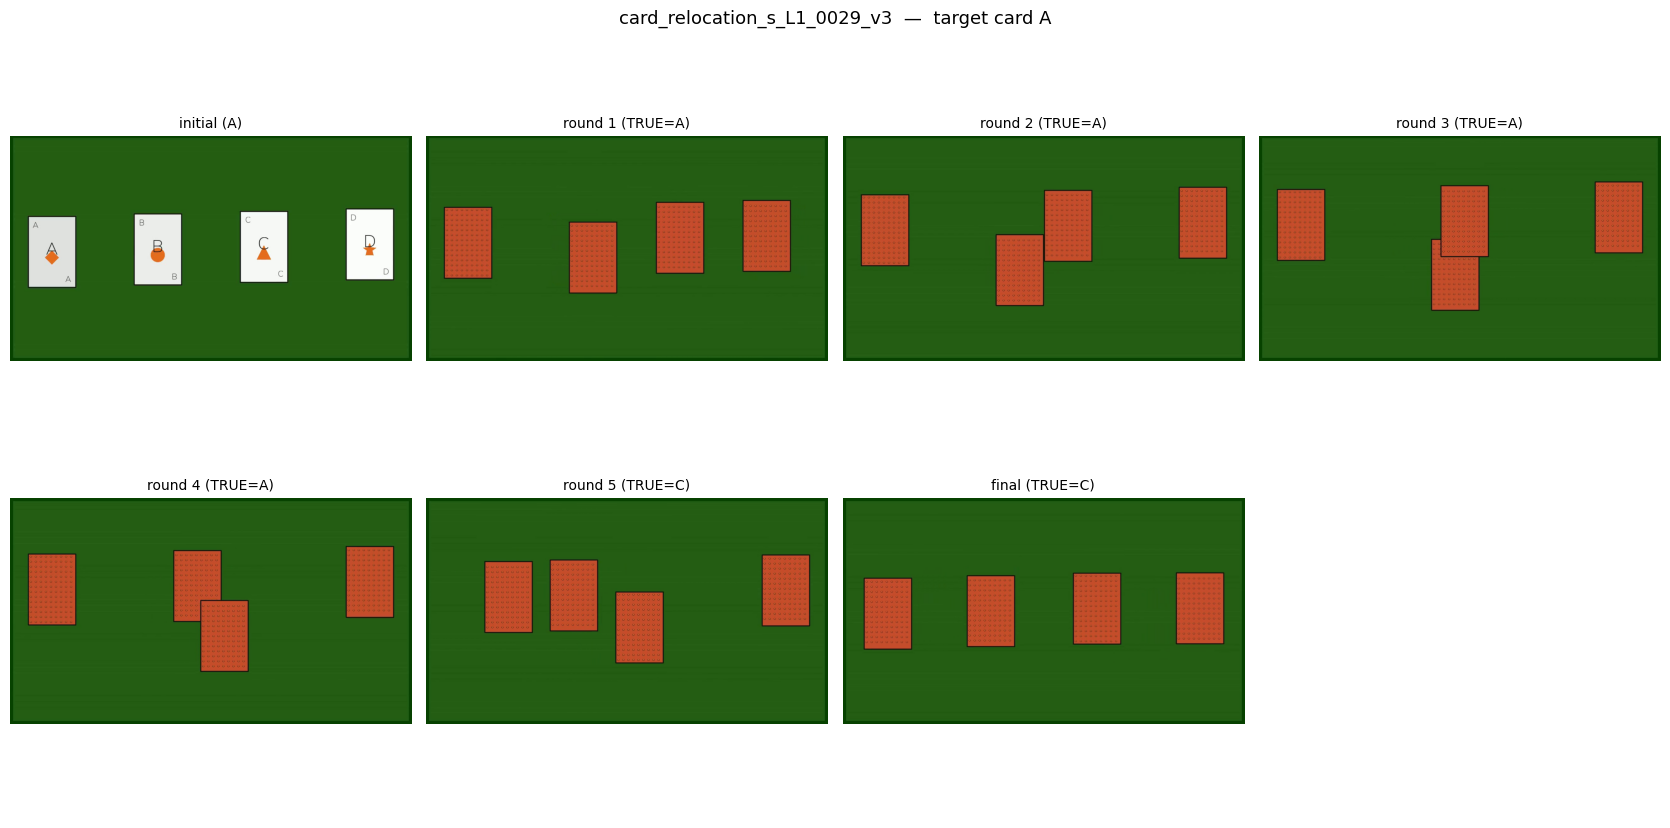


card_relocation_s_L1_0046_v3
video file            : card_relocation_s_L1_0046_v3.mp4
video exists on disk   : True
target card            : B
initial position (GT)  : B
final position (GT)    : D
corruption method      : hungarian_move_matched
source example (B')    : card_relocation_s_L1_0020_v3
true move count        : 1
corrupted move count   : 1
rounds changed         : 1/5  (indices: [2])

Round-by-round comparison:
  round     TRUE    CORRUPTED match?  
  initial   B       B         —       
  round 1   B       B         SAME    
  round 2   B       B         SAME    
  round 3   B       D         DIFF    
  round 4   D       D         SAME    
  round 5   D       D         SAME    
  final     D       D         SAME    

  fps=30.00  total_frames=780  sampled_frame_indices=[0, 130, 260, 390, 519, 649, 779]
  (Even sampling is an APPROXIMATION of round boundaries — rounds are not guaranteed to be evenly spaced in time. Use this only to sanity-check the overall trajectory, not e

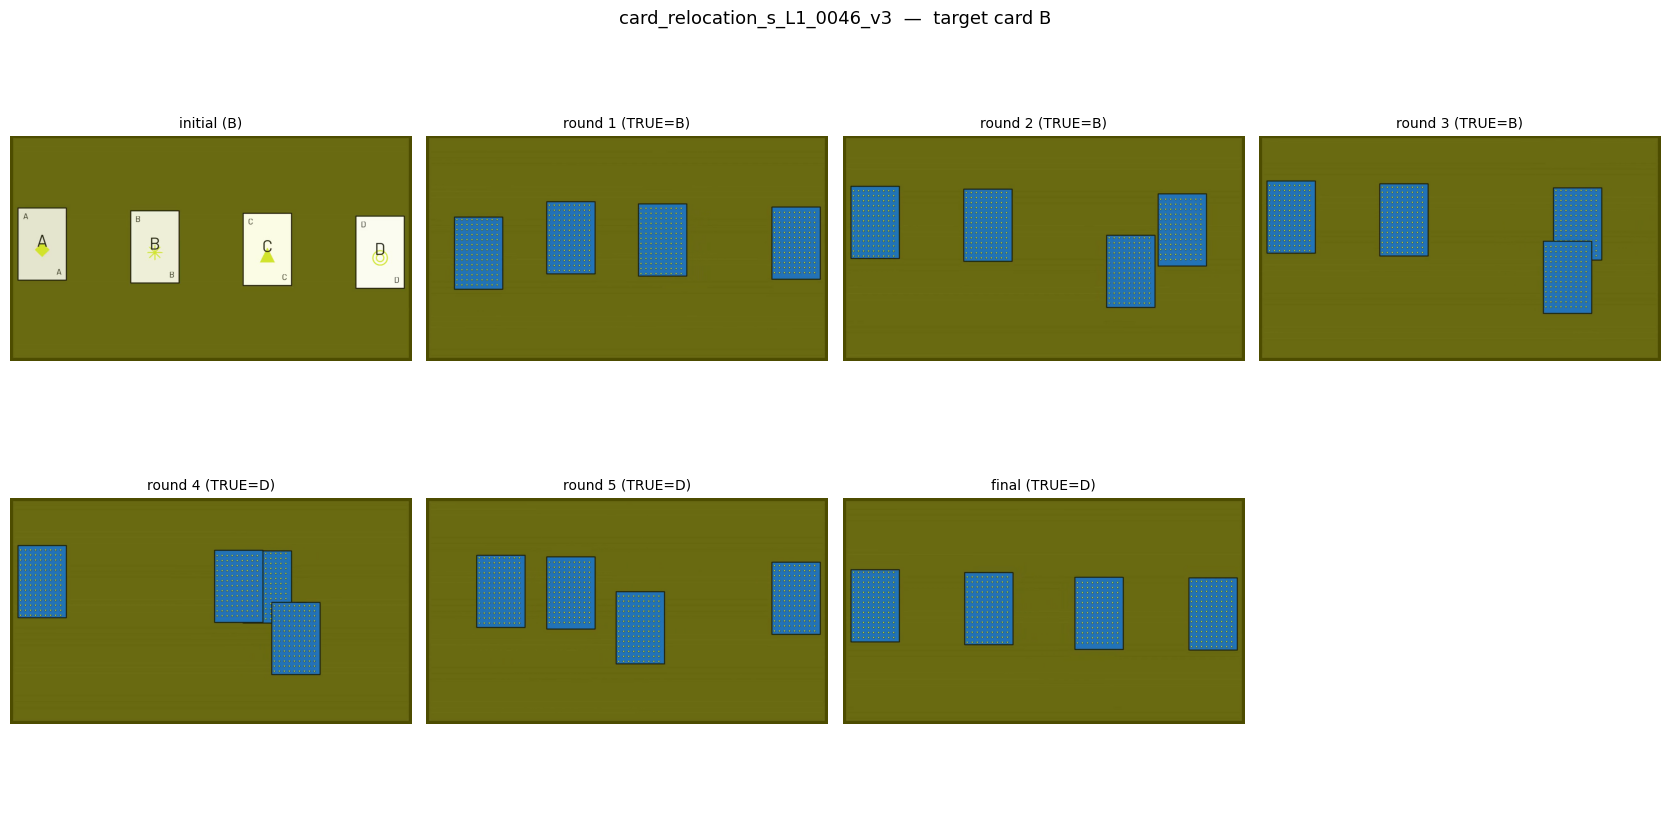


card_relocation_s_L1_0020_v3
video file            : card_relocation_s_L1_0020_v3.mp4
video exists on disk   : True
target card            : B
initial position (GT)  : B
final position (GT)    : D
corruption method      : hungarian_move_matched
source example (B')    : card_relocation_s_L1_0040_v3
true move count        : 1
corrupted move count   : 1
rounds changed         : 1/5  (indices: [2])

Round-by-round comparison:
  round     TRUE    CORRUPTED match?  
  initial   B       B         —       
  round 1   B       B         SAME    
  round 2   B       B         SAME    
  round 3   D       B         DIFF    
  round 4   D       D         SAME    
  round 5   D       D         SAME    
  final     D       D         SAME    

  fps=30.00  total_frames=780  sampled_frame_indices=[0, 130, 260, 390, 519, 649, 779]
  (Even sampling is an APPROXIMATION of round boundaries — rounds are not guaranteed to be evenly spaced in time. Use this only to sanity-check the overall trajectory, not e

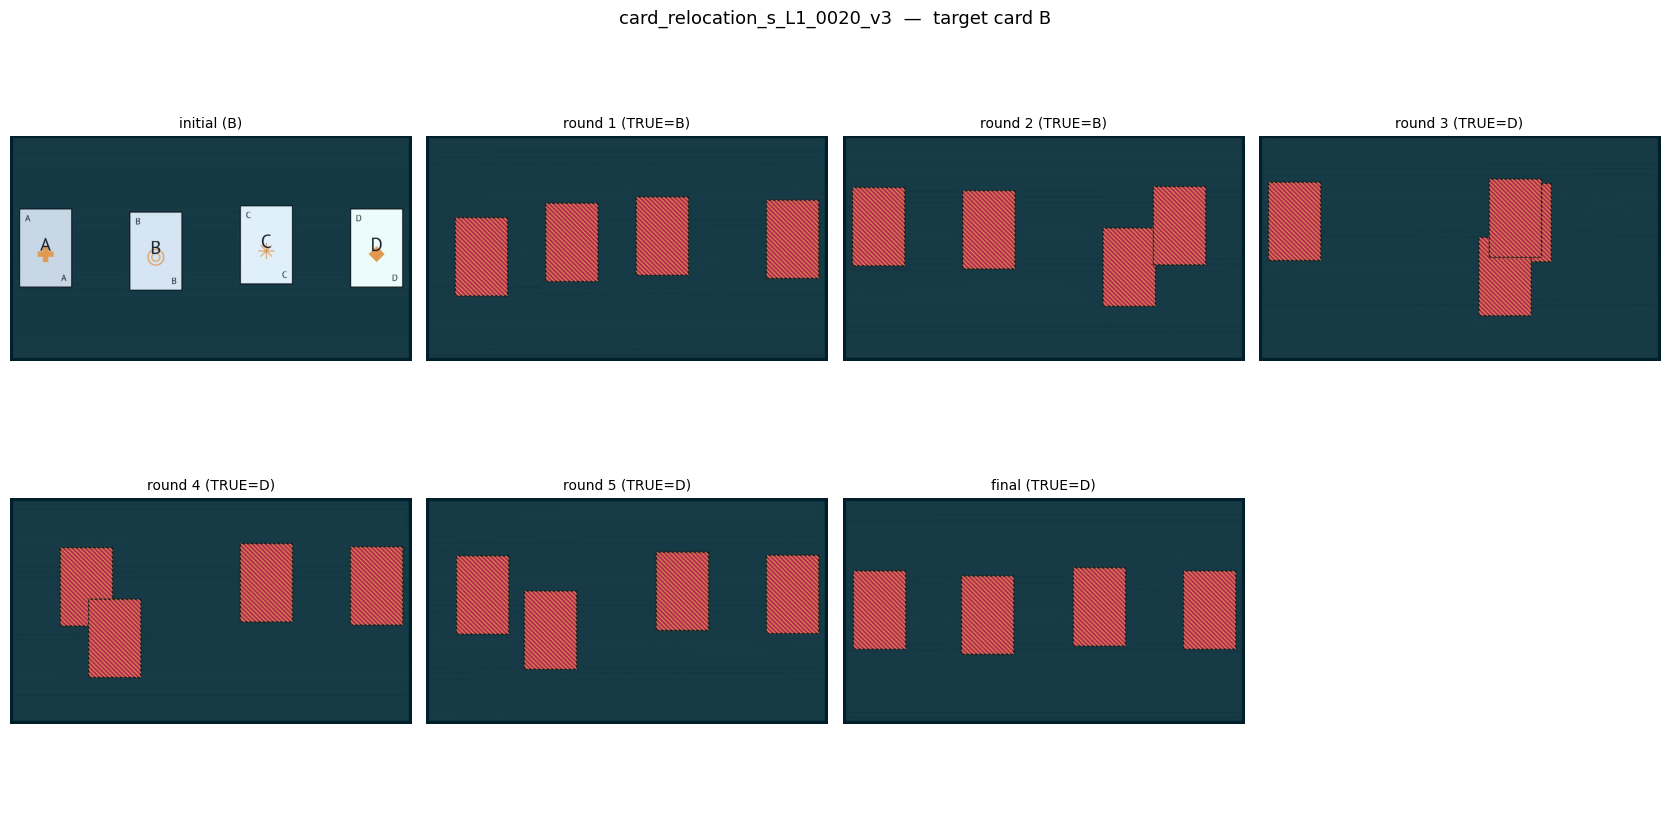


SPOT-CHECK COMPLETE — NOTHING WAS MODIFIED, NOTHING WAS TRAINED.
If the true positions match what's visible on screen for all three
examples, proceed to training B' v3 (same config as B) as a separate,
later cell.


In [ ]:
# =============================================================================
# MANUAL SPOT-CHECK — 3 LOWEST-DIVERGENCE B' v3 EXAMPLES
# =============================================================================
# Purpose:
#   Before training B' v3, visually verify the three examples whose corrupted
#   intermediate trajectory diverges least from the true one:
#     card_relocation_s_L1_0029_v3   (1/5 changed)
#     card_relocation_s_L1_0046_v3   (1/5 changed)
#     card_relocation_s_L1_0020_v3   (1/5 changed)
#
#   For each, this cell prints the true vs. corrupted round-by-round position
#   sequence (from train_Bprime_v3_audit.json) and displays frames sampled
#   evenly across the video so you can check the true sequence against what
#   actually happens on screen.
#
# This cell is READ-ONLY:
#   - does NOT modify, rebuild, or re-save any dataset
#   - does NOT train anything
#   - does NOT touch B' v3 construction in any way
#   - only downloads the 50 source videos if they are missing from /content
#     (ephemeral Colab storage), using the same HF dataset as every prior cell
# =============================================================================

import os
import json
import math

import cv2
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------
# 0. CONFIG
# -----------------------------------------------------------------------

SPOTCHECK_IDS = [
    "card_relocation_s_L1_0029_v3",
    "card_relocation_s_L1_0046_v3",
    "card_relocation_s_L1_0020_v3",
]

SFT_DIR = "/content/drive/MyDrive/videomme_experiments/sft_intervention"
AUDIT_PATH = os.path.join(SFT_DIR, "train_Bprime_v3_audit.json")

DATA_ROOT = "/content/videomme_data/video-mme-logical"
VIDEO_DIR = os.path.join(DATA_ROOT, "videos", "card_relocation_s_easy")

print("=" * 78)
print("MANUAL SPOT-CHECK — B' v3 LOWEST-DIVERGENCE EXAMPLES")
print("=" * 78)

# -----------------------------------------------------------------------
# 1. MOUNT DRIVE (no-op if already mounted)
# -----------------------------------------------------------------------

if not os.path.isdir("/content/drive/MyDrive"):
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)

if not os.path.isfile(AUDIT_PATH):
    raise FileNotFoundError(
        f"Audit file not found: {AUDIT_PATH}\n"
        "B' v3 must already be constructed (Step 5v3) before spot-checking it."
    )

# -----------------------------------------------------------------------
# 2. RESTORE THE 50 VIDEOS IF THIS IS A FRESH RUNTIME
# -----------------------------------------------------------------------

if not os.path.isdir(VIDEO_DIR) or len(
    [f for f in os.listdir(VIDEO_DIR) if f.endswith(".mp4")]
) < 50:
    print("\nVideo directory missing/incomplete — downloading from HF dataset...")
    from huggingface_hub import snapshot_download

    os.makedirs(DATA_ROOT, exist_ok=True)
    snapshot_download(
        repo_id="marcuskwan/video-mme-logical",
        repo_type="dataset",
        local_dir=DATA_ROOT,
        allow_patterns=[
            "videos/card_relocation_s_easy/*",
            "three_level_testset.json",
        ],
    )
    print("Download complete.")
else:
    print("\nVideo directory already present — skipping download.")

# -----------------------------------------------------------------------
# 3. LOAD AUDIT RECORDS FOR THE THREE TARGET IDS
# -----------------------------------------------------------------------

with open(AUDIT_PATH) as f:
    audit_records = json.load(f)

audit_by_id = {a["id"]: a for a in audit_records}

missing_ids = [i for i in SPOTCHECK_IDS if i not in audit_by_id]
if missing_ids:
    raise RuntimeError(
        f"These IDs are not present in {AUDIT_PATH}: {missing_ids}\n"
        "Check the IDs against the audit file before proceeding."
    )

# -----------------------------------------------------------------------
# 4. FRAME SAMPLING HELPER
# -----------------------------------------------------------------------

def sample_evenly(video_path, n_points):
    """Return n_points RGB frames sampled evenly across the video's duration
    (first frame at t=0, last frame at the final frame). n_points should be
    (num_rounds + 1): one for the initial state, one after each round."""
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        raise RuntimeError(f"Could not open video: {video_path}")

    fps = cap.get(cv2.CAP_PROP_FPS) or 30
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if frame_count <= 0:
        cap.release()
        raise RuntimeError(f"Video reports 0 frames: {video_path}")

    if n_points == 1:
        target_frame_idxs = [0]
    else:
        target_frame_idxs = [
            int(round(i * (frame_count - 1) / (n_points - 1)))
            for i in range(n_points)
        ]

    frames = []
    for idx in target_frame_idxs:
        cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
        ok, frame = cap.read()
        if ok:
            frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        else:
            frames.append(None)

    cap.release()
    return frames, target_frame_idxs, fps, frame_count


# -----------------------------------------------------------------------
# 5. SPOT-CHECK EACH EXAMPLE
# -----------------------------------------------------------------------

for example_id in SPOTCHECK_IDS:

    audit = audit_by_id[example_id]

    video_path = os.path.join(VIDEO_DIR, audit["video_file"])

    print("\n" + "=" * 78)
    print(example_id)
    print("=" * 78)

    print(f"video file            : {audit['video_file']}")
    print(f"video exists on disk   : {os.path.exists(video_path)}")
    print(f"target card            : {audit['target_card']}")
    print(f"initial position (GT)  : {audit['initial_position']}")
    print(f"final position (GT)    : {audit['final_position']}")
    print(f"corruption method      : {audit['corruption_method']}")
    print(f"source example (B')    : {audit['source_example_id']}")
    print(f"true move count        : {audit['true_move_count']}")
    print(f"corrupted move count   : {audit['corrupted_move_count']}")
    print(f"rounds changed         : {audit['num_intermediate_changed']}"
          f"/{audit['num_intermediate_rounds']}"
          f"  (indices: {audit['intermediate_indices_changed']})")

    true_seq = audit["true_round_positions"]
    corrupted_seq = audit["corrupted_round_positions"]

    print("\nRound-by-round comparison:")
    print(f"  {'round':<10}{'TRUE':<8}{'CORRUPTED':<10}{'match?':<8}")
    print(f"  {'initial':<10}{audit['initial_position']:<8}"
          f"{audit['initial_position']:<10}{'—':<8}")
    for i, (t, c) in enumerate(zip(true_seq, corrupted_seq), start=1):
        label = "final" if i == len(true_seq) else f"round {i}"
        flag = "SAME" if t == c else "DIFF"
        print(f"  {label:<10}{t:<8}{c:<10}{flag:<8}")

    if not os.path.exists(video_path):
        print("\n  ⚠️  Video file not found — skipping frame display for this example.")
        continue

    n_rounds = len(true_seq)  # includes the final round
    n_points = n_rounds + 1   # +1 for the initial frame

    frames, frame_idxs, fps, frame_count = sample_evenly(video_path, n_points)

    print(f"\n  fps={fps:.2f}  total_frames={frame_count}  "
          f"sampled_frame_indices={frame_idxs}")
    print("  (Even sampling is an APPROXIMATION of round boundaries — "
          "rounds are not guaranteed to be evenly spaced in time. Use this "
          "only to sanity-check the overall trajectory, not exact timing.)")

    cols = min(4, n_points)
    rows = math.ceil(n_points / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(4.2 * cols, 4.2 * rows))
    axes = axes.flatten() if n_points > 1 else [axes]

    labels_true = [f"initial ({audit['initial_position']})"] + [
        f"{'final' if i == len(true_seq) else f'round {i}'} (TRUE={t})"
        for i, t in enumerate(true_seq, start=1)
    ]

    for ax_i in range(len(axes)):
        ax = axes[ax_i]
        if ax_i < len(frames) and frames[ax_i] is not None:
            ax.imshow(frames[ax_i])
            ax.set_title(labels_true[ax_i], fontsize=10)
        ax.axis("off")

    fig.suptitle(f"{example_id}  —  target card {audit['target_card']}", fontsize=13)
    plt.tight_layout()
    plt.show()

print("\n" + "=" * 78)
print("SPOT-CHECK COMPLETE — NOTHING WAS MODIFIED, NOTHING WAS TRAINED.")
print("If the true positions match what's visible on screen for all three")
print("examples, proceed to training B' v3 (same config as B) as a separate,")
print("later cell.")
print("=" * 78)

In [ ]:
# =============================================================================
# STEP 6 — TRAIN CONDITION B' v3 (MOVE-COUNT-MATCHED CROSS-EXAMPLE CONTROL)
# =============================================================================
# B' v3 has already been constructed and audited (Step 5v3) and manually
# spot-checked. This cell trains it with the EXACT training configuration
# used for Condition B — same repo, same pinned commit, same patches, same
# LoRA/QLoRA hyperparameters, same optimizer/schedule/precision, same video
# pipeline. Nothing about the recipe is redesigned here; only the dataset
# path and output directory differ from B.
#
# Run order:
#   0. config
#   1. imports / environment capture + exact-version gate
#   2. cheap validation: dataset exists + has exactly 40 records, all 40 ids
#      match the fixed training split, video files exist, output dir is
#      empty or has no completed adapter to protect against overwrite
#   3. repo restore (pinned commit)
#   4. patch restore (Drive snapshot if usable, else reapply + save)
#   5. 24-frame video pipeline smoke test through the patched code
#   6. train, streaming stdout/stderr to a timestamped log on Drive
#   7. post-training verification: 15/15 optimizer steps, adapter present,
#      NaN/Inf tensor scan, training_run_metadata.json, final Drive check
#
# Does NOT touch B, B' v1, or B' v2 files. Does NOT modify the B' v3
# dataset. Does NOT evaluate B' v3 or start 5-fold CV.
# =============================================================================

# =============================================================================
# 0. CONFIG
# =============================================================================

CONFIG = {
    "model_id": "Qwen/Qwen2.5-VL-3B-Instruct",
    "repo_url": "https://github.com/2U1/Qwen-VL-Series-Finetune.git",
    "repo_dir": "/content/qwen-vl-finetune",
    "pinned_commit": "67078206604820beb20bddbe24c94a0b4a4bd6d4",

    "drive_root": "/content/drive/MyDrive/videomme_experiments",
    "sft_dir": "/content/drive/MyDrive/videomme_experiments/sft_intervention",
    "repo_snapshot_dir": "/content/drive/MyDrive/videomme_experiments/repo_snapshot",
    "video_dir": "/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy",
    "smoke_video": (
        "/content/videomme_data/video-mme-logical/videos/"
        "card_relocation_s_easy/card_relocation_s_L1_0001_v3.mp4"
    ),

    "train_data": "/content/drive/MyDrive/videomme_experiments/sft_intervention/train_Bprime_v3_trajectory.json",
    "output_dir": "/content/drive/MyDrive/videomme_experiments/sft_intervention/models/Bprime_v3",

    "split_summary_path": "/content/drive/MyDrive/videomme_experiments/sft_intervention/split_summary.json",
    "train_metadata_path": "/content/drive/MyDrive/videomme_experiments/sft_intervention/train_metadata.json",

    "n_expected_records": 40,

    # exact-pin environment gate — same working environment as B/C
    "required_versions": {
        "torch": "2.11.0",          # matched as a prefix (handles +cu128 local suffix)
        "transformers": "5.17.0",
        "peft": "0.20.0",
        "trl": "1.13.0",
        "bitsandbytes": "0.50.2",
        "decord": "0.6.0",
        "qwen_vl_utils": "0.0.14",
    },

    # IDENTICAL to the args that trained B — do not change any value here.
    "train_args": {
        "--model_id": "Qwen/Qwen2.5-VL-3B-Instruct",
        "--image_folder": "/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy",
        "--lora_enable": "True",
        "--lora_rank": "16",
        "--lora_alpha": "32",
        "--lora_dropout": "0.05",
        "--num_lora_modules": "-1",
        "--freeze_llm": "True",
        "--freeze_vision_tower": "True",
        "--freeze_merger": "True",
        "--bits": "4",
        "--quant_type": "nf4",
        "--double_quant": "True",
        "--use_liger_kernel": "False",
        "--disable_flash_attn2": "True",
        "--fp16": "True",
        "--bf16": "False",
        "--gradient_checkpointing": "True",
        "--per_device_train_batch_size": "1",
        "--gradient_accumulation_steps": "8",
        "--num_train_epochs": "3",
        "--learning_rate": "0.0001",
        "--weight_decay": "0.01",
        "--lr_scheduler_type": "cosine",
        "--optim": "adamw_bnb_8bit",
        "--max_seq_length": "4096",
        "--video_resized_width": "224",
        "--video_resized_height": "224",
        "--nframes": "24",
        "--remove_unused_columns": "False",
        "--lazy_preprocess": "True",
        "--dataloader_num_workers": "0",
        "--logging_steps": "1",
        "--save_strategy": "no",
        "--report_to": "none",
    },

    "train_timeout_sec": 3600,  # 1 hour hard ceiling, same as B/C
}

# =============================================================================
# 1. IMPORTS + ENVIRONMENT
# =============================================================================

import importlib
import importlib.metadata as im
import json
import math
import os
import re
import subprocess
import sys
import time
from datetime import datetime
from pathlib import Path

print("=" * 78)
print("STEP 6 — TRAIN CONDITION B' v3 (MOVE-COUNT-MATCHED CROSS-EXAMPLE CONTROL)")
print("=" * 78)

os.environ["FORCE_QWENVL_VIDEO_READER"] = "decord"


def pkg_version(name):
    try:
        return im.version(name)
    except im.PackageNotFoundError:
        return None


def pip_install(*pkgs, no_deps=False):
    cmd = [sys.executable, "-m", "pip", "-q", "install"]
    if no_deps:
        cmd.append("--no-deps")
    cmd += list(pkgs)
    print("  $", " ".join(cmd))
    subprocess.run(cmd, check=True)


def pip_uninstall(pkg):
    subprocess.run([sys.executable, "-m", "pip", "-q", "uninstall", "-y", pkg], check=False)


# --- torchao: same recurring conflict as B/C training, not used here --------
_torchao_ver = pkg_version("torchao")
if _torchao_ver is not None:
    print(f"\ntorchao {_torchao_ver} detected — removing (documented project fix, "
          "not used by this pipeline)...")
    pip_uninstall("torchao")
    importlib.invalidate_caches()
    if pkg_version("torchao") is not None:
        raise RuntimeError("torchao still present after uninstall — remove manually and retry.")
    print("  torchao removed.")

# --- required packages: install only what's missing, no requirements.txt ---
NEEDED = {
    "bitsandbytes": "0.50.2",
    "trl": "1.13.0",
    "ujson": None,
}
for pkg, pin in NEEDED.items():
    if pkg_version(pkg) is None:
        print(f"\nInstalling {pkg}{'=='+pin if pin else ''} ...")
        pip_install(f"{pkg}=={pin}" if pin else pkg)

import torch
import transformers

print("\nENVIRONMENT")
print("-" * 78)
env_report = {
    "timestamp": datetime.now().isoformat(timespec="seconds"),
    "python": sys.version.split()[0],
    "torch": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "transformers": transformers.__version__,
    "peft": pkg_version("peft"),
    "bitsandbytes": pkg_version("bitsandbytes"),
    "trl": pkg_version("trl"),
    "decord": pkg_version("decord"),
    "qwen_vl_utils": pkg_version("qwen_vl_utils"),
    "torchao_removed": _torchao_ver,
}
for k, v in env_report.items():
    print(f"  {k:18s} {v}")

if not torch.cuda.is_available():
    raise RuntimeError("CUDA not available — abort.")

version_problems = []
for pkg, required in CONFIG["required_versions"].items():
    actual = env_report.get(pkg) if pkg != "torch" else torch.__version__
    if actual is None:
        version_problems.append(f"{pkg}: not installed (need {required})")
    elif not actual.startswith(required):
        version_problems.append(f"{pkg}: found {actual}, expected {required}")

if version_problems:
    raise RuntimeError(
        "Environment does not match the working B/C training environment — "
        "refusing to train B' v3 against an unverified environment:\n  - "
        + "\n  - ".join(version_problems)
    )
print("\n✅ environment matches the working B/C training environment exactly")


# =============================================================================
# 2. CHEAP VALIDATION (before touching the repo, the model, or the GPU)
# =============================================================================

print("\nCHEAP VALIDATION")
print("-" * 78)

problems = []

# --- 2a. training data exists and has exactly 40 records -------------------
if not os.path.isfile(CONFIG["train_data"]):
    problems.append(f"missing B' v3 training data: {CONFIG['train_data']}")
    train_records = []
else:
    with open(CONFIG["train_data"]) as f:
        train_records = json.load(f)
    ok = len(train_records) == CONFIG["n_expected_records"]
    print(f"  [{'OK ' if ok else 'MISS'}] B' v3 record count: {len(train_records)} "
          f"(expected {CONFIG['n_expected_records']})")
    if not ok:
        problems.append(
            f"B' v3 dataset has {len(train_records)} records, expected "
            f"{CONFIG['n_expected_records']}"
        )

# --- 2b. all 40 ids match the fixed training split --------------------------
if train_records:
    dataset_ids = sorted(r["id"] for r in train_records)

    if not os.path.isfile(CONFIG["split_summary_path"]):
        problems.append(f"missing split_summary.json: {CONFIG['split_summary_path']}")
        split_train_ids = None
    else:
        with open(CONFIG["split_summary_path"]) as f:
            split_summary = json.load(f)
        split_train_ids = sorted(split_summary.get("train_ids", []))

    if os.path.isfile(CONFIG["train_metadata_path"]):
        with open(CONFIG["train_metadata_path"]) as f:
            train_metadata_ids = sorted(r["id"] for r in json.load(f))
    else:
        train_metadata_ids = None

    if split_train_ids is not None:
        ids_match_split = dataset_ids == split_train_ids
        print(f"  [{'OK ' if ids_match_split else 'MISS'}] B' v3 ids match "
              f"split_summary.json train_ids ({len(dataset_ids)} ids)")
        if not ids_match_split:
            only_in_dataset = sorted(set(dataset_ids) - set(split_train_ids))
            only_in_split = sorted(set(split_train_ids) - set(dataset_ids))
            problems.append(
                "B' v3 ids do not match split_summary.json train_ids — "
                f"only in dataset: {only_in_dataset}; only in split: {only_in_split}"
            )

    if train_metadata_ids is not None:
        ids_match_meta = dataset_ids == train_metadata_ids
        print(f"  [{'OK ' if ids_match_meta else 'MISS'}] B' v3 ids match "
              f"train_metadata.json ids ({len(dataset_ids)} ids)")
        if not ids_match_meta:
            problems.append("B' v3 ids do not match train_metadata.json ids")

    dup_ids = len(dataset_ids) != len(set(dataset_ids))
    if dup_ids:
        problems.append("B' v3 dataset contains duplicate ids")
    else:
        print(f"  [OK ] no duplicate ids in B' v3 dataset")

# --- 2c. video files exist for every record ---------------------------------
ok = os.path.isdir(CONFIG["video_dir"])
print(f"  [{'OK ' if ok else 'MISS'}] video dir: {CONFIG['video_dir']}")
if not ok:
    problems.append(f"missing video dir: {CONFIG['video_dir']}")
elif train_records:
    missing_videos = []
    for r in train_records:
        vpath = os.path.join(CONFIG["video_dir"], r["video"])
        if not os.path.isfile(vpath):
            missing_videos.append(r["video"])
    if missing_videos:
        problems.append(f"{len(missing_videos)} video file(s) missing: {missing_videos[:10]}")
    else:
        print(f"  [OK ] all {len(train_records)} referenced video files exist on disk")

ok = os.path.isfile(CONFIG["smoke_video"])
print(f"  [{'OK ' if ok else 'MISS'}] smoke test video: {CONFIG['smoke_video']}")
if not ok:
    problems.append(f"missing smoke test video: {CONFIG['smoke_video']}")

# --- 2d. output directory: empty, or no completed adapter already there -----

def adapter_is_valid(d):
    cfg = os.path.join(d, "adapter_config.json")
    w1 = os.path.join(d, "adapter_model.safetensors")
    w2 = os.path.join(d, "adapter_model.bin")
    return os.path.isfile(cfg) and (os.path.isfile(w1) or os.path.isfile(w2))


output_dir = CONFIG["output_dir"]
if adapter_is_valid(output_dir):
    problems.append(
        f"a completed B' v3 adapter already exists at {output_dir} — refusing "
        "to overwrite it. Move/rename it first if you really want to retrain."
    )
    print(f"  [MISS] output dir already has a completed adapter: {output_dir}")
else:
    os.makedirs(output_dir, exist_ok=True)
    existing = os.listdir(output_dir)
    print(f"  [OK ] output dir has no completed adapter "
          f"({'empty' if not existing else f'{len(existing)} stray file(s), no valid adapter'}): "
          f"{output_dir}")

if problems:
    raise RuntimeError("Aborting before training:\n  - " + "\n  - ".join(problems))

os.makedirs(os.path.join(CONFIG["sft_dir"], "logs"), exist_ok=True)
os.makedirs(CONFIG["repo_snapshot_dir"], exist_ok=True)

print("\n✅ all cheap validation checks passed")


# =============================================================================
# 3. REPO RESTORE (pinned commit) — reuses the existing repo, no redesign
# =============================================================================

print("\nREPO RESTORE")
print("-" * 78)

REPO = CONFIG["repo_dir"]


def git(*args, cwd=REPO, check=True):
    cmd = ["git"] + list(args)
    r = subprocess.run(cmd, cwd=cwd, capture_output=True, text=True)
    if check and r.returncode != 0:
        raise RuntimeError(f"git {' '.join(args)} failed:\n{r.stdout}\n{r.stderr}")
    return r.stdout.strip()


if not os.path.isdir(os.path.join(REPO, ".git")):
    subprocess.run(["rm", "-rf", REPO], check=False)
    print(f"  cloning {CONFIG['repo_url']} ...")
    subprocess.run(["git", "clone", "-q", CONFIG["repo_url"], REPO], check=True)

git("fetch", "-q", "origin")
git("checkout", "-q", CONFIG["pinned_commit"])
head = git("rev-parse", "HEAD")
if head != CONFIG["pinned_commit"]:
    raise RuntimeError(f"repo at {head}, expected pinned commit {CONFIG['pinned_commit']}")
print(f"  repo commit: {head}  (matches pinned commit)")

if os.path.join(REPO, "src") not in sys.path:
    sys.path.insert(0, os.path.join(REPO, "src"))


# =============================================================================
# 4. PATCH RESTORE — prefer Drive snapshot, else reapply exactly + save
#    (byte-for-byte the same patch logic used to train B and C)
# =============================================================================

print("\nPATCH RESTORE")
print("-" * 78)

DU_PATH = os.path.join(REPO, "src/dataset/data_utils.py")
SD_PATH = os.path.join(REPO, "src/dataset/sft_dataset.py")
MP_PATH = os.path.join(REPO, "src/train/monkey_patch_vision.py")

MP_STUB = '''"""
Disabled vision monkey patch for this experiment.

The vision tower is frozen during QLoRA training, so the repository's
custom Qwen2.5-VL vision replacement is unnecessary here.
"""

def replace_qwen2_5_vision():
    return None
'''


def patch_data_utils(text):
    sig_re = re.compile(r"^def\s+get_video_info\s*\(([^)]*)\)\s*:", re.MULTILINE)
    m = sig_re.search(text)
    if not m:
        raise RuntimeError("data_utils.py: get_video_info def not found")
    args_raw = m.group(1)
    arg_names = [
        c.strip().split("=")[0].split(":")[0].strip().lstrip("*")
        for c in args_raw.split(",") if c.strip()
    ]
    if "nframes" not in arg_names:
        if "return_video_metadata" in arg_names:
            new_args = args_raw.replace(
                "return_video_metadata", "nframes=None, return_video_metadata", 1,
            )
        else:
            new_args = args_raw.rstrip().rstrip(",") + ", nframes=None"
        text = text[:m.start(1)] + new_args + text[m.end(1):]
        print("  data_utils.py: added nframes kwarg")
    else:
        print("  data_utils.py: nframes kwarg already present")

    sig_re2 = re.compile(r"^def\s+get_video_info\s*\([^)]*\)\s*:", re.MULTILINE)
    m2 = sig_re2.search(text)
    body_start = m2.end()
    next_top = re.search(r"^(def|class)\s", text[body_start:], re.MULTILINE)
    body_end = body_start + (next_top.start() if next_top else len(text) - body_start)
    body = text[body_start:body_end]

    content_re = re.compile(r"(?P<indent>[ \t]*)content\s*=\s*\{(?P<inner>.*?)\}", re.DOTALL)
    mc = content_re.search(body)
    if not mc:
        raise RuntimeError("data_utils.py: content = {...} block not found in get_video_info")

    if "if nframes is not None:" not in body:
        indent = mc.group("indent")
        new_block = (
            f'{indent}content = {{\n'
            f'{indent}    "type": "video", \n'
            f'{indent}    "video": video_path,\n'
            f'{indent}    "min_pixels": min_pixels,\n'
            f'{indent}    "max_pixels": max_pixels,\n'
            f'{indent}}}\n'
            f'{indent}\n'
            f'{indent}if nframes is not None:\n'
            f'{indent}    content["nframes"] = nframes\n'
            f'{indent}elif fps is not None:\n'
            f'{indent}    content["fps"] = fps'
        )
        body = body[:mc.start()] + new_block + body[mc.end():]
        text = text[:body_start] + body + text[body_end:]
        print("  data_utils.py: inserted nframes/fps mutual-exclusion block")
    else:
        print("  data_utils.py: nframes/fps block already present")

    block_re = re.compile(
        r'(?:^[ \t]*#[^\n]*\n)+?'
        r'^[ \t]*if nframes is not None:\n'
        r'^[ \t]*content\["nframes"\] = nframes\n'
        r'^[ \t]*elif fps is not None:\n'
        r'^[ \t]*content\["fps"\] = fps\n',
        re.MULTILINE,
    )
    matches = list(block_re.finditer(text))
    if len(matches) > 1:
        for mm in reversed(matches[1:]):
            text = text[:mm.start()] + text[mm.end():]
        print(f"  data_utils.py: removed {len(matches) - 1} duplicate block(s)")

    return text


def patch_sft_dataset(text):
    if "nframes=self.nframes" not in text:
        call_re = re.compile(
            r"(get_video_info\s*\(\s*video_file\s*,[^)]*?"
            r"return_video_metadata\s*=\s*self\.return_video_metadata\s*,?\s*\))",
            re.DOTALL,
        )
        mc2 = call_re.search(text)
        if not mc2:
            raise RuntimeError("sft_dataset.py: get_video_info call site not found")
        old_call = mc2.group(1)
        if re.search(r"self\.image_patch_size\s*,", old_call):
            new_call = re.sub(
                r"(self\.image_patch_size\s*,)",
                r"\1\n                    nframes=self.nframes,",
                old_call, count=1,
            )
        else:
            new_call = old_call.replace(
                "return_video_metadata=self.return_video_metadata",
                "nframes=self.nframes,\n                    "
                "return_video_metadata=self.return_video_metadata",
                1,
            )
        text = text[:mc2.start(1)] + new_call + text[mc2.end(1):]
        print("  sft_dataset.py: forwarded nframes=self.nframes")
    else:
        print("  sft_dataset.py: nframes forwarding already present")

    lines = text.splitlines(keepends=True)
    out_lines, i, removed_guards = [], 0, 0
    while i < len(lines):
        if "qwen_vl_utils returns fps as a list" in lines[i]:
            j = i
            while j < len(lines) and 'video_kwargs["fps"] = float(_fps)' not in lines[j]:
                j += 1
            j += 1
            while j < len(lines) and lines[j].strip() == "":
                j += 1
            i = j
            removed_guards += 1
            continue
        out_lines.append(lines[i])
        i += 1
    if removed_guards:
        print(f"  sft_dataset.py: stripped {removed_guards} existing guard(s)")
    text = "".join(out_lines)

    lines = text.splitlines(keepends=True)
    target = 'if self.model_type == "qwen2_5_vl":\n'
    try:
        idx = lines.index(target)
    except ValueError:
        idx = next((i for i, l in enumerate(lines)
                    if l.strip() == 'if self.model_type == "qwen2_5_vl":'), None)
    if idx is None:
        raise RuntimeError("sft_dataset.py: qwen2_5_vl branch head not found")
    indent = " " * (len(lines[idx]) - len(lines[idx].lstrip()) + 4)
    guard = (
        f'{indent}# qwen_vl_utils returns fps as a list (one entry per video).\n'
        f'{indent}# transformers\' Qwen2.5-VL processor strictly types fps as\n'
        f'{indent}# int | float | None. Normalize to scalar; keep fps, it feeds\n'
        f'{indent}# second_per_grid_ts.\n'
        f'{indent}if isinstance(video_kwargs, dict):\n'
        f'{indent}    _fps = video_kwargs.get("fps")\n'
        f'{indent}    if isinstance(_fps, (list, tuple)):\n'
        f'{indent}        if len(_fps) == 1:\n'
        f'{indent}            video_kwargs["fps"] = float(_fps[0])\n'
        f'{indent}        elif len(_fps) == 0:\n'
        f'{indent}            video_kwargs.pop("fps", None)\n'
        f'{indent}        else:\n'
        f'{indent}            raise ValueError(f"Expected single video, got fps={{_fps}}")\n'
        f'{indent}    elif _fps is not None:\n'
        f'{indent}        video_kwargs["fps"] = float(_fps)\n\n'
    )
    lines[idx + 1:idx + 1] = [guard]
    text = "".join(lines)
    print("  sft_dataset.py: inserted fps scalarization guard")
    return text


snap_du = os.path.join(CONFIG["repo_snapshot_dir"], "data_utils.py")
snap_sd = os.path.join(CONFIG["repo_snapshot_dir"], "sft_dataset.py")
snap_mp = os.path.join(CONFIG["repo_snapshot_dir"], "monkey_patch_vision.py")


def snapshot_is_usable():
    if not all(os.path.isfile(p) for p in (snap_du, snap_sd, snap_mp)):
        return False
    du_txt = Path(snap_du).read_text()
    sd_txt = Path(snap_sd).read_text()
    mp_txt = Path(snap_mp).read_text()
    for txt, name in ((du_txt, "data_utils"), (sd_txt, "sft_dataset"), (mp_txt, "monkey_patch")):
        try:
            compile(txt, name, "exec")
        except SyntaxError:
            return False
    return (
        "nframes=None" in du_txt
        and "nframes=self.nframes" in sd_txt
        and "def replace_qwen2_5_vision" in mp_txt
    )


if snapshot_is_usable():
    print(f"  Using saved patches from {CONFIG['repo_snapshot_dir']}")
    for src, dst in [(snap_du, DU_PATH), (snap_sd, SD_PATH), (snap_mp, MP_PATH)]:
        Path(dst).write_text(Path(src).read_text())
    patch_source = "drive_snapshot"
else:
    print("  No usable snapshot on Drive — applying patches from source and saving them")

    Path(DU_PATH).write_text(patch_data_utils(Path(DU_PATH).read_text()))
    Path(SD_PATH).write_text(patch_sft_dataset(Path(SD_PATH).read_text()))
    Path(MP_PATH).write_text(MP_STUB)
    print("  monkey_patch_vision.py: replaced with no-op stub (vision tower is frozen)")

    patch_source = "reapplied_from_source"

    for p in (DU_PATH, SD_PATH, MP_PATH):
        r = subprocess.run([sys.executable, "-m", "py_compile", p], capture_output=True, text=True)
        if r.returncode != 0:
            raise RuntimeError(f"py_compile failed for {p}:\n{r.stdout}\n{r.stderr}")
    print("  py_compile: all three patched files OK")

    for src, dst in [(DU_PATH, snap_du), (SD_PATH, snap_sd), (MP_PATH, snap_mp)]:
        Path(dst).write_text(Path(src).read_text())
    (Path(CONFIG["repo_snapshot_dir"]) / "commit.txt").write_text(CONFIG["pinned_commit"] + "\n")
    print(f"  saved patched files to {CONFIG['repo_snapshot_dir']} for future sessions")


# =============================================================================
# 5. VIDEO PIPELINE SMOKE TEST (through the patched code, before training)
# =============================================================================

print("\nVIDEO PIPELINE SMOKE TEST")
print("-" * 78)

for mod in ("dataset", "dataset.data_utils"):
    if mod in sys.modules:
        del sys.modules[mod]
from dataset import data_utils  # noqa: E402

video_input, video_kwargs = data_utils.get_video_info(
    CONFIG["smoke_video"],
    min_pixels=100352,
    max_pixels=602112,
    width=224,
    height=224,
    fps=None,
    image_patch_size=14,
    nframes=24,
    return_video_metadata=False,
)
print(f"  video_kwargs: {video_kwargs}")
print(f"  video shape : {tuple(video_input.shape)}")
assert video_input.shape[0] == 24, f"expected 24 frames, got {video_input.shape[0]}"
print("  smoke test: PASS")

del video_input
import gc
gc.collect()
torch.cuda.empty_cache()


# =============================================================================
# 6. TRAIN — log streamed to a timestamped file on Drive, not /content
# =============================================================================

print("\nTRAIN CONDITION B' v3")
print("-" * 78)


def build_train_command():
    args = dict(CONFIG["train_args"])
    args["--data_path"] = CONFIG["train_data"]
    args["--output_dir"] = CONFIG["output_dir"]
    cmd = [sys.executable, "src/train/train_sft.py"]
    for k, v in args.items():
        cmd += [k, v]
    return cmd, args


def stream_run(cmd, cwd, env, log_path, timeout_sec):
    os.makedirs(os.path.dirname(log_path), exist_ok=True)
    t0 = time.time()
    with open(log_path, "w") as logf:
        proc = subprocess.Popen(
            cmd, cwd=cwd, env=env,
            stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
            text=True, bufsize=1,
        )
        try:
            for line in proc.stdout:
                print(line, end="")
                logf.write(line)
                if time.time() - t0 > timeout_sec:
                    proc.kill()
                    raise TimeoutError(f"training exceeded {timeout_sec}s — killed")
        finally:
            proc.wait()
    return proc.returncode, round(time.time() - t0, 1)


cmd, resolved_args = build_train_command()
print("  command:")
print("   ", " ".join(cmd))

env = dict(os.environ)
env["PYTHONPATH"] = os.path.join(REPO, "src") + ":" + env.get("PYTHONPATH", "")
env["FORCE_QWENVL_VIDEO_READER"] = "decord"

log_path = os.path.join(
    CONFIG["sft_dir"], "logs",
    f"Bprime_v3_train_{datetime.now().strftime('%Y%m%d_%H%M%S')}.log"
)

rc, elapsed = stream_run(cmd, REPO, env, log_path, CONFIG["train_timeout_sec"])
print(f"\n  return code: {rc}   elapsed: {elapsed}s   log: {log_path}")

if rc != 0:
    raise RuntimeError(
        f"B' v3 training failed (exit {rc}). See log at {log_path} before "
        "retrying — do not silently change hyperparameters to work around a failure."
    )


# =============================================================================
# 7. POST-TRAINING VERIFICATION
# =============================================================================

print("\nPOST-TRAINING VERIFICATION")
print("-" * 78)

# --- 7a. verify all 15 optimizer steps completed, from the training log ----
n_records = len(train_records)
per_step_batch = int(CONFIG["train_args"]["--per_device_train_batch_size"]) * \
    int(CONFIG["train_args"]["--gradient_accumulation_steps"])
epochs = int(CONFIG["train_args"]["--num_train_epochs"])
expected_steps = math.ceil(n_records / per_step_batch) * epochs

with open(log_path) as f:
    log_text = f.read()

step_progress = re.findall(r"(\d+)/(\d+)\s*\[", log_text)
final_metrics_match = re.search(
    r"\{[^{}]*'train_runtime'[^{}]*\}", log_text
)

if not step_progress:
    raise RuntimeError(
        f"Could not find any step progress ('N/M [') in the training log "
        f"({log_path}) — cannot confirm optimizer steps completed."
    )

last_step, last_total = (int(x) for x in step_progress[-1])
print(f"  last logged progress: {last_step}/{last_total}  (expected {expected_steps}/{expected_steps})")
if last_step != expected_steps or last_total != expected_steps:
    raise RuntimeError(
        f"B' v3 did not complete all {expected_steps} optimizer steps — "
        f"log shows {last_step}/{last_total}. See {log_path}."
    )
print(f"  ✅ all {expected_steps} optimizer steps completed")

final_train_metrics = None
if final_metrics_match:
    raw = final_metrics_match.group(0).replace("'", '"')
    try:
        final_train_metrics = json.loads(raw)
        print(f"  final training metrics: {final_train_metrics}")
    except json.JSONDecodeError:
        print(f"  (found a final-metrics-shaped line but could not JSON-parse it: {raw!r})")
else:
    print("  (no explicit final metrics dict found in log — not fatal, steps already verified)")

# --- 7b. adapter_model.safetensors exists -----------------------------------
adapter_cfg_path = os.path.join(CONFIG["output_dir"], "adapter_config.json")
adapter_weights_path = os.path.join(CONFIG["output_dir"], "adapter_model.safetensors")

if not os.path.isfile(adapter_cfg_path):
    raise RuntimeError(f"adapter_config.json missing at {CONFIG['output_dir']}")
if not os.path.isfile(adapter_weights_path):
    raise RuntimeError(f"adapter_model.safetensors missing at {CONFIG['output_dir']}")

size_mb = round(os.path.getsize(adapter_weights_path) / 1024**2, 1)
print(f"  ✅ adapter_model.safetensors present ({size_mb} MB)")

with open(adapter_cfg_path) as fh:
    adapter_cfg = json.load(fh)
print(f"  adapter r={adapter_cfg.get('r')} alpha={adapter_cfg.get('lora_alpha')} "
      f"dropout={adapter_cfg.get('lora_dropout')}")

# --- 7c. scan all adapter tensors for NaN/Inf, report the count -------------
from safetensors import safe_open

bad_tensors = []
with safe_open(adapter_weights_path, framework="pt", device="cpu") as f:
    tensor_keys = list(f.keys())
    for key in tensor_keys:
        if not f.get_tensor(key).isfinite().all():
            bad_tensors.append(key)

print(f"  tensors checked: {len(tensor_keys)}   NaN/Inf tensors: {len(bad_tensors)}")
if bad_tensors:
    print(f"  ⚠️ non-finite tensors: {bad_tensors[:10]}")
    raise RuntimeError(
        f"B' v3 adapter has {len(bad_tensors)} non-finite tensor(s) — training "
        "produced a broken adapter. Do not treat this checkpoint as usable."
    )
print("  ✅ all adapter tensors finite")

# --- 7d. save training_run_metadata.json -------------------------------------
metadata = {
    "condition": "B_prime_v3",
    "description": (
        "Move-count-matched cross-example control: same 40 training videos, "
        "target identities, and output format as Condition B, with real "
        "intermediate trajectories from other same-round-count videos "
        "swapped in via a Hungarian assignment that minimizes total "
        "move-count divergence."
    ),
    "command": " ".join(cmd),
    "resolved_train_args": resolved_args,
    "dataset_path": CONFIG["train_data"],
    "n_training_records": n_records,
    "output_dir": CONFIG["output_dir"],
    "repo_commit": CONFIG["pinned_commit"],
    "patch_source": patch_source,
    "environment": env_report,
    "elapsed_sec": elapsed,
    "expected_optimizer_steps": expected_steps,
    "last_logged_step": f"{last_step}/{last_total}",
    "final_train_metrics": final_train_metrics,
    "adapter_size_mb": size_mb,
    "adapter_tensor_count": len(tensor_keys),
    "adapter_nonfinite_tensor_count": len(bad_tensors),
    "log_path": log_path,
    "timestamp": datetime.now().isoformat(timespec="seconds"),
}
meta_path = os.path.join(CONFIG["output_dir"], "training_run_metadata.json")
with open(meta_path, "w") as fh:
    json.dump(metadata, fh, indent=2)
print(f"  ✅ training_run_metadata.json saved: {meta_path}")

# --- 7e. final verify-on-Drive ------------------------------------------------
print("\nFINAL VERIFICATION ON DRIVE")
print("-" * 78)

final_problems = []
if not adapter_is_valid(CONFIG["output_dir"]):
    final_problems.append(f"no valid adapter at {CONFIG['output_dir']}")
if not os.path.isfile(meta_path):
    final_problems.append(f"training_run_metadata.json missing at {meta_path}")

if final_problems:
    raise RuntimeError("Post-training Drive verification failed:\n  - " + "\n  - ".join(final_problems))

print(f"  adapter_config.json      : OK  ({adapter_cfg_path})")
print(f"  adapter_model.safetensors: OK  ({adapter_weights_path}, {size_mb} MB)")
print(f"  training_run_metadata.json: OK  ({meta_path})")
print(f"  log                       : OK  ({log_path})")

gc.collect()
torch.cuda.empty_cache()

print("\n" + "=" * 78)
print(f"STEP 6 COMPLETE — B' v3 trained and verified: {CONFIG['output_dir']}")
print("Not evaluated here. Next step: evaluate B' v3 on the fixed 10-video test set.")
print("=" * 78)

STEP 6 — TRAIN CONDITION B' v3 (MOVE-COUNT-MATCHED CROSS-EXAMPLE CONTROL)

torchao 0.10.0 detected — removing (documented project fix, not used by this pipeline)...
  torchao removed.

Installing bitsandbytes==0.50.2 ...
  $ /usr/bin/python3 -m pip -q install bitsandbytes==0.50.2

Installing trl==1.13.0 ...
  $ /usr/bin/python3 -m pip -q install trl==1.13.0

Installing ujson ...
  $ /usr/bin/python3 -m pip -q install ujson

ENVIRONMENT
------------------------------------------------------------------------------
  timestamp          2026-09-25T20:21:29
  python             3.13.15
  torch              2.11.0+cu128
  cuda_available     True
  gpu                Tesla T4
  transformers       5.17.0
  peft               0.20.0
  bitsandbytes       0.50.2
  trl                1.13.0
  decord             0.6.0
  qwen_vl_utils      0.0.14
  torchao_removed    0.10.0

✅ environment matches the working B/C training environment exactly

CHEAP VALIDATION
----------------------------------------

qwen-vl-utils using torchcodec to read video.


  video_kwargs: {'do_sample_frames': False, 'fps': [0.9230769230769231]}
  video shape : (24, 3, 224, 224)
  smoke test: PASS

TRAIN CONDITION B' v3
------------------------------------------------------------------------------
  command:
    /usr/bin/python3 src/train/train_sft.py --model_id Qwen/Qwen2.5-VL-3B-Instruct --image_folder /content/videomme_data/video-mme-logical/videos/card_relocation_s_easy --lora_enable True --lora_rank 16 --lora_alpha 32 --lora_dropout 0.05 --num_lora_modules -1 --freeze_llm True --freeze_vision_tower True --freeze_merger True --bits 4 --quant_type nf4 --double_quant True --use_liger_kernel False --disable_flash_attn2 True --fp16 True --bf16 False --gradient_checkpointing True --per_device_train_batch_size 1 --gradient_accumulation_steps 8 --num_train_epochs 3 --learning_rate 0.0001 --weight_decay 0.01 --lr_scheduler_type cosine --optim adamw_bnb_8bit --max_seq_length 4096 --video_resized_width 224 --video_resized_height 224 --nframes 24 --remove_unused

In [ ]:
# =============================================================================
# STEP 7 — EVALUATE CONDITION B' v3 ON THE FIXED 10-VIDEO TEST SET
# =============================================================================
# Reuses the Step 4 harness UNCHANGED: same test split, 24 frames, 224x224,
# decord, greedy decoding, prompts, parser, GT, and metric definitions.
# Runs only condition Bprime_v3, variants final/trajectory/transition, so it
# is directly comparable to Base/A/B/C. Does NOT train anything. Does NOT
# start 5-fold CV. Does NOT re-run Base/A/B/C.
#
# Adds (on top of the Step 4 harness, without altering its logic):
#   - config.json, environment.json, gt_audit.json written to the run dir
#   - run_log.txt: a full copy of everything printed during this run
# =============================================================================

# =============================================================================
# 0. CONFIG
# =============================================================================

CONFIG = {
    "model_id": "Qwen/Qwen2.5-VL-3B-Instruct",

    "drive_root": "/content/drive/MyDrive/videomme_experiments",
    "sft_dir":    "/content/drive/MyDrive/videomme_experiments/sft_intervention",
    "gt_manifest": (
        "/content/drive/MyDrive/videomme_experiments/ground_truth/"
        "card_relocation_L1_0001_0050_raw_manifest_records.json"
    ),
    "video_dir": (
        "/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy"
    ),

    "nframes": 24,
    "resized_height": 224,
    "resized_width": 224,
    "video_reader": "decord",

    "load_in_4bit": True,
    "bnb_quant_type": "nf4",
    "bnb_double_quant": True,

    "do_sample": False,
    "seed": 20260917,
    "max_new_tokens": {"final": 16, "trajectory": 256, "transition": 256},
    "variants": ["final", "trajectory", "transition"],

    "resume": True,

    "condition": {
        "name": "Bprime_v3",
        "adapter_dir": "/content/drive/MyDrive/videomme_experiments/sft_intervention/models/Bprime_v3",
        "eval_root": "/content/drive/MyDrive/videomme_experiments/evaluation/Bprime_v3",
        "run_tag": "run_Bprime_v3_fixed10_v1",
        "trained_on": "Bprime_v3 (move-count-matched cross-example trajectory control)",
    },
}

COND = CONFIG["condition"]
RUN_DIR = os.path.join(COND["eval_root"], COND["run_tag"]) if False else None  # placeholder, set after os import


# =============================================================================
# 1. IMPORTS + ENVIRONMENT (same torchao/bitsandbytes guards as Step 4)
# =============================================================================

import os

os.environ["FORCE_QWENVL_VIDEO_READER"] = CONFIG["video_reader"]

import gc
import json
import re
import sys
import time
import platform
import traceback
from collections import Counter
from datetime import datetime

RUN_DIR = os.path.join(COND["eval_root"], COND["run_tag"])
os.makedirs(RUN_DIR, exist_ok=True)

# ---- start full run-log capture (everything printed from here on) --------
class _Tee:
    def __init__(self, *streams):
        self.streams = streams
    def write(self, data):
        for s in self.streams:
            s.write(data)
    def flush(self):
        for s in self.streams:
            s.flush()

_LOG_PATH = os.path.join(RUN_DIR, "run_log.txt")
_log_fh = open(_LOG_PATH, "a")
_orig_stdout = sys.stdout
sys.stdout = _Tee(_orig_stdout, _log_fh)

print("=" * 78)
print(f"STEP 7 — EVALUATE CONDITION {COND['name']} — {datetime.now().isoformat(timespec='seconds')}")
print("=" * 78)

if CONFIG["load_in_4bit"]:
    import importlib
    if importlib.util.find_spec("bitsandbytes") is None:
        print("\nInstalling bitsandbytes (needed to match training precision)...")
        os.system(f"{sys.executable} -m pip -q install bitsandbytes")

import importlib.metadata as _im

try:
    _torchao_ver = _im.version("torchao")
except _im.PackageNotFoundError:
    _torchao_ver = None

if _torchao_ver is not None:
    print(f"\ntorchao {_torchao_ver} detected — known to break peft's "
          "PeftModel.from_pretrained in this project. Uninstalling "
          "(documented project fix)...")
    os.system(f"{sys.executable} -m pip -q uninstall -y torchao")
    importlib.invalidate_caches()
    try:
        _torchao_ver_after = _im.version("torchao")
    except _im.PackageNotFoundError:
        _torchao_ver_after = None
    if _torchao_ver_after is not None:
        raise RuntimeError(
            f"torchao {_torchao_ver_after} still present after uninstall — "
            "remove manually and restart before re-running."
        )
    print("  torchao removed.")

import torch


def _ver(mod_name):
    try:
        mod = __import__(mod_name)
        return getattr(mod, "__version__", "unknown")
    except Exception as exc:
        return f"MISSING ({type(exc).__name__})"


ENVIRONMENT = {
    "timestamp": datetime.now().isoformat(timespec="seconds"),
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "torch": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "gpu": (torch.cuda.get_device_name(0) if torch.cuda.is_available() else None),
    "transformers": _ver("transformers"),
    "peft": _ver("peft"),
    "bitsandbytes": _ver("bitsandbytes"),
    "decord": _ver("decord"),
    "qwen_vl_utils": _ver("qwen_vl_utils"),
    "torchao_removed": _torchao_ver,
}

print("\nENVIRONMENT")
print("-" * 78)
for k, v in ENVIRONMENT.items():
    print(f"  {k:22s} {v}")

if not torch.cuda.is_available():
    raise RuntimeError("CUDA not available — abort before loading the model.")

with open(os.path.join(RUN_DIR, "environment.json"), "w") as fh:
    json.dump(ENVIRONMENT, fh, indent=2)
with open(os.path.join(RUN_DIR, "config.json"), "w") as fh:
    json.dump(CONFIG, fh, indent=2)


# =============================================================================
# 2. PATH VALIDATION (cheap — before touching adapters or the model)
# =============================================================================

TEST_JSON = os.path.join(CONFIG["sft_dir"], "test_10_final.json")
TEST_META = os.path.join(CONFIG["sft_dir"], "test_metadata.json")
SPLIT_SUMMARY = os.path.join(CONFIG["sft_dir"], "split_summary.json")

print("\nPATH VALIDATION")
print("-" * 78)

problems = []
for f in (TEST_JSON, TEST_META, CONFIG["gt_manifest"]):
    ok = os.path.isfile(f)
    print(f"  [{'OK ' if ok else 'MISS'}] {f}")
    if not ok:
        problems.append(f"missing file: {f}")

cfg_path = os.path.join(COND["adapter_dir"], "adapter_config.json")
w_st = os.path.join(COND["adapter_dir"], "adapter_model.safetensors")
w_bin = os.path.join(COND["adapter_dir"], "adapter_model.bin")
valid = os.path.isfile(cfg_path) and (os.path.isfile(w_st) or os.path.isfile(w_bin))
print(f"  [{'OK ' if valid else 'MISS'}] {COND['name']} adapter: {COND['adapter_dir']}")
if not valid:
    problems.append(f"missing/invalid adapter for {COND['name']}: {COND['adapter_dir']}")

if problems:
    raise FileNotFoundError("Aborting:\n  - " + "\n  - ".join(problems))


# =============================================================================
# 3. DATA LOAD + GROUND-TRUTH CROSS-AUDIT (identical to Steps 1/2/4)
# =============================================================================

print("\nDATA LOAD + GT CROSS-AUDIT")
print("-" * 78)

with open(TEST_JSON) as fh:
    test_records = json.load(fh)
with open(TEST_META) as fh:
    test_meta = json.load(fh)
with open(CONFIG["gt_manifest"]) as fh:
    gt_manifest = json.load(fh)

assert len(test_records) == 10, f"expected 10 test records, got {len(test_records)}"
assert len(test_meta) == 10, f"expected 10 metadata rows, got {len(test_meta)}"
assert len(gt_manifest) == 50, f"expected 50 GT records, got {len(gt_manifest)}"

gt_audit = {"split_summary_check": None, "mismatches": [], "pass": None}

if os.path.isfile(SPLIT_SUMMARY):
    with open(SPLIT_SUMMARY) as fh:
        split_summary = json.load(fh)
    expected_test_ids = list(split_summary.get("test_ids", []))
    actual_test_ids = [r["id"] for r in test_records]
    if expected_test_ids and expected_test_ids != actual_test_ids:
        raise RuntimeError("test_10_final.json ids do not match split_summary — aborting.")
    print(f"  split seed {split_summary.get('seed')} — test_ids match split_summary: OK")
    gt_audit["split_summary_check"] = {
        "seed": split_summary.get("seed"),
        "test_ids_match": True,
        "test_ids": actual_test_ids,
    }


def manifest_answer(entry):
    raw = entry.get("answer")
    if isinstance(raw, str):
        return json.loads(raw)
    if isinstance(raw, dict):
        return raw
    raise RuntimeError("Unrecognised GT answer payload")


meta_by_id = {row["id"]: row for row in test_meta}
GROUND_TRUTH = {}
audit_problems = []

for rec in test_records:
    vid = rec["id"]
    row = meta_by_id[vid]
    ans = manifest_answer(gt_manifest[vid])

    trace = ans["position_trace"]
    round_keys = sorted(trace.keys(), key=lambda k: int(k))
    manifest_rounds = [trace[k] for k in round_keys]
    manifest_final = manifest_rounds[-1]
    manifest_initial = ans["initial_position"]

    checks = {
        "final_position": (row["final_position"], manifest_final),
        "initial_position": (row["initial_position"], manifest_initial),
        "target_card": (row["target_card"], ans["target_card"]),
        "round_positions": (list(row["round_positions"]), manifest_rounds),
    }
    audit_problems.extend(
        f"{vid}: {field} metadata={a!r} manifest={b!r}"
        for field, (a, b) in checks.items() if a != b
    )

    derived_moves = []
    prev = manifest_initial
    for pos in manifest_rounds:
        derived_moves.append(0 if pos == prev else 1)
        prev = pos

    video_path = os.path.join(CONFIG["video_dir"], row["video_file"])
    if not os.path.isfile(video_path):
        raise FileNotFoundError(f"Missing video for {vid}: {video_path}")

    GROUND_TRUTH[vid] = {
        "id": vid, "video_file": row["video_file"], "video_path": video_path,
        "target_card": ans["target_card"], "initial_position": manifest_initial,
        "round_positions": manifest_rounds, "final_position": manifest_final,
        "move_trace": derived_moves,
    }

if audit_problems:
    for p in audit_problems:
        print("  MISMATCH", p)
    gt_audit["mismatches"] = audit_problems
    gt_audit["pass"] = False
    with open(os.path.join(RUN_DIR, "gt_audit.json"), "w") as fh:
        json.dump(gt_audit, fh, indent=2)
    raise RuntimeError("Ground-truth fields disagree — do not score against this.")

gt_audit["pass"] = True
gt_audit["ground_truth"] = GROUND_TRUTH
with open(os.path.join(RUN_DIR, "gt_audit.json"), "w") as fh:
    json.dump(gt_audit, fh, indent=2)

print(f"  GT cross-audit PASS — all {len(GROUND_TRUTH)} test videos present")


# =============================================================================
# 4. PROMPTS + PARSER + SCORER (byte-identical to Steps 1/2/4)
# =============================================================================

from qwen_vl_utils import process_vision_info


def build_messages(video_path, prompt_text):
    return [{
        "role": "user",
        "content": [
            {
                "type": "video", "video": video_path,
                "nframes": CONFIG["nframes"],
                "resized_height": CONFIG["resized_height"],
                "resized_width": CONFIG["resized_width"],
            },
            {"type": "text", "text": prompt_text},
        ],
    }]


def prompt_final(rec, gt):
    human = rec["conversations"][0]["value"]
    return human.replace("<video>\n", "", 1).replace("<video>", "", 1).strip()


def prompt_trajectory(rec, gt):
    return f"""Watch the full card trick video.

The target card is the card labeled {gt["target_card"]}.

There are four fixed screen positions:
A, B, C, and D.

Track the target card through every round.

Report the target card's position after each round,
in chronological order.

Use exactly this format:

Initial: X
Round 1: X
Round 2: X
...
Final: X

Replace X with A, B, C, or D.

Do not add anything else."""


def prompt_transition(rec, gt):
    return f"""Watch the full card trick video.

The target card is the card labeled {gt["target_card"]}.

There are four fixed screen positions:
A, B, C, and D.

For every round, determine whether the target card moved.

Use exactly this format:

Initial: X
Round 1: stayed at X

or

Round 1: moved from X to Y

Continue for every round.

Finish with:

Final: X

Use only A, B, C, or D for positions.
Do not add anything else."""


PROMPT_BUILDERS = {
    "final": prompt_final, "trajectory": prompt_trajectory, "transition": prompt_transition,
}

LETTER = r"[ABCD]"
ENUM_RE = re.compile(r"\bA\s*,\s*B\s*,\s*C\s*,?\s*(?:AND|OR)\s*D\b", re.I)


def _clean(text):
    t = text.strip()
    t = re.sub(r"[*_`#]+", " ", t)
    t = ENUM_RE.sub(" ", t)
    return t


def parse_output(text):
    out = {
        "raw": text, "final": None, "final_method": None, "initial": None,
        "rounds": {}, "round_moves": {}, "parse_ok": False,
    }
    t = _clean(text)
    up = t.upper()

    m = re.search(rf"\bINITIAL(?:\s+POSITION)?\s*[:\-]?\s*\(?({LETTER})\b", up)
    if m:
        out["initial"] = m.group(1)

    for rm in re.finditer(rf"\bROUND\s*(\d+)\s*[:\-]?\s*([^\n]*)", up):
        idx = int(rm.group(1))
        body = rm.group(2)
        mv = re.search(rf"MOVED?\s+FROM\s+\(?({LETTER})\)?\s+TO\s+\(?({LETTER})\b", body)
        if mv:
            out["rounds"][idx] = mv.group(2)
            out["round_moves"][idx] = 1
            continue
        st = re.search(rf"STAY(?:ED|S)?\s+(?:AT|IN)\s+\(?({LETTER})\b", body)
        if st:
            out["rounds"][idx] = st.group(1)
            out["round_moves"][idx] = 0
            continue
        bare = re.search(rf"\b({LETTER})\b", body)
        if bare:
            out["rounds"][idx] = bare.group(1)
        if re.search(r"\bMOVED?\b", body):
            out["round_moves"][idx] = 1
        elif re.search(r"\bSTAY", body) or re.search(r"\bDID\s+NOT\s+MOVE\b", body):
            out["round_moves"][idx] = 0

    stripped = up.strip().strip(".").strip()
    if len(stripped) == 1 and stripped in "ABCD":
        out["final"], out["final_method"] = stripped, "bare_letter"
    else:
        m = re.search(rf"\bFINAL(?:\s+POSITION)?\s*[:\-]?\s*(?:IS\s+)?\(?({LETTER})\b", up)
        if m:
            out["final"], out["final_method"] = m.group(1), "final_label"

    if out["final"] is None:
        m = re.search(rf"\b(?:POSITION|ANSWER|CARD)\s+(?:IS\s+)?\(?({LETTER})\b", up)
        if m:
            out["final"], out["final_method"] = m.group(1), "answer_phrase"

    if out["final"] is None and out["rounds"]:
        last = max(out["rounds"])
        out["final"], out["final_method"] = out["rounds"][last], "last_round"

    if out["final"] is None:
        letters = re.findall(rf"\b({LETTER})\b", up)
        if letters:
            out["final"], out["final_method"] = letters[-1], "last_letter_fallback"

    out["parse_ok"] = out["final"] is not None
    return out


def score(records):
    n = len(records)
    if n == 0:
        return {"n": 0}

    final_correct = parsed_n = parsed_correct = 0
    round_total = round_pred = round_correct = 0
    move_total = move_pred = move_correct = 0
    traj_exact = initial_correct = initial_pred = 0
    pred_dist, gt_dist, method_dist = Counter(), Counter(), Counter()

    for r in records:
        gt, p = r["gt"], r["parsed"]
        gt_dist[gt["final_position"]] += 1

        if p["final"] is not None:
            parsed_n += 1
            pred_dist[p["final"]] += 1
            method_dist[p["final_method"]] += 1
            if p["final"] == gt["final_position"]:
                final_correct += 1
                parsed_correct += 1

        if p["initial"] is not None:
            initial_pred += 1
            if p["initial"] == gt["initial_position"]:
                initial_correct += 1

        traj_ok = True
        for i, gpos in enumerate(gt["round_positions"], start=1):
            round_total += 1
            pred = p["rounds"].get(i)
            if pred is not None:
                round_pred += 1
                if pred == gpos:
                    round_correct += 1
                else:
                    traj_ok = False
            else:
                traj_ok = False

        for i, gmove in enumerate(gt["move_trace"], start=1):
            move_total += 1
            pred = p["round_moves"].get(i)
            if pred is not None:
                move_pred += 1
                if pred == gmove:
                    move_correct += 1

        if traj_ok and gt["round_positions"]:
            traj_exact += 1

    def rate(num, den):
        return round(num / den, 4) if den else None

    return {
        "n": n,
        "final_accuracy": rate(final_correct, n),
        "final_correct": final_correct,
        "parse_rate": rate(parsed_n, n),
        "final_accuracy_among_parsed": rate(parsed_correct, parsed_n),
        "per_round_accuracy_strict": rate(round_correct, round_total),
        "round_coverage": rate(round_pred, round_total),
        "move_accuracy_strict": rate(move_correct, move_total),
        "move_coverage": rate(move_pred, move_total),
        "trajectory_exact_match": rate(traj_exact, n),
        "initial_accuracy_among_predicted": rate(initial_correct, initial_pred),
        "initial_coverage": rate(initial_pred, n),
        "prediction_distribution": dict(sorted(pred_dist.items())),
        "gt_distribution": dict(sorted(gt_dist.items())),
        "final_parse_methods": dict(sorted(method_dist.items())),
        "trivial_random_baseline": 0.25,
        "trivial_majority_baseline": rate(max(gt_dist.values()), n) if gt_dist else None,
    }


# =============================================================================
# 5. VIDEO SMOKE TEST (once, before any model load)
# =============================================================================

print("\nVIDEO PIPELINE SMOKE TEST")
print("-" * 78)

_smoke_id = next(iter(GROUND_TRUTH))
_smoke_msgs = build_messages(GROUND_TRUTH[_smoke_id]["video_path"], "smoke test")
_imgs, _vids, _vkwargs = process_vision_info(_smoke_msgs, return_video_kwargs=True)
_v0 = _vids[0] if isinstance(_vids, (list, tuple)) else _vids
_shape = tuple(_v0.shape)
print(f"  decoded tensor shape: {_shape}")
if _shape[0] != CONFIG["nframes"] or _shape[-2:] != (CONFIG["resized_height"], CONFIG["resized_width"]):
    raise RuntimeError(f"Video pipeline shape mismatch: {_shape}")
del _imgs, _vids, _v0
gc.collect()
print("  smoke test: PASS")


# =============================================================================
# 6. EVALUATE CONDITION B' v3
# =============================================================================

from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration, BitsAndBytesConfig
from peft import PeftModel

processor = AutoProcessor.from_pretrained(CONFIG["model_id"])


def prepare_inputs(video_path, prompt_text):
    messages = build_messages(video_path, prompt_text)
    image_inputs, video_inputs, video_kwargs = process_vision_info(
        messages, return_video_kwargs=True
    )
    if isinstance(video_kwargs, dict):
        fps = video_kwargs.get("fps")
        if isinstance(fps, (list, tuple)) and len(fps) == 1:
            video_kwargs["fps"] = float(fps[0])
    text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = processor(
        text=[text], images=image_inputs, videos=video_inputs,
        padding=True, return_tensors="pt",
        **(video_kwargs if isinstance(video_kwargs, dict) else {}),
    )
    return inputs


@torch.inference_mode()
def generate(model, video_path, prompt_text, max_new_tokens):
    inputs = prepare_inputs(video_path, prompt_text)
    inputs = {k: (v.to(model.device) if torch.is_tensor(v) else v) for k, v in inputs.items()}
    prompt_len = inputs["input_ids"].shape[1]
    ids = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=CONFIG["do_sample"])
    text = processor.batch_decode(
        [o[prompt_len:] for o in ids], skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )[0]
    del inputs, ids
    gc.collect()
    torch.cuda.empty_cache()
    return text


print(f"\n{'=' * 78}\nEVALUATING CONDITION {COND['name']} (adapter: {COND['adapter_dir']})\n{'=' * 78}")

raw_jsonl = os.path.join(RUN_DIR, "raw_outputs.jsonl")

done_keys = set()
if CONFIG["resume"] and os.path.isfile(raw_jsonl):
    with open(raw_jsonl) as fh:
        for line in fh:
            line = line.strip()
            if not line:
                continue
            try:
                rec = json.loads(line)
                done_keys.add((rec["id"], rec["variant"]))
            except Exception:
                pass
    print(f"  resume: {len(done_keys)} (video, variant) pairs already done")

jobs = [(vid, variant) for variant in CONFIG["variants"] for vid in GROUND_TRUTH]
remaining = [j for j in jobs if j not in done_keys]

model = None
if remaining:
    torch.manual_seed(CONFIG["seed"])
    bnb_config = BitsAndBytesConfig(
        load_in_4bit=CONFIG["load_in_4bit"],
        bnb_4bit_quant_type=CONFIG["bnb_quant_type"],
        bnb_4bit_use_double_quant=CONFIG["bnb_double_quant"],
        bnb_4bit_compute_dtype=torch.float16,
    )
    base_model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
        CONFIG["model_id"], quantization_config=bnb_config, device_map="auto",
    )
    model = PeftModel.from_pretrained(base_model, COND["adapter_dir"])
    model.eval()
    print(f"  model loaded — VRAM {round(torch.cuda.memory_allocated() / 1024**3, 2)} GB")

rec_by_id = {r["id"]: r for r in test_records}
run_start = time.time()

for job_i, (vid, variant) in enumerate(jobs, start=1):
    if (vid, variant) in done_keys:
        continue
    gt = GROUND_TRUTH[vid]
    prompt_text = PROMPT_BUILDERS[variant](rec_by_id[vid], gt)
    max_new = CONFIG["max_new_tokens"][variant]

    t0 = time.time()
    error = None
    try:
        text = generate(model, gt["video_path"], prompt_text, max_new)
    except Exception as exc:
        error = f"{type(exc).__name__}: {exc}"
        text = ""
        print("  " + traceback.format_exc().strip().splitlines()[-1])
        gc.collect()
        torch.cuda.empty_cache()

    elapsed = round(time.time() - t0, 2)
    parsed = parse_output(text) if text else {
        "final": None, "final_method": None, "initial": None,
        "rounds": {}, "round_moves": {}, "parse_ok": False,
    }

    row = {
        "id": vid, "variant": variant, "video_file": gt["video_file"],
        "prompt": prompt_text, "raw_output": text,
        "parsed": {
            "final": parsed["final"], "final_method": parsed["final_method"],
            "initial": parsed["initial"],
            "rounds": {str(k): v for k, v in sorted(parsed["rounds"].items())},
            "round_moves": {str(k): v for k, v in sorted(parsed["round_moves"].items())},
        },
        "ground_truth": {
            "target_card": gt["target_card"], "initial_position": gt["initial_position"],
            "round_positions": gt["round_positions"], "final_position": gt["final_position"],
            "move_trace": gt["move_trace"],
        },
        "final_correct": None if parsed["final"] is None else parsed["final"] == gt["final_position"],
        "seconds": elapsed, "error": error,
        "timestamp": datetime.now().isoformat(timespec="seconds"),
    }

    with open(raw_jsonl, "a") as fh:
        fh.write(json.dumps(row) + "\n")

    mark = "?" if parsed["final"] is None else ("OK" if row["final_correct"] else "X ")
    print(f"  [{job_i:2d}/{len(jobs)}] {vid:28s} {variant:10s} "
          f"pred={str(parsed['final']):>4s} gt={gt['final_position']} {mark} {elapsed}s"
          + (f"  ERROR {error}" if error else ""))

print(f"\n  generation wall time: {round(time.time() - run_start, 1)}s")

if model is not None:
    del model, base_model
    gc.collect()
    torch.cuda.empty_cache()

with open(raw_jsonl) as fh:
    all_rows = [json.loads(line) for line in fh if line.strip()]
dedup = {}
for row in all_rows:
    dedup[(row["id"], row["variant"])] = row
all_rows = list(dedup.values())

metrics = {
    "condition": COND["name"], "trained_on": COND["trained_on"],
    "adapter": COND["adapter_dir"], "n_test_videos": len(GROUND_TRUTH),
    "timestamp": datetime.now().isoformat(timespec="seconds"), "by_variant": {},
}
for variant in CONFIG["variants"]:
    subset = [{"gt": GROUND_TRUTH[r["id"]], "parsed": r["parsed"]} for r in all_rows if r["variant"] == variant]
    for s in subset:
        s["parsed"] = {
            **s["parsed"],
            "rounds": {int(k): v for k, v in s["parsed"]["rounds"].items()},
            "round_moves": {int(k): v for k, v in s["parsed"]["round_moves"].items()},
        }
    metrics["by_variant"][variant] = score(subset)

print(f"\n  METRICS — {COND['name']}")
for variant, m in metrics["by_variant"].items():
    print(f"    [{variant:10s}] final_acc={m['final_accuracy']} "
          f"({m['final_correct']}/{m['n']})  parse_rate={m['parse_rate']}")

metrics_path = os.path.join(RUN_DIR, "metrics.json")
with open(metrics_path, "w") as fh:
    json.dump(metrics, fh, indent=2)

parsed_predictions_path = os.path.join(RUN_DIR, "parsed_predictions.json")
with open(parsed_predictions_path, "w") as fh:
    json.dump(
        [{"id": r["id"], "variant": r["variant"], "parsed": r["parsed"],
          "ground_truth": r["ground_truth"], "final_correct": r["final_correct"]}
         for r in sorted(all_rows, key=lambda r: (r["variant"], r["id"]))],
        fh, indent=2,
    )

n_lines = sum(1 for _ in open(raw_jsonl))
expected = len(CONFIG["variants"]) * len(GROUND_TRUTH)  # 3 * 10 = 30

REQUIRED_FILES = [
    raw_jsonl, metrics_path, parsed_predictions_path,
    os.path.join(RUN_DIR, "config.json"),
    os.path.join(RUN_DIR, "environment.json"),
    os.path.join(RUN_DIR, "gt_audit.json"),
    _LOG_PATH,
]

print("\nFINAL VERIFICATION")
print("-" * 78)
file_problems = []
for fp in REQUIRED_FILES:
    ok = os.path.isfile(fp) and os.path.getsize(fp) > 0
    print(f"  [{'OK ' if ok else 'MISS'}] {fp}")
    if not ok:
        file_problems.append(fp)

if len(all_rows) != expected or file_problems:
    raise RuntimeError(
        f"{COND['name']}: verification failed — {len(all_rows)}/{expected} rows, "
        f"missing/empty files: {file_problems}"
    )

print(f"\n  verified: {len(all_rows)}/{expected} jobs, all {len(REQUIRED_FILES)} files present on Drive.")
print("\n" + "=" * 78)
print(f"STEP 7 COMPLETE — {COND['name']} evaluated, run dir: {RUN_DIR}")
print("=" * 78)

# ---- stop run-log capture -------------------------------------------------
sys.stdout = _orig_stdout
_log_fh.close()

STEP 7 — EVALUATE CONDITION Bprime_v3 — 2026-09-25T21:04:29

ENVIRONMENT
------------------------------------------------------------------------------
  timestamp              2026-09-25T21:04:29
  python                 3.13.15
  platform               Linux-6.6.122+-x86_64-with-glibc2.39
  torch                  2.11.0+cu128
  cuda_available         True
  gpu                    Tesla T4
  transformers           5.17.0
  peft                   0.20.0
  bitsandbytes           0.50.2
  decord                 0.6.0
  qwen_vl_utils          unknown
  torchao_removed        None

PATH VALIDATION
------------------------------------------------------------------------------
  [OK ] /content/drive/MyDrive/videomme_experiments/sft_intervention/test_10_final.json
  [OK ] /content/drive/MyDrive/videomme_experiments/sft_intervention/test_metadata.json
  [OK ] /content/drive/MyDrive/videomme_experiments/ground_truth/card_relocation_L1_0001_0050_raw_manifest_records.json
  [OK ] Bprime_v3 adapte

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/peft/tuners/tuners_utils.py:1377: UserWarning: Model has `tie_word_embeddings=True` and a tied layer is part of the adapter, but `ensure_weight_tying` is not set to True. This can lead to complications, for example when merging the adapter or converting your model to formats other than safetensors. Check the discussion here: https://github.com/huggingface/peft/issues/2777
  warnings.warn(msg)


  model loaded — VRAM 2.38 GB


[transformers] Qwen2VL video processing does not apply the per-frame pixel cap the reference implementation (qwen-vl-utils) applies, so some videos cost far more tokens than they would there. In v5.22 the capped behavior will become the default and `cap_pixels_per_frame` will be removed. Pass `cap_pixels_per_frame=True` to adopt the reference behavior now, or `False` to keep the current behavior and silence this warning.


  [ 1/30] card_relocation_s_L1_0038_v3 final      pred=   A gt=A OK 7.45s
  [ 2/30] card_relocation_s_L1_0048_v3 final      pred=   D gt=A X  6.25s
  [ 3/30] card_relocation_s_L1_0024_v3 final      pred=   D gt=B X  5.16s
  [ 4/30] card_relocation_s_L1_0010_v3 final      pred=   D gt=B X  6.1s
  [ 5/30] card_relocation_s_L1_0015_v3 final      pred=   A gt=B X  6.98s
  [ 6/30] card_relocation_s_L1_0037_v3 final      pred=   A gt=C X  6.41s
  [ 7/30] card_relocation_s_L1_0049_v3 final      pred=   A gt=C X  5.91s
  [ 8/30] card_relocation_s_L1_0025_v3 final      pred=   A gt=D X  5.54s
  [ 9/30] card_relocation_s_L1_0031_v3 final      pred=   A gt=D X  6.85s
  [10/30] card_relocation_s_L1_0027_v3 final      pred=   A gt=D X  5.11s
  [11/30] card_relocation_s_L1_0038_v3 trajectory pred=   D gt=A X  15.26s
  [12/30] card_relocation_s_L1_0048_v3 trajectory pred=   C gt=A X  19.64s
  [13/30] card_relocation_s_L1_0024_v3 trajectory pred=   A gt=B X  17.65s
  [14/30] card_relocation_s_L1_0010_

In [ ]:
# =============================================================================
# STEP 8 — B vs B' v3 SCIENTIFIC COMPARISON (READ-ONLY)
# =============================================================================
# Loads the existing raw_outputs.jsonl for Condition B and Condition B' v3
# from Drive and computes a full comparison on the same 10 test videos.
# Does NOT retrain anything, does NOT call the model, does NOT modify any
# existing evaluation file — it only reads raw_outputs.jsonl for each
# condition and writes new comparison files elsewhere.
# =============================================================================

import os
import json
import csv
from collections import Counter
from datetime import datetime

# =============================================================================
# 0. CONFIG
# =============================================================================

CONFIG = {
    "B": {
        "name": "B",
        "raw_jsonl": "/content/drive/MyDrive/videomme_experiments/evaluation/B_trajectory/run_B_fixed10_v1/raw_outputs.jsonl",
        "metrics_json": "/content/drive/MyDrive/videomme_experiments/evaluation/B_trajectory/run_B_fixed10_v1/metrics.json",
    },
    "Bprime_v3": {
        "name": "Bprime_v3",
        "raw_jsonl": "/content/drive/MyDrive/videomme_experiments/evaluation/Bprime_v3/run_Bprime_v3_fixed10_v1/raw_outputs.jsonl",
        "metrics_json": "/content/drive/MyDrive/videomme_experiments/evaluation/Bprime_v3/run_Bprime_v3_fixed10_v1/metrics.json",
    },
    "variants": ["final", "trajectory", "transition"],
    "out_json": "/content/drive/MyDrive/videomme_experiments/evaluation/comparison_B_vs_Bprime_v3.json",
    "out_summary_csv": "/content/drive/MyDrive/videomme_experiments/evaluation/comparison_B_vs_Bprime_v3_summary.csv",
    "out_per_video_csv": "/content/drive/MyDrive/videomme_experiments/evaluation/comparison_B_vs_Bprime_v3_per_video.csv",
}

print("=" * 78)
print(f"STEP 8 — B vs B' v3 COMPARISON — {datetime.now().isoformat(timespec='seconds')}")
print("=" * 78)


# =============================================================================
# 1. LOAD (read-only) + INTEGRITY CHECKS
# =============================================================================

def load_rows(path):
    if not os.path.isfile(path):
        raise FileNotFoundError(f"Missing raw_outputs.jsonl: {path}")
    rows = {}
    with open(path) as fh:
        for line in fh:
            line = line.strip()
            if not line:
                continue
            r = json.loads(line)
            rows[(r["id"], r["variant"])] = r  # last write wins, matches eval harness dedup
    return rows


print("\nLOADING RAW OUTPUTS (read-only)")
print("-" * 78)

rows = {}
for cond in ("B", "Bprime_v3"):
    p = CONFIG[cond]["raw_jsonl"]
    rows[cond] = load_rows(p)
    print(f"  [OK] {cond}: {len(rows[cond])} (video, variant) rows from {p}")

# same 10 videos, same 3 variants, both conditions
ids_B = sorted({k[0] for k in rows["B"]})
ids_Bp = sorted({k[0] for k in rows["Bprime_v3"]})
variants_B = sorted({k[1] for k in rows["B"]})
variants_Bp = sorted({k[1] for k in rows["Bprime_v3"]})

problems = []
if ids_B != ids_Bp:
    problems.append(f"video id sets differ: B={ids_B} Bprime_v3={ids_Bp}")
if len(ids_B) != 10:
    problems.append(f"expected 10 videos, got {len(ids_B)} for B")
if set(CONFIG["variants"]) - set(variants_B):
    problems.append(f"B missing variants: {set(CONFIG['variants']) - set(variants_B)}")
if set(CONFIG["variants"]) - set(variants_Bp):
    problems.append(f"Bprime_v3 missing variants: {set(CONFIG['variants']) - set(variants_Bp)}")

# cross-check ground truth embedded in both conditions' rows is identical
for vid in ids_B:
    for variant in CONFIG["variants"]:
        gtB = rows["B"][(vid, variant)]["ground_truth"]
        gtP = rows["Bprime_v3"][(vid, variant)]["ground_truth"]
        if gtB != gtP:
            problems.append(f"{vid}/{variant}: ground truth differs between B and Bprime_v3 raw outputs")

if problems:
    raise RuntimeError("Aborting — integrity check failed:\n  - " + "\n  - ".join(problems))

VIDEO_IDS = ids_B
print(f"  integrity check PASS — same {len(VIDEO_IDS)} videos, same GT, both conditions have all 3 variants")


# =============================================================================
# 2. PER-VARIANT ANALYSIS FUNCTIONS (byte-consistent with the eval harness'
#    parsed-field conventions: rounds/round_moves keyed by string round index)
# =============================================================================

def rate(num, den):
    return round(num / den, 4) if den else None


def longest_correct_prefix(pred_rounds, gt_positions):
    """Length of the longest CORRECT prefix starting at round 1."""
    correct = 0
    for i in range(1, len(gt_positions) + 1):
        pred = pred_rounds.get(str(i))
        if pred is not None and pred == gt_positions[i - 1]:
            correct += 1
        else:
            break
    return correct


def analyze_condition(cond_rows, variant, video_ids):
    """
    cond_rows: dict[(id, variant)] -> raw row (as saved by the eval harness)
    Returns a metrics dict for this condition + variant, using ONLY the
    parsed/ground_truth fields already saved in raw_outputs.jsonl — no
    reparsing, no re-generation.
    """
    recs = [cond_rows[(vid, variant)] for vid in video_ids]

    final_correct = parsed_n = parsed_correct = 0
    round_total = round_pred = round_correct = 0
    move_total = move_pred = move_correct = 0
    traj_exact = 0
    pred_dist, gt_dist, method_dist = Counter(), Counter(), Counter()

    # moved-vs-stayed split
    moved_pos_total = moved_pos_pred = moved_pos_correct = 0
    stayed_pos_total = stayed_pos_pred = stayed_pos_correct = 0
    moved_cls_total = moved_cls_correct = 0   # of true-moved rounds, predicted "moved"
    stayed_cls_total = stayed_cls_correct = 0  # of true-stayed rounds, predicted "stayed"

    prefixes = []
    internal_consistent = internal_checked = 0

    per_video = []

    for r in recs:
        gt = r["ground_truth"]
        p = r["parsed"]
        vid = r["id"]
        gt_positions = gt["round_positions"]
        move_trace = gt["move_trace"]

        gt_dist[gt["final_position"]] += 1
        final_ok = None
        if p["final"] is not None:
            parsed_n += 1
            pred_dist[p["final"]] += 1
            method_dist[p["final_method"]] += 1
            final_ok = (p["final"] == gt["final_position"])
            if final_ok:
                final_correct += 1
                parsed_correct += 1

        # per-round position accuracy, moved/stayed split
        traj_ok = True
        for i, gpos in enumerate(gt_positions, start=1):
            round_total += 1
            pred = p["rounds"].get(str(i))
            is_moved_round = (move_trace[i - 1] == 1)
            if is_moved_round:
                moved_pos_total += 1
            else:
                stayed_pos_total += 1
            if pred is not None:
                round_pred += 1
                correct = (pred == gpos)
                if is_moved_round:
                    moved_pos_pred += 1
                    if correct:
                        moved_pos_correct += 1
                else:
                    stayed_pos_pred += 1
                    if correct:
                        stayed_pos_correct += 1
                if correct:
                    round_correct += 1
                else:
                    traj_ok = False
            else:
                traj_ok = False

        # move/stay CLASSIFICATION accuracy (predicted round_moves vs gt move_trace)
        for i, gmove in enumerate(move_trace, start=1):
            move_total += 1
            pred_mv = p["round_moves"].get(str(i))
            if gmove == 1:
                moved_cls_total += 1
                if pred_mv is not None:
                    move_pred += 1
                    if pred_mv == 1:
                        moved_cls_correct += 1
                        move_correct += 1
            else:
                stayed_cls_total += 1
                if pred_mv is not None:
                    move_pred += 1
                    if pred_mv == 0:
                        stayed_cls_correct += 1
                        move_correct += 1

        if traj_ok and gt_positions:
            traj_exact += 1

        prefix_len = longest_correct_prefix(p["rounds"], gt_positions)
        prefixes.append(prefix_len)

        # internal consistency: does the model's OWN stated move/stay label
        # match the actual change between its OWN consecutive predicted
        # positions (independent of whether either is correct vs GT)
        initial_pred = p["initial"]
        for i in range(1, len(gt_positions) + 1):
            prev = initial_pred if i == 1 else p["rounds"].get(str(i - 1))
            curr = p["rounds"].get(str(i))
            pred_mv = p["round_moves"].get(str(i))
            if prev is None or curr is None or pred_mv is None:
                continue
            actual_change = 1 if curr != prev else 0
            internal_checked += 1
            if pred_mv == actual_change:
                internal_consistent += 1

        per_video.append({
            "id": vid,
            "target_card": gt["target_card"],
            "gt_final": gt["final_position"],
            "pred_final": p["final"],
            "final_correct": final_ok,
            "gt_rounds": gt_positions,
            "pred_rounds": {k: v for k, v in sorted(p["rounds"].items(), key=lambda kv: int(kv[0]))},
            "gt_move_trace": move_trace,
            "pred_round_moves": {k: v for k, v in sorted(p["round_moves"].items(), key=lambda kv: int(kv[0]))},
            "longest_correct_prefix": prefix_len,
            "trajectory_exact_match": traj_ok and bool(gt_positions),
        })

    n = len(recs)
    mean_total_rounds = (sum(len(r["ground_truth"]["round_positions"]) for r in recs) / n) if n else None
    mean_prefix = (sum(prefixes) / len(prefixes)) if prefixes else None

    return {
        "n": n,
        "final_accuracy": rate(final_correct, n),
        "final_correct": final_correct,
        "parse_rate": rate(parsed_n, n),
        "final_accuracy_among_parsed": rate(parsed_correct, parsed_n),

        "per_round_accuracy_strict": rate(round_correct, round_total),
        "round_coverage": rate(round_pred, round_total),

        "move_accuracy_strict": rate(move_correct, move_total),
        "move_coverage": rate(move_pred, move_total),

        "position_accuracy_given_moved": rate(moved_pos_correct, moved_pos_pred),
        "position_coverage_given_moved": rate(moved_pos_pred, moved_pos_total),
        "position_accuracy_given_stayed": rate(stayed_pos_correct, stayed_pos_pred),
        "position_coverage_given_stayed": rate(stayed_pos_pred, stayed_pos_total),

        "move_classification_recall_moved": rate(moved_cls_correct, moved_cls_total),
        "move_classification_recall_stayed": rate(stayed_cls_correct, stayed_cls_total),

        "mean_longest_correct_prefix": round(mean_prefix, 4) if mean_prefix is not None else None,
        "mean_total_rounds": round(mean_total_rounds, 4) if mean_total_rounds is not None else None,
        "mean_longest_correct_prefix_frac": (
            round(mean_prefix / mean_total_rounds, 4)
            if mean_prefix is not None and mean_total_rounds else None
        ),

        "trajectory_exact_match": rate(traj_exact, n),

        "internal_consistency": rate(internal_consistent, internal_checked),
        "internal_consistency_checked": internal_checked,

        "prediction_distribution": dict(sorted(pred_dist.items())),
        "gt_distribution": dict(sorted(gt_dist.items())),
        "final_parse_methods": dict(sorted(method_dist.items())),
        "trivial_random_baseline": 0.25,
        "trivial_majority_baseline": rate(max(gt_dist.values()), n) if gt_dist else None,

        "per_video": per_video,
    }


DIFF_METRICS = [
    "final_accuracy", "final_accuracy_among_parsed", "parse_rate",
    "per_round_accuracy_strict", "round_coverage",
    "move_accuracy_strict", "move_coverage",
    "position_accuracy_given_moved", "position_accuracy_given_stayed",
    "move_classification_recall_moved", "move_classification_recall_stayed",
    "mean_longest_correct_prefix", "mean_longest_correct_prefix_frac",
    "trajectory_exact_match", "internal_consistency",
]


def diff(a, b):
    if a is None or b is None:
        return None
    return round(a - b, 4)


# =============================================================================
# 3. RUN ANALYSIS FOR EACH VARIANT
# =============================================================================

print("\nCOMPUTING METRICS")
print("-" * 78)

comparison = {"variants": {}}

for variant in CONFIG["variants"]:
    m_B = analyze_condition(rows["B"], variant, VIDEO_IDS)
    m_Bp = analyze_condition(rows["Bprime_v3"], variant, VIDEO_IDS)
    d = {k: diff(m_B.get(k), m_Bp.get(k)) for k in DIFF_METRICS}

    comparison["variants"][variant] = {"B": m_B, "Bprime_v3": m_Bp, "B_minus_Bprime_v3": d}

    print(f"\n  variant: {variant}")
    header = f"    {'metric':38s} {'B':>10s} {'Bprime_v3':>10s} {'B - Bp':>10s}"
    print(header)
    for k in DIFF_METRICS:
        print(f"    {k:38s} {str(m_B.get(k)):>10s} {str(m_Bp.get(k)):>10s} {str(d.get(k)):>10s}")

comparison_payload = {
    "generated": datetime.now().isoformat(timespec="seconds"),
    "n_test_videos": len(VIDEO_IDS),
    "video_ids": VIDEO_IDS,
    "conditions": {
        "B": CONFIG["B"]["raw_jsonl"],
        "Bprime_v3": CONFIG["Bprime_v3"]["raw_jsonl"],
    },
    "note": (
        "Read-only comparison. 'moved'/'stayed' splits condition on the "
        "GROUND-TRUTH move_trace for that round. 'internal_consistency' "
        "checks whether each condition's OWN stated round_moves label "
        "matches the change between its OWN consecutive predicted "
        "positions (independent of correctness vs ground truth) -- this "
        "is the diagnostic for structured-output learning vs genuine "
        "tracking that motivated B'. n=10: development-scale signal, not "
        "statistical evidence."
    ),
    "variants": comparison["variants"],
}


# =============================================================================
# 4. SAVE — JSON + summary CSV + per-video CSV
# =============================================================================

os.makedirs(os.path.dirname(CONFIG["out_json"]), exist_ok=True)

with open(CONFIG["out_json"], "w") as fh:
    json.dump(comparison_payload, fh, indent=2)

with open(CONFIG["out_summary_csv"], "w", newline="") as fh:
    w = csv.writer(fh)
    w.writerow(["variant", "metric", "B", "Bprime_v3", "B_minus_Bprime_v3"])
    for variant in CONFIG["variants"]:
        vB = comparison["variants"][variant]["B"]
        vP = comparison["variants"][variant]["Bprime_v3"]
        vD = comparison["variants"][variant]["B_minus_Bprime_v3"]
        for k in DIFF_METRICS:
            w.writerow([variant, k, vB.get(k), vP.get(k), vD.get(k)])

with open(CONFIG["out_per_video_csv"], "w", newline="") as fh:
    w = csv.writer(fh)
    w.writerow([
        "variant", "video_id", "target_card", "gt_final",
        "B_pred_final", "B_final_correct", "B_longest_correct_prefix", "B_trajectory_exact_match",
        "Bprime_v3_pred_final", "Bprime_v3_final_correct", "Bprime_v3_longest_correct_prefix",
        "Bprime_v3_trajectory_exact_match",
    ])
    for variant in CONFIG["variants"]:
        pvB = {row["id"]: row for row in comparison["variants"][variant]["B"]["per_video"]}
        pvP = {row["id"]: row for row in comparison["variants"][variant]["Bprime_v3"]["per_video"]}
        for vid in VIDEO_IDS:
            b, p = pvB[vid], pvP[vid]
            w.writerow([
                variant, vid, b["target_card"], b["gt_final"],
                b["pred_final"], b["final_correct"], b["longest_correct_prefix"], b["trajectory_exact_match"],
                p["pred_final"], p["final_correct"], p["longest_correct_prefix"], p["trajectory_exact_match"],
            ])


# =============================================================================
# 5. VERIFY
# =============================================================================

print("\nFINAL VERIFICATION")
print("-" * 78)
for fp in (CONFIG["out_json"], CONFIG["out_summary_csv"], CONFIG["out_per_video_csv"]):
    ok = os.path.isfile(fp) and os.path.getsize(fp) > 0
    print(f"  [{'OK ' if ok else 'MISS'}] {fp}")
    if not ok:
        raise RuntimeError(f"Failed to write: {fp}")

print("\n" + "=" * 78)
print("STEP 8 COMPLETE — B vs B' v3 comparison saved (read-only, nothing retrained/modified)")
print("=" * 78)

STEP 8 — B vs B' v3 COMPARISON — 2026-09-25T21:22:37

LOADING RAW OUTPUTS (read-only)
------------------------------------------------------------------------------
  [OK] B: 30 (video, variant) rows from /content/drive/MyDrive/videomme_experiments/evaluation/B_trajectory/run_B_fixed10_v1/raw_outputs.jsonl
  [OK] Bprime_v3: 30 (video, variant) rows from /content/drive/MyDrive/videomme_experiments/evaluation/Bprime_v3/run_Bprime_v3_fixed10_v1/raw_outputs.jsonl
  integrity check PASS — same 10 videos, same GT, both conditions have all 3 variants

COMPUTING METRICS
------------------------------------------------------------------------------

  variant: final
    metric                                          B  Bprime_v3     B - Bp
    final_accuracy                                0.1        0.1        0.0
    final_accuracy_among_parsed                   0.1        0.1        0.0
    parse_rate                                    1.0        1.0        0.0
    per_round_accuracy_strict 

In [ ]:
# =============================================================================
# STEP 9 — BLIND / SHUFFLED-FRAME CONTROL (CONDITION B, NO RETRAINING)
# =============================================================================
# Question: does B's apparent tracking depend on genuine temporal order, or
# does scrambling the frame sequence leave performance roughly unchanged?
#
# Method:
#   - Load the ALREADY-TRAINED B (trajectory) adapter. No training here.
#   - For each of the 10 held-out videos, extract the SAME 24 frames used
#     elsewhere (decord, uniform sampling, 224x224), once.
#   - Arm "true_order": frames passed to the model in original order.
#   - Arm "shuffled": THE SAME frames, deterministically shuffled (seeded,
#     no fixed points), passed as an explicit image list -- not a native
#     video path -- so no fps/timestamp metadata implies a (now-false)
#     temporal order in either arm. Content is identical; only order differs.
#   - Same prompts/parser/scorer as Steps 1/2/4/7 (final, trajectory,
#     transition variants), so results are directly comparable to B's
#     original run_B_fixed10_v1 numbers.
#
# Does NOT retrain B. Does NOT touch B' files. Resume-safe, saves after
# every (video, arm, variant).
# =============================================================================

import os
os.environ["FORCE_QWENVL_VIDEO_READER"] = "decord"

import gc, json, re, sys, time, platform, traceback
from collections import Counter
from datetime import datetime

import numpy as np
import torch
import decord
from PIL import Image

CONFIG = {
    "model_id": "Qwen/Qwen2.5-VL-3B-Instruct",
    "drive_root": "/content/drive/MyDrive/videomme_experiments",
    "sft_dir":    "/content/drive/MyDrive/videomme_experiments/sft_intervention",
    "gt_manifest": (
        "/content/drive/MyDrive/videomme_experiments/ground_truth/"
        "card_relocation_L1_0001_0050_raw_manifest_records.json"
    ),
    "video_dir": "/content/videomme_data/video-mme-logical/videos/card_relocation_s_easy",

    "nframes": 24,
    "resized_height": 224,
    "resized_width": 224,

    "adapter_dir": "/content/drive/MyDrive/videomme_experiments/sft_intervention/models/B_trajectory",
    "eval_root": "/content/drive/MyDrive/videomme_experiments/evaluation/B_trajectory",
    "run_tag_true": "run_B_true_order_fixed10_v1",
    "run_tag_shuffled": "run_B_shuffled_fixed10_v1",

    "shuffle_seed": 90210,
    "load_in_4bit": True,
    "bnb_quant_type": "nf4",
    "bnb_double_quant": True,
    "do_sample": False,
    "seed": 20260917,
    "max_new_tokens": {"final": 16, "trajectory": 256, "transition": 256},
    "variants": ["final", "trajectory", "transition"],
    "resume": True,
}

OUT_JSON = "/content/drive/MyDrive/videomme_experiments/evaluation/comparison_B_true_vs_shuffled.json"
OUT_SUMMARY_CSV = "/content/drive/MyDrive/videomme_experiments/evaluation/comparison_B_true_vs_shuffled_summary.csv"

print("=" * 78)
print("STEP 9 — BLIND / SHUFFLED-FRAME CONTROL (Condition B, inference only)")
print("=" * 78)

if not torch.cuda.is_available():
    raise RuntimeError("CUDA not available — abort before loading the model.")

# -----------------------------------------------------------------------
# 1. LOAD TEST SPLIT + GROUND TRUTH (identical to Steps 1/2/4/7)
# -----------------------------------------------------------------------

TEST_JSON = os.path.join(CONFIG["sft_dir"], "test_10_final.json")
TEST_META = os.path.join(CONFIG["sft_dir"], "test_metadata.json")

with open(TEST_JSON) as fh:
    test_records = json.load(fh)
with open(TEST_META) as fh:
    test_meta = json.load(fh)
with open(CONFIG["gt_manifest"]) as fh:
    gt_manifest = json.load(fh)

assert len(test_records) == 10

def manifest_answer(entry):
    raw = entry.get("answer")
    return json.loads(raw) if isinstance(raw, str) else raw

meta_by_id = {r["id"]: r for r in test_meta}
GROUND_TRUTH = {}
for rec in test_records:
    vid = rec["id"]
    row = meta_by_id[vid]
    ans = manifest_answer(gt_manifest[vid])
    trace = ans["position_trace"]
    round_keys = sorted(trace.keys(), key=lambda k: int(k))
    manifest_rounds = [trace[k] for k in round_keys]
    manifest_initial = ans["initial_position"]
    derived_moves = []
    prev = manifest_initial
    for pos in manifest_rounds:
        derived_moves.append(0 if pos == prev else 1)
        prev = pos
    video_path = os.path.join(CONFIG["video_dir"], row["video_file"])
    if not os.path.isfile(video_path):
        raise FileNotFoundError(f"Missing video: {video_path}")
    GROUND_TRUTH[vid] = {
        "id": vid, "video_file": row["video_file"], "video_path": video_path,
        "target_card": ans["target_card"], "initial_position": manifest_initial,
        "round_positions": manifest_rounds, "final_position": manifest_rounds[-1],
        "move_trace": derived_moves,
    }

rec_by_id = {r["id"]: r for r in test_records}
print(f"  GT loaded — {len(GROUND_TRUTH)} test videos")

# -----------------------------------------------------------------------
# 2. FRAME EXTRACTION -- SAME 24 FRAMES FOR BOTH ARMS
# -----------------------------------------------------------------------

def extract_frames(video_path, nframes, height, width):
    vr = decord.VideoReader(video_path)
    total = len(vr)
    idx = np.linspace(0, total - 1, nframes).round().astype(int).tolist()
    batch = vr.get_batch(idx).asnumpy()  # (nframes, H, W, 3) RGB
    frames = [Image.fromarray(f).resize((width, height)) for f in batch]
    return frames

rng = np.random.default_rng(CONFIG["shuffle_seed"])

def deranged_permutation(n, rng):
    """A permutation of range(n) with no fixed points (derangement)."""
    while True:
        perm = rng.permutation(n)
        if not np.any(perm == np.arange(n)):
            return perm.tolist()

FRAME_CACHE = {}   # vid -> {"true": [...], "shuffled": [...]}
for vid, gt in GROUND_TRUTH.items():
    frames = extract_frames(gt["video_path"], CONFIG["nframes"],
                             CONFIG["resized_height"], CONFIG["resized_width"])
    perm = deranged_permutation(len(frames), rng)
    FRAME_CACHE[vid] = {
        "true": frames,
        "shuffled": [frames[i] for i in perm],
        "permutation": perm,
    }
print(f"  frames extracted + shuffled for {len(FRAME_CACHE)} videos (seed {CONFIG['shuffle_seed']})")

# -----------------------------------------------------------------------
# 3. PROMPTS + PARSER + SCORER -- byte-identical to Steps 1/2/4/7
# -----------------------------------------------------------------------

def prompt_final(rec, gt):
    human = rec["conversations"][0]["value"]
    return human.replace("<video>\n", "", 1).replace("<video>", "", 1).strip()

def prompt_trajectory(rec, gt):
    return f"""Watch the full card trick video.

The target card is the card labeled {gt["target_card"]}.

There are four fixed screen positions:
A, B, C, and D.

Track the target card through every round.

Report the target card's position after each round,
in chronological order.

Use exactly this format:

Initial: X
Round 1: X
Round 2: X
...
Final: X

Replace X with A, B, C, or D.

Do not add anything else."""

def prompt_transition(rec, gt):
    return f"""Watch the full card trick video.

The target card is the card labeled {gt["target_card"]}.

There are four fixed screen positions:
A, B, C, and D.

For every round, determine whether the target card moved.

Use exactly this format:

Initial: X
Round 1: stayed at X

or

Round 1: moved from X to Y

Continue for every round.

Finish with:

Final: X

Use only A, B, C, or D for positions.
Do not add anything else."""

PROMPT_BUILDERS = {"final": prompt_final, "trajectory": prompt_trajectory, "transition": prompt_transition}

LETTER = r"[ABCD]"
ENUM_RE = re.compile(r"\bA\s*,\s*B\s*,\s*C\s*,?\s*(?:AND|OR)\s*D\b", re.I)

def _clean(text):
    t = text.strip()
    t = re.sub(r"[*_`#]+", " ", t)
    return ENUM_RE.sub(" ", t)

def parse_output(text):
    out = {"final": None, "final_method": None, "initial": None, "rounds": {}, "round_moves": {}}
    t = _clean(text); up = t.upper()
    m = re.search(rf"\bINITIAL(?:\s+POSITION)?\s*[:\-]?\s*\(?({LETTER})\b", up)
    if m: out["initial"] = m.group(1)
    for rm in re.finditer(rf"\bROUND\s*(\d+)\s*[:\-]?\s*([^\n]*)", up):
        idxr, body = int(rm.group(1)), rm.group(2)
        mv = re.search(rf"MOVED?\s+FROM\s+\(?({LETTER})\)?\s+TO\s+\(?({LETTER})\b", body)
        if mv:
            out["rounds"][idxr] = mv.group(2); out["round_moves"][idxr] = 1; continue
        st = re.search(rf"STAY(?:ED|S)?\s+(?:AT|IN)\s+\(?({LETTER})\b", body)
        if st:
            out["rounds"][idxr] = st.group(1); out["round_moves"][idxr] = 0; continue
        bare = re.search(rf"\b({LETTER})\b", body)
        if bare: out["rounds"][idxr] = bare.group(1)
        if re.search(r"\bMOVED?\b", body): out["round_moves"][idxr] = 1
        elif re.search(r"\bSTAY", body) or re.search(r"\bDID\s+NOT\s+MOVE\b", body): out["round_moves"][idxr] = 0
    stripped = up.strip().strip(".").strip()
    if len(stripped) == 1 and stripped in "ABCD":
        out["final"], out["final_method"] = stripped, "bare_letter"
    else:
        m = re.search(rf"\bFINAL(?:\s+POSITION)?\s*[:\-]?\s*(?:IS\s+)?\(?({LETTER})\b", up)
        if m: out["final"], out["final_method"] = m.group(1), "final_label"
    if out["final"] is None:
        m = re.search(rf"\b(?:POSITION|ANSWER|CARD)\s+(?:IS\s+)?\(?({LETTER})\b", up)
        if m: out["final"], out["final_method"] = m.group(1), "answer_phrase"
    if out["final"] is None and out["rounds"]:
        last = max(out["rounds"]); out["final"], out["final_method"] = out["rounds"][last], "last_round"
    if out["final"] is None:
        letters = re.findall(rf"\b({LETTER})\b", up)
        if letters: out["final"], out["final_method"] = letters[-1], "last_letter_fallback"
    return out

def score(records):
    n = len(records)
    if n == 0: return {"n": 0}
    final_correct = parsed_n = parsed_correct = 0
    round_total = round_pred = round_correct = 0
    move_total = move_pred = move_correct = 0
    traj_exact = 0
    pred_dist, gt_dist = Counter(), Counter()
    for r in records:
        gt, p = r["gt"], r["parsed"]
        gt_dist[gt["final_position"]] += 1
        if p["final"] is not None:
            parsed_n += 1; pred_dist[p["final"]] += 1
            if p["final"] == gt["final_position"]:
                final_correct += 1; parsed_correct += 1
        traj_ok = True
        for i, gpos in enumerate(gt["round_positions"], start=1):
            round_total += 1
            pred = p["rounds"].get(i)
            if pred is not None:
                round_pred += 1
                if pred == gpos: round_correct += 1
                else: traj_ok = False
            else: traj_ok = False
        for i, gmove in enumerate(gt["move_trace"], start=1):
            move_total += 1
            pred = p["round_moves"].get(i)
            if pred is not None:
                move_pred += 1
                if pred == gmove: move_correct += 1
        if traj_ok and gt["round_positions"]: traj_exact += 1
    def rate(a, b): return round(a / b, 4) if b else None
    return {
        "n": n, "final_accuracy": rate(final_correct, n), "parse_rate": rate(parsed_n, n),
        "final_accuracy_among_parsed": rate(parsed_correct, parsed_n),
        "per_round_accuracy_strict": rate(round_correct, round_total), "round_coverage": rate(round_pred, round_total),
        "move_accuracy_strict": rate(move_correct, move_total), "move_coverage": rate(move_pred, move_total),
        "trajectory_exact_match": rate(traj_exact, n),
        "prediction_distribution": dict(sorted(pred_dist.items())), "gt_distribution": dict(sorted(gt_dist.items())),
    }

# -----------------------------------------------------------------------
# 4. MODEL LOAD (B adapter, once) + GENERATE FROM AN EXPLICIT FRAME LIST
# -----------------------------------------------------------------------

from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration, BitsAndBytesConfig
from peft import PeftModel

processor = AutoProcessor.from_pretrained(CONFIG["model_id"])

bnb_config = BitsAndBytesConfig(
    load_in_4bit=CONFIG["load_in_4bit"], bnb_4bit_quant_type=CONFIG["bnb_quant_type"],
    bnb_4bit_use_double_quant=CONFIG["bnb_double_quant"], bnb_4bit_compute_dtype=torch.float16,
)
torch.manual_seed(CONFIG["seed"])
base_model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    CONFIG["model_id"], quantization_config=bnb_config, device_map="auto",
)
model = PeftModel.from_pretrained(base_model, CONFIG["adapter_dir"])
model.eval()
print(f"  B adapter loaded — VRAM {round(torch.cuda.memory_allocated() / 1024**3, 2)} GB")

def build_messages_from_frames(frames, prompt_text):
    # Explicit image list -- NOT a native video path -- so no fps/timestamp
    # metadata is attached to either arm. Qwen sees an ordered frame sequence
    # with no claim about real-world timing, only the order given.
    content = [{"type": "image", "image": f} for f in frames]
    content.append({"type": "text", "text": prompt_text})
    return [{"role": "user", "content": content}]

@torch.inference_mode()
def generate_from_frames(frames, prompt_text, max_new_tokens):
    messages = build_messages_from_frames(frames, prompt_text)
    text_in = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = processor(text=[text_in], images=[frames], padding=True, return_tensors="pt")
    inputs = {k: (v.to(model.device) if torch.is_tensor(v) else v) for k, v in inputs.items()}
    prompt_len = inputs["input_ids"].shape[1]
    ids = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=CONFIG["do_sample"])
    out = processor.batch_decode([o[prompt_len:] for o in ids], skip_special_tokens=True)[0]
    del inputs, ids; gc.collect(); torch.cuda.empty_cache()
    return out

# -----------------------------------------------------------------------
# 5. RUN BOTH ARMS
# -----------------------------------------------------------------------

def run_arm(arm_name, run_tag):
    run_dir = os.path.join(CONFIG["eval_root"], run_tag)
    os.makedirs(run_dir, exist_ok=True)
    raw_jsonl = os.path.join(run_dir, "raw_outputs.jsonl")

    done_keys = set()
    if CONFIG["resume"] and os.path.isfile(raw_jsonl):
        with open(raw_jsonl) as fh:
            for line in fh:
                if line.strip():
                    r = json.loads(line); done_keys.add((r["id"], r["variant"]))

    jobs = [(vid, variant) for variant in CONFIG["variants"] for vid in GROUND_TRUTH]
    for job_i, (vid, variant) in enumerate(jobs, start=1):
        if (vid, variant) in done_keys:
            continue
        gt = GROUND_TRUTH[vid]
        frames = FRAME_CACHE[vid][arm_name]
        prompt_text = PROMPT_BUILDERS[variant](rec_by_id[vid], gt)
        max_new = CONFIG["max_new_tokens"][variant]
        t0 = time.time()
        try:
            text = generate_from_frames(frames, prompt_text, max_new)
            error = None
        except Exception as exc:
            text, error = "", f"{type(exc).__name__}: {exc}"
            print("  " + traceback.format_exc().strip().splitlines()[-1])
            gc.collect(); torch.cuda.empty_cache()
        elapsed = round(time.time() - t0, 2)
        parsed = parse_output(text) if text else {"final": None, "final_method": None, "initial": None, "rounds": {}, "round_moves": {}}
        row = {
            "id": vid, "variant": variant, "arm": arm_name,
            "prompt": prompt_text, "raw_output": text,
            "parsed": {"final": parsed["final"], "final_method": parsed["final_method"], "initial": parsed["initial"],
                       "rounds": {str(k): v for k, v in sorted(parsed["rounds"].items())},
                       "round_moves": {str(k): v for k, v in sorted(parsed["round_moves"].items())}},
            "ground_truth": {"target_card": gt["target_card"], "initial_position": gt["initial_position"],
                              "round_positions": gt["round_positions"], "final_position": gt["final_position"],
                              "move_trace": gt["move_trace"]},
            "final_correct": None if parsed["final"] is None else parsed["final"] == gt["final_position"],
            "permutation": FRAME_CACHE[vid]["permutation"] if arm_name == "shuffled" else None,
            "seconds": elapsed, "error": error, "timestamp": datetime.now().isoformat(timespec="seconds"),
        }
        with open(raw_jsonl, "a") as fh:
            fh.write(json.dumps(row) + "\n")
        mark = "?" if parsed["final"] is None else ("OK" if row["final_correct"] else "X ")
        print(f"  [{job_i:2d}/{len(jobs)}] {arm_name:9s} {vid:28s} {variant:10s} pred={str(parsed['final']):>4s} gt={gt['final_position']} {mark} {elapsed}s")

    with open(raw_jsonl) as fh:
        rows = {(json.loads(l)["id"], json.loads(l)["variant"]): json.loads(l) for l in fh if l.strip()}
    metrics = {"arm": arm_name, "by_variant": {}}
    for variant in CONFIG["variants"]:
        subset = [{"gt": rows[(vid, variant)]["ground_truth"],
                   "parsed": {**rows[(vid, variant)]["parsed"],
                              "rounds": {int(k): v for k, v in rows[(vid, variant)]["parsed"]["rounds"].items()},
                              "round_moves": {int(k): v for k, v in rows[(vid, variant)]["parsed"]["round_moves"].items()}}}
                  for vid in GROUND_TRUTH]
        metrics["by_variant"][variant] = score(subset)
    with open(os.path.join(run_dir, "metrics.json"), "w") as fh:
        json.dump(metrics, fh, indent=2)
    return metrics

print("\nRUNNING true_order ARM")
m_true = run_arm("true", CONFIG["run_tag_true"])
print("\nRUNNING shuffled ARM")
m_shuffled = run_arm("shuffled", CONFIG["run_tag_shuffled"])

del model, base_model
gc.collect(); torch.cuda.empty_cache()

# -----------------------------------------------------------------------
# 6. COMPARE
# -----------------------------------------------------------------------

print("\n" + "=" * 78)
print("B: TRUE ORDER vs SHUFFLED ORDER")
print("=" * 78)

DIFF_METRICS = ["final_accuracy", "final_accuracy_among_parsed", "per_round_accuracy_strict",
                "move_accuracy_strict", "trajectory_exact_match"]

comparison = {"generated": datetime.now().isoformat(timespec="seconds"), "n_test_videos": len(GROUND_TRUTH),
              "shuffle_seed": CONFIG["shuffle_seed"], "variants": {}}
for variant in CONFIG["variants"]:
    t, s = m_true["by_variant"][variant], m_shuffled["by_variant"][variant]
    d = {k: (round(t[k] - s[k], 4) if t.get(k) is not None and s.get(k) is not None else None) for k in DIFF_METRICS}
    comparison["variants"][variant] = {"true_order": t, "shuffled": s, "true_minus_shuffled": d}
    print(f"\n  variant: {variant}")
    print(f"    {'metric':32s} {'true':>8s} {'shuffled':>8s} {'true-shuf':>10s}")
    for k in DIFF_METRICS:
        print(f"    {k:32s} {str(t.get(k)):>8s} {str(s.get(k)):>8s} {str(d.get(k)):>10s}")

os.makedirs(os.path.dirname(OUT_JSON), exist_ok=True)
with open(OUT_JSON, "w") as fh:
    json.dump(comparison, fh, indent=2)
with open(OUT_SUMMARY_CSV, "w", newline="") as fh:
    import csv
    w = csv.writer(fh); w.writerow(["variant", "metric", "true_order", "shuffled", "true_minus_shuffled"])
    for variant in CONFIG["variants"]:
        v = comparison["variants"][variant]
        for k in DIFF_METRICS:
            w.writerow([variant, k, v["true_order"].get(k), v["shuffled"].get(k), v["true_minus_shuffled"].get(k)])

print(f"\nSaved: {OUT_JSON}")
print(f"Saved: {OUT_SUMMARY_CSV}")
print("\nSTEP 9 COMPLETE — B evaluated under true vs shuffled frame order (no retraining)")

In [ ]:
# -----------------------------------------------------------------------
# 3b. ENVIRONMENT GUARD -- bitsandbytes + torchao (same as Steps 2/3/4)
# -----------------------------------------------------------------------

if CONFIG["load_in_4bit"]:
    import importlib
    if importlib.util.find_spec("bitsandbytes") is None:
        print("\nInstalling bitsandbytes (needed to match training precision)...")
        os.system(f"{sys.executable} -m pip -q install bitsandbytes")

import importlib.metadata as _im

try:
    _torchao_ver = _im.version("torchao")
except _im.PackageNotFoundError:
    _torchao_ver = None

if _torchao_ver is not None:
    print(f"\ntorchao {_torchao_ver} detected — known to break peft's "
          "PeftModel.from_pretrained in this project. Uninstalling...")
    os.system(f"{sys.executable} -m pip -q uninstall -y torchao")
    importlib.invalidate_caches()
    try:
        _torchao_ver_after = _im.version("torchao")
    except _im.PackageNotFoundError:
        _torchao_ver_after = None
    if _torchao_ver_after is not None:
        raise RuntimeError(
            f"torchao {_torchao_ver_after} still present after uninstall — "
            "remove manually and restart before re-running."
        )
    print("  torchao removed.")


Installing bitsandbytes (needed to match training precision)...

torchao 0.10.0 detected — known to break peft's PeftModel.from_pretrained in this project. Uninstalling...
  torchao removed.


In [ ]:
# =============================================================================
# CELL 2: AUDIT OF THE OLD L2 (L2b) RESULTS (READ-ONLY, NO INFERENCE)
# =============================================================================
# L2b = "one visual transition": a Round-1 clip (2.5s to 7.5s of the video) plus
# the oracle initial position of the target card. Two probes:
#   L2b-A: where is the target card after the round (A/B/C/D)
#   L2b-B: did the target card move (YES/NO)
# This cell reloads every stored L2 result file, re-parses the stored raw
# outputs, and rescores them against BOTH candidate ground-truth fields:
#   round-1 GT : position_trace["1"], move_trace["1"]   (matches a Round-1 clip)
#   full GT    : last position_trace entry, move_count>0 (matches the whole video)
# =============================================================================
import os, re, json, csv
from collections import Counter
from datetime import datetime

DRIVE = "/content/drive/MyDrive/videomme_experiments"
GT_PATH = f"{DRIVE}/ground_truth/card_relocation_L1_0001_0050_raw_manifest_records.json"
OUT_JSON = f"{DRIVE}/evaluation/L2_audit.json"
OUT_CSV = f"{DRIVE}/evaluation/L2_audit_summary.csv"

# (name, path, task, GT field the ORIGINAL cell scored against, source cell description)
FILES = [
    ("cell40_lowmem_round1_50", f"{DRIVE}/l2b/l2b_round1_lowmem_results.json", "both", "round1",
     "low-memory L2b, 1fps Round-1 clip"),
    ("cell53_L2bA_50", f"{DRIVE}/l2b/l2bA_final_position_only_50_fixed_results.json", "position", "full",
     "full-50 L2b-A, 10fps Round-1 clip"),
    ("cell53_L2bB_50", f"{DRIVE}/l2b/l2bB_move_only_50_fixed_results.json", "move", "full",
     "full-50 L2b-B, 10fps Round-1 clip (the 0/50)"),
    ("cell52_L2bA_50", f"{DRIVE}/phase0_validity/L2b_A_oracle_initial_final_results.json", "position", "full",
     "diagnostic suite L2b-A"),
    ("cell52_L2bB_50", f"{DRIVE}/phase0_validity/L2b_B_oracle_initial_movement_results.json", "move", "full",
     "diagnostic suite L2b-B"),
    ("pilotA_10_fixed", f"{DRIVE}/l2b/l2bA_final_position_only_10_fixed_results.json", "position", "round1",
     "10-video pilot, fixed parser"),
    ("pilotB_10", f"{DRIVE}/l2b/l2bB_move_only_10_results.json", "move", "round1", "10-video pilot"),
]

# ---------------------------------------------------------------- ground truth
gt_raw = json.load(open(GT_PATH))
order = sorted(gt_raw, key=lambda k: int(re.search(r"(\d+)", k).group(1)))
GT = {}
for idx, vid in enumerate(order, start=1):
    a = gt_raw[vid]["answer"]
    a = json.loads(a) if isinstance(a, str) else a
    keys = sorted(a["position_trace"], key=int)
    GT[vid] = {
        "index": idx, "target": a["target_card"], "initial": a["initial_position"],
        "r1_pos": a["position_trace"][keys[0]], "r1_moved": int(a["move_trace"][keys[0]]) == 1,
        "full_final": a["position_trace"][keys[-1]], "full_moved": int(a["move_count"]) > 0,
        "move_count": int(a["move_count"]), "n_rounds": len(keys),
    }
assert len(GT) == 50
n = len(GT)
gt_summary = {
    "n_videos": n,
    "n_rounds_distribution": dict(Counter(g["n_rounds"] for g in GT.values())),
    "round1_position_distribution": dict(sorted(Counter(g["r1_pos"] for g in GT.values()).items())),
    "full_final_position_distribution": dict(sorted(Counter(g["full_final"] for g in GT.values()).items())),
    "round1_moved_distribution": {"moved": sum(g["r1_moved"] for g in GT.values()),
                                  "stayed": sum(not g["r1_moved"] for g in GT.values())},
    "full_video_moved_distribution (move_count>0)": {"True": sum(g["full_moved"] for g in GT.values()),
                                                      "False": sum(not g["full_moved"] for g in GT.values())},
    "initial_equals_target_card": sum(g["initial"] == g["target"] for g in GT.values()),
    "round1_final_position_equals_full_final": sum(g["r1_pos"] == g["full_final"] for g in GT.values()),
}
print("GROUND-TRUTH FIELD CHECK")
print(json.dumps(gt_summary, indent=2))

# --------------------------------------------------------------------- parsers
def parse_letter(x):
    if x is None:
        return None
    t = str(x).strip().upper()
    if t in "ABCD" and len(t) == 1:
        return t
    m = re.search(r'"(?:POSITION_AFTER_ROUND|FINAL_POSITION|POSITION)"\s*:\s*"([ABCD])"', t)
    if m:
        return m.group(1)
    m = re.findall(r"\b([ABCD])\b", t)
    return m[-1] if m else None


def parse_yesno(x):
    if x is None:
        return None
    if isinstance(x, bool):
        return x
    t = str(x).strip().upper()
    m = re.search(r'"(?:DID_TARGET_MOVE|MOVED)"\s*:\s*(TRUE|FALSE)', t)
    if m:
        return m.group(1) == "TRUE"
    m = re.findall(r"\b(YES|NO|TRUE|FALSE)\b", t)
    return (m[-1] in ("YES", "TRUE")) if m else None


def load_records(path):
    obj = json.load(open(path))
    if isinstance(obj, dict):
        for k in ("results", "records", "data", "rows"):
            if isinstance(obj.get(k), list):
                return obj[k]
        return [v for v in obj.values() if isinstance(v, dict)]
    return obj


def vid_of(rec):
    v = rec.get("id") or rec.get("video_id")
    if v in GT:
        return v
    if rec.get("index") is not None and 1 <= int(rec["index"]) <= n:
        return order[int(rec["index"]) - 1]
    return None


def raw_text(rec):
    for k, v in rec.items():
        if "raw" in k.lower() and isinstance(v, str):
            return v
    return None


def rate(a, b):
    return round(a / b, 4) if b else None


def score_task(recs, task, orig_gt):
    """recs: list of (vid, stored_pred, raw, error, stored_correct)."""
    parse = parse_letter if task == "position" else parse_yesno
    valid = [r for r in recs if r["pred"] is not None]
    gt_r1 = (lambda g: g["r1_pos"]) if task == "position" else (lambda g: g["r1_moved"])
    gt_full = (lambda g: g["full_final"]) if task == "position" else (lambda g: g["full_moved"])
    pred_dist = Counter(str(r["pred"]) for r in valid)
    top_share = rate(max(pred_dist.values()), len(valid)) if valid else None
    acc_r1 = rate(sum(r["pred"] == gt_r1(GT[r["vid"]]) for r in valid), len(valid))
    acc_full = rate(sum(r["pred"] == gt_full(GT[r["vid"]]) for r in valid), len(valid))
    d_r1 = Counter(str(gt_r1(GT[r["vid"]])) for r in recs)
    d_full = Counter(str(gt_full(GT[r["vid"]])) for r in recs)
    reparse_disagree = sum(
        1 for r in recs if r["raw"] is not None and parse(r["raw"]) != r["pred"] and r["pred"] is not None)
    out = {
        "n": len(recs), "n_valid": len(valid), "n_error_or_unparsed": len(recs) - len(valid),
        "prediction_distribution": dict(sorted(pred_dist.items())),
        "top_prediction_share": top_share,
        "gt_round1_distribution": dict(sorted(d_r1.items())),
        "gt_full_video_distribution": dict(sorted(d_full.items())),
        "majority_baseline_vs_round1_gt": rate(max(d_r1.values()), len(recs)) if recs else None,
        "majority_baseline_vs_full_gt": rate(max(d_full.values()), len(recs)) if recs else None,
        "accuracy_reported_by_original_cell": (
            rate(sum(bool(r["stored_correct"]) for r in valid if r["stored_correct"] is not None),
                 sum(r["stored_correct"] is not None for r in valid))
            if any(r["stored_correct"] is not None for r in valid) else
            (0.0 if not valid else None)),
        "accuracy_vs_round1_gt": acc_r1, "accuracy_vs_full_video_gt": acc_full,
        "original_cell_scored_against": orig_gt,
        "parser_disagreements_with_stored_prediction": reparse_disagree,
    }
    if task == "move" and valid:
        out["accuracy_if_labels_inverted_vs_round1_gt"] = rate(
            sum((not r["pred"]) == gt_r1(GT[r["vid"]]) for r in valid), len(valid))
    if task == "position" and valid:
        out["stay_put_baseline_vs_round1_gt"] = rate(
            sum(GT[r["vid"]]["initial"] == GT[r["vid"]]["r1_pos"] for r in recs), len(recs))
    # verdict, derived from the numbers above
    reasons = []
    if not valid:
        reasons.append("INVALID: no valid outputs (harness failure, not a model result)")
    else:
        if orig_gt == "full":
            reasons.append("GT FIELD MISMATCH: Round-1 clip was scored against the whole-video label")
            if len(d_full) == 1:
                reasons.append(f"scored label was constant ({list(d_full)[0]} for all {len(recs)} videos)")
        if top_share is not None and top_share >= 0.9:
            reasons.append(f"DEGENERATE OUTPUT: {top_share:.0%} of predictions are the same value")
    out["verdict"] = "; ".join(reasons) if reasons else "no harness problem found by this audit"
    out["reported_number_is_trustworthy"] = not (not valid or orig_gt == "full")
    return out


# ------------------------------------------------------------------------ main
report, rows_csv = {}, []
for name, path, task, orig_gt, desc in FILES:
    entry = {"path": path, "description": desc, "exists": os.path.isfile(path)}
    if not entry["exists"]:
        report[name] = entry
        print(f"[MISSING] {name}: {path}")
        continue
    recs_raw = load_records(path)
    entry["n_records"] = len(recs_raw)
    entry["example_record_keys"] = sorted(recs_raw[0].keys()) if recs_raw else []
    tasks = ["position", "move"] if task == "both" else [task]
    entry["tasks"] = {}
    for t in tasks:
        recs = []
        for r in recs_raw:
            vid = vid_of(r)
            if vid is None:
                continue
            pred = r.get("prediction")
            stored_correct = r.get("correct")
            if task == "both":
                p = pred if isinstance(pred, dict) else {}
                if t == "position":
                    pred, stored_correct = p.get("position_after_round"), r.get("position_correct", None)
                else:
                    pred, stored_correct = p.get("did_target_move"), r.get("move_correct", None)
            if pred is not None:
                pred = parse_letter(pred) if t == "position" else parse_yesno(pred)
            recs.append({"vid": vid, "pred": pred, "raw": raw_text(r), "stored_correct": stored_correct})
        entry["tasks"][t] = score_task(recs, t, orig_gt)
        s = entry["tasks"][t]
        rows_csv.append({
            "file": name, "task": t, "n": s["n"], "n_valid": s["n_valid"],
            "original_gt": orig_gt, "acc_reported": s["accuracy_reported_by_original_cell"],
            "acc_vs_round1_gt": s["accuracy_vs_round1_gt"], "acc_vs_full_gt": s["accuracy_vs_full_video_gt"],
            "majority_vs_round1_gt": s["majority_baseline_vs_round1_gt"],
            "top_prediction_share": s["top_prediction_share"],
            "prediction_distribution": json.dumps(s["prediction_distribution"]),
            "trustworthy": s["reported_number_is_trustworthy"], "verdict": s["verdict"]})
        print(f"\n{name} [{t}]  n={s['n']} valid={s['n_valid']}  reported={s['accuracy_reported_by_original_cell']}"
              f"  vs_round1_GT={s['accuracy_vs_round1_gt']}  vs_full_GT={s['accuracy_vs_full_video_gt']}")
        print(f"   preds={s['prediction_distribution']}  verdict: {s['verdict']}")
    report[name] = entry

audit = {
    "generated": datetime.now().isoformat(timespec="seconds"),
    "inference_rerun": False,
    "what_L2_was": ("L2b: Round-1 clip (2.5s-7.5s) + oracle initial position; L2b-A asks the position after the "
                    "round, L2b-B asks whether the target moved. Part of the L0/L1/L2 diagnostic ladder "
                    "(L0 static grounding, L1 text-only tracking, L2 one visual transition)."),
    "ground_truth_fields": {"correct_for_round1_clip": 'position_trace["1"], move_trace["1"]',
                            "used_by_cell52_and_cell53": "last position_trace entry, move_count>0"},
    "not_verifiable_here": ("Whether 2.5s-7.5s really isolates Round 1 was checked only by frame grids "
                            "(cells 36/37), which have no numeric output."),
    "gt_summary": gt_summary, "files": report,
}
os.makedirs(os.path.dirname(OUT_JSON), exist_ok=True)
json.dump(audit, open(OUT_JSON, "w"), indent=2)
with open(OUT_CSV, "w", newline="") as fh:
    w = csv.DictWriter(fh, fieldnames=list(rows_csv[0].keys()))
    w.writeheader()
    w.writerows(rows_csv)
print("\nSaved:", OUT_JSON)
print("Saved:", OUT_CSV)

GROUND-TRUTH FIELD CHECK
{
  "n_videos": 50,
  "n_rounds_distribution": {
    "6": 50
  },
  "round1_position_distribution": {
    "A": 11,
    "B": 14,
    "C": 17,
    "D": 8
  },
  "full_final_position_distribution": {
    "A": 11,
    "B": 14,
    "C": 10,
    "D": 15
  },
  "round1_moved_distribution": {
    "moved": 25,
    "stayed": 25
  },
  "full_video_moved_distribution (move_count>0)": {
    "True": 50,
    "False": 0
  },
  "initial_equals_target_card": 50,
  "round1_final_position_equals_full_final": 12
}
[MISSING] cell40_lowmem_round1_50: /content/drive/MyDrive/videomme_experiments/l2b/l2b_round1_lowmem_results.json

cell53_L2bA_50 [position]  n=50 valid=50  reported=0.28  vs_round1_GT=0.04  vs_full_GT=0.28
   preds={'B': 14, 'C': 4, 'D': 32}  verdict: GT FIELD MISMATCH: Round-1 clip was scored against the whole-video label

cell53_L2bB_50 [move]  n=50 valid=50  reported=0.0  vs_round1_GT=0.5  vs_full_GT=0.0
   preds={'False': 50}  verdict: GT FIELD MISMATCH: Round-1 clip